# A VDOM-First, Data-Oriented Runtime for Declarative UI

**Executable research notebook · Deno Jupyter · 14 October 2026**

## Current research decision

The proposed design keeps JSX, a retained VDOM, and one versioned ownership/dependency/publication model. Compiler-selected sparse, clustered, and dense traversals are architectural candidates, not an implemented universal fast path. Historical fixed-topology mechanisms have won on selected workloads; keyed and mixed product gates have also failed. These are distinct experiments.

The latest source-locked, 30-page dense owner-kernel comparison **fails** both registered speed gates against React 19.3 with React Compiler at 128, 1,024, and 10,000 rows. Native/React paired median ratios are **1.0637 / 1.3224 / 1.4963**. A 24-page diagnostic matrix and an 18-page counterbalanced native control pass source, output, identity, and lifecycle checks. At 1,024, marked dispatch has a median of six page medians of **0.4975 ms**, but the control-stability screen fails; causal removable cost is unresolved, the conditional 10,000 control was not run, and dense physical selection stays on hold. The live adjacent-token cache has no speed qualification.

The independent disposition closes this targeted dispatch rerun without claiming algorithmic infeasibility. Recording B is the separate structural-locality product gate; the semantic publication contract can proceed independently. Neither supplies a passed dense result. See the [position paper](./paper.md), [original qualification](./results/current-owner-kernel-headless-v1/analysis.json), [aggregate review](./.cache/dense-causal-ledger-v1/aggregate-review/report.md), and [final disposition](./.cache/dense-causal-control-v1/final-disposition-review.md). Existing notebook cells preserve the historical experiments and their outputs.


## 1. Research questions and hypotheses

**RQ1.** For the same state changes and output values, when does indexed propagation cost less than scanning all possible outputs?

**RQ2.** Does the dependency-DAG advantage survive while retaining a VDOM, recomputing only affected regions, and performing structural reconciliation and host commits?

**RQ3.** Can a retained VDOM plus dependency DAG target DOM and Three.js through a small adapter without pushing imperative per-frame mutation into application code?

**RQ4.** Can hook state use component/entity plus compiler call-site identity so conditionals do not depend on hook call order?

**RQ5.** Can a versioned scheduler preserve committed UI and mounted ECS state while candidate work suspends, then coordinate reveal and visual transitions across roots?

**RQ6.** How should async computations report their input versions so stale worker/server results can be rejected, rebased, or merged deliberately?

**RQ7.** Does the explicit VDOM/dependency/host model make ordinary prop updates and framework extensions easier to understand and maintain, without moving complexity into hidden compiler rules or adapters?

### Hypotheses

- **H1 — sparse work:** for sparse updates, visiting changed sources and their dependent bindings performs less runtime work than visiting every output.
- **H2 — density break-even:** at high change density, graph bookkeeping can erase or reverse the sparse-update benefit; a scan/full pass may win.
- **H3 — declarative host output:** compiler-emitted bindings can keep JSX props as the authoring surface while avoiding repeated component execution for supported scalar changes.
- **H4 — host portability:** one small host adapter contract can express equivalent DOM and Three updates.
- **H5 — stable hook identity:** compiler-assigned call-site IDs stored under ECS owner entities make conditional hooks safe; keyed child scopes give repeated items distinct state.
- **H6 — state-preserving suspense:** pending candidate versions can retain the committed VDOM and ECS entities, with effects/removals applied only at commit.
- **H7 — coordinated transitions:** one transition record can coordinate root versions, scheduler priorities, reveal policies, and host-specific animation while allowing urgent updates to proceed.
- **H8 — async freshness:** stable entity/template identity, read-version metadata, and explicit stale-result policy can support progressive async UI without turning all view state into a CRDT.
- **H9 — extension simplicity:** developers can add a host property/event and a conditional stateful region through fewer concepts and code paths while preserving correctness. The current pre-data pilot covers conditional state/lifecycle and shared-source derived regions only; it does not test host-adapter or compiler extension. LOC alone is insufficient.

H1/H2 have matched-input mechanism evidence and reject a single universal propagation strategy. RQ2 has browser evidence for stable scalar updates, selective regions, owner-local commits, multi-owner batches, and structural edits, but these fixtures do not make equal internal work across every arm; the latest structural comparison loses to React. H3 has partial support for compiler-emitted scalar bindings, not a general JSX compiler. The async runtime has correctness contracts and narrow browser comparisons, but H6–H8 remain product-level hypotheses: progressive reveal, workers, streamed state, and broad user-visible transition benefits are not established. H4 and H9 remain unverified; the current developer pilot tests feature authoring/comprehension but not adapter/compiler extension. React 19.3 provides a current comparison with stable `<ViewTransition>` support; see [Suspense](https://react.dev/reference/react/Suspense), [ViewTransition](https://react.dev/reference/react/ViewTransition), and the [19.3 release](https://react.dev/blog/2026/09/09/react-19-3).


## Feature authoring and comprehension — pre-data pilot

The runtime's simpler-to-extend claim has **no participant evidence yet**. This bounded within-participant pilot compares conditional state/lifecycle and shared-source derived-region tasks against React 19.3 + React Compiler. It measures correctness, time to a correct solution, comprehension, and traceability. It does not test extending host adapters or compiler plans, and it does not use line count as a simplicity score.

The eight-slot design balances system and task order. The exact packet, draft rubric, raw-data schema, and Deno analysis are linked in [the protocol](./developer-study-protocol.md). The protocol and rubric remain unpiloted pre-data drafts; the lock below is only for reproducible fixture feasibility, not scored collection. Do not infer maintainability from fixture parity, the warm-up, bundle size, or update timings.


In [1]:
{
  const studyRaw = JSON.parse(
    await Deno.readTextFile("results/developer-study-v1-raw.json"),
  );
  const studySummary = JSON.parse(
    await Deno.readTextFile("results/developer-study-v1-summary.json"),
  );
  if (
    studySummary.schemaVersion !== "developer-extension-study-v1-summary" ||
    studySummary.studyVersion !== studyRaw.studyVersion ||
    studySummary.participantsObserved !== studyRaw.participants.length
  ) throw new Error("Developer-study summary does not match its raw data");
  console.log("Developer feature-authoring/comprehension pilot");
  console.log({
    protocol: studySummary.studyVersion,
    participantsObserved: studySummary.participantsObserved,
    completeCrossovers: studySummary.completeCrossovers,
    analysisStatus: studySummary.analysisStatus,
    adapterCompilerExtensionTested: false,
  });
  console.table(Object.entries(studySummary.quantitativeGates).map(([gate, value]: [string, any]) => ({
    gate,
    status: value.status ?? value,
  })));
  console.log(studySummary.quantitativeGates.humanReview);
}



Developer feature-authoring/comprehension pilot


{
  protocol: "developer-study-protocol-v0.3",
  participantsObserved: 0,
  completeCrossovers: 0,
  analysisStatus: "NO_PARTICIPANT_DATA",
  adapterCompilerExtensionTested: false
}


┌───────┬──────────────────┬───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┐
│ (idx) │ gate             │ status                                                                                                                                                │
├───────┼──────────────────┼───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┤
│     0 │ "minimumSample"  │ "INSUFFICIENT_DATA"                                                                                                                                   │
│     1 │ "correctness"    │ "INSUFFICIENT_DATA"                                                                                                                                   │
│     2 │ "comprehension"  │ "INSUFFICIENT_DATA"                                               

Required: assess unresolved runtime-only lifecycle/identity defects and blinded patch-review/secondary measures before making any simplicity claim.


## 2. Model and boundaries

Keep three structures distinct:

1. **Retained VDOM/ownership tree:** declarative output, parent/child order, keyed identity, lifecycle, and host nesting. This remains the renderer-independent snapshot.
2. **Typed dependency/task DAG:** trait/state sources to derived systems, VDOM regions, async resources, and host-property outputs. Nodes carry priority, execution domain, read versions, write sets, cancellation, and freshness rules.
3. **Versioned transition scheduler:** plans candidate root snapshots and decides whether to keep the committed view, reveal a fallback, progressively reveal ready regions, or commit. Effects run against committed state; pending candidates do not dispose the visible entity tree.

The dependency graph indexes state/trait reads to derived computations and VDOM regions; it narrows evaluation and diffing without replacing the VDOM. Hook state is keyed by component entity and compiler-assigned call site. Keyed list/branch scopes define hook lifetimes; this avoids positional hook identity while making disposal explicit.

An ECS-style world can own entities and traits; systems can read/write declared component sets; events can be data routed to entity IDs. JSX can compile to static templates plus dynamic bindings. The DOM or Three renderer is an adapter that applies writes. One transition record can coordinate ECS writes, VDOM diff/commit, cross-root readiness, and host-specific animation. For DOM it can invoke browser View Transitions; Three adapters can animate between committed snapshots. Worker-safe nodes may compute in parallel from immutable inputs, but DOM commits remain serialized on the owning thread; roots alone do not create parallelism.

This is not a claim that a DAG automatically makes JavaScript parallel. Main-thread tasks still serialize, DOM commits have thread ownership, and worker transfer/synchronization has a cost. Workers are a placement policy for independent graph nodes, not a property of the graph itself.

The data-oriented design also does not require copying Xi's rope data structure. The useful transfer is explicit deltas, incremental summaries, minimal invalidation, and visible-first scheduling. Xi's document tree and a UI's ownership tree/dependency graphs solve different structural problems. See [related-work.md](./related-work.md).


### Compiler direction and current boundary

The intended build step is a full source-analysis/code-generation pipeline, not only JSX lowering. Its planned phases are parsing and symbol resolution; type-check integration; lowering to a semantic IR with an ownership tree and typed dependency/task graph; dependency/effect analysis and update-order computation; host/lifecycle specialization; and code generation with diagnostics and source maps. The runtime stays ordinary JavaScript initially. OXC is the preferred long-term Rust base for parsing, semantic analysis, traversal, custom lowering, and code generation, while the team’s working `tsgo`/`tssc` route remains responsible for type diagnostics and the current TypeScript build route remains a comparison and fallback. This is a tooling direction to validate, not evidence of faster compilation or runtime.

An OXC source-to-plan vertical slice emits a repeated-host plan with explicit CSR dependency metadata: source-binding offsets and binding IDs for the template. `deno task compiler:check` validates both the browser particle fixture and a separate section/span fixture with different static props, guarding against benchmark-specific tag and class assumptions. The supported syntax remains narrow: one static intrinsic root, one direct repeated intrinsic host, static string props, and scalar style bindings from the map item. Unsupported dynamic props, non-index keys, and mixed static/bound style objects are rejected rather than silently dropped. The earlier generic generated-plan runtime avoided JSX discovery but built per-source CSR edges at mount; the specialized runtime replaces that structure with a dense identity layout and typed-array dirty queue, as documented in Experiment E. See [compiler-tooling.md](./compiler-tooling.md) for compiler constraints and validation gates. OXC's experimental React Compiler integration is a separate React feature, not this runtime's graph compiler.


### Experiment C — OXC TSX front-end artifact

Run `deno task compiler:check` before executing the notebook. The Rust CLI parses the browser TSX fixture with OXC 0.153.0, writes `results/compiler-oxc-binding-ir.json`, and emits `src/browser/generated_binding_particles.ts`. The checker also compiles `compiler/fixtures/basic_scene.tsx` and validates its `section` root, repeated `span`, static `role` prop, and generated plan. This verifies the emitted source-binding CSR table and confirms that the current narrow lowering is not hard-coded to the moving-particle tags or classes. A negative fixture also verifies a diagnostic for an unrepresented dynamic prop. The compiler remains short of general JSX compilation, type checking, dynamic reconciliation, or a precomputed static graph scheduler. The compiler gap list is in [compiler-tooling.md](./compiler-tooling.md).


In [2]:
const oxcIr = JSON.parse(await Deno.readTextFile("results/compiler-oxc-binding-ir.json"));
const oxcBindings = oxcIr.host_nodes.flatMap((node) => node.bindings);
console.log({ frontend: oxcIr.frontend, source: oxcIr.source_file, hostNodeCount: oxcIr.host_nodes.length, bindingCount: oxcBindings.length, importedBindingCount: oxcBindings.filter((binding) => binding.callee_resolves_to_import).length, unsupportedBindCalls: oxcIr.unsupported_bind_calls.length });
console.table(oxcIr.host_nodes.map((node) => ({ id: node.id, tag: node.tag, staticAttributes: node.attributes.filter((attribute) => !attribute.dynamic).map((attribute) => attribute.name).join(", "), dynamicAttributes: node.attributes.filter((attribute) => attribute.dynamic).map((attribute) => attribute.name).join(", "), bindings: node.bindings.map((binding) => `${binding.source_expression} → ${binding.attribute}`).join(", "), sourceSpan: `${node.span.start}:${node.span.end}` })));


{
  frontend: "OXC TSX parser + semantic resolver; binding extraction prototype",
  source: "src/browser/jsx_binding_view.tsx",
  hostNodeCount: 2,
  bindingCount: 2,
  importedBindingCount: 2,
  unsupportedBindCalls: 0
}


┌───────┬────┬───────┬──────────────────┬───────────────────┬──────────────────────────────────┬────────────┐
│ (idx) │ id │ tag   │ staticAttributes │ dynamicAttributes │ bindings                         │ sourceSpan │
├───────┼────┼───────┼──────────────────┼───────────────────┼──────────────────────────────────┼────────────┤
│     0 │  0 │ "div" │ "className"      │ "key, style"      │ "source → style, source → style" │ "342:579"  │
│     1 │  1 │ "div" │ "className"      │ ""                │ ""                               │ "270:595"  │
└───────┴────┴───────┴──────────────────┴───────────────────┴──────────────────────────────────┴────────────┘


## 3. Methods and evidence rules

Every chart in this notebook must be emitted as inline SVG with `Deno.jupyter.svg`, including charts made from Chrome benchmark data. Save benchmark measurements as data, then render the figure in the notebook; do not embed Chrome screenshots or use notebook-native chart renderers. Keep SVGs vector-based and labeled, use a `viewBox`, `width="100%"`, automatic height, and `max-width:100%` so each figure fits the available output area. Size labels and margins for that responsive layout.

### Algorithmic study

Experiment A compares a full scan with `CompiledBindings` on a one-edge-per-entity topology. Both arms iterate the same changed IDs and update the same source values. The scan marks dirty flags and then inspects every entity; the graph calls `set`, queues unique dirty sources, then traverses compiled target edges. Both write equal host outputs to `Float64Array`, and all output values are checked for parity. Graph construction is excluded from the update timing.

We sweep 1%, 10%, 15%, 20%, 25%, 50%, 75%, and 100% changed at 1k, 10k, and 50k entities. IDs are generated by stratification to remain unique and evenly spaced above 50% density. Each scenario records 41 paired samples with balanced randomized order, after five warmup pairs. Per-sample repetitions target 50,000 estimated operations across both input and propagation passes, capped at 1,000 frames. The notebook run is followed by three fresh-process replications with distinct recorded seeds. Raw pair timings and environments are saved. p95 uses nearest-rank. This is a mechanism microbenchmark, not a React timing.

An earlier scan baseline pre-marked dirty flags outside the timed loop, omitting scan-side input mutation. That dataset is retained as `results/deno-graph-vs-scan-pre-input-accounting-v1.json` for provenance and is superseded by the matched-input run.

### Browser study

The production browser app updates real DOM `transform` properties. The paired comparison uses React 19.3, React Compiler, per-leaf `useSyncExternalStore`, and `flushSync`; the graph uses precompiled scalar bindings and a ref-based DOM adapter. Both update the same live nodes using the same scalar sequence, and pair order is balanced and randomized. Neither measurement includes paint or GPU presentation. At the time of this historical experiment, the graph implementation did not compile equivalent JSX, which is a major scope difference and threat to validity; Experiments D and E add narrow OXC-generated plan arms.

### Evidence discipline

Keep raw samples, report the exact runtime and workload, separate setup from steady state, and do not infer general performance from one browser/device. Distinguish measured work from source-code intent. Mark results as **mechanism evidence**, **prototype evidence**, or **unverified hypothesis**.


In [3]:
const kernelEnvironment = {
  deno: Deno.version.deno,
  v8: Deno.version.v8,
  typescript: Deno.version.typescript,
  os: Deno.build.os,
  arch: Deno.build.arch,
  hardwareConcurrency: navigator.hardwareConcurrency,
  sampleDate: new Date().toISOString(),
};
console.log(JSON.stringify(kernelEnvironment, null, 2));

const medianOf = (values: number[]) => {
  const sorted = [...values].sort((a, b) => a - b);
  return sorted[Math.floor(sorted.length / 2)];
};
const nearestRank = (values: number[], p: number) => {
  const sorted = [...values].sort((a, b) => a - b);
  return sorted[Math.max(0, Math.ceil(p * sorted.length) - 1)];
};
const summarizeSamples = (values: number[]) => ({
  medianMs: medianOf(values),
  p95Ms: nearestRank(values, 0.95),
  minMs: Math.min(...values),
  maxMs: Math.max(...values),
});


{
  "deno": "2.6.3",
  "v8": "14.2.231.17-rusty",
  "typescript": "5.9.2",
  "os": "darwin",
  "arch": "aarch64",
  "hardwareConcurrency": 10,
  "sampleDate": "2026-10-11T11:04:36.225Z"
}


## 4. Experiment A — indexed updates versus full scan

This experiment asks a narrow question: for the same input mutations and output values, when does visiting every entity cost less than queueing changed sources and following their compiled bindings?

Both arms perform the changed-source loop. The scan writes source values and dirty flags, then performs a full entity pass; the graph writes source values through `set` and flushes only queued bindings. This is a matched-input mechanism comparison, not a React-vs-graph benchmark. Each scenario runs 41 randomized paired measurements, and the full sweep is repeated in three fresh processes. The expanded density sweep estimates where full scanning overtakes graph dispatch; it is size-dependent in this implementation. Graph construction remains outside the timed interval.


In [4]:
import { runDenoExperiment } from "./src/deno_experiment.ts";

const graphScanArtifact = runDenoExperiment(41);
const graphScanRawResults = graphScanArtifact.results;
console.table(graphScanRawResults.map((row) => ({
  entities: row.entityCount,
  changed: `${(row.changedFraction * 100).toFixed(0)}%`,
  pairs: row.pairSamples.length,
  scanMedianUs: (row.scan.medianMs * 1_000).toFixed(3),
  graphMedianUs: (row.compiledGraph.medianMs * 1_000).toFixed(3),
  pairedRatio: row.paired.medianScanOverGraph.toFixed(2),
  graphWins: row.paired.graphFasterPairs,
  order: `${row.paired.scanFirstPairs}/${row.paired.graphFirstPairs}`,
  parity: row.outputParity,
})));
await Deno.writeTextFile("results/deno-graph-vs-scan.json", JSON.stringify(graphScanArtifact, null, 2) + "\n");
console.log("Saved 41 paired raw measurements per scenario to results/deno-graph-vs-scan.json");


┌───────┬──────────┬─────────┬───────┬──────────────┬───────────────┬─────────────┬───────────┬─────────┬────────┐
│ (idx) │ entities │ changed │ pairs │ scanMedianUs │ graphMedianUs │ pairedRatio │ graphWins │ order   │ parity │
├───────┼──────────┼─────────┼───────┼──────────────┼───────────────┼─────────────┼───────────┼─────────┼────────┤
│     0 │     1000 │ "1%"    │    41 │ "0.496"      │ "0.091"       │ "5.56"      │        41 │ "20/21" │ true   │
│     1 │     1000 │ "10%"   │    41 │ "1.445"      │ "0.925"       │ "1.57"      │        40 │ "20/21" │ true   │
│     2 │     1000 │ "15%"   │    41 │ "1.739"      │ "1.368"       │ "1.27"      │        39 │ "20/21" │ true   │
│     3 │     1000 │ "20%"   │    41 │ "2.055"      │ "1.819"       │ "1.13"      │        37 │ "20/21" │ true   │
│     4 │     1000 │ "25%"   │    41 │ "2.353"      │ "2.238"       │ "1.05"      │        41 │ "20/21" │ true   │
│     5 │     1000 │ "50%"   │    41 │ "3.837"      │ "4.411"       │ "0.88"    

Saved 41 paired raw measurements per scenario to results/deno-graph-vs-scan.json


### Experiment A — interpretation

Read the **work counts** and input-accounting rules before the times. Both arms apply every changed source. The scan then inspects every entity; the graph traverses only changed IDs and their outgoing bindings. Graph dispatch wins consistently through 20% at 10k and 50k entities, while the full scan leads at 25%; at 1k entities, graph dispatch retains a small median edge at 25% and the scan leads at 50%. Treat the crossover as size- and workload-dependent, not a universal threshold.

This remains favorable to static bindings: one input per output, no dynamic branch changes, key matching, component closures, effects, JSX allocations, or real DOM/Three host. The three-process replication strengthens mechanism evidence, but does not establish that a framework around this data structure beats React. The earlier pre-marked scan dataset is archived and superseded because it omitted scan-side input writes.


### Experiment A — measured results

The next cell summarizes the paired sample distribution, within-pair wins, and independent-process summary. Times are milliseconds per update batch; multiply by 1,000 for microseconds. A ratio above 1 means the scan median was slower. Raw artifacts preserve every pair, order, seed, sample time, and process environment. Three fresh processes help assess run-to-run variation but do not establish results across machines or Deno/V8 versions.


In [5]:
const graphAnalysis = graphScanRawResults.map((row) => ({
  entities: row.entityCount,
  changed: row.changedCount,
  scanMedianUs: row.scan.medianMs * 1_000,
  graphMedianUs: row.compiledGraph.medianMs * 1_000,
  medianScanOverGraph: row.paired.medianScanOverGraph,
  scanP95Us: row.scan.p95Ms * 1_000,
  graphP95Us: row.compiledGraph.p95Ms * 1_000,
  graphWins: row.paired.graphFasterPairs,
  scanWins: row.paired.scanFasterPairs,
  scanFirst: row.paired.scanFirstPairs,
  graphFirst: row.paired.graphFirstPairs,
  parity: row.outputParity,
}));
console.table(graphAnalysis.map((row) => ({
  entities: row.entities, changed: row.changed,
  scanMedianUs: row.scanMedianUs.toFixed(3), graphMedianUs: row.graphMedianUs.toFixed(3),
  scanOverGraph: row.medianScanOverGraph.toFixed(2),
  scanP95Us: row.scanP95Us.toFixed(3), graphP95Us: row.graphP95Us.toFixed(3),
  graphWins: row.graphWins, scanWins: row.scanWins,
  order: `${row.scanFirst}/${row.graphFirst}`, parity: row.parity,
})));
const graphAnalysisArtifact = {
  schemaVersion: 2,
  interpretation: "Randomized paired mechanism microbenchmark only; no React comparison; setup excluded.",
  source: "results/deno-graph-vs-scan.json",
  rows: graphAnalysis,
};
await Deno.writeTextFile("results/deno-graph-vs-scan-summary.json", JSON.stringify(graphAnalysisArtifact, null, 2) + "\n");


┌───────┬──────────┬─────────┬──────────────┬───────────────┬───────────────┬────────────┬────────────┬───────────┬──────────┬─────────┬────────┐
│ (idx) │ entities │ changed │ scanMedianUs │ graphMedianUs │ scanOverGraph │ scanP95Us  │ graphP95Us │ graphWins │ scanWins │ order   │ parity │
├───────┼──────────┼─────────┼──────────────┼───────────────┼───────────────┼────────────┼────────────┼───────────┼──────────┼─────────┼────────┤
│     0 │     1000 │      10 │ "0.496"      │ "0.091"       │ "5.56"        │ "0.836"    │ "0.281"    │        41 │        0 │ "20/21" │ true   │
│     1 │     1000 │     100 │ "1.445"      │ "0.925"       │ "1.57"        │ "1.649"    │ "1.032"    │        40 │        1 │ "20/21" │ true   │
│     2 │     1000 │     150 │ "1.739"      │ "1.368"       │ "1.27"        │ "1.791"    │ "1.890"    │        39 │        2 │ "20/21" │ true   │
│     3 │     1000 │     200 │ "2.055"      │ "1.819"       │ "1.13"        │ "2.439"    │ "2.361"    │        37 │        4

### Experiment A — fresh-process replications

The next cell reads the three independently launched Deno runs. Compare their per-process medians, paired win counts, and parity; do not pool all 123 pairs as if they were independent machine runs. Reproduce them with `deno task replicate`.


In [6]:
const processReplication = JSON.parse(await Deno.readTextFile("results/deno-process-replication-summary.json"));
console.table(processReplication.scenarios.map((row: any) => ({
  entities: row.entityCount, changed: row.changedCount,
  scanUsAcrossProcesses: row.medianScanUsAcrossProcesses.toFixed(3),
  graphUsAcrossProcesses: row.medianGraphUsAcrossProcesses.toFixed(3),
  scanOverGraph: row.medianScanOverGraphAcrossProcesses.toFixed(2),
  graphWinsEveryProcess: row.graphWinsAllProcesses, parityEveryProcess: row.parityAllProcesses,
})));
console.log(`Independent Deno processes: ${processReplication.processCount}; raw files: ${processReplication.rawSources.join(", ")}`);


┌───────┬──────────┬─────────┬───────────────────────┬────────────────────────┬───────────────┬───────────────────────┬────────────────────┐
│ (idx) │ entities │ changed │ scanUsAcrossProcesses │ graphUsAcrossProcesses │ scanOverGraph │ graphWinsEveryProcess │ parityEveryProcess │
├───────┼──────────┼─────────┼───────────────────────┼────────────────────────┼───────────────┼───────────────────────┼────────────────────┤
│     0 │     1000 │      10 │ "0.483"               │ "0.085"                │ "5.65"        │ true                  │ true               │
│     1 │     1000 │     100 │ "1.415"               │ "0.903"                │ "1.57"        │ true                  │ true               │
│     2 │     1000 │     150 │ "1.724"               │ "1.345"                │ "1.28"        │ true                  │ true               │
│     3 │     1000 │     200 │ "2.033"               │ "1.785"                │ "1.14"        │ true                  │ true               │
│     4 │    

Independent Deno processes: 3; raw files: results/deno-graph-vs-scan-process-1.json, results/deno-graph-vs-scan-process-2.json, results/deno-graph-vs-scan-process-3.json


### Experiment A2 — scannable dirty buckets

The bucket follow-up groups entity indices into fixed-size ranges. It records changed sources and queues each touched bucket once, then scans only those bucket ranges for dirty outputs. We compare bucket sizes 16, 64, 256, and 1,024; evenly spread and contiguous-clustered updates; three entity counts; and eight change densities from 1% through 100%. The same source changes and outputs are used in graph and bucket arms. The notebook includes one detailed sweep and `deno task bucket:replicate` adds three fresh-process runs. The result tests whether locality creates a useful middle path. Expect a crossover: when changes are clustered, a few buckets can be cheaper than per-source dispatch; when sparse changes are spread out, the bucket queue may inspect most of the world and lose.


In [7]:
import { runBucketExperiment } from "./src/bucket_experiment.ts";
const bucketArtifact = runBucketExperiment(41);
await Deno.writeTextFile("results/deno-bucket-scan-vs-graph.json", JSON.stringify(bucketArtifact, null, 2) + "\n");
console.table(bucketArtifact.results.filter((row) => row.entityCount === 50_000 && row.bucketSize === 64).map((row) => ({
  density: `${row.changedFraction * 100}%`, distribution: row.distribution, bucket: row.bucketSize,
  bucketUs: (row.bucketMedianMs * 1_000).toFixed(3), graphUs: (row.graphMedianMs * 1_000).toFixed(3),
  bucketOverGraph: row.medianBucketOverGraph.toFixed(2), graphWins: row.graphWins, parity: row.parityFailures,
})));


┌───────┬─────────┬──────────────┬────────┬───────────┬───────────┬─────────────────┬───────────┬────────┐
│ (idx) │ density │ distribution │ bucket │ bucketUs  │ graphUs   │ bucketOverGraph │ graphWins │ parity │
├───────┼─────────┼──────────────┼────────┼───────────┼───────────┼─────────────────┼───────────┼────────┤
│     0 │ "1%"    │ "spread"     │     64 │ "33.958"  │ "4.939"   │ "6.87"          │        41 │      0 │
│     1 │ "1%"    │ "cluster"    │     64 │ "3.535"   │ "4.158"   │ "0.85"          │         1 │      0 │
│     2 │ "10%"   │ "spread"     │     64 │ "76.667"  │ "49.608"  │ "1.55"          │        41 │      0 │
│     3 │ "10%"   │ "cluster"    │     64 │ "37.472"  │ "45.583"  │ "0.82"          │         0 │      0 │
│     4 │ "15%"   │ "spread"     │     64 │ "92.833"  │ "73.972"  │ "1.27"          │        41 │      0 │
│     5 │ "15%"   │ "cluster"    │     64 │ "52.187"  │ "63.875"  │ "0.82"          │         1 │      0 │
│     6 │ "20%"   │ "spread"     │   

### Experiment A2 — independent process check

The next cell reports the three-process bucket replication for 50,000 entities with 64-entity buckets. The following integrated study then compares all three paths inside the same randomized paired blocks.


In [8]:
const bucketReplications = JSON.parse(await Deno.readTextFile("results/deno-bucket-process-replication-summary.json"));
console.table(bucketReplications.scenarios.filter((row: any) => row.entityCount === 50_000 && row.bucketSize === 64).map((row: any) => ({
  density: `${row.changedFraction * 100}%`, distribution: row.distribution,
  bucketUs: row.medianBucketScanUsAcrossProcesses.toFixed(3), graphUs: row.medianGraphUsAcrossProcesses.toFixed(3),
  bucketOverGraph: row.medianBucketOverGraphAcrossProcesses.toFixed(2), bucketWinsEveryProcess: row.bucketWinsAllProcesses,
})));
console.log(`Independent bucket processes: ${bucketReplications.processCount}`);


┌───────┬─────────┬──────────────┬───────────┬───────────┬─────────────────┬────────────────────────┐
│ (idx) │ density │ distribution │ bucketUs  │ graphUs   │ bucketOverGraph │ bucketWinsEveryProcess │
├───────┼─────────┼──────────────┼───────────┼───────────┼─────────────────┼────────────────────────┤
│     0 │ "1%"    │ "spread"     │ "35.708"  │ "5.485"   │ "6.63"          │ false                  │
│     1 │ "1%"    │ "cluster"    │ "3.918"   │ "4.573"   │ "0.85"          │ true                   │
│     2 │ "10%"   │ "spread"     │ "81.791"  │ "52.883"  │ "1.55"          │ false                  │
│     3 │ "10%"   │ "cluster"    │ "37.056"  │ "45.367"  │ "0.82"          │ true                   │
│     4 │ "15%"   │ "spread"     │ "100.083" │ "76.819"  │ "1.30"          │ false                  │
│     5 │ "15%"   │ "cluster"    │ "58.229"  │ "70.903"  │ "0.82"          │ true                   │
│     6 │ "20%"   │ "spread"     │ "114.250" │ "98.104"  │ "1.17"          │ false

Independent bucket processes: 3


### Experiment A3 — graph, bucket, and full-scan dispatch in one paired study

The two-way experiments compare different pairs of algorithms in separate runs. This focused follow-up places graph dispatch, a 64-entity dirty-bucket scan, and a full scan in the same randomized blocks at 50,000 entities. Each of 48 blocks runs all three paths in one of the six possible orders; every order appears eight times per scenario. It covers eight update densities and spread versus contiguous-clustered IDs, across three fresh processes.

All paths update the same IDs, write the same values and number of outputs, and are checked for full output parity. The table reports the median of each process median. The measured fastest path is a post-hoc comparison; the runtime does not yet implement an online selector. Setup and DOM work remain out of scope.


In [9]:
const threeWay = JSON.parse(await Deno.readTextFile("results/deno-three-way-dispatch-replication-summary.json"));
const threeWayRows = threeWay.scenarios.map((row: any) => {
  const times = row.medianUsAcrossProcesses;
  const fastest = Object.entries(times).sort((a: any, b: any) => a[1] - b[1])[0][0];
  return {
    changed: `${row.changedFraction * 100}%`, layout: row.distribution,
    bucketSlots: row.bucketEntityInspectionsPerBatch,
    graphUs: times.graph.toFixed(3), bucketUs: times.bucketScan.toFixed(3), scanUs: times.fullScan.toFixed(3),
    fastestMedian: fastest, parityAllProcesses: row.parityEveryProcess,
  };
});
console.table(threeWayRows);
console.log(`Fresh processes: ${threeWay.processCount}; six execution orders balanced across 48 blocks per scenario.`);


┌───────┬─────────┬───────────┬─────────────┬───────────┬───────────┬───────────┬───────────────┬────────────────────┐
│ (idx) │ changed │ layout    │ bucketSlots │ graphUs   │ bucketUs  │ scanUs    │ fastestMedian │ parityAllProcesses │
├───────┼─────────┼───────────┼─────────────┼───────────┼───────────┼───────────┼───────────────┼────────────────────┤
│     0 │ "1%"    │ "spread"  │       32000 │ "5.376"   │ "34.000"  │ "37.833"  │ "graph"       │ true               │
│     1 │ "1%"    │ "cluster" │         576 │ "4.428"   │ "4.065"   │ "42.125"  │ "bucketScan"  │ true               │
│     2 │ "10%"   │ "spread"  │       50000 │ "52.317"  │ "85.000"  │ "73.709"  │ "graph"       │ true               │
│     3 │ "10%"   │ "cluster" │        5056 │ "45.150"  │ "40.000"  │ "73.041"  │ "bucketScan"  │ true               │
│     4 │ "15%"   │ "spread"  │       50000 │ "74.083"  │ "102.333" │ "90.875"  │ "graph"       │ true               │
│     5 │ "15%"   │ "cluster" │        7552 │ "6

Fresh processes: 3; six execution orders balanced across 48 blocks per scenario.


## 5. Experiment B — browser-level prototype evidence

The browser harness is a production build with React 19.3.0, React Compiler 1.0.0, and Vite 8.3.1. Both variants render 10,000 positioned `<div>` particles and update `transform` values for a selected fraction. The paired comparison uses a per-entity `useSyncExternalStore` subscription in React and the precompiled binding/ref adapter for the graph. Both modes update the same DOM nodes with the same sequence of values; each density has eight warmup pairs and 41 balanced randomized timed pairs. Sparse samples repeat updates to reduce the browser timer floor, and sampled outputs are checked after each pair.

This tests synchronous JS update plus DOM commit. It does **not** measure paint, frame presentation, input latency, memory, graph setup, or authoring effort. The graph arm has no JSX compiler and bypasses React reconciliation; therefore it is not an equivalent framework comparison.

Evidence files:

- `results/browser-observation-user-2026-10-09.json`: one result reported by the user; raw frame data/environment were not captured.
- `results/browser-pilot-2026-10-09.json`: initial six-run useState pilot with fixed mode order.
- `results/browser-paired-external-store-no-flush-stats-v6-2026-10-09.json`: latest raw paired browser samples with external-store React baseline; graph flush diagnostics disabled.


In [10]:
type BrowserRun = {
  schemaVersion: number;
  timestamp: string;
  mode: "react" | "graph";
  entityCount: number;
  changedFraction: number;
  samplesMs: number[];
  medianMs: number;
  p95Ms: number;
  environment: Record<string, unknown>;
};

const userBrowserObservation = JSON.parse(await Deno.readTextFile("results/browser-observation-user-2026-10-09.json"));
const browserPilotRuns = JSON.parse(await Deno.readTextFile("results/browser-pilot-2026-10-09.json")) as BrowserRun[];
const browserPilotSummary = (["react", "graph"] as const).map((mode) => {
  const runs = browserPilotRuns.filter((run) => run.mode === mode);
  const runMedians = runs.map((run) => run.medianMs);
  const runP95s = runs.map((run) => run.p95Ms);
  const pooledFrames = runs.flatMap((run) => run.samplesMs);
  return {
    mode,
    runCount: runs.length,
    samplesPerRun: runs[0]?.samplesMs.length ?? 0,
    medianOfRunMediansMs: medianOf(runMedians),
    medianOfRunP95sMs: medianOf(runP95s),
    pooledFrameMedianMs: medianOf(pooledFrames),
    pooledFrameP95Ms: nearestRank(pooledFrames, 0.95),
    minRunMedianMs: Math.min(...runMedians),
    maxRunMedianMs: Math.max(...runMedians),
    minRunP95Ms: Math.min(...runP95s),
    maxRunP95Ms: Math.max(...runP95s),
  };
});
console.table(browserPilotSummary);
console.table([
  { provenance: "user-reported single run", mode: "React", medianMs: userBrowserObservation.measurements.react.medianMs, p95Ms: userBrowserObservation.measurements.react.p95Ms },
  { provenance: "user-reported single run", mode: "compiled graph", medianMs: userBrowserObservation.measurements.compiledGraph.medianMs, p95Ms: userBrowserObservation.measurements.compiledGraph.p95Ms },
  ...browserPilotSummary.map((row) => ({ provenance: "pilot: median across 3 runs", mode: row.mode, medianMs: row.medianOfRunMediansMs, p95Ms: row.medianOfRunP95sMs })),
]);

const browserSummaryArtifact = {
  schemaVersion: 1,
  userObservation: userBrowserObservation,
  pilotSummary: browserPilotSummary,
  pilotProtocol: "10k entities, 100% changed, 8 warmup batches, 41 timed batches per run; React x3 then graph x3; not paired or randomized",
};
await Deno.writeTextFile("results/browser-summary-from-notebook.json", JSON.stringify(browserSummaryArtifact, null, 2) + "\n");


┌───────┬─────────┬──────────┬───────────────┬──────────────────────┬────────────────────┬─────────────────────┬────────────────────┬────────────────────┬────────────────────┬────────────────────┬────────────────────┐
│ (idx) │ mode    │ runCount │ samplesPerRun │ medianOfRunMediansMs │ medianOfRunP95sMs  │ pooledFrameMedianMs │ pooledFrameP95Ms   │ minRunMedianMs     │ maxRunMedianMs     │ minRunP95Ms        │ maxRunP95Ms        │
├───────┼─────────┼──────────┼───────────────┼──────────────────────┼────────────────────┼─────────────────────┼────────────────────┼────────────────────┼────────────────────┼────────────────────┼────────────────────┤
│     0 │ "react" │        3 │            41 │ 20.199999999254942   │ 25.199999999254942 │ 20.200000002980232  │ 137.30000000074506 │ 19.899999998509884 │ 21                 │ 24.5               │ 205.30000000074506 │
│     1 │ "graph" │        3 │            41 │ 16.199999999254942   │ 43.30000000074506  │ 15.600000001490116  │ 41.399999998509

┌───────┬───────────────────────────────┬──────────────────┬────────────────────┬────────────────────┐
│ (idx) │ provenance                    │ mode             │ medianMs           │ p95Ms              │
├───────┼───────────────────────────────┼──────────────────┼────────────────────┼────────────────────┤
│     0 │ "user-reported single run"    │ "React"          │ 10.7               │ 12.8               │
│     1 │ "user-reported single run"    │ "compiled graph" │ 2.7                │ 3.2                │
│     2 │ "pilot: median across 3 runs" │ "react"          │ 20.199999999254942 │ 25.199999999254942 │
│     3 │ "pilot: median across 3 runs" │ "graph"          │ 16.199999999254942 │ 43.30000000074506  │
└───────┴───────────────────────────────┴──────────────────┴────────────────────┴────────────────────┘


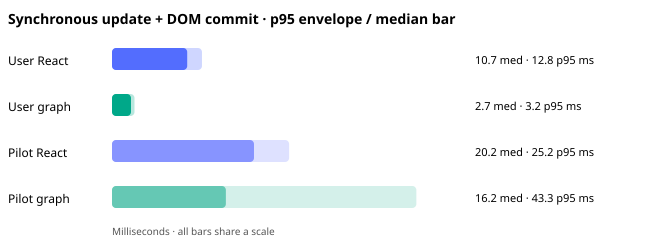

In [11]:
const chartRows = [
  { label: "User React", median: userBrowserObservation.measurements.react.medianMs, p95: userBrowserObservation.measurements.react.p95Ms, color: "#536dfe" },
  { label: "User graph", median: userBrowserObservation.measurements.compiledGraph.medianMs, p95: userBrowserObservation.measurements.compiledGraph.p95Ms, color: "#00a889" },
  { label: "Pilot React", median: browserPilotSummary[0].medianOfRunMediansMs, p95: browserPilotSummary[0].medianOfRunP95sMs, color: "#8794ff" },
  { label: "Pilot graph", median: browserPilotSummary[1].medianOfRunMediansMs, p95: browserPilotSummary[1].medianOfRunP95sMs, color: "#65c8b4" },
];
const chartMax = Math.max(...chartRows.map((row) => row.p95)) * 1.15;
const barMarkup = chartRows.map((row, index) => {
  const y = 48 + index * 46;
  const medianWidth = (row.median / chartMax) * 350;
  const p95Width = (row.p95 / chartMax) * 350;
  return `<text x="8" y="${y + 17}" font-size="12">${row.label}</text><rect x="112" y="${y}" width="${p95Width}" height="22" rx="4" fill="${row.color}" opacity="0.28"/><rect x="112" y="${y}" width="${medianWidth}" height="22" rx="4" fill="${row.color}"/><text x="475" y="${y + 16}" font-size="11">${row.median.toFixed(1)} med · ${row.p95.toFixed(1)} p95 ms</text>`;
}).join("");
Deno.jupyter.svg`<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="244" viewBox="0 0 660 244" role="img" aria-labelledby="timing-chart-title timing-chart-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif"><title id="timing-chart-title">Synchronous update and DOM commit timings</title><desc id="timing-chart-desc">Each row shows a median bar and a translucent 95th percentile envelope. The user report is one run; pilot values summarize three serial runs.</desc><rect width="100%" height="100%" fill="#ffffff"/><text x="8" y="24" font-size="14" font-weight="bold">Synchronous update + DOM commit · p95 envelope / median bar</text>${barMarkup}<text x="112" y="235" font-size="10" fill="#555">Milliseconds · all bars share a scale</text></svg>`;


### Experiment B — interpretation

The user-reported run measured React at **10.7 ms median / 12.8 ms p95** and the graph at **2.7 / 3.2 ms**, but did not preserve raw samples or environment metadata. The initial instrumented pilot had fixed arm order and noisy tails, so it is useful as historical pilot evidence only.

The later paired browser experiment improves input matching and order balance, and its current summary appears in Experiment B2 below. It still compares unequal framework work: React executes subscriptions, component rendering, React DOM diffing, and commits; the graph goes through precompiled bindings and a ref-based style adapter. Thus it is a prototype workload signal, not a causal/general React speed claim.


### Experiment B2 — randomized paired comparison with a React external-store baseline

A browser study pairs both arms within each timing block, uses the same live DOM nodes and the same sequence of scalar values, and balances randomized run order. The React baseline uses one `useSyncExternalStore` subscription per leaf, with React Compiler enabled. The earlier graph path uses precompiled bindings and a ref-based style adapter; the separate TSX prototype uses mount-time binding discovery. Sparse cases repeat updates inside a timing sample and report average time per update. Each density has eight warmup pairs and 41 timed pairs. The order seed, exact order, raw timings, and sampled output parity checks are retained.

This is stronger than the earlier fixed-order per-leaf `useState` pilot, but it remains a prototype comparison with unequal internal work and one 41-pair block per density in one browser/device session. The graph has no JSX compiler; parity checks inspect up to 32 changed targets per pair. Treat these results as a paired prototype comparison, not a framework benchmark.


In [12]:
const pairedBrowserRuns = JSON.parse(await Deno.readTextFile("results/browser-paired-external-store-no-flush-stats-v6-2026-10-09.json"));
const pairedBrowserSummary = pairedBrowserRuns.map((run) => {
  const pairs = run.pairs;
  const differences = pairs.map((pair) => pair.reactMs - pair.graphMs);
  const ratios = pairs.filter((pair) => pair.graphMs > 0).map((pair) => pair.reactMs / pair.graphMs);
  return {
    entities: run.entityCount,
    changed: run.changedCount,
    repeatsPerSample: run.repeatsPerPair,
    nPairs: pairs.length,
    reactMedianMs: medianOf(pairs.map((pair) => pair.reactMs)),
    reactP95Ms: nearestRank(pairs.map((pair) => pair.reactMs), 0.95),
    graphMedianMs: medianOf(pairs.map((pair) => pair.graphMs)),
    graphP95Ms: nearestRank(pairs.map((pair) => pair.graphMs), 0.95),
    medianPairedDifferenceMs: medianOf(differences),
    medianPairedRatio: ratios.length ? medianOf(ratios) : null,
    graphFasterPairs: pairs.filter((pair) => pair.graphMs < pair.reactMs).length,
    reactFasterPairs: pairs.filter((pair) => pair.reactMs < pair.graphMs).length,
    parityFailures: pairs.filter((pair) => !pair.valuesMatch).length,
    reactFirst: pairs.filter((pair) => pair.order[0] === "react").length,
    graphFirst: pairs.filter((pair) => pair.order[0] === "graph").length,
    randomizationSeed: run.randomizationSeed,
  };
});
console.table(pairedBrowserSummary.map((row) => ({
  entities: row.entities, changed: row.changed, repeats: row.repeatsPerSample, pairs: row.nPairs,
  reactMedianMs: row.reactMedianMs.toFixed(3), reactP95Ms: row.reactP95Ms.toFixed(3),
  graphMedianMs: row.graphMedianMs.toFixed(3), graphP95Ms: row.graphP95Ms.toFixed(3),
  pairedRatio: row.medianPairedRatio?.toFixed(2) ?? "n/a",
  graphFaster: row.graphFasterPairs, reactFaster: row.reactFasterPairs, parityFailures: row.parityFailures,
  order: row.reactFirst + "/" + row.graphFirst,
})));
const pairedBrowserArtifact = {
  schemaVersion: 1,
  provenance: "randomized paired browser pilot; one 41-pair block per density",
  source: "results/browser-paired-external-store-no-flush-stats-v6-2026-10-09.json",
  summaries: pairedBrowserSummary,
};
await Deno.writeTextFile("results/browser-paired-summary-2026-10-09.json", JSON.stringify(pairedBrowserArtifact, null, 2) + String.fromCharCode(10));


┌───────┬──────────┬─────────┬─────────┬───────┬───────────────┬────────────┬───────────────┬────────────┬─────────────┬─────────────┬─────────────┬────────────────┬─────────┐
│ (idx) │ entities │ changed │ repeats │ pairs │ reactMedianMs │ reactP95Ms │ graphMedianMs │ graphP95Ms │ pairedRatio │ graphFaster │ reactFaster │ parityFailures │ order   │
├───────┼──────────┼─────────┼─────────┼───────┼───────────────┼────────────┼───────────────┼────────────┼─────────────┼─────────────┼─────────────┼────────────────┼─────────┤
│     0 │    10000 │     100 │      32 │    41 │ "2.934"       │ "3.331"    │ "0.028"       │ "0.031"    │ "106.87"    │          41 │           0 │              0 │ "21/20" │
│     1 │    10000 │    1000 │       8 │    41 │ "6.575"       │ "8.412"    │ "0.262"       │ "0.363"    │ "24.95"     │          41 │           0 │              0 │ "21/20" │
│     2 │    10000 │   10000 │       1 │    41 │ "26.700"      │ "126.100"  │ "3.000"       │ "14.400"   │ "11.87"     │

### Experiment B3 — TSX props bound to a minimal runtime

This separate production page uses TSX syntax for bindings. Vite transforms the JSX, but the dependency list is still discovered at mount; it is not a static graph compiler. React Compiler is enabled for the React 19.3 external-store baseline. The arms create separate equivalent DOM fields. There are eight warmup pairs and 41 randomized timed pairs per density, with sampled parity (up to 64 IDs) and one descriptive setup measurement per arm. Timing excludes paint. Raw records are preserved in `results/browser-paired-jsx-binding-v1-2026-10-09.json`.


In [13]:
const tsxBindingRuns = JSON.parse(await Deno.readTextFile("results/browser-paired-jsx-binding-v1-2026-10-09.json"));
console.table(tsxBindingRuns.map((run) => ({
  changed: `${run.changedFraction * 100}%`, pairs: run.timedPairs,
  reactMedianMs: run.summary.reactMedianMs.toFixed(3), reactP95Ms: run.summary.reactP95Ms.toFixed(3),
  bindingMedianMs: run.summary.jsxBindingMedianMs.toFixed(3), bindingP95Ms: run.summary.jsxBindingP95Ms.toFixed(3),
  medianPairedRatio: run.summary.medianPairedRatio.toFixed(2),
  bindingFaster: run.summary.jsxBindingFasterPairs, parityFailures: run.summary.parityFailures,
  setupReactMs: run.setup.reactMs, setupBindingMs: run.setup.jsxBindingMs,
})));


┌───────┬─────────┬───────┬───────────────┬────────────┬─────────────────┬──────────────┬───────────────────┬───────────────┬────────────────┬──────────────┬────────────────┐
│ (idx) │ changed │ pairs │ reactMedianMs │ reactP95Ms │ bindingMedianMs │ bindingP95Ms │ medianPairedRatio │ bindingFaster │ parityFailures │ setupReactMs │ setupBindingMs │
├───────┼─────────┼───────┼───────────────┼────────────┼─────────────────┼──────────────┼───────────────────┼───────────────┼────────────────┼──────────────┼────────────────┤
│     0 │ "10%"   │    41 │ "3.712"       │ "5.800"    │ "0.400"         │ "0.487"      │ "9.47"            │            41 │              0 │          115 │ 18.5           │
│     1 │ "1%"    │    41 │ "1.563"       │ "1.822"    │ "0.034"         │ "0.038"      │ "47.50"           │            41 │              0 │          115 │ 18.5           │
│     2 │ "100%"  │    41 │ "21.900"      │ "27.900"   │ "2.500"         │ "2.800"      │ "8.73"            │            41 │

## 6. Async results, worker streaming, and CRDT boundaries

A worker or server result should identify its stable template/entity, the versions of the inputs it read, and the output fields it writes. When it arrives, the runtime compares those read versions with current versions. Unrelated world changes need not invalidate a result; changed dependencies do.

A stale result can be canceled, rejected, recomputed, or rebased. A CRDT is appropriate when multiple writers concurrently create domain operations with valid merge semantics. It is not required just to stream a rendered chunk or worker-produced UI patch; snapshots plus versions/dependencies may be enough. This protocol question is related to Xi's async plugin/CRDT work, but it is not the same problem as React Server Components.


In [14]:
const checkFreshness = (result: { readVersions: Record<string, number> }, currentVersions: Record<string, number>) => {
  const staleInputs = Object.entries(result.readVersions)
    .filter(([key, version]) => currentVersions[key] !== version)
    .map(([key]) => key);
  return { accept: staleInputs.length === 0, staleInputs };
};

const asyncFreshnessCases = [
  {
    scenario: "unrelated entity changed after task started",
    result: { readVersions: { "entity:42.position": 7 } },
    current: { "entity:42.position": 7, "entity:99.position": 3 },
    expected: "accept",
  },
  {
    scenario: "a read dependency changed before completion",
    result: { readVersions: { "entity:42.position": 7 } },
    current: { "entity:42.position": 8 },
    expected: "reject or recompute",
  },
  {
    scenario: "two writers produce mergeable set additions",
    result: { readVersions: { "document:tags": 4 } },
    current: { "document:tags": 5 },
    expected: "merge only if domain operations define it",
  },
].map((test) => ({
  scenario: test.scenario,
  freshness: checkFreshness(test.result, test.current),
  policy: test.expected,
}));
console.table(asyncFreshnessCases);


┌───────┬───────────────────────────────────────────────┬──────────────────────────────────────────────────────────┬─────────────────────────────────────────────┐
│ (idx) │ scenario                                      │ freshness                                                │ policy                                      │
├───────┼───────────────────────────────────────────────┼──────────────────────────────────────────────────────────┼─────────────────────────────────────────────┤
│     0 │ "unrelated entity changed after task started" │ { accept: true, staleInputs: [] }                        │ "accept"                                    │
│     1 │ "a read dependency changed before completion" │ { accept: false, staleInputs: [ "entity:42.position" ] } │ "reject or recompute"                       │
│     2 │ "two writers produce mergeable set additions" │ { accept: false, staleInputs: [ "document:tags" ] }      │ "merge only if domain operations define it" │
└───────┴─────────────

## 7. Results, claim ledger, and threats to validity

| Claim | Current evidence | Status |
|---|---|---|
| Sparse and moderate-density updates can avoid unrelated binding work | Three-process Deno study uses matched source updates, equal host writes, parity, and randomized paired timing | Mechanism evidence; not framework evidence |
| The graph prototype lowers median update cost in this DOM workload | Ten randomized multi-source runs plus 14 shared-source runs; custom paths beat React in these scalar binding harnesses | Workload-specific signal; unequal framework work and one browser profile/device |
| The graph improves p95 latency | Graph p95 is lower than React in all 14 shared-source run blocks, but scan has the best mixed 100% median | Narrow signal; one browser profile/device, host commit only, no paint measurement |
| Graph/full-scan crossover depends on entity count and density | Three fresh processes at eight densities show graph wins through 20% at 10k/50k, scan leads at 25%; at 1k, graph retains a small edge at 25% and scan leads at 50% | Mechanism evidence for this topology; do not use a universal threshold |
| Scannable buckets are a useful middle path | At 50k, 64-entity buckets win for clustered updates through 50%; graph wins spread updates through 25%, and full scan wins dense spread updates | Three-process mechanism evidence; global density alone does not predict the winner |
| JSX props can compile to graph bindings | OXC emits one- and two-source repeated-host plans; browser runs check output parity and compare CSR/dense dispatch | Partial compiler evidence; narrow syntax subset, no dynamic topology or general component compilation |
| A single local component update can avoid sibling reconciliation | Three-process OXC-generated Deno ablation: indexed unique-root commit, one render/update, full output parity; 0.030 ms vs 28.032 ms at 10k | Strong mechanism result for one eligible state-local shape; not a React/browser comparison |
| One adapter supports both DOM and Three | Only a DOM adapter exists | Untested |
| Worker/server graph enables parallel work | No worker execution implementation | Untested |
| CRDTs are needed for all streamed UI state | Snapshot/version freshness model handles ordinary view output in this paper's design | Rejected as a blanket assumption; domain merge semantics still need implementation |

### New result: indexed owner-local commit

The latest Deno ablation closes one specific gap: for a single dirty owner with one unique stable host root, the compiled owner graph can target the mounted node directly, update its subtree, and preserve the rest of the VDOM without scanning sibling components. At 10k sibling components, three-process median-of-medians was 0.030 ms against 28.032 ms for forced full recomputation (932×), with one component invocation and one indexed partial commit per update and complete output parity. This answers whether the runtime’s graph can reach a VDOM commit path rather than merely selecting component execution. It does not answer whether the runtime beats optimized React overall: the comparison arm forces all component functions to execute, the host is in-memory, and structural/multi-owner updates use fallback reconciliation. Next evidence should use matched browser workloads against React Compiler and cover structural, batched, and effect-bearing updates.

## Threats to validity

- **Unequal implementation maturity:** React is a production renderer/compiler; the graph prototype is a narrow binding kernel with a handwritten adapter.
- **Workload scope:** moving `transform` values do not cover structural changes, event handling, text/layout, effects, suspense, keyed lists, or Three.js setters.
- **Timing scope:** synchronous JS plus commit is measured; paint, frame pacing, GPU work, input delay, and memory are not.
- **Order and environment:** Deno arm order is paired, balanced, and randomized across three fresh processes; browser runs are balanced and randomized, with four fresh-page rebuilds, but all share one Chrome profile and device.
- **Statistical scope:** 41 pairs per Deno process do not equal 123 independent environments. The shared-source browser study has 14 runs and 336 pairs across two page loads, all on one Chrome profile/device; page-load replication is not independent environment replication. JIT, thermal, and background activity can affect results.
- **Algorithmic scope:** scan-vs-graph intentionally excludes component execution and DOM host costs; its result says only whether the binding index can save traversal work.
- **Construction and churn:** graph setup, dynamic edge changes, disposal, and large keyed-list churn are not comprehensively benchmarked.

## Current conclusion

The evidence justifies implementing a compiler-emitted binding path and testing it against strong declarative React baselines. It does **not** yet justify the claim “faster React.” Across three Deno processes with matched input work, the graph/scan crossover is size-dependent: roughly 20–25% at 10k/50k entities and 25–50% at 1k. The integrated three-way comparison finds scannable buckets fastest for clustered changes through 50%, graph dispatch fastest for spread changes through 25%, and full scans fastest for dense spread changes. Buckets are the measured in-between path when updates cluster; their selector cost remains unknown. The browser evidence is promising for the measured scalar repeated-host workload: an OXC-generated plan routes two source slots to three host properties, while React Compiler plus external-store subscriptions performs component updates and reconciliation. The graph paths bypass that work, so a stronger baseline and broader workloads are needed before claiming a framework advantage. Next gates are independent browser/device replication, larger browser shared-source fan-out timings, structural changes, setup/churn measurement, a Three.js adapter workload, and a measured low-overhead path selector. The shared-source browser study adds 14 four-arm runs (336 timed pairs) across two page loads. It shows a density crossover: local-only dense updates bring scan and graph medians close, while mixed 100% updates favor scan; graph paths remain faster than React in this harness. React executes components and reconciles, whereas custom paths dispatch bindings directly, so the result is not a general framework speed claim. The browser timing remains one device/profile, excludes paint, and has no equal-work React baseline.


## 8. Related work and reproducibility

- [React render and commit](https://react.dev/learn/render-and-commit) — production baseline phases and semantics.
- [React Compiler](https://react.dev/learn/react-compiler) — compiler-optimized React baseline.
- [Xi Rope Science index](https://xi-editor.io/docs/rope_science_00.html) — the published initial run is parts 1–6; the author notes part 7 was never written. Later posts cover CRDTs and minimal invalidation.
- [Xi part 1: MapReduce for text](https://xi-editor.io/docs/rope_science_01.html) — composable summaries.
- [Xi part 6: parallel and asynchronous word wrapping](https://xi-editor.io/docs/rope_science_06.html) — progressive prioritization and async interaction.
- [Xi part 12: minimal invalidation](https://xi-editor.io/docs/rope_science_12.html) — explicit deltas and small invalidation regions.
- [Xi part 8: CRDTs for concurrent editing](https://xi-editor.io/docs/rope_science_08.html) and [part 9: async plugins and undo](https://xi-editor.io/docs/rope_science_09.html) — snapshot-relative operations and merge semantics.
- [related-work.md](./related-work.md) — detailed transfer mapping.

Run `pnpm install --frozen-lockfile`, `uv sync --locked`, `deno task check`, `deno task bench`, and `deno task notebook` from this project directory. The Deno kernel executes with broad permissions in current Deno versions; inspect notebook code before running it. The notebook saves the primary graph-scan run, the scannable-bucket experiment, the three-process summary, and browser summaries under `results/`. `deno task bucket` reruns the bucket experiment once; `deno task bucket:replicate` repeats it in three fresh processes. `deno task dispatch:replicate` runs the integrated three-way study and saves three process replications.


### Experiment D — generated-plan browser evidence

The following cell reads the three raw paired records, checks pair counts and parity, and reports their recorded medians/p95s and order balance. Values come from one Chrome/device session and exclude paint. The records are preserved individually under `results/`.

In [15]:
const files = [
  "results/browser-paired-generated-plan-sparse-v1-2026-10-09.json",
  "results/browser-paired-generated-plan-v1-2026-10-09.json",
  "results/browser-paired-generated-plan-dense-v1-2026-10-09.json",
];
const generatedPlanEvidence = [];
for (const file of files) {
  const record = JSON.parse(await Deno.readTextFile(file));
  const pairs = record.pairs;
  const firstArmCounts = Object.fromEntries(["react", "jsxBinding", "compiledPlan"].map((arm) => [arm, pairs.filter((p) => p.order[0] === arm).length]));
  generatedPlanEvidence.push({ file, changedFraction: record.changedFraction, entities: record.entities, timedPairs: pairs.length, parityFailures: record.parityFailures, firstArmCounts, summaryMs: record.summaryMs, compiledPlanFasterThanReactPairs: record.compiledPlanFasterThanReactPairs, compiledPlanFasterThanMountJsxPairs: record.compiledPlanFasterThanMountJsxPairs, environment: record.environment, setupMeasurement: record.setupMeasurement });
}
if (generatedPlanEvidence.some((r) => r.timedPairs !== 42 || r.parityFailures !== 0)) throw new Error("Generated-plan browser record validation failed");
console.table(generatedPlanEvidence.map((r) => ({ changed: `${r.changedFraction * 100}%`, pairs: r.timedPairs, parityFailures: r.parityFailures, react: `${r.summaryMs.react.median.toFixed(3)} / ${r.summaryMs.react.p95.toFixed(3)}`, mountJsx: `${r.summaryMs.jsxBinding.median.toFixed(3)} / ${r.summaryMs.jsxBinding.p95.toFixed(3)}`, generatedPlan: `${r.summaryMs.compiledPlan.median.toFixed(3)} / ${r.summaryMs.compiledPlan.p95.toFixed(3)}`, planFasterReact: r.compiledPlanFasterThanReactPairs, planFasterJsx: r.compiledPlanFasterThanMountJsxPairs })));
generatedPlanEvidence;


┌───────┬─────────┬───────┬────────────────┬───────────────────┬─────────────────┬─────────────────┬─────────────────┬───────────────┐
│ (idx) │ changed │ pairs │ parityFailures │ react             │ mountJsx        │ generatedPlan   │ planFasterReact │ planFasterJsx │
├───────┼─────────┼───────┼────────────────┼───────────────────┼─────────────────┼─────────────────┼─────────────────┼───────────────┤
│     0 │ "1%"    │    42 │              0 │ "0.819 / 0.891"   │ "0.044 / 0.053" │ "0.037 / 0.044" │              42 │            33 │
│     1 │ "10%"   │    42 │              0 │ "2.575 / 3.250"   │ "0.475 / 0.625" │ "0.387 / 0.487" │              42 │            38 │
│     2 │ "100%"  │    42 │              0 │ "16.200 / 19.000" │ "3.600 / 4.700" │ "3.100 / 3.600" │              42 │            38 │
└───────┴─────────┴───────┴────────────────┴───────────────────┴─────────────────┴─────────────────┴─────────────────┴───────────────┘


[
  {
    file: "results/browser-paired-generated-plan-sparse-v1-2026-10-09.json",
    changedFraction: 0.01,
    entities: 10000,
    timedPairs: 42,
    parityFailures: 0,
    firstArmCounts: { react: 14, jsxBinding: 14, compiledPlan: 14 },
    summaryMs: {
      react: { median: 0.8187499999767169, p95: 0.890625 },
      jsxBinding: { median: 0.04374999995343387, p95: 0.05312500009313226 },
      compiledPlan: { median: 0.037499999976716936, p95: 0.04374999995343387 },
      medianReactToPlanRatio: 22.000000012417633
    },
    compiledPlanFasterThanReactPairs: 42,
    compiledPlanFasterThanMountJsxPairs: 33,
    environment: {
      userAgent: "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/154.0.0.0 Safari/537.36",
      platform: "MacIntel",
      hardwareConcurrency: 10,
      devicePixelRatio: 2,
      visibilityState: "visible",
      build: "Vite production",
      timing: "performance.now; synchronous update plus host commit; pa

### Experiment E — specialized dense-layout browser evidence

This study replaces the generic CSR graph in the generated repeated-host path with a compiler-proven identity source-to-target mapping and typed-array dirty queue. It reads every run from the session export, excludes parity failures from performance summaries, and verifies balanced order plus exact schedule replay for the repeated seed. The raw records include one excluded parity-failing diagnostic.

In [16]:
const specializedSession = JSON.parse(await Deno.readTextFile("results/browser-paired-specialized-plan-session-v2-2026-10-09.json"));
const specializedRuns = specializedSession.records;
const validSpecializedRuns = specializedRuns.filter((r) => r.summary.parityFailures === 0);
const invalidSpecializedRuns = specializedRuns.filter((r) => r.summary.parityFailures !== 0);
const orderKey = (pairs) => pairs.map((pair) => pair.order.join(">"));
const permutationCounts = (pairs) => {
  const counts = new Map();
  for (const pair of pairs) {
    const key = pair.order.join(">");
    counts.set(key, (counts.get(key) ?? 0) + 1);
  }
  return [...counts.values()].sort((a, b) => a - b);
};
for (const run of validSpecializedRuns) {
  if (run.entities !== 10000 || run.timedPairs !== 42 || run.pairs.length !== 42 || run.pairs.some((p) => !p.valuesMatch)) {
    throw new Error(`Malformed specialized run: ${run.timestamp}`);
  }
  const counts = permutationCounts(run.pairs);
  if (counts.length !== 6 || counts.some((count) => count !== 7)) {
    throw new Error(`Arm order is not balanced: ${run.timestamp}`);
  }
}
const replayCandidates = specializedRuns.filter((r) => r.changedFraction === 0.01 && r.randomizationSeed === 3828551373);
const sameSeedOrderReplay = replayCandidates.length >= 2 && replayCandidates.every((r) => JSON.stringify(orderKey(r.pairs)) === JSON.stringify(orderKey(replayCandidates[0].pairs)));
if (!sameSeedOrderReplay) throw new Error("Same-seed order schedule did not replay exactly");
if (invalidSpecializedRuns.length !== 1 || validSpecializedRuns.length !== 5) throw new Error("Unexpected specialized-run validity counts");
console.table(validSpecializedRuns.map((r) => ({
  changed: `${r.changedFraction * 100}%`, seed: r.randomizationSeed,
  react: `${r.summary.reactMedianMs.toFixed(3)} / ${r.summary.reactP95Ms.toFixed(3)}`,
  mountJsx: `${r.summary.jsxBindingMedianMs.toFixed(3)} / ${r.summary.jsxBindingP95Ms.toFixed(3)}`,
  specialized: `${r.summary.compiledPlanMedianMs.toFixed(3)} / ${r.summary.compiledPlanP95Ms.toFixed(3)}`,
  fasterReact: r.summary.compiledPlanFasterThanReactPairs,
  fasterJsx: r.summary.compiledPlanFasterThanMountJsxPairs,
  pairs: r.timedPairs,
})));
({ validRuns: validSpecializedRuns.length, excludedParityFailures: invalidSpecializedRuns.length, sameSeedOrderReplay, sourceExport: specializedSession.sourceExport });

┌───────┬─────────┬────────────┬───────────────────┬─────────────────┬─────────────────┬─────────────┬───────────┬───────┐
│ (idx) │ changed │ seed       │ react             │ mountJsx        │ specialized     │ fasterReact │ fasterJsx │ pairs │
├───────┼─────────┼────────────┼───────────────────┼─────────────────┼─────────────────┼─────────────┼───────────┼───────┤
│     0 │ "10%"   │ 2297324060 │ "4.825 / 21.538"  │ "0.413 / 2.087" │ "0.275 / 1.063" │          42 │        42 │    42 │
│     1 │ "1%"    │ 2695417668 │ "2.022 / 2.184"   │ "0.034 / 0.041" │ "0.025 / 0.028" │          42 │        41 │    42 │
│     2 │ "10%"   │  747370064 │ "4.938 / 5.588"   │ "0.388 / 0.475" │ "0.263 / 0.325" │          42 │        40 │    42 │
│     3 │ "100%"  │   33771132 │ "34.300 / 38.600" │ "2.900 / 3.300" │ "2.300 / 2.600" │          42 │        39 │    42 │
│     4 │ "1%"    │ 3828551373 │ "2.022 / 2.181"   │ "0.034 / 0.044" │ "0.025 / 0.028" │          42 │        41 │    42 │
└───────┴───────

{
  validRuns: 5,
  excludedParityFailures: 1,
  sameSeedOrderReplay: true,
  sourceExport: "jsx-binding-paired-2026-10-09T17-00-52.809Z.json"
}

### Experiment F — same-session CSR and specialized runtime

The four-arm browser study compares React, mount-time JSX discovery, generic CSR, and the identity-layout specialization. This cell validates all records, the full 24-permutation order balance, parity, and exact same-seed schedule replay for the two 10% runs.

In [17]:
const fourWaySession = JSON.parse(await Deno.readTextFile("results/browser-paired-four-way-plan-session-v3-2026-10-09.json"));
const fourWayRuns = fourWaySession.records;
const fourWayArms = ["react", "jsxBinding", "compiledCsr", "compiledPlan"];
const observedOrders = (run) => run.pairs.map((pair) => pair.order.join(">"));
const orderCounts = (run) => {
  const counts = new Map();
  for (const pair of run.pairs) {
    const key = pair.order.join(">");
    counts.set(key, (counts.get(key) ?? 0) + 1);
  }
  return [...counts.values()].sort((a, b) => a - b);
};
for (const run of fourWayRuns) {
  const counts = orderCounts(run);
  if (run.schemaVersion !== 3 || run.entities !== 10000 || run.pairs.length !== 48 || run.timedPairs !== 48) throw new Error(`Malformed four-way run: ${run.timestamp}`);
  if (run.summary.parityFailures !== 0 || run.pairs.some((pair) => !pair.valuesMatch)) throw new Error(`Parity failure: ${run.timestamp}`);
  if (counts.length !== 24 || counts.some((count) => count !== 2)) throw new Error(`Unbalanced arm order: ${run.timestamp}`);
  for (const arm of fourWayArms) if (!Number.isFinite(run.summary.arms[arm].medianMs)) throw new Error(`Missing arm summary ${arm}`);
}
const tenPercentRuns = fourWayRuns.filter((run) => run.changedFraction === 0.1);
if (tenPercentRuns.length !== 2 || JSON.stringify(observedOrders(tenPercentRuns[0])) !== JSON.stringify(observedOrders(tenPercentRuns[1]))) throw new Error("Same-seed schedule replay failed");
console.table(fourWayRuns.map((run) => ({
  changed: `${run.changedFraction * 100}%`, seed: run.randomizationSeed,
  react: `${run.summary.arms.react.medianMs.toFixed(3)} / ${run.summary.arms.react.p95Ms.toFixed(3)}`,
  mountJsx: `${run.summary.arms.jsxBinding.medianMs.toFixed(3)} / ${run.summary.arms.jsxBinding.p95Ms.toFixed(3)}`,
  csr: `${run.summary.arms.compiledCsr.medianMs.toFixed(3)} / ${run.summary.arms.compiledCsr.p95Ms.toFixed(3)}`,
  specialized: `${run.summary.arms.compiledPlan.medianMs.toFixed(3)} / ${run.summary.arms.compiledPlan.p95Ms.toFixed(3)}`,
  specializedFasterThanCsr: run.summary.specializedFasterThanCsrPairs,
  parityFailures: run.summary.parityFailures,
})));
({ runs: fourWayRuns.length, allOrdersTwice: true, parityFailures: fourWayRuns.reduce((sum, run) => sum + run.summary.parityFailures, 0), sameSeedScheduleReplay: true, sourceExport: fourWaySession.sourceExport });

┌───────┬─────────┬──────────┬───────────────────┬─────────────────┬─────────────────┬─────────────────┬──────────────────────────┬────────────────┐
│ (idx) │ changed │ seed     │ react             │ mountJsx        │ csr             │ specialized     │ specializedFasterThanCsr │ parityFailures │
├───────┼─────────┼──────────┼───────────────────┼─────────────────┼─────────────────┼─────────────────┼──────────────────────────┼────────────────┤
│     0 │ "1%"    │ 11423321 │ "1.775 / 1.928"   │ "0.031 / 0.038" │ "0.025 / 0.031" │ "0.025 / 0.028" │                       28 │              0 │
│     1 │ "10%"   │ 11423322 │ "4.450 / 5.050"   │ "0.388 / 0.475" │ "0.288 / 0.438" │ "0.263 / 0.325" │                       33 │              0 │
│     2 │ "100%"  │ 11423323 │ "31.200 / 38.300" │ "2.700 / 3.100" │ "2.400 / 2.800" │ "2.100 / 2.400" │                       40 │              0 │
│     3 │ "10%"   │ 11423322 │ "5.300 / 6.738"   │ "0.450 / 0.750" │ "0.337 / 0.513" │ "0.275 / 0.375" │  

{
  runs: 4,
  allOrdersTwice: true,
  parityFailures: 0,
  sameSeedScheduleReplay: true,
  sourceExport: "jsx-binding-paired-v3-2026-10-09T17-05-44.327Z.json"
}

### Experiment G — two-output source fan-out

Each source now projects to `transform` and `opacity`. This cell validates the OXC-generated four-way browser records, confirms two host writes per changed source, checks all order permutations and parity outcomes, and verifies that the repeated 10% seed reproduces its arm schedule.

In [18]:
const fanoutSession = JSON.parse(await Deno.readTextFile("results/browser-paired-fanout-four-way-session-v4-2026-10-09.json"));
const fanoutRuns = fanoutSession.records;
const fanoutArms = ["react", "jsxBinding", "compiledCsr", "compiledPlan"];
const pairOrders = (run) => run.pairs.map((pair) => pair.order.join(">"));
for (const run of fanoutRuns) {
  const counts = new Map();
  for (const pair of run.pairs) {
    const key = pair.order.join(">");
    counts.set(key, (counts.get(key) ?? 0) + 1);
  }
  if (run.schemaVersion !== 4 || run.bindingsPerSource !== 2 || run.entities !== 10000 || run.pairs.length !== 48) throw new Error(`Malformed fan-out run: ${run.timestamp}`);
  if (run.changedHostPropsPerUpdate !== run.changedCount * 2) throw new Error(`Host write count mismatch: ${run.timestamp}`);
  if (run.summary.parityFailures !== 0 || run.pairs.some((pair) => !pair.valuesMatch)) throw new Error(`Fan-out output parity failure: ${run.timestamp}`);
  if (counts.size !== 24 || [...counts.values()].some((count) => count !== 2)) throw new Error(`Unbalanced four-arm order: ${run.timestamp}`);
  for (const arm of fanoutArms) if (!Number.isFinite(run.summary.arms[arm].medianMs)) throw new Error(`Missing arm: ${arm}`);
}
const tenPct = fanoutRuns.filter((run) => run.changedFraction === 0.1);
if (tenPct.length !== 2 || JSON.stringify(pairOrders(tenPct[0])) !== JSON.stringify(pairOrders(tenPct[1]))) throw new Error("Fan-out same-seed replay mismatch");
console.table(fanoutRuns.map((run) => ({
  changed: `${run.changedFraction * 100}%`, seed: run.randomizationSeed, hostWrites: run.changedHostPropsPerUpdate,
  react: `${run.summary.arms.react.medianMs.toFixed(3)} / ${run.summary.arms.react.p95Ms.toFixed(3)}`,
  mountJsx: `${run.summary.arms.jsxBinding.medianMs.toFixed(3)} / ${run.summary.arms.jsxBinding.p95Ms.toFixed(3)}`,
  csr: `${run.summary.arms.compiledCsr.medianMs.toFixed(3)} / ${run.summary.arms.compiledCsr.p95Ms.toFixed(3)}`,
  specialized: `${run.summary.arms.compiledPlan.medianMs.toFixed(3)} / ${run.summary.arms.compiledPlan.p95Ms.toFixed(3)}`,
  specializedFasterThanCsr: run.summary.specializedFasterThanCsrPairs,
})));
({ runs: fanoutRuns.length, outputsPerSource: 2, allOrdersTwice: true, parityFailures: fanoutRuns.reduce((sum, run) => sum + run.summary.parityFailures, 0), sameSeedScheduleReplay: true, sourceExport: fanoutSession.sourceExport });

┌───────┬─────────┬──────────┬────────────┬───────────────────┬─────────────────┬─────────────────┬─────────────────┬──────────────────────────┐
│ (idx) │ changed │ seed     │ hostWrites │ react             │ mountJsx        │ csr             │ specialized     │ specializedFasterThanCsr │
├───────┼─────────┼──────────┼────────────┼───────────────────┼─────────────────┼─────────────────┼─────────────────┼──────────────────────────┤
│     0 │ "1%"    │ 21000001 │        200 │ "2.016 / 2.184"   │ "0.056 / 0.063" │ "0.050 / 0.056" │ "0.044 / 0.050" │                       33 │
│     1 │ "10%"   │ 21000002 │       2000 │ "5.387 / 5.763"   │ "0.663 / 0.787" │ "0.563 / 0.625" │ "0.500 / 0.563" │                       39 │
│     2 │ "100%"  │ 21000003 │      20000 │ "37.400 / 42.700" │ "5.600 / 7.100" │ "4.900 / 5.300" │ "4.400 / 4.700" │                       43 │
│     3 │ "10%"   │ 21000002 │       2000 │ "5.625 / 6.587"   │ "0.688 / 0.925" │ "0.538 / 0.625" │ "0.488 / 0.563" │             

{
  runs: 4,
  outputsPerSource: 2,
  allOrdersTwice: true,
  parityFailures: 0,
  sameSeedScheduleReplay: true,
  sourceExport: "jsx-binding-paired-v4-2026-10-09T17-10-05.060Z.json"
}

### Experiment H — compiler-emitted CSR dependency template

The Rust/OXC compiler emits a one-source CSR template with binding IDs for the repeated item. This post-change browser replay uses the same seed as the prior uninstrumented run, includes the compiler schema and adjacency in the raw record, and checks order balance, output parity, and exact schedule replay. The generic runtime instantiates the emitted graph; the specialized path uses the same binding order with an identity-layout dirty queue. This is still a one-source scalar graph and an unequal-work React comparison.


In [19]:
const explicitGraphRun = JSON.parse(await Deno.readTextFile("results/browser-paired-explicit-csr-template-10pct-v5-run1-2026-10-09.json"));
const priorGraphReplay = JSON.parse(await Deno.readTextFile("results/browser-paired-explicit-csr-template-10pct-v4-uninstrumented-run1-2026-10-09.json"));
const explicitGraphSession = JSON.parse(await Deno.readTextFile("results/browser-paired-explicit-csr-template-session-v5-2026-10-09.json"));
const orderCounts = new Map();
for (const pair of explicitGraphRun.pairs) {
  const key = pair.order.join(">");
  orderCounts.set(key, (orderCounts.get(key) ?? 0) + 1);
}
const sameSchedule = JSON.stringify(explicitGraphRun.pairs.map((pair) => pair.order)) === JSON.stringify(priorGraphReplay.pairs.map((pair) => pair.order));
if (explicitGraphRun.schemaVersion !== 5 || explicitGraphRun.compilerPlan.schemaVersion !== 3) throw new Error("Unexpected browser or compiler graph schema");
if (explicitGraphRun.compilerPlan.sourceCount !== 1 || JSON.stringify(explicitGraphRun.compilerPlan.sourceBindingOffsets) !== JSON.stringify([0, 2]) || JSON.stringify(explicitGraphRun.compilerPlan.bindingIds) !== JSON.stringify([0, 1])) throw new Error("Compiler CSR template metadata mismatch");
if (explicitGraphRun.pairs.length !== 48 || orderCounts.size !== 24 || [...orderCounts.values()].some((count) => count !== 2)) throw new Error("Browser graph run is missing balanced order coverage");
if (explicitGraphRun.summary.parityFailures !== 0 || explicitGraphRun.pairs.some((pair) => !pair.valuesMatch)) throw new Error("Explicit graph browser parity failed");
if (!sameSchedule || explicitGraphSession.length !== 6) throw new Error("Same-seed schedule replay or session export check failed");
console.table(Object.entries(explicitGraphRun.summary.arms).map(([arm, values]) => ({ arm, medianMs: values.medianMs.toFixed(3), p95Ms: values.p95Ms.toFixed(3) })));
({ timestamp: explicitGraphRun.timestamp, seed: explicitGraphRun.randomizationSeed, entities: explicitGraphRun.entities, changedFraction: explicitGraphRun.changedFraction, graphOffsets: explicitGraphRun.compilerPlan.sourceBindingOffsets, bindingIds: explicitGraphRun.compilerPlan.bindingIds, orders: orderCounts.size, repeatsPerOrder: [...new Set(orderCounts.values())], sameSeedScheduleReplay: sameSchedule, specializedFasterThanCsr: explicitGraphRun.summary.specializedFasterThanCsrPairs, parityFailures: explicitGraphRun.summary.parityFailures, sessionRecords: explicitGraphSession.length });


┌───────┬────────────────┬──────────┬─────────┐
│ (idx) │ arm            │ medianMs │ p95Ms   │
├───────┼────────────────┼──────────┼─────────┤
│     0 │ "react"        │ "5.375"  │ "5.913" │
│     1 │ "jsxBinding"   │ "0.712"  │ "0.838" │
│     2 │ "compiledCsr"  │ "0.638"  │ "0.737" │
│     3 │ "compiledPlan" │ "0.550"  │ "0.625" │
└───────┴────────────────┴──────────┴─────────┘


{
  timestamp: "2026-10-09T17:24:33.137Z",
  seed: 21000002,
  entities: 10000,
  changedFraction: 0.1,
  graphOffsets: [ 0, 2 ],
  bindingIds: [ 0, 1 ],
  orders: 24,
  repeatsPerOrder: [ 2 ],
  sameSeedScheduleReplay: true,
  specializedFasterThanCsr: 42,
  parityFailures: 0,
  sessionRecords: 6
}

### Experiment I — multi-source graph extraction

The OXC fixture separates each entity into `x` and `y` source slots. It asks the compiler to route `x` to two host properties (`left`, `transform`) and `y` to `opacity`. This validates compile-time graph structure and generated source-slot metadata. It does not yet measure multi-source browser runtime cost or compare it with React.

In [20]:
const multiTraitIr = JSON.parse(await Deno.readTextFile("results/compiler-multi-trait-ir.json"));
const multiTraitPlan = multiTraitIr.repeated_host_plan;
const multiTraitGraph = multiTraitPlan.dependency_graph;
const multiTraitBindings = multiTraitPlan.bindings.map((binding: { property: string; source_path: string; source_slot: number }) => ({
  property: binding.property, source: binding.source_path, slot: binding.source_slot,
}));
if (multiTraitGraph.source_count !== 2 || JSON.stringify(multiTraitGraph.source_paths) !== JSON.stringify(["node.x", "node.y"]) ||
  JSON.stringify(multiTraitGraph.source_binding_offsets) !== JSON.stringify([0, 2, 3]) ||
  JSON.stringify(multiTraitGraph.binding_ids) !== JSON.stringify([0, 2, 1])) {
  throw new Error("Unexpected OXC multi-source dependency graph");
}
console.log({ compilerSchema: multiTraitIr.schema_version, graph: multiTraitGraph, bindings: multiTraitBindings, evidence: "compile-time structure only; no browser performance measurement" });

{
  compilerSchema: 5,
  graph: {
    source_count: 2,
    source_paths: [ "node.x", "node.y" ],
    source_binding_offsets: [ 0, 2, 3 ],
    binding_ids: [ 0, 2, 1 ],
    shared_source_count: 0,
    shared_source_paths: [],
    shared_source_binding_offsets: [ 0 ],
    shared_binding_ids: []
  },
  bindings: [
    { property: "left", source: "node.x", slot: 0 },
    { property: "opacity", source: "node.y", slot: 1 },
    { property: "transform", source: "node.x", slot: 0 }
  ],
  evidence: "compile-time structure only; no browser performance measurement"
}


### Experiment J — multi-source browser runtime parity

The emitted two-slot plan is loaded in Chrome. Dense identity dispatch and generic CSR dispatch receive the same entity rows and source-slot writes. We assert initial styles, coalescing of repeated writes before flush, independent `x`/`y` routing, and identical final DOM style values. This is functional parity evidence only; it does not report a performance comparison.

In [21]:
const multiBrowserRun = JSON.parse(await Deno.readTextFile("results/browser-multi-source-runtime-parity-v1.json"));
const same = (a: unknown, b: unknown) => JSON.stringify(a) === JSON.stringify(b);
if (multiBrowserRun.parityFailures !== 0 || multiBrowserRun.plan.sourceCount !== 2 ||
  !same(multiBrowserRun.plan.sourcePaths, ["node.x", "node.y"]) ||
  !same(multiBrowserRun.plan.sourceBindingOffsets, [0, 2, 3]) || !same(multiBrowserRun.plan.bindingIds, [0, 2, 1]) ||
  !same(multiBrowserRun.observedDenseAfter, multiBrowserRun.expectedAfter) ||
  !same(multiBrowserRun.observedCsrAfter, multiBrowserRun.expectedAfter)) {
  throw new Error("Multi-source browser output parity check failed");
}
console.log({ browser: multiBrowserRun.environment.browser, graph: multiBrowserRun.plan, parityFailures: multiBrowserRun.parityFailures, measurement: multiBrowserRun.measurement });

{
  browser: "Chrome",
  graph: {
    sourceCount: 2,
    sourcePaths: [ "node.x", "node.y" ],
    sourceBindingOffsets: [ 0, 2, 3 ],
    bindingIds: [ 0, 2, 1 ]
  },
  parityFailures: 0,
  measurement: "functional parity only; no timing collected"
}


### Experiment K — paired multi-source timings across update density

This analysis validates the saved Chrome records for 10,000 entities at 1%, 10%, and 100% change rates. Each density has two seeds, 24 warm-up pairs, 48 timed pairs, and eight occurrences of each of the six arm orders. Each update changes both source slots for every selected entity and the same three style properties. The records preserve setup times, environment, all pair timings, and parity results. This remains one-browser, one-device evidence.

In [22]:
const multiTimingRuns = JSON.parse(await Deno.readTextFile("results/browser-multi-source-timing-session-v1.json"));
const arms = ["react", "csr", "dense"];
const allOrders = [
  ["react","csr","dense"], ["react","dense","csr"],
  ["csr","react","dense"], ["csr","dense","react"],
  ["dense","react","csr"], ["dense","csr","react"],
];
const percentileMs = (values: number[], p: number) => {
  const sorted = [...values].sort((a, b) => a - b);
  return sorted[Math.max(0, Math.ceil(p * sorted.length) - 1)];
};
if (multiTimingRuns.length !== 6) throw new Error("Expected two browser timing runs at each of three densities");
for (const run of multiTimingRuns) {
  if (run.entities !== 10000 || run.warmupPairs !== 24 || run.timedPairs !== 48 ||
    run.pairs.length !== 48 || run.parityFailures !== 0 || run.graphPlan.sourceCount !== 2 ||
    JSON.stringify(run.graphPlan.sourceBindingOffsets) !== JSON.stringify([0, 2, 3]) ||
    run.changedEntitiesPerBatch * 2 !== run.sourceSlotsChangedPerBatch ||
    run.changedEntitiesPerBatch * 3 !== run.hostPropsChangedPerBatch ||
    !run.reactBaseline.includes("React Compiler")) {
    throw new Error(`Invalid or incomplete multi-source timing record for seed ${run.seed}`);
  }
  const counts = new Map<string, number>();
  for (const pair of run.pairs) {
    const key = JSON.stringify(pair.order);
    counts.set(key, (counts.get(key) ?? 0) + 1);
    if (!pair.valuesMatch) throw new Error(`Parity failure in seed ${run.seed}, pair ${pair.pair}`);
  }
  if (counts.size !== 6 || [...counts.values()].some((count) => count !== 8) ||
    allOrders.some((order) => !counts.has(JSON.stringify(order)))) {
    throw new Error(`Seed ${run.seed} does not have eight samples in each of the six arm orders`);
  }
  for (const arm of arms) {
    const raw = run.pairs.map((pair: { timingsMs: Record<string, number> }) => pair.timingsMs[arm]);
    if (Math.abs(percentileMs(raw, 0.5) - run.summaries[arm].medianMs) > 1e-9 ||
      Math.abs(percentileMs(raw, 0.95) - run.summaries[arm].p95Ms) > 1e-9) {
      throw new Error(`Saved summary does not match raw pair timings for seed ${run.seed}/${arm}`);
    }
  }
}
const densityRows = multiTimingRuns.map((run: any) => ({
  changedPercent: `${run.changedFraction * 100}%`, seed: run.seed,
  reactMedianP95: [run.summaries.react.medianMs, run.summaries.react.p95Ms],
  csrMedianP95: [run.summaries.csr.medianMs, run.summaries.csr.p95Ms],
  denseMedianP95: [run.summaries.dense.medianMs, run.summaries.dense.p95Ms],
  denseWinsAgainstCsr: run.pairedWins.denseVsCsr, parityFailures: run.parityFailures,
}));
console.log({ validatedRuns: multiTimingRuns.length, densityRows, allPairs: multiTimingRuns.reduce((sum: number, run: any) => sum + run.pairs.length, 0), note: "single Chrome/MacIntel environment; paint excluded" });

{
  validatedRuns: 6,
  densityRows: [
    {
      changedPercent: "10%",
      seed: 31000003,
      reactMedianP95: [ 12.012499999254942, 14.525000000372529 ],
      csrMedianP95: [ 0.8125, 1.162499999627471 ],
      denseMedianP95: [ 0.7374999998137355, 1.2749999994412065 ],
      denseWinsAgainstCsr: 39,
      parityFailures: 0
    },
    {
      changedPercent: "10%",
      seed: 31000004,
      reactMedianP95: [ 12.737499999813735, 15.049999999813735 ],
      csrMedianP95: [ 0.837500000372529, 1.2374999998137355 ],
      denseMedianP95: [ 0.7374999998137355, 1.300000000745058 ],
      denseWinsAgainstCsr: 39,
      parityFailures: 0
    },
    {
      changedPercent: "1%",
      seed: 31000005,
      reactMedianP95: [ 7.506249999860302, 7.796875 ],
      csrMedianP95: [ 0.07187499990686774, 0.09062499995343387 ],
      denseMedianP95: [ 0.06562500004656613, 0.08437500009313226 ],
      denseWinsAgainstCsr: 41,
      parityFailures: 0
    },
    {
      changedPercent: "100%",
   

### Experiment L — fresh-page replication of multi-source browser timings

Four runs were collected after separate page reloads, rebuilding all three host trees each time. The page-load IDs distinguish these replications from runs on the original page. They still share one Chrome profile, device, and benchmark workload, so they are not independent browser or device replications.

In [23]:
const freshPageRuns = JSON.parse(await Deno.readTextFile("results/browser-multi-source-fresh-page-session-v1.json"));
const expectedSeeds = [32000001, 32000002, 32000003, 32000004];
if (freshPageRuns.length !== 4 || JSON.stringify(freshPageRuns.map((run: any) => run.seed)) !== JSON.stringify(expectedSeeds)) throw new Error("Expected the four fresh-page replication seeds");
if (new Set(freshPageRuns.map((run: any) => run.pageLoadId)).size !== 4) throw new Error("Each replication must come from a distinct page load");
const orderKeys = [["react","csr","dense"],["react","dense","csr"],["csr","react","dense"],["csr","dense","react"],["dense","react","csr"],["dense","csr","react"]].map((order) => JSON.stringify(order));
const checkQuantile = (values: number[], p: number) => { const sorted = [...values].sort((a, b) => a - b); return sorted[Math.max(0, Math.ceil(p * sorted.length) - 1)]; };
for (const run of freshPageRuns) {
  if (run.entities !== 10000 || run.warmupPairs !== 24 || run.timedPairs !== 48 || run.pairs.length !== 48 || run.parityFailures !== 0 || run.environment.visibilityState !== "visible" || run.graphPlan.sourceCount !== 2) throw new Error(`Invalid fresh-page run ${run.seed}`);
  const counts = new Map<string, number>();
  for (const pair of run.pairs) { const key = JSON.stringify(pair.order); counts.set(key, (counts.get(key) ?? 0) + 1); if (!pair.valuesMatch) throw new Error(`Parity failure ${run.seed}/${pair.pair}`); }
  if (counts.size !== 6 || orderKeys.some((key) => counts.get(key) !== 8)) throw new Error(`Unbalanced arm order in ${run.seed}`);
  for (const arm of ["react", "csr", "dense"]) { const raw = run.pairs.map((pair: any) => pair.timingsMs[arm]); if (Math.abs(checkQuantile(raw, .5) - run.summaries[arm].medianMs) > 1e-9 || Math.abs(checkQuantile(raw, .95) - run.summaries[arm].p95Ms) > 1e-9) throw new Error(`Quantile mismatch ${run.seed}/${arm}`); }
}
console.log(freshPageRuns.map((run: any) => ({ seed: run.seed, pageLoadId: run.pageLoadId, density: `${run.changedFraction * 100}%`, react: run.summaries.react, csr: run.summaries.csr, dense: run.summaries.dense, denseWinsVsCsr: run.pairedWins.denseVsCsr, parityFailures: run.parityFailures })));


[
  {
    seed: 32000001,
    pageLoadId: "7a9d3cc3-db7a-402e-8fbe-100b98a9334b",
    density: "1%",
    react: { medianMs: 6.318750000093132, p95Ms: 8.471875000046566 },
    csr: { medianMs: 0.07187499990686774, p95Ms: 0.078125 },
    dense: { medianMs: 0.0625, p95Ms: 0.06875000009313226 },
    denseWinsVsCsr: 43,
    parityFailures: 0
  },
  {
    seed: 32000002,
    pageLoadId: "e49e5d96-a76a-4ce5-890d-69db47bf6a44",
    density: "1%",
    react: { medianMs: 6.381249999860302, p95Ms: 7.440625000046566 },
    csr: { medianMs: 0.07499999995343387, p95Ms: 0.08749999990686774 },
    dense: { medianMs: 0.0625, p95Ms: 0.07499999995343387 },
    denseWinsVsCsr: 43,
    parityFailures: 0
  },
  {
    seed: 32000003,
    pageLoadId: "3ad49088-6db9-4430-9e57-77f15e1dd180",
    density: "10%",
    react: { medianMs: 12.612499999813735, p95Ms: 13.087500000372529 },
    csr: { medianMs: 0.787499999627471, p95Ms: 0.8999999994412065 },
    dense: { medianMs: 0.712500000372529, p95Ms: 0.8125 },
   

### Experiment M — shared-source fan-out and dirty-binding de-duplication

This hand-built Deno mechanism experiment models local `x[i]` feeding two bindings, shared `scale` feeding every transform, and shared `alpha` feeding every opacity. It compares dirty-binding graph dispatch with a full entity scan at 1%, 10%, and 100% local changes. Unlike the browser/OXC results, this does not use compiler output, the DOM, or React.

In [24]:
const sharedSummary = JSON.parse(await Deno.readTextFile("results/deno-shared-dependency-replication-summary.json"));
if (sharedSummary.processCount !== 3 || sharedSummary.scenarios.length !== 9) throw new Error("Expected three fresh processes across nine shared-dependency scenarios");
const sharedRuns = await Promise.all(sharedSummary.rawSources.map((path: string) => Deno.readTextFile(path).then((text) => JSON.parse(text))));
const nearestRank = (values: number[], p: number) => { const sorted = [...values].sort((a, b) => a - b); return sorted[Math.max(0, Math.ceil(p * sorted.length) - 1)]; };
const median = (values: number[]) => [...values].sort((a, b) => a - b)[Math.floor(values.length / 2)];
for (let processIndex = 0; processIndex < sharedRuns.length; processIndex++) {
  const run = sharedRuns[processIndex]; if (run.scenarios.length !== 9 || run.environment.deno !== sharedSummary.environments[processIndex].deno) throw new Error(`Invalid shared-dependency process ${processIndex + 1}`);
  for (const scenario of run.scenarios) {
    if (scenario.entityCount !== 10000 || scenario.pairCount !== 48 || scenario.pairs.length !== 48 || scenario.parityFailures !== 0 || scenario.pairs.some((pair: any) => pair.parityFailures !== 0) || Object.values(scenario.orderCounts).some((count: any) => count !== 24)) throw new Error(`Invalid parity/order/sample count in ${scenario.sharedMode}/${scenario.changedFraction}`);
    for (const arm of ["graph", "fullScan"]) { const key = arm === "graph" ? "graphMs" : "fullScanMs"; const raw = scenario.pairs.map((pair: any) => pair[key]); if (Math.abs(nearestRank(raw, .5) - scenario.medianMs[arm]) > 1e-9 || Math.abs(nearestRank(raw, .95) - scenario.p95Ms[arm]) > 1e-9) throw new Error(`Quantile mismatch ${scenario.sharedMode}/${scenario.changedFraction}/${arm}`); }
  }
}
const sharedRows = sharedSummary.scenarios.map((summary: any) => { const same = sharedRuns.map((run: any) => run.scenarios.find((row: any) => row.sharedMode === summary.sharedMode && row.changedFraction === summary.changedFraction)); const graphMedians = same.map((row: any) => row.medianMs.graph); const scanMedians = same.map((row: any) => row.medianMs.fullScan); const graphP95 = median(same.map((row: any) => row.p95Ms.graph)); const scanP95 = median(same.map((row: any) => row.p95Ms.fullScan)); if (Math.abs(median(graphMedians) * 1000 - summary.medianUsAcrossProcesses.graph) > 1e-8 || Math.abs(median(scanMedians) * 1000 - summary.medianUsAcrossProcesses.fullScan) > 1e-8 || Math.abs(graphP95 * 1000 - summary.p95UsAcrossProcesses.graph) > 1e-8 || Math.abs(scanP95 * 1000 - summary.p95UsAcrossProcesses.fullScan) > 1e-8) throw new Error(`Aggregate mismatch ${summary.sharedMode}/${summary.changedFraction}`); return { density: `${summary.changedFraction * 100}%`, shared: summary.sharedMode, bindings: summary.affectedBindingsPerBatch, graphMedianUs: summary.medianUsAcrossProcesses.graph, scanMedianUs: summary.medianUsAcrossProcesses.fullScan, graphWinsByProcess: summary.graphWinsByProcess, parity: summary.parityAllProcesses }; });
console.table(sharedRows);


┌───────┬─────────┬───────────────────┬──────────┬────────────────────┬────────────────────┬────────────────────┬────────┐
│ (idx) │ density │ shared            │ bindings │ graphMedianUs      │ scanMedianUs       │ graphWinsByProcess │ parity │
├───────┼─────────┼───────────────────┼──────────┼────────────────────┼────────────────────┼────────────────────┼────────┤
│     0 │ "1%"    │ "none"            │      200 │ 1.1093750000004121 │ 6.697906249999441  │ [ 48, 48, 48 ]     │ true   │
│     1 │ "10%"   │ "none"            │     2000 │ 17.260499999999013 │ 25.65099999999987  │ [ 46, 48, 48 ]     │ true   │
│     2 │ "100%"  │ "none"            │    20000 │ 136.66599999999107 │ 87.54100000004428  │ [ 0, 1, 0 ]        │ true   │
│     3 │ "1%"    │ "scale"           │    10100 │ 58.52050000001441  │ 24.77100000001542  │ [ 0, 0, 0 ]        │ true   │
│     4 │ "10%"   │ "scale"           │    11000 │ 72.9584999999986   │ 28.020499999996673 │ [ 0, 0, 0 ]        │ true   │
│     5 │ "100%"

### Experiment N — compiler-to-runtime shared-source parity

OXC schema v5 separates per-item dependency tables from shared component inputs. The generated fixture binds `node.x` to a per-entity transform and `props.alpha` to opacity across every repeated host. A Deno fake-DOM integration check validates initial host values, shared-source fan-out, coalescing repeated shared writes, and a local update in the same flush across both dense and CSR dispatchers. This is a correctness check on a two-entity fixture, not a performance result; Experiment M remains the mechanism timing evidence for graph versus scan under shared fan-out.

In [25]:
const sharedSourceIr = JSON.parse(await Deno.readTextFile("results/compiler-shared-source-ir.json"));
const sharedSourcePlan = sharedSourceIr.repeated_host_plan;
if (sharedSourceIr.schema_version !== 5 || sharedSourcePlan?.dependency_graph?.source_count !== 1 ||
  JSON.stringify(sharedSourcePlan.dependency_graph.source_paths) !== JSON.stringify(["node.x"]) ||
  JSON.stringify(sharedSourcePlan.dependency_graph.source_binding_offsets) !== JSON.stringify([0, 2]) ||
  JSON.stringify(sharedSourcePlan.dependency_graph.binding_ids) !== JSON.stringify([0, 2]) ||
  sharedSourcePlan.dependency_graph.shared_source_count !== 1 ||
  JSON.stringify(sharedSourcePlan.dependency_graph.shared_source_paths) !== JSON.stringify(["props.alpha"]) ||
  JSON.stringify(sharedSourcePlan.dependency_graph.shared_binding_ids) !== JSON.stringify([1])) {
  throw new Error("OXC shared-source IR differs from the expected local/shared CSR tables");
}
const sharedParity = JSON.parse(await Deno.readTextFile("results/shared-source-runtime-check-v1.json"));
if (sharedParity.status !== "pass" || sharedParity.parity !== true || sharedParity.coalescing !== true ||
  sharedParity.localAndSharedBatch !== true || sharedParity.harness !== "fake-dom" || sharedParity.dispatchers.join(",") !== "dense,csr" ||
  JSON.stringify(sharedParity.afterSharedFanOut) !== JSON.stringify([
    { left: "15px", opacity: "0.6", transform: "translateX(15px)" },
    { left: "20px", opacity: "0.6", transform: "translateX(20px)" },
  ])) {
  throw new Error("Deno shared-source runtime record is missing expected fan-out or coalescing results");
}
({ compilerSchema: sharedSourceIr.schema_version, localPaths: sharedSourcePlan.dependency_graph.source_paths,
  sharedPaths: sharedSourcePlan.dependency_graph.shared_source_paths, entityCount: sharedParity.entities,
  dispatchers: sharedParity.dispatchers, result: sharedParity.afterSharedFanOut, performanceClaim: false });

{
  compilerSchema: 5,
  localPaths: [ "node.x" ],
  sharedPaths: [ "props.alpha" ],
  entityCount: 2,
  dispatchers: [ "dense", "csr" ],
  result: [
    { left: "15px", opacity: "0.6", transform: "translateX(15px)" },
    { left: "20px", opacity: "0.6", transform: "translateX(20px)" }
  ],
  performanceClaim: false
}

### Experiment O — browser shared-source fan-out (measured)

The benchmark compares four update paths over 10,000 repeated hosts: React 19.3 with React Compiler and local/shared useSyncExternalStore subscriptions; OXC-generated CSR dispatch; OXC-generated dense dispatch; and a full host scan. The OXC plan maps local node.x to left and transform, and shared props.alpha to opacity. It covers local-only updates at 1%, 10%, and 100%; mixed local-plus-shared updates at the same local fractions; and shared-only fan-out to all hosts.

The saved record has 14 runs: each scenario was run once on each of two fresh page loads, with distinct seeds. Every run has 24 warmup pairs and 24 timed pairs; all 24 four-arm orders occur once in randomized order. Setup is recorded separately once per page load. The timing boundary is the update input loop plus synchronous update and host commit; paint and frame presentation are excluded. All 336 timed pairs have zero recorded parity failures. See results/browser-shared-source-timing-session-v2-2026-10-09.json.

For each run, the table reports median / nearest-rank p95 in milliseconds per batch. The two values in each cell are separate page-load replications, not pooled samples. Setup figures are descriptive single measurements per load.

| Scenario | React + Compiler | OXC CSR | OXC dense | Full scan |
|---|---:|---:|---:|---:|
| Local 1% | 7.981/8.800 · 7.038/8.881 | 0.062/0.075 · 0.062/0.069 | 0.056/0.075 · 0.056/0.069 | 3.575/4.794 · 3.481/3.762 |
| Local 10% | 14.617/18.617 · 12.550/14.233 | 0.733/1.400 · 0.667/0.750 | 0.575/0.783 · 0.517/0.567 | 3.842/5.233 · 3.650/3.833 |
| Local 100% | 75.950/83.900 · 70.800/86.500 | 5.700/7.100 · 5.300/5.900 | 5.000/7.500 · 4.800/5.400 | 5.350/15.300 · 5.100/6.100 |
| Mixed 1% | 68.250/71.900 · 71.250/82.600 | 3.300/3.900 · 3.000/3.400 | 2.800/3.400 · 2.850/5.500 | 4.700/5.700 · 4.700/6.500 |
| Mixed 10% | 64.300/78.500 · 62.200/81.300 | 4.200/4.600 · 4.050/4.600 | 3.400/3.900 · 3.450/3.900 | 4.700/5.200 · 4.700/5.600 |
| Mixed 100% | 77.650/86.300 · 75.900/95.500 | 7.700/13.500 · 7.800/12.600 | 7.050/8.800 · 7.250/10.700 | 5.500/5.900 · 5.450/10.600 |
| Shared only | 34.200/43.700 · 43.650/56.500 | 2.550/2.900 · 3.050/4.200 | 2.500/2.700 · 2.800/7.800 | 4.350/4.600 · 4.850/6.100 |

The strongest practical result is the crossover. For local-only updates, graph dispatch wins at sparse and moderate densities; at 100%, scan and graph medians are close, and the scan has lower median than both graph paths in the second page-load run. For mixed 100% updates, the full scan has the lowest median in both runs (5.50 and 5.45 ms versus dense 7.05 and 7.25 ms). For shared-only fan-out, dense dispatch has a lower median than the scan in both runs, although the second dense p95 is noisy (7.8 ms). Do not choose a global threshold from two page loads.

All custom paths beat React in all 336 paired observations here. That comparison is deliberately interpreted narrowly: React executes components, checks subscriptions, and reconciles; CSR, dense, and scan paths apply the same output values through a hand-authored/compiled host-binding harness. The work is not equivalent. Setup is excluded from timed batches, no paint is measured, and the single Chrome 155 / MacIntel profile is not an independent environment replication. The result identifies a browser-level dispatch crossover and motivates a work-equivalent declarative baseline; it does not show that a general React replacement is faster.


Validated 14 runs / 336 timed pairs across 2 fresh page loads; parity failures: 0.


Rows are median / nearest-rank p95 milliseconds per batch.
Scenario · seed | React | CSR | dense | scan
Shared only · 42610007 | 34.200/43.700 | 2.550/2.900 | 2.500/2.700 | 4.350/4.600
Local 1% · 42620001 | 7.981/8.800 | 0.063/0.075 | 0.056/0.075 | 3.575/4.794
Local 10% · 42620002 | 14.617/18.617 | 0.733/1.400 | 0.575/0.783 | 3.842/5.233
Local 100% · 42620003 | 75.950/83.900 | 5.700/7.100 | 5.000/7.500 | 5.350/15.300
Mixed 1% · 42620004 | 68.250/71.900 | 3.300/3.900 | 2.800/3.400 | 4.700/5.700
Mixed 10% · 42620005 | 64.300/78.500 | 4.200/4.600 | 3.400/3.900 | 4.700/5.200
Mixed 100% · 42620006 | 77.650/86.300 | 7.700/13.500 | 7.050/8.800 | 5.500/5.900
Local 1% · 42630001 | 7.038/8.881 | 0.063/0.069 | 0.056/0.069 | 3.481/3.762
Local 10% · 42630002 | 12.550/14.233 | 0.667/0.750 | 0.517/0.567 | 3.650/3.833
Local 100% · 42630003 | 70.800/86.500 | 5.300/5.900 | 4.800/5.400 | 5.100/6.100
Mixed 1% · 42630004 | 71.250/82.600 | 3.000/3.400 | 2.850/5.500 | 4.700/6.500
Mixed 10% · 42630005 | 62.20

One descriptive setup measurement per page load (milliseconds):
[
  {
    "pageLoadId": "d2255e03-008f-412f-9b0f-7f343e68fcc5",
    "setupMs": {
      "react": 102.89999999850988,
      "csr": 19.700000002980232,
      "dense": 12.5,
      "scan": 9.699999995529652
    }
  },
  {
    "pageLoadId": "163ec0d1-7935-4e7c-a99e-90e878413690",
    "setupMs": {
      "react": 111.60000000149012,
      "csr": 21.5,
      "dense": 11.700000002980232,
      "scan": 6.799999997019768
    }
  }
]


{"runs":14,"timedPairs":336,"pageLoads":2,"conditions":7,"parityFailures":0,"summaryFile":"results/browser-shared-source-summary-v1-2026-10-09.json"}


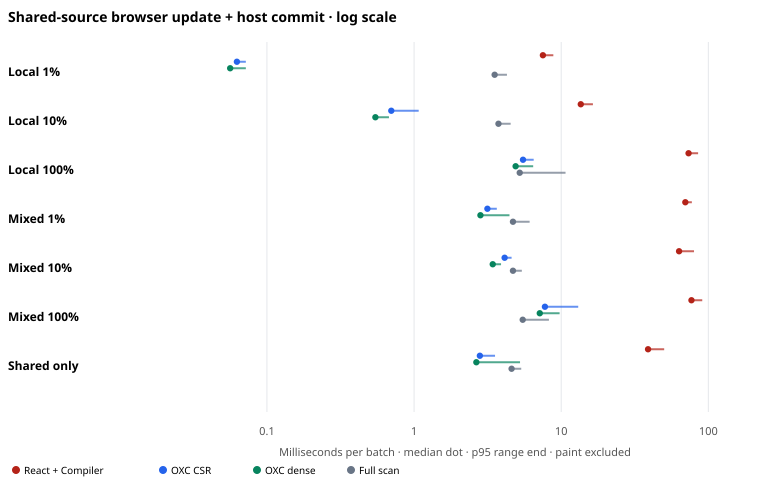

In [26]:
const raw = JSON.parse(await Deno.readTextFile("results/browser-shared-source-timing-session-v2-2026-10-09.json"));
const arms = ["react", "csr", "dense", "scan"];
const tupleArmIndex = { react: 1, csr: 2, dense: 3, scan: 4 };
const expectedScenarios = [
  ["local", 0.01], ["local", 0.1], ["local", 1],
  ["mixed", 0.01], ["mixed", 0.1], ["mixed", 1],
  ["shared", 0.1],
];
if (raw.schemaVersion !== "shared-source-timing-v2" || raw.runs.length !== 14 ||
  raw.pageLoads.length !== 2 || raw.pairTupleFields.join(",") !==
    "orderPermutationIndex,reactMs,csrMs,denseMs,scanMs") {
  throw new Error("Unexpected shared-source timing dataset schema or coverage");
}
const expectedArms = [...arms].sort().join(",");
if (raw.orderPermutations.length !== 24 ||
  new Set(raw.orderPermutations.map((p: string[]) => p.join(","))).size !== 24 ||
  raw.orderPermutations.some((p: string[]) => [...p].sort().join(",") !== expectedArms)) {
  throw new Error("The order schedule must contain all 24 unique four-arm permutations");
}
const seeds = new Set<number>();
const pageLoadIds = new Set<string>();
const grouped = new Map<string, any[]>();
const runRows: any[] = [];
const nearestRank = (values: number[], p: number) =>
  [...values].sort((a, b) => a - b)[Math.ceil(p * values.length) - 1];
for (const run of raw.runs) {
  if (seeds.has(run.seed)) throw new Error("Duplicate seed " + run.seed);
  seeds.add(run.seed);
  pageLoadIds.add(run.pageLoadId);
  if (!raw.pageLoads.includes(run.pageLoadId) || run.entities !== 10000 ||
    run.warmupPairs !== 24 || run.timedPairs !== 24 || run.pairs.length !== 24 ||
    run.parityFailures !== 0 || run.measurementDisposition !== "included") {
    throw new Error("Run metadata/parity failure for seed " + run.seed);
  }
  const counts = new Array(24).fill(0);
  const values: Record<string, number[]> = { react: [], csr: [], dense: [], scan: [] };
  for (const pair of run.pairs) {
    if (pair.length !== 5 || !Number.isInteger(pair[0]) || pair[0] < 0 || pair[0] >= 24) {
      throw new Error("Malformed pair tuple for seed " + run.seed);
    }
    counts[pair[0]]++;
    for (const arm of arms) {
      const ms = pair[tupleArmIndex[arm]];
      if (!Number.isFinite(ms) || ms < 0) throw new Error("Invalid " + arm + " timing");
      values[arm].push(ms);
    }
  }
  if (counts.some((count) => count !== 1)) {
    throw new Error("Each arm order must occur exactly once for seed " + run.seed);
  }
  const stats: Record<string, { medianMs: number; p95Ms: number }> = {};
  for (const arm of arms) {
    const sorted = [...values[arm]].sort((a, b) => a - b);
    const middle = sorted.length / 2;
    stats[arm] = {
      medianMs: (sorted[middle - 1] + sorted[middle]) / 2,
      p95Ms: nearestRank(values[arm], 0.95),
    };
  }
  const scenarioKey = run.mode + ":" + run.localChangedFraction;
  if (!grouped.has(scenarioKey)) grouped.set(scenarioKey, []);
  grouped.get(scenarioKey)!.push({ run, stats });
  runRows.push({
    seed: run.seed, pageLoadId: run.pageLoadId, timestamp: run.timestamp,
    mode: run.mode, localChangedFraction: run.localChangedFraction,
    entities: run.entities, warmupPairs: run.warmupPairs, timedPairs: run.timedPairs,
    setupMs: run.setupMs, parityFailures: run.parityFailures, stats,
  });
}
if (pageLoadIds.size !== 2 || [...grouped.values()].some((runs) => runs.length !== 2) ||
  grouped.size !== expectedScenarios.length ||
  expectedScenarios.some(([mode, fraction]) => !grouped.has(mode + ":" + fraction))) {
  throw new Error("Expected two page-load runs for all seven conditions");
}
if (!raw.parityEncoding.includes("zero parity failures")) {
  throw new Error("Dataset does not attest to all-output parity");
}
const scenarioRows = expectedScenarios.map(([mode, fraction]) => {
  const runs = grouped.get(mode + ":" + fraction)!;
  const stats: Record<string, { medianMs: number; p95Ms: number }> = {};
  for (const arm of arms) {
    const medians = runs.map((r) => r.stats[arm].medianMs).sort((a, b) => a - b);
    const p95s = runs.map((r) => r.stats[arm].p95Ms).sort((a, b) => a - b);
    stats[arm] = { medianMs: (medians[0] + medians[1]) / 2, p95Ms: (p95s[0] + p95s[1]) / 2 };
  }
  return { mode, localChangedFraction: fraction, runs: runs.map((r) => r.run.seed), stats };
});
const summary = {
  schemaVersion: "shared-source-browser-summary-v1",
  source: "results/browser-shared-source-timing-session-v2-2026-10-09.json",
  runCount: runRows.length, timedPairCount: runRows.reduce((n, r) => n + r.timedPairs, 0),
  freshPageLoads: [...pageLoadIds],
  quantileDefinition: "median is the midpoint of the two middle observations; p95 is nearest-rank ceil(0.95*n)",
  parityFailures: runRows.reduce((n, r) => n + r.parityFailures, 0), runRows, scenarioRows,
};
await Deno.writeTextFile("results/browser-shared-source-summary-v1-2026-10-09.json", JSON.stringify(summary, null, 2) + "\n");
const fmt = (x: number) => x.toFixed(3);
const tableRows = runRows.map((r) => {
  const label = r.mode === "shared" ? "Shared only" : r.mode === "local" ? "Local " +
    Math.round(r.localChangedFraction * 100) + "%" : "Mixed " + Math.round(r.localChangedFraction * 100) + "%";
  return label + " · " + r.seed + " | " +
    arms.map((arm) => fmt(r.stats[arm].medianMs) + "/" + fmt(r.stats[arm].p95Ms)).join(" | ");
});
console.log("Validated " + summary.runCount + " runs / " + summary.timedPairCount +
  " timed pairs across " + pageLoadIds.size + " fresh page loads; parity failures: 0.");
console.log("Rows are median / nearest-rank p95 milliseconds per batch.\nScenario · seed | React | CSR | dense | scan\n" + tableRows.join("\n"));
const setupRows = [...pageLoadIds].map((id) => {
  const run = raw.runs.find((r: any) => r.pageLoadId === id)!;
  return { pageLoadId: id, setupMs: run.setupMs };
});
console.log("One descriptive setup measurement per page load (milliseconds):\n" + JSON.stringify(setupRows, null, 2));

const labels = [
  ["Local", "1%"], ["Local", "10%"], ["Local", "100%"],
  ["Mixed", "1%"], ["Mixed", "10%"], ["Mixed", "100%"], ["Shared", "only"],
];
const colors: Record<string, string> = {
  react: "#b42318", csr: "#2563eb", dense: "#07845e", scan: "#697586",
};
const x0 = 190, x1 = 720, min = 0.03, max = 120;
const x = (v: number) => x0 + (Math.log10(Math.max(min, Math.min(max, v)) / min) /
  Math.log10(max / min)) * (x1 - x0);
const plot: string[] = [];
plot.push('<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="480" viewBox="0 0 760 480" role="img" aria-labelledby="o-chart-title o-chart-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">');
plot.push('<title id="o-chart-title">Shared-source browser update timing by workload</title>');
plot.push('<desc id="o-chart-desc">Logarithmic milliseconds per batch. Each colored dot is the median across two page-load run medians; a line from the median to the marker indicates median p95 across those two runs. Paint is excluded.</desc>');
plot.push('<rect width="100%" height="100%" fill="#fff"/>');
plot.push('<text x="8" y="22" font-size="14" font-weight="700">Shared-source browser update + host commit · log scale</text>');
for (const tick of [0.1, 1, 10, 100]) {
  const tx = x(tick);
  plot.push('<line x1="' + tx + '" y1="42" x2="' + tx + '" y2="412" stroke="#e5e7eb"/>');
  plot.push('<text x="' + tx + '" y="435" text-anchor="middle" font-size="11" fill="#555">' + tick + '</text>');
}
const rowStart = 65, groupGap = 49, armGap = 6.5;
for (let s = 0; s < scenarioRows.length; s++) {
  const scenario = scenarioRows[s], y = rowStart + s * groupGap;
  plot.push('<text x="8" y="' + (y + 11) + '" font-size="12" font-weight="600">' +
    labels[s][0] + ' ' + labels[s][1] + '</text>');
  for (let a = 0; a < arms.length; a++) {
    const arm = arms[a], stats = scenario.stats[arm], yy = y + (a - 1.5) * armGap;
    plot.push('<line x1="' + x(stats.medianMs) + '" y1="' + yy + '" x2="' +
      x(stats.p95Ms) + '" y2="' + yy + '" stroke="' + colors[arm] + '" stroke-width="2" opacity="0.7"/>');
    plot.push('<circle cx="' + x(stats.medianMs) + '" cy="' + yy +
      '" r="3.2" fill="' + colors[arm] + '"/>');
  }
}
plot.push('<text x="' + ((x0 + x1) / 2) + '" y="456" text-anchor="middle" font-size="11" fill="#555">Milliseconds per batch · median dot · p95 range end · paint excluded</text>');
let legendX = 12;
for (const arm of arms) {
  plot.push('<circle cx="' + (legendX + 4) + '" cy="470" r="4" fill="' + colors[arm] + '"/>');
  plot.push('<text x="' + (legendX + 12) + '" y="474" font-size="10">' +
    (arm === "react" ? "React + Compiler" : arm === "csr" ? "OXC CSR" : arm === "dense" ? "OXC dense" : "Full scan") + '</text>');
  legendX += arm === "react" ? 147 : 94;
}
plot.push('</svg>');
console.log(JSON.stringify({ runs: summary.runCount, timedPairs: summary.timedPairCount, pageLoads: pageLoadIds.size, conditions: scenarioRows.length, parityFailures: summary.parityFailures, summaryFile: "results/browser-shared-source-summary-v1-2026-10-09.json" }));
Deno.jupyter.svg`${plot.join("")}`;


### Experiment P — guarded full-scan control for shared-source updates

This follow-up adds a more favorable scan control to the five-arm shared-source browser study. The eager scan visits every host, derives each output, and writes all three style properties. The guarded scan still visits every host and computes the same strings, but compares the current style values and skips setters when a value is unchanged. This isolates the value of guarding host writes while retaining the full traversal and derivation cost; it is not an optimized scan over only changed entities.

The raw dataset contains 14 runs over 10,000 hosts, seven local/mixed/shared conditions, two page loads, and 120 timed five-arm order permutations per run (1,680 timed pairs). Each run has 24 warmup pairs and zero output-parity failures. Repeats per timed pair are condition-dependent: 16 for local 1%, 6 for local 10%, and 1 for the other conditions; each recorded timing is divided by that repeat count. The analysis validates the schedules and recomputes median and nearest-rank p95 from the saved pair timings. The SVG aggregates the two page-load run summaries per condition; each point is the midpoint of the two run medians and each segment reaches the midpoint of the two run p95s. Timing covers the input loop, synchronous dispatch, and host commit; paint is excluded.

The guarded scan is slower than the eager scan in every observed condition and page-load median. This is a result for this specific browser and fixture, not a universal claim about style setters. Comparing a getter-plus-conditional-setter against an unconditional setter suggests that style reads and string comparisons cost more here than repeated identical writes, but the experiment did not separately measure those operations. A scan that iterates only dirty hosts is a different algorithm and remains unmeasured.


Validated 14 five-arm runs / 1680 timed pairs; two page loads; 120 unique arm permutations per run; zero parity failures.


Rows are median / nearest-rank p95 milliseconds per batch (normalized by run repeats). Repeats: local 1%=16; local 10%=6; other conditions=1.
Scenario · seed | React | CSR | dense | eager scan | guarded scan
Local 1% · 42710001 | 6.403/8.231 | 0.056/0.063 | 0.050/0.056 | 3.222/3.425 | 4.631/4.806
Local 10% · 42710002 | 12.500/16.200 | 0.583/0.667 | 0.483/0.550 | 3.458/5.283 | 5.000/5.233
Local 100% · 42710003 | 82.650/100.400 | 5.200/5.800 | 4.600/5.300 | 5.100/5.500 | 9.100/11.700
Mixed 1% · 42710004 | 72.000/91.500 | 3.000/3.600 | 2.700/3.300 | 4.500/5.100 | 7.500/8.400
Mixed 10% · 42710005 | 76.750/98.800 | 4.100/4.600 | 3.400/4.100 | 4.750/5.700 | 7.900/9.300
Mixed 100% · 42710006 | 83.350/97.800 | 6.900/8.000 | 6.200/7.300 | 5.100/6.000 | 10.000/11.100
Shared only · 42710007 | 46.300/54.200 | 2.500/3.000 | 2.200/2.600 | 4.200/4.800 | 6.900/7.500
Local 1% · 42720001 | 6.350/7.288 | 0.056/0.069 | 0.050/0.056 | 3.225/3.400 | 4.844/4.969
Local 10% · 42720002 | 11.983/15.833 | 0.583/0.

Guarded scan median exceeds eager scan median in every observed run: true


{"runs":14,"timedPairs":1680,"pageLoads":2,"conditions":7,"parityFailures":0,"summaryFile":"results/browser-shared-source-five-arm-summary-v1-2026-10-09.json"}


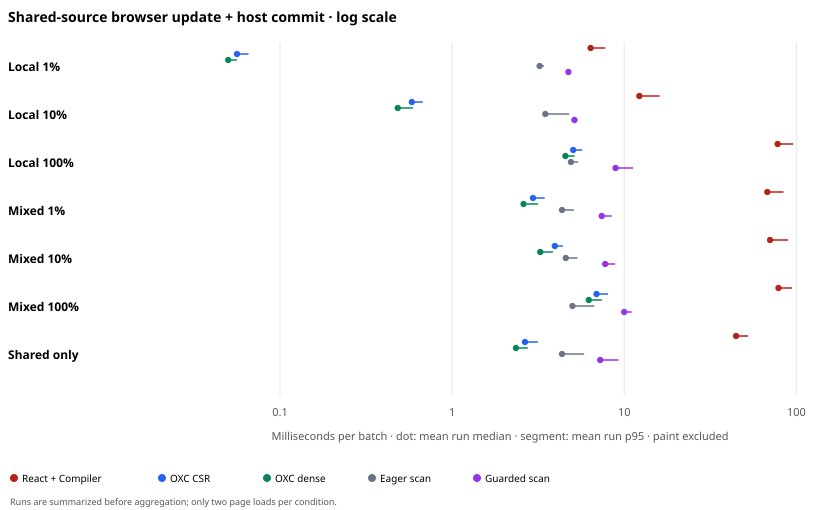

In [27]:
const rawFive = JSON.parse(await Deno.readTextFile("results/browser-shared-source-five-arm-session-v1-2026-10-09.json"));
const armsFive = ["react", "csr", "dense", "scan", "scanGuarded"] as const;
const armFieldsFive = ["reactMs", "csrMs", "denseMs", "scanMs", "scanGuardedMs"];
const expectedFiveScenarios: [string, number][] = [
  ["local", 0.01], ["local", 0.1], ["local", 1],
  ["mixed", 0.01], ["mixed", 0.1], ["mixed", 1], ["shared", 0.1],
];
const expectedTupleFields = ["orderReact", "orderCsr", "orderDense", "orderScan", "orderScanGuarded", ...armFieldsFive, "valuesMatch", "repeats"];
if (rawFive.schemaVersion !== "shared-source-five-arm-timing-v1" ||
  rawFive.runs.length !== 14 || rawFive.pageLoads.length !== 2 ||
  JSON.stringify(rawFive.arms) !== JSON.stringify(armsFive) ||
  JSON.stringify(rawFive.pairTupleFields) !== JSON.stringify(expectedTupleFields) ||
  !rawFive.orderProtocol.includes("all 120 five-arm permutations") ||
  !rawFive.orderProtocol.includes("each order once") ||
  !rawFive.parityEncoding.includes("zero parity failures")) {
  throw new Error("Unexpected five-arm shared-source dataset schema or coverage");
}
const permutationsFive: number[][] = [];
const visitOrders = (prefix: number[], remaining: number[]) => {
  if (remaining.length === 0) { permutationsFive.push(prefix); return; }
  for (let i = 0; i < remaining.length; i++) {
    visitOrders([...prefix, remaining[i]], [...remaining.slice(0, i), ...remaining.slice(i + 1)]);
  }
};
visitOrders([], [0, 1, 2, 3, 4]);
const expectedOrdersFive = new Set(permutationsFive.map((p) => p.join(",")));
const pageLoadIdsFive = new Set<string>();
const seedsFive = new Set<number>();
const groupedFive = new Map<string, any[]>();
const runRowsFive: any[] = [];
const nearestRankFive = (values: number[], p: number) =>
  [...values].sort((a, b) => a - b)[Math.ceil(p * values.length) - 1];
for (const run of rawFive.runs) {
  if (seedsFive.has(run.seed)) throw new Error("Duplicate seed " + run.seed);
  seedsFive.add(run.seed);
  pageLoadIdsFive.add(run.pageLoadId);
  const expectedRepeats = run.mode === "local" && run.localChangedFraction < 1
    ? (run.localChangedFraction < 0.1 ? 16 : 6) : 1;
  if (!rawFive.pageLoads.includes(run.pageLoadId) || run.entities !== 10000 ||
    run.warmupPairs !== 24 || run.timedPairs !== 120 || run.pairs.length !== 120 ||
    run.repeatsPerPair !== expectedRepeats ||
    !run.orderProtocol.includes("all 120 five-arm permutations") ||
    !run.orderProtocol.includes("each order once") || run.parityFailures !== 0 ||
    run.measurementDisposition !== "included") {
    throw new Error("Run metadata/parity failure for seed " + run.seed);
  }
  const observedOrders = new Set<string>();
  const values: Record<string, number[]> = Object.fromEntries(armsFive.map((arm) => [arm, []]));
  for (const pair of run.pairs) {
    if (pair.length !== 12 || pair[10] !== 1 || pair[11] !== run.repeatsPerPair) {
      throw new Error("Malformed pair or output parity failure for seed " + run.seed);
    }
    const positions = pair.slice(0, 5);
    if (positions.some((x: number) => !Number.isInteger(x) || x < 0 || x > 4) ||
      new Set(positions).size !== 5) throw new Error("Malformed arm order in seed " + run.seed);
    const order = new Array(5);
    positions.forEach((position: number, armIndex: number) => { order[position] = armIndex; });
    observedOrders.add(order.join(","));
    for (let armIndex = 0; armIndex < armsFive.length; armIndex++) {
      const ms = pair[5 + armIndex];
      if (!Number.isFinite(ms) || ms < 0) throw new Error("Invalid timing in seed " + run.seed);
      values[armsFive[armIndex]].push(ms);
    }
  }
  if (observedOrders.size !== 120 || [...expectedOrdersFive].some((order) => !observedOrders.has(order))) {
    throw new Error("Each five-arm permutation must occur once for seed " + run.seed);
  }
  const stats: Record<string, { medianMs: number; p95Ms: number }> = {};
  for (const arm of armsFive) {
    const sorted = [...values[arm]].sort((a, b) => a - b);
    stats[arm] = {
      medianMs: (sorted[59] + sorted[60]) / 2,
      p95Ms: nearestRankFive(values[arm], 0.95),
    };
  }
  const scenarioKey = run.mode + ":" + run.localChangedFraction;
  if (!groupedFive.has(scenarioKey)) groupedFive.set(scenarioKey, []);
  groupedFive.get(scenarioKey)!.push({ run, stats });
  runRowsFive.push({
    seed: run.seed, pageLoadId: run.pageLoadId, timestamp: run.timestamp,
    mode: run.mode, localChangedFraction: run.localChangedFraction,
    entities: run.entities, warmupPairs: run.warmupPairs, timedPairs: run.timedPairs,
    repeatsPerPair: run.repeatsPerPair, setupMs: run.setupMs,
    parityFailures: run.parityFailures, stats,
  });
}
if (pageLoadIdsFive.size !== 2 || groupedFive.size !== expectedFiveScenarios.length ||
  [...groupedFive.values()].some((runs) => runs.length !== 2) ||
  expectedFiveScenarios.some(([mode, fraction]) => !groupedFive.has(mode + ":" + fraction)) ||
  [...groupedFive.values()].some((runs) => new Set(runs.map((r) => r.run.pageLoadId)).size !== 2)) {
  throw new Error("Expected two fresh-page runs for all seven conditions");
}
const scenarioRowsFive = expectedFiveScenarios.map(([mode, fraction]) => {
  const runs = groupedFive.get(mode + ":" + fraction)!;
  const stats: Record<string, { medianMs: number; p95Ms: number }> = {};
  for (const arm of armsFive) {
    stats[arm] = {
      medianMs: (runs[0].stats[arm].medianMs + runs[1].stats[arm].medianMs) / 2,
      p95Ms: (runs[0].stats[arm].p95Ms + runs[1].stats[arm].p95Ms) / 2,
    };
  }
  return { mode, localChangedFraction: fraction, seeds: runs.map((r) => r.run.seed), stats };
});
const summaryFive = {
  schemaVersion: "shared-source-five-arm-browser-summary-v1",
  source: "results/browser-shared-source-five-arm-session-v1-2026-10-09.json",
  runCount: runRowsFive.length,
  timedPairCount: runRowsFive.reduce((n, r) => n + r.timedPairs, 0),
  freshPageLoads: [...pageLoadIdsFive],
  permutationCountPerRun: permutationsFive.length,
  quantileDefinition: "median is the midpoint of the two middle observations; p95 is nearest-rank ceil(0.95*n)",
  aggregation: "Each condition summarizes the two page-load run statistics by arithmetic mean.",
  parityFailures: runRowsFive.reduce((n, r) => n + r.parityFailures, 0),
  runRows: runRowsFive, scenarioRows: scenarioRowsFive,
};
await Deno.writeTextFile("results/browser-shared-source-five-arm-summary-v1-2026-10-09.json", JSON.stringify(summaryFive, null, 2) + "\n");
const fmtFive = (x: number) => x.toFixed(3);
const runTableFive = runRowsFive.map((r) => {
  const label = r.mode === "shared" ? "Shared only" : (r.mode === "local" ? "Local " : "Mixed ") + Math.round(r.localChangedFraction * 100) + "%";
  return label + " · " + r.seed + " | " + armsFive.map((arm) => fmtFive(r.stats[arm].medianMs) + "/" + fmtFive(r.stats[arm].p95Ms)).join(" | ");
});
console.log("Validated " + summaryFive.runCount + " five-arm runs / " + summaryFive.timedPairCount +
  " timed pairs; two page loads; 120 unique arm permutations per run; zero parity failures.");
console.log("Rows are median / nearest-rank p95 milliseconds per batch (normalized by run repeats). Repeats: local 1%=16; local 10%=6; other conditions=1.\nScenario · seed | React | CSR | dense | eager scan | guarded scan\n" + runTableFive.join("\n"));
console.log("Guarded scan median exceeds eager scan median in every observed run: " +
  runRowsFive.every((r) => r.stats.scanGuarded.medianMs > r.stats.scan.medianMs));

const labelsFive = [
  ["Local", "1%"], ["Local", "10%"], ["Local", "100%"],
  ["Mixed", "1%"], ["Mixed", "10%"], ["Mixed", "100%"], ["Shared", "only"],
];
const colorsFive: Record<string, string> = {
  react: "#b42318", csr: "#2563eb", dense: "#07845e", scan: "#697586", scanGuarded: "#9333ea",
};
const x0Five = 190, x1Five = 810, minFive = 0.03, maxFive = 120;
const xFive = (v: number) => x0Five + (Math.log10(Math.max(minFive, Math.min(maxFive, v)) / minFive) /
  Math.log10(maxFive / minFive)) * (x1Five - x0Five);
const plotFive: string[] = [];
plotFive.push('<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="510" viewBox="0 0 840 510" role="img" aria-labelledby="p-chart-title p-chart-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">');
plotFive.push('<title id="p-chart-title">Five-arm shared-source browser timings</title>');
plotFive.push('<desc id="p-chart-desc">Logarithmic milliseconds per batch. Each colored dot is the arithmetic mean of the two page-load run medians; a line extends to the arithmetic mean of the two run p95 values. Paint is excluded.</desc>');
plotFive.push('<rect width="100%" height="100%" fill="#fff"/>');
plotFive.push('<text x="8" y="22" font-size="14" font-weight="700">Shared-source browser update + host commit · log scale</text>');
for (const tick of [0.1, 1, 10, 100]) {
  const tx = xFive(tick);
  plotFive.push('<line x1="' + tx + '" y1="42" x2="' + tx + '" y2="395" stroke="#e5e7eb"/>');
  plotFive.push('<text x="' + tx + '" y="416" text-anchor="middle" font-size="11" fill="#555">' + tick + '</text>');
}
const rowStartFive = 60, groupGapFive = 48, armGapFive = 6;
for (let s = 0; s < scenarioRowsFive.length; s++) {
  const scenario = scenarioRowsFive[s], y = rowStartFive + s * groupGapFive;
  plotFive.push('<text x="8" y="' + (y + 11) + '" font-size="12" font-weight="600">' + labelsFive[s][0] + ' ' + labelsFive[s][1] + '</text>');
  for (let a = 0; a < armsFive.length; a++) {
    const arm = armsFive[a], stats = scenario.stats[arm], yy = y + (a - 2) * armGapFive;
    plotFive.push('<line x1="' + xFive(stats.medianMs) + '" y1="' + yy + '" x2="' +
      xFive(stats.p95Ms) + '" y2="' + yy + '" stroke="' + colorsFive[arm] + '" stroke-width="2" opacity="0.75"/>');
    plotFive.push('<circle cx="' + xFive(stats.medianMs) + '" cy="' + yy + '" r="3.2" fill="' + colorsFive[arm] + '"/>');
  }
}
plotFive.push('<text x="' + ((x0Five + x1Five) / 2) + '" y="440" text-anchor="middle" font-size="11" fill="#555">Milliseconds per batch · dot: mean run median · segment: mean run p95 · paint excluded</text>');
let legendXFive = 10;
const legendLabelsFive: Record<string, string> = { react: "React + Compiler", csr: "OXC CSR", dense: "OXC dense", scan: "Eager scan", scanGuarded: "Guarded scan" };
for (const arm of armsFive) {
  plotFive.push('<circle cx="' + (legendXFive + 4) + '" cy="478" r="4" fill="' + colorsFive[arm] + '"/>');
  plotFive.push('<text x="' + (legendXFive + 12) + '" y="482" font-size="10">' + legendLabelsFive[arm] + '</text>');
  legendXFive += arm === "react" ? 148 : 105;
}
plotFive.push('<text x="10" y="505" font-size="9" fill="#555">Runs are summarized before aggregation; only two page loads per condition.</text>');
plotFive.push('</svg>');
console.log(JSON.stringify({ runs: summaryFive.runCount, timedPairs: summaryFive.timedPairCount, pageLoads: pageLoadIdsFive.size, conditions: scenarioRowsFive.length, parityFailures: summaryFive.parityFailures, summaryFile: "results/browser-shared-source-five-arm-summary-v1-2026-10-09.json" }));
Deno.jupyter.svg`${plotFive.join("")}`;


### Experiment Q — compiler-emitted writers versus the plan interpreter

This experiment changes one part of the execution path. The OXC compiler now emits direct property-writer functions for the supported repeated-host fixture; the dense interpreter uses the same source slots, values, dirty queue, and scheduler, then looks up each binding and invokes its projector through the generic plan. The generated path still uses the shared runtime for setup and dirty-source collection. It is not a second independent scheduler or a general-purpose JSX code generator.

The six-arm browser study compares React 19.3 with React Compiler and external-store subscriptions, OXC CSR, OXC dense interpretation, OXC generated writers, eager full scan, and guarded full scan. It records 14 runs across two fresh page loads, seven conditions, and 120 timed pairs per run. Orders are unique seeded cyclic six-arm blocks, balanced so each arm appears 20 times in each timing position. Every run has 24 warmups, 10,000 hosts, and zero parity failures. Local 1% and local 10% pairs average 16 and 6 repeats respectively; all other conditions use one repeat. The notebook recomputes each run's median and nearest-rank p95 from raw pairs, then averages the two page-load run summaries for a condition. Setup is reported separately; timing includes the synchronous update and host commit, but excludes paint.

The generated writer path has a lower median than the dense interpreter in every run in this fixture. This is evidence that direct generated property writes can remove measurable dispatch overhead in this narrow path. It does not show a general UI performance win: the comparison omits dynamic structure, realistic application work, independent devices, and paint, and the React arm performs component execution and reconciliation that the custom arms skip. Every chart in this notebook, including this browser chart, is inline responsive SVG emitted through `Deno.jupyter.svg`.


Validated 14 six-arm runs / 1680 timed pairs; two page loads; 120 unique position-balanced orders per run; zero parity failures.


Rows show per-run median / nearest-rank p95 milliseconds per batch; setup is separate; paint excluded.
Scenario · seed | React | CSR | dense interpreter | generated writers | eager scan | guarded scan
Local 1% · 42730001 | 7.153/9.188 | 0.056/0.069 | 0.053/0.063 | 0.044/0.050 | 3.425/3.544 | 4.787/4.969
Local 10% · 42730002 | 14.275/19.167 | 0.600/0.800 | 0.517/0.567 | 0.417/0.450 | 3.550/5.383 | 5.133/5.317
Local 100% · 42730003 | 92.450/106.100 | 4.900/5.400 | 4.400/5.000 | 3.600/4.100 | 4.600/5.100 | 8.700/9.500
Mixed 10% · 42730005 | 80.450/91.200 | 3.900/4.300 | 3.100/3.500 | 2.200/2.600 | 4.300/4.800 | 7.550/8.200
Mixed 1% · 42730004 | 81.100/97.200 | 2.800/3.300 | 2.300/2.800 | 1.600/2.000 | 4.300/6.400 | 7.200/9.700
Mixed 100% · 42730006 | 96.400/126.300 | 6.900/7.600 | 6.100/6.800 | 4.600/5.200 | 4.800/5.300 | 10.100/11.500
Shared only · 42730007 | 53.000/71.000 | 2.500/2.900 | 2.100/2.600 | 1.400/1.800 | 4.000/5.700 | 7.000/7.600
Local 1% · 42740001 | 6.700/9.081 | 0.056/0.06

Generated-writer median is lower in all 14 runs: true; generated wins per 120 paired observations range 111–120.


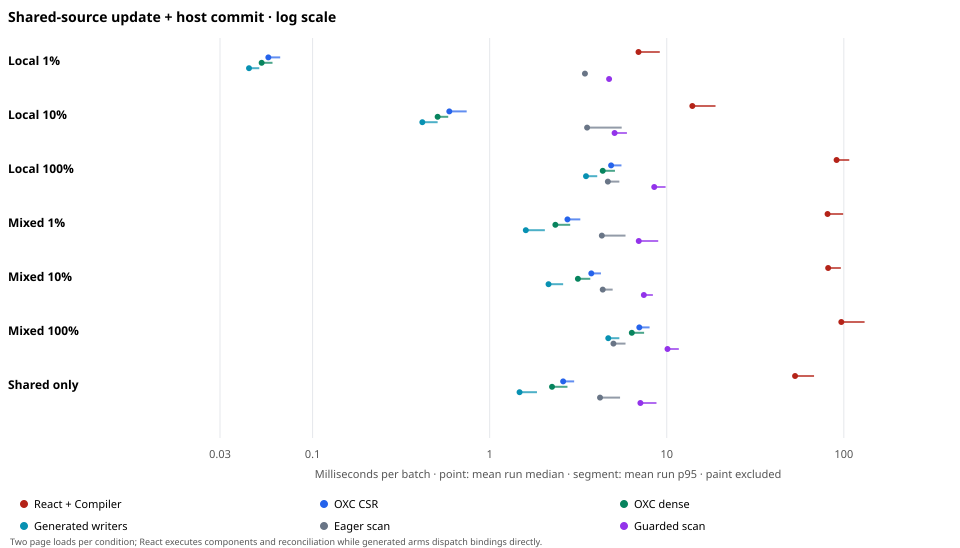

In [28]:
const rawSix = JSON.parse(await Deno.readTextFile("results/browser-shared-source-six-arm-session-v1-2026-10-09.json"));
const armsSix = ["react", "csr", "dense", "generated", "scan", "scanGuarded"] as const;
const scenariosSix: [string, number][] = [
  ["local", 0.01], ["local", 0.1], ["local", 1],
  ["mixed", 0.01], ["mixed", 0.1], ["mixed", 1], ["shared", 0.1],
];
if (rawSix.schemaVersion !== "shared-source-six-arm-timing-v1" || rawSix.runs.length !== 14 ||
  rawSix.pageLoads.length !== 2 || JSON.stringify(rawSix.arms) !== JSON.stringify(armsSix) ||
  rawSix.runs.reduce((n: number, r: any) => n + r.pairs.length, 0) !== 1680) {
  throw new Error("Unexpected six-arm shared-source dataset schema or coverage");
}
const groupedSix = new Map<string, any[]>();
const pageIdsSix = new Set<string>();
const seedsSix = new Set<number>();
const runRowsSix: any[] = [];
const nearestRankSix = (values: number[], p: number) =>
  [...values].sort((a, b) => a - b)[Math.ceil(p * values.length) - 1];
for (const run of rawSix.runs) {
  if (seedsSix.has(run.seed)) throw new Error("Duplicate seed " + run.seed);
  seedsSix.add(run.seed);
  pageIdsSix.add(run.pageLoadId);
  const expectedRepeats = run.mode === "local" && run.localChangedFraction < 1
    ? (run.localChangedFraction < 0.1 ? 16 : 6) : 1;
  if (!rawSix.pageLoads.includes(run.pageLoadId) || run.entities !== 10000 || run.warmupPairs !== 24 ||
    run.timedPairs !== 120 || run.pairs.length !== 120 || run.repeatsPerPair !== expectedRepeats ||
    run.parityFailures !== 0 || run.measurementDisposition !== "included") {
    throw new Error("Run metadata or parity failure for seed " + run.seed);
  }
  const seenOrders = new Set<string>();
  let generatedDenseWins = 0;
  const positionCounts: Record<string, number[]> = Object.fromEntries(armsSix.map((a) => [a, [0, 0, 0, 0, 0, 0]]));
  const values: Record<string, number[]> = Object.fromEntries(armsSix.map((a) => [a, []]));
  for (const pair of run.pairs) {
    if (!pair.valuesMatch || pair.repeats !== run.repeatsPerPair || armsSix.some((a) => !Number.isFinite(pair.timingsMs[a]))) {
      throw new Error("Malformed timing or parity mismatch for seed " + run.seed);
    }
    if (pair.order.length !== 6 || new Set(pair.order).size !== 6 || armsSix.some((a) => !pair.order.includes(a))) {
      throw new Error("Malformed order in seed " + run.seed);
    }
    const key = pair.order.join(",");
    if (seenOrders.has(key)) throw new Error("Repeated timing order in seed " + run.seed);
    seenOrders.add(key);
    pair.order.forEach((arm: string, position: number) => positionCounts[arm][position]++);
    for (const arm of armsSix) values[arm].push(pair.timingsMs[arm]);
    if (pair.timingsMs.generated < pair.timingsMs.dense) generatedDenseWins++;
  }
  if (seenOrders.size !== 120 || armsSix.some((a) => positionCounts[a].some((n) => n !== 20))) {
    throw new Error("Order uniqueness or position balance failed for seed " + run.seed);
  }
  const stats: Record<string, { medianMs: number; p95Ms: number }> = {};
  for (const arm of armsSix) {
    const sorted = [...values[arm]].sort((a, b) => a - b);
    stats[arm] = { medianMs: (sorted[59] + sorted[60]) / 2, p95Ms: nearestRankSix(values[arm], 0.95) };
  }
  const key = run.mode + ":" + run.localChangedFraction;
  if (!groupedSix.has(key)) groupedSix.set(key, []);
  groupedSix.get(key)!.push({ run, stats });
  runRowsSix.push({ seed: run.seed, pageLoadId: run.pageLoadId, timestamp: run.timestamp,
    mode: run.mode, localChangedFraction: run.localChangedFraction, setupMs: run.setupMs,
    generatedDenseWins, parityFailures: run.parityFailures, stats });
}
if (pageIdsSix.size !== 2 || groupedSix.size !== 7 || [...groupedSix.values()].some((runs) =>
  runs.length !== 2 || new Set(runs.map((x) => x.run.pageLoadId)).size !== 2) ||
  scenariosSix.some(([mode, f]) => !groupedSix.has(mode + ":" + f))) {
  throw new Error("Expected two fresh-page runs for all seven conditions");
}
const scenarioRowsSix = scenariosSix.map(([mode, localChangedFraction]) => {
  const runs = groupedSix.get(mode + ":" + localChangedFraction)!;
  const stats: Record<string, { medianMs: number; p95Ms: number }> = {};
  for (const arm of armsSix) stats[arm] = {
    medianMs: (runs[0].stats[arm].medianMs + runs[1].stats[arm].medianMs) / 2,
    p95Ms: (runs[0].stats[arm].p95Ms + runs[1].stats[arm].p95Ms) / 2,
  };
  return { mode, localChangedFraction, seeds: runs.map((x) => x.run.seed), stats,
    generatedMedianReductionVsDensePercent: (1 - stats.generated.medianMs / stats.dense.medianMs) * 100 };
});
const summarySix = {
  schemaVersion: "shared-source-six-arm-browser-summary-v1",
  source: "results/browser-shared-source-six-arm-session-v1-2026-10-09.json",
  runCount: runRowsSix.length, timedPairCount: runRowsSix.length * 120,
  freshPageLoads: [...pageIdsSix], uniqueOrderCountPerRun: 120,
  balance: "each of six arms appears 20 times in each of six timing positions per run",
  quantileDefinition: "median is the midpoint of the two middle observations; p95 is nearest-rank ceil(0.95*n)",
  aggregation: "Each condition summarizes the two fresh-page run statistics by arithmetic mean.",
  parityFailures: runRowsSix.reduce((n, r) => n + r.parityFailures, 0), runRows: runRowsSix, scenarioRows: scenarioRowsSix,
};
await Deno.writeTextFile("results/browser-shared-source-six-arm-summary-v1-2026-10-09.json", JSON.stringify(summarySix, null, 2) + "\n");
const fmtSix = (x: number) => x.toFixed(3);
const runTableSix = runRowsSix.map((r) => {
  const label = r.mode === "shared" ? "Shared only" : (r.mode === "local" ? "Local " : "Mixed ") + Math.round(r.localChangedFraction * 100) + "%";
  return label + " · " + r.seed + " | " + armsSix.map((a) => fmtSix(r.stats[a].medianMs) + "/" + fmtSix(r.stats[a].p95Ms)).join(" | ");
});
console.log("Validated " + summarySix.runCount + " six-arm runs / " + summarySix.timedPairCount +
  " timed pairs; two page loads; 120 unique position-balanced orders per run; zero parity failures.");
console.log("Rows show per-run median / nearest-rank p95 milliseconds per batch; setup is separate; paint excluded.\nScenario · seed | React | CSR | dense interpreter | generated writers | eager scan | guarded scan\n" + runTableSix.join("\n"));
console.log("Generated-writer median is lower in all 14 runs: " +
  runRowsSix.every((r) => r.stats.generated.medianMs < r.stats.dense.medianMs) +
  "; generated wins per 120 paired observations range " + Math.min(...runRowsSix.map((r) => r.generatedDenseWins)) +
  "–" + Math.max(...runRowsSix.map((r) => r.generatedDenseWins)) + ".");
const labelsSix = [["Local", "1%"], ["Local", "10%"], ["Local", "100%"], ["Mixed", "1%"], ["Mixed", "10%"], ["Mixed", "100%"], ["Shared", "only"]];
const colorsSix: Record<string, string> = { react: "#b42318", csr: "#2563eb", dense: "#07845e", generated: "#0891b2", scan: "#697586", scanGuarded: "#9333ea" };
const x0Six = 220, x1Six = 875, minSix = 0.03, maxSix = 150;
const xSix = (v: number) => x0Six + Math.log10(Math.max(minSix, Math.min(maxSix, v)) / minSix) / Math.log10(maxSix / minSix) * (x1Six - x0Six);
const chartSix: string[] = ['<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="548" viewBox="0 0 960 548" role="img" aria-labelledby="six-title six-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">'];
chartSix.push('<title id="six-title">Generated writers and six-arm shared-source browser timings</title><desc id="six-desc">Logarithmic milliseconds per batch. Each colored point is the mean of two fresh-page run medians; the segment extends to the mean of the two run p95 values. Paint is excluded.</desc><rect width="100%" height="100%" fill="#fff"/><text x="8" y="22" font-size="14" font-weight="700">Shared-source update + host commit · log scale</text>');
for (const tick of [0.03, 0.1, 1, 10, 100]) { const x = xSix(tick); chartSix.push('<line x1="' + x + '" y1="38" x2="' + x + '" y2="438" stroke="#e5e7eb"/><text x="' + x + '" y="458" text-anchor="middle" font-size="11" fill="#555">' + tick + '</text>'); }
for (let si = 0; si < scenarioRowsSix.length; si++) {
  const row = scenarioRowsSix[si], groupY = 50 + si * 54;
  chartSix.push('<text x="8" y="' + (groupY + 15) + '" font-size="12" font-weight="600">' + labelsSix[si][0] + ' ' + labelsSix[si][1] + '</text>');
  for (let ai = 0; ai < armsSix.length; ai++) {
    const arm = armsSix[ai], yy = groupY + ai * 5.4 + 2;
    const m = xSix(row.stats[arm].medianMs), p = xSix(row.stats[arm].p95Ms);
    chartSix.push('<line x1="' + m + '" y1="' + yy + '" x2="' + p + '" y2="' + yy + '" stroke="' + colorsSix[arm] + '" stroke-width="2" opacity="0.72"/><circle cx="' + m + '" cy="' + yy + '" r="3" fill="' + colorsSix[arm] + '"/>');
  }
}
chartSix.push('<text x="548" y="478" text-anchor="middle" font-size="11" fill="#555">Milliseconds per batch · point: mean run median · segment: mean run p95 · paint excluded</text>');
const legendSix = [["React + Compiler", "react"], ["OXC CSR", "csr"], ["OXC dense", "dense"], ["Generated writers", "generated"], ["Eager scan", "scan"], ["Guarded scan", "scanGuarded"]] as const;
for (let i = 0; i < legendSix.length; i++) { const row = i < 3 ? 0 : 1, col = i % 3, x = 24 + col * 300, y = 504 + row * 22; chartSix.push('<circle cx="' + x + '" cy="' + y + '" r="4" fill="' + colorsSix[legendSix[i][1]] + '"/><text x="' + (x + 10) + '" y="' + (y + 4) + '" font-size="11">' + legendSix[i][0] + '</text>'); }
chartSix.push('<text x="10" y="545" font-size="9" fill="#555">Two page loads per condition; React executes components and reconciliation while generated arms dispatch bindings directly.</text></svg>');
Deno.jupyter.svg`${chartSix.join("")}`;


### Experiment R — JSX-authored React baseline replication

This replication changes the React source authoring form to actual JSX in the benchmark’s TSX source while keeping the six arms, workload, seeded order protocol, output checks, and React Compiler in place. It does not make internal work equivalent: React calls one component per entity, evaluates two `useSyncExternalStore` subscriptions, and reconciles; the generated writer arm uses its emitted binding plan to write host properties directly. The comparison therefore measures complete implementations of this fixture, not a fair test of equivalent framework semantics.

The dataset contains 14 runs across two fresh page-load IDs, seven conditions, and 120 paired timing orders per run (1,680 pairs total). Every six-arm order is unique within its run, every arm appears 20 times in every position, and every output parity check passes. Sparse local-only cases average 16 timing repetitions per pair; 10% local-only cases average six; all others use one. Each timing is the synchronous update plus host commit; setup is separately recorded and paint is excluded.

The generated writer arm has a lower median than the JSX React arm in every paired sample in this dataset. Across the two run medians per condition, generated writers range from about 18.8× to 166.1× lower latency. This large ratio reflects the deliberately specialized operation and React’s additional component/subscription/reconciliation work; it is not evidence that a general replacement runtime is 18.8×–166.1× faster. The present benchmark offers no direct evidence about source readability, maintenance cost, async correctness, keyed structure, or adapter ergonomics. Every notebook chart remains inline responsive SVG via `Deno.jupyter.svg`.


Validated 14 runs / 1680 paired samples; two page loads; 120 unique orders and position-balanced schedules per run; zero parity failures.


Scenario | React median/p95 ms | generated median/p95 ms | writer wins / 240 | ratio


local 1% | 7.266/9.119 | 0.044/0.053 | 240 | 166.1x


local 10% | 15.125/20.758 | 0.450/0.758 | 240 | 33.6x


local 100% | 94.225/123.850 | 3.850/5.100 | 240 | 24.5x


mixed 1% | 77.850/101.150 | 1.750/2.250 | 240 | 44.5x


mixed 10% | 83.375/120.950 | 2.450/3.250 | 240 | 34.0x


mixed 100% | 94.050/121.700 | 5.000/6.800 | 240 | 18.8x


shared only | 52.075/61.900 | 1.550/2.100 | 240 | 33.6x


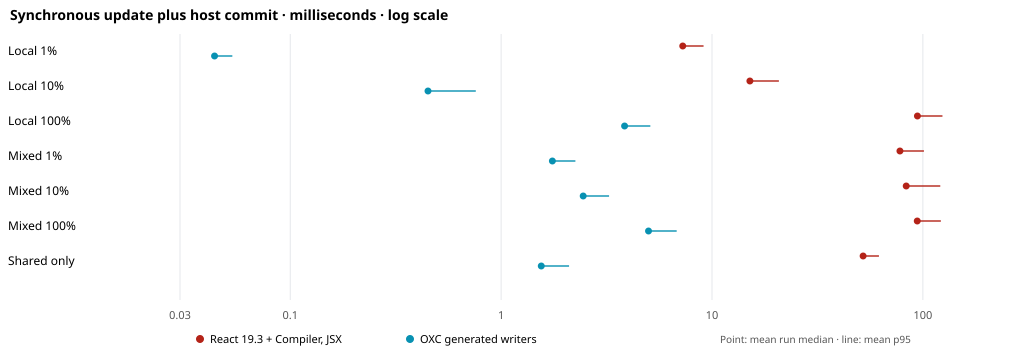

In [29]:
const rawJSXR = JSON.parse(await Deno.readTextFile("results/browser-shared-source-six-arm-jsx-react-session-v1-2026-10-09.json"));
const armsJSXR = ["react", "csr", "dense", "generated", "scan", "scanGuarded"] as const;
const scenariosJSXR: [string, number][] = [
  ["local", 0.01], ["local", 0.1], ["local", 1],
  ["mixed", 0.01], ["mixed", 0.1], ["mixed", 1], ["shared", 0.1],
];
if (rawJSXR.schemaVersion !== "shared-source-six-arm-jsx-react-timing-v1" || rawJSXR.runs.length !== 14 ||
  rawJSXR.pageLoads.length !== 2 || JSON.stringify(rawJSXR.arms) !== JSON.stringify(armsJSXR) ||
  rawJSXR.runs.reduce((n: number, r: any) => n + r.pairs.length, 0) !== 1680) {
  throw new Error("Unexpected JSX React six-arm dataset schema or coverage");
}
const groupJSXR = new Map<string, any[]>();
const pageJSXR = new Set<string>(), seedsJSXR = new Set<number>();
const runSummaryJSXR: any[] = [];
const quantileJSXR = (xs: number[], p: number) => [...xs].sort((a,b)=>a-b)[Math.ceil(p*xs.length)-1];
for (const run of rawJSXR.runs) {
  if (seedsJSXR.has(run.seed)) throw new Error("Duplicate seed " + run.seed);
  seedsJSXR.add(run.seed); pageJSXR.add(run.pageLoadId);
  const repeatExpected = run.mode === "local" && run.localChangedFraction < 1 ? (run.localChangedFraction < 0.1 ? 16 : 6) : 1;
  if (!rawJSXR.pageLoads.includes(run.pageLoadId) || run.entities !== 10000 || run.warmupPairs !== 24 ||
    run.timedPairs !== 120 || run.pairs.length !== 120 || run.repeatsPerPair !== repeatExpected ||
    run.parityFailures !== 0 || run.measurementDisposition !== "included") throw new Error("Invalid run " + run.seed);
  const orders = new Set<string>();
  const positions: Record<string, number[]> = Object.fromEntries(armsJSXR.map(a=>[a,[0,0,0,0,0,0]]));
  const values: Record<string, number[]> = Object.fromEntries(armsJSXR.map(a=>[a,[]]));
  for (const pair of run.pairs) {
    if (!pair.valuesMatch || pair.repeats !== repeatExpected || armsJSXR.some(a=>!Number.isFinite(pair.timingsMs[a]))) throw new Error("Parity/timing invalid in " + run.seed);
    if (pair.order.length !== 6 || new Set(pair.order).size !== 6 || armsJSXR.some(a=>!pair.order.includes(a))) throw new Error("Bad order in " + run.seed);
    const key=pair.order.join(","); if (orders.has(key)) throw new Error("Repeated order in " + run.seed); orders.add(key);
    pair.order.forEach((a:string,i:number)=>positions[a][i]++);
    for (const a of armsJSXR) values[a].push(pair.timingsMs[a]);
  }
  if (orders.size !== 120 || armsJSXR.some(a=>positions[a].some(n=>n!==20))) throw new Error("Position balance failed in " + run.seed);
  const stats: Record<string,{medianMs:number;p95Ms:number}> = {};
  for (const a of armsJSXR) { const s=[...values[a]].sort((x,y)=>x-y); stats[a]={medianMs:(s[59]+s[60])/2,p95Ms:quantileJSXR(values[a],.95)}; }
  const key=run.mode+":"+run.localChangedFraction; if(!groupJSXR.has(key))groupJSXR.set(key,[]);
  groupJSXR.get(key)!.push({run,stats});
  runSummaryJSXR.push({seed:run.seed,pageLoadId:run.pageLoadId,mode:run.mode,localChangedFraction:run.localChangedFraction,
    repeatsPerPair:run.repeatsPerPair,parityFailures:run.parityFailures,generatedReactWins:run.pairs.filter((p:any)=>p.timingsMs.generated<p.timingsMs.react).length,stats});
}
if(pageJSXR.size!==2||groupJSXR.size!==7||[...groupJSXR.values()].some(g=>g.length!==2||new Set(g.map(x=>x.run.pageLoadId)).size!==2)||
  scenariosJSXR.some(([m,f])=>!groupJSXR.has(m+":"+f))) throw new Error("Expected two fresh-page runs for every scenario");
const scenarioSummaryJSXR=scenariosJSXR.map(([mode,localChangedFraction])=>{
  const rs=groupJSXR.get(mode+":"+localChangedFraction)!;
  const stats:Record<string,{medianMs:number;p95Ms:number}>={};
  for(const a of armsJSXR) stats[a]={medianMs:(rs[0].stats[a].medianMs+rs[1].stats[a].medianMs)/2,p95Ms:(rs[0].stats[a].p95Ms+rs[1].stats[a].p95Ms)/2};
  return {mode,localChangedFraction,seeds:rs.map(x=>x.run.seed),stats,generatedWins:rs.reduce((n,x)=>n+x.run.pairs.filter((p:any)=>p.timingsMs.generated<p.timingsMs.react).length,0),
    generatedVsReactRatio:stats.react.medianMs/stats.generated.medianMs};
});
const summaryJSXR={schemaVersion:"shared-source-six-arm-jsx-react-summary-v1",source:"results/browser-shared-source-six-arm-jsx-react-session-v1-2026-10-09.json",
  runCount:runSummaryJSXR.length,timedPairCount:1680,freshPageLoads:[...pageJSXR],scenarios:scenarioSummaryJSXR,runSummaries:runSummaryJSXR,
  parityFailures:runSummaryJSXR.reduce((n,r)=>n+r.parityFailures,0),generatedWins:runSummaryJSXR.reduce((n,r)=>n+r.generatedReactWins,0),
  comparisonLimit:"React renders components, checks subscriptions, and reconciles; generated writers directly update bindings. Paint excluded; one Chrome/MacIntel profile/device."};
await Deno.writeTextFile("results/browser-shared-source-six-arm-jsx-react-summary-v1-2026-10-09.json",JSON.stringify(summaryJSXR,null,2)+"\n");
console.log("Validated " + summaryJSXR.runCount + " runs / " + summaryJSXR.timedPairCount + " paired samples; two page loads; 120 unique orders and position-balanced schedules per run; zero parity failures.");
console.log("Scenario | React median/p95 ms | generated median/p95 ms | writer wins / 240 | ratio");
for(const r of scenarioSummaryJSXR) console.log((r.mode+" "+(r.mode==="shared"?"only":Math.round(r.localChangedFraction*100)+"%"))+" | "+r.stats.react.medianMs.toFixed(3)+"/"+r.stats.react.p95Ms.toFixed(3)+" | "+r.stats.generated.medianMs.toFixed(3)+"/"+r.stats.generated.p95Ms.toFixed(3)+" | "+r.generatedWins+" | "+r.generatedVsReactRatio.toFixed(1)+"x");
const labelsJSXR=["Local 1%","Local 10%","Local 100%","Mixed 1%","Mixed 10%","Mixed 100%","Shared only"];
const x0JSXR=180,x1JSXR=960,minJSXR=.03,maxJSXR=150;
const scaleJSXR=(v:number)=>x0JSXR+Math.log10(Math.max(minJSXR,Math.min(maxJSXR,v))/minJSXR)/Math.log10(maxJSXR/minJSXR)*(x1JSXR-x0JSXR);
const svgJSXR:string[]=['<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="350" viewBox="0 0 1020 350" role="img" aria-labelledby="jsxr-title jsxr-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">'];
svgJSXR.push('<title id="jsxr-title">JSX React versus generated writer update latency</title><desc id="jsxr-desc">Log scale in milliseconds. Dots are the arithmetic mean of two fresh-page run medians; lines extend to mean p95. Paint excluded.</desc><rect width="100%" height="100%" fill="white"/><text x="10" y="20" font-size="14" font-weight="700">Synchronous update plus host commit · milliseconds · log scale</text>');
for(const t of [.03,.1,1,10,100]){const x=scaleJSXR(t);svgJSXR.push('<line x1="'+x+'" y1="34" x2="'+x+'" y2="300" stroke="#e5e7eb"/><text x="'+x+'" y="319" text-anchor="middle" font-size="11" fill="#555">'+t+'</text>');}
for(let i=0;i<scenarioSummaryJSXR.length;i++){const r=scenarioSummaryJSXR[i],y=51+i*35;svgJSXR.push('<text x="8" y="'+(y+4)+'" font-size="12">'+labelsJSXR[i]+'</text>');for(const [arm,color,dy] of [["react","#b42318",-5],["generated","#0891b2",5]] as const){const m=scaleJSXR(r.stats[arm].medianMs),p=scaleJSXR(r.stats[arm].p95Ms),yy=y+dy;svgJSXR.push('<line x1="'+m+'" y1="'+yy+'" x2="'+p+'" y2="'+yy+'" stroke="'+color+'" stroke-width="2" opacity=".7"/><circle cx="'+m+'" cy="'+yy+'" r="3.5" fill="'+color+'"/>');}}
svgJSXR.push('<circle cx="200" cy="339" r="4" fill="#b42318"/><text x="210" y="343" font-size="11">React 19.3 + Compiler, JSX</text><circle cx="410" cy="339" r="4" fill="#0891b2"/><text x="420" y="343" font-size="11">OXC generated writers</text><text x="720" y="343" font-size="10" fill="#555">Point: mean run median · line: mean p95</text></svg>');
Deno.jupyter.svg`${svgJSXR.join("")}`;


### Experiment S — multi-trait scaling across entity count and update density

This experiment extends the JSX-authored React baseline to three entity counts and three change fractions. Each updated entity changes two sources and writes the same three DOM style properties in all arms: React uses two `useSyncExternalStore` subscriptions and a batched `flushSync`; OXC CSR and dense identity-layout plans dispatch the same generated dependencies. OXC dense is the specialized host-plan path, not a framework reconciler. The React source and host output use JSX.

The study contains 18 runs across two page loads: 1,000, 5,000, and 10,000 entities at 1%, 10%, and 100% changed, with one run per condition per page load. Every run contains 24 warmups and 48 timed pairs. The six possible three-arm orders are each used eight times, and every arm occurs 16 times in each position. Sparse runs average 32 repeated updates per pair, 10% runs average eight, and full-density runs use one. Paired parity samples changed IDs after each pair; a full-host parity pass runs once after the final pair, outside the timed interval. Setup is reported separately; paint is excluded.

The dense graph path is faster than the JSX React path in every timed pair in this sample, and CSR also wins in every pair. Its relative advantage is largest for sparse updates and declines as update density rises. That shape matches the expected tradeoff: direct indexed dispatch avoids React's per-component subscription and reconciliation work, while every changed entity still requires the same host property updates. The experiment remains one browser profile/device and unequal in internal work, so it supports a scaling hypothesis for this compiled path rather than a general framework victory. The chart is responsive inline SVG.


Validated 18 runs / 864 timed pairs across two page loads; six three-arm orders repeated eight times per run; 16 appearances per position; zero parity failures; full-host final parity on all runs.


Entities | changed | React med/p95 | CSR med/p95 | dense med/p95 | dense wins / 96 | ratio


1000 | 1% | 0.5398/0.6484 | 0.0063/0.0094 | 0.0062/0.0078 | 96 | 86.4x


1000 | 10% | 3.6250/7.6813 | 0.2656/0.6312 | 0.1687/0.5500 | 96 | 21.5x


1000 | 100% | 24.4500/43.4000 | 3.3250/6.7000 | 2.0000/4.0000 | 96 | 12.2x


...

5000 | 10% | 5.2281/6.6938 | 0.3875/0.5313 | 0.2625/0.3062 | 96 | 19.9x


5000 | 100% | 30.6250/35.7000 | 3.6500/4.7500 | 2.4000/2.7000 | 96 | 12.8x


10000 | 1% | 6.5055/7.9938 | 0.0734/0.0828 | 0.0500/0.0594 | 96 | 130.1x


10000 | 10% | 12.4781/14.4562 | 0.8656/1.0063 | 0.5469/0.6250 | 96 | 22.8x


10000 | 100% | 65.3750/79.1000 | 8.1250/12.0500 | 5.0750/6.4000 | 96 | 12.9x


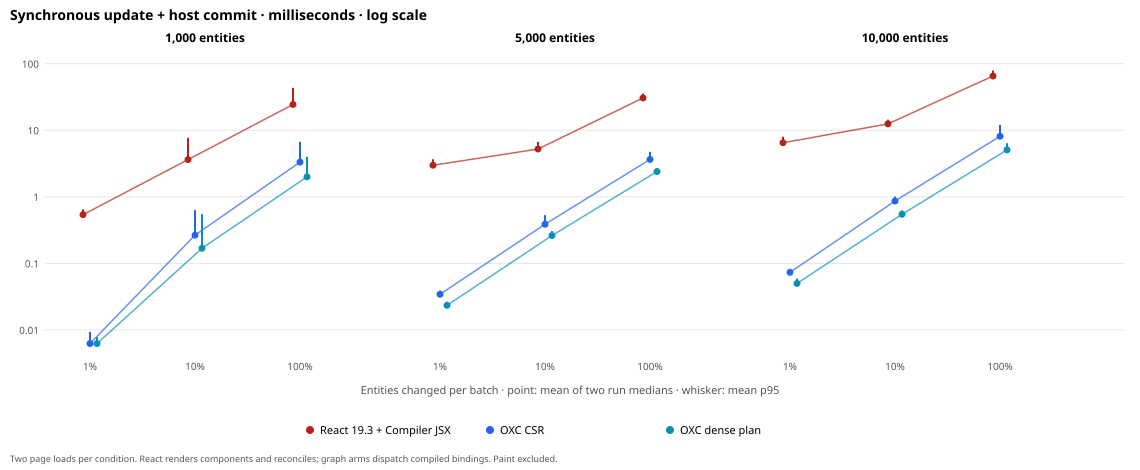

In [30]:
const rawScaleS = JSON.parse(await Deno.readTextFile("results/browser-multi-source-jsx-scale-session-v1-2026-10-09.json"));
const armsScaleS = ["react", "csr", "dense"] as const;
const countsScaleS = [1000, 5000, 10000];
const fractionsScaleS = [0.01, 0.1, 1];
if (rawScaleS.schemaVersion !== "multi-source-jsx-scale-browser-timing-v1" || rawScaleS.runs.length !== 18 ||
  rawScaleS.pageLoads.length !== 2 || rawScaleS.runs.reduce((n: number, r: any) => n + r.pairs.length, 0) !== 864) {
  throw new Error("Unexpected multi-source JSX scale dataset shape");
}
const pagesScaleS=new Set<string>(),seedsScaleS=new Set<number>(),groupsScaleS=new Map<string,any[]>(),runRowsScaleS:any[]=[];
const nearestScaleS=(xs:number[],p:number)=>[...xs].sort((a,b)=>a-b)[Math.ceil(p*xs.length)-1];
for(const run of rawScaleS.runs){
  if(seedsScaleS.has(run.seed))throw new Error("Duplicate scale seed "+run.seed);seedsScaleS.add(run.seed);pagesScaleS.add(run.pageLoadId);
  const expectedRepeats=run.changedFraction===0.01?32:run.changedFraction===0.1?8:1;
  if(!rawScaleS.pageLoads.includes(run.pageLoadId)||!countsScaleS.includes(run.entities)||!fractionsScaleS.includes(run.changedFraction)||
    run.schemaVersion!==2||!run.reactAuthoring?.includes("JSX")||run.warmupPairs!==24||run.timedPairs!==48||run.pairs.length!==48||
    run.repeatsPerPair!==expectedRepeats||run.parityFailures!==0||run.finalStateValuesMatch!==true)throw new Error("Invalid scale run "+run.seed);
  const counts:Record<string,number[]>=Object.fromEntries(armsScaleS.map(a=>[a,[0,0,0]]));
  const orderCounts=new Map<string,number>();const values:Record<string,number[]>=Object.fromEntries(armsScaleS.map(a=>[a,[]]));
  for(const pair of run.pairs){
    if(!pair.valuesMatch||pair.repeats!==expectedRepeats||pair.order.length!==3||new Set(pair.order).size!==3||armsScaleS.some(a=>!pair.order.includes(a))||armsScaleS.some(a=>!Number.isFinite(pair.timingsMs[a])))throw new Error("Bad pair in "+run.seed);
    const k=pair.order.join(",");orderCounts.set(k,(orderCounts.get(k)??0)+1);
    pair.order.forEach((a:string,i:number)=>counts[a][i]++);
    for(const a of armsScaleS)values[a].push(pair.timingsMs[a]);
  }
  if(orderCounts.size!==6||[...orderCounts.values()].some(n=>n!==8)||armsScaleS.some(a=>counts[a].some(n=>n!==16)))throw new Error("Order schedule unbalanced in "+run.seed);
  const stats:Record<string,{medianMs:number;p95Ms:number}>={};
  for(const a of armsScaleS){const s=[...values[a]].sort((x,y)=>x-y);stats[a]={medianMs:(s[23]+s[24])/2,p95Ms:nearestScaleS(values[a],.95)};}
  const key=run.entities+":"+run.changedFraction;if(!groupsScaleS.has(key))groupsScaleS.set(key,[]);groupsScaleS.get(key)!.push({run,stats});
  runRowsScaleS.push({seed:run.seed,pageLoadId:run.pageLoadId,entities:run.entities,changedFraction:run.changedFraction,repeatsPerPair:expectedRepeats,parityFailures:run.parityFailures,finalStateValuesMatch:run.finalStateValuesMatch,
    denseReactWins:run.pairs.filter((p:any)=>p.timingsMs.dense<p.timingsMs.react).length,csrReactWins:run.pairs.filter((p:any)=>p.timingsMs.csr<p.timingsMs.react).length,stats});
}
if(pagesScaleS.size!==2||groupsScaleS.size!==9||[...groupsScaleS.values()].some(g=>g.length!==2||new Set(g.map(x=>x.run.pageLoadId)).size!==2))throw new Error("Expected two fresh page loads for all nine scale conditions");
const scenarioScaleS=[] as any[];
for(const count of countsScaleS)for(const fraction of fractionsScaleS){
  const rs=groupsScaleS.get(count+":"+fraction)!;const stats:Record<string,{medianMs:number;p95Ms:number}>={};
  for(const a of armsScaleS)stats[a]={medianMs:(rs[0].stats[a].medianMs+rs[1].stats[a].medianMs)/2,p95Ms:(rs[0].stats[a].p95Ms+rs[1].stats[a].p95Ms)/2};
  scenarioScaleS.push({entities:count,changedFraction:fraction,seeds:rs.map(x=>x.run.seed),stats,denseWins:rs.reduce((n,x)=>n+x.run.pairs.filter((p:any)=>p.timingsMs.dense<p.timingsMs.react).length,0),
    csrWins:rs.reduce((n,x)=>n+x.run.pairs.filter((p:any)=>p.timingsMs.csr<p.timingsMs.react).length,0),denseVsReactRatio:stats.react.medianMs/stats.dense.medianMs});
}
const summaryScaleS={schemaVersion:"multi-source-jsx-scale-browser-summary-v1",source:"results/browser-multi-source-jsx-scale-session-v1-2026-10-09.json",runCount:runRowsScaleS.length,timedPairCount:864,
  freshPageLoads:[...pagesScaleS],scenarios:scenarioScaleS,runSummaries:runRowsScaleS,denseWins:runRowsScaleS.reduce((n,r)=>n+r.denseReactWins,0),csrWins:runRowsScaleS.reduce((n,r)=>n+r.csrReactWins,0),parityFailures:runRowsScaleS.reduce((n,r)=>n+r.parityFailures,0),
  statisticDefinition:"Within each run, median is the midpoint of the two central observations; p95 is nearest-rank. Condition values are arithmetic means of the two run statistics.",
  limitation:"One Chrome/MacIntel profile and device; paint excluded; React component and subscription work differs from direct generated binding dispatch."};
await Deno.writeTextFile("results/browser-multi-source-jsx-scale-summary-v1-2026-10-09.json",JSON.stringify(summaryScaleS,null,2)+"\n");
console.log("Validated "+summaryScaleS.runCount+" runs / "+summaryScaleS.timedPairCount+" timed pairs across two page loads; six three-arm orders repeated eight times per run; 16 appearances per position; zero parity failures; full-host final parity on all runs.");
console.log("Entities | changed | React med/p95 | CSR med/p95 | dense med/p95 | dense wins / 96 | ratio");
for(const r of scenarioScaleS)console.log(r.entities+" | "+Math.round(r.changedFraction*100)+"% | "+r.stats.react.medianMs.toFixed(4)+"/"+r.stats.react.p95Ms.toFixed(4)+" | "+r.stats.csr.medianMs.toFixed(4)+"/"+r.stats.csr.p95Ms.toFixed(4)+" | "+r.stats.dense.medianMs.toFixed(4)+"/"+r.stats.dense.p95Ms.toFixed(4)+" | "+r.denseWins+" | "+r.denseVsReactRatio.toFixed(1)+"x");
const chartScaleS:string[]=['<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="470" viewBox="0 0 1140 470" role="img" aria-labelledby="scale-title scale-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">'];
chartScaleS.push('<title id="scale-title">JSX React and compiled graph latency across sizes and update density</title><desc id="scale-desc">Three panels for 1,000, 5,000, and 10,000 entities. Horizontal positions are change densities 1, 10, and 100 percent. Vertical axis is milliseconds on a log scale. Dots show mean run medians and whiskers mean run p95.</desc><rect width="100%" height="100%" fill="white"/><text x="10" y="20" font-size="14" font-weight="700">Synchronous update + host commit · milliseconds · log scale</text>');
const chartMinS=.005,chartMaxS=150,yTopS=52,yBottomS=350;
const yScaleS=(v:number)=>yBottomS-Math.log10(Math.max(chartMinS,Math.min(chartMaxS,v))/chartMinS)/Math.log10(chartMaxS/chartMinS)*(yBottomS-yTopS);
const seriesScaleS=[["react","#b42318"],["csr","#2563eb"],["dense","#0891b2"]] as const;
for(const tick of [.01,.1,1,10,100]){const y=yScaleS(tick);chartScaleS.push('<line x1="45" y1="'+y+'" x2="1125" y2="'+y+'" stroke="#e5e7eb"/><text x="39" y="'+(y+4)+'" text-anchor="end" font-size="10" fill="#555">'+tick+'</text>');}
for(let ci=0;ci<countsScaleS.length;ci++){
 const count=countsScaleS[ci],left=90+ci*350;chartScaleS.push('<text x="'+(left+115)+'" y="42" text-anchor="middle" font-size="12" font-weight="700">'+count.toLocaleString()+" entities</text>");
 for(let ai=0;ai<seriesScaleS.length;ai++){
  const [arm,color]=seriesScaleS[ai];const points=[] as string[];
  for(let fi=0;fi<fractionsScaleS.length;fi++){
   const row=scenarioScaleS.find(r=>r.entities===count&&r.changedFraction===fractionsScaleS[fi])!;const x=left+fi*105;const med=yScaleS(row.stats[arm].medianMs),p95=yScaleS(row.stats[arm].p95Ms);const dx=ai*7-7;
   chartScaleS.push('<line x1="'+(x+dx)+'" y1="'+med+'" x2="'+(x+dx)+'" y2="'+p95+'" stroke="'+color+'" stroke-width="2"/><circle cx="'+(x+dx)+'" cy="'+med+'" r="3.5" fill="'+color+'"/>');
   points.push((x+dx)+","+med);
  }
  chartScaleS.push('<polyline points="'+points.join(" ")+'" fill="none" stroke="'+color+'" stroke-width="1.5" opacity=".7"/>');
 }
 for(let fi=0;fi<fractionsScaleS.length;fi++){const x=left+fi*105;chartScaleS.push('<text x="'+x+'" y="370" text-anchor="middle" font-size="10" fill="#555">'+Math.round(fractionsScaleS[fi]*100)+'%</text>');}
}
chartScaleS.push('<text x="570" y="394" text-anchor="middle" font-size="11" fill="#555">Entities changed per batch · point: mean of two run medians · whisker: mean p95</text>');
for(let i=0;i<seriesScaleS.length;i++){const [name,color]=seriesScaleS[i];const x=310+i*180;chartScaleS.push('<circle cx="'+x+'" cy="430" r="4" fill="'+color+'"/><text x="'+(x+10)+'" y="434" font-size="11">'+({react:"React 19.3 + Compiler JSX",csr:"OXC CSR",dense:"OXC dense plan"} as any)[name]+'</text>');}
chartScaleS.push('<text x="10" y="462" font-size="9" fill="#555">Two page loads per condition. React renders components and reconciles; graph arms dispatch compiled bindings. Paint excluded.</text></svg>');
Deno.jupyter.svg`${chartScaleS.join("")}`;


## Experiment T — candidate-root coordination and transition scheduling

The critical-path rows are a deterministic model, not measured framework performance. A separate paired JS benchmark times the candidate coordinator against a scan-on-every-completion reference. Three fresh-process replications show consistent indexed wins from 64 roots upward; lower fan-in exposes fixed bookkeeping costs. It contrasts a serial-discovery waterfall with a dependency plan that launches independent I/O concurrently and starts a derived view model after its declared inputs resolve. Fixed task durations make the critical-path effect reproducible; scheduler bookkeeping, JavaScript work, worker transfer, paint, and browser presentation are excluded. The waterfall is an adversarial control and makes no claim about React or another framework; an eager `Promise.all` implementation can also overlap independent requests.

The state-machine portion exercises the JavaScript `TransitionCoordinator`: a pending candidate leaves committed root snapshots and lifecycle counters unchanged; superseded and cancelled work cannot publish late results; a coordinated group waits for all its roots; disjoint root groups progress independently; and staged lifecycle work runs on commit. The commit callback drives a retained keyed VDOM through an in-memory host adapter; it verifies node identity, keyed insert/remove/reorder, and a two-root patch after readiness. VDOM scalar bindings are indexed source-to-prop; a source update changes only the bound properties without executing the component or walking the VDOM. In the invariant fixture, one source writes exactly two props. A DOM adapter is implemented, while browser validation, real effects, and compiler-emitted dependency tables remain open. The next evidence gate is to connect it to the renderer and measure equivalent interactions against React 19.3 Suspense, Transitions, and ViewTransition.

Run `deno task transition:replicate` before this notebook to collect three fresh-process paired timing runs. The deterministic model is saved to `results/transition-scheduler-model-v1.json`; paired samples and the replication summary are saved under `results/transition-coordinator-fanin-*.json`.


Independent resources | serial discovery | DAG planned | modeled reduction


1 | 50 ms | 50 ms | 0.0%


2 | 95 ms | 63 ms | 33.7%


4 | 187 ms | 76 ms | 59.4%


8 | 379 ms | 78 ms | 79.4%


...

1 | 0.54x / 0.46x / 0.48x | 0 / 1 / 0


16 | 0.55x / 1.26x / 1.28x | 9 / 9 / 11


64 | 4.37x / 4.36x / 4.26x | 17 / 17 / 17


256 | 4.52x / 4.54x / 4.44x | 17 / 17 / 17


1024 | 20.97x / 19.49x / 21.60x | 17 / 17 / 17


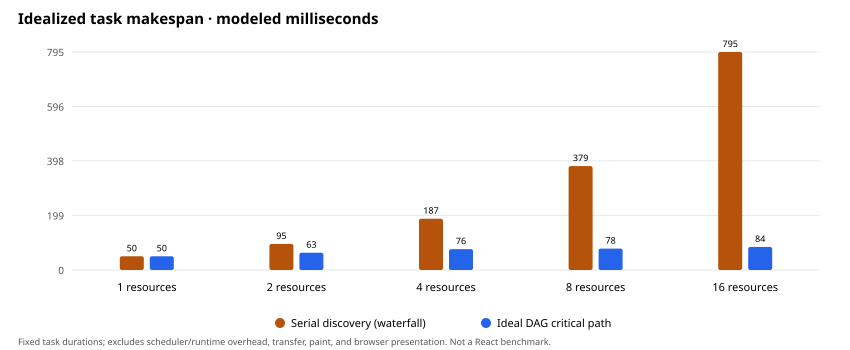

In [31]:
import { runTransitionExperiment } from "./src/transition_experiment.ts";
import { runTransitionCoordinatorBenchmark } from "./src/transition_coordinator_benchmark.ts";

const transitionModel = runTransitionExperiment();
await Deno.writeTextFile("results/transition-scheduler-model-v1.json", JSON.stringify(transitionModel, null, 2) + "\n");
console.log("Independent resources | serial discovery | DAG planned | modeled reduction");
for (const row of transitionModel.scenarios) {
  const reduction = 1 - row.dagPlannedMs / row.waterfallMs;
  console.log(`${row.independentResources} | ${row.waterfallMs} ms | ${row.dagPlannedMs} ms | ${(reduction * 100).toFixed(1)}%`);
}
console.log("Transition invariants:", JSON.stringify(transitionModel.transitionInvariants));
console.log("VDOM commit path invariants:", JSON.stringify(transitionModel.vdomCommitPath));
console.log("VDOM binding path invariants:", JSON.stringify(transitionModel.vdomBindingPath));
const fanInBenchmark = runTransitionCoordinatorBenchmark();
await Deno.writeTextFile("results/transition-coordinator-fanin-v1.json", JSON.stringify(fanInBenchmark, null, 2) + "\n");
console.log("\nRoot count | indexed coordinator med/p95 | per-completion scan med/p95 | scan/index ratio | indexed wins");
for (const row of fanInBenchmark.summaries) {
  console.log(`${row.rootCount} | ${row.indexedCoordinator.medianMs.toFixed(4)}/${row.indexedCoordinator.p95Ms.toFixed(4)} ms | ${row.scanOnEveryResolve.medianMs.toFixed(4)}/${row.scanOnEveryResolve.p95Ms.toFixed(4)} ms | ${row.scanOverIndexedMedianRatio.toFixed(2)}x | ${row.wins.indexedCoordinator}/${row.pairCount}`);
}
const fanInReplications = JSON.parse(await Deno.readTextFile("results/transition-coordinator-fanin-replication-summary-v1.json"));
console.log("\nFresh-process replications | scan/index median ratio | indexed wins / 17 pairs");
for (const row of fanInReplications.crossProcess) {
  console.log(`${row.rootCount} | ${row.scanOverIndexedMedianRatioByRun.map((x:number)=>x.toFixed(2)+"x").join(" / ")} | ${row.indexedWinsByRun.join(" / ")}`);
}

const transitionSvg: string[] = ['<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="350" viewBox="0 0 850 350" role="img" aria-labelledby="transition-title transition-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">'];
transitionSvg.push('<title id="transition-title">Modeled critical path for serial discovery and dependency planning</title><desc id="transition-desc">Grouped bars compare a serial waterfall with an idealized DAG plan for one, two, four, eight, and sixteen independent resources. Fixed durations are used. Scheduler overhead and runtime work are excluded.</desc><rect width="100%" height="100%" fill="white"/><text x="18" y="24" font-size="15" font-weight="700">Idealized task makespan · modeled milliseconds</text>');
const chartLeft = 72, chartRight = 820, chartTop = 52, chartBottom = 270, maxMs = Math.max(...transitionModel.scenarios.map((x) => x.waterfallMs));
const y = (value: number) => chartBottom - (value / maxMs) * (chartBottom - chartTop);
for (let tick = 0; tick <= 4; tick++) {
  const value = Math.round(maxMs * tick / 4), yy = y(value);
  transitionSvg.push(`<line x1="${chartLeft}" y1="${yy}" x2="${chartRight}" y2="${yy}" stroke="#e5e7eb"/><text x="${chartLeft-8}" y="${yy+4}" text-anchor="end" font-size="10" fill="#555">${value}</text>`);
}
const groupWidth = (chartRight-chartLeft)/transitionModel.scenarios.length;
transitionModel.scenarios.forEach((row, index) => {
  const center = chartLeft + groupWidth*(index+.5), barWidth=24;
  const values = [[row.waterfallMs,"#b45309"],[row.dagPlannedMs,"#2563eb"]] as const;
  values.forEach(([value,color], arm) => {
    const height = chartBottom-y(value), x = center+(arm===0?-barWidth-3:3);
    transitionSvg.push(`<rect x="${x}" y="${y(value)}" width="${barWidth}" height="${height}" fill="${color}" rx="2"/><text x="${x+barWidth/2}" y="${y(value)-5}" text-anchor="middle" font-size="9">${value}</text>`);
  });
  transitionSvg.push(`<text x="${center}" y="291" text-anchor="middle" font-size="11">${row.independentResources} resources</text>`);
});
transitionSvg.push('<circle cx="280" cy="323" r="5" fill="#b45309"/><text x="291" y="327" font-size="11">Serial discovery (waterfall)</text><circle cx="486" cy="323" r="5" fill="#2563eb"/><text x="497" y="327" font-size="11">Ideal DAG critical path</text><text x="18" y="345" font-size="9" fill="#555">Fixed task durations; excludes scheduler/runtime overhead, transfer, paint, and browser presentation. Not a React benchmark.</text></svg>');
Deno.jupyter.svg`${transitionSvg.join("")}`;



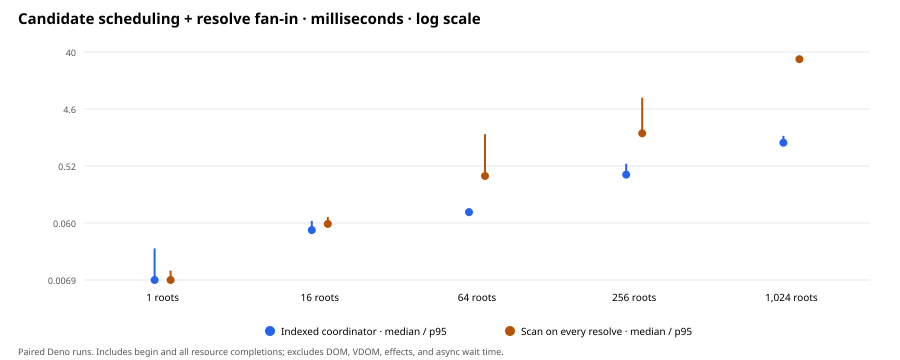

In [32]:
const fanSvg: string[] = ['<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="360" viewBox="0 0 900 360" role="img" aria-labelledby="fanin-title fanin-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">'];
fanSvg.push('<title id="fanin-title">Transition coordinator fan-in scheduling overhead</title><desc id="fanin-desc">Log-scale paired medians and p95 for a generation-indexed root coordinator and a reference scanning all root generations on each resource completion. This times scheduler bookkeeping, not rendering.</desc><rect width="100%" height="100%" fill="white"/><text x="18" y="24" font-size="15" font-weight="700">Candidate scheduling + resolve fan-in · milliseconds · log scale</text>');
const fanLeft=84,fanRight=870,fanTop=52,fanBottom=280;
const fanValues=fanInBenchmark.summaries.flatMap((row:any)=>[row.indexedCoordinator.p95Ms,row.scanOnEveryResolve.p95Ms]);
const fanMin=Math.max(0.0001,Math.min(...fanValues)*.7),fanMax=Math.max(...fanValues)*1.2;
const fanY=(value:number)=>fanBottom-Math.log10(Math.max(fanMin,value)/fanMin)/Math.log10(fanMax/fanMin)*(fanBottom-fanTop);
for(let tick=0;tick<=4;tick++){const value=fanMin*Math.pow(fanMax/fanMin,tick/4),yy=fanY(value);fanSvg.push(`<line x1="${fanLeft}" y1="${yy}" x2="${fanRight}" y2="${yy}" stroke="#e5e7eb"/><text x="${fanLeft-8}" y="${yy+4}" text-anchor="end" font-size="9" fill="#555">${value.toPrecision(2)}</text>`);}
fanInBenchmark.summaries.forEach((row:any,index:number)=>{
 const x=fanLeft+(index+.5)*(fanRight-fanLeft)/fanInBenchmark.summaries.length;
 for(const [offset,color,arm] of [[-8,"#2563eb",row.indexedCoordinator],[8,"#b45309",row.scanOnEveryResolve]] as const){
  const medY=fanY(arm.medianMs),p95Y=fanY(arm.p95Ms);
  fanSvg.push(`<line x1="${x+offset}" y1="${medY}" x2="${x+offset}" y2="${p95Y}" stroke="${color}" stroke-width="2"/><circle cx="${x+offset}" cy="${medY}" r="4" fill="${color}"/>`);
 }
 fanSvg.push(`<text x="${x}" y="301" text-anchor="middle" font-size="10">${row.rootCount.toLocaleString()} roots</text>`);
});
fanSvg.push('<circle cx="270" cy="331" r="5" fill="#2563eb"/><text x="281" y="335" font-size="10">Indexed coordinator · median / p95</text><circle cx="510" cy="331" r="5" fill="#b45309"/><text x="521" y="335" font-size="10">Scan on every resolve · median / p95</text><text x="18" y="355" font-size="9" fill="#555">Paired Deno runs. Includes begin and all resource completions; excludes DOM, VDOM, effects, and async wait time.</text></svg>');
Deno.jupyter.svg`${fanSvg.join("")}`;


## Experiment U — retained VDOM scalar updates vs React

This browser fixture mounts the same 10,000 keyed leaf DOM structure in React 19.3 + React Compiler and in `VDOMSnapshotRoot`. Each leaf changes the same three inline style properties. React uses one stable `useSyncExternalStore` subscription per leaf; the retained VDOM arm routes scalar sources through the mount-built source-to-prop index. Each page load performs 12 warmup pairs and 36 timed pairs in seeded balanced order and checks full style parity after each timed pair. Three page loads per density were collected on one Chrome 155/macOS Intel device. Timing includes dispatch and synchronous host commit, but excludes paint and presentation. The 1% path is below 0.2 ms and near the timer floor. This is a runtime primitive comparison, not a general React benchmark: there are no topology changes, React selector libraries, compiler-generated OXC binding tables, or second-device runs.

Page-level summaries and seeds are saved in `results/retained-vdom-react-page-replications-v1.json`. The benchmark UI can export full paired sample records. Reopen `retained-vdom-react-benchmark.html?autorun=1&count=10000&fraction=0.1&seed=20261012` to reproduce one of the recorded scenarios in the browser.


┌───────┬─────────┬────────────────────┬────────────────────┬──────────────────────┬────────────────────┬─────────────┬──────────┬────────────┐
│ (idx) │ updates │ reactMedianMs      │ reactP95Ms         │ retainedVdomMedianMs │ retainedVdomP95Ms  │ medianRatio │ pairsWon │ parityRuns │
├───────┼─────────┼────────────────────┼────────────────────┼──────────────────────┼────────────────────┼─────────────┼──────────┼────────────┤
│     0 │     100 │ 5.2374999998137355 │ 6.5166666666045785 │ 0.16666666666666666  │ 0.2041666666045785 │ "31.42×"    │      108 │          3 │
│     1 │    1000 │ 7.983333334326744  │ 9.116666665921608  │ 1.866666667163372    │ 2.2666666669150195 │ "4.28×"     │      108 │          3 │
│     2 │   10000 │ 38.79999999701977  │ 43.69999999552965  │ 18.899999998509884   │ 21.599999994039536 │ "2.05×"     │      108 │          3 │
└───────┴─────────┴────────────────────┴────────────────────┴──────────────────────┴────────────────────┴─────────────┴──────────┴──────

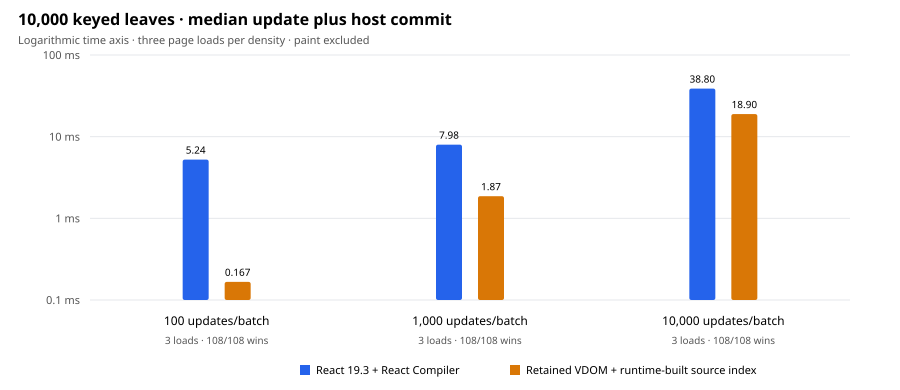

In [33]:
const retainedVdomReact = JSON.parse(await Deno.readTextFile("results/retained-vdom-react-page-replications-v1.json"));
const median = (values: number[]) => [...values].sort((a, b) => a - b)[Math.floor(values.length / 2)];
const verifiedRows = [...new Set(retainedVdomReact.runs.map((run: any) => run.fraction))].sort((a, b) => a - b).map((fraction) => {
  const runs = retainedVdomReact.runs.filter((run: any) => run.fraction === fraction);
  if (runs.length !== 3 || runs.some((run: any) => !run.parity || run.pairedWins.retainedVDOM !== 36 || run.pairedWins.react !== 0)) {
    throw new Error(`Invalid retained-VDOM page replication set at fraction ${fraction}`);
  }
  const reactMedian = median(runs.map((run: any) => run.react.medianMs));
  const retainedVDOMMedian = median(runs.map((run: any) => run.retainedVDOM.medianMs));
  const row = {
    fraction,
    updatesPerBatch: Math.round(retainedVdomReact.protocol.entities * fraction),
    replications: runs.length,
    reactMedianAcrossPageMediansMs: reactMedian,
    reactP95AcrossPageP95Ms: median(runs.map((run: any) => run.react.p95Ms)),
    retainedVDOMMedianAcrossPageMediansMs: retainedVDOMMedian,
    retainedVDOMP95AcrossPageP95Ms: median(runs.map((run: any) => run.retainedVDOM.p95Ms)),
    medianRatioReactOverVDOM: reactMedian / retainedVDOMMedian,
    pairedWins: runs.reduce((sum: number, run: any) => sum + run.pairedWins.retainedVDOM, 0),
    parityRunsPassed: runs.filter((run: any) => run.parity).length,
  };
  const recorded = retainedVdomReact.summary.find((summary: any) => summary.fraction === fraction);
  for (const key of Object.keys(row) as Array<keyof typeof row>) {
    if (typeof row[key] === "number" && typeof recorded?.[key] === "number" && Math.abs((row[key] as number) - recorded[key]) > 1e-9) {
      throw new Error(`Summary mismatch for ${key} at fraction ${fraction}`);
    }
  }
  return row;
});
if (verifiedRows.length !== 3) throw new Error("Expected exactly three retained-VDOM update densities");
console.table(verifiedRows.map((row) => ({
  updates: row.updatesPerBatch,
  reactMedianMs: row.reactMedianAcrossPageMediansMs,
  reactP95Ms: row.reactP95AcrossPageP95Ms,
  retainedVdomMedianMs: row.retainedVDOMMedianAcrossPageMediansMs,
  retainedVdomP95Ms: row.retainedVDOMP95AcrossPageP95Ms,
  medianRatio: row.medianRatioReactOverVDOM.toFixed(2) + "×",
  pairsWon: row.pairedWins,
  parityRuns: row.parityRunsPassed,
})));

const chartWidth = 900, chartHeight = 390;
const left = 90, right = 850, top = 55, bottom = 300;
const logY = (value: number) => bottom - ((Math.log10(value) + 1) / 3) * (bottom - top);
const svg: string[] = [`<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="390" viewBox="0 0 ${chartWidth} ${chartHeight}" role="img" aria-labelledby="retained-title retained-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">`];
svg.push('<title id="retained-title">React and retained VDOM update latency by changed leaf count</title><desc id="retained-desc">Logarithmic grouped bars compare median synchronous update and host-commit time over three page loads. Retained VDOM is faster on this static keyed leaf fixture, but its sparse timing approaches the browser timer floor.</desc><rect width="100%" height="100%" fill="white"/><text x="18" y="25" font-size="16" font-weight="700">10,000 keyed leaves · median update plus host commit</text><text x="18" y="44" font-size="11" fill="#555">Logarithmic time axis · three page loads per density · paint excluded</text>');
for (const tick of [0.1, 1, 10, 100]) {
  const y = logY(tick);
  svg.push(`<line x1="${left}" y1="${y}" x2="${right}" y2="${y}" stroke="#e5e7eb"/><text x="${left - 10}" y="${y + 4}" text-anchor="end" font-size="11" fill="#555">${tick} ms</text>`);
}
const rows = verifiedRows;
const groupWidth = (right - left) / rows.length;
rows.forEach((row: any, index: number) => {
  const center = left + groupWidth * (index + 0.5);
  const series = [
    { value: row.reactMedianAcrossPageMediansMs, color: "#2563eb" },
    { value: row.retainedVDOMMedianAcrossPageMediansMs, color: "#d97706" },
  ];
  series.forEach((item, seriesIndex) => {
    const x = center + (seriesIndex === 0 ? -34 : 8);
    const y = logY(item.value);
    svg.push(`<rect x="${x}" y="${y}" width="26" height="${bottom - y}" fill="${item.color}" rx="2"/><text x="${x + 13}" y="${y - 6}" text-anchor="middle" font-size="10">${item.value < 1 ? item.value.toFixed(3) : item.value.toFixed(2)}</text>`);
  });
  svg.push(`<text x="${center}" y="325" text-anchor="middle" font-size="12">${row.updatesPerBatch.toLocaleString()} updates/batch</text><text x="${center}" y="344" text-anchor="middle" font-size="10" fill="#555">${row.replications} loads · ${row.pairedWins}/108 wins</text>`);
});
svg.push('<rect x="300" y="365" width="10" height="10" fill="#2563eb"/><text x="316" y="374" font-size="11">React 19.3 + React Compiler</text><rect x="510" y="365" width="10" height="10" fill="#d97706"/><text x="526" y="374" font-size="11">Retained VDOM + runtime-built source index</text></svg>');
Deno.jupyter.svg`${svg.join("")}`;


## Experiment V — compiled VDOM bindings and property-level writes

This experiment separates three update paths on the same 10,000-leaf, 10%-changed workload: (1) the original runtime-discovered source-to-style-object index, (2) runtime-discovered per-style-field writers, and (3) OXC-emitted CSR binding IDs resolved to retained VDOM props at mount. Each page load uses the same 12 warmup pairs, 36 timed pairs, six repeats per pair, balanced arm order, React Compiler baseline, and full style parity checks. Three page loads were collected per mode on the same Chrome 155/macOS Intel machine. The modes were run in blocks rather than interleaved, so treat small cross-mode differences cautiously.

The direct-field paths substantially reduce update work because they project and write only fields declared as dependent. In these three replications, the median VDOM update was 1.90 ms for whole style-object materialization, 0.883 ms for runtime-discovered direct fields, and 0.967 ms for OXC CSR direct fields. This shows little steady-state difference between compiled and runtime-discovered direct writers on this tiny two-source graph, while compiled setup costs more. The result supports using compiler metadata as dependency truth and resolving it once into compact writer lists before updates begin. We still need a matched interleaved comparison, shared-source fan-out, larger dependency graphs, and topology changes before generalizing.


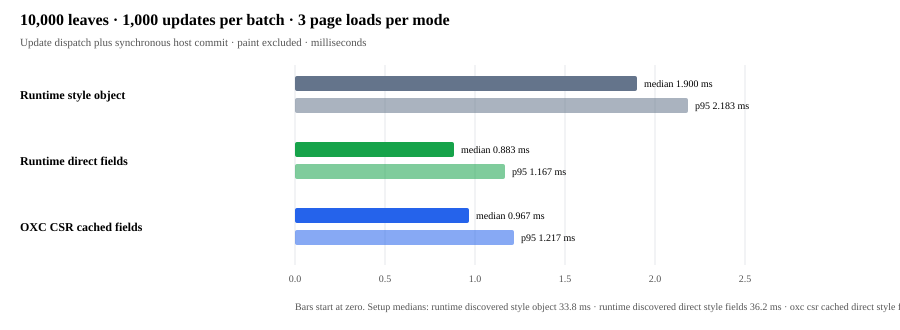

In [34]:
const dispatchStudy = JSON.parse(await Deno.readTextFile("results/browser-vdom-dispatch-comparison-v1-2026-10-09.json"));
const dispatchRows = dispatchStudy.summary;
const dispatchColors = ["#64748b", "#16a34a", "#2563eb"];
const dispatchLabels = ["Runtime style object", "Runtime direct fields", "OXC CSR cached fields"];
const chartWidth = 900;
const barStart = 295;
const chartMax = 2.5;
const scale = 450 / chartMax;
const dispatchSvg: string[] = [`<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="330" viewBox="0 0 ${chartWidth} 330" role="img" aria-labelledby="dispatch-title dispatch-desc"><title id="dispatch-title">Retained VDOM dispatch latency comparison</title><desc id="dispatch-desc">Horizontal bars show median and page-level p95 update time for runtime style object, runtime direct fields, and OXC CSR direct fields across three fresh page loads.</desc><rect width="100%" height="100%" fill="white"/><text x="20" y="25" font-size="16" font-weight="700">10,000 leaves · 1,000 updates per batch · 3 page loads per mode</text><text x="20" y="46" font-size="11" fill="#555">Update dispatch plus synchronous host commit · paint excluded · milliseconds</text>`];
for (let tick = 0; tick <= chartMax; tick += 0.5) {
  const x = barStart + tick * scale;
  dispatchSvg.push(`<line x1="${x}" y1="65" x2="${x}" y2="265" stroke="#e5e7eb"/><text x="${x}" y="282" text-anchor="middle" font-size="10" fill="#555">${tick.toFixed(1)}</text>`);
}
for (let i = 0; i < dispatchRows.length; i++) {
  const row = dispatchRows[i];
  const y = 95 + i * 66;
  const color = dispatchColors[i];
  dispatchSvg.push(`<text x="20" y="${y + 4}" font-size="12" font-weight="600">${dispatchLabels[i]}</text>`);
  for (const [offset, label, value, opacity] of [[-10, "median", row.vdomMedianAcrossPageMediansMs, "1"], [12, "p95", row.vdomP95AcrossPageP95Ms, ".55"]] as const) {
    const width = value * scale;
    dispatchSvg.push(`<rect x="${barStart}" y="${y + offset - 9}" width="${width}" height="15" rx="2" fill="${color}" opacity="${opacity}"/><text x="${barStart + width + 7}" y="${y + offset + 2}" font-size="10">${label} ${value.toFixed(3)} ms</text>`);
  }
}
dispatchSvg.push(`<text x="${barStart}" y="310" font-size="10" fill="#555">Bars start at zero. Setup medians: ${dispatchRows.map((row) => `${row.mode.replaceAll("-", " ")} ${row.medianSetupMs.toFixed(1)} ms`).join(" · ")}</text></svg>`);
Deno.jupyter.svg`${dispatchSvg.join("")}`;


## Experiment W — state-derived keyed filtering (exploratory sweep)

This browser fixture compares a React Compiler component render with the retained keyed VDOM on the same filter sequence. Every arm filters the same stable rows, constructs declarative children, reconciles keyed membership, and commits synchronously. Parity and node identity are checked after each transition outside the timed region. Arm order is balanced across 24 timed pairs. The first ascending within-page sweep is exploratory because size is confounded with page-run order. The saved exploratory data contains 9 records from 3 page loads, each running 1k, 5k, then 10k; page effects are shared and size is confounded with run order. It is not the preregistered sample. The target is 6 independent page loads per size across two sessions. Each study page runs exactly one size; rotate 1k→5k→10k, 5k→10k→1k, and 10k→1k→5k across balanced blocks. The benchmark validates deterministic `count`, `seed`, `session`, and `autorun=1` parameters; `deno task gate-a:urls` prints the preregistered 18-page schedule. Page load, not each of 24 paired timings, is the replication unit. Timing reports the mean of seven transitions per paired sequence; p95 is across the 24 sequence means. Mount is recorded separately. The query-to-list dependency is handwritten, so this fixture measures retained keyed reconciliation, not the compiler-generated DAG. See [experiment-log.md §5.25](./experiment-log.md#525-gate-a-protocol-amendment-replication-unit-and-compiler-boundary).


In [35]:
const keyedFilterRawW = JSON.parse(await Deno.readTextFile("results/browser-keyed-filter-balanced-replications-v1-2026-10-09.json"));
const keyedFilterCountsW = [1000, 5000, 10000];
const keyedFilterPagesW = [...new Set(keyedFilterRawW.map((run: any) => run.pageLoadId))];
const keyedFilterMedianW = (values: number[]) => [...values].sort((a, b) => a - b)[Math.floor(values.length / 2)];
if (keyedFilterRawW.length !== 9 || keyedFilterPagesW.length !== 3) throw new Error("Unexpected exploratory keyed-filter dataset shape");
for (const pageId of keyedFilterPagesW) {
  const pageCounts = keyedFilterRawW.filter((run: any) => run.pageLoadId === pageId).map((run: any) => run.entityCount);
  if (JSON.stringify(pageCounts) !== JSON.stringify(keyedFilterCountsW)) throw new Error("Expected each exploratory page to run 1k, 5k, then 10k rows");
}
for (const run of keyedFilterRawW) {
  if (!keyedFilterCountsW.includes(run.entityCount) || run.timedPairs !== 24 || run.pairs.length !== 24 ||
      run.armOrderCounts.reactFirst !== 12 || run.armOrderCounts.runtimeFirst !== 12 ||
      !run.outputParity || !run.finalParity || run.pairs.some((pair: any) => !pair.sameOutput || pair.transitionsCompared !== 7)) {
    throw new Error(`Invalid keyed-filter record at seed ${run.seed}`);
  }
}
const keyedFilterRowsW = keyedFilterCountsW.map((entityCount) => {
  const runs = keyedFilterRawW.filter((run: any) => run.entityCount === entityCount);
  const pairSamples = runs.flatMap((run: any) => run.pairs);
  const reactMedians = runs.map((run: any) => run.summaries.react.medianMs);
  const runtimeMedians = runs.map((run: any) => run.summaries.runtime.medianMs);
  const reactP95s = runs.map((run: any) => run.summaries.react.p95Ms);
  const runtimeP95s = runs.map((run: any) => run.summaries.runtime.p95Ms);
  const reactShared = runs.reduce((sum: number, run: any) => sum + run.pairs.reduce((inner: number, pair: any) => inner + pair.keyRetention.react.shared, 0), 0);
  const reactPreserved = runs.reduce((sum: number, run: any) => sum + run.pairs.reduce((inner: number, pair: any) => inner + pair.keyRetention.react.preserved, 0), 0);
  const runtimeShared = runs.reduce((sum: number, run: any) => sum + run.pairs.reduce((inner: number, pair: any) => inner + pair.keyRetention.runtime.shared, 0), 0);
  const runtimePreserved = runs.reduce((sum: number, run: any) => sum + run.pairs.reduce((inner: number, pair: any) => inner + pair.keyRetention.runtime.preserved, 0), 0);
  return {
    entityCount,
    pageLoads: runs.length,
    exploratoryOnly: true,
    medianOfPageMediansMs: { react: keyedFilterMedianW(reactMedians), runtime: keyedFilterMedianW(runtimeMedians) },
    medianOfPageP95Ms: { react: keyedFilterMedianW(reactP95s), runtime: keyedFilterMedianW(runtimeP95s) },
    medianOfPageMedianRatioReactOverRuntime: keyedFilterMedianW(reactMedians.map((value: number, index: number) => value / runtimeMedians[index])),
    pairedWins: { runtime: pairSamples.filter((pair: any) => pair.millisecondsPerChange.runtime < pair.millisecondsPerChange.react).length, total: pairSamples.length },
    keyRetention: { react: { preserved: reactPreserved, shared: reactShared }, runtime: { preserved: runtimePreserved, shared: runtimeShared } },
    seeds: runs.map((run: any) => run.seed),
  };
});
const keyedFilterSummaryW = {
  schemaVersion: "browser-keyed-filter-exploratory-summary-v1",
  rawFile: "browser-keyed-filter-balanced-replications-v1-2026-10-09.json",
  status: "exploratory-only: row count increases in fixed order within each page load, confounding size with session order",
  protocol: { pageLoads: 3, timedPairsPerRun: 24, warmupPairsPerRun: 6, transitionsPerPair: 7, armOrder: "balanced 12/12", parity: "dual digest after each transition, outside timing", timedMetric: "mean synchronous commit time per transition within each seven-transition sequence" },
  environment: keyedFilterRawW[0].browser,
  rows: keyedFilterRowsW,
};
await Deno.writeTextFile("results/browser-keyed-filter-exploratory-summary-v1.json", JSON.stringify(keyedFilterSummaryW, null, 2) + "\n");
console.log("rows | React median-of-page-medians | runtime median-of-page-medians | React/runtime | median page p95 React/runtime | runtime paired wins");
for (const row of keyedFilterRowsW) console.log(`${row.entityCount} | ${row.medianOfPageMediansMs.react.toFixed(2)} | ${row.medianOfPageMediansMs.runtime.toFixed(2)} | ${row.medianOfPageMedianRatioReactOverRuntime.toFixed(2)}x | ${row.medianOfPageP95Ms.react.toFixed(2)} / ${row.medianOfPageP95Ms.runtime.toFixed(2)} | ${row.pairedWins.runtime}/${row.pairedWins.total}`);


rows | React median-of-page-medians | runtime median-of-page-medians | React/runtime | median page p95 React/runtime | runtime paired wins


1000 | 3.21 | 1.11 | 2.88x | 10.64 / 2.10 | 72/72


5000 | 18.67 | 6.39 | 2.98x | 21.79 / 7.79 | 70/72


10000 | 42.56 | 13.20 | 3.16x | 57.46 / 16.47 | 70/72


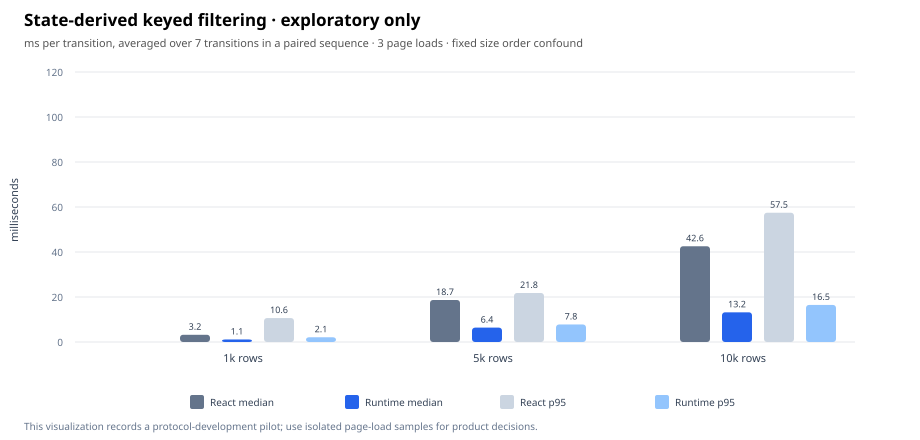

In [36]:
const keyedFilterSvgW: string[] = ['<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="440" viewBox="0 0 920 440" role="img" aria-labelledby="keyed-filter-title keyed-filter-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">'];
keyedFilterSvgW.push('<title id="keyed-filter-title">Exploratory keyed-filter update latency by list size</title><desc id="keyed-filter-desc">Median-of-page medians and median page p95 sequence means for React and retained VDOM at one, five, and ten thousand rows. The three sizes share page loads in fixed ascending order, so the chart is exploratory and not an independent scale comparison.</desc><rect width="100%" height="100%" fill="white"/><text x="24" y="26" font-size="17" font-weight="700">State-derived keyed filtering · exploratory only</text><text x="24" y="47" font-size="11" fill="#555">ms per transition, averaged over 7 transitions in a paired sequence · 3 page loads · fixed size order confound</text>');
const kfPlot = { x: 75, y: 72, width: 780, height: 270 };
const kfMax = 120;
const kfScale = kfPlot.height / kfMax;
for (let tick = 0; tick <= kfMax; tick += 20) {
  const y = kfPlot.y + kfPlot.height - tick * kfScale;
  keyedFilterSvgW.push(`<line x1="${kfPlot.x}" y1="${y}" x2="${kfPlot.x + kfPlot.width}" y2="${y}" stroke="#e5e7eb"/><text x="${kfPlot.x - 12}" y="${y + 4}" text-anchor="end" font-size="10" fill="#64748b">${tick}</text>`);
}
const kfColors = { reactMedian: "#64748b", runtimeMedian: "#2563eb", reactP95: "#cbd5e1", runtimeP95: "#93c5fd" };
for (let index = 0; index < keyedFilterRowsW.length; index++) {
  const row = keyedFilterRowsW[index];
  const groupX = kfPlot.x + 105 + index * 250;
  const vals = [row.medianOfPageMediansMs.react, row.medianOfPageMediansMs.runtime, row.medianOfPageP95Ms.react, row.medianOfPageP95Ms.runtime];
  const colors = [kfColors.reactMedian, kfColors.runtimeMedian, kfColors.reactP95, kfColors.runtimeP95];
  for (let bar = 0; bar < vals.length; bar++) {
    const height = vals[bar] * kfScale;
    const x = groupX + bar * 42;
    const y = kfPlot.y + kfPlot.height - height;
    keyedFilterSvgW.push(`<rect x="${x}" y="${y}" width="30" height="${height}" rx="3" fill="${colors[bar]}"/><text x="${x + 15}" y="${Math.max(kfPlot.y + 10, y - 5)}" text-anchor="middle" font-size="9" fill="#334155">${vals[bar].toFixed(1)}</text>`);
  }
  keyedFilterSvgW.push(`<text x="${groupX + 63}" y="${kfPlot.y + kfPlot.height + 20}" text-anchor="middle" font-size="11" fill="#334155">${(row.entityCount / 1000).toFixed(0)}k rows</text>`);
}
keyedFilterSvgW.push(`<text x="18" y="210" transform="rotate(-90 18 210)" text-anchor="middle" font-size="11" fill="#334155">milliseconds</text>`);
const kfLegend = [["React median", kfColors.reactMedian], ["Runtime median", kfColors.runtimeMedian], ["React p95", kfColors.reactP95], ["Runtime p95", kfColors.runtimeP95]] as const;
for (let index = 0; index < kfLegend.length; index++) { const [label, color] = kfLegend[index]; const x = 190 + index * 155; keyedFilterSvgW.push(`<rect x="${x}" y="395" width="14" height="14" rx="2" fill="${color}"/><text x="${x + 20}" y="406" font-size="10" fill="#334155">${label}</text>`); }
keyedFilterSvgW.push('<text x="24" y="430" font-size="10" fill="#64748b">This visualization records a protocol-development pilot; use isolated page-load samples for product decisions.</text></svg>');
Deno.jupyter.svg`${keyedFilterSvgW.join("")}`;


## Engineering gate Y — compiler-selected keyed-region work

A one-region graph can validate wiring but cannot prove that the DAG avoids unrelated work. The compiler fixture now has two independently filtered keyed sections. OXC emits `queryA → region 0`, `queryB → region 1`, and shared `rows → regions 0 and 1`; both repeated lists use `row.id` keys.

The JavaScript dispatcher consumes this CSR graph. Runtime tests compare query-only and shared-row partial commits against a fresh full-tree VDOM derivation and verify the untouched region retains its host object. The browser page now compares memoized React child regions, whole-tree VDOM derivation, and compiled region dispatch. It uses the same data and updates one query source at a time.

This is correctness evidence, not a speed result. No browser timing has been collected for the multi-region version. The decision gate is whether skipping the unaffected region yields repeatable update savings after graph setup, and how that compares with React Compiler’s memoized region components.

{
  "sources": [
    "queryA",
    "queryB",
    "rows"
  ],
  "offsets": [
    0,
    1,
    2,
    4
  ],
  "regionIds": [
    0,
    1,
    0,
    1
  ],
  "regions": [
    {
      "id": 0,
      "key": "row.id",
      "binding": "groupRows"
    },
    {
      "id": 1,
      "key": "row.id",
      "binding": "scoreRows"
    }
  ]
}


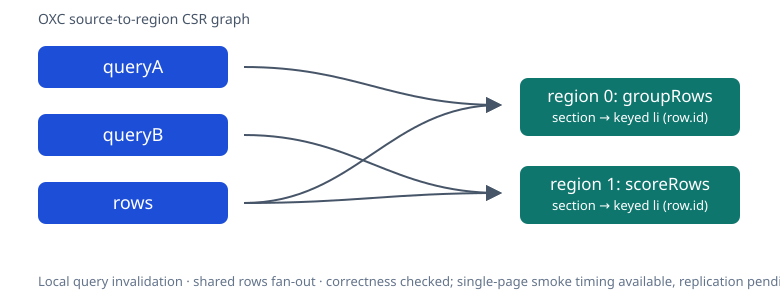

In [37]:
const keyedRegionsPlanY = JSON.parse(await Deno.readTextFile("results/compiler-keyed-filter-regions.json"));
const keyedGraphY = keyedRegionsPlanY.dependency_graph;
const regionY = keyedRegionsPlanY.regions;
const sourceBoxesY = keyedGraphY.source_paths.map((name: string, slot: number) => {
  const y = 46 + slot * 68;
  return `<rect x="38" y="${y}" width="190" height="42" rx="8" fill="#1d4ed8"/><text x="133" y="${y + 27}" text-anchor="middle" fill="white" font-family="sans-serif" font-size="18">${name}</text>`;
}).join("");
const edgePathsY = keyedGraphY.source_paths.flatMap((_: string, sourceSlot: number) => {
  const start = keyedGraphY.source_region_offsets[sourceSlot];
  const end = keyedGraphY.source_region_offsets[sourceSlot + 1];
  return keyedGraphY.region_ids.slice(start, end).map((regionId: number) => {
    const sourceY = 67 + sourceSlot * 68;
    const targetY = 105 + regionId * 88;
    return `<path d="M 244 ${sourceY} C 355 ${sourceY}, 390 ${targetY}, 500 ${targetY}" fill="none" stroke="#475569" stroke-width="2" marker-end="url(#arrow-y)"/>`;
  });
}).join("");
const regionBoxesY = regionY.map((region: any) => {
  const y = 78 + region.region_id * 88;
  return `<rect x="520" y="${y}" width="220" height="58" rx="8" fill="#0f766e"/><text x="630" y="${y + 24}" text-anchor="middle" fill="white" font-family="sans-serif" font-size="17">region ${region.region_id}: ${region.collection_binding}</text><text x="630" y="${y + 44}" text-anchor="middle" fill="white" font-family="sans-serif" font-size="13">${region.root_tag} → keyed ${region.item_tag} (${region.item_key_path})</text>`;
}).join("");
const keyedRegionsSvgY = `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="300" viewBox="0 0 780 300" role="img" aria-labelledby="regions-title"><title id="regions-title">Two query sources route to separate keyed regions while rows fans out to both</title><defs><marker id="arrow-y" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#475569"/></marker></defs><text x="38" y="24" font-family="sans-serif" font-size="14" fill="#475569">OXC source-to-region CSR graph</text>${sourceBoxesY}${edgePathsY}${regionBoxesY}<text x="38" y="286" font-family="sans-serif" font-size="13" fill="#64748b">Local query invalidation · shared rows fan-out · correctness checked; single-page smoke timing available, replication pending</text></svg>`;
console.log(JSON.stringify({ sources: keyedGraphY.source_paths, offsets: keyedGraphY.source_region_offsets, regionIds: keyedGraphY.region_ids, regions: regionY.map((region: any) => ({ id: region.region_id, key: region.item_key_path, binding: region.collection_binding })) }, null, 2));
Deno.jupyter.svg`${keyedRegionsSvgY}`;

## Experiment Z — two-region Gate A scale smoke (exploratory)

This is a pipeline and scale smoke test for the new two-region fixture, not the preregistered Gate A result. It uses one Chrome page load at each size (1k, 5k, 10k), from one browser profile, with 24 timed pairs per load and six warmup pairs. Every pair checks all eight intermediate states; the run also verifies that retained keyed DOM nodes are preserved. The replication unit remains the page load, so the 24 pairs within each page do not provide 24 independent samples.

The comparison separates three mechanisms: memoized React region components, retained VDOM recomputing both regions, and retained VDOM with OXC graph dispatch recomputing only the affected region. The timed interval excludes mounting, paint/presentation, and build-time compilation. Treat differences as exploratory until the full balanced page-load schedule is collected in independent browser sessions.


rows | React median/p95 | whole-tree VDOM median/p95 | graph VDOM median/p95 | mount React/whole/graph


1000 | 2.42/2.99 | 0.71/1.04 | 0.54/0.65 | 14.7/5.3/2.7 ms


5000 | 12.58/19.30 | 3.75/4.35 | 2.67/3.04 | 85.8/20.8/15.1 ms


10000 | 28.39/39.48 | 8.14/9.01 | 6.01/6.92 | 164.6/27.9/33.6 ms


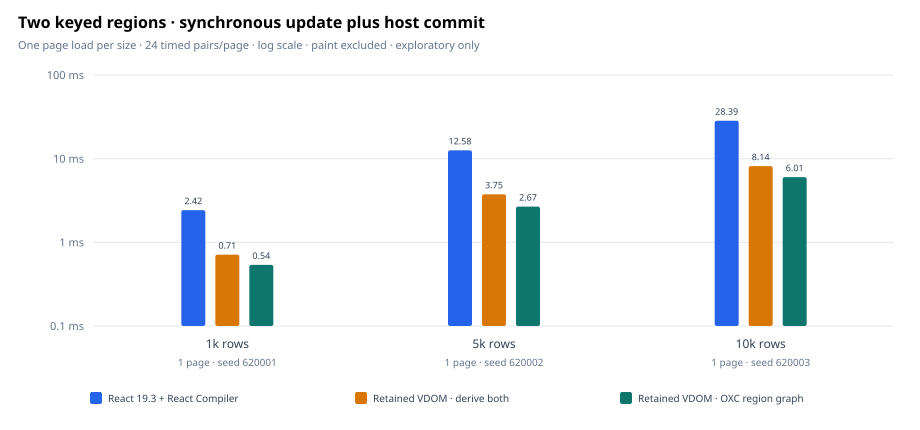

In [38]:
const keyedRegionSmokeZ = JSON.parse(await Deno.readTextFile("results/browser-keyed-regions-exploratory-smoke-v1.json"));
const smokeSizesZ = [1000, 5000, 10000];
const smokeRowsZ = smokeSizesZ.map((entityCount) => {
  const matching = keyedRegionSmokeZ.filter((record: any) => record.entityCount === entityCount);
  if (matching.length !== 1) throw new Error(`Expected one exploratory page load at ${entityCount} rows, found ${matching.length}`);
  const record = matching[0];
  if (!record.outputParity || !record.finalParity || record.pairs.some((pair: any) => !pair.sameOutput)) {
    throw new Error(`Parity check failed at ${entityCount} rows`);
  }
  return {
    entityCount,
    reactMedian: record.summaries.react.medianMs,
    wholeTreeMedian: record.summaries.handwritten.medianMs,
    graphMedian: record.summaries.compiled.medianMs,
    reactP95: record.summaries.react.p95Ms,
    wholeTreeP95: record.summaries.handwritten.p95Ms,
    graphP95: record.summaries.compiled.p95Ms,
    mountMs: record.mountMs,
    pairs: record.timedPairs,
    pageLoadId: record.pageLoadId,
    seed: record.seed,
    browser: record.browser,
  };
});
console.log("rows | React median/p95 | whole-tree VDOM median/p95 | graph VDOM median/p95 | mount React/whole/graph");
for (const row of smokeRowsZ) console.log(`${row.entityCount} | ${row.reactMedian.toFixed(2)}/${row.reactP95.toFixed(2)} | ${row.wholeTreeMedian.toFixed(2)}/${row.wholeTreeP95.toFixed(2)} | ${row.graphMedian.toFixed(2)}/${row.graphP95.toFixed(2)} | ${row.mountMs.react.toFixed(1)}/${row.mountMs.handwritten.toFixed(1)}/${row.mountMs.compiled.toFixed(1)} ms`);

const plotZ = { left: 94, right: 894, top: 75, bottom: 326 };
const logMinZ = Math.log10(0.1), logMaxZ = Math.log10(100);
const yZ = (value: number) => plotZ.bottom - (Math.log10(value) - logMinZ) / (logMaxZ - logMinZ) * (plotZ.bottom - plotZ.top);
const colorsZ = ["#2563eb", "#d97706", "#0f766e"];
const labelsZ = ["React 19.3 + React Compiler", "Retained VDOM · derive both", "Retained VDOM · OXC region graph"];
const smokeSvgZ: string[] = [`<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="430" viewBox="0 0 920 430" role="img" aria-labelledby="gate-a-smoke-title gate-a-smoke-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif"><title id="gate-a-smoke-title">Exploratory two-region keyed-list update timings</title><desc id="gate-a-smoke-desc">Median synchronous update and host commit times on one Chrome page load at each of 1,000, 5,000, and 10,000 rows. Three arms compare React, whole-tree retained VDOM derivation, and OXC graph-selected region derivation. Page paint is excluded and replication is one page per size.</desc><rect width="100%" height="100%" fill="white"/><text x="18" y="28" font-size="16" font-weight="700">Two keyed regions · synchronous update plus host commit</text><text x="18" y="49" font-size="11" fill="#64748b">One page load per size · 24 timed pairs/page · log scale · paint excluded · exploratory only</text>`];
for (const tick of [0.1, 1, 10, 100]) {
  const y = yZ(tick);
  smokeSvgZ.push(`<line x1="${plotZ.left}" y1="${y}" x2="${plotZ.right}" y2="${y}" stroke="#e5e7eb"/><text x="${plotZ.left - 10}" y="${y + 4}" text-anchor="end" font-size="11" fill="#64748b">${tick} ms</text>`);
}
const groupWidthZ = (plotZ.right - plotZ.left) / smokeRowsZ.length;
smokeRowsZ.forEach((row, index) => {
  const center = plotZ.left + groupWidthZ * (index + 0.5);
  const values = [row.reactMedian, row.wholeTreeMedian, row.graphMedian];
  values.forEach((value, arm) => {
    const x = center + (arm - 1) * 34 - 12;
    const yy = yZ(value);
    smokeSvgZ.push(`<rect x="${x}" y="${yy}" width="24" height="${plotZ.bottom - yy}" rx="2" fill="${colorsZ[arm]}"/><text x="${x + 12}" y="${yy - 6}" text-anchor="middle" font-size="9" fill="#334155">${value.toFixed(2)}</text>`);
  });
  smokeSvgZ.push(`<text x="${center}" y="348" text-anchor="middle" font-size="12" fill="#334155">${(row.entityCount / 1000).toFixed(0)}k rows</text><text x="${center}" y="366" text-anchor="middle" font-size="10" fill="#64748b">1 page · seed ${row.seed}</text>`);
});
labelsZ.forEach((label, index) => {
  const x = 90 + index * 265;
  smokeSvgZ.push(`<rect x="${x}" y="392" width="12" height="12" rx="2" fill="${colorsZ[index]}"/><text x="${x + 18}" y="402" font-size="10" fill="#334155">${label}</text>`);
});
smokeSvgZ.push(`</svg>`);
Deno.jupyter.svg`${smokeSvgZ.join("")}`;


## Gate A — balanced two-region browser replication and same-surface repeat

The preregistered 18 page loads compare Chrome 155 and Chrome 154 in-app. A supplemental nine-page collection repeated Chrome 155 measurements in the same browser profile: three pages per size. Page load is the replication unit; the 24 paired sequences inside a page are repeated observations. All 27 pages passed output and keyed-identity checks. The chart plots median-of-page medians and spans each collection’s three page medians. The repeated Chrome result is close to the original; the cross-surface React difference remains unresolved and should not be treated as a framework win.

One 5k in-app-browser page (seed 610018) has a React page-level p95 of 1,301.8 ms beside a 6.2 ms median. It stays in the data because there was no preregistered exclusion rule; the cause is unknown. Read the per-page tail records directly, since the median chart is not tail-latency evidence.


Session | rows | median / median page p95 / max page p95 (ms): React · whole-tree · graph | mount React/whole/graph


gate-a-session-1 | 1000 | 2.72/3.15/4.05 | 0.71/1.11/1.35 | 0.51/0.81/0.91 | 19.1/6.2/3.0 ms


gate-a-session-1 | 5000 | 14.26/16.36/17.95 | 4.51/5.14/5.46 | 3.19/3.80/3.80 | 58.8/18.6/12.4 ms


gate-a-session-1 | 10000 | 31.03/36.44/78.41 | 9.79/10.70/11.47 | 6.66/8.03/8.83 | 191.8/38.0/33.8 ms


gate-a-chrome-repeat | 1000 | 2.76/3.26/3.51 | 0.75/1.11/1.26 | 0.54/0.66/1.01 | 29.0/5.9/3.2 ms


gate-a-chrome-repeat | 5000 | 14.15/17.01/17.52 | 4.46/4.96/5.30 | 3.23/3.71/3.85 | 55.7/19.6/15.0 ms


gate-a-chrome-repeat | 10000 | 30.16/39.05/49.84 | 9.62/10.82/11.49 | 6.85/8.40/8.50 | 100.2/34.4/35.5 ms


gate-a-session-2 | 1000 | 0.65/0.83/1.21 | 0.76/1.00/1.21 | 0.61/0.77/1.16 | 5.0/4.6/2.5 ms


gate-a-session-2 | 5000 | 3.77/4.35/1301.78 | 4.79/6.50/11.91 | 3.69/4.51/19.60 | 10.9/28.3/10.5 ms


gate-a-session-2 | 10000 | 7.40/11.14/23.14 | 10.25/11.67/13.13 | 7.75/12.47/12.83 | 21.9/30.5/31.6 ms


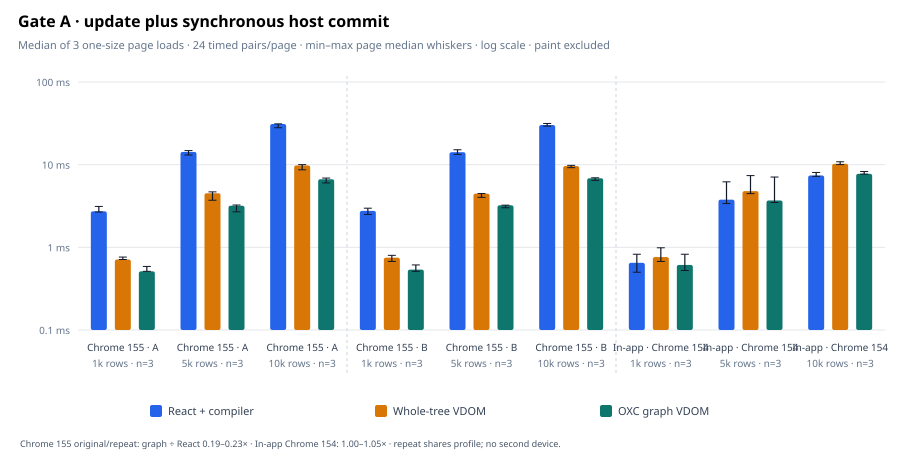

In [39]:
const gateASummary = JSON.parse(await Deno.readTextFile("results/browser-keyed-regions-gate-a-summary-v1.json"));
const gateASessions = [...new Set(gateASummary.summary.map((row: any) => row.sessionId))];
const gateARepeatIds = gateASummary.matchedBrowserRepeat.collectionIds;
const gateASizes = [1000, 5000, 10000];
const gateAArms = ["react", "handwritten", "compiled"];
const gateALabels = ["React + compiler", "Whole-tree VDOM", "OXC graph VDOM"];
const gateAColors = ["#2563eb", "#d97706", "#0f766e"];
if (gateASummary.pageLoadCount !== 27 || gateASummary.timedPairsPerPage !== 24 || !gateASummary.matchedBrowserRepeat.sameUserAgentAcrossCollections) throw new Error("Unexpected Gate A record count");
for (const row of gateASummary.summary) {
  if (row.pageLoads.length !== 3) throw new Error(`Expected three page loads for ${row.sessionId}/${row.entityCount}`);
}
console.log("Session | rows | median / median page p95 / max page p95 (ms): React · whole-tree · graph | mount React/whole/graph");
for (const row of gateASummary.summary) {
  const a = row.arms;
  console.log(`${row.sessionId} | ${row.entityCount} | ${a.react.medianOfPageMediansMs.toFixed(2)}/${a.react.medianOfPageP95Ms.toFixed(2)}/${a.react.pageP95RangeMs[1].toFixed(2)} | ${a.handwritten.medianOfPageMediansMs.toFixed(2)}/${a.handwritten.medianOfPageP95Ms.toFixed(2)}/${a.handwritten.pageP95RangeMs[1].toFixed(2)} | ${a.compiled.medianOfPageMediansMs.toFixed(2)}/${a.compiled.medianOfPageP95Ms.toFixed(2)}/${a.compiled.pageP95RangeMs[1].toFixed(2)} | ${a.react.medianMountMs.toFixed(1)}/${a.handwritten.medianMountMs.toFixed(1)}/${a.compiled.medianMountMs.toFixed(1)} ms`);
}
const gateAPlot = { left: 78, right: 885, top: 82, bottom: 330 };
const gateAValueY = (value: number) => gateAPlot.bottom - (Math.log10(value) - Math.log10(0.1)) / 3 * (gateAPlot.bottom - gateAPlot.top);
const gateASvg: string[] = [`<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="470" viewBox="0 0 920 470" role="img" aria-labelledby="gate-a-final-title gate-a-final-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif"><title id="gate-a-final-title">Gate A results by collection block</title><desc id="gate-a-final-desc">Log-scale bars show median of three page-load medians for React, whole-tree VDOM and OXC graph VDOM at 1k, 5k and 10k rows in two Chrome 155 collection blocks and one Chrome 154 in-app block. Whiskers span page medians. The Chrome repeat shares the original profile; React timings differ in the in-app surface.</desc><rect width="100%" height="100%" fill="white"/><text x="18" y="27" font-size="16" font-weight="700">Gate A · update plus synchronous host commit</text><text x="18" y="49" font-size="11" fill="#64748b">Median of 3 one-size page loads · 24 timed pairs/page · min–max page median whiskers · log scale · paint excluded</text>`];
for (const tick of [0.1, 1, 10, 100]) {
  const y = gateAValueY(tick);
  gateASvg.push(`<line x1="${gateAPlot.left}" y1="${y}" x2="${gateAPlot.right}" y2="${y}" stroke="#e5e7eb"/><text x="${gateAPlot.left - 8}" y="${y + 4}" text-anchor="end" font-size="10" fill="#64748b">${tick} ms</text>`);
}
const gateAGroupWidth = (gateAPlot.right - gateAPlot.left) / gateASummary.summary.length;
let gateAGroupIndex = 0;
for (const sessionId of gateASessions) {
  for (const size of gateASizes) {
    const row = gateASummary.summary.find((item: any) => item.sessionId === sessionId && item.entityCount === size);
    const center = gateAPlot.left + gateAGroupWidth * (gateAGroupIndex + 0.5);
    gateAArms.forEach((arm, armIndex) => {
      const stats = row.arms[arm];
      const value = stats.medianOfPageMediansMs;
      const [low, high] = stats.pageMedianRangeMs;
      const x = center + (armIndex - 1) * 24 - 8;
      const y = gateAValueY(value);
      gateASvg.push(`<rect x="${x}" y="${y}" width="16" height="${gateAPlot.bottom - y}" rx="2" fill="${gateAColors[armIndex]}"/><line x1="${x + 8}" y1="${gateAValueY(high)}" x2="${x + 8}" y2="${gateAValueY(low)}" stroke="#111827" stroke-width="1.2"/><line x1="${x + 4}" y1="${gateAValueY(high)}" x2="${x + 12}" y2="${gateAValueY(high)}" stroke="#111827"/><line x1="${x + 4}" y1="${gateAValueY(low)}" x2="${x + 12}" y2="${gateAValueY(low)}" stroke="#111827"/>`);
    });
    const sessionLabel = sessionId === gateARepeatIds[0] ? "Chrome 155 · A" : sessionId === gateARepeatIds[1] ? "Chrome 155 · B" : "In-app · Chrome 154";
    gateASvg.push(`<text x="${center}" y="351" text-anchor="middle" font-size="10" fill="#334155">${sessionLabel}</text><text x="${center}" y="367" text-anchor="middle" font-size="10" fill="#64748b">${size / 1000}k rows · n=3</text>`);
    gateAGroupIndex++;
    if (gateAGroupIndex === 3 || gateAGroupIndex === 6) {
      const separatorX = gateAPlot.left + gateAGroupWidth * gateAGroupIndex;
      gateASvg.push(`<line x1="${separatorX}" y1="${gateAPlot.top - 6}" x2="${separatorX}" y2="${gateAPlot.bottom + 44}" stroke="#cbd5e1" stroke-dasharray="3 3"/>`);
    }
  }
}
gateAArms.forEach((_, index) => {
  const x = 150 + index * 225;
  gateASvg.push(`<rect x="${x}" y="405" width="12" height="12" rx="2" fill="${gateAColors[index]}"/><text x="${x + 18}" y="415" font-size="11" fill="#334155">${gateALabels[index]}</text>`);
});
gateASvg.push(`<text x="20" y="447" font-size="9" fill="#475569">Chrome 155 original/repeat: graph ÷ React 0.19–0.23× · In-app Chrome 154: 1.00–1.05× · repeat shares profile; no second device.</text></svg>`);
Deno.jupyter.svg`${gateASvg.join("")}`;


## Gate B — React keyed-structure differential

This deterministic browser fixture is a correctness check, not a performance study. It compares React DOM 19.3.0 and the retained VDOM through mount, prop update, keyed reorder/removal/reinsertion, then replays a seeded 128-operation structural trace. The saved JSON records browser metadata, the generator seed, per-phase output, and aggregate identity checks.

In [40]:
const keyedStructuralRecord = JSON.parse(await Deno.readTextFile("results/browser-keyed-structural-differential-v1.json"));
const keyedTrace = keyedStructuralRecord.structuralTrace;
if (keyedStructuralRecord.status !== "PASS" || keyedStructuralRecord.phases.length !== 4 || keyedStructuralRecord.phases.some((phase: any) => !phase.domParity)) throw new Error("Keyed structural differential record failed validation");
if (!keyedStructuralRecord.reinsertedKeyIdentity.reactFresh || !keyedStructuralRecord.reinsertedKeyIdentity.vdomFresh) throw new Error("Reinserted key did not receive fresh host identity in both renderers");
if (keyedTrace.steps !== 128 || !keyedTrace.allParity || !keyedTrace.allIdentity || keyedTrace.rowCountRange.min !== 0 || keyedTrace.rowCountRange.max !== 12) throw new Error("Seeded structural trace failed validation");
console.log(`React ${keyedStructuralRecord.reactBaseline.react}/${keyedStructuralRecord.reactBaseline.reactDom} · ${keyedStructuralRecord.browser.userAgent}`);
console.log(`Collected ${keyedStructuralRecord.collectedAt}; 4/4 scripted phases and ${keyedTrace.steps}/128 seeded structural steps passed DOM and keyed-identity checks.`);
console.log(`Seed ${keyedTrace.seed} · ${JSON.stringify(keyedTrace.operationCounts)} · rows ${keyedTrace.rowCountRange.min}–${keyedTrace.rowCountRange.max}.`);
console.log("No timing, component-state, lifecycle, or event-performance claim is drawn from this fixture.");

React 19.3.0/19.3.0 · Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/155.0.0.0 Safari/537.36


Collected 2026-10-10T00:17:27.535Z; 4/4 scripted phases and 128/128 seeded structural steps passed DOM and keyed-identity checks.


Seed 1592594996 · {"insert":45,"update":27,"reorder":18,"remove":38} · rows 0–12.


No timing, component-state, lifecycle, or event-performance claim is drawn from this fixture.


### Native event to source update

The browser fixture dispatches the same three clicks through React external-store state and the retained VDOM native-event/source-binding path. It checks declared host output after each click and does not time the interaction.

In [41]:
const eventSourceRecord = JSON.parse(await Deno.readTextFile("results/browser-event-source-differential-v1.json"));
if (eventSourceRecord.status !== "PASS" || eventSourceRecord.phases.length !== 3 || eventSourceRecord.phases.some((phase: any, index: number) => !phase.parity || phase.reactCount !== String(index + 1) || phase.vdomCount !== String(index + 1))) throw new Error("Event/source differential record failed validation");
if (!eventSourceRecord.removedButtonListenerCleanup) throw new Error("Removed event listener cleanup assertion did not pass");
console.log(`React ${eventSourceRecord.reactBaseline.react}/${eventSourceRecord.reactBaseline.reactDom} · ${eventSourceRecord.browser.userAgent}`);
console.log(`All ${eventSourceRecord.phases.length} native click updates matched; detached button click was inert; timing: ${eventSourceRecord.timing}.`);
console.log(`React path: ${eventSourceRecord.reactPath}`);
console.log(`VDOM path: ${eventSourceRecord.vdomPath}`);

React 19.3.0/19.3.0 · Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/155.0.0.0 Safari/537.36


All 3 native click updates matched; detached button click was inert; timing: not measured.


React path: click handler → external store notification → useSyncExternalStore → React render and commit


VDOM path: native click listener → ScalarSource → retained source-to-prop/style index → host writes


### Owner-addressed state substrate

This small deterministic notebook check exercises the current `OwnerStateWorld` prototype. It verifies that a conditionally skipped state site does not shift a neighboring site, keyed owners survive reorder, and removal followed by reinsertion creates a fresh owner and state. This validates the storage primitive only; it does not exercise JSX/compiler integration, browser rendering, lifecycle effects, or performance.


In [42]:
import { OwnerStateWorld } from "./src/owner_state_world.ts";

const world = new OwnerStateWorld();
const rootOwner = world.resolveOwner(null, "app-root");
const panelOwner = world.resolveOwner(rootOwner, "panel-site");
let conditionalValue: number | undefined;
const renderPanel = (showConditional: boolean) => {
  if (showConditional) {
    const [value, setValue] = world.useState(panelOwner, "panel.conditional", 0);
    conditionalValue = value;
    if (value === 0) setValue(7);
  }
  return world.useState(panelOwner, "panel.trailing", "stable")[0];
};

const hiddenFirst = renderPanel(false);
const visibleFirst = renderPanel(true);
const hiddenAgain = renderPanel(false);
const visibleAgain = renderPanel(true);
if (hiddenFirst !== "stable" || visibleFirst !== "stable" || hiddenAgain !== "stable" ||
  visibleAgain !== "stable" || conditionalValue !== 7) {
  throw new Error("Conditional owner/site state shifted or failed to resume");
}

const rowA = world.resolveOwner(rootOwner, "row-site", "a");
const rowB = world.resolveOwner(rootOwner, "row-site", "b");
world.useState(rowA, "row.selected", false)[1](true);
world.useState(rowB, "row.selected", false)[1](true);
const reordered = ["b", "a"].map((key) => world.resolveOwner(rootOwner, "row-site", key));
if (reordered[0] !== rowB || reordered[1] !== rowA) throw new Error("Keyed owner identity changed during reorder");
world.destroyOwner(rowB);
const freshB = world.resolveOwner(rootOwner, "row-site", "b");
const freshBState = world.useState(freshB, "row.selected", false)[0];
if (freshB === rowB || freshBState !== false) throw new Error("Removed keyed owner state was reused");

const ownerStateRecord = {
  schemaVersion: "owner-state-world-substrate-v1",
  status: "PASS",
  checks: {
    conditionalSiteDoesNotShift: true,
    skippedStateResumes: conditionalValue === 7,
    trailingSiteStable: true,
    keyedOwnerIdentitySurvivesReorder: true,
    destroyedKeyGetsFreshOwner: freshB !== rowB,
    destroyedKeyGetsInitialState: freshBState === false,
  },
  ownerIds: { rootOwner, panelOwner, rowA, rowB, freshB },
  scope: "standalone storage primitive; no JSX, compiler, renderer, browser timing, or performance claim",
};
await Deno.writeTextFile("results/owner-state-world-substrate-v1.json", JSON.stringify(ownerStateRecord, null, 2) + "\n");
console.log("Owner/site state substrate checks:", JSON.stringify(ownerStateRecord.checks));
console.log(ownerStateRecord.scope);


Owner/site state substrate checks: {"conditionalSiteDoesNotShift":true,"skippedStateResumes":true,"trailingSiteStable":true,"keyedOwnerIdentitySurvivesReorder":true,"destroyedKeyGetsFreshOwner":true,"destroyedKeyGetsInitialState":true}


standalone storage primitive; no JSX, compiler, renderer, browser timing, or performance claim


### VDOM-backed component state execution

This deterministic check runs function components through `ComponentStateRoot` and commits their output through the retained in-memory VDOM host. It covers conditional state-site skip/resume and keyed state/host identity across reorder, removal, and reinsertion. The IDs come from the checked-in OXC-generated plan and are wired manually into the runtime calls; source rewriting and browser timing are not part of this result. State updates now reuse clean component-function results, while this notebook check remains a correctness check rather than a timing claim.


In [43]:
import { ComponentStateRoot } from "./src/component_state_runtime.ts";
import { componentStateSitesPlan } from "./src/browser/generated_component_state_sites.ts";
import { ConditionalPanel, Counter, KeyedRow } from "./src/browser/generated_component_state_transform.tsx";
import { jsx } from "./src/jsx_binding_runtime.ts";
import { MemoryVDOMHost, type MemoryNode } from "./src/vdom_snapshot_runtime.ts";

const textContent = (node: MemoryNode): string => (node.text ?? "") + node.children.map(textContent).join("");
const panelSites = componentStateSitesPlan.components.find((component) => component.name === "ConditionalPanel");
if (!panelSites || panelSites.state_sites.length !== 2) throw new Error("Missing compiled ConditionalPanel sites");
const panelHost = new MemoryVDOMHost();
const panelContainer = panelHost.createContainer();
const panelRoot = new ComponentStateRoot(panelHost, panelContainer);
const panelTree = (show: boolean) => jsx(ConditionalPanel, { show });
panelRoot.mount(panelTree(false));
const conditionalSiteDidNotShift = textContent(panelContainer.children[0]) === "hidden:tail";
panelRoot.update(panelTree(true));
const initialConditionalValue = textContent(panelContainer.children[0]);
const panelButton = panelContainer.children[0].children.find((node) => node.props["data-action"] === "increment");
if (!panelButton) throw new Error("Compiled ConditionalPanel did not emit its increment button");
for (let i = 0; i < 7; i++) (panelButton.props.onClick as () => void)();
await new Promise<void>((resolve) => queueMicrotask(resolve));
const updatedConditionalValue = textContent(panelContainer.children[0]);
panelRoot.update(panelTree(false));
panelRoot.update(panelTree(true));
const resumedConditionalValue = textContent(panelContainer.children[0]);

const rowSites = componentStateSitesPlan.components.find((component) => component.name === "KeyedRow");
if (!rowSites || rowSites.state_sites.length !== 1) throw new Error("Missing compiled KeyedRow site");
const rowHost = new MemoryVDOMHost();
const rowContainer = rowHost.createContainer();
const rowRoot = new ComponentStateRoot(rowHost, rowContainer);
const rowTree = (ids: string[]) => jsx("ul", {}, ids.map((id) => jsx(KeyedRow, { key: id, id })));
rowRoot.mount(rowTree(["a", "b", "c"]));
const rowList = rowContainer.children[0];
const originalRows = new Map(rowList.children.map((node) => [String(node.props["data-id"]), node]));
(rowList.children[1].props.onClick as () => void)();
await new Promise<void>((resolve) => queueMicrotask(resolve));
rowRoot.update(rowTree(["c", "a", "b"]));
const keyedStateAndIdentitySurviveReorder = rowList.children[0] === originalRows.get("c") &&
  rowList.children[1] === originalRows.get("a") && rowList.children[2] === originalRows.get("b") &&
  rowList.children[2].props["data-selected"] === "true";
const removedRow = rowList.children[2];
rowRoot.update(rowTree(["c", "a"]));
rowRoot.update(rowTree(["b", "c", "a"]));
const reinsertedOwnerResets = rowList.children[0] !== removedRow && rowList.children[0].props["data-selected"] === "false";

const counterHost = new MemoryVDOMHost();
const counterContainer = counterHost.createContainer();
const counterRoot = new ComponentStateRoot(counterHost, counterContainer);
counterRoot.mount(jsx(Counter, {}));
const counterClick = counterContainer.children[0].props.onClick as () => void;
counterClick();
counterClick();
counterClick();
await new Promise<void>((resolve) => queueMicrotask(resolve));
const scheduledWritesCoalesce = counterRoot.version === 2 &&
  counterContainer.children[0].props["data-count"] === 3 && textContent(counterContainer.children[0]) === "3";

const componentStateRecord = {
  schemaVersion: "component-state-runtime-v1",
  compilerPlanSource: componentStateSitesPlan.source_file,
  status: "PASS",
  checks: {
    conditionalSiteDidNotShift,
    conditionalValueStartsAtZero: initialConditionalValue === "0:tail+",
    conditionalUpdatesThroughNativeHandler: updatedConditionalValue === "7:tail+",
    skippedConditionalSiteResumes: resumedConditionalValue === "7:tail+",
    keyedStateAndIdentitySurviveReorder,
    reinsertedOwnerResets,
    scheduledWritesCoalesce,
  },
  scope: "OXC-generated TSX transform with lexical state-site IDs; in-memory VDOM host; owner cache skips clean component functions; VDOM normalization and reconciliation still traverse the full tree; no browser timing or React performance claim",
};
if (Object.values(componentStateRecord.checks).some((value) => !value)) throw new Error("Component-state runtime check failed");
await Deno.writeTextFile("results/component-state-runtime-v1.json", JSON.stringify(componentStateRecord, null, 2) + "\n");
console.log("Component-state VDOM checks:", JSON.stringify(componentStateRecord.checks));
console.log(componentStateRecord.scope);
panelRoot.dispose();
rowRoot.dispose();
counterRoot.dispose();

Component-state VDOM checks: {"conditionalSiteDidNotShift":true,"conditionalValueStartsAtZero":true,"conditionalUpdatesThroughNativeHandler":true,"skippedConditionalSiteResumes":true,"keyedStateAndIdentitySurviveReorder":true,"reinsertedOwnerResets":true,"scheduledWritesCoalesce":true}


OXC-generated TSX transform with lexical state-site IDs; in-memory VDOM host; owner cache skips clean component functions; VDOM normalization and reconciliation still traverse the full tree; no browser timing or React performance claim


In [44]:
import { ComponentStateRoot } from "./src/component_state_runtime.ts";
import { EffectProbe } from "./src/browser/generated_component_state_transform.tsx";
import { jsx } from "./src/jsx_binding_runtime.ts";
import { MemoryVDOMHost } from "./src/vdom_snapshot_runtime.ts";

const lifecycleEvents = [];
const lifecycleTree = (active, label, fail = false) => jsx(EffectProbe, {
  active,
  label,
  fail,
  onSetup: (value) => lifecycleEvents.push(`setup:${value}`),
  onCleanup: (value) => lifecycleEvents.push(`cleanup:${value}`),
});
const lifecycleHost = new MemoryVDOMHost();
const lifecycleContainer = lifecycleHost.createContainer();
const lifecycleRoot = new ComponentStateRoot(lifecycleHost, lifecycleContainer);
lifecycleRoot.mount(lifecycleTree(true, "first"));
lifecycleRoot.update(lifecycleTree(true, "changed"));
(lifecycleContainer.children[0].props.onClick)();
await new Promise((resolve) => queueMicrotask(resolve));
const effectStayedMountedAcrossUpdates = JSON.stringify(lifecycleEvents) === JSON.stringify(["setup:first"]);
try {
  lifecycleRoot.update(lifecycleTree(true, "failed", true));
  throw new Error("Expected a failed candidate");
} catch (error) {
  if (!(error instanceof Error) || error.message !== "effect candidate failed") throw error;
}
const failedCandidatePreservedEffects = JSON.stringify(lifecycleEvents) === JSON.stringify(["setup:first"]);
lifecycleRoot.update(lifecycleTree(false, "changed"));
lifecycleRoot.update(lifecycleTree(true, "second"));
const inactiveSiteCleansAndReactivates = JSON.stringify(lifecycleEvents) === JSON.stringify([
  "setup:first", "cleanup:first", "setup:second",
]);
lifecycleRoot.dispose();
const rootDisposeCleansActiveEffect = JSON.stringify(lifecycleEvents) === JSON.stringify([
  "setup:first", "cleanup:first", "setup:second", "cleanup:second",
]);

const lifecycleRecord = {
  schemaVersion: "component-lifecycle-runtime-v1",
  status: "PASS",
  checks: {
    effectStayedMountedAcrossUpdates,
    failedCandidatePreservedEffects,
    inactiveSiteCleansAndReactivates,
    rootDisposeCleansActiveEffect,
  },
  events: lifecycleEvents,
  scope: "OXC-generated useEffect site registration; in-memory VDOM host; effects run after successful host commit; no React comparison or timing claim",
};
if (Object.values(lifecycleRecord.checks).some((value) => !value)) throw new Error("Component lifecycle check failed");
await Deno.writeTextFile("results/component-lifecycle-runtime-v1.json", JSON.stringify(lifecycleRecord, null, 2) + "\n");
console.log("Component lifecycle checks:", JSON.stringify(lifecycleRecord.checks));
console.log("Lifecycle sequence:", JSON.stringify(lifecycleEvents));
console.log(lifecycleRecord.scope);

Component lifecycle checks: {"effectStayedMountedAcrossUpdates":true,"failedCandidatePreservedEffects":true,"inactiveSiteCleansAndReactivates":true,"rootDisposeCleansActiveEffect":true}


Lifecycle sequence: ["setup:first","cleanup:first","setup:second","cleanup:second"]


OXC-generated useEffect site registration; in-memory VDOM host; effects run after successful host commit; no React comparison or timing claim


### Value-dependent task graph contract

This pure-JavaScript kernel separates value-dependent tasks from mount-only lifecycle effects. A packed plan maps source and task-output nodes to dependent tasks, and gives the runtime a topological order. A source batch schedules reachable tasks once; a task output only invalidates downstream work when its value changes.

The check compares incremental results against full topological recomputation across a deterministic update trace, and records which tasks ran. It tests graph semantics and affected-work counts only: it is not yet wired into JSX state scheduling and makes no performance claim. The next product gate is integrating compiled task dependencies with owner/site state and committed UI updates.


In [45]:
import { defineTaskGraphPlan } from "./src/task_graph_plan.ts";
import { TaskGraphRuntime } from "./src/task_graph_runtime.ts";

const taskGraphCalls = [];
const taskGraphPlan = defineTaskGraphPlan(
  ["a", "b", "c"],
  ["left", "right", "summary", "unrelated"],
  [["source:a"], ["source:b"], ["task:left", "task:right", "source:c"], ["source:c"]],
);
const taskGraphFns = {
  left: (values, inputs, start) => { taskGraphCalls.push("left"); return Number(values[inputs[start]]) * 2; },
  right: (values, inputs, start) => { taskGraphCalls.push("right"); return Number(values[inputs[start]]) + 1; },
  summary: (values, inputs, start) => { taskGraphCalls.push("summary"); return Number(values[inputs[start]]) + Number(values[inputs[start + 1]]) + Number(values[inputs[start + 2]]); },
  unrelated: (values, inputs, start) => { taskGraphCalls.push("unrelated"); return Number(values[inputs[start]]) * 10; },
};
const taskGraph = new TaskGraphRuntime(taskGraphPlan, taskGraphFns, { a: 1, b: 2, c: 3 });
const initialTaskExecutions = taskGraph.initialize();
taskGraphCalls.length = 0;
taskGraph.setSource("a", 5);
taskGraph.setSource("b", 7);
const fanInTaskExecutions = taskGraph.flush();
const fanInTasks = [...taskGraphCalls];
const fanInSummary = taskGraph.getTaskValue("summary");
taskGraphCalls.length = 0;
taskGraph.setSource("c", 4);
const sharedSourceTaskExecutions = taskGraph.flush();
const sharedSourceTasks = [...taskGraphCalls];
const taskGraphObserved = { initialTaskExecutions, fanInTaskExecutions, fanInSummary, sharedSourceTaskExecutions, summary: taskGraph.getTaskValue("summary"), unrelated: taskGraph.getTaskValue("unrelated") };
if (initialTaskExecutions !== 4 || fanInTaskExecutions !== 3 || taskGraphObserved.fanInSummary !== 21 || sharedSourceTaskExecutions !== 2 || taskGraphObserved.summary !== 22 || taskGraphObserved.unrelated !== 40) throw new Error(`Task graph contract failed: ${JSON.stringify(taskGraphObserved)}`);
const taskGraphEvidence = { schema: 1, status: "PASS", claim: "value-dependent task dispatch correctness; not a performance result", sourceCount: taskGraphPlan.source_count, taskCount: taskGraphPlan.task_count, initialTaskExecutions, fanIn: { changedSources: ["a", "b"], executed: fanInTaskExecutions, taskOrder: fanInTasks, summary: 21 }, sharedSource: { changedSources: ["c"], executed: sharedSourceTaskExecutions, taskOrder: sharedSourceTasks, summary: 22, unrelated: 40 }, oracle: "Deno contracts compare incremental outputs against fresh full topological recomputation across a deterministic trace" };
await Deno.writeTextFile("results/task-graph-runtime-v1.json", JSON.stringify(taskGraphEvidence, null, 2) + "\n");
console.log(`Task graph contract: **${taskGraphEvidence.status}** · fan-in ran ${fanInTasks.join(", ")} once each · changing c ran ${sharedSourceTasks.join(", ")} · summary = ${taskGraph.getTaskValue("summary")}.`);


Task graph contract: **PASS** · fan-in ran left, right, summary once each · changing c ran unrelated, summary · summary = 22.


### Task graph dispatch versus a full scan

This paired Deno experiment measures the new JavaScript task runtime against full recomputation on the same independent source-to-task workload. It sweeps 1,000, 10,000, and 50,000 source/task pairs at 0.1%, 0.5%, 1%, 2%, 5%, 10%, 25%, 50%, and 100% changes. Each fresh process runs 24 randomized paired blocks, with 8–128 batches per arm in each block; plan build and runtime setup are reported separately. Three process records retain every pair and the summary checks output parity.

The task-graph arm includes numeric source writes, heap dispatch, per-task input materialization, and derived-value storage. Full scan writes the same changed sources and recomputes every output. This synthetic topology isolates dispatch cost; it excludes JSX evaluation, VDOM diffing, DOM writes, structural changes, and paint. Use `deno task task-graph:replicate` to run the three serialized fresh-process replications and regenerate the analyzed artifact.


┌───────┬───────┬─────────┬───────────┬──────────┬───────────────┬───────────────────────┬────────┐
│ (idx) │ nodes │ changed │ graphUs   │ scanUs   │ scanOverGraph │ wins                  │ parity │
├───────┼───────┼─────────┼───────────┼──────────┼───────────────┼───────────────────────┼────────┤
│     0 │  1000 │ "0.1%"  │ "0.61"    │ "1.69"   │ "2.76"        │ "24/24, 24/24, 24/24" │ true   │
│     1 │  1000 │ "0.5%"  │ "0.40"    │ "2.04"   │ "5.14"        │ "24/24, 24/24, 24/24" │ true   │
│     2 │  1000 │ "1%"    │ "0.55"    │ "1.90"   │ "3.47"        │ "24/24, 24/24, 24/24" │ true   │
│     3 │  1000 │ "2%"    │ "0.76"    │ "1.94"   │ "2.55"        │ "24/24, 24/24, 24/24" │ true   │
│     4 │  1000 │ "5%"    │ "2.09"    │ "1.89"   │ "0.90"        │ "0/24, 0/24, 0/24"    │ true   │
│     5 │  1000 │ "10%"   │ "4.26"    │ "1.97"   │ "0.46"        │ "0/24, 0/24, 0/24"    │ true   │
│     6 │  1000 │ "25%"   │ "11.46"   │ "2.62"   │ "0.23"        │ "0/24, 0/24, 0/24"    │ true   │


Across three process medians, graph dispatch wins at 10k through 2% changes and at 50k through 2% (near parity at 2%); it loses from 5% upward. At 1k it wins from 0.5% through 2%, while a single changed task is below the graph’s useful granularity. This synthetic test supports a workload-dependent graph/scan policy, not a general framework speed claim.


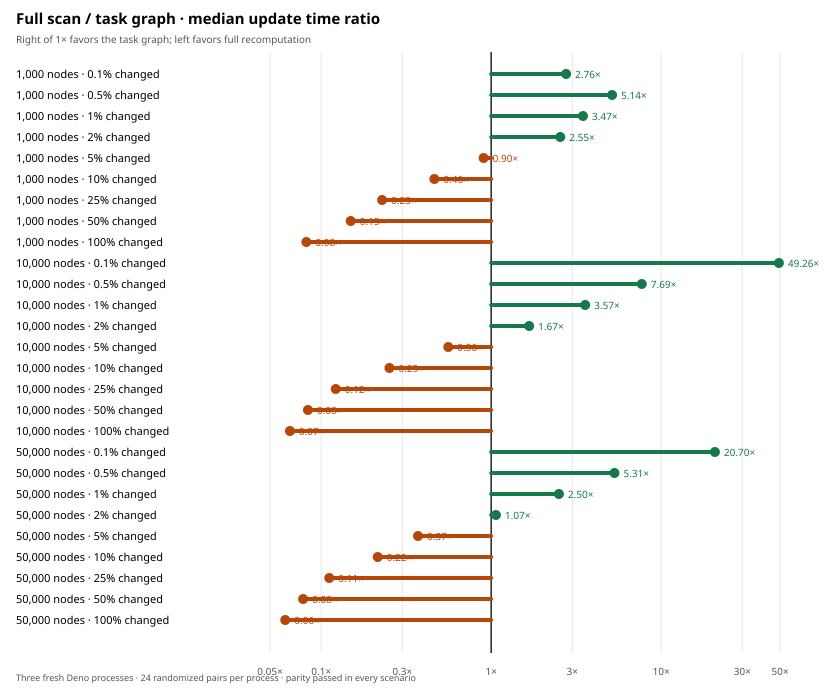

In [46]:
const taskGraphDispatchSummary = JSON.parse(await Deno.readTextFile("results/task-graph-dispatch-summary-v5.json"));
if (taskGraphDispatchSummary.processCount !== 3 || taskGraphDispatchSummary.scenarios.some((row) => !row.parityEveryProcess)) throw new Error("Task-graph dispatch benchmark failed replication or parity checks");
const taskGraphDispatchRows = taskGraphDispatchSummary.scenarios;
console.table(taskGraphDispatchRows.map((row) => ({ nodes: row.entityCount, changed: `${row.changedFraction * 100}%`, graphUs: (row.medianAcrossProcessMediansMs.taskGraph * 1000).toFixed(2), scanUs: (row.medianAcrossProcessMediansMs.fullScan * 1000).toFixed(2), scanOverGraph: row.speedupFullScanOverGraph.toFixed(2), wins: row.pairedWinsByProcess.map((wins) => `${wins.taskGraph}/24`).join(", "), parity: row.parityEveryProcess })));
const ratioMin = 0.05, ratioMax = 50, plotX0 = 270, plotWidth = 510, plotY0 = 74, rowGap = 21;
const taskGraphChartHeight = plotY0 + taskGraphDispatchRows.length * rowGap + 48;
const ratioX = (ratio) => plotX0 + (Math.log(Math.max(ratioMin, Math.min(ratioMax, ratio)) / ratioMin) / Math.log(ratioMax / ratioMin)) * plotWidth;
const taskGraphSvg = [`<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${taskGraphChartHeight}" viewBox="0 0 840 ${taskGraphChartHeight}" role="img" aria-labelledby="tg-title tg-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif"><title id="tg-title">Task graph speedup versus full recomputation</title><desc id="tg-desc">Log scale ratio of full scan median to task graph median across node counts and change fractions. Values greater than one favor graph dispatch.</desc><rect width="100%" height="100%" fill="white"/><text x="16" y="24" font-size="15" font-weight="700">Full scan / task graph · median update time ratio</text><text x="16" y="43" font-size="10" fill="#555">Right of 1× favors the task graph; left favors full recomputation</text>`];
for (const tick of [0.05, 0.1, 0.3, 1, 3, 10, 30, 50]) { const x = ratioX(tick); taskGraphSvg.push(`<line x1="${x}" y1="52" x2="${x}" y2="${taskGraphChartHeight - 36}" stroke="${tick === 1 ? "#222" : "#e5e7eb"}" stroke-width="${tick === 1 ? 1.5 : 1}"/><text x="${x}" y="${taskGraphChartHeight - 14}" text-anchor="middle" font-size="10" fill="#555">${tick}×</text>`); }
taskGraphDispatchRows.forEach((row, index) => { const y = plotY0 + index * rowGap; const ratio = row.speedupFullScanOverGraph; const x = ratioX(ratio); const color = ratio >= 1 ? "#16794b" : "#b54708"; taskGraphSvg.push(`<text x="16" y="${y + 4}" font-size="11">${row.entityCount.toLocaleString()} nodes · ${row.changedFraction * 100}% changed</text><line x1="${ratioX(1)}" y1="${y}" x2="${x}" y2="${y}" stroke="${color}" stroke-width="4" stroke-linecap="round"/><circle cx="${x}" cy="${y}" r="5" fill="${color}"/><text x="${Math.min(812, x + 9)}" y="${y + 4}" font-size="10" fill="${color}">${ratio.toFixed(2)}×</text>`); });
taskGraphSvg.push(`<text x="16" y="${taskGraphChartHeight - 8}" font-size="9" fill="#555">Three fresh Deno processes · 24 randomized pairs per process · parity passed in every scenario</text></svg>`);
console.log("Across three process medians, graph dispatch wins at 10k through 2% changes and at 50k through 2% (near parity at 2%); it loses from 5% upward. At 1k it wins from 0.5% through 2%, while a single changed task is below the graph’s useful granularity. This synthetic test supports a workload-dependent graph/scan policy, not a general framework speed claim.");
Deno.jupyter.svg`${taskGraphSvg.join("")}`;


### Indexed component update ablation (Deno)

Run `deno task component-update:replicate` to collect three serialized fresh-process replications. Each process tests a one-leaf state update among 100–10,000 keyed sibling components, with five warmup pairs and 25 seeded-order measured pairs per size. The owner-cache arm dispatches through the OXC state-site graph, renders one component, and attempts an indexed commit for its unique stable host root; structural or ineligible updates use full reconciliation. The comparison arm forces every component function to run. Both use the same in-memory VDOM host. At 10,000 siblings, the measured medians are 0.030 ms vs 28.032 ms. This is a state-local mechanism ablation, not a React comparison or browser timing result; it does not establish an overall framework advantage.


Component update ablation: [{"size":100,"medianMs":{"ownerCache":0.01300000000000523,"fullRender":0.37708300000002737},"medianProcessP95Ms":{"ownerCache":0.09916699999999423,"fullRender":0.6370420000000081},"speedup":29.59938461537305,"pairedWinsByProcess":[{"ownerCache":25,"fullRender":0,"ties":0},{"ownerCache":25,"fullRender":0,"ties":0},{"ownerCache":25,"fullRender":0,"ties":0}],"rendersPerUpdate":{"ownerCache":1,"fullRender":100},"partialCommitsPerUpdate":{"ownerCache":1,"fullRender":0}},{"size":1000,"medianMs":{"ownerCache":0.008750000000020464,"fullRender":2.376292000000035},"medianProcessP95Ms":{"ownerCache":0.023707999999999174,"fullRender":3.7094999999999914},"speedup":275.51211594219285,"pairedWinsByProcess":[{"ownerCache":25,"fullRender":0,"ties":0},{"ownerCache":25,"fullRender":0,"ties":0},{"ownerCache":25,"fullRender":0,"ties":0}],"rendersPerUpdate":{"ownerCache":1,"fullRender":1000},"partialCommitsPerUpdate":{"ownerCache":1,"fullRender":0}},{"size":5000,"medianMs":{"owner

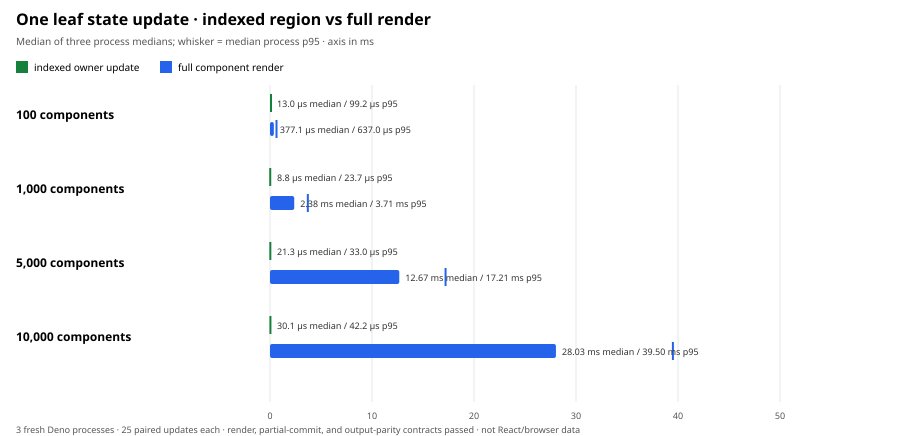

In [47]:
const componentUpdateRecord = JSON.parse(await Deno.readTextFile("results/component-update-ablation-summary-v1.json"));
if (componentUpdateRecord.status !== "PASS" || componentUpdateRecord.processCount !== 3 || componentUpdateRecord.scenarios.some((row: any) => !row.allOutputParity || !row.allRenderCountContracts || !row.allPartialCommitContracts)) throw new Error("Component update replication summary did not pass validation");
const componentUpdateRows = componentUpdateRecord.scenarios;
const chartWidth = 900;
const chartHeight = 140 + componentUpdateRows.length * 74;
const plotX = 270;
const plotWidth = 510;
const scale = plotWidth / 50;
const displayTime = (ms: number) => ms < 1 ? `${(ms * 1000).toFixed(1)} µs` : `${ms.toFixed(2)} ms`;
const chart = [`<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${chartHeight}" viewBox="0 0 ${chartWidth} ${chartHeight}" role="img" aria-labelledby="component-update-title component-update-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif"><title id="component-update-title">Indexed component update ablation</title><desc id="component-update-desc">Bars show the median across three fresh Deno process medians; whiskers show the median process-level p95. The indexed owner update and forced full-render arms use the same VDOM host. All measured owner updates use one indexed partial commit.</desc><rect width="100%" height="100%" fill="white"/><text x="16" y="25" font-size="16" font-weight="700">One leaf state update · indexed region vs full render</text><text x="16" y="45" font-size="10" fill="#555">Median of three process medians; whisker = median process p95 · axis in ms</text><rect x="16" y="61" width="12" height="12" fill="#16803c"/><text x="34" y="71" font-size="10">indexed owner update</text><rect x="160" y="61" width="12" height="12" fill="#2563eb"/><text x="178" y="71" font-size="10">full component render</text>`];
for (let tick = 0; tick <= 50; tick += 10) { const x = plotX + tick * scale; chart.push(`<line x1="${x}" y1="85" x2="${x}" y2="${chartHeight - 34}" stroke="#e5e7eb"/><text x="${x}" y="${chartHeight - 17}" text-anchor="middle" font-size="9" fill="#555">${tick}</text>`); }
componentUpdateRows.forEach((row: any, index: number) => { const top = 96 + index * 74; chart.push(`<text x="16" y="${top + 23}" font-size="12" font-weight="600">${row.size.toLocaleString()} components</text>`); for (const [arm, color, offset] of [["ownerCache", "#16803c", 0], ["fullRender", "#2563eb", 26]] as const) { const y = top + offset; const median = row.medianMs[arm]; const p95 = row.medianProcessP95Ms[arm]; const width = Math.max(1, median * scale); const whisker = plotX + Math.min(p95, 50) * scale; chart.push(`<rect x="${plotX}" y="${y}" width="${width}" height="14" rx="2" fill="${color}"/><line x1="${whisker}" y1="${y - 2}" x2="${whisker}" y2="${y + 16}" stroke="${color}" stroke-width="2"/><text x="${Math.min(plotX + width + 6, 790)}" y="${y + 11}" font-size="9" fill="#333">${displayTime(median)} median / ${displayTime(p95)} p95</text>`); } });
chart.push(`<text x="16" y="${chartHeight - 3}" font-size="9" fill="#555">3 fresh Deno processes · 25 paired updates each · render, partial-commit, and output-parity contracts passed · not React/browser data</text></svg>`);
console.log("Component update ablation:", JSON.stringify(componentUpdateRows.map((row: any) => ({ size: row.size, medianMs: row.medianMs, medianProcessP95Ms: row.medianProcessP95Ms, speedup: row.medianSpeedupFullOverOwnerCache, pairedWinsByProcess: row.pairedWinsByProcess, rendersPerUpdate: row.processes[0].rendersPerUpdate, partialCommitsPerUpdate: row.processes[0].partialCommitsPerUpdate }))));
Deno.jupyter.svg`${chart.join("")}`;


### OXC state-site invalidation graph

The state-site compiler now emits a compact CSR graph from each compiler-stable state site to its owning component region. `ComponentStateRoot` can use these edges to select which dirty owner components rerun. The graph currently represents direct state ownership only; transitive derived values remain out of scope. The runtime uses a unique keyed host-root index to partially commit one eligible owner update without visiting sibling regions. The notebook validates every emitted edge against OXC component metadata and the runtime dispatcher; the separate component-update ablation validates partial-commit counts and full output parity.


{"everyStateSiteHasOneOwningRegion":true,"dispatcherMatchesCompilerEdges":true}


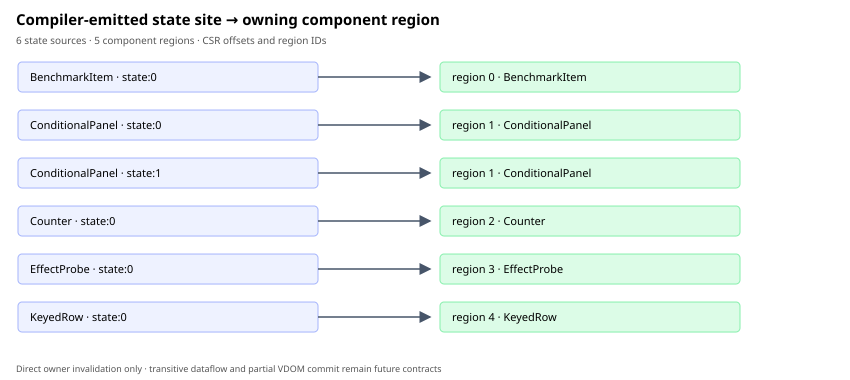

In [48]:
import { componentStateSitesPlan } from "./src/browser/generated_component_state_sites.ts";
import { DerivedRegionDispatcher } from "./src/derived_region_runtime.ts";

const invalidation = componentStateSitesPlan.invalidation_graph;
if (componentStateSitesPlan.schema_version !== 3 || invalidation.source_count !== invalidation.source_paths.length || invalidation.source_region_offsets.length !== invalidation.source_count + 1) throw new Error("Malformed compiler state invalidation graph");
const dispatcher = new DerivedRegionDispatcher(invalidation);
const edgeRows = invalidation.source_paths.map((siteId, sourceSlot) => { const region = invalidation.region_ids[invalidation.source_region_offsets[sourceSlot]]; const componentSiteId = invalidation.region_component_site_ids[region]; const component = componentStateSitesPlan.components.find((item) => item.component_site_id === componentSiteId); const stateSite = component?.state_sites.find((site) => site.site_id === siteId); if (!component || !stateSite) throw new Error(`Invalid state-site edge ${siteId}`); dispatcher.invalidateSourceSlot(sourceSlot); let dispatched = -1; dispatcher.flush((regionId) => dispatched = regionId); if (dispatched !== region) throw new Error(`Dispatcher selected region ${dispatched} for ${siteId}; expected ${region}`); return { siteId, component: component.name, stateOrdinal: stateSite.ordinal, region }; });
const invalidationGraphRecord = { schemaVersion: "component-state-invalidation-graph-v1", status: "PASS", compilerSchemaVersion: componentStateSitesPlan.schema_version, sourceCount: invalidation.source_count, componentRegionCount: invalidation.region_component_site_ids.length, checks: { everyStateSiteHasOneOwningRegion: edgeRows.length === invalidation.source_count, dispatcherMatchesCompilerEdges: true }, scope: "OXC-emitted direct state-site-to-component edges; no derived data dependencies or VDOM region pruning", edges: edgeRows };
await Deno.writeTextFile("results/component-state-invalidation-graph-v1.json", JSON.stringify(invalidationGraphRecord, null, 2) + "\n");
const graphHeight = 92 + edgeRows.length * 48;
const graphSvg = [`<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${graphHeight}" viewBox="0 0 850 ${graphHeight}" role="img" aria-labelledby="state-graph-title state-graph-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif"><title id="state-graph-title">Compiler state-site invalidation graph</title><desc id="state-graph-desc">Each compiler-addressed state site points to the component region that owns it.</desc><rect width="100%" height="100%" fill="white"/><text x="16" y="25" font-size="15" font-weight="700">Compiler-emitted state site → owning component region</text><text x="16" y="44" font-size="10" fill="#555">${edgeRows.length} state sources · ${invalidation.region_component_site_ids.length} component regions · CSR offsets and region IDs</text>`];
edgeRows.forEach((edge, index) => { const y = 62 + index * 48; const siteLabel = `${edge.component} · state:${edge.stateOrdinal}`; graphSvg.push(`<rect x="18" y="${y}" width="300" height="30" rx="4" fill="#eef2ff" stroke="#a5b4fc"/><text x="30" y="${y + 19}" font-size="11">${siteLabel}</text><line x1="318" y1="${y + 15}" x2="430" y2="${y + 15}" stroke="#475569" stroke-width="1.5" marker-end="url(#arrow)"/><rect x="440" y="${y}" width="300" height="30" rx="4" fill="#dcfce7" stroke="#86efac"/><text x="452" y="${y + 19}" font-size="11">region ${edge.region} · ${edge.component}</text>`); });
graphSvg.push(`<defs><marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#475569"/></marker></defs><text x="16" y="${graphHeight - 8}" font-size="9" fill="#555">Direct owner invalidation only · transitive dataflow and partial VDOM commit remain future contracts</text></svg>`);
console.log(JSON.stringify(invalidationGraphRecord.checks));
Deno.jupyter.svg`${graphSvg.join("")}`;

### Experiment AA — component-local state update vs React Compiler

The production browser comparison mounts a flat keyed list, then toggles one leaf-local boolean through a programmatic click. React 19.3.0 runs with React Compiler enabled. The compiled arm uses OXC-generated owner/site state, graph-selected owner execution, and an indexed keyed-region commit. Each page validates every target update, final full-tree parity, keyed identity, one component render per update, and one runtime partial commit per update. Mount is separate; layout and paint are excluded.

The chart summarizes page-load medians, with whiskers showing the min–max page median across replications. The 40 measured pairs and 100 updates per pair are nested observations, not independent replications. All runs use one Chrome 155 profile and one MacIntel device. The size-correlated React cost is a result for this flat sibling tree; its internal cause and generality remain open.



[
  {
    "count": 100,
    "pages": 3,
    "medianMs": {
      "react": 0.13099999994039535,
      "runtime": 0.005
    },
    "pageMedianRangeMs": {
      "react": [
        0.13,
        0.13200000002980233
      ],
      "runtime": [
        0.005,
        0.005999999940395355
      ]
    },
    "medianPageP95Ms": {
      "react": 0.1869999999552965,
      "runtime": 0.007999999970197678
    },
    "medianPerPageSpeedup": 26
  },
  {
    "count": 1000,
    "pages": 3,
    "medianMs": {
      "react": 1.4230000000447034,
      "runtime": 0.007000000029802322
    },
    "pageMedianRangeMs": {
      "react": [
        1.3610000000149012,
        1.4269999999552965
      ],
      "runtime": [
        0.006999999955296516,
        0.007000000029802322
      ]
    },
    "medianPageP95Ms": {
      "react": 1.4639999999850988,
      "runtime": 0.012000000029802322
    },
    "medianPerPageSpeedup": 203.28571559032616
  },
  {
    "count": 5000,
    "pages": 3,
    "medianMs": {
      "rea

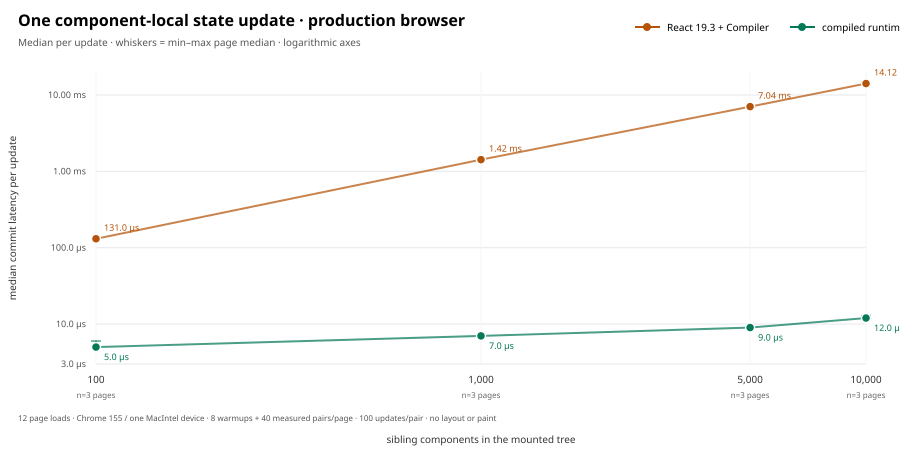

In [49]:
const browserStateSummary = JSON.parse(await Deno.readTextFile("results/browser-component-state-react-summary-v1.json"));
if (browserStateSummary.status !== "PASS" || browserStateSummary.scenarios.some((row: any) => !row.contractsPass)) {
  throw new Error("Browser local-state comparison failed its contracts");
}
const browserRows = browserStateSummary.scenarios;
const svgWidth = 900;
const svgHeight = 450;
const left = 96;
const right = 34;
const top = 72;
const bottom = 86;
const plotWidth = svgWidth - left - right;
const plotHeight = svgHeight - top - bottom;
const minY = 0.003;
const maxY = 20;
const x = (count: number) => left + (Math.log10(count) - 2) / 2 * plotWidth;
const y = (value: number) => top + (Math.log10(maxY) - Math.log10(value)) / (Math.log10(maxY) - Math.log10(minY)) * plotHeight;
const fmt = (value: number) => value < 1 ? `${(value * 1000).toFixed(1)} µs` : `${value.toFixed(2)} ms`;
const svg = [
  `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${svgHeight}" viewBox="0 0 ${svgWidth} ${svgHeight}" role="img" aria-labelledby="browser-state-title browser-state-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">`,
  `<title id="browser-state-title">One local state update: React Compiler vs compiled runtime</title>`,
  `<desc id="browser-state-desc">Log-log chart of median milliseconds per update at 100, 1000, 5000, and 10000 sibling components. Points are medians across browser page-load medians; vertical whiskers span the page-level median range. React grows with tree size while the specialized runtime remains nearly flat.</desc>`,
  `<rect width="100%" height="100%" fill="white"/>`,
  `<text x="18" y="26" font-size="16" font-weight="700">One component-local state update · production browser</text>`,
  `<text x="18" y="46" font-size="10" fill="#555">Median per update · whiskers = min–max page median · logarithmic axes</text>`,
  `<line x1="635" y1="27" x2="660" y2="27" stroke="#b45309" stroke-width="2"/><circle cx="647" cy="27" r="4" fill="#b45309"/><text x="667" y="31" font-size="10">React 19.3 + Compiler</text>`,
  `<line x1="790" y1="27" x2="815" y2="27" stroke="#047857" stroke-width="2"/><circle cx="802" cy="27" r="4" fill="#047857"/><text x="822" y="31" font-size="10">compiled runtime</text>`,
];
for (const tick of [0.003, 0.01, 0.1, 1, 10]) {
  const yy = y(tick);
  svg.push(`<line x1="${left}" y1="${yy}" x2="${svgWidth - right}" y2="${yy}" stroke="#e5e7eb"/><text x="${left - 10}" y="${yy + 3}" text-anchor="end" font-size="9" fill="#555">${fmt(tick)}</text>`);
}
for (const row of browserRows) {
  const xx = x(row.count);
  svg.push(`<line x1="${xx}" y1="${top}" x2="${xx}" y2="${svgHeight - bottom}" stroke="#f1f5f9"/><text x="${xx}" y="${svgHeight - bottom + 19}" text-anchor="middle" font-size="10" fill="#333">${row.count.toLocaleString()}</text><text x="${xx}" y="${svgHeight - bottom + 34}" text-anchor="middle" font-size="8" fill="#666">n=${row.pageLoadReplications} pages</text>`);
}
for (const [arm, color] of [["react", "#b45309"], ["runtime", "#047857"]] as const) {
  const points = browserRows.map((row: any) => `${x(row.count)},${y(row.medianMs[arm])}`).join(" ");
  svg.push(`<polyline points="${points}" fill="none" stroke="${color}" stroke-width="2" opacity="0.72"/>`);
  for (const row of browserRows) {
    const xx = x(row.count);
    const value = row.medianMs[arm];
    const range = row.pageMedianRangeMs[arm];
    const yy = y(value);
    svg.push(`<line x1="${xx}" y1="${y(range[0])}" x2="${xx}" y2="${y(range[1])}" stroke="${color}" stroke-width="2"/><line x1="${xx - 5}" y1="${y(range[0])}" x2="${xx + 5}" y2="${y(range[0])}" stroke="${color}"/><line x1="${xx - 5}" y1="${y(range[1])}" x2="${xx + 5}" y2="${y(range[1])}" stroke="${color}"/><circle cx="${xx}" cy="${yy}" r="4.5" fill="${color}" stroke="white" stroke-width="1.5"/><text x="${xx + 8}" y="${yy + (arm === "runtime" ? 13 : -8)}" font-size="9" fill="${color}">${fmt(value)}</text>`);
  }
}
svg.push(`<text x="${left + plotWidth / 2}" y="${svgHeight - 7}" text-anchor="middle" font-size="10" fill="#333">sibling components in the mounted tree</text><text x="16" y="${top + plotHeight / 2}" transform="rotate(-90 16 ${top + plotHeight / 2})" text-anchor="middle" font-size="10" fill="#333">median commit latency per update</text><text x="18" y="${svgHeight - 29}" font-size="8" fill="#555">${browserStateSummary.rawFiles.length} page loads · Chrome 155 / one MacIntel device · 8 warmups + 40 measured pairs/page · 100 updates/pair · no layout or paint</text></svg>`);
console.log(JSON.stringify(browserRows.map((row: any) => ({
  count: row.count,
  pages: row.pageLoadReplications,
  medianMs: row.medianMs,
  pageMedianRangeMs: row.pageMedianRangeMs,
  medianPageP95Ms: row.medianPageP95Ms,
  medianPerPageSpeedup: row.medianPerPageSpeedup,
})), null, 2));
Deno.jupyter.svg`${svg.join("")}`;



### Experiment AC — executable async task-plan readiness

This cell runs the pure-JavaScript `executeAsyncTaskPlan` fixture with deferred promises. It proves that independent profile/feed tasks start together, the profile-dependent header begins as soon as the profile is ready, and the page model waits only for its declared profile and feed inputs. The diagram is an event-order view with no time axis.

The scheduler uses a bounded min-heap ready queue, supports abort signals, and keeps outputs candidate-local. Experiment AD now connects this executor to versioned root candidates and a coordinated multi-root commit. This cell remains an executor-level event-order fixture: it measures no duration, implements no progressive reveal policy, and does not parallelize CPU work.



{
  "schemaVersion": "async-task-scheduler-event-trace-v1",
  "status": "PASS",
  "execution": "executeAsyncTaskPlan with deferred promises and maxConcurrency=2",
  "timingMeasured": false,
  "startedInitially": [
    "profile",
    "feed"
  ],
  "startedAfterProfile": [
    "profile",
    "feed",
    "personalized-header"
  ],
  "pageModelWaitedForFeed": true,
  "completed": [
    "profile",
    "personalized-header",
    "feed",
    "page-model"
  ],
  "outputs": {
    "personalizedHeader": "Hello Ada",
    "pageModel": "Ada:news"
  },
  "contractsPass": true,
  "limitation": "Deterministic event-order proof only. It does not measure wall time, compare React, integrate VDOM commits, or parallelize CPU work."
}


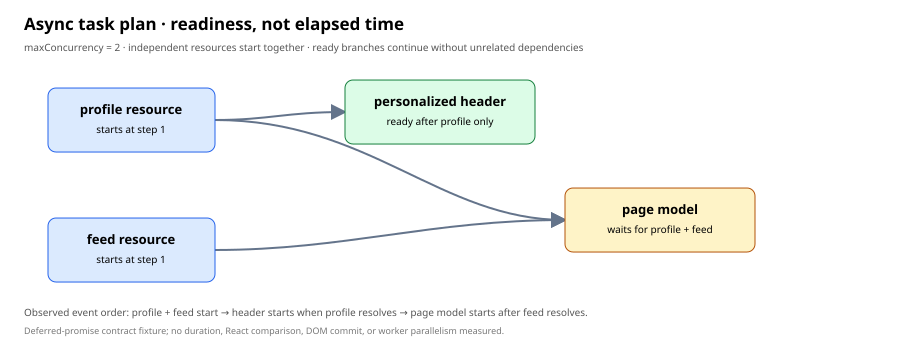

In [50]:
import { runAsyncTaskSchedulerExperiment } from "./src/async_task_scheduler_experiment.ts";

const asyncSchedulingResult = await runAsyncTaskSchedulerExperiment();
if (
  asyncSchedulingResult.status !== "PASS" ||
  !asyncSchedulingResult.contractsPass
) {
  throw new Error("Async task scheduling event-order contract failed");
}
console.log(JSON.stringify(asyncSchedulingResult, null, 2));

const asyncSvg = [
  `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="350" viewBox="0 0 900 350" role="img" aria-labelledby="async-dag-title async-dag-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">`,
  `<title id="async-dag-title">Async task-plan readiness trace</title>`,
  `<desc id="async-dag-desc">A profile task and feed task start independently. The personalized header starts when profile resolves, while the page model waits for both profile and feed. This is an event-order diagram with no timing scale.</desc>`,
  `<defs><marker id="async-arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#64748b"/></marker></defs>`,
  `<rect width="100%" height="100%" fill="white"/>`,
  `<text x="24" y="30" font-size="17" font-weight="700">Async task plan · readiness, not elapsed time</text>`,
  `<text x="24" y="51" font-size="10" fill="#555">maxConcurrency = 2 · independent resources start together · ready branches continue without unrelated dependencies</text>`,
  `<path d="M 215 120 C 270 120, 285 112, 345 112" fill="none" stroke="#64748b" stroke-width="2" marker-end="url(#async-arrow)"/>`,
  `<path d="M 215 120 C 370 120, 440 220, 565 220" fill="none" stroke="#64748b" stroke-width="2" marker-end="url(#async-arrow)"/>`,
  `<path d="M 215 250 C 345 250, 430 220, 565 220" fill="none" stroke="#64748b" stroke-width="2" marker-end="url(#async-arrow)"/>`,
  `<rect x="48" y="88" width="167" height="64" rx="8" fill="#dbeafe" stroke="#2563eb"/><text x="131" y="114" text-anchor="middle" font-size="13" font-weight="700">profile resource</text><text x="131" y="133" text-anchor="middle" font-size="10">starts at step 1</text>`,
  `<rect x="48" y="218" width="167" height="64" rx="8" fill="#dbeafe" stroke="#2563eb"/><text x="131" y="244" text-anchor="middle" font-size="13" font-weight="700">feed resource</text><text x="131" y="263" text-anchor="middle" font-size="10">starts at step 1</text>`,
  `<rect x="345" y="80" width="190" height="64" rx="8" fill="#dcfce7" stroke="#15803d"/><text x="440" y="106" text-anchor="middle" font-size="13" font-weight="700">personalized header</text><text x="440" y="125" text-anchor="middle" font-size="10">ready after profile only</text>`,
  `<rect x="565" y="188" width="190" height="64" rx="8" fill="#fef3c7" stroke="#b45309"/><text x="660" y="214" text-anchor="middle" font-size="13" font-weight="700">page model</text><text x="660" y="233" text-anchor="middle" font-size="10">waits for profile + feed</text>`,
  `<text x="24" y="316" font-size="10" fill="#555">Observed event order: profile + feed start → header starts when profile resolves → page model starts after feed resolves.</text>`,
  `<text x="24" y="334" font-size="9" fill="#777">Deferred-promise contract fixture; no duration, React comparison, DOM commit, or worker parallelism measured.</text>`,
  `</svg>`,
];
Deno.jupyter.svg`${asyncSvg.join("")}`;



### Experiment AD — async DAG preparation and atomic UI publication

This deterministic integration fixture connects `executeAsyncTaskPlan` to `TransitionCoordinator`. Independent profile and feed tasks start together; a header derivation starts as soon as its profile dependency resolves. The committed scene and HUD snapshots remain visible while work is pending. Once the full task plan is ready, candidate snapshots are staged and both versioned roots commit in one synchronous batch.

The event trace establishes scheduling and publication order, not speed. It does not yet implement progressive Suspense reveal boundaries, urgent-update rebasing, worker CPU execution, a React comparison, or browser frame timing. The next integration question is whether selective reveal can be added without weakening root consistency or complicating cancellation and lifecycle rules.



{
  "schemaVersion": "async-transition-integration-trace-v1",
  "status": "PASS",
  "contracts": {
    "retainedWhilePending": true,
    "branchRanBeforeFeed": true,
    "atomicCommit": true
  },
  "contractsPass": true,
  "events": [
    "start:profile",
    "start:feed",
    "retain:committed-roots",
    "resolve:profile",
    "derive:header",
    "resolve:feed",
    "prepare:root-snapshots",
    "commit:scene+hud"
  ],
  "startedTasks": [
    "profile",
    "feed",
    "header"
  ],
  "completedTasks": [
    "profile",
    "header",
    "feed"
  ],
  "committedSnapshots": {
    "scene": "scene:items",
    "hud": "hud:hello Ada"
  },
  "timingMeasured": false,
  "browserMeasured": false,
  "limitations": [
    "event-loop async overlap only; CPU tasks are not parallelized",
    "all task outputs are ready before candidate root snapshots are built",
    "no progressive reveal boundaries or React Suspense comparison"
  ]
}


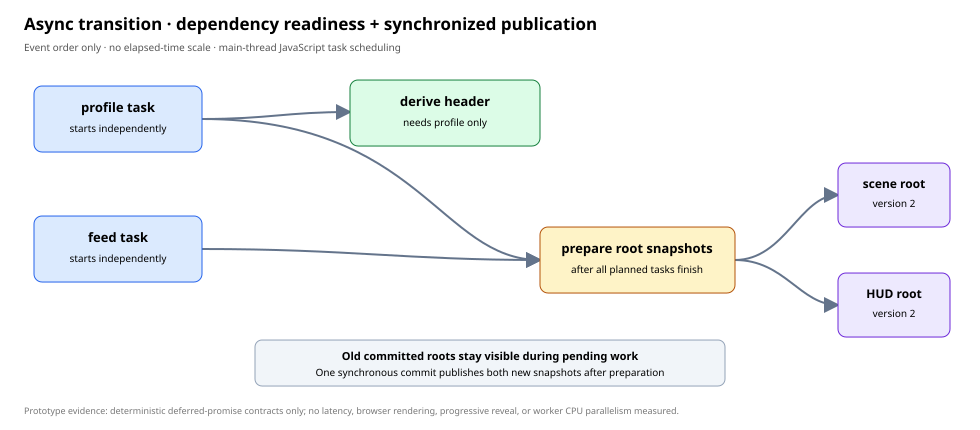

In [51]:
import { runAsyncTransitionExperiment } from "./src/async_transition_experiment.ts";

const asyncTransitionResult = await runAsyncTransitionExperiment();
if (
  asyncTransitionResult.status !== "PASS" ||
  !asyncTransitionResult.contractsPass
) {
  throw new Error("Async transition integration contract failed");
}
console.log(JSON.stringify(asyncTransitionResult, null, 2));

const transitionSvg = [
  `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="430" viewBox="0 0 980 430" role="img" aria-labelledby="async-transition-title async-transition-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">`,
  `<title id="async-transition-title">Async DAG preparation with atomic root publication</title>`,
  `<desc id="async-transition-desc">Independent profile and feed tasks start together. A header task runs as soon as profile resolves. The old scene and HUD remain visible until feed resolves, then both prepared root snapshots commit in one batch.</desc>`,
  `<defs><marker id="async-transition-arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#64748b"/></marker></defs>`,
  `<rect width="100%" height="100%" fill="white"/>`,
  `<text x="24" y="30" font-size="17" font-weight="700">Async transition · dependency readiness + synchronized publication</text>`,
  `<text x="24" y="51" font-size="10" fill="#555">Event order only · no elapsed-time scale · main-thread JavaScript task scheduling</text>`,
  `<path d="M 202 119 C 270 119, 285 112, 350 112" fill="none" stroke="#64748b" stroke-width="2" marker-end="url(#async-transition-arrow)"/>`,
  `<path d="M 202 119 C 420 119, 440 260, 540 260" fill="none" stroke="#64748b" stroke-width="2" marker-end="url(#async-transition-arrow)"/>`,
  `<path d="M 202 249 C 350 249, 405 260, 540 260" fill="none" stroke="#64748b" stroke-width="2" marker-end="url(#async-transition-arrow)"/>`,
  `<path d="M 735 260 C 785 260, 800 195, 838 195" fill="none" stroke="#64748b" stroke-width="2" marker-end="url(#async-transition-arrow)"/>`,
  `<path d="M 735 260 C 785 260, 800 305, 838 305" fill="none" stroke="#64748b" stroke-width="2" marker-end="url(#async-transition-arrow)"/>`,
  `<rect x="34" y="86" width="168" height="66" rx="8" fill="#dbeafe" stroke="#2563eb"/><text x="118" y="112" text-anchor="middle" font-size="13" font-weight="700">profile task</text><text x="118" y="132" text-anchor="middle" font-size="10">starts independently</text>`,
  `<rect x="34" y="216" width="168" height="66" rx="8" fill="#dbeafe" stroke="#2563eb"/><text x="118" y="242" text-anchor="middle" font-size="13" font-weight="700">feed task</text><text x="118" y="262" text-anchor="middle" font-size="10">starts independently</text>`,
  `<rect x="350" y="80" width="190" height="66" rx="8" fill="#dcfce7" stroke="#15803d"/><text x="445" y="106" text-anchor="middle" font-size="13" font-weight="700">derive header</text><text x="445" y="126" text-anchor="middle" font-size="10">needs profile only</text>`,
  `<rect x="540" y="227" width="195" height="66" rx="8" fill="#fef3c7" stroke="#b45309"/><text x="637" y="253" text-anchor="middle" font-size="13" font-weight="700">prepare root snapshots</text><text x="637" y="273" text-anchor="middle" font-size="10">after all planned tasks finish</text>`,
  `<rect x="838" y="163" width="112" height="64" rx="8" fill="#ede9fe" stroke="#6d28d9"/><text x="894" y="188" text-anchor="middle" font-size="12" font-weight="700">scene root</text><text x="894" y="207" text-anchor="middle" font-size="10">version 2</text>`,
  `<rect x="838" y="273" width="112" height="64" rx="8" fill="#ede9fe" stroke="#6d28d9"/><text x="894" y="298" text-anchor="middle" font-size="12" font-weight="700">HUD root</text><text x="894" y="317" text-anchor="middle" font-size="10">version 2</text>`,
  `<rect x="255" y="340" width="470" height="46" rx="7" fill="#f1f5f9" stroke="#94a3b8"/><text x="490" y="360" text-anchor="middle" font-size="11" font-weight="700">Old committed roots stay visible during pending work</text><text x="490" y="376" text-anchor="middle" font-size="10">One synchronous commit publishes both new snapshots after preparation</text>`,
  `<text x="24" y="414" font-size="9" fill="#777">Prototype evidence: deterministic deferred-promise contracts only; no latency, browser rendering, progressive reveal, or worker CPU parallelism measured.</text>`,
  `</svg>`,
];
Deno.jupyter.svg`${transitionSvg.join("")}`;



### Experiment AE — async preparation connected to retained VDOM roots

This fixture runs an async dependency plan against two mounted `VDOMSnapshotRoot` instances. Independent profile and scene-data tasks start together; the header derivation runs as soon as its profile input is ready. Candidate JSX results are normalized and duplicate-key checked before either host root is touched. The old keyed nodes remain mounted while work is pending, then both prepared roots commit synchronously with keyed host identity preserved.

This establishes a concrete in-memory path from task readiness to VDOM host operations. It is still a contract fixture, not a browser performance comparison. The prototype waits for the full task plan, has no nested reveal boundaries or urgent-update rebase policy, and does not connect OXC-emitted dependency plans to this API. The next measurement must include browser DOM work and an equivalent optimized React interaction.



{
  "schemaVersion": "async-vdom-transition-trace-v1",
  "status": "PASS",
  "contracts": {
    "retainedAtStart": true,
    "dependencyReadyBranchDidNotPatchEarly": true,
    "keyedIdentityPreserved": true,
    "rootsCommittedTogether": true
  },
  "contractsPass": true,
  "events": [
    "start:profile",
    "start:scene-data",
    "retain:visible-vdom",
    "resolve:profile",
    "derive:header",
    "resolve:scene-data",
    "commit:scene+hud"
  ],
  "startedTasks": [
    "profile",
    "scene-data",
    "header"
  ],
  "completedTasks": [
    "profile",
    "header",
    "scene-data"
  ],
  "hostWrites": 4,
  "placements": 6,
  "timingMeasured": false,
  "limitations": [
    "in-memory VDOM host only; no browser DOM or paint measurement",
    "all roots wait for the complete task plan; no progressive reveal boundary",
    "tasks represent async/event-loop work and do not parallelize CPU computation"
  ]
}


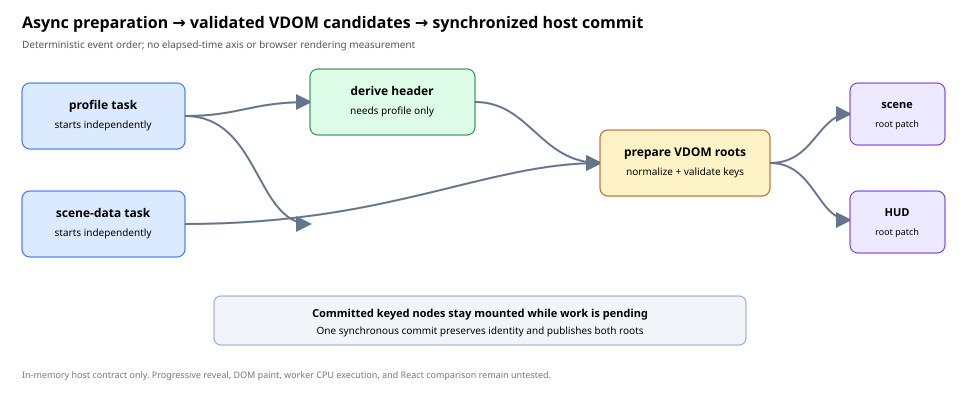

In [52]:
import { runAsyncVDOMTransitionExperiment } from "./src/async_vdom_transition_experiment.ts";

const asyncVDOMResult = await runAsyncVDOMTransitionExperiment();
if (asyncVDOMResult.status !== "PASS" || !asyncVDOMResult.contractsPass) {
  throw new Error("Async VDOM transition integration contract failed");
}
console.log(JSON.stringify(asyncVDOMResult, null, 2));

const asyncVDOMSvg = [
  `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="400" viewBox="0 0 960 400" role="img" aria-labelledby="async-vdom-title async-vdom-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">`,
  `<title id="async-vdom-title">Async task preparation connected to retained VDOM roots</title>`,
  `<desc id="async-vdom-desc">Profile and scene data tasks run independently. A header derives when profile resolves. Candidate VDOM trees are normalized and key-validated without host writes, then scene and HUD roots are patched in one synchronous commit.</desc>`,
  `<defs><marker id="async-vdom-arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#64748b"/></marker></defs>`,
  `<rect width="100%" height="100%" fill="white"/>`,
  `<text x="22" y="28" font-size="16" font-weight="700">Async preparation → validated VDOM candidates → synchronized host commit</text>`,
  `<text x="22" y="48" font-size="10" fill="#555">Deterministic event order; no elapsed-time axis or browser rendering measurement</text>`,
  `<path d="M 185 116 C 240 116, 250 102, 310 102" fill="none" stroke="#64748b" stroke-width="2" marker-end="url(#async-vdom-arrow)"/>`,
  `<path d="M 185 116 C 260 116, 255 224, 310 224" fill="none" stroke="#64748b" stroke-width="2" marker-end="url(#async-vdom-arrow)"/>`,
  `<path d="M 185 224 C 390 224, 485 163, 600 163" fill="none" stroke="#64748b" stroke-width="2" marker-end="url(#async-vdom-arrow)"/>`,
  `<path d="M 475 102 C 530 102, 540 163, 600 163" fill="none" stroke="#64748b" stroke-width="2" marker-end="url(#async-vdom-arrow)"/>`,
  `<path d="M 770 163 C 815 163, 817 114, 850 114" fill="none" stroke="#64748b" stroke-width="2" marker-end="url(#async-vdom-arrow)"/>`,
  `<path d="M 770 163 C 815 163, 817 220, 850 220" fill="none" stroke="#64748b" stroke-width="2" marker-end="url(#async-vdom-arrow)"/>`,
  `<rect x="22" y="83" width="163" height="66" rx="8" fill="#dbeafe" stroke="#2563eb"/><text x="103" y="109" text-anchor="middle" font-size="12" font-weight="700">profile task</text><text x="103" y="128" text-anchor="middle" font-size="10">starts independently</text>`,
  `<rect x="22" y="191" width="163" height="66" rx="8" fill="#dbeafe" stroke="#2563eb"/><text x="103" y="217" text-anchor="middle" font-size="12" font-weight="700">scene-data task</text><text x="103" y="236" text-anchor="middle" font-size="10">starts independently</text>`,
  `<rect x="310" y="69" width="165" height="66" rx="8" fill="#dcfce7" stroke="#15803d"/><text x="392" y="95" text-anchor="middle" font-size="12" font-weight="700">derive header</text><text x="392" y="114" text-anchor="middle" font-size="10">needs profile only</text>`,
  `<rect x="600" y="130" width="170" height="66" rx="8" fill="#fef3c7" stroke="#b45309"/><text x="685" y="156" text-anchor="middle" font-size="12" font-weight="700">prepare VDOM roots</text><text x="685" y="175" text-anchor="middle" font-size="10">normalize + validate keys</text>`,
  `<rect x="850" y="83" width="95" height="62" rx="8" fill="#ede9fe" stroke="#6d28d9"/><text x="897" y="108" text-anchor="middle" font-size="11" font-weight="700">scene</text><text x="897" y="127" text-anchor="middle" font-size="9">root patch</text>`,
  `<rect x="850" y="191" width="95" height="62" rx="8" fill="#ede9fe" stroke="#6d28d9"/><text x="897" y="216" text-anchor="middle" font-size="11" font-weight="700">HUD</text><text x="897" y="235" text-anchor="middle" font-size="9">root patch</text>`,
  `<rect x="214" y="296" width="532" height="49" rx="7" fill="#f1f5f9" stroke="#94a3b8"/><text x="480" y="317" text-anchor="middle" font-size="11" font-weight="700">Committed keyed nodes stay mounted while work is pending</text><text x="480" y="334" text-anchor="middle" font-size="10">One synchronous commit preserves identity and publishes both roots</text>`,
  `<text x="22" y="378" font-size="9" fill="#777">In-memory host contract only. Progressive reveal, DOM paint, worker CPU execution, and React comparison remain untested.</text>`,
  `</svg>`,
];
Deno.jupyter.svg`${asyncVDOMSvg.join("")}`;



### Experiment AF — OXC-emitted task DAG through the async VDOM runtime

OXC reads literal `asyncTask(id, dependsOn, callback)` declarations from the TSX fixture and emits stable IDs, dependency edges, source spans, and a topological order. The fixture deliberately declares `page-model` before its prerequisites; the emitted plan starts `profile` and `feed`, then `header`, then `page-model`. `bindCompiledAsyncTasks` joins that plan to the authored callbacks, and the runtime publishes the resulting dashboard through a retained VDOM root.

The compiler rejects cycles, unknown task IDs, and non-literal dependency arrays. This establishes a real compiler-to-scheduler-to-VDOM path for declared task dependencies. It does not infer arbitrary async reads, compile callback bodies, implement progressive reveal, compare React, or measure browser timing. The next test is an equivalent browser interaction with a compiler-emitted plan, a pending resource, and a matching React Suspense behavior contract.



{
  "schemaVersion": "compiled-async-task-plan-experiment-v1",
  "status": "PASS",
  "contracts": {
    "outputMatches": true,
    "taskOrderApplied": true
  },
  "contractsPass": true,
  "compilerOrder": [
    "profile",
    "feed",
    "header",
    "page-model"
  ],
  "startedTasks": [
    "profile",
    "feed",
    "header",
    "page-model"
  ],
  "completedTasks": [
    "profile",
    "feed",
    "header",
    "page-model"
  ],
  "events": [
    "start:profile",
    "start:feed",
    "finish:profile",
    "finish:feed",
    "start:header",
    "finish:header",
    "start:page-model",
    "finish:page-model"
  ],
  "finalTitle": "Hello, Ada",
  "finalItem": "First item",
  "hostWrites": 3,
  "timingMeasured": false,
  "limitations": [
    "compiler extracts literal task IDs and prerequisite lists; it does not infer arbitrary async reads",
    "in-memory VDOM host only; no browser timing or React comparison",
    "all roots wait for the complete task plan; progressive reveal is not

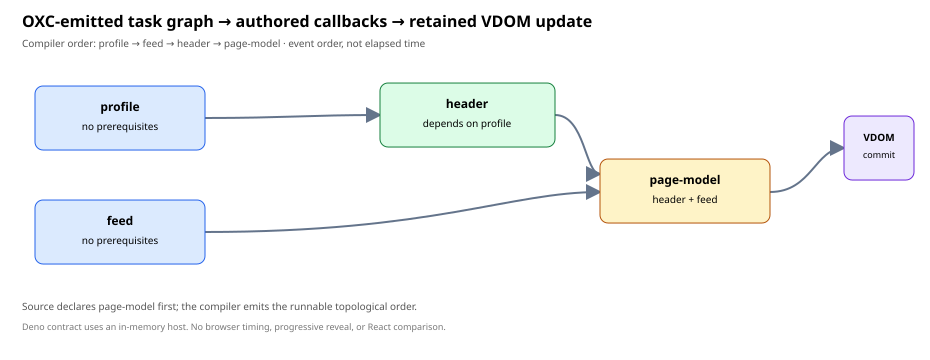

In [53]:
import { runCompiledAsyncTaskPlanExperiment } from "./src/async_task_plan_experiment.ts";

const compiledAsyncTaskResult = await runCompiledAsyncTaskPlanExperiment();
if (
  compiledAsyncTaskResult.status !== "PASS" ||
  !compiledAsyncTaskResult.contractsPass
) {
  throw new Error("Compiled async task-plan integration contract failed");
}
console.log(JSON.stringify(compiledAsyncTaskResult, null, 2));

const compiledAsyncSvg = [
  `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="360" viewBox="0 0 930 360" role="img" aria-labelledby="compiled-async-title compiled-async-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">`,
  `<title id="compiled-async-title">OXC-emitted async dependency plan runs through VDOM commit</title>`,
  `<desc id="compiled-async-desc">The source declares page-model first, but OXC emits a topological order in which profile and feed start first, header follows profile, and page-model follows header and feed. The task functions build one VDOM candidate that commits to a retained root.</desc>`,
  `<defs><marker id="compiled-async-arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#64748b"/></marker></defs>`,
  `<rect width="100%" height="100%" fill="white"/>`,
  `<text x="22" y="27" font-size="16" font-weight="700">OXC-emitted task graph → authored callbacks → retained VDOM update</text>`,
  `<text x="22" y="47" font-size="10" fill="#555">Compiler order: ${
    compiledAsyncTaskResult.compilerOrder.join(" → ")
  } · event order, not elapsed time</text>`,
  `<path d="M 205 118 C 285 118, 310 115, 380 115" fill="none" stroke="#64748b" stroke-width="2" marker-end="url(#compiled-async-arrow)"/>`,
  `<path d="M 205 232 C 435 232, 510 192, 600 192" fill="none" stroke="#64748b" stroke-width="2" marker-end="url(#compiled-async-arrow)"/>`,
  `<path d="M 555 115 C 585 115, 585 174, 600 174" fill="none" stroke="#64748b" stroke-width="2" marker-end="url(#compiled-async-arrow)"/>`,
  `<path d="M 770 192 C 812 192, 815 148, 844 148" fill="none" stroke="#64748b" stroke-width="2" marker-end="url(#compiled-async-arrow)"/>`,
  `<rect x="35" y="86" width="170" height="64" rx="8" fill="#dbeafe" stroke="#2563eb"/><text x="120" y="111" text-anchor="middle" font-size="12" font-weight="700">profile</text><text x="120" y="130" text-anchor="middle" font-size="10">no prerequisites</text>`,
  `<rect x="35" y="200" width="170" height="64" rx="8" fill="#dbeafe" stroke="#2563eb"/><text x="120" y="225" text-anchor="middle" font-size="12" font-weight="700">feed</text><text x="120" y="244" text-anchor="middle" font-size="10">no prerequisites</text>`,
  `<rect x="380" y="83" width="175" height="64" rx="8" fill="#dcfce7" stroke="#15803d"/><text x="467" y="108" text-anchor="middle" font-size="12" font-weight="700">header</text><text x="467" y="127" text-anchor="middle" font-size="10">depends on profile</text>`,
  `<rect x="600" y="159" width="170" height="64" rx="8" fill="#fef3c7" stroke="#b45309"/><text x="685" y="184" text-anchor="middle" font-size="12" font-weight="700">page-model</text><text x="685" y="203" text-anchor="middle" font-size="10">header + feed</text>`,
  `<rect x="844" y="116" width="70" height="64" rx="8" fill="#ede9fe" stroke="#6d28d9"/><text x="879" y="141" text-anchor="middle" font-size="10" font-weight="700">VDOM</text><text x="879" y="158" text-anchor="middle" font-size="9">commit</text>`,
  `<text x="22" y="310" font-size="10" fill="#555">Source declares page-model first; the compiler emits the runnable topological order.</text>`,
  `<text x="22" y="330" font-size="9" fill="#777">Deno contract uses an in-memory host. No browser timing, progressive reveal, or React comparison.</text>`,
  `</svg>`,
];
Deno.jupyter.svg`${compiledAsyncSvg.join("")}`;



### Experiment AG — prewarmed React Suspense versus the compiled async graph

This browser behavior study drives equivalent version-1 to version-2 dashboard transitions. React 19 uses `startTransition`, one Suspense boundary, and profile/feed promises started together before the render suspends. The runtime uses the checked-in OXC task plan, a concurrency-two scheduler, prepared keyed VDOM, and one commit after the complete page model is ready. The pair order alternates. Each pair checks that the old content and both keyed nodes remain visible after a frame while work is pending, then checks final output parity and commit completion.

The single saved Chrome 155 MacIntel run has 20 pairs. Median task-to-commit latency is 118.7 ms for React and 118.0 ms for the graph runtime; p95 is 180.5 and 179.2 ms. These values are close and dominated by synthetic timer waits, so they do not establish a speed advantage. This experiment verifies pending-state and identity behavior for one root and one boundary. It does not measure trusted-input latency, network I/O, layout, paint, hydration, progressive reveal, CPU work placement, or a second device. Raw samples are in `results/async-suspense-browser-v1-2026-10-09.json`.



{
  "schemaVersion": "async-suspense-browser-v1",
  "status": "PASS",
  "sampleCount": 20,
  "compilerOrder": [
    "profile",
    "feed",
    "header",
    "page-model"
  ],
  "medianMs": {
    "react": 118.70000000298023,
    "runtime": 118
  },
  "p95Ms": {
    "react": 180.5,
    "runtime": 179.20000000298023
  },
  "medianDeltaMsReactMinusRuntime": 0.7000000029802322,
  "contracts": {
    "oldUiRetainedDuringPending": true,
    "keyedNodesRetained": true,
    "equivalentFinalOutput": true
  },
  "interpretation": "No meaningful speed conclusion: async timer waits dominate task-to-commit latency and this is one browser/device run."
}


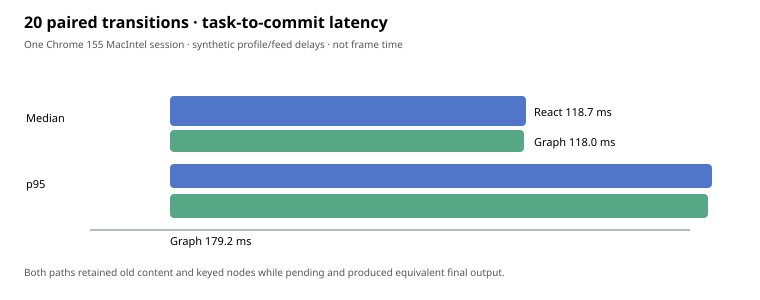

In [54]:
const suspenseBrowserRun = JSON.parse(
  await Deno.readTextFile("results/async-suspense-browser-v1-2026-10-09.json"),
);
if (
  suspenseBrowserRun.schemaVersion !== "async-suspense-browser-v1" ||
  suspenseBrowserRun.status !== "PASS" ||
  suspenseBrowserRun.samples.length !== 20 ||
  !suspenseBrowserRun.allPendingUiRetained ||
  !suspenseBrowserRun.allKeysRetained ||
  !suspenseBrowserRun.allOutputsEqual
) {
  throw new Error("Async Suspense browser run failed its saved contracts");
}
const suspenseQuantile = (values: number[], p: number) => {
  const ordered = [...values].sort((left, right) => left - right);
  return ordered[Math.max(0, Math.ceil(p * ordered.length) - 1)];
};
for (const arm of ["react", "runtime"] as const) {
  const times = suspenseBrowserRun.samples.map((sample: any) =>
    sample.milliseconds[arm]
  );
  if (
    suspenseQuantile(times, 0.5) !== suspenseBrowserRun.medianMs[arm] ||
    suspenseQuantile(times, 0.95) !== suspenseBrowserRun.p95Ms[arm]
  ) {
    throw new Error(`Saved ${arm} summary does not match its raw samples`);
  }
}
for (const sample of suspenseBrowserRun.samples) {
  if (
    sample.timerDelayMs.profile !== 54 + (sample.pair % 3) * 2 ||
    sample.timerDelayMs.feed !== 82 + (sample.pair % 4) * 2
  ) {
    throw new Error(`Saved timer schedule drifted in pair ${sample.pair}`);
  }
}
const suspenseMedianDelta = suspenseBrowserRun.medianMs.react -
  suspenseBrowserRun.medianMs.runtime;
console.log(JSON.stringify(
  {
    schemaVersion: suspenseBrowserRun.schemaVersion,
    status: suspenseBrowserRun.status,
    sampleCount: suspenseBrowserRun.samples.length,
    compilerOrder: suspenseBrowserRun.compilerOrder,
    medianMs: suspenseBrowserRun.medianMs,
    p95Ms: suspenseBrowserRun.p95Ms,
    medianDeltaMsReactMinusRuntime: suspenseMedianDelta,
    contracts: {
      oldUiRetainedDuringPending: suspenseBrowserRun.allPendingUiRetained,
      keyedNodesRetained: suspenseBrowserRun.allKeysRetained,
      equivalentFinalOutput: suspenseBrowserRun.allOutputsEqual,
    },
    interpretation:
      "No meaningful speed conclusion: async timer waits dominate task-to-commit latency and this is one browser/device run.",
  },
  null,
  2,
));

const suspenseSvg = [
  `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="300" viewBox="0 0 760 300" role="img" aria-labelledby="suspense-title suspense-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">`,
  `<title id="suspense-title">Async task-to-commit latency: React Suspense and compiled graph runtime</title>`,
  `<desc id="suspense-desc">Median and p95 milliseconds for 20 paired browser transitions. Values are close because deterministic asynchronous timer waits dominate.</desc>`,
  `<rect width="100%" height="100%" fill="white"/>`,
  `<text x="24" y="28" font-size="16" font-weight="700">20 paired transitions · task-to-commit latency</text>`,
  `<text x="24" y="48" font-size="10" fill="#555">One Chrome 155 MacIntel session · synthetic profile/feed delays · not frame time</text>`,
  `<line x1="90" y1="230" x2="690" y2="230" stroke="#64748b"/>`,
  `<text x="26" y="122" font-size="11">Median</text><text x="26" y="188" font-size="11">p95</text>`,
  `<rect x="170" y="96" width="356" height="30" rx="4" fill="#4f76c8"/><text x="534" y="116" font-size="11">React ${
    suspenseBrowserRun.medianMs.react.toFixed(1)
  } ms</text>`,
  `<rect x="170" y="130" width="354" height="22" rx="4" fill="#57a887"/><text x="534" y="146" font-size="11">Graph ${
    suspenseBrowserRun.medianMs.runtime.toFixed(1)
  } ms</text>`,
  `<rect x="170" y="164" width="542" height="24" rx="4" fill="#4f76c8"/><text x="170" y="207" font-size="11">React ${
    suspenseBrowserRun.p95Ms.react.toFixed(1)
  } ms</text>`,
  `<rect x="170" y="194" width="538" height="24" rx="4" fill="#57a887"/><text x="170" y="245" font-size="11">Graph ${
    suspenseBrowserRun.p95Ms.runtime.toFixed(1)
  } ms</text>`,
  `<text x="24" y="276" font-size="10" fill="#555">Both paths retained old content and keyed nodes while pending and produced equivalent final output.</text>`,
  `</svg>`,
];
Deno.jupyter.svg`${suspenseSvg.join("")}`;



### Experiment AH — urgent input during a multi-root async transition

React Compiler optimizes the React arm. React keeps the controlled input outside one Suspense boundary and starts the dashboard update in a transition. The runtime keeps the input in an independent native-event VDOM root while an OXC-emitted task DAG prepares scene and HUD roots for one coordinated commit. Each of 20 alternating-order pairs injects a programmatic input event on the next frame, before the synthetic profile/feed delays finish. The study checks old-view retention, urgent-value publication before data completion, both-root commit, keyed identity, task order, and output parity.

All 20 pairs passed with React Compiler enabled. Median dispatch-to-visible urgent update was 2.1 ms for React and 0.4 ms for the graph runtime; p95 was 10.7 and 3.1 ms. Median transition completion was 215.9 and 213.7 ms; p95 was 289.9 and 273.6 ms. These are descriptive values from one Chrome 155 MacIntel session; the event is programmatic and synthetic timers dominate transition completion. This supports the independent urgent-root behavior contract, but does not prove frame responsiveness or show that a write targeting a pending transition root can be rebased. See the raw pair data in `results/urgent-multiroot-transition-browser-v2-2026-10-09.json`.



{
  "schemaVersion": "urgent-multiroot-transition-browser-v2",
  "status": "PASS",
  "pairCount": 20,
  "compilerOrder": [
    "profile",
    "feed",
    "header",
    "page-model"
  ],
  "medianUrgentLatencyMs": {
    "react": 2.1,
    "runtime": 0.4
  },
  "p95UrgentLatencyMs": {
    "react": 10.7,
    "runtime": 3.1
  },
  "medianTransitionLatencyMs": {
    "react": 215.9,
    "runtime": 213.7
  },
  "p95TransitionLatencyMs": {
    "react": 289.9,
    "runtime": 273.6
  },
  "allContractsPass": true,
  "interpretation": "Urgent updates committed before async completion while transition roots kept their old UI. This verifies behavior for an independent urgent root, not rebasing an urgent write into the pending roots. Timing is descriptive and not a speed claim."
}


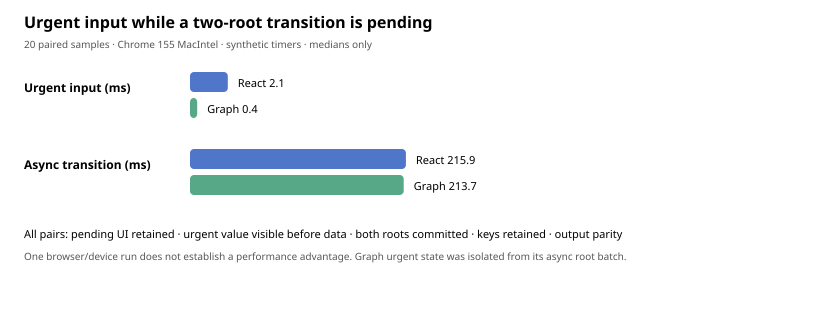

In [55]:
const urgentTransitionRun = JSON.parse(
  await Deno.readTextFile(
    "results/urgent-multiroot-transition-browser-v2-2026-10-09.json",
  ),
);
const urgentQuantile = (values: number[], p: number) => {
  const ordered = [...values].sort((left, right) => left - right);
  return ordered[Math.max(0, Math.ceil(p * ordered.length) - 1)];
};
if (
  urgentTransitionRun.schemaVersion !==
    "urgent-multiroot-transition-browser-v2" ||
  urgentTransitionRun.status !== "PASS" ||
  urgentTransitionRun.reactCompilerEnabled !== true ||
  urgentTransitionRun.samples.length !== 20 ||
  !urgentTransitionRun.allContractsPass
) {
  throw new Error(
    "Urgent multi-root transition study failed its saved contract",
  );
}
for (const sample of urgentTransitionRun.samples) {
  if (
    sample.timerDelayMs.profile !== 74 + (sample.pair % 3) * 2 ||
    sample.timerDelayMs.feed !== 112 + (sample.pair % 4) * 2 ||
    sample.runtimeTaskOrder.join(",") !==
      "profile,feed,header,page-model" ||
    !Object.values(sample.contracts).every(Boolean)
  ) {
    throw new Error(`Saved urgent transition pair ${sample.pair} drifted`);
  }
}
for (const arm of ["react", "runtime"] as const) {
  const urgentTimes = urgentTransitionRun.samples.map((sample: any) =>
    sample.urgentLatencyMs[arm]
  );
  const transitionTimes = urgentTransitionRun.samples.map((sample: any) =>
    sample.transitionLatencyMs[arm]
  );
  if (
    urgentQuantile(urgentTimes, 0.5) !==
      urgentTransitionRun.medianUrgentLatencyMs[arm] ||
    urgentQuantile(urgentTimes, 0.95) !==
      urgentTransitionRun.p95UrgentLatencyMs[arm] ||
    urgentQuantile(transitionTimes, 0.5) !==
      urgentTransitionRun.medianTransitionLatencyMs[arm] ||
    urgentQuantile(transitionTimes, 0.95) !==
      urgentTransitionRun.p95TransitionLatencyMs[arm]
  ) {
    throw new Error(`Saved ${arm} summary does not match its raw samples`);
  }
}
console.log(JSON.stringify(
  {
    schemaVersion: urgentTransitionRun.schemaVersion,
    status: urgentTransitionRun.status,
    pairCount: urgentTransitionRun.pairCount,
    compilerOrder: urgentTransitionRun.compilerOrder,
    medianUrgentLatencyMs: urgentTransitionRun.medianUrgentLatencyMs,
    p95UrgentLatencyMs: urgentTransitionRun.p95UrgentLatencyMs,
    medianTransitionLatencyMs: urgentTransitionRun.medianTransitionLatencyMs,
    p95TransitionLatencyMs: urgentTransitionRun.p95TransitionLatencyMs,
    allContractsPass: urgentTransitionRun.allContractsPass,
    interpretation:
      "Urgent updates committed before async completion while transition roots kept their old UI. This verifies behavior for an independent urgent root, not rebasing an urgent write into the pending roots. Timing is descriptive and not a speed claim.",
  },
  null,
  2,
));

const urgentSvg = [
  `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="330" viewBox="0 0 820 330" role="img" aria-labelledby="urgent-title urgent-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">`,
  `<title id="urgent-title">Urgent input and transition completion medians</title>`,
  `<desc id="urgent-desc">Twenty paired browser transitions compare urgent input event completion and async transition completion for React and the compiled graph runtime. Both passed visible-state, multi-root commit, identity, and parity contracts.</desc>`,
  `<rect width="100%" height="100%" fill="white"/>`,
  `<text x="24" y="28" font-size="16" font-weight="700">Urgent input while a two-root transition is pending</text>`,
  `<text x="24" y="48" font-size="10" fill="#555">20 paired samples · Chrome 155 MacIntel · synthetic timers · medians only</text>`,
  `<text x="24" y="92" font-size="12" font-weight="700">Urgent input (ms)</text>`,
  `<rect x="190" y="72" width="${
    Math.max(3, urgentTransitionRun.medianUrgentLatencyMs.react * 18)
  }" height="20" rx="4" fill="#4f76c8"/><text x="${
    200 + urgentTransitionRun.medianUrgentLatencyMs.react * 18
  }" y="87" font-size="11">React ${
    urgentTransitionRun.medianUrgentLatencyMs.react.toFixed(1)
  }</text>`,
  `<rect x="190" y="98" width="${
    Math.max(3, urgentTransitionRun.medianUrgentLatencyMs.runtime * 18)
  }" height="20" rx="4" fill="#57a887"/><text x="${
    200 + urgentTransitionRun.medianUrgentLatencyMs.runtime * 18
  }" y="113" font-size="11">Graph ${
    urgentTransitionRun.medianUrgentLatencyMs.runtime.toFixed(1)
  }</text>`,
  `<text x="24" y="169" font-size="12" font-weight="700">Async transition (ms)</text>`,
  `<rect x="190" y="149" width="${urgentTransitionRun.medianTransitionLatencyMs.react}" height="20" rx="4" fill="#4f76c8"/><text x="${
    200 + urgentTransitionRun.medianTransitionLatencyMs.react
  }" y="164" font-size="11">React ${
    urgentTransitionRun.medianTransitionLatencyMs.react.toFixed(1)
  }</text>`,
  `<rect x="190" y="175" width="${urgentTransitionRun.medianTransitionLatencyMs.runtime}" height="20" rx="4" fill="#57a887"/><text x="${
    200 + urgentTransitionRun.medianTransitionLatencyMs.runtime
  }" y="190" font-size="11">Graph ${
    urgentTransitionRun.medianTransitionLatencyMs.runtime.toFixed(1)
  }</text>`,
  `<text x="24" y="238" font-size="11">All pairs: pending UI retained · urgent value visible before data · both roots committed · keys retained · output parity</text>`,
  `<text x="24" y="260" font-size="10" fill="#555">One browser/device run does not establish a performance advantage. Graph urgent state was isolated from its async root batch.</text>`,
  `</svg>`,
];
Deno.jupyter.svg`${urgentSvg.join("")}`;



### Experiment AI — urgent same-root update during async work

A pending task plan keeps the current VDOM visible. `watchStateWorld` listens to owner/site writes. The urgent input update commits immediately through `commitUrgent`, advancing that root's committed version and consuming changed site IDs captured by the watcher. If the urgent write is independent of the pending tasks, the runtime builds the candidate from live application state, rebases its root version and snapshot, and commits the latest input together with the async result. If the compiled task plan includes the changed input, the watcher aborts that plan so it cannot publish stale output.

The three branches are deterministic in-memory contracts, not browser benchmarks or React timing comparisons. Rebase requires the build callback to read current state at candidate construction time. A plan may opt into bounded restart: after an observed input invalidation, refreshInputs supplies current values and the runtime starts a new candidate from the urgent root version. Completed task outputs outside the changed-input descendant closure are reused; affected tasks rerun. OXC infers task and external-input edges from literal values.get("key") reads; keys matching task IDs become DAG edges and unmatched keys become input edges. Dynamic keys fail compilation. Preserving independent in-flight tasks and owner-scoped state snapshots remain open.



{
  "schemaVersion": "async-vdom-urgent-work-planning-v2",
  "status": "PASS",
  "cases": {
    "independentAsyncWorkRebase": {
      "schemaVersion": "async-vdom-urgent-rebase-v1",
      "status": "PASS",
      "contracts": {
        "urgentVisibleImmediately": true,
        "pendingResultRetained": true,
        "rebasedStateCommitted": true,
        "hostIdentityPreserved": true,
        "rootVersionAdvanced": true
      },
      "contractsPass": true,
      "events": [
        "transition:start",
        "urgent:commit",
        "async:ready",
        "candidate:rebased-and-committed"
      ],
      "changedState": [
        {
          "owner": 1,
          "site": "compiler/fixtures/component_state_sites.tsx#component:Counter#state:0",
          "version": 1
        }
      ],
      "finalCount": "1",
      "finalResult": "1: fresh results",
      "rootVersion": 3,
      "timingMeasured": false,
      "limitations": [
        "the async result is independent of the urgent count; 

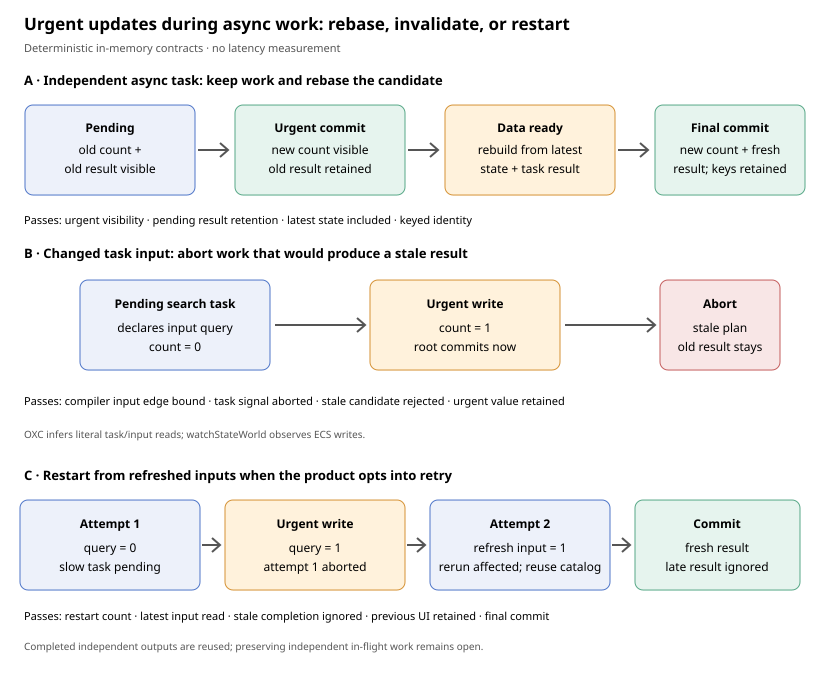

In [56]:
const {
  runAsyncVDOMUrgentRebaseExperiment,
  runAsyncVDOMDependencyInvalidationExperiment,
  runAsyncVDOMInputRestartExperiment,
} = await import("./src/async_vdom_urgent_rebase_experiment.ts");
const urgentRebaseRun = await runAsyncVDOMUrgentRebaseExperiment();
const dependencyInvalidationRun =
  await runAsyncVDOMDependencyInvalidationExperiment();
const inputRestartRun = await runAsyncVDOMInputRestartExperiment();
if (
  !urgentRebaseRun.contractsPass || !dependencyInvalidationRun.contractsPass ||
  !inputRestartRun.contractsPass
) {
  throw new Error("Urgent rebase, invalidation, or restart contract failed");
}
const urgentWorkPlanningRun = {
  schemaVersion: "async-vdom-urgent-work-planning-v2",
  status: "PASS",
  cases: {
    independentAsyncWorkRebase: urgentRebaseRun,
    changedTaskDependencyInvalidation: dependencyInvalidationRun,
    changedTaskDependencyRestart: inputRestartRun,
  },
  timingMeasured: false,
};
await Deno.writeTextFile(
  "results/async-vdom-urgent-work-planning-v2.json",
  JSON.stringify(urgentWorkPlanningRun, null, 2) + String.fromCharCode(10),
);
console.log(JSON.stringify(urgentWorkPlanningRun, null, 2));

const urgentWorkPlanningSvg = [
  '<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="700" viewBox="0 0 820 700" role="img" aria-labelledby="rebase-title rebase-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">',
  '<title id="rebase-title">Urgent state rebased, invalidated, or restarted during pending async UI</title>',
  '<desc id="rebase-desc">An urgent same-root write is immediately committed. Independent pending work is rebased. Dependent work can be canceled or restarted with refreshed inputs; stale results never publish.</desc>',
  '<rect width="100%" height="100%" fill="white"/>',
  '<text x="24" y="30" font-size="17" font-weight="700">Urgent updates during async work: rebase, invalidate, or restart</text>',
  '<text x="24" y="52" font-size="11" fill="#555">Deterministic in-memory contracts · no latency measurement</text>',
  '<text x="24" y="85" font-size="13" font-weight="700">A · Independent async task: keep work and rebase the candidate</text>',
  '<g font-size="12" text-anchor="middle">',
  '<rect x="25" y="105" width="170" height="90" rx="8" fill="#edf1fa" stroke="#4f76c8"/><text x="110" y="132" font-weight="700">Pending</text><text x="110" y="154">old count +</text><text x="110" y="173">old result visible</text>',
  '<path d="M198 150h30m-8-7 8 7-8 7" fill="none" stroke="#555" stroke-width="2"/>',
  '<rect x="235" y="105" width="170" height="90" rx="8" fill="#e6f4ee" stroke="#57a887"/><text x="320" y="132" font-weight="700">Urgent commit</text><text x="320" y="154">new count visible</text><text x="320" y="173">old result retained</text>',
  '<path d="M408 150h30m-8-7 8 7-8 7" fill="none" stroke="#555" stroke-width="2"/>',
  '<rect x="445" y="105" width="170" height="90" rx="8" fill="#fff2dc" stroke="#d59235"/><text x="530" y="132" font-weight="700">Data ready</text><text x="530" y="154">rebuild from latest</text><text x="530" y="173">state + task result</text>',
  '<path d="M618 150h30m-8-7 8 7-8 7" fill="none" stroke="#555" stroke-width="2"/>',
  '<rect x="655" y="105" width="150" height="90" rx="8" fill="#e6f4ee" stroke="#57a887"/><text x="730" y="132" font-weight="700">Final commit</text><text x="730" y="154">new count + fresh</text><text x="730" y="173">result; keys retained</text>',
  "</g>",
  '<text x="24" y="224" font-size="11">Passes: urgent visibility · pending result retention · latest state included · keyed identity</text>',
  '<text x="24" y="258" font-size="13" font-weight="700">B · Changed task input: abort work that would produce a stale result</text>',
  '<g font-size="12" text-anchor="middle">',
  '<rect x="80" y="280" width="190" height="90" rx="8" fill="#edf1fa" stroke="#4f76c8"/><text x="175" y="308" font-weight="700">Pending search task</text><text x="175" y="332">declares input query</text><text x="175" y="351">count = 0</text>',
  '<path d="M275 325h90m-8-7 8 7-8 7" fill="none" stroke="#555" stroke-width="2"/>',
  '<rect x="370" y="280" width="190" height="90" rx="8" fill="#fff2dc" stroke="#d59235"/><text x="465" y="308" font-weight="700">Urgent write</text><text x="465" y="332">count = 1</text><text x="465" y="351">root commits now</text>',
  '<path d="M565 325h90m-8-7 8 7-8 7" fill="none" stroke="#555" stroke-width="2"/>',
  '<rect x="660" y="280" width="120" height="90" rx="8" fill="#f8e6e6" stroke="#c45e5e"/><text x="720" y="308" font-weight="700">Abort</text><text x="720" y="332">stale plan</text><text x="720" y="351">old result stays</text>',
  "</g>",
  '<text x="24" y="405" font-size="11">Passes: compiler input edge bound · task signal aborted · stale candidate rejected · urgent value retained</text>',
  '<text x="24" y="438" font-size="10" fill="#555">OXC infers literal task/input reads; watchStateWorld observes ECS writes.</text>',
  '<text x="24" y="480" font-size="13" font-weight="700">C · Restart from refreshed inputs when the product opts into retry</text>',
  '<g font-size="12" text-anchor="middle">',
  '<rect x="20" y="500" width="180" height="90" rx="8" fill="#edf1fa" stroke="#4f76c8"/><text x="110" y="528" font-weight="700">Attempt 1</text><text x="110" y="552">query = 0</text><text x="110" y="571">slow task pending</text>',
  '<path d="M202 545h18m-8-7 8 7-8 7" fill="none" stroke="#555" stroke-width="2"/>',
  '<rect x="225" y="500" width="180" height="90" rx="8" fill="#fff2dc" stroke="#d59235"/><text x="315" y="528" font-weight="700">Urgent write</text><text x="315" y="552">query = 1</text><text x="315" y="571">attempt 1 aborted</text>',
  '<path d="M407 545h18m-8-7 8 7-8 7" fill="none" stroke="#555" stroke-width="2"/>',
  '<rect x="430" y="500" width="180" height="90" rx="8" fill="#edf1fa" stroke="#4f76c8"/><text x="520" y="528" font-weight="700">Attempt 2</text><text x="520" y="552">refresh input = 1</text><text x="520" y="571">rerun affected; reuse catalog</text>',
  '<path d="M612 545h18m-8-7 8 7-8 7" fill="none" stroke="#555" stroke-width="2"/>',
  '<rect x="635" y="500" width="165" height="90" rx="8" fill="#e6f4ee" stroke="#57a887"/><text x="717" y="528" font-weight="700">Commit</text><text x="717" y="552">fresh result</text><text x="717" y="571">late result ignored</text>',
  "</g>",
  '<text x="24" y="620" font-size="11">Passes: restart count · latest input read · stale completion ignored · previous UI retained · final commit</text>',
  '<text x="24" y="650" font-size="10" fill="#555">Completed independent outputs are reused; preserving independent in-flight work remains open.</text>',
  "</svg>",
];
Deno.jupyter.svg`${urgentWorkPlanningSvg.join("")}`;



### Experiment AJ — selective task reuse after async input invalidation

This microbenchmark compares the retry itself after an input changes. Each attempt first completes a query-dependent chain and independent leaf tasks while an unrelated async gate keeps the candidate pending. The changed query then aborts the attempt. The timed retry compares full recomputation with reuse of completed values outside the changed-input descendant closure.

The matrix varies graph size, the proportion of work downstream of the changed query, and deterministic CPU work per task. Strategy order alternates across paired repetitions. Every run verifies the changed chain and independent outputs. The archived JSON contains raw trial timings and task counts. This is a scheduler microbenchmark on one Deno process: it excludes plan preparation, host commit, React, browser presentation, and workers; results are diagnostic and not a user-visible speed claim.



{
  "schemaVersion": "async-task-reuse-cost-v1",
  "status": "PASS",
  "repetitions": 31,
  "cases": [
    {
      "totalTasks": 32,
      "changedPercent": 10,
      "workIterations": 0,
      "fullRestartMedianMs": 0.038457999999991443,
      "reuseMedianMs": 0.028208000000631728,
      "fullStarted": 32,
      "reuseStarted": 3,
      "reused": 29,
      "savedPercent": 26.652452023927392,
      "correctnessPass": true
    },
    {
      "totalTasks": 32,
      "changedPercent": 10,
      "workIterations": 2000,
      "fullRestartMedianMs": 0.9426249999996799,
      "reuseMedianMs": 0.0808340000003227,
      "fullStarted": 32,
      "reuseStarted": 3,
      "reused": 29,
      "savedPercent": 91.42458559868982,
      "correctnessPass": true
    },
    {
      "totalTasks": 32,
      "changedPercent": 50,
      "workIterations": 0,
      "fullRestartMedianMs": 0.024625000000014552,
      "reuseMedianMs": 0.024791999999251857,
      "fullStarted": 32,
      "reuseStarted": 16,
      "

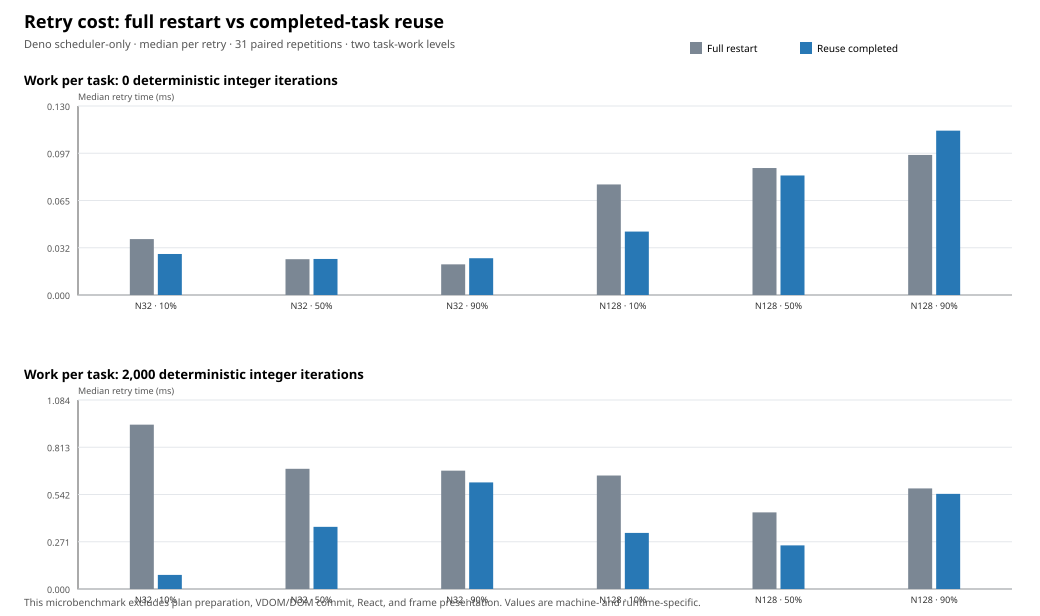

In [57]:
import { runAsyncTaskReuseBenchmark } from "./src/async_task_reuse_benchmark.ts";

const asyncTaskReuseCostRun = await runAsyncTaskReuseBenchmark();
if (asyncTaskReuseCostRun.status !== "PASS") {
  throw new Error("Async task reuse cost benchmark failed correctness checks");
}
await Deno.writeTextFile(
  "results/async-task-reuse-cost-v1.json",
  JSON.stringify(asyncTaskReuseCostRun, null, 2) + String.fromCharCode(10),
);
console.log(JSON.stringify(
  {
    schemaVersion: asyncTaskReuseCostRun.schemaVersion,
    status: asyncTaskReuseCostRun.status,
    repetitions: asyncTaskReuseCostRun.repetitions,
    cases: asyncTaskReuseCostRun.cases.map((entry) => ({
      totalTasks: entry.totalTasks,
      changedPercent: entry.changedPercent,
      workIterations: entry.workIterations,
      fullRestartMedianMs: entry.fullRestart.medianMs,
      reuseMedianMs: entry.reuseCompleted.medianMs,
      fullStarted: entry.fullRestart.medianStarted,
      reuseStarted: entry.reuseCompleted.medianStarted,
      reused: entry.reuseCompleted.medianReused,
      savedPercent: entry.medianTimeSavedPercent,
      correctnessPass: entry.correctnessPass,
    })),
  },
  null,
  2,
));

const chartWidth = 1040;
const panelHeight = 270;
const gap = 24;
const chartHeight = panelHeight * 2 + gap + 52;
const rows: string[] = [
  `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${chartHeight}" viewBox="0 0 ${chartWidth} ${chartHeight}" role="img" aria-labelledby="reuse-title reuse-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">`,
  '<title id="reuse-title">Async task restart cost with completed-task reuse</title>',
  '<desc id="reuse-desc">SVG grouped bars compare full restart and completed-task reuse medians for different task counts and changed-input descendant fractions.</desc>',
  '<rect width="100%" height="100%" fill="white"/>',
  '<text x="24" y="28" font-size="18" font-weight="700">Retry cost: full restart vs completed-task reuse</text>',
  '<text x="24" y="48" font-size="11" fill="#555">Deno scheduler-only · median per retry · 31 paired repetitions · two task-work levels</text>',
];
const colors = { full: "#7b8794", reuse: "#2878b5" };
for (const [panel, iterations] of [0, 2_000].entries()) {
  const selected = asyncTaskReuseCostRun.cases.filter((entry) =>
    entry.workIterations === iterations
  );
  const top = 70 + panel * (panelHeight + gap);
  const plotLeft = 78;
  const plotRight = chartWidth - 28;
  const plotTop = top + 36;
  const plotBottom = top + panelHeight - 45;
  const maxMs = Math.max(...selected.flatMap((entry) => [
        entry.fullRestart.medianMs,
        entry.reuseCompleted.medianMs,
      ]
      )) * 1.15 || 1;
  rows.push(
    `<text x="24" y="${
      top + 15
    }" font-size="13" font-weight="700">Work per task: ${iterations.toLocaleString()} deterministic integer iterations</text>`,
  );
  rows.push(
    `<path d="M${plotLeft} ${plotTop}V${plotBottom}H${plotRight}" fill="none" stroke="#555" stroke-width="1"/>`,
  );
  for (let tick = 0; tick <= 4; tick++) {
    const y = plotBottom - (plotBottom - plotTop) * tick / 4;
    const ms = maxMs * tick / 4;
    rows.push(
      `<path d="M${plotLeft} ${y}H${plotRight}" stroke="#e4e7eb" stroke-width="1"/>`,
    );
    rows.push(
      `<text x="${plotLeft - 8}" y="${
        y + 4
      }" text-anchor="end" font-size="9" fill="#555">${ms.toFixed(3)}</text>`,
    );
  }
  const step = (plotRight - plotLeft) / selected.length;
  selected.forEach((entry, index) => {
    const center = plotLeft + step * (index + 0.5);
    const barWidth = Math.min(24, step * 0.24);
    const fullHeight = (plotBottom - plotTop) * entry.fullRestart.medianMs /
      maxMs;
    const reuseHeight = (plotBottom - plotTop) * entry.reuseCompleted.medianMs /
      maxMs;
    rows.push(
      `<rect x="${center - barWidth - 2}" y="${
        plotBottom - fullHeight
      }" width="${barWidth}" height="${fullHeight}" fill="${colors.full}"/>`,
    );
    rows.push(
      `<rect x="${center + 2}" y="${
        plotBottom - reuseHeight
      }" width="${barWidth}" height="${reuseHeight}" fill="${colors.reuse}"/>`,
    );
    rows.push(
      `<text x="${center}" y="${
        plotBottom + 14
      }" text-anchor="middle" font-size="9" fill="#333">N${entry.totalTasks} · ${entry.changedPercent}%</text>`,
    );
  });
  rows.push(
    `<text x="${plotLeft}" y="${
      plotTop - 6
    }" font-size="9" fill="#555">Median retry time (ms)</text>`,
  );
}
rows.push(
  '<rect x="690" y="42" width="12" height="12" fill="#7b8794"/><text x="707" y="52" font-size="10">Full restart</text><rect x="800" y="42" width="12" height="12" fill="#2878b5"/><text x="817" y="52" font-size="10">Reuse completed</text>',
);
rows.push(
  `<text x="24" y="${
    chartHeight - 10
  }" font-size="10" fill="#555">This microbenchmark excludes plan preparation, VDOM/DOM commit, React, and frame presentation. Values are machine- and runtime-specific.</text>`,
);
rows.push("</svg>");
Deno.jupyter.svg`${rows.join("")}`;



### Experiment AK — browser retry with selective completed-task reuse

This 40-pair Chrome study measures the retry interval from an urgent query update to fresh DOM commit. React 19 with React Compiler keeps the old result visible, starts a newer query through one Suspense transition, and reuses an application-cached catalog value. The compiled runtime uses the OXC-emitted task/input DAG, observes an ECS state-site write, aborts the stale search task, and performs one bounded retry. Its full-restart arm recomputes the independent catalog task; its selective arm reuses that completed output. Pair order alternates across three arms and two deterministic catalog workloads.

All 40 samples pass output parity, old-content retention, keyed host identity, stale-result suppression, abort/restart, and task-count contracts. At zero catalog iterations, median update-to-commit is 7.9 ms for React, 8.4 ms for full restart, and 8.5 ms for reuse. At 250,000 integer-loop iterations, medians are 6.2, 7.7, and 8.6 ms. The paired median differences (graph minus React) are +0.6/+1.2 ms at zero work and +0.3/+1.1 ms at 250,000 iterations; reuse is faster in only 9/20 and 6/20 pairs respectively. The browser evidence therefore does not show a speed win for graph retry or completed-task reuse in this fixture, despite correctly avoiding one catalog recomputation.

Interpret cautiously: one Chrome 155 MacIntel session, programmatic state changes, synthetic deferred searches, and a small deterministic CPU-loop proxy. The measurement stops at host commit and excludes layout, paint, and frame presentation. React caches its independent catalog value in application code; the runtime selects it from the compiled DAG. React keeps the stale request in flight but transitions only to the latest query, while the runtime aborts the stale task after state invalidation. This is a narrow retry/commit comparison, not a general Suspense or whole-application performance result. Raw samples: `results/async-task-reuse-browser-v1-2026-10-10.json`.



{
  "schemaVersion": "async-task-reuse-browser-v1",
  "status": "PASS",
  "collectedAt": "2026-10-10T03:36:36.709Z",
  "browser": {
    "userAgent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/155.0.0.0 Safari/537.36",
    "platform": "MacIntel",
    "hardwareConcurrency": 10,
    "devicePixelRatio": 2
  },
  "sampleCount": 40,
  "allContractsPass": true,
  "summary": [
    {
      "workIterations": 0,
      "pairCount": 20,
      "values": {
        "react": {
          "medianMs": 7.9000000059604645,
          "p95Ms": 11.900000005960464
        },
        "fullRestart": {
          "medianMs": 8.400000005960464,
          "p95Ms": 9.400000005960464
        },
        "reuseCompleted": {
          "medianMs": 8.5,
          "p95Ms": 11.5
        }
      },
      "pairedDifferences": {
        "fullRestart": {
          "medianMs": 0.4999999850988388,
          "fasterPairs": 9,
          "tiedPairs": 0,
          "slowerPairs": 11
  

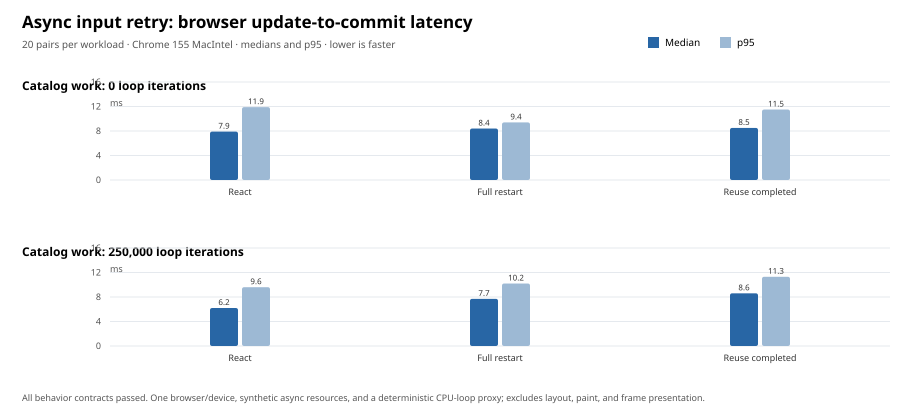

In [58]:
const browserRetryRun = JSON.parse(
  await Deno.readTextFile(
    "results/async-task-reuse-browser-v1-2026-10-10.json",
  ),
);
const arms = ["react", "fullRestart", "reuseCompleted"] as const;
const browserQuantile = (values: number[], probability: number) => {
  const ordered = [...values].sort((left, right) => left - right);
  return ordered[Math.max(0, Math.ceil(ordered.length * probability) - 1)];
};
const browserMedian = (values: number[]) => browserQuantile(values, 0.5);
if (
  browserRetryRun.schemaVersion !== "async-task-reuse-browser-v1" ||
  browserRetryRun.status !== "PASS" ||
  browserRetryRun.samples.length !== 40 ||
  !browserRetryRun.allContractsPass
) {
  throw new Error("Saved async retry browser study failed its contracts");
}
const browserRetrySummary = browserRetryRun.workIterations.map(
  (workIterations: number) => {
    const samples = browserRetryRun.samples.filter((sample: any) =>
      sample.workIterations === workIterations
    );
    if (samples.length !== 20) {
      throw new Error(`Expected 20 paired samples at work=${workIterations}`);
    }
    const values = Object.fromEntries(arms.map((arm) => {
      const times = samples.map((sample: any) => sample.updateToCommitMs[arm]);
      const medianMs = browserMedian(times);
      const p95Ms = browserQuantile(times, 0.95);
      if (
        Math.abs(
            medianMs - browserRetryRun.medianMs[String(workIterations)][arm],
          ) >
          1e-9 ||
        Math.abs(p95Ms - browserRetryRun.p95Ms[String(workIterations)][arm]) >
          1e-9
      ) {
        throw new Error(
          `Saved ${arm} summary drifted at work=${workIterations}`,
        );
      }
      return [arm, { medianMs, p95Ms }];
    })) as Record<string, { medianMs: number; p95Ms: number }>;
    const pairedDifferences = Object.fromEntries(
      (["fullRestart", "reuseCompleted"] as const).map((arm) => {
        const differences = samples.map((sample: any) =>
          sample.updateToCommitMs[arm] - sample.updateToCommitMs.react
        );
        return [arm, {
          medianMs: browserMedian(differences),
          fasterPairs: differences.filter((difference) => difference < 0)
            .length,
          tiedPairs: differences.filter((difference) => difference === 0)
            .length,
          slowerPairs: differences.filter((difference) => difference > 0)
            .length,
        }];
      }),
    );
    return {
      workIterations,
      pairCount: samples.length,
      values,
      pairedDifferences,
    };
  },
);
console.log(JSON.stringify(
  {
    schemaVersion: browserRetryRun.schemaVersion,
    status: browserRetryRun.status,
    collectedAt: browserRetryRun.collectedAt,
    browser: browserRetryRun.browser,
    sampleCount: browserRetryRun.samples.length,
    allContractsPass: browserRetryRun.allContractsPass,
    summary: browserRetrySummary,
    interpretation:
      "This single-session browser run found no update-to-commit speed advantage for graph retry or completed-result reuse. It verifies invalidation, output parity, pending UI retention, keyed identity, and independent catalog reuse; the deterministic catalog loop and one-device timing are narrow evidence.",
  },
  null,
  2,
));

const width = 920;
const height = 410;
const plotLeft = 110;
const plotRight = 890;
const panelTop = [82, 248];
const panelHeight = 126;
const maxMs = 16;
const plotHeight = 98;
const colors = {
  median: "#2866a5",
  p95: "#9db9d4",
};
const chart: string[] = [
  `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${height}" viewBox="0 0 ${width} ${height}" role="img" aria-labelledby="retry-browser-title retry-browser-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">`,
  `<title id="retry-browser-title">Browser retry update-to-commit latency</title>`,
  `<desc id="retry-browser-desc">Forty paired Chrome samples compare React, graph full restart, and graph reuse of a completed independent task, at zero and 250,000 catalog-loop iterations. Each arm is shown with median and p95 latency.</desc>`,
  `<rect width="100%" height="100%" fill="white"/>`,
  `<text x="22" y="28" font-size="17" font-weight="700">Async input retry: browser update-to-commit latency</text>`,
  `<text x="22" y="48" font-size="10" fill="#555">20 pairs per workload · Chrome 155 MacIntel · medians and p95 · lower is faster</text>`,
  `<rect x="648" y="37" width="11" height="11" fill="${colors.median}"/><text x="665" y="46" font-size="10">Median</text>`,
  `<rect x="720" y="37" width="11" height="11" fill="${colors.p95}"/><text x="737" y="46" font-size="10">p95</text>`,
];
for (const [panelIndex, entry] of browserRetrySummary.entries()) {
  const top = panelTop[panelIndex];
  const baseline = top + plotHeight;
  chart.push(
    `<text x="22" y="${
      top + 8
    }" font-size="12" font-weight="700">Catalog work: ${entry.workIterations.toLocaleString()} loop iterations</text>`,
  );
  for (let tick = 0; tick <= 4; tick++) {
    const ms = maxMs * tick / 4;
    const y = baseline - plotHeight * tick / 4;
    chart.push(
      `<path d="M${plotLeft} ${y}H${plotRight}" stroke="#e5e9ee" stroke-width="1"/>`,
      `<text x="${plotLeft - 9}" y="${
        y + 3
      }" text-anchor="end" font-size="9" fill="#555">${ms}</text>`,
    );
  }
  const groupStep = (plotRight - plotLeft) / arms.length;
  arms.forEach((arm, armIndex) => {
    const center = plotLeft + groupStep * (armIndex + 0.5);
    const values = entry.values[arm];
    const barWidth = 28;
    for (const [metricIndex, metric] of ["medianMs", "p95Ms"].entries()) {
      const value = values[metric];
      const barHeight = plotHeight * value / maxMs;
      const x = center + (metricIndex === 0 ? -barWidth - 2 : 2);
      chart.push(
        `<rect x="${x}" y="${
          baseline - barHeight
        }" width="${barWidth}" height="${barHeight}" rx="2" fill="${
          metricIndex === 0 ? colors.median : colors.p95
        }"/>`,
        `<text x="${x + barWidth / 2}" y="${
          baseline - barHeight - 3
        }" text-anchor="middle" font-size="8" fill="#333">${
          value.toFixed(1)
        }</text>`,
      );
    }
    const label = arm === "react"
      ? "React"
      : arm === "fullRestart"
      ? "Full restart"
      : "Reuse completed";
    chart.push(
      `<text x="${center}" y="${
        baseline + 15
      }" text-anchor="middle" font-size="9" fill="#333">${label}</text>`,
    );
  });
  chart.push(
    `<text x="${plotLeft}" y="${top + 24}" font-size="9" fill="#555">ms</text>`,
  );
}
chart.push(
  `<text x="22" y="${
    height - 9
  }" font-size="9" fill="#555">All behavior contracts passed. One browser/device, synthetic async resources, and a deterministic CPU-loop proxy; excludes layout, paint, and frame presentation.</text>`,
  `</svg>`,
);
Deno.jupyter.svg`${chart.join("")}`;



### Experiment AL — frame-cadence follow-up for keyed region updates

This follow-up adds a rendering-opportunity measure to the existing 10,000-row, two-region comparison. React 19.3 with React Compiler uses memoized region components; the handwritten VDOM rebuilds both regions; the OXC region graph derives and commits only the region reached by the changed query. Each of 24 timed pairs presents the same eight alternating query changes to all three arms, with one synchronous update between animation-frame callbacks. Six warmup pairs precede measurement, and all intermediate DOM digests must match. The isolated protocol connects only the active arm's keyed lists to the document; equal-size empty placeholders preserve the three panel layouts while removing inactive lists from layout and paint.

The study measures both synchronous update duration and the interval from the rAF callback before an update to the next callback. It samples 120 idle intervals first, flags update intervals above 1.5× the idle median, and estimates missed opportunities from the ratio to that median. The harness now asserts and records which arm is connected before every sequence. This is an rAF cadence proxy: it includes browser rendering work that delays the next callback, but it does not confirm that a frame was presented by the compositor or display. Earlier simultaneous-panel records and the first isolated record, which predates the stored assertion, remain in the archive but are excluded from the verified-isolation chart. Results remain descriptive for this fixture and browser/device.

Raw isolated browser runs are stored under `results/keyed-region-frame-pacing-isolated-v1-*.json`. The SVGs below compare p50 and p95 update duration and rAF interval for isolated runs that include all per-sequence connection assertions. The tails remain unexplained; a single profile cannot attribute them to the environment, framework, garbage collection, or measurement work. This is an initial responsiveness probe, not a general React performance claim.



{
  "protocol": "isolated; 24 paired samples × 8 transitions × 3 arms",
  "isolatedRuns": 1,
  "preAssertionOrSimultaneousRunsExcluded": 5,
  "isolatedRunsWithoutStoredChecksExcluded": 1,
  "frameMetrics": [
    {
      "run": 1,
      "file": "keyed-region-frame-pacing-isolated-v1-1791634209289.json",
      "pageLoadId": "9b6b5433-abdb-4847-88fe-eaa6cb8c08b9",
      "visibility": "visible",
      "idleMedianMs": 8.399999999997817,
      "idleP95Ms": 16.900000000001455,
      "idleMaxMs": 55.75,
      "arms": {
        "react": {
          "updateP50Ms": 18.299999997019768,
          "updateP95Ms": 485,
          "rAFP50Ms": 83.5,
          "rAFP95Ms": 725.8999999999942,
          "pairedMedianDeltaMs": 0,
          "pairedWinCount": 0,
          "aboveBaselineCount": 177,
          "intervalCount": 192
        },
        "handwritten": {
          "updateP50Ms": 57.20000000298023,
          "updateP95Ms": 176.80000001192093,
          "rAFP50Ms": 100,
          "rAFP95Ms": 733.6000000

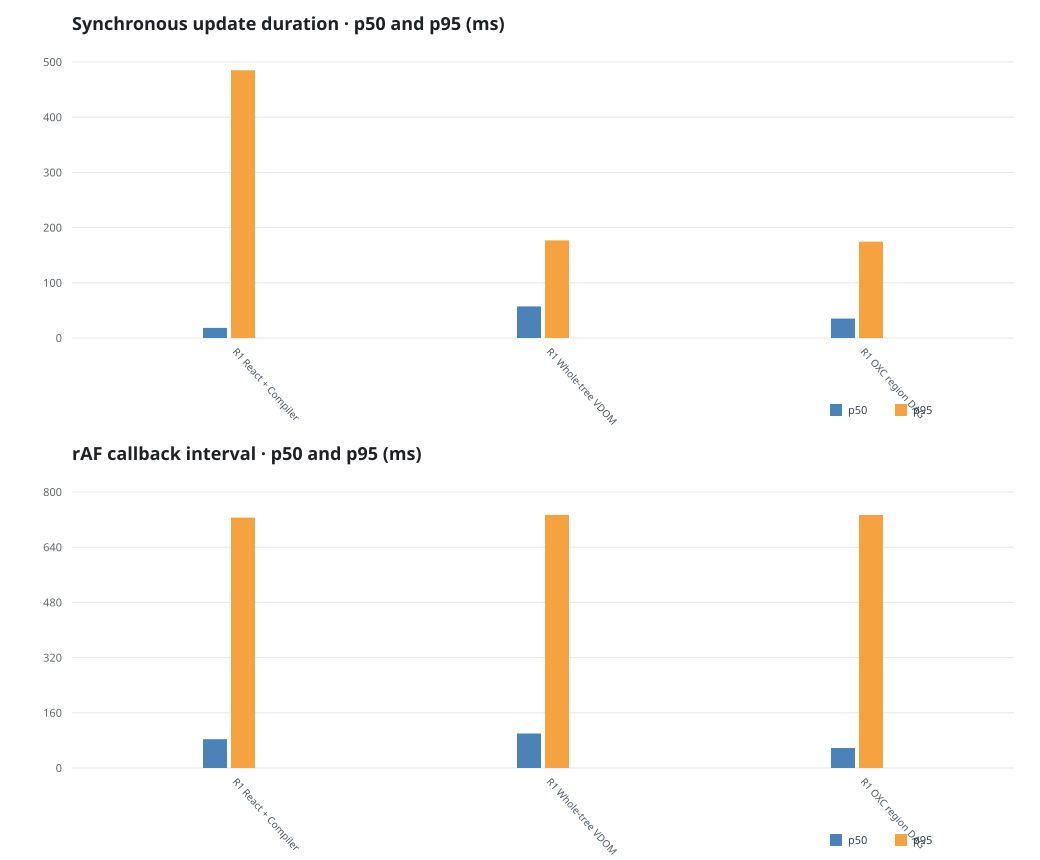

In [59]:
const frameArms = ["react", "handwritten", "compiled"] as const;
const frameLabels: Record<(typeof frameArms)[number], string> = {
  react: "React + Compiler",
  handwritten: "Whole-tree VDOM",
  compiled: "OXC region DAG",
};
const frameFiles: string[] = [];
for await (const entry of Deno.readDir("results")) {
  if (
    entry.isFile && entry.name.startsWith("keyed-region-frame-pacing-") &&
    entry.name.endsWith(".json")
  ) {
    frameFiles.push(entry.name);
  }
}
frameFiles.sort();
const allFrameRuns = await Promise.all(
  frameFiles.map(async (file) => ({
    ...JSON.parse(await Deno.readTextFile(`results/${file}`)),
    file,
  })),
);
const isolatedFrameRuns = allFrameRuns.filter((run) =>
  run.schemaVersion === "keyed-region-frame-pacing-isolated-v1"
);
const frameRuns = isolatedFrameRuns.filter((run) =>
  Number.isInteger(run.isolationChecksPassed)
);
if (frameRuns.length === 0) {
  throw new Error("No isolated keyed-region frame pacing records found");
}
for (const run of frameRuns) {
  if (
    run.schemaVersion !== "keyed-region-frame-pacing-isolated-v1" ||
    run.status !== "PASS" || run.samples.length !== 24 || !run.allOutputsEqual
  ) {
    throw new Error(`Invalid frame pacing record: ${run.pageLoadId}`);
  }
  if (
    run.isolationChecksPassed !== run.timedPairs * frameArms.length ||
    run.samples.some((sample: any) =>
      frameArms.some((arm) =>
        sample.isolationChecks?.[arm]?.length !== 1 ||
        sample.isolationChecks[arm][0] !== arm
      )
    )
  ) {
    throw new Error(`Frame isolation contract failed: ${run.pageLoadId}`);
  }
  if (
    run.samples.some((sample: any) =>
      !sample.sameOutput || sample.transitionsCompared !== 8
    )
  ) {
    throw new Error(`Frame output contract failed: ${run.pageLoadId}`);
  }
}
const frameQuantile = (values: number[], p: number) => {
  const sorted = [...values].sort((a, b) => a - b);
  return sorted[Math.max(0, Math.ceil(p * sorted.length) - 1)];
};
const frameMetrics = frameRuns.map((run, runIndex) => {
  const arms = Object.fromEntries(frameArms.map((arm) => {
    const updateMs = run.samples.flatMap((sample: any) =>
      sample.arms[arm].updateMs
    );
    const rAFIntervalMs = run.samples.flatMap((sample: any) =>
      sample.arms[arm].rAFIntervalMs
    );
    const pairedMedianDelta = run.samples.map((sample: any) =>
      frameQuantile(sample.arms[arm].rAFIntervalMs, 0.5) -
      frameQuantile(sample.arms.react.rAFIntervalMs, 0.5)
    );
    return [arm, {
      updateP50Ms: frameQuantile(updateMs, 0.5),
      updateP95Ms: frameQuantile(updateMs, 0.95),
      rAFP50Ms: frameQuantile(rAFIntervalMs, 0.5),
      rAFP95Ms: frameQuantile(rAFIntervalMs, 0.95),
      pairedMedianDeltaMs: frameQuantile(pairedMedianDelta, 0.5),
      pairedWinCount: run.samples.filter((sample: any) =>
        frameQuantile(sample.arms[arm].rAFIntervalMs, 0.5) <
          frameQuantile(sample.arms.react.rAFIntervalMs, 0.5)
      ).length,
      aboveBaselineCount: rAFIntervalMs.filter((value: number) =>
        value > run.idleFrameBaseline.medianMs * 1.5
      ).length,
      intervalCount: rAFIntervalMs.length,
    }];
  })) as Record<(typeof frameArms)[number], Record<string, number>>;
  return {
    run: runIndex + 1,
    file: run.file,
    pageLoadId: run.pageLoadId,
    visibility: run.browser.visibilityState,
    idleMedianMs: run.idleFrameBaseline.medianMs,
    idleP95Ms: run.idleFrameBaseline.p95Ms,
    idleMaxMs: run.idleFrameBaseline.maxMs,
    arms,
  };
});
console.log(
  JSON.stringify(
    {
      protocol: "isolated; 24 paired samples × 8 transitions × 3 arms",
      isolatedRuns: frameRuns.length,
      preAssertionOrSimultaneousRunsExcluded: allFrameRuns.length -
        frameRuns.length,
      isolatedRunsWithoutStoredChecksExcluded: isolatedFrameRuns.length -
        frameRuns.length,
      frameMetrics,
    },
    null,
    2,
  ),
);

const makeFrameSvg = (metric: "update" | "raf") => {
  const width = 1040;
  const height = 430;
  const left = 72;
  const right = 26;
  const top = 62;
  const bottom = 92;
  const plotHeight = height - top - bottom;
  const groups = frameMetrics.flatMap((run) =>
    frameArms.map((arm) => ({
      run: run.run,
      arm,
      label: `R${run.run} ${frameLabels[arm]}`,
      p50: run.arms[arm][metric === "update" ? "updateP50Ms" : "rAFP50Ms"],
      p95: run.arms[arm][metric === "update" ? "updateP95Ms" : "rAFP95Ms"],
    }))
  );
  const maxValue = Math.max(...groups.map((group) => group.p95));
  const axisMax = Math.ceil(maxValue / (maxValue > 100 ? 100 : 10)) *
    (maxValue > 100 ? 100 : 10);
  const plotWidth = width - left - right;
  const groupWidth = plotWidth / groups.length;
  const y = (value: number) => top + plotHeight - value / axisMax * plotHeight;
  const parts = [
    `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="430" viewBox="0 0 ${width} ${height}" role="img" aria-label="${
      metric === "update"
        ? "Synchronous update time"
        : "RequestAnimationFrame callback interval"
    } p50 and p95 by arm and run" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">`,
    `<rect width="${width}" height="${height}" fill="#fff"/>`,
    `<text x="${left}" y="30" font-size="18" font-weight="700" fill="#202124">${
      metric === "update"
        ? "Synchronous update duration"
        : "rAF callback interval"
    } · p50 and p95 (ms)</text>`,
  ];
  for (let tick = 0; tick <= 5; tick++) {
    const value = axisMax * tick / 5;
    const yy = y(value);
    parts.push(
      `<line x1="${left}" y1="${yy}" x2="${
        width - right
      }" y2="${yy}" stroke="#e5e7eb"/>`,
    );
    parts.push(
      `<text x="${left - 10}" y="${
        yy + 4
      }" text-anchor="end" font-size="11" fill="#5f6368">${
        value.toFixed(0)
      }</text>`,
    );
  }
  const barWidth = Math.min(24, groupWidth * 0.22);
  groups.forEach((group, index) => {
    const center = left + groupWidth * (index + 0.5);
    const p50Y = y(group.p50);
    const p95Y = y(group.p95);
    parts.push(
      `<rect x="${
        center - barWidth - 2
      }" y="${p50Y}" width="${barWidth}" height="${
        top + plotHeight - p50Y
      }" fill="#4b82b8"><title>${group.label} p50: ${
        group.p50.toFixed(1)
      } ms</title></rect>`,
    );
    parts.push(
      `<rect x="${center + 2}" y="${p95Y}" width="${barWidth}" height="${
        top + plotHeight - p95Y
      }" fill="#f4a340"><title>${group.label} p95: ${
        group.p95.toFixed(1)
      } ms</title></rect>`,
    );
    parts.push(
      `<text transform="translate(${center + 3},${
        top + plotHeight + 14
      }) rotate(48)" font-size="10" fill="#4b5563">${group.label}</text>`,
    );
  });
  parts.push(
    `<rect x="${width - 210}" y="${
      height - 26
    }" width="12" height="12" fill="#4b82b8"/><text x="${width - 192}" y="${
      height - 16
    }" font-size="11" fill="#374151">p50</text><rect x="${width - 145}" y="${
      height - 26
    }" width="12" height="12" fill="#f4a340"/><text x="${width - 127}" y="${
      height - 16
    }" font-size="11" fill="#374151">p95</text>`,
  );
  parts.push("</svg>");
  return parts.join("");
};
const asFrameGroup = (svg: string, transform = "") =>
  svg.replace(
    /^<svg[^>]*>/,
    `<g${transform ? ` transform="${transform}"` : ""}>`,
  )
    .replace(/<\/svg>$/, "</g>");
const combinedFrameSvg =
  `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="860" viewBox="0 0 1040 860" role="img" aria-label="Synchronous update and requestAnimationFrame interval p50 and p95 by arm and run" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">${
    asFrameGroup(makeFrameSvg("update"))
  }${asFrameGroup(makeFrameSvg("raf"), "translate(0 430)")}</svg>`;
Deno.jupyter.svg`${combinedFrameSvg}`;



### Experiment AM — frame cadence and Long Animation Frame attribution

This follow-up repeats the isolated 10,000-row cadence protocol while observing Chrome's `long-animation-frame` PerformanceObserver entries. LoAF entries represent UI-thread work sequences longer than 50 ms and expose script attribution plus rendering-phase timestamps where available. The observer starts after the idle baseline; captured entries are associated with measured update windows by timestamp overlap. That association is approximate: one long entry can overlap more than one measured window, and the API's duration excludes display presentation.

The browser harness asserts connected-arm isolation and output parity as in Experiment AL. The observer runs only in this attribution arm, so its timing results are reported separately from the uninstrumented cadence runs. Missing script attribution does not prove there was no JavaScript: browser privacy rules and opaque scripts can hide it. A LoAF with no scripts can also point toward rendering or other main-thread work. The SVG charts show how often measured windows overlap LoAF entries and the p95 duration of associated entries; the accompanying JSON summary lists script attribution. One device and one page load remain exploratory evidence.

Raw attribution records: `results/keyed-region-frame-pacing-attribution-v1-*.json`. The cell recomputes all per-arm summaries from these records and emits SVG-only charts. References: [W3C Long Animation Frames specification](https://www.w3.org/TR/long-animation-frames/) and [Chrome's Long Animation Frames guide](https://developer.chrome.com/docs/web-platform/long-animation-frames).



{
  "protocol": "isolated; 24 pairs × 8 transitions × 3 arms; LoAF observer",
  "attributionMetrics": [
    {
      "run": 1,
      "file": "keyed-region-frame-pacing-attribution-v1-1791669251661.json",
      "pageLoadId": "7d3505af-d3a5-4333-9b48-b746b8f0a59b",
      "observerSupported": true,
      "observerEntries": 224,
      "idleMedianMs": 8.30000000000291,
      "arms": {
        "react": {
          "measuredWindows": 192,
          "windowsWithLoAF": 82,
          "uniqueFrames": 82,
          "durationMedianMs": 149.5,
          "durationP95Ms": 239.5,
          "durationMaxMs": 310.40000000596046,
          "blockingDurationP95Ms": 186.2,
          "topScripts": [
            {
              "key": "#FrameRequestCallback",
              "sourceURL": "",
              "sourceFunctionName": "",
              "invoker": "FrameRequestCallback",
              "duration": 11410.99999988079
            }
          ]
        },
        "handwritten": {
          "measuredWindows": 1

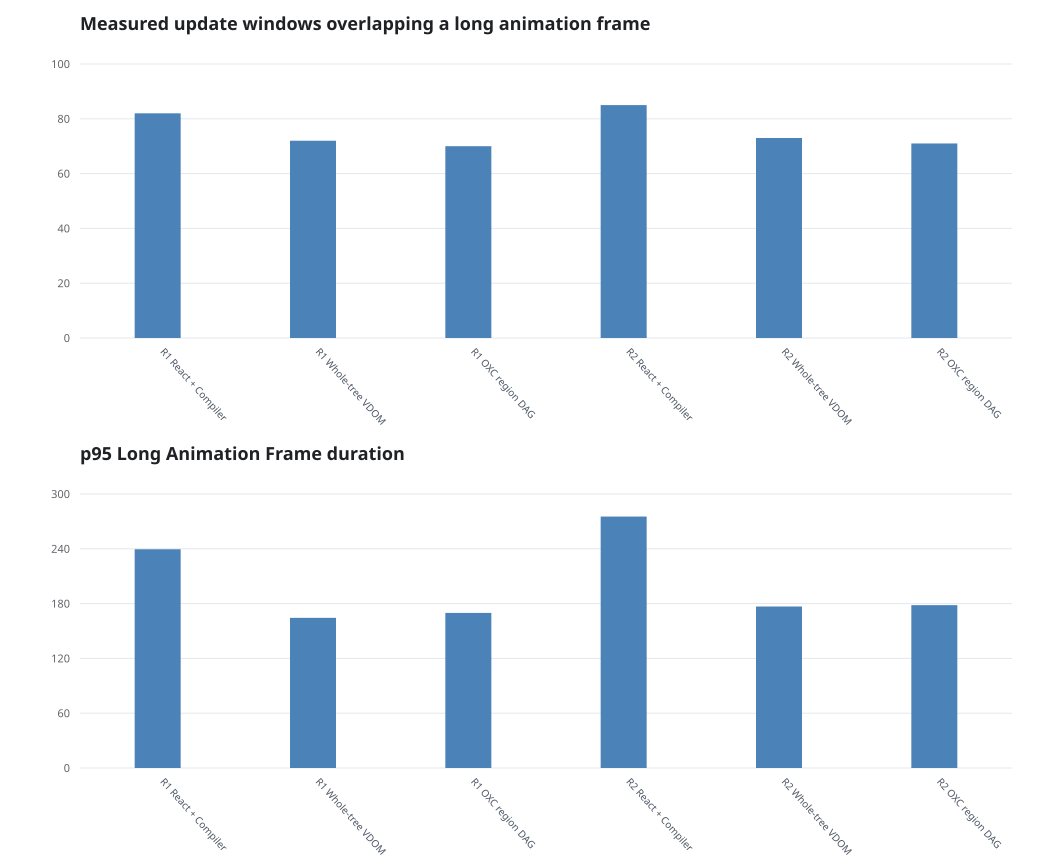

In [60]:
const attributionFiles: string[] = [];
for await (const entry of Deno.readDir("results")) {
  if (
    entry.isFile &&
    entry.name.startsWith("keyed-region-frame-pacing-attribution-v1-") &&
    entry.name.endsWith(".json")
  ) attributionFiles.push(entry.name);
}
attributionFiles.sort();
const attributionRuns = await Promise.all(
  attributionFiles.map(async (file) => ({
    ...JSON.parse(await Deno.readTextFile(`results/${file}`)),
    file,
  })),
);
if (attributionRuns.length === 0) {
  throw new Error("No Long Animation Frame attribution records found");
}
const attributionArms = ["react", "handwritten", "compiled"] as const;
const attributionLabels: Record<(typeof attributionArms)[number], string> = {
  react: "React + Compiler",
  handwritten: "Whole-tree VDOM",
  compiled: "OXC region DAG",
};
const attributionQuantile = (values: number[], p: number) => {
  const sorted = [...values].sort((a, b) => a - b);
  return sorted.length
    ? sorted[Math.max(0, Math.ceil(p * sorted.length) - 1)]
    : null;
};
const attributionMetrics = attributionRuns.map((run, runIndex) => {
  if (
    run.schemaVersion !== "keyed-region-frame-pacing-attribution-v1" ||
    run.status !== "PASS" || run.timedPairs !== 24 ||
    run.transitionsPerArmPerPair !== 8 || !run.allOutputsEqual ||
    !run.longAnimationFrameCapture?.supported ||
    !Array.isArray(run.longAnimationFrameCapture.matchedFrames)
  ) throw new Error(`Invalid LoAF attribution record: ${run.pageLoadId}`);
  if (
    run.isolationChecksPassed !== run.timedPairs * attributionArms.length ||
    run.samples.some((sample: any) =>
      !sample.sameOutput || sample.transitionsCompared !== 8 ||
      attributionArms.some((arm) =>
        sample.isolationChecks?.[arm]?.length !== 1 ||
        sample.isolationChecks[arm][0] !== arm
      )
    )
  ) throw new Error(`Parity/isolation contract failed: ${run.pageLoadId}`);

  const frames = run.longAnimationFrameCapture.matchedFrames;
  const arms = Object.fromEntries(attributionArms.map((arm) => {
    const matchedFrames = frames.filter((frame: any) =>
      frame.matches.some((match: any) => match.arm === arm)
    );
    const windowsWithLoAF = new Set(
      matchedFrames.flatMap((frame: any) =>
        frame.matches.filter((match: any) => match.arm === arm).map((
          match: any,
        ) => `${match.pair}:${match.transition}`)
      ),
    ).size;
    const scriptTotals = new Map<string, {
      key: string;
      sourceURL: string;
      sourceFunctionName: string;
      invoker: string;
      duration: number;
    }>();
    for (const frame of matchedFrames) {
      for (const script of frame.scripts ?? []) {
        const key = `${script.sourceURL}#${
          script.sourceFunctionName || script.invoker
        }`;
        const prior = scriptTotals.get(key);
        scriptTotals.set(key, {
          key,
          sourceURL: script.sourceURL,
          sourceFunctionName: script.sourceFunctionName,
          invoker: script.invoker,
          duration: (prior?.duration ?? 0) + script.duration,
        });
      }
    }
    return [arm, {
      measuredWindows: run.timedPairs * run.transitionsPerArmPerPair,
      windowsWithLoAF,
      uniqueFrames: matchedFrames.length,
      durationMedianMs: attributionQuantile(
        matchedFrames.map((frame: any) => frame.duration),
        0.5,
      ),
      durationP95Ms: attributionQuantile(
        matchedFrames.map((frame: any) => frame.duration),
        0.95,
      ),
      durationMaxMs: matchedFrames.length
        ? Math.max(...matchedFrames.map((frame: any) => frame.duration))
        : null,
      blockingDurationP95Ms: attributionQuantile(
        matchedFrames.map((frame: any) => frame.blockingDuration),
        0.95,
      ),
      topScripts: [...scriptTotals.values()].sort((a, b) =>
        b.duration - a.duration
      )
        .slice(0, 8),
    }];
  })) as Record<(typeof attributionArms)[number], Record<string, any>>;
  return {
    run: runIndex + 1,
    file: run.file,
    pageLoadId: run.pageLoadId,
    observerSupported: run.longAnimationFrameCapture.supported,
    observerEntries: run.longAnimationFrameCapture.matchedFrames.length,
    idleMedianMs: run.idleFrameBaseline.medianMs,
    arms,
  };
});
console.log(
  JSON.stringify(
    {
      protocol: "isolated; 24 pairs × 8 transitions × 3 arms; LoAF observer",
      attributionMetrics,
    },
    null,
    2,
  ),
);

const makeAttributionSvg = (metric: "windowsWithLoAF" | "durationP95Ms") => {
  const width = 1040;
  const height = 430;
  const left = 80;
  const right = 28;
  const top = 64;
  const bottom = 92;
  const plotHeight = height - top - bottom;
  const groups = attributionMetrics.flatMap((run) =>
    attributionArms.map((arm) => ({
      label: `R${run.run} ${attributionLabels[arm]}`,
      value: run.arms[arm][metric] ?? 0,
    }))
  );
  const maxValue = Math.max(1, ...groups.map((group) => group.value));
  const axisMax = metric === "windowsWithLoAF"
    ? Math.ceil(maxValue / 20) * 20
    : Math.ceil(maxValue / 100) * 100;
  const plotWidth = width - left - right;
  const groupWidth = plotWidth / groups.length;
  const y = (value: number) => top + plotHeight - value / axisMax * plotHeight;
  const title = metric === "windowsWithLoAF"
    ? "Measured update windows overlapping a long animation frame"
    : "p95 Long Animation Frame duration";
  const parts = [
    `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="430" viewBox="0 0 ${width} ${height}" role="img" aria-label="${title}" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">`,
    `<rect width="${width}" height="${height}" fill="#fff"/>`,
    `<text x="${left}" y="30" font-size="18" font-weight="700" fill="#202124">${title}</text>`,
  ];
  for (let tick = 0; tick <= 5; tick++) {
    const value = axisMax * tick / 5;
    const yy = y(value);
    parts.push(
      `<line x1="${left}" y1="${yy}" x2="${
        width - right
      }" y2="${yy}" stroke="#e5e7eb"/>`,
    );
    parts.push(
      `<text x="${left - 10}" y="${
        yy + 4
      }" text-anchor="end" font-size="11" fill="#5f6368">${
        value.toFixed(0)
      }</text>`,
    );
  }
  groups.forEach((group, index) => {
    const center = left + groupWidth * (index + 0.5);
    const barY = y(group.value);
    const barWidth = Math.min(46, groupWidth * 0.42);
    parts.push(
      `<rect x="${
        center - barWidth / 2
      }" y="${barY}" width="${barWidth}" height="${
        top + plotHeight - barY
      }" fill="#4b82b8"><title>${group.label}: ${group.value}</title></rect>`,
    );
    parts.push(
      `<text transform="translate(${center + 2},${
        top + plotHeight + 14
      }) rotate(48)" font-size="10" fill="#4b5563">${group.label}</text>`,
    );
  });
  parts.push("</svg>");
  return parts.join("");
};
const asAttributionGroup = (svg: string, transform = "") =>
  svg.replace(
    /^<svg[^>]*>/,
    `<g${transform ? ` transform="${transform}"` : ""}>`,
  )
    .replace(/<\/svg>$/, "</g>");
const combinedAttributionSvg =
  `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="860" viewBox="0 0 1040 860" role="img" aria-label="Long Animation Frame overlap and p95 duration by arm" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">${
    asAttributionGroup(makeAttributionSvg("windowsWithLoAF"))
  }${
    asAttributionGroup(makeAttributionSvg("durationP95Ms"), "translate(0 430)")
  }</svg>`;
Deno.jupyter.svg`${combinedAttributionSvg}`;



### Experiment AN — component topology at fixed DOM size

This follow-up holds the 10,000-span host DOM, target leaf update, and timing protocol constant while changing only component topology: flat, 10 groups of 1,000 leaves, 100 groups of 100, or 1,000 groups of 10. Each group returns a Fragment, so it contributes no host DOM nodes. React uses keyed function components returning React Fragments; the runtime uses keyed registered components returning runtime Fragments.

The [predeclared run schedule](./results/browser-component-state-tree-shape-schedule-v1.json) interleaves all four topologies over three rounds with fixed seeds. The validated production summary reports three page-load medians per topology; the SVG whiskers show each topology's min–max page median. Forty paired samples and 100 updates per pair are nested observations, not independent page replications. Every page passed full output parity, stable target identity, one leaf render per update, zero group renders per update, and one runtime partial commit per update. The study isolates this component-tree grouping in one leaf-local workload; it does not establish general React scaling behavior or identify every internal source of cost.



[
  {
    "topology": "Flat",
    "medianMs": {
      "react": 15.114000000059605,
      "runtime": 0.012000000178813934
    },
    "pageMedianRangeMs": {
      "react": [
        14.00600000023842,
        15.626999999880791
      ],
      "runtime": [
        0.012000000178813934,
        0.01300000011920929
      ]
    },
    "medianPageP95Ms": {
      "react": 15.482999999821185,
      "runtime": 0.017000000178813934
    },
    "medianPerPageSpeedup": 1202.0769120447735,
    "pairedSampleWins": {
      "runtime": 120,
      "react": 0,
      "ties": 0,
      "total": 120
    }
  },
  {
    "topology": "10 × 1,000",
    "medianMs": {
      "react": 13.585,
      "runtime": 0.01199999988079071
    },
    "pageMedianRangeMs": {
      "react": [
        13.139000000059605,
        14.032999999821186
      ],
      "runtime": [
        0.01199999988079071,
        0.012000000178813934
      ]
    },
    "medianPageP95Ms": {
      "react": 14.134000000059604,
      "runtime": 0.016999999

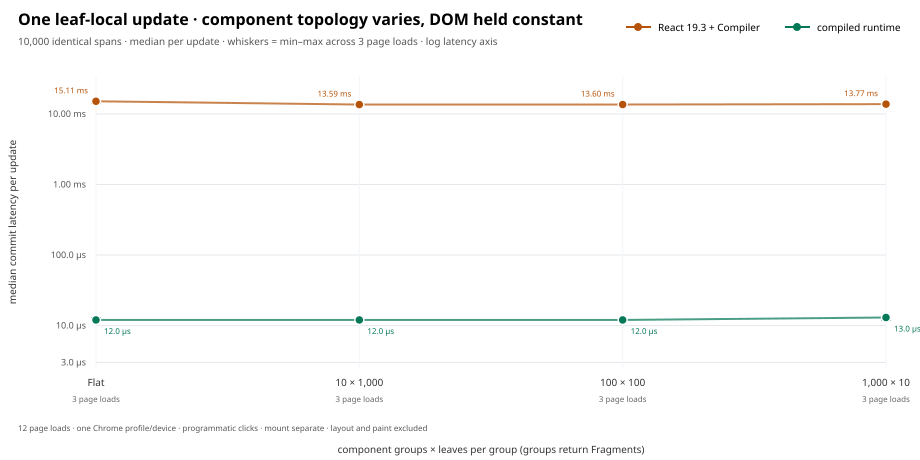

In [61]:
const treeShapeSummary = JSON.parse(
  await Deno.readTextFile(
    "results/browser-component-state-tree-shape-summary-v1.json",
  ),
);
if (
  treeShapeSummary.status !== "PASS" ||
  treeShapeSummary.scenarios.length !== 4 ||
  treeShapeSummary.scenarios.some((row: any) => !row.contractsPass)
) {
  throw new Error("Tree-shape browser comparison failed its contracts");
}
const rows = treeShapeSummary.scenarios;
const svgWidth = 920;
const svgHeight = 460;
const left = 96;
const right = 34;
const top = 76;
const bottom = 92;
const plotWidth = svgWidth - left - right;
const plotHeight = svgHeight - top - bottom;
const allValues = rows.flatMap((
  row: any,
) => [row.pageMedianRangeMs.react[0], row.pageMedianRangeMs.runtime[0]]);
const minY = Math.min(0.003, ...allValues) / 1.2;
const maxY = Math.max(
  30,
  ...rows.flatMap((
    row: any,
  ) => [row.pageMedianRangeMs.react[1], row.pageMedianRangeMs.runtime[1]]),
) * 1.15;
const logMin = Math.log10(minY);
const logMax = Math.log10(maxY);
const y = (value: number) =>
  top + (logMax - Math.log10(value)) / (logMax - logMin) * plotHeight;
const x = (index: number) => left + (index / (rows.length - 1)) * plotWidth;
const fmt = (value: number) =>
  value < 1 ? `${(value * 1000).toFixed(1)} µs` : `${value.toFixed(2)} ms`;
const svg = [
  `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${svgHeight}" viewBox="0 0 ${svgWidth} ${svgHeight}" role="img" aria-labelledby="tree-shape-title tree-shape-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">`,
  `<title id="tree-shape-title">Leaf-local update latency across component tree shapes</title>`,
  `<desc id="tree-shape-desc">Logarithmic chart comparing React Compiler and compiled runtime medians for flat, ten, one hundred, and one thousand Fragment-only component groups. The DOM remains 10,000 spans in every case. Whiskers show min to max across three page-load medians.</desc>`,
  `<rect width="100%" height="100%" fill="white"/>`,
  `<text x="18" y="25" font-size="16" font-weight="700">One leaf-local update · component topology varies, DOM held constant</text>`,
  `<text x="18" y="45" font-size="10" fill="#555">10,000 identical spans · median per update · whiskers = min–max across 3 page loads · log latency axis</text>`,
  `<line x1="626" y1="27" x2="651" y2="27" stroke="#b45309" stroke-width="2"/><circle cx="638" cy="27" r="4" fill="#b45309"/><text x="658" y="31" font-size="10">React 19.3 + Compiler</text>`,
  `<line x1="785" y1="27" x2="810" y2="27" stroke="#047857" stroke-width="2"/><circle cx="797" cy="27" r="4" fill="#047857"/><text x="817" y="31" font-size="10">compiled runtime</text>`,
];
const ticks = [0.003, 0.01, 0.1, 1, 10, 100].filter((value) =>
  value >= minY && value <= maxY
);
for (const tick of ticks) {
  const yy = y(tick);
  svg.push(
    `<line x1="${left}" y1="${yy}" x2="${
      svgWidth - right
    }" y2="${yy}" stroke="#e5e7eb"/><text x="${left - 10}" y="${
      yy + 3
    }" text-anchor="end" font-size="9" fill="#555">${fmt(tick)}</text>`,
  );
}
for (const [index, row] of rows.entries()) {
  const xx = x(index);
  svg.push(
    `<line x1="${xx}" y1="${top}" x2="${xx}" y2="${
      svgHeight - bottom
    }" stroke="#f1f5f9"/><text x="${xx}" y="${
      svgHeight - bottom + 18
    }" text-anchor="middle" font-size="10" fill="#333">${row.label}</text><text x="${xx}" y="${
      svgHeight - bottom + 34
    }" text-anchor="middle" font-size="8" fill="#666">${row.pageLoadReplications} page loads</text>`,
  );
}
for (
  const [arm, color] of [["react", "#b45309"], ["runtime", "#047857"]] as const
) {
  const points = rows.map((row: any, index: number) =>
    `${x(index)},${y(row.medianMs[arm])}`
  ).join(" ");
  svg.push(
    `<polyline points="${points}" fill="none" stroke="${color}" stroke-width="2" opacity="0.72"/>`,
  );
  for (const [index, row] of rows.entries()) {
    const xx = x(index);
    const value = row.medianMs[arm];
    const range = row.pageMedianRangeMs[arm];
    const yy = y(value);
    svg.push(
      `<line x1="${xx}" y1="${y(range[0])}" x2="${xx}" y2="${
        y(range[1])
      }" stroke="${color}" stroke-width="2"/><line x1="${xx - 5}" y1="${
        y(range[0])
      }" x2="${xx + 5}" y2="${y(range[0])}" stroke="${color}"/><line x1="${
        xx - 5
      }" y1="${y(range[1])}" x2="${xx + 5}" y2="${
        y(range[1])
      }" stroke="${color}"/><circle cx="${xx}" cy="${yy}" r="4.5" fill="${color}" stroke="white" stroke-width="1.5"/><text x="${
        xx + (arm === "runtime" ? 8 : -8)
      }" y="${yy + (arm === "runtime" ? 14 : -8)}" text-anchor="${
        arm === "runtime" ? "start" : "end"
      }" font-size="8" fill="${color}">${fmt(value)}</text>`,
    );
  }
}
svg.push(
  `<text x="${left + plotWidth / 2}" y="${
    svgHeight - 7
  }" text-anchor="middle" font-size="10" fill="#333">component groups × leaves per group (groups return Fragments)</text><text x="16" y="${
    top + plotHeight / 2
  }" transform="rotate(-90 16 ${
    top + plotHeight / 2
  })" text-anchor="middle" font-size="10" fill="#333">median commit latency per update</text><text x="18" y="${
    svgHeight - 29
  }" font-size="8" fill="#555">${treeShapeSummary.rawFiles.length} page loads · one Chrome profile/device · programmatic clicks · mount separate · layout and paint excluded</text></svg>`,
);
console.log(JSON.stringify(
  rows.map((row: any) => ({
    topology: row.label,
    medianMs: row.medianMs,
    pageMedianRangeMs: row.pageMedianRangeMs,
    medianPageP95Ms: row.medianPageP95Ms,
    medianPerPageSpeedup: row.medianPerPageSpeedup,
    pairedSampleWins: row.pairedSampleWins,
  })),
  null,
  2,
));
Deno.jupyter.svg`${svg.join("")}`;



### Experiment AO — browser multi-owner updates with one commit

This production-browser study updates 1, 4, 16, 64, or 256 independent boolean leaf owners in one batch across a fixed 10,000-row keyed DOM. React 19.3 with React Compiler uses one `useSyncExternalStore` subscription per row; the compiled runtime uses OXC-emitted owner/site dependencies and a validated multi-keyed-region commit. Each page performs eight warmup and 40 measured pairs with randomized arm and target order.

Three fresh page loads passed final and per-batch output parity, stable host-node identity, exact dirty-row render counts in both arms, one runtime partial-commit batch per event, and the expected number of committed regions. The chart plots the median across page-load medians; whiskers show the three page-median range. Forty pairs per page are nested measurements, not 120 independent replications.

This demonstrates the prototype's multi-owner commit path for independent stable keyed leaves. It does not establish a general React speed ratio: the React baseline's per-row external-store subscription pattern is workload-specific, all page loads share one Chrome 155 profile/device, and the runtime's smallest timings approach browser timer resolution. The test excludes structural changes, lifecycle churn, layout, paint, and frame presentation. Raw records and validated aggregate: [run 1](./results/browser-multi-owner-batch-v1-82005002.json), [run 2](./results/browser-multi-owner-batch-v1-82005003.json), [run 3](./results/browser-multi-owner-batch-v1-82005004.json), [summary](./results/browser-multi-owner-batch-summary-v1.json).



[
  {
    "fanout": 1,
    "pageLoadReplications": 3,
    "medianMs": {
      "react": 22.099999994039536,
      "runtime": 0.09999999403953552
    },
    "medianPageP95Ms": {
      "react": 43.10000002384186,
      "runtime": 0.10000002384185791
    },
    "pageMedianRangeMs": {
      "react": [
        21,
        22.19999998807907
      ],
      "runtime": [
        0.09999999403953552,
        0.09999999403953552
      ]
    },
    "contractsPass": true
  },
  {
    "fanout": 4,
    "pageLoadReplications": 3,
    "medianMs": {
      "react": 21.69999998807907,
      "runtime": 0.09999999403953552
    },
    "medianPageP95Ms": {
      "react": 39.400000005960464,
      "runtime": 0.20000001788139343
    },
    "pageMedianRangeMs": {
      "react": [
        21.19999998807907,
        22.099999994039536
      ],
      "runtime": [
        0.09999999403953552,
        0.09999999403953552
      ]
    },
    "contractsPass": true
  },
  {
    "fanout": 16,
    "pageLoadReplications": 3,

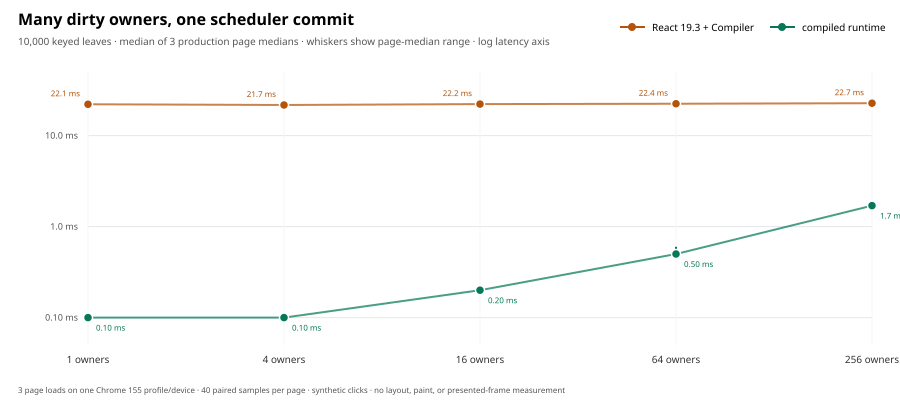

In [62]:
const seeds = [82005002, 82005003, 82005004];
const records = await Promise.all(seeds.map(async (seed) =>
  JSON.parse(
    await Deno.readTextFile(
      `results/browser-multi-owner-batch-v1-${seed}.json`,
    ),
  )
));
const fanouts = [1, 4, 16, 64, 256];
const valid = records.length === 3 && records.every((record: any) =>
  record.status === "PASS" && record.count === 10_000 &&
  record.warmupPairs === 8 && record.measuredPairs === 40 &&
  fanouts.length === record.scenarios.length &&
  record.scenarios.every((scenario: any) =>
    scenario.outputParity && scenario.stableIdentity &&
    scenario.runtimeCommitBatchesPerPair === 1 &&
    scenario.runtimeRegionsPerBatch === scenario.fanout &&
    scenario.renderedRowsPerBatch.react === scenario.fanout &&
    scenario.renderedRowsPerBatch.runtime === scenario.fanout
  )
);
if (!valid) throw new Error("Multi-owner browser records failed contracts");
const median = (values: number[]) => {
  const sorted = [...values].sort((a, b) => a - b);
  return sorted[Math.floor(sorted.length / 2)];
};
const scenarios = fanouts.map((fanout) => {
  const samples = records.map((record: any) =>
    record.scenarios.find((scenario: any) => scenario.fanout === fanout)
  );
  const metric = (key: "medianMs" | "p95Ms", arm: "react" | "runtime") =>
    samples.map((sample: any) => sample[key][arm]);
  const medians = {
    react: median(metric("medianMs", "react")),
    runtime: median(metric("medianMs", "runtime")),
  };
  const p95s = {
    react: median(metric("p95Ms", "react")),
    runtime: median(metric("p95Ms", "runtime")),
  };
  const range = (values: number[]) => [Math.min(...values), Math.max(...values)];
  return {
    fanout,
    pageLoadReplications: samples.length,
    medianMs: medians,
    medianPageP95Ms: p95s,
    pageMedianRangeMs: {
      react: range(metric("medianMs", "react")),
      runtime: range(metric("medianMs", "runtime")),
    },
    contractsPass: true,
  };
});
const summary = {
  schemaVersion: "multi-owner-browser-summary-v1",
  status: "PASS",
  profileReplications: 1,
  pageLoadsAreReplicationUnit: true,
  rawFiles: seeds.map((seed) =>
    `results/browser-multi-owner-batch-v1-${seed}.json`
  ),
  browser: records[0].browser,
  protocol: {
    leaves: 10_000,
    warmupPairsPerPage: 8,
    measuredPairsPerPage: 40,
    fanouts,
    react: "React 19.3 + React Compiler + per-row useSyncExternalStore subscriptions",
    runtime: "OXC-emitted owner/site graph + one validated multi-keyed-region commit",
    timing: "Programmatic click to synchronous host output; mount reported separately; layout, paint, and display presentation excluded.",
  },
  scenarios,
  limitations: [
    "Three page loads share one Chrome 155 profile and one MacIntel device; 40 pairs per page are nested observations.",
    "React uses one external-store subscription per row, which is an implementation-specific baseline and not a broad React workload sample.",
    "The test uses a flat 10,000-row DOM and independent boolean leaf updates; it excludes structural edits, lifecycle churn, layout/paint, and frame presentation.",
    "Timer granularity is a material limit near 0.1 ms; treat fine differences between runtime fanouts as approximate.",
  ],
};
await Deno.writeTextFile(
  "results/browser-multi-owner-batch-summary-v1.json",
  JSON.stringify(summary, null, 2) + "\n",
);
console.log(JSON.stringify(scenarios, null, 2));

const width = 900;
const height = 420;
const left = 88;
const right = 28;
const top = 72;
const bottom = 75;
const plotWidth = width - left - right;
const plotHeight = height - top - bottom;
const values = scenarios.flatMap((row) => [
  ...row.pageMedianRangeMs.react,
  ...row.pageMedianRangeMs.runtime,
]);
const minY = 0.05;
const maxY = 50;
const y = (value: number) =>
  top + (Math.log10(maxY) - Math.log10(Math.max(minY, value))) /
    (Math.log10(maxY) - Math.log10(minY)) * plotHeight;
const x = (index: number) => left + index / (fanouts.length - 1) * plotWidth;
const fmt = (value: number) => `${value.toFixed(value < 1 ? 2 : 1)} ms`;
const svg = [
  `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${height}" viewBox="0 0 ${width} ${height}" role="img" aria-labelledby="multi-owner-title multi-owner-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">`,
  `<title id="multi-owner-title">Multi-owner batch update latency</title>`,
  `<desc id="multi-owner-desc">Logarithmic latency chart across one to 256 independently updated leaves. Points are medians across three production page loads; whiskers show the range of those page medians.</desc>`,
  `<rect width="100%" height="100%" fill="white"/>`,
  `<text x="18" y="25" font-size="16" font-weight="700">Many dirty owners, one scheduler commit</text>`,
  `<text x="18" y="45" font-size="10" fill="#555">10,000 keyed leaves · median of 3 production page medians · whiskers show page-median range · log latency axis</text>`,
  `<line x1="620" y1="27" x2="645" y2="27" stroke="#b45309" stroke-width="2"/><circle cx="632" cy="27" r="4" fill="#b45309"/><text x="652" y="31" font-size="10">React 19.3 + Compiler</text>`,
  `<line x1="770" y1="27" x2="795" y2="27" stroke="#047857" stroke-width="2"/><circle cx="782" cy="27" r="4" fill="#047857"/><text x="802" y="31" font-size="10">compiled runtime</text>`,
];
for (const tick of [0.1, 1, 10]) {
  const yy = y(tick);
  svg.push(
    `<line x1="${left}" y1="${yy}" x2="${width - right}" y2="${yy}" stroke="#e5e7eb"/><text x="${left - 10}" y="${yy + 3}" text-anchor="end" font-size="9" fill="#555">${fmt(tick)}</text>`,
  );
}
for (const [index, row] of scenarios.entries()) {
  const xx = x(index);
  svg.push(
    `<line x1="${xx}" y1="${top}" x2="${xx}" y2="${height - bottom}" stroke="#f1f5f9"/><text x="${xx}" y="${height - bottom + 18}" text-anchor="middle" font-size="10" fill="#333">${row.fanout} owners</text>`,
  );
}
for (const [arm, color] of [["react", "#b45309"], ["runtime", "#047857"]] as const) {
  const points = scenarios.map((row, index) =>
    `${x(index)},${y(row.medianMs[arm])}`
  ).join(" ");
  svg.push(`<polyline points="${points}" fill="none" stroke="${color}" stroke-width="2" opacity="0.72"/>`);
  for (const [index, row] of scenarios.entries()) {
    const xx = x(index);
    const value = row.medianMs[arm];
    const [low, high] = row.pageMedianRangeMs[arm];
    const yy = y(value);
    svg.push(
      `<line x1="${xx}" y1="${y(low)}" x2="${xx}" y2="${y(high)}" stroke="${color}" stroke-width="2"/><circle cx="${xx}" cy="${yy}" r="4.5" fill="${color}" stroke="white" stroke-width="1.5"/><text x="${xx + (arm === "runtime" ? 8 : -8)}" y="${yy + (arm === "runtime" ? 13 : -8)}" text-anchor="${arm === "runtime" ? "start" : "end"}" font-size="8" fill="${color}">${fmt(value)}</text>`,
    );
  }
}
svg.push(
  `<text x="18" y="${height - 27}" font-size="8" fill="#555">3 page loads on one Chrome 155 profile/device · 40 paired samples per page · synthetic clicks · no layout, paint, or presented-frame measurement</text></svg>`,
);
Deno.jupyter.svg`${svg.join("")}`;



### Experiment AP — keyed structural updates with stateful children

This production-browser study changes a 10,000-row keyed list by rotating the first row to the end, replacing the tail with a fresh key, or alternating between all rows and half the rows. Each row owns local state. React 19.3 with React Compiler is compared with the OXC-generated owner/state-site runtime. The runtime renders the changed parent, expands only its keyed component subtree, reuses unchanged child component outputs, and commits the stable keyed host root through the retained VDOM. The v2 protocol is the historical baseline; v3 uses an LIS move plan, while v4 replaces LIS with a linear last-placed-index plan.

Three fresh page loads each ran eight warmup and 24 measured pairs. Every sample passed output parity, keyed host identity, and retained/reset child-state checks. The SVG reports the median of page medians and the range across page loads; the label reports the median of page p95 values. The v4 pages share one Chrome 154 profile and MacIntel device, so the page is the replication unit and the 24 pairs are nested observations.

Across the three v4 pages, median-of-page-medians (React/runtime) is 9.7/14.0 ms for rotate, 9.5/13.6 ms for edge replacement, and 13.2/32.0 ms for filter/restore. Median page p95 is 11.9/18.9, 10.4/15.5, and 19.5/52.9 ms. The linear planner improves the runtime's v3 median on each operation (15.4→14.0, 15.0→13.6, and 36.5→32.0 ms) while still losing to React on all medians and p95s. This is a descriptive algorithm follow-up, not a paired causal estimate; page loads share one Chrome 154 profile and are the replication unit. The v2 pages used Chrome 155. These synchronous host-commit measurements exclude layout, paint, display presentation, and repeated allocation/lifecycle churn. They test this implementation on this fixture, not general React performance. Raw records: [83001024](./results/browser-component-state-structural-v4-83001024.json), [83001025](./results/browser-component-state-structural-v4-83001025.json), and [83001026](./results/browser-component-state-structural-v4-83001026.json); [validated summary](./results/browser-component-state-structural-summary-v4.json).



[
  {
    "operation": "rotate",
    "pageLoads": 3,
    "medianOfPageMediansMs": {
      "react": 9.700000017881393,
      "runtime": 14
    },
    "medianOfPageP95Ms": {
      "react": 11.900000005960464,
      "runtime": 18.899999976158142
    },
    "pageMedianRangeMs": {
      "react": [
        5.5,
        10.5
      ],
      "runtime": [
        13,
        14.300000011920929
      ]
    },
    "mountMs": {
      "react": 22.299999982118607,
      "runtime": 54.900000005960464
    },
    "contractsPass": true
  },
  {
    "operation": "replace-edge",
    "pageLoads": 3,
    "medianOfPageMediansMs": {
      "react": 9.5,
      "runtime": 13.599999994039536
    },
    "medianOfPageP95Ms": {
      "react": 10.400000005960464,
      "runtime": 15.5
    },
    "pageMedianRangeMs": {
      "react": [
        5.700000017881393,
        9.599999994039536
      ],
      "runtime": [
        12.599999994039536,
        13.800000011920929
      ]
    },
    "mountMs": {
      "react": 16.

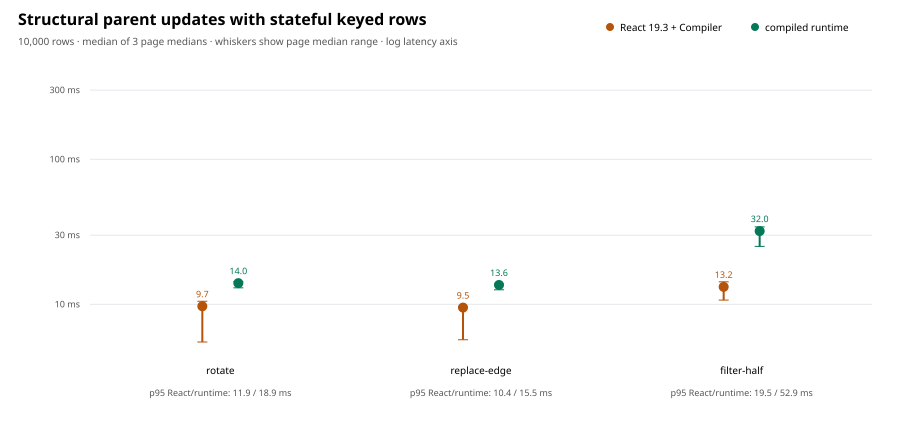

In [63]:
const structuralSeeds = [83001024, 83001025, 83001026];
const structuralOperations = ["rotate", "replace-edge", "filter-half"] as const;
const structuralRecords = await Promise.all(
  structuralSeeds.map(async (seed) =>
    JSON.parse(
      await Deno.readTextFile(
        `results/browser-component-state-structural-v4-${seed}.json`,
      ),
    )
  ),
);
const structuralValid = structuralRecords.length === 3 &&
  structuralRecords.every((record: any) =>
    record.schemaVersion === "component-state-structural-browser-v4" &&
    record.status === "PASS" && record.count === 10_000 &&
    record.warmupPairs === 8 && record.measuredPairs === 24 &&
    record.runtimeStrategy.includes("last-placed-index move plan") &&
    record.scenarios.length === structuralOperations.length &&
    structuralOperations.every((operation) => {
      const scenario = record.scenarios.find((item: any) =>
        item.operation === operation
      );
      return scenario?.samples.length === 24 && scenario.outputParity &&
        scenario.identity && scenario.retainedState &&
        scenario.samples.every((sample: any) =>
          sample.outputParity && sample.identity?.react &&
          sample.identity?.runtime && sample.retainedState?.react &&
          sample.retainedState?.runtime &&
          sample.milliseconds?.react >= 0 &&
          sample.milliseconds?.runtime >= 0
        );
    })
  );
if (!structuralValid) {
  throw new Error(
    "Structural component-state browser records failed contracts",
  );
}
const structuralMedian = (values: number[]) => {
  const sorted = [...values].sort((a, b) => a - b);
  const middle = sorted.length >> 1;
  return sorted.length % 2
    ? sorted[middle]
    : (sorted[middle - 1] + sorted[middle]) / 2;
};
const structuralRange = (values: number[]) => [
  Math.min(...values),
  Math.max(...values),
];
const structuralSummaryRows = structuralOperations.map((operation) => {
  const pages = structuralRecords.map((record: any) =>
    record.scenarios.find((item: any) => item.operation === operation)
  );
  const pageMedians = (arm: "react" | "runtime") =>
    pages.map((page: any) => page.medianMs[arm]);
  const pageP95s = (arm: "react" | "runtime") =>
    pages.map((page: any) => page.p95Ms[arm]);
  return {
    operation,
    pageLoads: pages.length,
    medianOfPageMediansMs: {
      react: structuralMedian(pageMedians("react")),
      runtime: structuralMedian(pageMedians("runtime")),
    },
    medianOfPageP95Ms: {
      react: structuralMedian(pageP95s("react")),
      runtime: structuralMedian(pageP95s("runtime")),
    },
    pageMedianRangeMs: {
      react: structuralRange(pageMedians("react")),
      runtime: structuralRange(pageMedians("runtime")),
    },
    mountMs: {
      react: structuralMedian(pages.map((page: any) => page.mountMs.react)),
      runtime: structuralMedian(pages.map((page: any) => page.mountMs.runtime)),
    },
    contractsPass: true,
  };
});
const structuralSummary = {
  schemaVersion: "component-state-structural-browser-summary-v4",
  status: "PASS",
  pageLoadsAreReplicationUnit: true,
  profileReplications: 1,
  rawFiles: structuralSeeds.map((seed) =>
    `results/browser-component-state-structural-v4-${seed}.json`
  ),
  protocol: {
    leaves: 10_000,
    warmupPairsPerPage: 8,
    measuredPairsPerPage: 24,
    operations: structuralOperations,
    react:
      "React 19.3 + React Compiler with keyed row components owning useState",
    runtime:
      "OXC-generated component and state-site metadata; structural updates expand the dirty owner subtree and use a linear last-placed-index keyed VDOM move plan",
    timing:
      "Programmatic click to synchronous host commit; mount reported separately; layout, paint, and display presentation excluded.",
  },
  scenarios: structuralSummaryRows,
  limitations: [
    "Three page loads share one Chrome 154 profile and one MacIntel device; each page is the replication unit and 24 pairs are nested observations.",
    "The linear last-placed-index plan can move more retained host nodes than an LIS plan; it still normalizes and scans the sibling sequence and does not use the dependency DAG to select structural intervals.",
    "React Compiler is enabled; source render counters are omitted to avoid changing compiler memoization.",
    "Three fresh page loads share one Chrome 154 profile and one MacIntel device; more independent device/browser replications are needed.",
    "The benchmark excludes layout, paint, display presentation, repeated churn memory, and lifecycle instrumentation.",
    "OXC lowers the checked-in TSX component and state-site fixture; the structural operation callback is supplied by the harness.",
  ],
};
await Deno.writeTextFile(
  "results/browser-component-state-structural-summary-v4.json",
  JSON.stringify(structuralSummary, null, 2) + "\n",
);
console.log(JSON.stringify(structuralSummary.scenarios, null, 2));

const structuralWidth = 900;
const structuralHeight = 430;
const structuralLeft = 90;
const structuralRight = 28;
const structuralTop = 72;
const structuralBottom = 82;
const structuralPlotWidth = structuralWidth - structuralLeft -
  structuralRight;
const structuralPlotHeight = structuralHeight - structuralTop -
  structuralBottom;
const structuralYMin = 5;
const structuralYMax = 400;
const structuralY = (value: number) =>
  structuralTop +
  (Math.log10(structuralYMax) - Math.log10(Math.max(structuralYMin, value))) /
    (Math.log10(structuralYMax) - Math.log10(structuralYMin)) *
    structuralPlotHeight;
const structuralX = (index: number, armIndex: number) =>
  structuralLeft +
  (index + 0.5) / structuralSummaryRows.length * structuralPlotWidth +
  (armIndex === 0 ? -18 : 18);
const structuralSvg = [
  `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${structuralHeight}" viewBox="0 0 ${structuralWidth} ${structuralHeight}" role="img" aria-labelledby="structural-title structural-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">`,
  `<title id="structural-title">Keyed structural update latency</title>`,
  `<desc id="structural-desc">Logarithmic chart of median synchronous update latency across three fresh page loads for rotate, edge replacement, and half-list filtering with 10,000 keyed rows. Page p95s are printed below to expose the filter tail.</desc>`,
  `<rect width="100%" height="100%" fill="white"/>`,
  `<text x="18" y="25" font-size="16" font-weight="700">Structural parent updates with stateful keyed rows</text>`,
  `<text x="18" y="45" font-size="10" fill="#555">10,000 rows · median of 3 page medians · whiskers show page median range · log latency axis</text>`,
  `<circle cx="610" cy="27" r="4" fill="#b45309"/><text x="620" y="31" font-size="10">React 19.3 + Compiler</text>`,
  `<circle cx="755" cy="27" r="4" fill="#047857"/><text x="765" y="31" font-size="10">compiled runtime</text>`,
];
for (const tick of [10, 30, 100, 300]) {
  const yy = structuralY(tick);
  structuralSvg.push(
    `<line x1="${structuralLeft}" y1="${yy}" x2="${
      structuralWidth - structuralRight
    }" y2="${yy}" stroke="#e5e7eb"/><text x="${structuralLeft - 10}" y="${
      yy + 3
    }" text-anchor="end" font-size="9" fill="#555">${tick} ms</text>`,
  );
}
for (let index = 0; index < structuralSummaryRows.length; index++) {
  const row = structuralSummaryRows[index];
  for (const [armIndex, arm] of (["react", "runtime"] as const).entries()) {
    const x = structuralX(index, armIndex);
    const color = arm === "react" ? "#b45309" : "#047857";
    const median = row.medianOfPageMediansMs[arm];
    const [low, high] = row.pageMedianRangeMs[arm];
    structuralSvg.push(
      `<line x1="${x}" y1="${structuralY(low)}" x2="${x}" y2="${
        structuralY(high)
      }" stroke="${color}" stroke-width="2"/><line x1="${x - 5}" y1="${
        structuralY(low)
      }" x2="${x + 5}" y2="${structuralY(low)}" stroke="${color}"/><line x1="${
        x - 5
      }" y1="${structuralY(high)}" x2="${x + 5}" y2="${
        structuralY(high)
      }" stroke="${color}"/><circle cx="${x}" cy="${
        structuralY(median)
      }" r="5" fill="${color}"/><text x="${x}" y="${
        structuralY(median) - 9
      }" text-anchor="middle" font-size="9" fill="${color}">${
        median.toFixed(1)
      }</text>`,
    );
  }
  const labelX = structuralLeft +
    (index + 0.5) / structuralSummaryRows.length * structuralPlotWidth;
  structuralSvg.push(
    `<text x="${labelX}" y="${
      structuralHeight - 56
    }" text-anchor="middle" font-size="10">${row.operation}</text><text x="${labelX}" y="${
      structuralHeight - 34
    }" text-anchor="middle" font-size="9" fill="#555">p95 React/runtime: ${
      row.medianOfPageP95Ms.react.toFixed(1)
    } / ${row.medianOfPageP95Ms.runtime.toFixed(1)} ms</text>`,
  );
}
structuralSvg.push(`</svg>`);
Deno.jupyter.svg`${structuralSvg.join("")}`;



### Experiment AQ — minimum production bundle size

Matched minimal counter fixtures mount one button and update its text from native click state. Both are built as single ES2022 production bundles with Vite 8.3.1 and Oxc minification; gzip uses level 9. The prototype fixture bundles ComponentStateRoot, DOMVDOMHost, and the owner/state-site runtime. The React fixture bundles React 19.3 and React DOM 19.3.

The runtime fixture is 33,528 bytes raw / 8,892 bytes gzip; React is 297,192 bytes raw / 75,584 bytes gzip. This indicates a much smaller payload for this minimal app, but the prototype implements far fewer features. It is not an equal-capability or representative-app size comparison. Reproduce with pnpm run bundle:size; source fixtures are in src/size-fixtures/ and the raw result is results/runtime-size-v1.json.



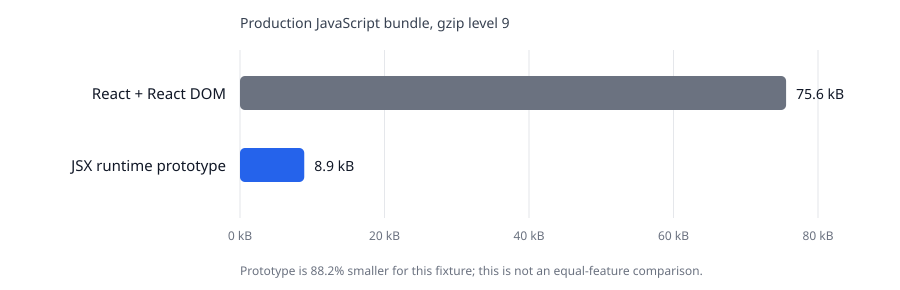

In [64]:
const bundleSize = JSON.parse(
  await Deno.readTextFile("results/runtime-size-v1.json"),
);
if (
  bundleSize.schemaVersion !== "runtime-bundle-size-v1" ||
  bundleSize.status !== "PASS"
) throw new Error("Missing or invalid runtime bundle-size records");

const bundleBars = [
  { name: "React + React DOM", bytes: bundleSize.arms.react.totalGzipBytes },
  {
    name: "JSX runtime prototype",
    bytes: bundleSize.arms.runtime.totalGzipBytes,
  },
];
const bundleWidth = 900;
const bundleHeight = 290;
const bundleLeft = 240;
const bundleRight = 82;
const bundleBarWidth = bundleWidth - bundleLeft - bundleRight;
const bundleMax = 80_000;
const bundleSvg = [
  '<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="290" viewBox="0 0 900 290" role="img" aria-labelledby="bundle-title bundle-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">',
  '<title id="bundle-title">Minimal counter production bundle size</title>',
  '<desc id="bundle-desc">Gzip size of equivalent one-button counter fixtures. The prototype is much smaller, but it implements far fewer features than React.</desc>',
  '<text x="240" y="28" fill="#374151" font-size="14">Production JavaScript bundle, gzip level 9</text>',
];
for (const tick of [0, 20_000, 40_000, 60_000, 80_000]) {
  const x = bundleLeft + tick / bundleMax * bundleBarWidth;
  bundleSvg.push(
    '<line x1="' + x + '" y1="50" x2="' + x +
      '" y2="218" stroke="#e5e7eb"/><text x="' + x +
      '" y="240" text-anchor="middle" fill="#6b7280" font-size="12">' +
      (tick / 1000) + " kB</text>",
  );
}
bundleBars.forEach((bar, index) => {
  const y = 76 + index * 72;
  const width = Math.max(2, bar.bytes / bundleMax * bundleBarWidth);
  const color = index === 0 ? "#6b7280" : "#2563eb";
  bundleSvg.push(
    '<text x="226" y="' + (y + 23) +
      '" text-anchor="end" fill="#111827" font-size="15">' + bar.name +
      '</text><rect x="240" y="' + y + '" width="' + width +
      '" height="34" rx="5" fill="' + color + '"/><text x="' +
      (240 + width + 10) + '" y="' + (y + 23) +
      '" fill="#111827" font-size="14">' + (bar.bytes / 1000).toFixed(1) +
      " kB</text>",
  );
});
bundleSvg.push(
  '<text x="240" y="275" fill="#6b7280" font-size="12">Prototype is 88.2% smaller for this fixture; this is not an equal-feature comparison.</text>',
  "</svg>",
);
Deno.jupyter.svg`${bundleSvg.join("")}`;



### Experiment AR — per-frame declarative prop updates in Snake

This is a production-build browser comparison of three isolated update paths for a fixed Snake-like trail UI. The simulation advances discretely; every `requestAnimationFrame` recomputes and writes every visible segment transform while topology stays fixed. React 19.3.0 runs with React Compiler and leaf `useSyncExternalStore` subscriptions. A single null-rendering marker component with one layout effect timestamps each commit; no per-segment layout effects are used for measurement. The retained path mounts a JSX helper tree once and uses scalar-source bindings to write each style prop without component execution or VDOM diffing. The direct-DOM arm caches its host nodes and writes the same props as a lower bound.

The study covers 32, 128, 512, and 1,024 segments. For every size and arm, three isolated page loads each collect 90 warmup and 300 measured frames. Arm order rotates across page-load replicates. The replication unit is the page load; the 300 frames are nested observations. The local archive accepts only visible runs with exact sample counts, final transform parity, stable segment and food node identity, and complete per-frame commit timestamps. `results/browser-snake-frame-v3-manifest.json` pins the exact 36 records with SHA-256 hashes; the notebook validates each hash before analysis. V2 files remain archived as a pilot but are excluded because their per-segment commit effects instrumented the React path.

The page-level summary reports the median of the three page medians and the median of the three page p95 values. Update CPU measures the state-to-write call path; update-to-commit starts before per-segment derivation and ends at the root marker layout effect or after the retained/direct synchronous write returns. RAF interval is reported separately and is not a presentation measurement. An exploratory post-hoc check counts callback intervals above 25 ms, but this is neither a dropped-frame measurement nor a presentation measurement. The three arms were run in Chrome 154 on one MacIntel device/profile at 1280×720, DPR 2, with an estimated 60 Hz callback cadence. Timer values below 0.1 ms are near this browser's timing resolution. No paint, GPU, physical presentation, high-refresh display, or second-device result is included.

This measures a retained binding kernel, not an OXC-generated per-frame update plan. The result can answer whether this runtime primitive reduces update-to-commit latency against a React Compiler baseline; it cannot yet establish that the full compiled architecture is faster or simpler. The direct-DOM path is an implementation lower bound, not an authoring API.



In [65]:
type Arm = "react" | "runtime" | "direct";
type Sample = {
  intervalMs: number;
  updateCpuMs: number;
  commitMs: number | null;
};
type PageRecord = {
  schemaVersion: string;
  status: string;
  allContractsPass: boolean;
  trialId: string;
  pageLoadId: string;
  arm: Arm;
  segmentCount: number;
  warmupFrames: number;
  measuredFrames: number;
  completeCommitCoverage: boolean;
  reactVersion: string;
  runtimeStrategy: string;
  browser: {
    userAgent: string;
    visibilityState: string;
    devicePixelRatio: number;
    viewport: { width: number; height: number };
    hardwareConcurrency: number | null;
  };
  refreshRateEstimateHz: number;
  allOutputMatches: boolean;
  stableNodeCount: boolean;
  stableNodeIdentity: boolean;
  samples: Sample[];
};

const counts = [32, 128, 512, 1024];
const arms: Arm[] = ["react", "runtime", "direct"];
const raw: PageRecord[] = [];
const manifest = JSON.parse(
  await Deno.readTextFile("results/browser-snake-frame-v3-manifest.json"),
);
if (
  manifest.schemaVersion !== "snake-frame-browser-manifest-v1" ||
  manifest.status !== "PASS" || manifest.pageLoads !== 36 ||
  manifest.measuredSamples !== 10_800 || manifest.files.length !== 36
) throw new Error("Snake V3 manifest is missing or incomplete");
for (const file of manifest.files) {
  const bytes = await Deno.readFile(`results/${file.file}`);
  const digest = await crypto.subtle.digest("SHA-256", bytes);
  const sha256 = [...new Uint8Array(digest)].map((byte) =>
    byte.toString(16).padStart(2, "0")
  ).join("");
  if (sha256 !== file.sha256) {
    throw new Error(`SHA-256 mismatch for ${file.file}`);
  }
  const record = JSON.parse(new TextDecoder().decode(bytes)) as PageRecord;
  if (
    record.pageLoadId !== file.pageLoadId || record.trialId !== file.trialId ||
    record.arm !== file.arm || record.segmentCount !== file.segmentCount ||
    record.measuredFrames !== file.sampleCount
  ) throw new Error(`Manifest metadata mismatch for ${file.file}`);
  raw.push(record);
}
raw.sort((a, b) =>
  a.segmentCount - b.segmentCount || a.arm.localeCompare(b.arm) ||
  a.trialId.localeCompare(b.trialId)
);

const percentile = (values: number[], p: number) => {
  const ordered = [...values].sort((a, b) => a - b);
  return ordered[Math.max(0, Math.ceil(p * ordered.length) - 1)];
};
const median = (values: number[]) => {
  const ordered = [...values].sort((a, b) => a - b);
  const middle = Math.floor(ordered.length / 2);
  return ordered.length % 2
    ? ordered[middle]
    : (ordered[middle - 1] + ordered[middle]) / 2;
};

const valid = raw.length === counts.length * arms.length * 3 &&
  raw.every((record) =>
    record.schemaVersion === "snake-frame-browser-v3" &&
    record.status === "PASS" && record.allContractsPass &&
    counts.includes(record.segmentCount) && arms.includes(record.arm) &&
    record.warmupFrames === 90 && record.measuredFrames === 300 &&
    record.completeCommitCoverage &&
    record.samples.length === 300 &&
    record.browser.visibilityState === "visible" &&
    record.reactVersion === manifest.environment.reactVersion &&
    record.browser.userAgent === manifest.environment.browserUserAgent &&
    record.allOutputMatches && record.stableNodeCount &&
    record.stableNodeIdentity &&
    record.samples.every((sample) =>
      Number.isFinite(sample.intervalMs) && sample.intervalMs > 0 &&
      Number.isFinite(sample.updateCpuMs) && sample.updateCpuMs >= 0 &&
      Number.isFinite(sample.commitMs) && (sample.commitMs ?? -1) >= 0
    )
  );
const uniqueIds =
  new Set(raw.map((record) => record.pageLoadId)).size === raw.length;
const groupRecords = (count: number, arm: Arm) =>
  raw.filter((record) => record.segmentCount === count && record.arm === arm);
const balanced = counts.every((count) =>
  arms.every((arm) => {
    const pages = groupRecords(count, arm);
    return pages.length === 3 &&
      new Set(pages.map((page) => page.trialId)).size === 3;
  })
);
if (!valid || !uniqueIds || !balanced) {
  throw new Error(
    `Snake frame records failed: valid=${valid}, uniqueIds=${uniqueIds}, balanced=${balanced}, records=${raw.length}`,
  );
}

type PageMetric = {
  median: number;
  p95: number;
  values: number[];
  budget60: number;
  budget120: number;
};
type Group = {
  count: number;
  arm: Arm;
  update: PageMetric[];
  commit: PageMetric[];
  raf: PageMetric[];
};
const groups: Group[] = [];
for (const count of counts) {
  for (const arm of arms) {
    const pages = groupRecords(count, arm);
    const metric = (
      project: (sample: Sample) => number | null,
    ): PageMetric[] =>
      pages.map((page) => {
        const values = page.samples.map(project).filter((
          value,
        ): value is number => value !== null);
        return {
          median: median(values),
          p95: percentile(values, 0.95),
          values,
          budget60: values.filter((value) => value > 1000 / 60).length /
            values.length,
          budget120: values.filter((value) => value > 1000 / 120).length /
            values.length,
        };
      });
    groups.push({
      count,
      arm,
      update: metric((sample) => sample.updateCpuMs),
      commit: metric((sample) => sample.commitMs),
      raf: metric((sample) => sample.intervalMs),
    });
  }
}
const group = (count: number, arm: Arm) =>
  groups.find((item) => item.count === count && item.arm === arm)!;
const aggregate = (metrics: PageMetric[], key: "median" | "p95") =>
  median(metrics.map((metric) => metric[key]));
const range = (metrics: PageMetric[], key: "median" | "p95") => {
  const values = metrics.map((metric) => metric[key]);
  return [Math.min(...values), Math.max(...values)] as const;
};

console.log(
  `SHA-256 validated ${raw.length} page loads × 300 measured RAFs = ${
    raw.length * 300
  } samples; 3 pages per arm and size.`,
);
console.log(
  `Environment: ${raw[0].browser.userAgent}; ${raw[0].browser.viewport.width}×${
    raw[0].browser.viewport.height
  }; DPR ${raw[0].browser.devicePixelRatio}; ${
    raw[0].browser.hardwareConcurrency
  } logical CPUs; React ${raw[0].reactVersion}.`,
);
console.log(
  "Summary = median of page medians and median of page p95 values; the page load is the replication unit.",
);
for (const count of counts) {
  for (const arm of arms) {
    const item = group(count, arm);
    console.log(
      `${count}\t${arm}\tupdate ${
        aggregate(item.update, "median").toFixed(3)
      }/${aggregate(item.update, "p95").toFixed(3)} ms\tcommit ${
        aggregate(item.commit, "median").toFixed(3)
      }/${aggregate(item.commit, "p95").toFixed(3)} ms\tRAF p95 ${
        aggregate(item.raf, "p95").toFixed(3)
      } ms`,
    );
  }
}

const color: Record<Arm, string> = {
  react: "#d04a3a",
  runtime: "#2563eb",
  direct: "#6b7280",
};
const width = 1040;
const height = 410;
const chartTop = 78;
const chartBottom = 324;
const chartHeight = chartBottom - chartTop;
const chartLeft = [92, 572];
const chartWidth = 390;
const yMax = 2;
const xPosition = (count: number, offset: number) =>
  offset +
  Math.log2(count / counts[0]) / Math.log2(counts.at(-1)! / counts[0]) *
    chartWidth;
const yPosition = (value: number) =>
  chartBottom - Math.min(value, yMax) / yMax * chartHeight;
const svg = [
  `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${height}" viewBox="0 0 ${width} ${height}" role="img" aria-labelledby="snake-title snake-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">`,
  `<title id="snake-title">Snake frame update timing by body size</title>`,
  `<desc id="snake-desc">Median of three page medians for update CPU and update-to-commit latency, with page-median ranges shown as vertical bars. Browser callback cadence was approximately 60 hertz.</desc>`,
  `<text x="${
    width / 2
  }" y="28" text-anchor="middle" fill="#111827" font-size="18" font-weight="650">32 to 1,024 retained segments · production build · 300 RAF samples per page</text>`,
];
const panels = [
  {
    x: chartLeft[0],
    title: "Update-path JavaScript CPU",
    key: "update" as const,
  },
  {
    x: chartLeft[1],
    title: "Update-to-commit latency",
    key: "commit" as const,
  },
];
for (const panel of panels) {
  svg.push(
    `<text x="${
      panel.x + chartWidth / 2
    }" y="58" text-anchor="middle" fill="#374151" font-size="15" font-weight="600">${panel.title} (ms)</text>`,
  );
  for (const tick of [0, 0.5, 1, 1.5, 2]) {
    const y = yPosition(tick);
    svg.push(
      `<line x1="${panel.x}" y1="${y}" x2="${
        panel.x + chartWidth
      }" y2="${y}" stroke="#e5e7eb"/><text x="${panel.x - 12}" y="${
        y + 4
      }" text-anchor="end" fill="#6b7280" font-size="11">${
        tick.toFixed(1)
      }</text>`,
    );
  }
  for (const count of counts) {
    const x = xPosition(count, panel.x);
    svg.push(
      `<line x1="${x}" y1="${chartTop}" x2="${x}" y2="${chartBottom}" stroke="#f3f4f6"/><text x="${x}" y="${
        chartBottom + 21
      }" text-anchor="middle" fill="#6b7280" font-size="11">${count}</text>`,
    );
  }
  svg.push(
    `<line x1="${panel.x}" y1="${chartBottom}" x2="${
      panel.x + chartWidth
    }" y2="${chartBottom}" stroke="#9ca3af"/><text x="${
      panel.x + chartWidth / 2
    }" y="${
      chartBottom + 42
    }" text-anchor="middle" fill="#6b7280" font-size="11">Visible segments (log₂ scale)</text>`,
  );
  for (const arm of arms) {
    const points = counts.map((count) => {
      const metrics = group(count, arm)[panel.key];
      return {
        x: xPosition(count, panel.x),
        y: yPosition(aggregate(metrics, "median")),
        low: yPosition(Math.min(...metrics.map((metric) => metric.median))),
        high: yPosition(Math.max(...metrics.map((metric) => metric.median))),
      };
    });
    svg.push(
      `<polyline points="${
        points.map((point) => `${point.x},${point.y}`).join(" ")
      }" fill="none" stroke="${color[arm]}" stroke-width="2.5"/>`,
    );
    for (const point of points) {
      svg.push(
        `<line x1="${point.x}" y1="${point.low}" x2="${point.x}" y2="${point.high}" stroke="${
          color[arm]
        }" stroke-width="1.5"/><circle cx="${point.x}" cy="${point.y}" r="4" fill="${
          color[arm]
        }"/>`,
      );
    }
  }
}
for (const [index, arm] of arms.entries()) {
  const x = 370 + index * 130;
  svg.push(
    `<line x1="${x}" y1="382" x2="${x + 24}" y2="382" stroke="${
      color[arm]
    }" stroke-width="3"/><text x="${
      x + 32
    }" y="386" fill="#374151" font-size="12">${
      arm === "react"
        ? "React + Compiler"
        : arm === "runtime"
        ? "Retained binding"
        : "Direct DOM"
    }</text>`,
  );
}
svg.push(
  `<text x="${
    width / 2
  }" y="405" text-anchor="middle" fill="#6b7280" font-size="10">Vertical bars show min–max across three page medians; values below 0.1 ms are near Chrome’s timer resolution.</text>`,
  "</svg>",
);
console.log("\nMarkdown table data (median page median / median page p95):");
console.log(
  "segments | arm | update CPU (ms) | update-to-commit (ms) | RAF interval p95 (ms) | commit CPU > 16.67 / 8.33 ms",
);
for (const count of counts) {
  for (const arm of arms) {
    const item = group(count, arm);
    const exceed = (metrics: PageMetric[], field: "budget60" | "budget120") =>
      `${(100 * median(metrics.map((metric) => metric[field]))).toFixed(1)}%`;
    console.log(
      `${count} | ${arm} | ${aggregate(item.update, "median").toFixed(3)} / ${
        aggregate(item.update, "p95").toFixed(3)
      } | ${aggregate(item.commit, "median").toFixed(3)} / ${
        aggregate(item.commit, "p95").toFixed(3)
      } | ${aggregate(item.raf, "p95").toFixed(3)} | ${
        exceed(item.commit, "budget60")
      } / ${exceed(item.commit, "budget120")}`,
    );
  }
  Deno.jupyter.svg`${svg.join("")}`;
}

console.log(
  "\nExploratory RAF callback tail check (page-level; 25 ms threshold):",
);
console.log(
  "segments | arm | median page p95 interval (ms) | pages with any >25 ms interval | intervals >25 ms / 900",
);
for (const count of counts) {
  for (const arm of arms) {
    const pages = groupRecords(count, arm);
    const pageP95 = pages.map((page) =>
      percentile(page.samples.map((sample) => sample.intervalMs), 0.95)
    );
    const pageTail = pages.map((page) =>
      page.samples.filter((sample) => sample.intervalMs > 25).length
    );
    const totalTail = pageTail.reduce((sum, value) => sum + value, 0);
    const pagesWithTail = pageTail.filter((value) => value > 0).length;
    console.log(
      `${count} | ${arm} | ${
        median(pageP95).toFixed(2)
      } | ${pagesWithTail}/3 | ${totalTail}/900`,
    );
  }
}
const allLongIntervals =
  raw.flatMap((page) => page.samples).filter((sample) => sample.intervalMs > 25)
    .length;
console.log(
  `Across ${
    raw.length * 300
  } measured callbacks, ${allLongIntervals} intervals exceeded 25 ms. This exploratory threshold is not a dropped-frame or presentation measurement.`,
);



SHA-256 validated 36 page loads × 300 measured RAFs = 10800 samples; 3 pages per arm and size.


Environment: Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/154.0.0.0 Safari/537.36; 1280×720; DPR 2; 10 logical CPUs; React 19.3.0.


Summary = median of page medians and median of page p95 values; the page load is the replication unit.


32	react	update 0.100/0.300 ms	commit 0.300/0.800 ms	RAF p95 18.000 ms


32	runtime	update 0.200/0.400 ms	commit 0.200/0.400 ms	RAF p95 18.200 ms


...

512 | direct | 17.20 | 0/3 | 0/900


1024 | react | 17.40 | 1/3 | 1/900


1024 | runtime | 16.80 | 0/3 | 0/900


1024 | direct | 17.70 | 0/3 | 0/900


Across 10800 measured callbacks, 1 intervals exceeded 25 ms. This exploratory threshold is not a dropped-frame or presentation measurement.


### Experiment AS — OXC-generated per-frame bindings (Snake V4)

V4 is a separate two-dimensional fixed-topology protocol. Every arm writes the same segment x/y coordinates through left/top styles so the current OXC repeated-host compiler can express the plan. The arms are React 19.3 with React Compiler and leaf external-store subscriptions; retained VDOM with two hand-authored bindings; an OXC-emitted repeated-host plan with two item-local CSR slots and generated style writers; and cached direct DOM.

The frozen matrix has 32, 128, 512, and 1,024 segments, four arms, and four page-load replications per cell (64 pages). Each page has 90 warmup and 300 measured RAF callbacks. Arm and segment-count order rotate across replications. The page is the replication unit; frame observations are nested. Coordinate derivation happens once per segment inside the measured interval in every arm. The generated path updates x and y source slots and flushes once per RAF. The static generated plan is part of the bundle, but mount, compiler execution, bundle parse, and memory are not in the timing.

The notebook validates all 64 SHA-256-pinned records, trial IDs, page-load IDs, visible state, output parity, stable node identity, and complete React commit timestamps before summarizing. It reports the median of page medians and the median of page p95 values; SVG error bars show the min/max of four page medians. All runs used Chrome 154 on one MacIntel device/profile. Layout, paint, GPU, and physical presentation are excluded. The V4 left/top output path is not pooled with V3 transform output.

This tests a narrow compiler-emitted repeated-host binding plan, not general TSX compilation or a full retained-VDOM compiler pipeline. React performs component execution, store notification, reconciliation, and style commit; the generated plan executes direct host writers. Interpret differences as implementation-path evidence, not equal-work framework speedups.



SHA-256 validated 64 page loads × 300 RAFs = 19200 samples; four replications per arm and size.


Environment: Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/154.0.0.0 Safari/537.36; 1280×720; DPR 2; React 19.3.0.


segments | arm | update CPU median/p95 ms | update-to-commit median/p95 ms | RAF interval p95 ms


32 | react | 0.200/0.300 | 0.550/0.900 | 17.900


32 | runtime | 0.300/0.450 | 0.300/0.450 | 18.050


...

512 | direct | 0.350/0.500 | 0.350/0.500 | 17.150


1024 | react | 0.200/0.300 | 2.100/2.300 | 16.800


1024 | runtime | 0.800/0.950 | 0.800/0.950 | 16.800


1024 | generated | 0.500/0.600 | 0.500/0.600 | 16.800


1024 | direct | 0.650/0.800 | 0.650/0.800 | 16.800


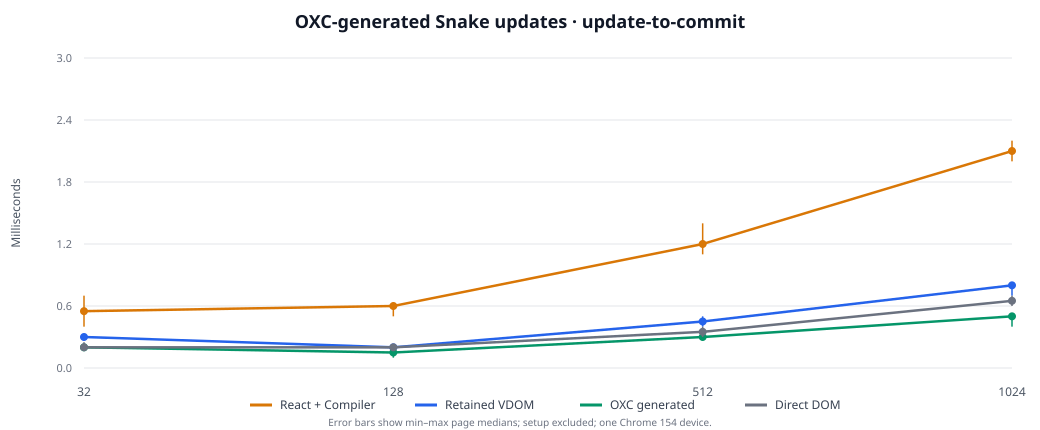

In [66]:
type Arm = "react" | "runtime" | "generated" | "direct";
type Sample = {
  intervalMs: number;
  updateCpuMs: number;
  commitMs: number | null;
};
type Page = {
  schemaVersion: string;
  status: string;
  allContractsPass: boolean;
  trialId: string;
  pageLoadId: string;
  arm: Arm;
  segmentCount: number;
  warmupFrames: number;
  measuredFrames: number;
  completeCommitCoverage: boolean;
  reactVersion: string;
  browser: {
    userAgent: string;
    visibilityState: string;
    devicePixelRatio: number;
    viewport: { width: number; height: number };
    hardwareConcurrency: number | null;
  };
  allOutputMatches: boolean;
  stableNodeCount: boolean;
  stableNodeIdentity: boolean;
  samples: Sample[];
};
const counts = [32, 128, 512, 1024];
const arms: Arm[] = ["react", "runtime", "generated", "direct"];
const manifest = JSON.parse(
  await Deno.readTextFile("results/browser-snake-frame-v4-manifest.json"),
);
if (
  manifest.schemaVersion !== "snake-frame-browser-v4-manifest-v1" ||
  manifest.status !== "PASS" || manifest.pageLoads !== 64 ||
  manifest.measuredSamples !== 19200 || manifest.files.length !== 64
) {
  throw new Error("Snake V4 manifest is missing or incomplete");
}
const pages: Page[] = [];
for (const entry of manifest.files) {
  const bytes = await Deno.readFile("results/" + entry.file);
  const digest = await crypto.subtle.digest("SHA-256", bytes);
  const hash = [...new Uint8Array(digest)].map((byte) =>
    byte.toString(16).padStart(2, "0")
  ).join("");
  if (hash !== entry.sha256) {
    throw new Error("SHA-256 mismatch for " + entry.file);
  }
  const page = JSON.parse(new TextDecoder().decode(bytes)) as Page;
  if (
    page.pageLoadId !== entry.pageLoadId || page.trialId !== entry.trialId ||
    page.arm !== entry.arm || page.segmentCount !== entry.segmentCount ||
    page.measuredFrames !== entry.sampleCount
  ) throw new Error("Manifest metadata mismatch for " + entry.file);
  pages.push(page);
}
const percentile = (values: number[], p: number) => {
  const sorted = [...values].sort((a, b) => a - b);
  return sorted[Math.max(0, Math.ceil(p * sorted.length) - 1)];
};
const median = (values: number[]) => {
  const sorted = [...values].sort((a, b) => a - b);
  const middle = Math.floor(sorted.length / 2);
  return sorted.length % 2
    ? sorted[middle]
    : (sorted[middle - 1] + sorted[middle]) / 2;
};
const cellPages = (count: number, arm: Arm) =>
  pages.filter((page) => page.segmentCount === count && page.arm === arm);
const valid = pages.length === 64 &&
  pages.every((page) =>
    page.schemaVersion === "snake-frame-browser-v4" && page.status === "PASS" &&
    page.allContractsPass && page.warmupFrames === 90 &&
    page.measuredFrames === 300 &&
    page.completeCommitCoverage && page.samples.length === 300 &&
    page.browser.visibilityState === "visible" &&
    page.reactVersion === manifest.environment.reactVersion &&
    page.browser.userAgent === manifest.environment.userAgent &&
    page.allOutputMatches && page.stableNodeCount && page.stableNodeIdentity &&
    page.samples.every((sample) =>
      Number.isFinite(sample.intervalMs) && sample.intervalMs > 0 &&
      Number.isFinite(sample.updateCpuMs) && sample.updateCpuMs >= 0 &&
      Number.isFinite(sample.commitMs) && (sample.commitMs ?? -1) >= 0
    )
  );
const unique = new Set(pages.map((page) => page.pageLoadId)).size === 64;
const balanced = counts.every((count) =>
  arms.every((arm) => cellPages(count, arm).length === 4)
);
if (!valid || !unique || !balanced) {
  throw new Error("Snake V4 record contract failed");
}

type Metric = { median: number; p95: number; pageMedians: number[] };
const metric = (
  count: number,
  arm: Arm,
  project: (sample: Sample) => number,
): Metric => {
  const selected = cellPages(count, arm);
  const pageMedians = selected.map((page) => median(page.samples.map(project)));
  const pageP95s = selected.map((page) =>
    percentile(page.samples.map(project), 0.95)
  );
  return { median: median(pageMedians), p95: median(pageP95s), pageMedians };
};
const updates = new Map<string, Metric>();
const commits = new Map<string, Metric>();
const intervals = new Map<string, Metric>();
for (const count of counts) {
  for (const arm of arms) {
    const key = count + "/" + arm;
    updates.set(key, metric(count, arm, (sample) => sample.updateCpuMs));
    commits.set(key, metric(count, arm, (sample) => sample.commitMs!));
    intervals.set(key, metric(count, arm, (sample) => sample.intervalMs));
  }
}
console.log(
  "SHA-256 validated " + pages.length + " page loads × 300 RAFs = " +
    (pages.length * 300) + " samples; four replications per arm and size.",
);
console.log(
  "Environment: " + manifest.environment.userAgent + "; " +
    manifest.environment.viewport.width + "×" +
    manifest.environment.viewport.height +
    "; DPR " + manifest.environment.devicePixelRatio + "; React " +
    manifest.environment.reactVersion + ".",
);
console.log(
  "segments | arm | update CPU median/p95 ms | update-to-commit median/p95 ms | RAF interval p95 ms",
);
for (const count of counts) {
  for (const arm of arms) {
    const key = count + "/" + arm;
    const update = updates.get(key)!;
    const commit = commits.get(key)!;
    const rafPages = cellPages(count, arm).map((page) =>
      percentile(page.samples.map((sample) => sample.intervalMs), 0.95)
    );
    console.log(
      count + " | " + arm + " | " + update.median.toFixed(3) + "/" +
        update.p95.toFixed(3) + " | " + commit.median.toFixed(3) + "/" +
        commit.p95.toFixed(3) + " | " + median(rafPages).toFixed(3),
    );
  }
}

const width = 1040, height = 430, left = 84, right = 28, top = 58, bottom = 62;
const chartHeight = height - top - bottom, chartWidth = width - left - right;
const max = Math.max(
  ...[...commits.values()].flatMap((value) => value.pageMedians),
);
const yMax = Math.max(1, Math.ceil(max * 1.2));
const xAt = (index: number) => left + chartWidth * index / (counts.length - 1);
const yAt = (value: number) => top + chartHeight * (1 - value / yMax);
const colors: Record<Arm, string> = {
  react: "#d97706",
  runtime: "#2563eb",
  generated: "#059669",
  direct: "#6b7280",
};
const svg: string[] = [
  '<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="' + height +
  '" viewBox="0 0 ' + width + " " + height +
  '" role="img" aria-labelledby="snake-v4-title snake-v4-desc" style="max-width:100%;height:auto;font-family:system-ui,sans-serif">',
  '<title id="snake-v4-title">V4 OXC-generated per-frame binding comparison</title>',
  '<desc id="snake-v4-desc">Median update-to-commit time by segment count for four arms, with min-max page medians across four replications.</desc>',
  '<text x="' + width / 2 +
  '" y="28" text-anchor="middle" fill="#111827" font-size="18" font-weight="650">OXC-generated Snake updates · update-to-commit</text>',
];
for (let tick = 0; tick <= 5; tick++) {
  const value = yMax * tick / 5, y = yAt(value);
  svg.push(
    '<line x1="' + left + '" y1="' + y + '" x2="' + (width - right) +
      '" y2="' + y + '" stroke="#e5e7eb"/><text x="' + (left - 12) + '" y="' +
      (y + 4) + '" text-anchor="end" fill="#6b7280" font-size="11">' +
      value.toFixed(1) + "</text>",
  );
}
svg.push(
  '<text x="20" y="' + (top + chartHeight / 2) +
    '" text-anchor="middle" transform="rotate(-90 20 ' +
    (top + chartHeight / 2) +
    ')" fill="#4b5563" font-size="12">Milliseconds</text>',
);
for (let i = 0; i < counts.length; i++) {
  svg.push(
    '<text x="' + xAt(i) + '" y="' + (height - 34) +
      '" text-anchor="middle" fill="#4b5563" font-size="12">' + counts[i] +
      "</text>",
  );
}
for (const arm of arms) {
  const points = counts.map((count, index) => {
    const values = commits.get(count + "/" + arm)!.pageMedians;
    return {
      x: xAt(index),
      y: yAt(median(values)),
      low: yAt(Math.min(...values)),
      high: yAt(Math.max(...values)),
    };
  });
  svg.push(
    '<polyline points="' + points.map((point) =>
      point.x + "," + point.y
    ).join(" ") +
      '" fill="none" stroke="' + colors[arm] + '" stroke-width="2.5"/>',
  );
  for (const point of points) {
    svg.push(
      '<line x1="' + point.x + '" y1="' + point.low +
        '" x2="' + point.x + '" y2="' + point.high + '" stroke="' +
        colors[arm] +
        '" stroke-width="1.5"/><circle cx="' + point.x + '" cy="' + point.y +
        '" r="4" fill="' + colors[arm] + '"/>',
    );
  }
}
for (let i = 0; i < arms.length; i++) {
  const arm = arms[i], x = 250 + i * 165;
  const label = arm === "react"
    ? "React + Compiler"
    : arm === "runtime"
    ? "Retained VDOM"
    : arm === "generated"
    ? "OXC generated"
    : "Direct DOM";
  svg.push(
    '<line x1="' + x + '" y1="405" x2="' + (x + 22) + '" y2="405" stroke="' +
      colors[arm] + '" stroke-width="3"/><text x="' + (x + 30) +
      '" y="409" fill="#374151" font-size="12">' + label + "</text>",
  );
}
svg.push(
  '<text x="' + width / 2 +
    '" y="426" text-anchor="middle" fill="#6b7280" font-size="10">Error bars show min–max page medians; setup excluded; one Chrome 154 device.</text></svg>',
);
Deno.jupyter.svg`${svg.join("")}`;



### Experiment AT — preregistered Snake V5: OXC bindings through the retained VDOM

V5 closes the specific gap between the prior OXC repeated-host Snake arm and Experiment V's generic OXC-to-VDOM binding integration. It compares five per-frame paths on identical left/top props: React 19.3 + React Compiler with leaf external-store subscriptions; runtime-discovered bindings through the retained VDOM; OXC-emitted CSR bindings through the retained VDOM; OXC-generated repeated-host writers; and cached direct DOM writes.

The frozen schedule has 32, 128, 512, and 1,024 segments, five page-load replications per cell, 90 warmup RAFs and 300 measured RAF callbacks per page: 100 pages and 30,000 measured callbacks. Arm position uses a five-cycle Latin rotation; size order rotates by replication. The page is the replication unit and RAFs are nested observations. The schedule, pre-data hostname amendment, and URLs are in `results/browser-snake-frame-v5-preregistration.json`; the [source lock](./results/browser-snake-frame-v5-source-lock.json) pins the measured paths and dependencies. All 100 scheduled pages passed and are SHA-256-pinned in `results/browser-snake-frame-v5-manifest.json`; the 60-frame smoke is excluded.

The page measures mount-to-first-commit, update CPU, update-to-commit, RAF interval p95, and Chrome heap-used snapshots before mount, after mount, and after the measured frames when available. The heap values are noisy diagnostics, not allocation attribution. Setup-plus-update break-even counts pair mount and per-frame medians by size and replication. SVG charts report update-to-commit, mount cost, and RAF interval p95. The HTML record validator checks parity, stable host identity, React commit coverage, visibility, and all 300 samples before archiving.
Results are faster on update-to-commit for the OXC-to-VDOM arm in this workload: its median/p95 is 0.1/0.2, 0.2/0.3, 0.5/0.6, and 0.8/1.0 ms at 32, 128, 512, and 1,024 segments; React + Compiler is 0.8/1.0, 1.9/2.2, 2.4/6.0, and 3.7/9.6 ms. The generated VDOM arm uses more synchronous update CPU at 512 and 1,024 segments, and the runtime-discovered VDOM path is slightly faster there (0.4 and 0.7 ms). RAF interval p95 stays around 16.8–17.5 ms across arms, so these data do not show a smoother presented frame.
The original V5 collection used the Vite development server; build mode was omitted from that schedule. A separately frozen confirmatory schedule repeated the same matrix against the Vite production build. Its 100-page, 30,000-frame dataset and build-mode-paired analysis appear in the next notebook section.

This remains a fixed-topology DOM workload. It excludes JavaScript parse/evaluation, compiler execution, layout, paint, GPU work, and physical presentation. It does not establish a general React speedup, visual smoothness, or framework maintainability. Results remain one-device mechanism evidence; second-device replication, structural churn, and user-facing tasks remain open.



SHA-256 validated 100 page loads × 300 measured RAFs = 30000 samples; page load is the replication unit.


Environment: Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/154.0.0.0 Safari/537.36; 1280×720; DPR 2; React 19.3.0.


Collection mode: Vite development server; post-hoc note: Build mode was not specified in the frozen schedule. Treat this as development-mode evidence only; repeat with a production build before claiming a result against optimized React.


segments | arm | mount median ms | update CPU median ms | update-to-commit median/p95 ms | heap delta mount/updates bytes (diagnostic)


32 | react | 3.000 | 0.100 | 0.800/1.000 | 0/3635040


...

512 | direct | 0.0


1024 | runtime | 0.0


1024 | generated-vdom | 0.0


1024 | generated | 0.0


1024 | direct | 0.0


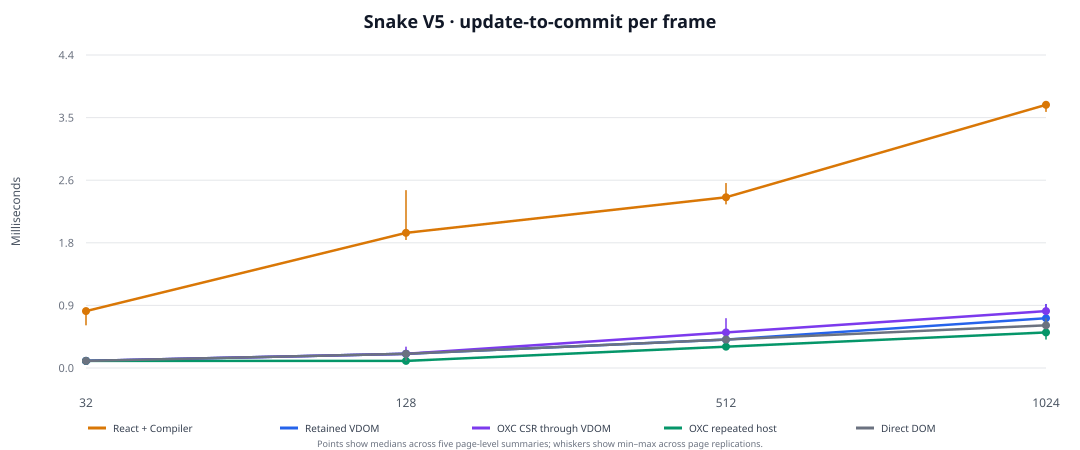

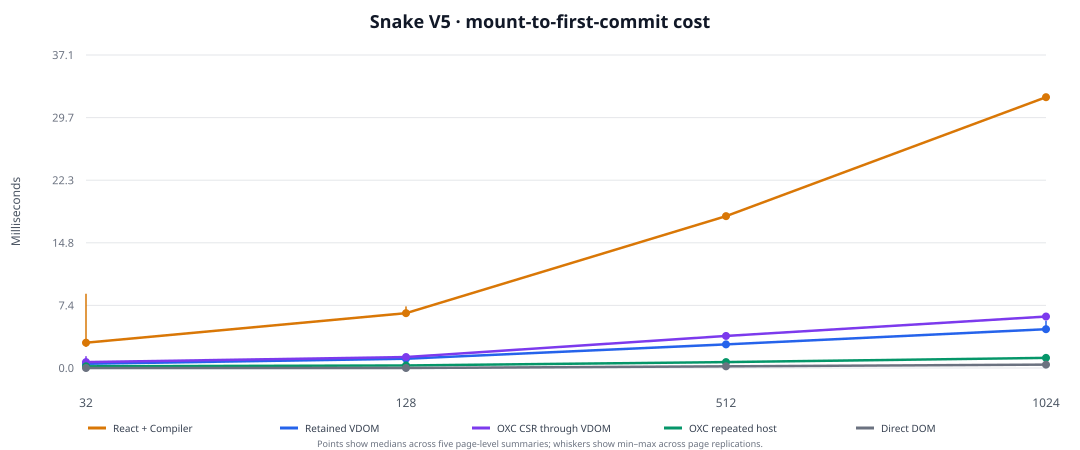

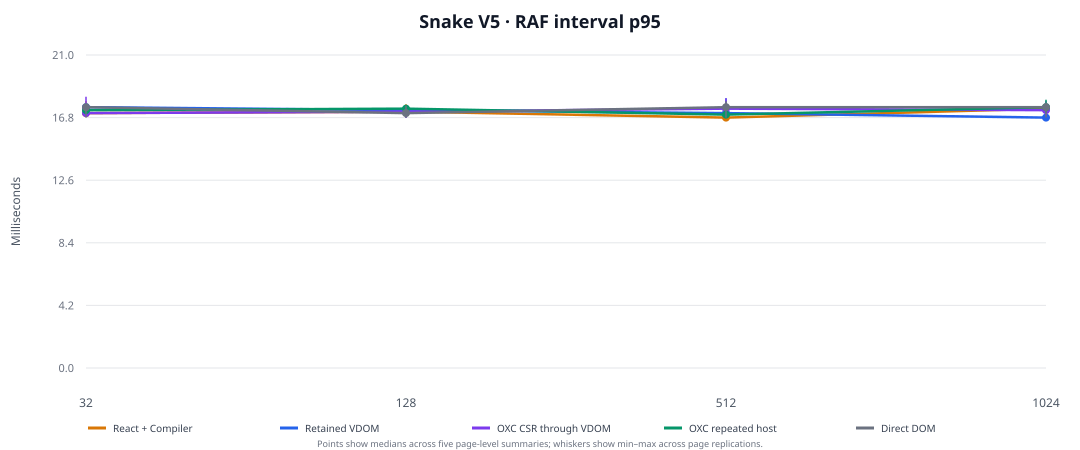

In [67]:
{
const schedule = JSON.parse(
  await Deno.readTextFile("results/browser-snake-frame-v5-preregistration.json"),
);
if (
  schedule.schemaVersion !== "snake-frame-browser-v5-preregistration-v1" ||
  schedule.status !== "PREREGISTERED" || schedule.pages.length !== 100
) throw new Error("V5 preregistration is missing or malformed");

let manifest: any = null;
try {
  manifest = JSON.parse(
    await Deno.readTextFile("results/browser-snake-frame-v5-manifest.json"),
  );
} catch (error) {
  if (!(error instanceof Deno.errors.NotFound)) throw error;
}

if (!manifest) {
  console.log(
    "V5 is preregistered: 100 visible page loads × 300 measured RAF callbacks = 30,000 observations. Browser collection has not produced a manifest yet.",
  );
  Deno.jupyter.svg`<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="170" viewBox="0 0 900 170" role="img" aria-labelledby="v5-pending-title" style="max-width:100%;height:auto;font-family:system-ui,sans-serif"><title id="v5-pending-title">Snake V5 collection pending</title><rect x="1" y="1" width="898" height="168" rx="8" fill="#f8fafc" stroke="#cbd5e1"/><text x="450" y="66" text-anchor="middle" fill="#0f172a" font-size="20" font-weight="650">Snake V5 · preregistered integration comparison</text><text x="450" y="102" text-anchor="middle" fill="#475569" font-size="14">100 page loads · 5 arms · 4 sizes · 5 replications · data pending</text></svg>`;
} else {
  if (
    manifest.schemaVersion !== "snake-frame-browser-v5-manifest-v1" ||
    manifest.status !== "PASS" || manifest.pageLoads !== 100 ||
    manifest.measuredSamples !== 30000 || manifest.files.length !== 100 ||
    manifest.preregistrationSchemaVersion !== schedule.schemaVersion
  ) throw new Error("Snake V5 manifest is missing or incomplete");

  const pages: any[] = [];
  for (const entry of manifest.files) {
    const bytes = await Deno.readFile("results/" + entry.file);
    const digest = await crypto.subtle.digest("SHA-256", bytes);
    const hash = [...new Uint8Array(digest)].map((byte) =>
      byte.toString(16).padStart(2, "0")
    ).join("");
    if (hash !== entry.sha256) throw new Error("SHA-256 mismatch: " + entry.file);
    const page = JSON.parse(new TextDecoder().decode(bytes));
    const expected = schedule.pages.find((item: any) => item.trialId === page.trialId);
    if (
      !expected || page.pageLoadId !== entry.pageLoadId ||
      page.trialId !== entry.trialId || page.arm !== expected.arm ||
      page.segmentCount !== expected.segmentCount ||
      page.measuredFrames !== 300 || page.mountMs !== entry.mountMs ||
      page.schemaVersion !== "snake-frame-browser-v5" ||
      page.status !== "PASS" || !page.allContractsPass ||
      page.browser.visibilityState !== "visible" ||
      !page.allOutputMatches || !page.stableNodeCount ||
      !page.stableNodeIdentity || !page.completeCommitCoverage ||
      page.samples.length !== 300 || !Number.isFinite(page.mountMs) ||
      !page.samples.every((sample: any) =>
        Number.isFinite(sample.intervalMs) && sample.intervalMs > 0 &&
        Number.isFinite(sample.updateCpuMs) && sample.updateCpuMs >= 0 &&
        Number.isFinite(sample.commitMs) && sample.commitMs >= 0
      )
    ) throw new Error("V5 page contract failed: " + entry.file);
    pages.push({ ...page, replication: expected.replication });
  }
  const uniqueIds = new Set(pages.map((page) => page.pageLoadId)).size === 100;
  const uniqueTrials = new Set(pages.map((page) => page.trialId)).size === 100;
  const balanced = schedule.protocol.segmentCounts.every((count: number) =>
    schedule.protocol.arms.every((arm: string) =>
      pages.filter((page) => page.segmentCount === count && page.arm === arm).length === 5
    )
  );
  if (!uniqueIds || !uniqueTrials || !balanced) {
    throw new Error("V5 page-load identity or balance contract failed");
  }

  const percentile = (values: number[], p: number) => {
    const sorted = [...values].sort((a, b) => a - b);
    return sorted[Math.max(0, Math.ceil(p * sorted.length) - 1)];
  };
  const median = (values: number[]) => {
    const sorted = [...values].sort((a, b) => a - b);
    const middle = Math.floor(sorted.length / 2);
    return sorted.length % 2
      ? sorted[middle]
      : (sorted[middle - 1] + sorted[middle]) / 2;
  };
  const counts: number[] = schedule.protocol.segmentCounts;
  const arms: string[] = schedule.protocol.arms;
  const rows = new Map<string, any>();
  for (const count of counts) {
    for (const arm of arms) {
      const selected = pages.filter((page) =>
        page.segmentCount === count && page.arm === arm
      );
      const pageMedians = selected.map((page) =>
        median(page.samples.map((sample: any) => sample.commitMs))
      );
      const pageP95s = selected.map((page) =>
        percentile(page.samples.map((sample: any) => sample.commitMs), 0.95)
      );
      const pageRafP95s = selected.map((page) =>
        percentile(page.samples.map((sample: any) => sample.intervalMs), 0.95)
      );
      const pageCpuMedians = selected.map((page) =>
        median(page.samples.map((sample: any) => sample.updateCpuMs))
      );
      const mountValues = selected.map((page) => page.mountMs);
      const heapMountDeltas = selected.flatMap((page) =>
        Number.isFinite(page.heapUsedBeforeMountBytes) &&
          Number.isFinite(page.heapUsedAfterMountBytes)
          ? [page.heapUsedAfterMountBytes - page.heapUsedBeforeMountBytes]
          : []
      );
      const heapFrameDeltas = selected.flatMap((page) =>
        Number.isFinite(page.heapUsedAfterMountBytes) &&
          Number.isFinite(page.heapUsedAfterMeasuredFramesBytes)
          ? [page.heapUsedAfterMeasuredFramesBytes - page.heapUsedAfterMountBytes]
          : []
      );
      rows.set(`${count}/${arm}`, {
        pageMedians,
        medianCommit: median(pageMedians),
        medianP95: median(pageP95s),
        pageRafP95s,
        medianRafP95: median(pageRafP95s),
        medianCpu: median(pageCpuMedians),
        mountValues,
        medianMount: median(mountValues),
        medianHeapMountDelta: heapMountDeltas.length
          ? median(heapMountDeltas)
          : null,
        medianHeapFrameDelta: heapFrameDeltas.length
          ? median(heapFrameDeltas)
          : null,
      });
    }
  }

  console.log(
    `SHA-256 validated ${pages.length} page loads × 300 measured RAFs = ${pages.length * 300} samples; page load is the replication unit.`,
  );
  console.log(
    `Environment: ${manifest.environment.userAgent}; ${manifest.environment.viewport.width}×${manifest.environment.viewport.height}; DPR ${manifest.environment.devicePixelRatio}; React ${manifest.environment.reactVersion}.`,
  );
  console.log(
    `Collection mode: Vite ${manifest.collectionContext.buildMode} server; post-hoc note: ${manifest.collectionContext.preregistrationDeviation}`,
  );
  console.log(
    "segments | arm | mount median ms | update CPU median ms | update-to-commit median/p95 ms | heap delta mount/updates bytes (diagnostic)",
  );
  for (const count of counts) {
    for (const arm of arms) {
      const row = rows.get(`${count}/${arm}`)!;
      console.log(
        `${count} | ${arm} | ${row.medianMount.toFixed(3)} | ${row.medianCpu.toFixed(3)} | ${row.medianCommit.toFixed(3)}/${row.medianP95.toFixed(3)} | ${row.medianHeapMountDelta?.toFixed(0) ?? "n/a"}/${row.medianHeapFrameDelta?.toFixed(0) ?? "n/a"}`,
      );
    }
  }

  console.log("segments | arm | RAF interval p95 median across pages ms");
  for (const count of counts) {
    for (const arm of arms) {
      const row = rows.get(`${count}/${arm}`)!;
      console.log(
        `${count} | ${arm} | ${row.medianRafP95.toFixed(2)} (page range ${Math.min(...row.pageRafP95s).toFixed(2)}–${Math.max(...row.pageRafP95s).toFixed(2)})`,
      );
    }
  }

  console.log("Break-even updates versus React, paired by size and replication:");
  for (const count of counts) {
    for (const arm of arms.filter((candidate) => candidate !== "react")) {
      const pairedFrames: number[] = [];
      for (let replication = 1; replication <= 5; replication++) {
        const reactPage = pages.find((page) =>
          page.segmentCount === count && page.arm === "react" &&
          page.replication === replication
        );
        const armPage = pages.find((page) =>
          page.segmentCount === count && page.arm === arm &&
          page.replication === replication
        );
        const reactCommit = median(reactPage.samples.map((sample: any) => sample.commitMs));
        const armCommit = median(armPage.samples.map((sample: any) => sample.commitMs));
        const frameSaving = reactCommit - armCommit;
        if (frameSaving > 0) {
          pairedFrames.push(
            Math.max(0, armPage.mountMs - reactPage.mountMs) / frameSaving,
          );
        }
      }
      console.log(
        `${count} | ${arm} | ${pairedFrames.length ? median(pairedFrames).toFixed(1) : "no frame saving in paired pages"}`,
      );
    }
  }

  const colors: Record<string, string> = {
    react: "#d97706",
    runtime: "#2563eb",
    "generated-vdom": "#7c3aed",
    generated: "#059669",
    direct: "#6b7280",
  };
  const labels: Record<string, string> = {
    react: "React + Compiler",
    runtime: "Retained VDOM",
    "generated-vdom": "OXC CSR through VDOM",
    generated: "OXC repeated host",
    direct: "Direct DOM",
  };
  const valuesFor = (row: any, metric: "commit" | "mount" | "raf") =>
    metric === "commit"
      ? row.pageMedians
      : metric === "mount"
      ? row.mountValues
      : row.pageRafP95s;
  const chart = (title: string, metric: "commit" | "mount" | "raf") => {
    const width = 1080, height = 450, left = 86, right = 34, top = 55, bottom = 82;
    const chartHeight = height - top - bottom, chartWidth = width - left - right;
    const all = counts.flatMap((count) => arms.flatMap((arm) => {
      const row = rows.get(`${count}/${arm}`)!;
      return valuesFor(row, metric);
    }));
    const yMax = Math.max(0.1, Math.ceil(Math.max(...all) * 1.15 * 10) / 10);
    const xAt = (index: number) => left + chartWidth * index / (counts.length - 1);
    const yAt = (value: number) => top + chartHeight * (1 - value / yMax);
    const parts = [
      `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${height}" viewBox="0 0 ${width} ${height}" role="img" aria-label="${title}" style="max-width:100%;height:auto;font-family:system-ui,sans-serif">`,
      `<title>${title}</title>`,
      `<text x="${width / 2}" y="28" text-anchor="middle" fill="#111827" font-size="18" font-weight="650">${title}</text>`,
    ];
    for (let tick = 0; tick <= 5; tick++) {
      const value = yMax * tick / 5, y = yAt(value);
      parts.push(
        `<line x1="${left}" y1="${y}" x2="${width - right}" y2="${y}" stroke="#e5e7eb"/><text x="${left - 12}" y="${y + 4}" text-anchor="end" fill="#6b7280" font-size="11">${value.toFixed(1)}</text>`,
      );
    }
    parts.push(
      `<text x="20" y="${top + chartHeight / 2}" text-anchor="middle" transform="rotate(-90 20 ${top + chartHeight / 2})" fill="#4b5563" font-size="12">Milliseconds</text>`,
    );
    counts.forEach((count, index) => parts.push(
      `<text x="${xAt(index)}" y="${height - 43}" text-anchor="middle" fill="#4b5563" font-size="12">${count}</text>`,
    ));
    for (const arm of arms) {
      const points = counts.map((count, index) => {
        const row = rows.get(`${count}/${arm}`)!;
        const values = valuesFor(row, metric);
        return {
          x: xAt(index), y: yAt(median(values)),
          low: yAt(Math.min(...values)), high: yAt(Math.max(...values)),
        };
      });
      parts.push(
        `<polyline points="${points.map((point) => `${point.x},${point.y}`).join(" ")}" fill="none" stroke="${colors[arm]}" stroke-width="2.5"/>`,
      );
      for (const point of points) parts.push(
        `<line x1="${point.x}" y1="${point.low}" x2="${point.x}" y2="${point.high}" stroke="${colors[arm]}" stroke-width="1.5"/><circle cx="${point.x}" cy="${point.y}" r="4" fill="${colors[arm]}"/>`,
      );
    }
    const legendWidth = chartWidth / arms.length;
    arms.forEach((arm, index) => {
      const x = left + legendWidth * index + 2;
      parts.push(
        `<line x1="${x}" y1="${height - 22}" x2="${x + 18}" y2="${height - 22}" stroke="${colors[arm]}" stroke-width="3"/><text x="${x + 25}" y="${height - 18}" fill="#374151" font-size="10">${labels[arm]}</text>`,
      );
    });
    parts.push(
      `<text x="${width / 2}" y="${height - 3}" text-anchor="middle" fill="#6b7280" font-size="9">Points show medians across five page-level summaries; whiskers show min–max across page replications.</text></svg>`,
    );
    return parts.join("");
  };
  await Deno.jupyter.display(
    Deno.jupyter.svg`${chart("Snake V5 · update-to-commit per frame", "commit")}`,
  );
  await Deno.jupyter.display(
    Deno.jupyter.svg`${chart("Snake V5 · mount-to-first-commit cost", "mount")}`,
  );
  await Deno.jupyter.display(
    Deno.jupyter.svg`${chart("Snake V5 · RAF interval p95", "raf")}`,
  );
}

}



## Snake V5 confirmatory production-build replication

This frozen follow-up repeats the V5 5-arm × 4-size × 5-replication schedule against Vite's production build. It has distinct production-prefixed trial IDs and raw files under `results/v5-production/`; the development collection remains unchanged. The code below rechecks every raw-file SHA-256 digest and each page's production-mode tag before pairing medians by size and replication.

The primary measure is synchronous update-to-commit time. RAF interval p95 is a cadence diagnostic, not a paint or presentation measurement. Both datasets use one Chrome/device profile, and results remain specific to this fixed-topology DOM animation.

**Implementation diagnosis to test next (source audit, not a causal result):** the compiled VDOM arm currently creates two `ScalarSource` objects per segment and a fresh update tuple for every source on every measured frame. `VDOMSnapshotRoot.setSources` then creates a `Map` and `Set` for generic deduplication. The CSR graph identifies prop bindings, but this path does not use entity/trait columns or a batched column-to-writer dispatch. The next performance gate should test whether compiler-selected columnar updates remove that per-prop work while keeping JSX declarative and preserving the VDOM for structural changes.


Paired production-build replication; medians across five page-load summaries (ms)


segments | arm | mount | update CPU | update-to-commit median / p95 | RAF interval p95


32 | react | 1.100 | 0.200 | 0.600 / 0.900 | 18.20


32 | runtime | 0.700 | 0.300 | 0.300 / 0.500 | 18.10


32 | generated-vdom | 0.800 | 0.300 | 0.300 / 0.500 | 18.20


...

512 | direct | median paired ratio 0.500× React; 5/5 paired page medians faster


1024 | runtime | median paired ratio 0.615× React; 5/5 paired page medians faster


1024 | generated-vdom | median paired ratio 0.692× React; 5/5 paired page medians faster


1024 | generated | median paired ratio 0.308× React; 5/5 paired page medians faster


1024 | direct | median paired ratio 0.538× React; 5/5 paired page medians faster


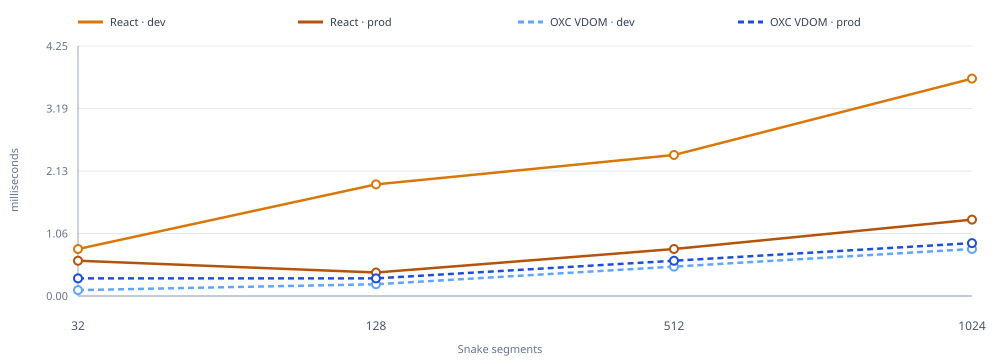

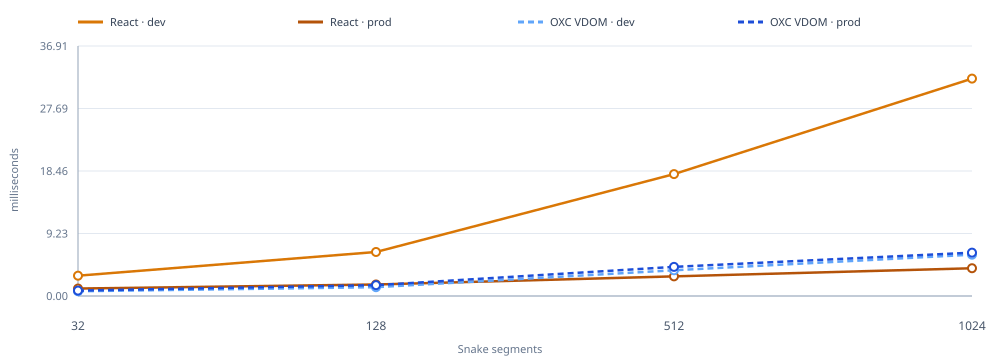

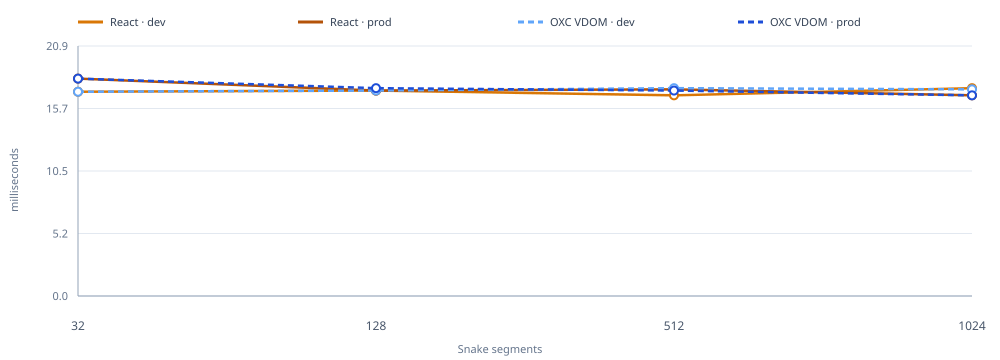

In [68]:
{
const devManifest = JSON.parse(await Deno.readTextFile(
  "results/browser-snake-frame-v5-manifest.json",
));
const prodManifest = JSON.parse(await Deno.readTextFile(
  "results/browser-snake-frame-v5-production-manifest.json",
));
const prodSchedule = JSON.parse(await Deno.readTextFile(
  "results/browser-snake-frame-v5-production-preregistration.json",
));
if (
  devManifest.status !== "PASS" || devManifest.pageLoads !== 100 ||
  prodManifest.status !== "PASS" || prodManifest.pageLoads !== 100 ||
  prodManifest.measuredSamples !== 30000 || prodSchedule.status !== "PREREGISTERED"
) throw new Error("V5 dev/production manifests or schedule are incomplete");

const readPages = async (manifest: any, production: boolean) => {
  const pages = [];
  for (const entry of manifest.files) {
    const path = "results/" + (entry.path ?? entry.file);
    const bytes = await Deno.readFile(path);
    const digest = await crypto.subtle.digest("SHA-256", bytes);
    const hash = [...new Uint8Array(digest)].map((byte) =>
      byte.toString(16).padStart(2, "0")
    ).join("");
    if (hash !== entry.sha256) throw new Error(`SHA-256 mismatch: ${path}`);
    const page = JSON.parse(new TextDecoder().decode(bytes));
    const expected = production
      ? prodSchedule.pages.find((item: any) => item.trialId === page.trialId)
      : null;
    if (
      page.status !== "PASS" || !page.allContractsPass ||
      page.schemaVersion !== "snake-frame-browser-v5" ||
      page.samples.length !== 300 || page.measuredFrames !== 300 ||
      (production && (!expected || page.buildMode !== "production" || page.collection !== "production" || page.arm !== expected.arm || page.segmentCount !== expected.segmentCount))
    ) throw new Error(`V5 page contract failed: ${path}`);
    pages.push({
      ...page,
      mode: production ? "production" : "development",
      replication: production ? expected.replication : Number(page.trialId.match(/rep(\d+)/)?.[1]),
    });
  }
  return pages;
};
const devPages = await readPages(devManifest, false);
const prodPages = await readPages(prodManifest, true);
if (devPages.length !== 100 || prodPages.length !== 100) {
  throw new Error("Expected 100 page loads per collection mode");
}
const percentile = (xs: number[], p: number) => {
  const sorted = [...xs].sort((a, b) => a - b);
  return sorted[Math.max(0, Math.ceil(p * sorted.length) - 1)];
};
const median = (xs: number[]) => {
  const sorted = [...xs].sort((a, b) => a - b);
  const i = Math.floor(sorted.length / 2);
  return sorted.length % 2 ? sorted[i] : (sorted[i - 1] + sorted[i]) / 2;
};
const pageStats = (page: any) => ({
  commit: median(page.samples.map((s: any) => s.commitMs)),
  p95: percentile(page.samples.map((s: any) => s.commitMs), 0.95),
  cpu: median(page.samples.map((s: any) => s.updateCpuMs)),
  raf: percentile(page.samples.map((s: any) => s.intervalMs), 0.95),
  mount: page.mountMs,
});
const counts = [32, 128, 512, 1024];
const arms = ["react", "runtime", "generated-vdom", "generated", "direct"];
const modes = [
  { label: "Development", pages: devPages },
  { label: "Production", pages: prodPages },
];
const rows: any[] = [];
for (const mode of modes) for (const count of counts) for (const arm of arms) {
  const selected = mode.pages.filter((p: any) => p.segmentCount === count && p.arm === arm);
  if (selected.length !== 5) throw new Error(`${mode.label} balance failure: ${count}/${arm}`);
  const stats = selected.map(pageStats);
  rows.push({
    mode: mode.label,
    segmentCount: count,
    arm,
    mountMs: median(stats.map((s) => s.mount)),
    updateCpuMs: median(stats.map((s) => s.cpu)),
    updateMedianMs: median(stats.map((s) => s.commit)),
    updateP95Ms: median(stats.map((s) => s.p95)),
    rafIntervalP95Ms: median(stats.map((s) => s.raf)),
  });
}
console.log("Paired production-build replication; medians across five page-load summaries (ms)");
console.log("segments | arm | mount | update CPU | update-to-commit median / p95 | RAF interval p95");
for (const row of rows.filter((r) => r.mode === "Production")) {
  console.log(`${row.segmentCount} | ${row.arm} | ${row.mountMs.toFixed(3)} | ${row.updateCpuMs.toFixed(3)} | ${row.updateMedianMs.toFixed(3)} / ${row.updateP95Ms.toFixed(3)} | ${row.rafIntervalP95Ms.toFixed(2)}`);
}
console.log("Production paired median ratios vs React (same size and replication; lower is faster)");
for (const count of counts) for (const arm of arms.filter((a) => a !== "react")) {
  const ratios = [];
  for (let rep = 1; rep <= 5; rep++) {
    const react = prodPages.find((p: any) => p.segmentCount === count && p.arm === "react" && p.replication === rep);
    const candidate = prodPages.find((p: any) => p.segmentCount === count && p.arm === arm && p.replication === rep);
    ratios.push(pageStats(candidate).commit / pageStats(react).commit);
  }
  console.log(`${count} | ${arm} | median paired ratio ${median(ratios).toFixed(3)}× React; ${ratios.filter((x) => x < 1).length}/5 paired page medians faster`);
}

const plot = (title: string, metric: "updateMedianMs" | "mountMs" | "rafIntervalP95Ms") => {
  const width = 1000, height = 360, left = 78, right = 28, top = 46, bottom = 64;
  const chartW = width - left - right, chartH = height - top - bottom;
  const selected = rows.filter((r) => r.arm === "react" || r.arm === "generated-vdom");
  const maxValue = Math.max(...selected.map((r) => r[metric])) * 1.15 || 1;
  const x = (i: number) => left + (chartW * i) / (counts.length - 1);
  const y = (v: number) => top + chartH - (v / maxValue) * chartH;
  const series = [
    { arm: "react", mode: "development", label: "React · dev", color: "#d97706", dash: "" },
    { arm: "react", mode: "production", label: "React · prod", color: "#b45309", dash: "" },
    { arm: "generated-vdom", mode: "development", label: "OXC VDOM · dev", color: "#60a5fa", dash: "6 4" },
    { arm: "generated-vdom", mode: "production", label: "OXC VDOM · prod", color: "#1d4ed8", dash: "6 4" },
  ];
  const grid = Array.from({ length: 5 }, (_, i) => {
    const value = maxValue * i / 4;
    return `<line x1="${left}" x2="${width-right}" y1="${y(value)}" y2="${y(value)}" stroke="#e2e8f0"/><text x="${left-10}" y="${y(value)+4}" text-anchor="end" fill="#64748b" font-size="11">${value.toFixed(metric === "rafIntervalP95Ms" ? 1 : 2)}</text>`;
  }).join("");
  const lines = series.map((s) => {
    const values = counts.map((count) => rows.find((r) => r.mode === (s.mode === "production" ? "Production" : "Development") && r.segmentCount === count && r.arm === s.arm)[metric]);
    const points = values.map((v, i) => `${x(i)},${y(v)}`).join(" ");
    const dots = values.map((v, i) => `<circle cx="${x(i)}" cy="${y(v)}" r="4" fill="white" stroke="${s.color}" stroke-width="2"/>`).join("");
    return `<polyline points="${points}" fill="none" stroke="${s.color}" stroke-width="2.5" ${s.dash ? `stroke-dasharray="${s.dash}"` : ""}/>${dots}`;
  }).join("");
  const labels = counts.map((count, i) => `<text x="${x(i)}" y="${height-30}" text-anchor="middle" fill="#475569" font-size="12">${count}</text>`).join("");
  const legend = series.map((s, i) => `<line x1="${left + i*220}" x2="${left+25+i*220}" y1="22" y2="22" stroke="${s.color}" stroke-width="3" ${s.dash ? `stroke-dasharray="${s.dash}"` : ""}/><text x="${left+32+i*220}" y="26" fill="#334155" font-size="11">${s.label}</text>`).join("");
  return Deno.jupyter.svg`<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${height}" viewBox="0 0 ${width} ${height}" role="img" aria-label="${title}" style="max-width:100%;height:auto;font-family:system-ui,sans-serif"><title>${title}</title><rect width="100%" height="100%" fill="white"/>${legend}${grid}<line x1="${left}" x2="${left}" y1="${top}" y2="${top+chartH}" stroke="#94a3b8"/><line x1="${left}" x2="${width-right}" y1="${top+chartH}" y2="${top+chartH}" stroke="#94a3b8"/>${labels}${lines}<text x="${width/2}" y="${height-7}" text-anchor="middle" fill="#64748b" font-size="11">Snake segments</text><text x="18" y="${height/2}" transform="rotate(-90 18 ${height/2})" text-anchor="middle" fill="#64748b" font-size="11">milliseconds</text></svg>`;
};
await Deno.jupyter.display(plot("React and OXC VDOM update-to-commit medians by build mode", "updateMedianMs"));
await Deno.jupyter.display(plot("React and OXC VDOM mount medians by build mode", "mountMs"));
await Deno.jupyter.display(plot("React and OXC VDOM RAF interval p95 by build mode", "rafIntervalP95Ms"));

}



## Snake V6 production columnar binding experiment

V6 isolates a specific design question from the production V5 integration study: can compiled bindings read position data directly from reusable numeric trait columns and dispatch to retained host writers without per-frame source tuples, maps, or sets? Five arms (React + Compiler, runtime-discovered VDOM, generated scalar-source VDOM, generated columnar VDOM, and cached direct DOM) consume the same preallocated x/y columns. The 75-page schedule covers 128, 512, and 1,024 segments with five paired page-load replications per arm and size.

The frozen React arm uses per-segment useSyncExternalStore snapshots and batches notifications with unstable_batchedUpdates; timed RAF updates do not call flushSync, and a useLayoutEffect marker records commit completion. The cell below revalidates the frozen source lock and every raw record hash, then checks schedule balance and output/host-identity contracts before it summarizes page medians. The page load is the replication unit; its 300 animation frames are nested samples. The primary measure remains update-to-commit time, while CPU, mount, and RAF interval p95 provide different cost and cadence views. It also reports a post-hoc mount-amortization estimate from paired page medians; this is descriptive, excludes compilation, page load, teardown, and presentation, and is especially coarse near the browser's 0.1 ms timing floor. These are fixed-topology DOM results from one visible browser/device environment; RAF cadence is not pixel-presentation latency.


V6 production: medians across five isolated page-load summaries; milliseconds


segments | arm | mount | update CPU | update-to-commit median / p95 | RAF interval p95


128 | react | 1.700 | 0.100 | 0.400 / 0.500 | 17.10


128 | runtime | 1.200 | 0.200 | 0.200 / 0.300 | 17.20


128 | generated-vdom | 1.500 | 0.200 | 0.200 / 0.300 | 17.10


...

1024 | runtime | 1 updates (0–3) | 5/5 pairs


1024 | generated-vdom | 7 updates (5–15) | 5/5 pairs


1024 | columnar-vdom | 4 updates (3–4) | 5/5 pairs


1024 | direct | 0 updates (0–0) | 5/5 pairs


This post-hoc estimate uses each paired page's mount time and median update-to-commit time; it excludes compilation, page load, teardown, and presentation, and is especially coarse near the 0.1 ms timer floor.


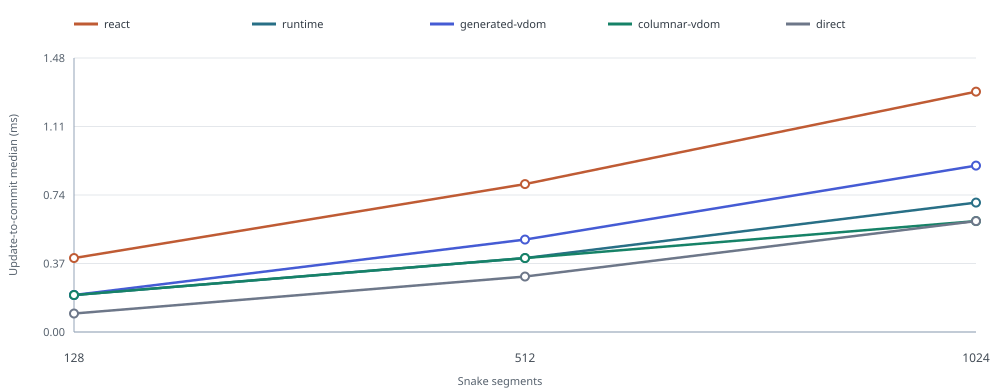

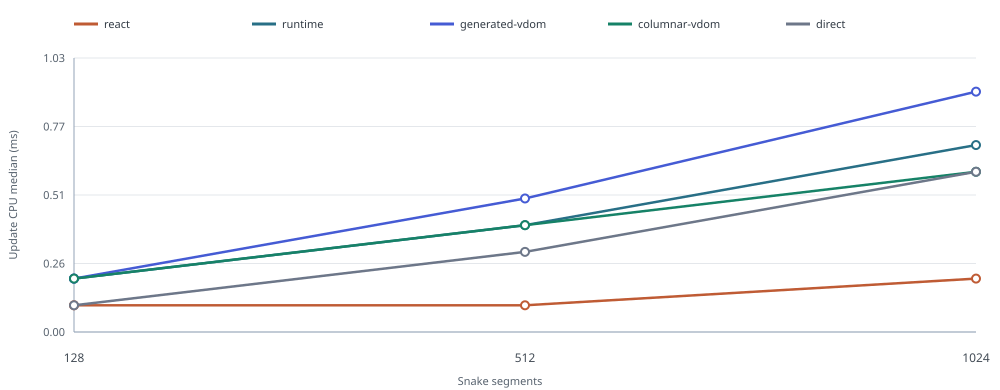

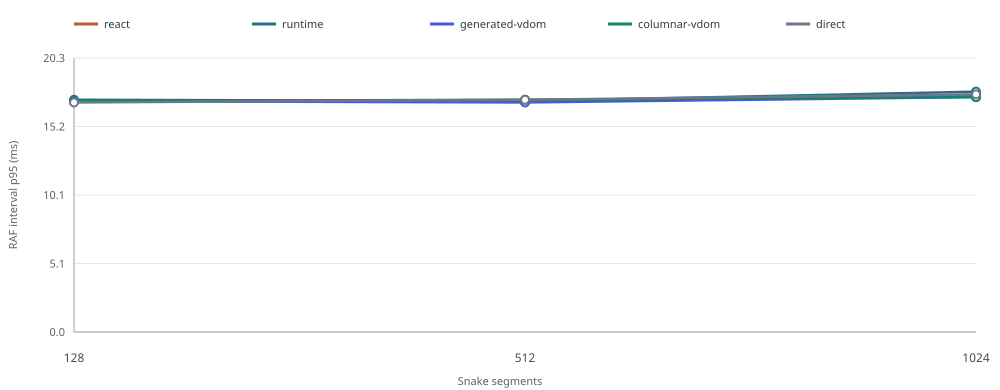

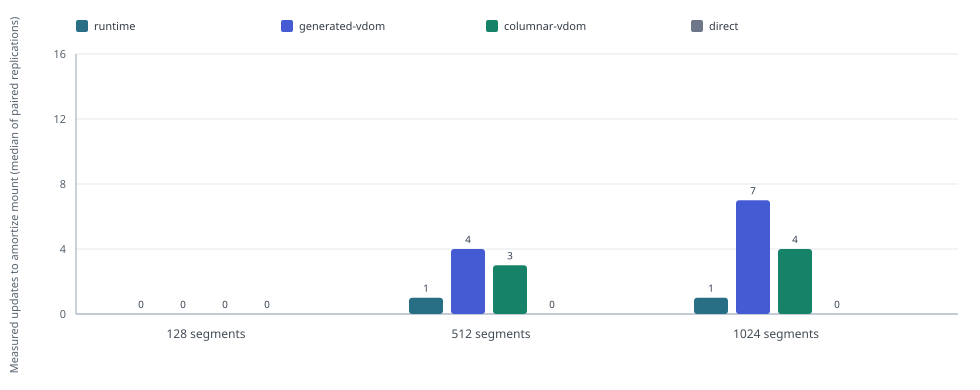

In [69]:
{
const schedule = JSON.parse(await Deno.readTextFile(
  "results/browser-snake-frame-v6-production-preregistration.json",
));
const manifest = JSON.parse(await Deno.readTextFile(
  "results/browser-snake-frame-v6-production-manifest.json",
));
const sourceLock = JSON.parse(await Deno.readTextFile(
  "results/browser-snake-frame-v6-production-source-lock.json",
));
const sourceSnapshot = JSON.parse(await Deno.readTextFile(
  "results/browser-snake-frame-v6-source-snapshot-manifest.json",
));
if (
  schedule.status !== "PREREGISTERED" || schedule.pages.length !== 75 ||
  manifest.status !== "PASS" || manifest.pageLoads !== 75 ||
  manifest.measuredSamples !== 22500 || sourceLock.status !== "FROZEN_BEFORE_COLLECTION" ||
  sourceSnapshot.status !== "PASS" || sourceSnapshot.fileCount !== sourceLock.files.length
) throw new Error("V6 preregistration, manifest, or source lock is incomplete");

const hash = async (bytes: Uint8Array) => {
  const digest = await crypto.subtle.digest("SHA-256", bytes);
  return [...new Uint8Array(digest)].map((byte) =>
    byte.toString(16).padStart(2, "0")
  ).join("");
};
for (const entry of sourceLock.files) {
  const bytes = await Deno.readFile(`${sourceSnapshot.snapshotRoot}/${entry.path}`);
  if (bytes.byteLength !== entry.bytes || await hash(bytes) !== entry.sha256) {
    throw new Error(`V6 archived source lock mismatch: ${entry.path}`);
  }
}
for (const dependency of sourceSnapshot.supplementalDependencies ?? []) {
  const bytes = await Deno.readFile(`${sourceSnapshot.snapshotRoot}/${dependency.snapshotPath}`);
  if (bytes.byteLength !== dependency.bytes || await hash(bytes) !== dependency.sha256) {
    throw new Error(`V6 supplemental dependency hash mismatch: ${dependency.sourcePath}`);
  }
}
const pages: any[] = [];
for (const entry of manifest.files) {
  const path = `results/${entry.path}`;
  const bytes = await Deno.readFile(path);
  if (await hash(bytes) !== entry.sha256) throw new Error(`Raw hash mismatch: ${path}`);
  const record = JSON.parse(new TextDecoder().decode(bytes));
  const expected = schedule.pages.find((page: any) => page.trialId === record.trialId);
  if (
    !expected || record.schemaVersion !== "snake-frame-browser-v6" ||
    record.status !== "PASS" || !record.allContractsPass ||
    record.buildMode !== "production" || record.collection !== "production-v6" ||
    record.arm !== expected.arm || record.segmentCount !== expected.segmentCount ||
    record.measuredFrames !== 300 || record.samples.length !== 300 ||
    !record.completeCommitCoverage || !record.allOutputMatches ||
    !record.stableNodeCount || !record.stableNodeIdentity
  ) throw new Error(`V6 page contract failed: ${path}`);
  pages.push({ ...record, replication: expected.replication });
}
if (pages.length !== 75) throw new Error("Expected 75 V6 pages");
const arms = ["react", "runtime", "generated-vdom", "columnar-vdom", "direct"];
const sizes = [128, 512, 1024];
for (const size of sizes) for (const arm of arms) {
  if (pages.filter((page) => page.segmentCount === size && page.arm === arm).length !== 5) {
    throw new Error(`V6 balance failure: ${size}/${arm}`);
  }
}
const percentile = (values: number[], p: number) => {
  const sorted = [...values].sort((a, b) => a - b);
  return sorted[Math.max(0, Math.ceil(p * sorted.length) - 1)];
};
const median = (values: number[]) => {
  const sorted = [...values].sort((a, b) => a - b);
  const middle = Math.floor(sorted.length / 2);
  return sorted.length % 2 ? sorted[middle] : (sorted[middle - 1] + sorted[middle]) / 2;
};
const stats = (page: any) => ({
  commit: median(page.samples.map((sample: any) => sample.commitMs)),
  commitP95: percentile(page.samples.map((sample: any) => sample.commitMs), 0.95),
  cpu: median(page.samples.map((sample: any) => sample.updateCpuMs)),
  rafP95: percentile(page.samples.map((sample: any) => sample.intervalMs), 0.95),
  mount: page.mountMs,
});
const summaries = [];
for (const size of sizes) for (const arm of arms) {
  const selected = pages.filter((page) => page.segmentCount === size && page.arm === arm);
  const values = selected.map(stats);
  summaries.push({
    size,
    arm,
    mount: median(values.map((value) => value.mount)),
    cpu: median(values.map((value) => value.cpu)),
    commit: median(values.map((value) => value.commit)),
    commitP95: median(values.map((value) => value.commitP95)),
    rafP95: median(values.map((value) => value.rafP95)),
  });
}
console.log("V6 production: medians across five isolated page-load summaries; milliseconds");
console.log("segments | arm | mount | update CPU | update-to-commit median / p95 | RAF interval p95");
for (const row of summaries) {
  console.log(`${row.size} | ${row.arm} | ${row.mount.toFixed(3)} | ${row.cpu.toFixed(3)} | ${row.commit.toFixed(3)} / ${row.commitP95.toFixed(3)} | ${row.rafP95.toFixed(2)}`);
}
console.log("Paired commit-median ratios vs React (matching replication; <1 favors candidate)");
for (const size of sizes) for (const arm of arms.filter((value) => value !== "react")) {
  const ratios = [];
  for (let replication = 1; replication <= 5; replication++) {
    const react = pages.find((page) => page.segmentCount === size && page.arm === "react" && page.replication === replication);
    const candidate = pages.find((page) => page.segmentCount === size && page.arm === arm && page.replication === replication);
    ratios.push(stats(candidate).commit / stats(react).commit);
  }
  console.log(`${size} | ${arm} | ${median(ratios).toFixed(3)}× React; ${ratios.filter((ratio) => ratio < 1).length}/5 paired pages faster`);
}
console.log("Paired update-CPU median ratios: columnar VDOM vs scalar generated VDOM and runtime VDOM");
for (const size of sizes) for (const comparison of ["generated-vdom", "runtime"]) {
  const ratios = [];
  for (let replication = 1; replication <= 5; replication++) {
    const baseline = pages.find((page) => page.segmentCount === size && page.arm === comparison && page.replication === replication);
    const columnar = pages.find((page) => page.segmentCount === size && page.arm === "columnar-vdom" && page.replication === replication);
    ratios.push(stats(columnar).cpu / stats(baseline).cpu);
  }
  console.log(`${size} | columnar / ${comparison} | ${median(ratios).toFixed(3)}×; ${ratios.filter((ratio) => ratio < 1).length}/5 paired pages lower`);
}

// Exploratory mount amortization: how many measured updates offset extra mount time?
const breakEvenRows: Array<{
  size: number;
  arm: string;
  medianUpdates: number | null;
  minimumUpdates: number | null;
  maximumUpdates: number | null;
  finitePairs: number;
}> = [];
console.log("Exploratory mount-amortization estimate vs React (updates to offset mount difference)");
for (const size of sizes) for (const arm of arms.filter((value) => value !== "react")) {
  const estimates: Array<number | null> = [];
  for (let replication = 1; replication <= 5; replication++) {
    const react = pages.find((page) => page.segmentCount === size && page.arm === "react" && page.replication === replication);
    const candidate = pages.find((page) => page.segmentCount === size && page.arm === arm && page.replication === replication);
    const extraMount = candidate.mountMs - react.mountMs;
    const perUpdateSaving = stats(react).commit - stats(candidate).commit;
    estimates.push(extraMount <= 0 ? 0 : perUpdateSaving > 0 ? Math.ceil(extraMount / perUpdateSaving) : null);
  }
  const finite = estimates.filter((value): value is number => value !== null).sort((a, b) => a - b);
  const summary = finite.length ? {
    medianUpdates: median(finite),
    minimumUpdates: finite[0],
    maximumUpdates: finite.at(-1)!,
  } : { medianUpdates: null, minimumUpdates: null, maximumUpdates: null };
  breakEvenRows.push({ size, arm, ...summary, finitePairs: finite.length });
  console.log(`${size} | ${arm} | ${summary.medianUpdates === null ? "no crossover" : `${summary.medianUpdates} updates (${summary.minimumUpdates}–${summary.maximumUpdates})`} | ${finite.length}/5 pairs`);
}
console.log("This post-hoc estimate uses each paired page's mount time and median update-to-commit time; it excludes compilation, page load, teardown, and presentation, and is especially coarse near the 0.1 ms timer floor.");

const colors: Record<string, string> = {
  react: "#bf5b34", runtime: "#286f86", "generated-vdom": "#455bd4",
  "columnar-vdom": "#168267", direct: "#6d7789",
};
const plot = (title: string, metric: "commit" | "cpu" | "rafP95") => {
  const width = 1000, height = 390, left = 74, right = 24, top = 58, bottom = 58;
  const chartWidth = width - left - right, chartHeight = height - top - bottom;
  const maximum = Math.max(...summaries.map((row: any) => row[metric])) * 1.14 || 1;
  const x = (index: number) => left + chartWidth * index / (sizes.length - 1);
  const y = (value: number) => top + chartHeight - chartHeight * value / maximum;
  const grid = Array.from({ length: 5 }, (_, index) => {
    const value = maximum * index / 4;
    return `<line x1="${left}" x2="${width-right}" y1="${y(value)}" y2="${y(value)}" stroke="#e4e7eb"/><text x="${left-9}" y="${y(value)+4}" text-anchor="end" fill="#56616d" font-size="11">${value.toFixed(metric === "rafP95" ? 1 : 2)}</text>`;
  }).join("");
  const lines = arms.map((arm) => {
    const values = sizes.map((size) => summaries.find((row: any) => row.size === size && row.arm === arm)[metric]);
    const points = values.map((value, index) => `${x(index)},${y(value)}`).join(" ");
    const dots = values.map((value, index) => `<circle cx="${x(index)}" cy="${y(value)}" r="4" fill="white" stroke="${colors[arm]}" stroke-width="2"/>`).join("");
    return `<polyline points="${points}" fill="none" stroke="${colors[arm]}" stroke-width="2.5"/>${dots}`;
  }).join("");
  const labels = sizes.map((size, index) => `<text x="${x(index)}" y="${height-28}" text-anchor="middle" fill="#424b55" font-size="12">${size}</text>`).join("");
  const legend = arms.map((arm, index) => `<line x1="${left+index*178}" x2="${left+24+index*178}" y1="24" y2="24" stroke="${colors[arm]}" stroke-width="3"/><text x="${left+30+index*178}" y="28" fill="#323b45" font-size="11">${arm}</text>`).join("");
  const yLabel = metric === "rafP95" ? "RAF interval p95 (ms)" : metric === "cpu" ? "Update CPU median (ms)" : "Update-to-commit median (ms)";
  return Deno.jupyter.svg`<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${height}" viewBox="0 0 ${width} ${height}" role="img" aria-label="${title}" style="max-width:100%;height:auto;font-family:system-ui,sans-serif"><title>${title}</title><rect width="100%" height="100%" fill="white"/>${legend}${grid}<line x1="${left}" x2="${left}" y1="${top}" y2="${top+chartHeight}" stroke="#94a3b8"/><line x1="${left}" x2="${width-right}" y1="${top+chartHeight}" y2="${top+chartHeight}" stroke="#94a3b8"/>${labels}${lines}<text x="${width/2}" y="${height-5}" text-anchor="middle" fill="#56616d" font-size="11">Snake segments</text><text x="17" y="${height/2}" transform="rotate(-90 17 ${height/2})" text-anchor="middle" fill="#56616d" font-size="11">${yLabel}</text></svg>`;
};
await Deno.jupyter.display(plot("V6 production Snake update-to-commit by arm", "commit"));
await Deno.jupyter.display(plot("V6 production Snake update CPU by arm", "cpu"));
await Deno.jupyter.display(plot("V6 production Snake frame interval p95 by arm", "rafP95"));
const breakEvenArms = arms.filter((arm) => arm !== "react");
const breakEvenColors: Record<string, string> = {
  runtime: "#286f86", "generated-vdom": "#455bd4",
  "columnar-vdom": "#168267", direct: "#6d7789",
};
const breakEvenWidth = 980, breakEvenHeight = 390, breakEvenLeft = 76, breakEvenTop = 54;
const breakEvenChartHeight = 260, breakEvenChartWidth = 860, breakEvenMax = 16;
const breakEvenGroupX = (index: number) => breakEvenLeft + 130 + index * 285;
const breakEvenY = (value: number) => breakEvenTop + breakEvenChartHeight - breakEvenChartHeight * value / breakEvenMax;
const breakEvenGrid = Array.from({ length: 5 }, (_, index) => {
  const value = index * 4;
  return `<line x1="${breakEvenLeft}" x2="${breakEvenWidth-22}" y1="${breakEvenY(value)}" y2="${breakEvenY(value)}" stroke="#e4e7eb"/><text x="${breakEvenLeft-10}" y="${breakEvenY(value)+4}" text-anchor="end" fill="#56616d" font-size="11">${value}</text>`;
}).join("");
const breakEvenBars = breakEvenArms.map((arm, armIndex) => sizes.map((size, sizeIndex) => {
  const row = breakEvenRows.find((item) => item.arm === arm && item.size === size)!;
  const value = row.medianUpdates ?? breakEvenMax;
  const barWidth = 34, gap = 8;
  const x = breakEvenGroupX(sizeIndex) + armIndex * (barWidth + gap) - 82;
  const y = breakEvenY(value);
  const height = breakEvenTop + breakEvenChartHeight - y;
  const label = row.medianUpdates === null ? "N/A" : String(row.medianUpdates);
  return `<rect x="${x}" y="${y}" width="${barWidth}" height="${height}" rx="3" fill="${breakEvenColors[arm]}"/><text x="${x+barWidth/2}" y="${y-6}" text-anchor="middle" fill="#374151" font-size="10">${label}</text>`;
}).join("")).join("");
const breakEvenLabels = sizes.map((size, index) => `<text x="${breakEvenGroupX(index)}" y="${breakEvenTop+breakEvenChartHeight+24}" text-anchor="middle" fill="#424b55" font-size="12">${size} segments</text>`).join("");
const breakEvenLegend = breakEvenArms.map((arm, index) => `<rect x="${breakEvenLeft+index*205}" y="20" width="12" height="12" rx="2" fill="${breakEvenColors[arm]}"/><text x="${breakEvenLeft+18+index*205}" y="30" fill="#323b45" font-size="11">${arm}</text>`).join("");
await Deno.jupyter.display(Deno.jupyter.svg`<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${breakEvenHeight}" viewBox="0 0 ${breakEvenWidth} ${breakEvenHeight}" role="img" aria-label="V6 post hoc mount amortization update count" style="max-width:100%;height:auto;font-family:system-ui,sans-serif"><title>Estimated updates to offset VDOM or direct-DOM mount difference versus React</title><rect width="100%" height="100%" fill="white"/>${breakEvenLegend}${breakEvenGrid}<line x1="${breakEvenLeft}" x2="${breakEvenLeft}" y1="${breakEvenTop}" y2="${breakEvenTop+breakEvenChartHeight}" stroke="#94a3b8"/><line x1="${breakEvenLeft}" x2="${breakEvenWidth-22}" y1="${breakEvenTop+breakEvenChartHeight}" y2="${breakEvenTop+breakEvenChartHeight}" stroke="#94a3b8"/>${breakEvenLabels}${breakEvenBars}<text x="18" y="${breakEvenHeight/2}" transform="rotate(-90 18 ${breakEvenHeight/2})" text-anchor="middle" fill="#56616d" font-size="11">Measured updates to amortize mount (median of paired replications)</text></svg>`);

}



## Columnar dispatch density and locality mechanism study

V6 measured a dense update where every segment changes on every frame. This preregistered Deno mechanism sweep tests whether a retained VDOM column binding should scan all rows, dispatch an explicit dirty-row list, or scan 32- or 128-row buckets. It varies entity count (256, 1,024, 4,096), dirty fraction (1–100%), and clustered versus scattered rows. Five fresh Deno processes each run all 144 cells with 30 warmup and 80 measured batches per cell.

The worklist is precomputed and reused; its selection or construction cost is excluded. Every measured update includes writing the selected x/y inputs and synchronously dispatching them through `MemoryVDOMHost`. A post-collection deterministic replay checks every warmup and measured batch against the archived runtime: all entity outputs, stable host identity, and exactly two host writes per dirty row. It passed 79,200 batches and 141.9 million entity state checks without changing timed measurements. These timings are a mechanism diagnostic only: they do not include browser DOM/CSS, React scheduling, layout, paint, or presentation. The archived source snapshot includes the transitive `compiled_bindings.ts` import as a separately hash-pinned supplement because it was omitted from the original source lock.


Deno MemoryVDOM mechanism study; median per-update elapsed microseconds across five fresh processes


size | dirty% | locality | dense scan | dirty rows | bucket 32 | bucket 128


256 | 1 | clustered | 14.96 | 4.00 | 14.90 | 7.25


256 | 1 | scattered | 13.29 | 0.67 | 3.13 | 10.19


256 | 5 | clustered | 5.42 | 1.88 | 1.50 | 3.33


...

256 | scattered | 1%=0.05× 5%=0.30× 10%=0.52× 25%=0.52× 50%=0.66× 100%=1.06×


1024 | clustered | 1%=0.05× 5%=0.20× 10%=0.37× 25%=0.60× 50%=0.92× 100%=1.06×


1024 | scattered | 1%=0.06× 5%=0.18× 10%=0.32× 25%=0.55× 50%=0.61× 100%=1.06×


4096 | clustered | 1%=0.05× 5%=0.22× 10%=0.36× 25%=0.67× 50%=0.88× 100%=1.07×


4096 | scattered | 1%=0.05× 5%=0.24× 10%=0.35× 25%=0.53× 50%=0.63× 100%=1.08×


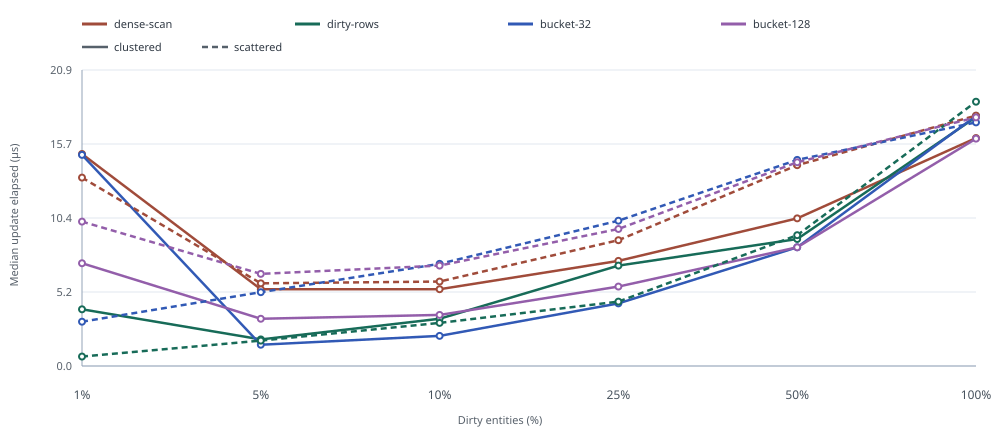

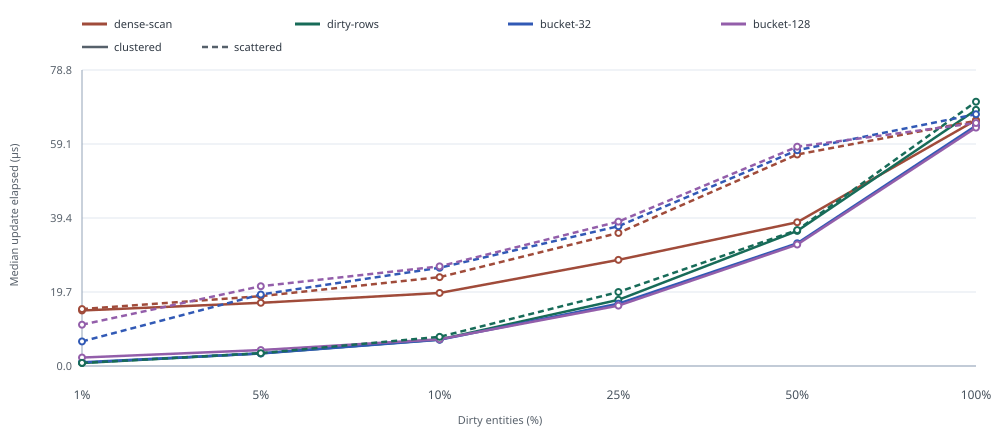

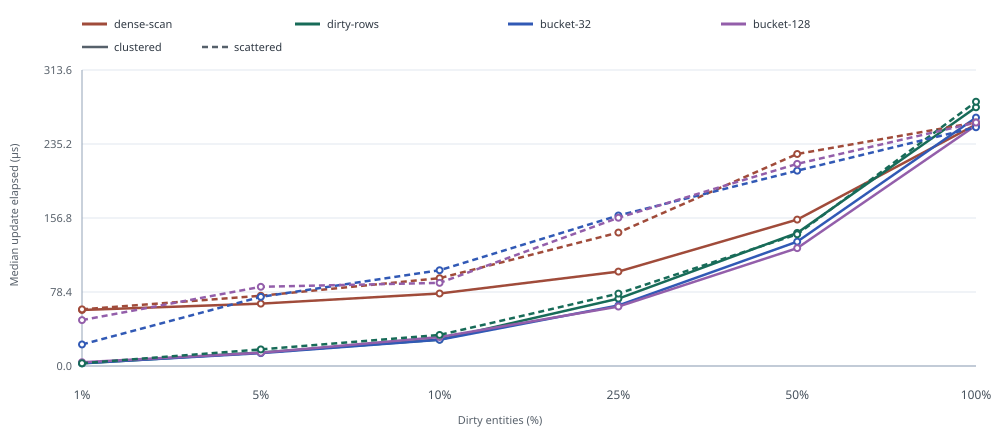

In [70]:
{
const prereg = JSON.parse(await Deno.readTextFile(
  "results/columnar-dispatch-v1-preregistration.json",
));
const manifest = JSON.parse(await Deno.readTextFile(
  "results/columnar-dispatch-v1-manifest.json",
));
const lock = JSON.parse(await Deno.readTextFile(
  "results/columnar-dispatch-v1-source-lock.json",
));
const snapshot = JSON.parse(await Deno.readTextFile(
  "results/columnar-dispatch-v1-source-snapshot-manifest.json",
));
const replay = JSON.parse(await Deno.readTextFile(
  "results/columnar-dispatch-v1-replay-verification.json",
));
if (
  prereg.status !== "PREREGISTERED" || prereg.cases.length !== 720 ||
  manifest.status !== "PASS" || manifest.caseCount !== 720 ||
  manifest.replicationCount !== 5 || manifest.measuredUpdates !== 57600 ||
  manifest.warmupUpdates !== 21600 || lock.status !== "FROZEN_BEFORE_COLLECTION" ||
  snapshot.status !== "PASS" || snapshot.files.length !== lock.files.length ||
  replay.status !== "PASS" || replay.caseCount !== 720 ||
  replay.batchCount !== 79200 || replay.entityChecks !== 141926400 ||
  !replay.allOutputAndIdentityChecksPass
) throw new Error("Columnar dispatch study registration or manifest is incomplete");
const sha256 = async (bytes: Uint8Array) => {
  const digest = await crypto.subtle.digest("SHA-256", bytes);
  return [...new Uint8Array(digest)].map((byte) =>
    byte.toString(16).padStart(2, "0")
  ).join("");
};
for (const entry of lock.files) {
  const bytes = await Deno.readFile(`${snapshot.snapshotRoot}/${entry.path}`);
  if (bytes.byteLength !== entry.bytes || await sha256(bytes) !== entry.sha256) {
    throw new Error(`Archived source hash mismatch: ${entry.path}`);
  }
}
for (const dependency of snapshot.supplementalDependencies ?? []) {
  const bytes = await Deno.readFile(`${snapshot.snapshotRoot}/${dependency.snapshotPath}`);
  if (bytes.byteLength !== dependency.bytes || await sha256(bytes) !== dependency.sha256) {
    throw new Error(`Supplemental dependency hash mismatch: ${dependency.sourcePath}`);
  }
}
const records: any[] = [];
for (const entry of manifest.files) {
  const bytes = await Deno.readFile(`results/${entry.path}`);
  if (await sha256(bytes) !== entry.sha256) throw new Error(`Raw replication hash mismatch: ${entry.path}`);
  const record = JSON.parse(new TextDecoder().decode(bytes));
  if (record.status !== "PASS" || !record.allContractsPass || record.cases.length !== 144) {
    throw new Error(`Replication record contract failed: ${entry.path}`);
  }
  records.push(record);
}
const cells = records.flatMap((record) => record.cases);
const strategies = ["dense-scan", "dirty-rows", "bucket-32", "bucket-128"];
const sizes = [256, 1024, 4096];
const densities = [1, 5, 10, 25, 50, 100];
const localities = ["clustered", "scattered"];
const median = (values: number[]) => {
  const sorted = [...values].sort((a, b) => a - b);
  const middle = Math.floor(sorted.length / 2);
  return sorted.length % 2 ? sorted[middle] : (sorted[middle - 1] + sorted[middle]) / 2;
};
const summaries: any[] = [];
for (const size of sizes) for (const dirtyPercent of densities) for (const locality of localities) {
  const row: any = { size, dirtyPercent, locality };
  for (const strategy of strategies) {
    const matches = cells.filter((cell: any) =>
      cell.size === size && cell.dirtyPercent === dirtyPercent &&
      cell.locality === locality && cell.strategy === strategy
    );
    if (matches.length !== 5) throw new Error(`Missing replication pair: ${size}/${dirtyPercent}/${locality}/${strategy}`);
    row[strategy] = median(matches.map((cell: any) => cell.medianMs * 1000));
    row[`${strategy}P95`] = median(matches.map((cell: any) => cell.p95Ms * 1000));
    row[`${strategy}Mount`] = median(matches.map((cell: any) => cell.mountMs));
  }
  summaries.push(row);
}
console.log("Deno MemoryVDOM mechanism study; median per-update elapsed microseconds across five fresh processes");
console.log("size | dirty% | locality | dense scan | dirty rows | bucket 32 | bucket 128");
for (const row of summaries) {
  console.log(`${row.size} | ${row.dirtyPercent} | ${row.locality} | ${row["dense-scan"].toFixed(2)} | ${row["dirty-rows"].toFixed(2)} | ${row["bucket-32"].toFixed(2)} | ${row["bucket-128"].toFixed(2)}`);
}
console.log("Paired dispatch ratios vs dense scan (lower is faster), pooled across sizes/densities/localities");
for (const strategy of strategies.slice(1)) {
  const ratios: number[] = [];
  let wins = 0;
  for (let replication = 1; replication <= 5; replication++) {
    for (const size of sizes) for (const dirtyPercent of densities) for (const locality of localities) {
      const candidate = cells.find((cell: any) => cell.replication === replication && cell.size === size && cell.dirtyPercent === dirtyPercent && cell.locality === locality && cell.strategy === strategy);
      const baseline = cells.find((cell: any) => cell.replication === replication && cell.size === size && cell.dirtyPercent === dirtyPercent && cell.locality === locality && cell.strategy === "dense-scan");
      const ratio = candidate.medianMs / baseline.medianMs;
      ratios.push(ratio);
      if (ratio < 1) wins++;
    }
  }
  console.log(`${strategy} | median ratio ${median(ratios).toFixed(3)}× | ${wins}/${ratios.length} paired cases faster`);
}
console.log("Per-size/locality dirty-row crossover by dirty percentage (paired median ratio vs dense scan)");
for (const size of sizes) for (const locality of localities) {
  const values = densities.map((dirtyPercent) => {
    const ratios = [];
    for (let replication = 1; replication <= 5; replication++) {
      const candidate = cells.find((cell: any) => cell.replication === replication && cell.size === size && cell.dirtyPercent === dirtyPercent && cell.locality === locality && cell.strategy === "dirty-rows");
      const baseline = cells.find((cell: any) => cell.replication === replication && cell.size === size && cell.dirtyPercent === dirtyPercent && cell.locality === locality && cell.strategy === "dense-scan");
      ratios.push(candidate.medianMs / baseline.medianMs);
    }
    return `${dirtyPercent}%=${median(ratios).toFixed(2)}×`;
  });
  console.log(`${size} | ${locality} | ${values.join(" ")}`);
}

const colors: Record<string, string> = {
  "dense-scan": "#a04b3a", "dirty-rows": "#176b58",
  "bucket-32": "#3159b5", "bucket-128": "#935eaa",
};
const plot = (size: number) => {
  const width = 1000, height = 430, left = 82, right = 24, top = 70, bottom = 64;
  const chartWidth = width - left - right, chartHeight = height - top - bottom;
  const selected = summaries.filter((row) => row.size === size);
  const maximum = Math.max(...selected.flatMap((row) => strategies.map((strategy) => row[strategy]))) * 1.12;
  const x = (index: number) => left + chartWidth * index / (densities.length - 1);
  const y = (value: number) => top + chartHeight - chartHeight * value / maximum;
  const grid = Array.from({ length: 5 }, (_, index) => {
    const value = maximum * index / 4;
    return `<line x1="${left}" x2="${width-right}" y1="${y(value)}" y2="${y(value)}" stroke="#e2e8f0"/><text x="${left-10}" y="${y(value)+4}" text-anchor="end" fill="#58616b" font-size="11">${value.toFixed(1)}</text>`;
  }).join("");
  const lines = localities.flatMap((locality) => strategies.map((strategy) => {
    const values = densities.map((density) => selected.find((row) => row.dirtyPercent === density && row.locality === locality)[strategy]);
    const points = values.map((value, index) => `${x(index)},${y(value)}`).join(" ");
    const dash = locality === "scattered" ? " stroke-dasharray=\"6 4\"" : "";
    const dots = values.map((value, index) => `<circle cx="${x(index)}" cy="${y(value)}" r="3" fill="white" stroke="${colors[strategy]}" stroke-width="2"/>`).join("");
    return `<polyline points="${points}" fill="none" stroke="${colors[strategy]}" stroke-width="2.5"${dash}/>${dots}`;
  })).join("");
  const labels = densities.map((density, index) => `<text x="${x(index)}" y="${height-31}" text-anchor="middle" fill="#46515c" font-size="12">${density}%</text>`).join("");
  const legend = strategies.map((strategy, index) => `<line x1="${left+index*213}" x2="${left+25+index*213}" y1="24" y2="24" stroke="${colors[strategy]}" stroke-width="3"/><text x="${left+32+index*213}" y="28" fill="#303944" font-size="11">${strategy}</text>`).join("");
  const localityLegend = `<line x1="${left}" x2="${left+26}" y1="47" y2="47" stroke="#56616b" stroke-width="2.5"/><text x="${left+32}" y="51" fill="#303944" font-size="11">clustered</text><line x1="${left+120}" x2="${left+146}" y1="47" y2="47" stroke="#56616b" stroke-width="2.5" stroke-dasharray="6 4"/><text x="${left+152}" y="51" fill="#303944" font-size="11">scattered</text>`;
  return Deno.jupyter.svg`<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${height}" viewBox="0 0 ${width} ${height}" role="img" aria-label="${size} entity dirty dispatch cost by dirty density" style="max-width:100%;height:auto;font-family:system-ui,sans-serif"><title>${size} entity dirty dispatch cost by dirty density</title><rect width="100%" height="100%" fill="white"/>${legend}${localityLegend}${grid}<line x1="${left}" x2="${left}" y1="${top}" y2="${top+chartHeight}" stroke="#94a3b8"/><line x1="${left}" x2="${width-right}" y1="${top+chartHeight}" y2="${top+chartHeight}" stroke="#94a3b8"/>${labels}${lines}<text x="${width/2}" y="${height-6}" text-anchor="middle" fill="#58616b" font-size="11">Dirty entities (%)</text><text x="18" y="${height/2}" transform="rotate(-90 18 ${height/2})" text-anchor="middle" fill="#58616b" font-size="11">Median update elapsed (µs)</text></svg>`;
};
for (const size of sizes) await Deno.jupyter.display(plot(size));

}



## Browser sparse per-frame updates: React vs row and bucket dispatch

This production-build follow-up takes the Deno dirty-column mechanism into the browser and compares it with React 19.3 + React Compiler and direct DOM writes. Six arms update the same stable entity nodes at 512 and 4,096 rows, with 1%, 10%, 50%, or 100% dirty rows and clustered or seeded-scattered locality. Three isolated page loads per cell collect 30 warmup and 60 measured requestAnimationFrame callbacks.

The timer includes worklist construction, deterministic x/y value calculation, VDOM dispatch and host writes, or the React external-store updates and synchronous commit. React uses one `useSyncExternalStore` subscription per entity and notifies only dirty rows. The dense VDOM scans all bound rows; dirty-row dispatch visits the freshly filled dirty list; bucket arms build and scan unique 32- or 128-row buckets. The replication unit is a page load; callbacks are nested measurements.

Before charting, this cell checks the preregistration, source snapshot hashes, all 288 raw-record hashes, exact arm/workload balance, production build mode, visible-page state, output parity, and stable node identity. It reports the median of page-level medians and page-level p95 values. The RAF interval chart is a cadence proxy only; it does not observe paint or physical presentation. This workload isolates per-frame declarative prop changes, not a complete game or general React application.


Browser sparse per-frame results; median of three page-level medians, milliseconds. Each page contains 60 measured RAF updates; pages are replication units.


size | dirty% | locality | React | dense | rows | bucket32 | bucket128 | DOM


512 | 1 | clustered | 0.200 | 0.100 | 0.000 | 0.000 | 0.000 | 0.000


512 | 1 | scattered | 0.250 | 0.100 | 0.000 | 0.000 | 0.000 | 0.000


512 | 10 | clustered | 0.300 | 0.100 | 0.100 | 0.100 | 0.100 | 0.100


...

Dense VDOM | n=18 | 0.422× median paired ratio | 18/18 lower


Dirty rows | n=18 | 0.486× median paired ratio | 18/18 lower


32-row buckets | n=18 | 0.491× median paired ratio | 18/18 lower


128-row buckets | n=18 | 0.450× median paired ratio | 18/18 lower


Direct DOM | n=18 | 0.321× median paired ratio | 18/18 lower


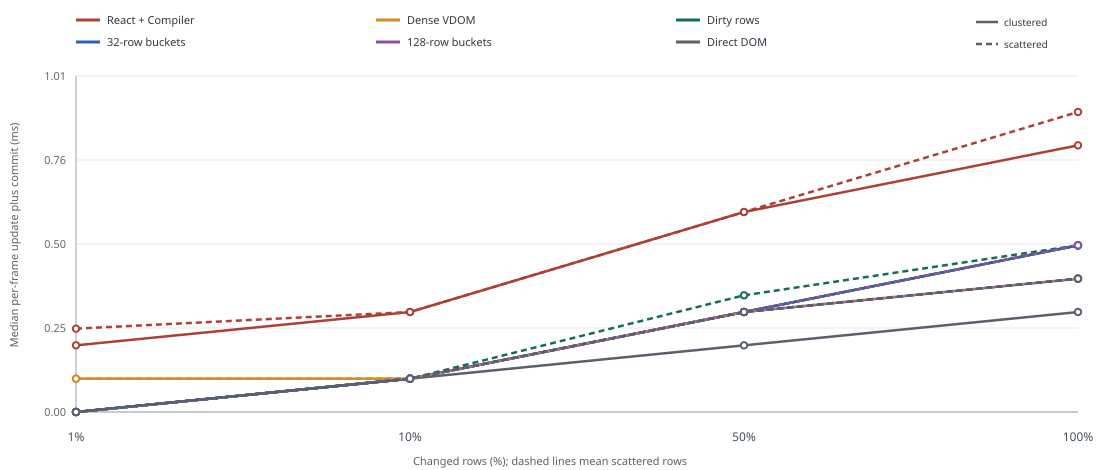

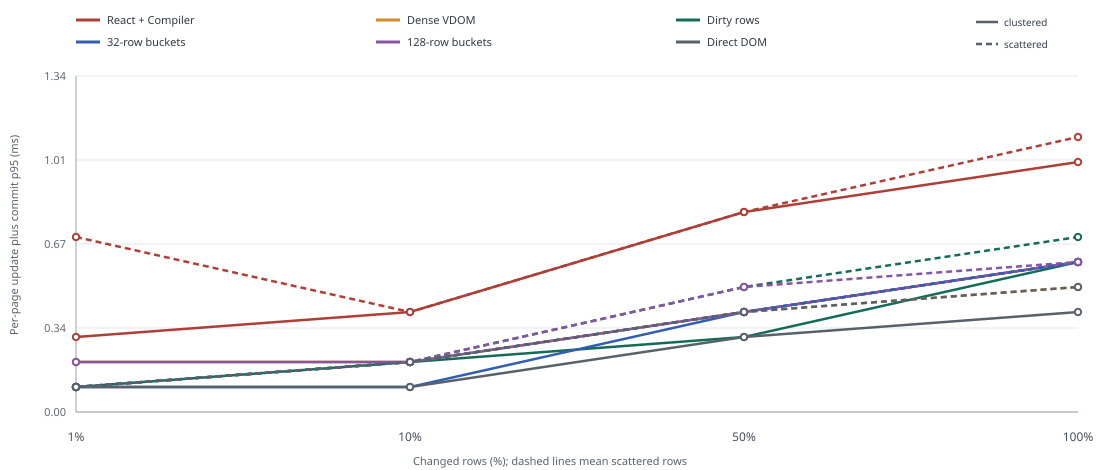

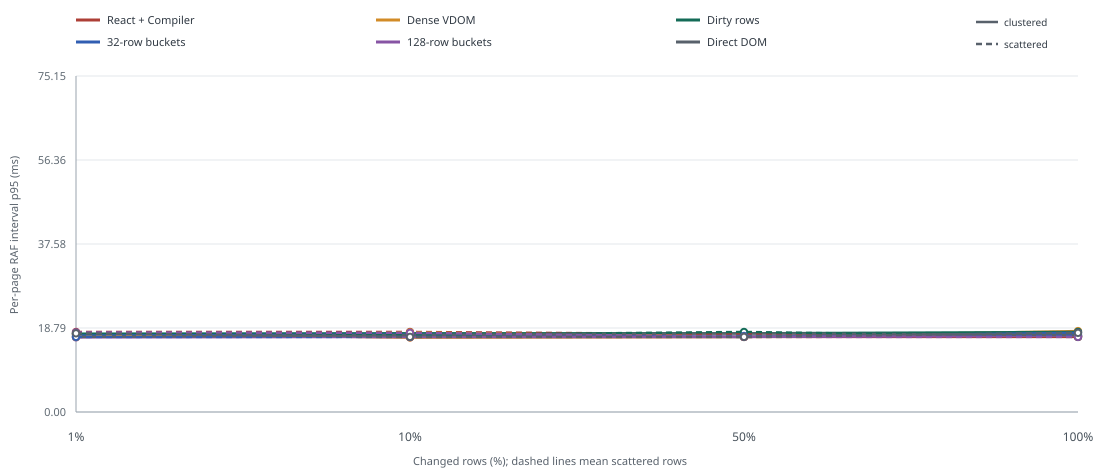

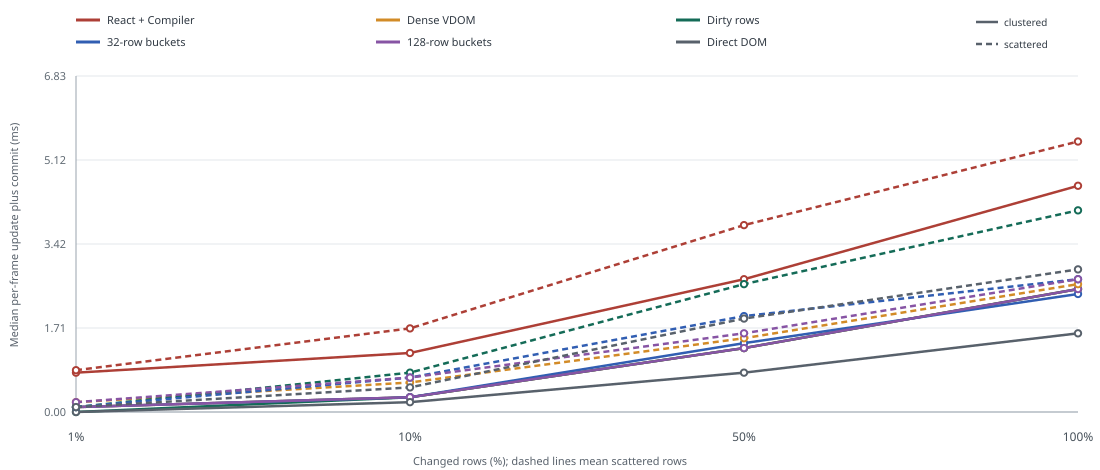

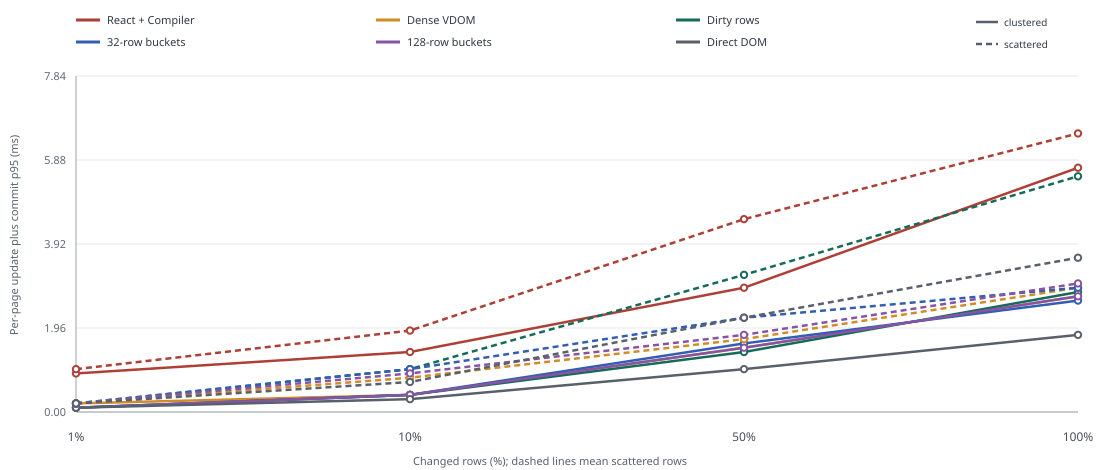

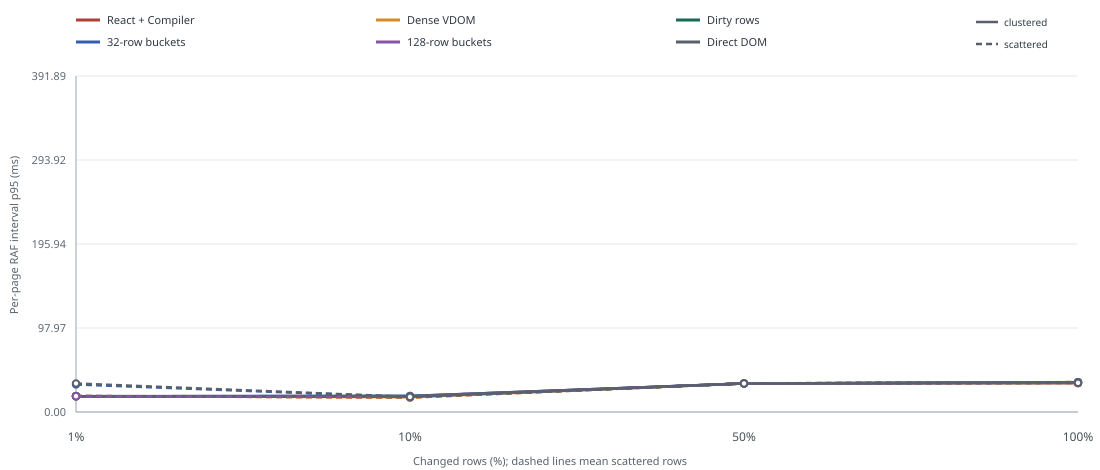

In [71]:
const prereg = JSON.parse(
  await Deno.readTextFile("results/snake-sparse-frame-v1-preregistration.json"),
);
const manifest = JSON.parse(
  await Deno.readTextFile("results/snake-sparse-frame-v1-manifest.json"),
);
const lock = JSON.parse(
  await Deno.readTextFile("results/snake-sparse-frame-v1-source-lock.json"),
);
if (
  prereg.status !== "PREREGISTERED" || manifest.status !== "PASS" ||
  manifest.archivedPageLoads !== 288 || manifest.measuredFrames !== 17280 ||
  lock.status !== "FROZEN_BEFORE_COLLECTION_AFTER_AMENDMENT_1"
) throw new Error("Sparse per-frame study is incomplete");
const sha256 = async (bytes: Uint8Array) =>
  [...new Uint8Array(await crypto.subtle.digest("SHA-256", bytes))].map((
    byte,
  ) => byte.toString(16).padStart(2, "0")).join("");
for (const file of lock.files) {
  if (await sha256(await Deno.readFile(file.snapshotPath)) !== file.sha256) {
    throw new Error(`Source snapshot mismatch: ${file.path}`);
  }
}
const records: any[] = [];
for (const file of manifest.records) {
  const bytes = await Deno.readFile(
    `results/snake-sparse-frame-v1-production/${file.filename}`,
  );
  if (await sha256(bytes) !== file.sha256) {
    throw new Error(`Raw page hash mismatch: ${file.filename}`);
  }
  const record = JSON.parse(new TextDecoder().decode(bytes));
  if (
    record.status !== "PASS" || record.samples.length !== 60 ||
    !record.allContractsPass
  ) throw new Error(`Page contract failure: ${file.filename}`);
  records.push(record);
}

const arms = [
  "react",
  "dense-vdom",
  "dirty-rows-vdom",
  "bucket-32-vdom",
  "bucket-128-vdom",
  "direct",
];
const armLabels: Record<string, string> = {
  react: "React + Compiler",
  "dense-vdom": "Dense VDOM",
  "dirty-rows-vdom": "Dirty rows",
  "bucket-32-vdom": "32-row buckets",
  "bucket-128-vdom": "128-row buckets",
  direct: "Direct DOM",
};
const colors: Record<string, string> = {
  react: "#ad3f36",
  "dense-vdom": "#d28b27",
  "dirty-rows-vdom": "#146b57",
  "bucket-32-vdom": "#315eb2",
  "bucket-128-vdom": "#8754a4",
  direct: "#58616b",
};
const sizes = [512, 4096],
  densities = [1, 10, 50, 100],
  localities = ["clustered", "scattered"];
const median = (values: number[]) => {
  const xs = [...values].sort((a, b) => a - b);
  const mid = Math.floor(xs.length / 2);
  return xs.length % 2 ? xs[mid] : (xs[mid - 1] + xs[mid]) / 2;
};
const quantile = (values: number[], p: number) => {
  const xs = [...values].sort((a, b) => a - b);
  return xs[Math.max(0, Math.ceil(p * xs.length) - 1)];
};
const summaries: any[] = [];
for (const record of records) {
  summaries.push({
    ...record,
    medianUpdateMs: median(
      record.samples.map((sample: any) => sample.updateCpuMs),
    ),
    p95UpdateMs: quantile(
      record.samples.map((sample: any) => sample.updateCpuMs),
      0.95,
    ),
    medianRafMs: median(record.samples.map((sample: any) => sample.intervalMs)),
    p95RafMs: quantile(
      record.samples.map((sample: any) => sample.intervalMs),
      0.95,
    ),
  });
}
const cellRecords = (
  size: number,
  dirtyPercent: number,
  locality: string,
  arm: string,
) =>
  summaries.filter((row) =>
    row.size === size && row.dirtyPercent === dirtyPercent &&
    row.locality === locality && row.arm === arm
  );
console.log(
  "Browser sparse per-frame results; median of three page-level medians, milliseconds. Each page contains 60 measured RAF updates; pages are replication units.",
);
console.log(
  "size | dirty% | locality | React | dense | rows | bucket32 | bucket128 | DOM",
);
for (const size of sizes) {
  for (const density of densities) {
    for (const locality of localities) {
      const values = arms.map((arm) => {
        const matches = cellRecords(size, density, locality, arm);
        if (matches.length !== 3) {
          throw new Error(
            `Expected three page replications for ${size}/${density}/${locality}/${arm}`,
          );
        }
        return median(matches.map((item) => item.medianUpdateMs));
      });
      console.log(
        `${size} | ${density} | ${locality} | ${
          values.map((value) => value.toFixed(3)).join(" | ")
        }`,
      );
    }
  }
}
console.log(
  "Per-page nearest-rank p95 update-plus-commit milliseconds; each cell is the median of three page-level p95s.",
);
console.log(
  "size | dirty% | locality | React | dense | rows | bucket32 | bucket128 | DOM",
);
for (const size of sizes) {
  for (const density of densities) {
    for (const locality of localities) {
      const values = arms.map((arm) => {
        const matches = cellRecords(size, density, locality, arm);
        if (matches.length !== 3) {
          throw new Error(
            `Expected three page replications for ${size}/${density}/${locality}/${arm}`,
          );
        }
        return median(matches.map((item) => item.p95UpdateMs));
      });
      console.log(
        `${size} | ${density} | ${locality} | ${
          values.map((value) => value.toFixed(3)).join(" | ")
        }`,
      );
    }
  }
}
console.log(
  "Median paired update-time ratio to React by candidate across every workload cell and replication; <1 is faster.",
);
for (const arm of arms.slice(1)) {
  const ratios: number[] = [];
  let wins = 0;
  for (const size of sizes) {
    for (const density of densities) {
      for (const locality of localities) {
        for (let replication = 1; replication <= 3; replication++) {
          const candidate = summaries.find((row) =>
            row.size === size && row.dirtyPercent === density &&
            row.locality === locality && row.arm === arm &&
            row.replication === replication
          );
          const baseline = summaries.find((row) =>
            row.size === size && row.dirtyPercent === density &&
            row.locality === locality && row.arm === "react" &&
            row.replication === replication
          );
          if (!candidate || !baseline) {
            throw new Error("Missing paired browser page");
          }
          const ratio = candidate.medianUpdateMs / baseline.medianUpdateMs;
          ratios.push(ratio);
          if (ratio < 1) wins++;
        }
      }
    }
  }
  console.log(
    `${armLabels[arm]} | ${
      median(ratios).toFixed(3)
    }× | ${wins}/${ratios.length} paired pages faster`,
  );
}
console.log(
  "Descriptive timing-floor sensitivity: recorded update-plus-commit samples at or below 0.1 ms by arm. These values are reported, not excluded.",
);
for (const arm of arms) {
  const values = records.filter((row) => row.arm === arm).flatMap((row) =>
    row.samples.map((sample: any) => sample.updateCpuMs)
  );
  console.log(
    `${armLabels[arm]} | ${values.filter((value) => value <= 0).length} at 0 ms | ${values.filter((value) => value <= 0.1).length} at or below 0.1 ms | ${values.length} samples`,
  );
}
console.log(
  "Exploratory above-floor slice: 4,096 entities and 10–100% dirty rows, retaining paired pages only when both page medians exceed 0.1 ms. This post-collection sensitivity check is not the preregistered primary summary.",
);
for (const arm of arms.slice(1)) {
  const ratios: number[] = [];
  let wins = 0;
  for (const row of summaries) {
    if (row.arm !== arm || row.size !== 4096 || row.dirtyPercent < 10) continue;
    const baseline = summaries.find((item) =>
      item.arm === "react" && item.size === row.size &&
      item.dirtyPercent === row.dirtyPercent && item.locality === row.locality &&
      item.replication === row.replication
    );
    if (!baseline || row.medianUpdateMs <= 0.1 || baseline.medianUpdateMs <= 0.1) {
      continue;
    }
    ratios.push(row.medianUpdateMs / baseline.medianUpdateMs);
    if (row.medianUpdateMs < baseline.medianUpdateMs) wins++;
  }
  console.log(
    `${armLabels[arm]} | n=${ratios.length} | ${median(ratios).toFixed(3)}× median paired ratio | ${wins}/${ratios.length} lower`,
  );
}

const plot = (
  size: number,
  metric: "medianUpdateMs" | "p95UpdateMs" | "p95RafMs",
) => {
  const width = 1100,
    height = 470,
    left = 76,
    right = 22,
    top = 76,
    bottom = 58;
  const plotW = width - left - right, plotH = height - top - bottom;
  const group = summaries.filter((row) => row.size === size);
  const max = Math.max(...group.map((row) => row[metric])) * 1.12;
  const x = (index: number) => left + plotW * index / (densities.length - 1);
  const y = (value: number) => top + plotH - plotH * value / max;
  const grid = Array.from({ length: 5 }, (_, i) => {
    const value = max * i / 4;
    return `<line x1="${left}" x2="${width - right}" y1="${y(value)}" y2="${
      y(value)
    }" stroke="#e3e7eb"/><text x="${left - 10}" y="${
      y(value) + 4
    }" text-anchor="end" fill="#606a73" font-size="11">${
      value.toFixed(2)
    }</text>`;
  }).join("");
  const lines = localities.flatMap((locality) =>
    arms.map((arm) => {
      const values = densities.map((density) => {
        const entries = cellRecords(size, density, locality, arm);
        return median(entries.map((entry) => entry[metric]));
      });
      const points = values.map((value, index) => `${x(index)},${y(value)}`)
        .join(" ");
      const dash = locality === "scattered" ? ' stroke-dasharray="6 4"' : "";
      const dots = values.map((value, index) =>
        `<circle cx="${x(index)}" cy="${
          y(value)
        }" r="3.2" fill="white" stroke="${colors[arm]}" stroke-width="2"/>`
      ).join("");
      return `<polyline points="${points}" fill="none" stroke="${
        colors[arm]
      }" stroke-width="2.5"${dash}/>${dots}`;
    })
  ).join("");
  const labels = densities.map((value, index) =>
    `<text x="${x(index)}" y="${
      height - 29
    }" text-anchor="middle" fill="#47515a" font-size="12">${value}%</text>`
  ).join("");
  const legend = arms.map((arm, index) =>
    `<line x1="${left + (index % 3) * 300}" x2="${
      left + 24 + (index % 3) * 300
    }" y1="${20 + Math.floor(index / 3) * 22}" y2="${
      20 + Math.floor(index / 3) * 22
    }" stroke="${colors[arm]}" stroke-width="3"/><text x="${
      left + 31 + (index % 3) * 300
    }" y="${24 + Math.floor(index / 3) * 22}" fill="#303943" font-size="11">${
      armLabels[arm]
    }</text>`
  ).join("");
  const localityLegend = `<line x1="${left + 900}" x2="${
    left + 922
  }" y1="22" y2="22" stroke="#58616b" stroke-width="2.5"/><text x="${
    left + 928
  }" y="26" fill="#303943" font-size="10">clustered</text><line x1="${
    left + 900
  }" x2="${
    left + 922
  }" y1="44" y2="44" stroke="#58616b" stroke-width="2.5" stroke-dasharray="6 4"/><text x="${
    left + 928
  }" y="48" fill="#303943" font-size="10">scattered</text>`;
  const axisLabel = metric === "medianUpdateMs"
    ? "Median per-frame update plus commit (ms)"
    : metric === "p95UpdateMs"
    ? "Per-page update plus commit p95 (ms)"
    : "Per-page RAF interval p95 (ms)";
  const svg =
    `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${height}" viewBox="0 0 ${width} ${height}" role="img" aria-label="${size} entities ${axisLabel}" style="max-width:100%;height:auto;font-family:system-ui,sans-serif"><title>${size} entities: ${axisLabel}</title><rect width="100%" height="100%" fill="white"/>${legend}${localityLegend}${grid}<line x1="${left}" x2="${left}" y1="${top}" y2="${
      top + plotH
    }" stroke="#9aa4ae"/><line x1="${left}" x2="${width - right}" y1="${
      top + plotH
    }" y2="${top + plotH}" stroke="#9aa4ae"/>${labels}${lines}<text x="${
      width / 2
    }" y="${
      height - 5
    }" text-anchor="middle" fill="#58616b" font-size="11">Changed rows (%); dashed lines mean scattered rows</text><text x="18" y="${
      height / 2
    }" transform="rotate(-90 18 ${
      height / 2
    })" text-anchor="middle" fill="#58616b" font-size="11">${axisLabel}</text></svg>`;
  return Deno.jupyter.svg`${svg}`;
};
for (const size of sizes) {
  await Deno.jupyter.display(plot(size, "medianUpdateMs"));
  await Deno.jupyter.display(plot(size, "p95UpdateMs"));
  await Deno.jupyter.display(plot(size, "p95RafMs"));
}



### Exploratory structural phase profile: Deno memory host

This single-process diagnostic runs the AP v4 structural operations through `ComponentStateRoot` and `MemoryVDOMHost` with phase callbacks enabled. It separates owner rendering/expansion, VDOM normalization, host reconciliation, and index rebuilding. The bars show phase medians; `root.flush` is the complete measured flush, so the phase medians are not additive.

The filter's host-reconcile phase is large because `MemoryVDOMHost` uses an array-backed child list with `indexOf` and `splice`. That host does not model browser DOM placement/removal costs, so this result cannot explain the Chrome AP v4 loss. This is mechanism-level diagnostic evidence only: one Deno process, no React arm, and no browser layout, paint, or presentation. The JSON record and exact rerun command are [here](./results/component-state-structural-memory-profile-v1.json) and `deno task structural:phase-profile`.



┌───────┬────────────────┬────────────────────┬────────────────────┬────────────────────┬────────┬────────────┬──────────┐
│ (idx) │ operation      │ rootFlushMs        │ ownerExpansionMs   │ hostReconcileMs    │ writes │ placements │ removals │
├───────┼────────────────┼────────────────────┼────────────────────┼────────────────────┼────────┼────────────┼──────────┤
│     0 │ "rotate"       │ 15.126666999999998 │ 7.4100420000000895 │ 3.387833999999998  │     12 │         12 │        0 │
│     1 │ "replace-edge" │ 14.920166999999992 │ 5.9056659999999965 │ 3.0585829999999987 │     60 │         24 │       12 │
│     2 │ "filter-half"  │ 49.210166999999956 │ 10.743000000000166 │ 27.383624999999938 │ 120012 │      60000 │    30000 │
└───────┴────────────────┴────────────────────┴────────────────────┴────────────────────┴────────┴────────────┴──────────┘


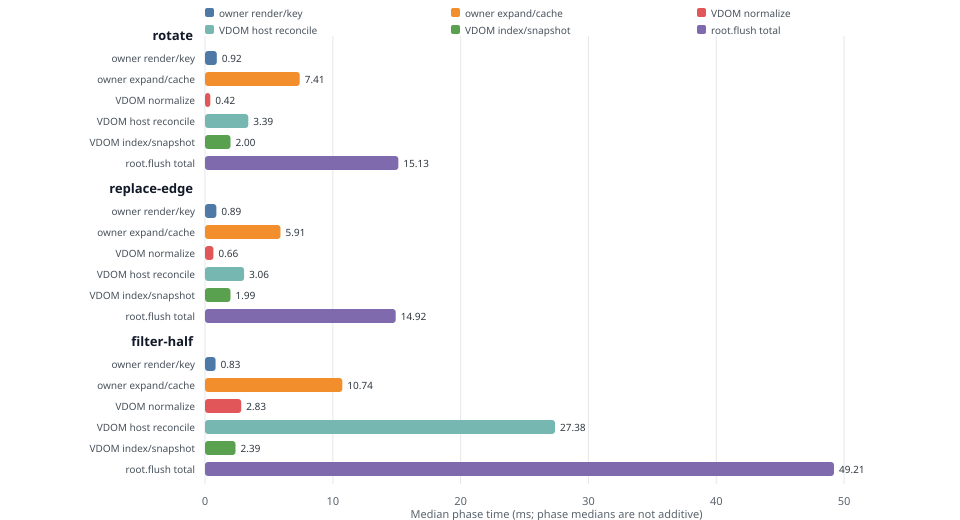

In [72]:
const memoryPhaseRecord = JSON.parse(
  await Deno.readTextFile(
    "results/component-state-structural-memory-profile-v1.json",
  ),
);
if (
  memoryPhaseRecord.schemaVersion !==
    "component-state-structural-memory-profile-v1" ||
  memoryPhaseRecord.status !== "EXPLORATORY" ||
  memoryPhaseRecord.scenarios.length !== 3
) {
  throw new Error("Structural memory-host phase profile is invalid");
}

const memoryPhaseNames = [
  "owner.render-and-key",
  "owner.expand-and-cache",
  "vdom.normalize",
  "vdom.reconcile-host",
  "vdom.index-snapshot",
  "root.flush",
] as const;
const memoryPhaseLabels: Record<(typeof memoryPhaseNames)[number], string> = {
  "owner.render-and-key": "owner render/key",
  "owner.expand-and-cache": "owner expand/cache",
  "vdom.normalize": "VDOM normalize",
  "vdom.reconcile-host": "VDOM host reconcile",
  "vdom.index-snapshot": "VDOM index/snapshot",
  "root.flush": "root.flush total",
};
const memoryPhaseColors: Record<(typeof memoryPhaseNames)[number], string> = {
  "owner.render-and-key": "#4e79a7",
  "owner.expand-and-cache": "#f28e2b",
  "vdom.normalize": "#e15759",
  "vdom.reconcile-host": "#76b7b2",
  "vdom.index-snapshot": "#59a14f",
  "root.flush": "#7f6aad",
};
const memoryPhaseMax = 55;
const memoryPhaseWidth = 960;
const memoryPhaseHeight = 520;
const memoryPhaseLeft = 205;
const memoryPhaseRight = 52;
const memoryPhaseTop = 44;
const memoryPhaseRowHeight = 21;
const memoryPhaseGroupGap = 20;
const memoryPhasePlotWidth = memoryPhaseWidth - memoryPhaseLeft -
  memoryPhaseRight;
const memoryPhaseScale = memoryPhasePlotWidth / memoryPhaseMax;
const memoryPhaseRows: string[] = [];
const memoryPhaseGrid: string[] = [];
const memoryPhaseLegend: string[] = [];

for (let tick = 0; tick <= memoryPhaseMax; tick += 10) {
  const x = memoryPhaseLeft + tick * memoryPhaseScale;
  memoryPhaseGrid.push(
    `<line x1="${x}" x2="${x}" y1="${memoryPhaseTop - 8}" y2="${
      memoryPhaseHeight - 36
    }" stroke="#e5e7eb"/><text x="${x}" y="${
      memoryPhaseHeight - 15
    }" text-anchor="middle" fill="#59636e" font-size="11">${tick}</text>`,
  );
}

let memoryPhaseY = memoryPhaseTop;
for (const scenario of memoryPhaseRecord.scenarios) {
  memoryPhaseRows.push(
    `<text x="${memoryPhaseLeft - 12}" y="${
      memoryPhaseY - 4
    }" text-anchor="end" fill="#111827" font-size="13" font-weight="650">${scenario.operation}</text>`,
  );
  memoryPhaseY += 7;
  for (const phase of memoryPhaseNames) {
    const value = scenario.phaseMedianMs[phase];
    const barWidth = Math.max(0, value * memoryPhaseScale);
    memoryPhaseRows.push(
      `<text x="${memoryPhaseLeft - 10}" y="${
        memoryPhaseY + 11
      }" text-anchor="end" fill="#48515b" font-size="10">${
        memoryPhaseLabels[phase]
      }</text><rect x="${memoryPhaseLeft}" y="${memoryPhaseY}" width="${barWidth}" height="14" rx="3" fill="${
        memoryPhaseColors[phase]
      }"/><text x="${memoryPhaseLeft + barWidth + 5}" y="${
        memoryPhaseY + 11
      }" fill="#303840" font-size="10">${value.toFixed(2)}</text>`,
    );
    memoryPhaseY += memoryPhaseRowHeight;
  }
  memoryPhaseY += memoryPhaseGroupGap;
}

for (let index = 0; index < memoryPhaseNames.length; index++) {
  const phase = memoryPhaseNames[index];
  const x = memoryPhaseLeft + (index % 3) * 246;
  const y = 17 + Math.floor(index / 3) * 17;
  memoryPhaseLegend.push(
    `<rect x="${x}" y="${y - 9}" width="9" height="9" rx="2" fill="${
      memoryPhaseColors[phase]
    }"/><text x="${x + 14}" y="${y}" fill="#48515b" font-size="10">${
      memoryPhaseLabels[phase]
    }</text>`,
  );
}

console.table(memoryPhaseRecord.scenarios.map((scenario: any) => ({
  operation: scenario.operation,
  rootFlushMs: scenario.phaseMedianMs["root.flush"],
  ownerExpansionMs: scenario.phaseMedianMs["owner.expand-and-cache"],
  hostReconcileMs: scenario.phaseMedianMs["vdom.reconcile-host"],
  writes: scenario.hostWrites,
  placements: scenario.hostPlacements,
  removals: scenario.hostRemovals,
})));
Deno.jupyter
  .svg`<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${memoryPhaseHeight}" viewBox="0 0 ${memoryPhaseWidth} ${memoryPhaseHeight}" role="img" aria-label="Exploratory Deno memory host structural phase profile" style="max-width:100%;height:auto;font-family:system-ui,sans-serif"><title>Exploratory Deno MemoryVDOMHost structural phase profile</title><rect width="100%" height="100%" fill="white"/>${
  memoryPhaseLegend.join("")
}${memoryPhaseGrid.join("")}${memoryPhaseRows.join("")}<text x="${
  memoryPhaseLeft + memoryPhasePlotWidth / 2
}" y="${
  memoryPhaseHeight - 2
}" text-anchor="middle" fill="#59636e" font-size="11">Median phase time (ms; phase medians are not additive)</text></svg>`;



### Experiment AP diagnostic — browser structural phase profile

This exploratory Chrome 154 study profiles the checked-in 10,000-row structural harness on one visible in-app browser page and one MacIntel device. The v8 diagnostic records 24 paired updates each for rotate, edge replacement, and half-list filtering after prototyping delta-based key-index maintenance. It preserves phase calls and owner/index/host work counts. A separate uninstrumented page checks output parity, keyed host identity, and local-state retention. Neither one-page run is a confirmatory latency collection.

Path markers show one dirty owner/change and no full-reconcile fallback on all 72 updates. The baseline v7 counts traversed 20,004 old plus 20,004 new key-index nodes for a one-move rotation. With delta-based index maintenance, v8 visits zero index nodes for rotation, two old plus two new nodes for edge replacement, 10,000 detached nodes for shrink, and 10,000 attached nodes for restore. Filter shrink and restore must be analyzed separately: the 24 updates contain 11 shrinks and 13 restores in this run, so a pooled median would describe the majority direction rather than a typical single direction. Owner traversal remains broad: 10,000 visits for rotation and restore, and 5,000 for shrink.

The phase chart separates filter shrink from restore and shows overlapping diagnostic scopes; do not add these bars. The second SVG shows owner visits and key-index detach/attach visits, while the table preserves host calls. The separate uninstrumented page (seed `83001054`) passed parity, identity, and retained-state checks. Its filter direction is reconstructed from the recorded seed and the harness's deterministic shuffled schedule; that reconstruction is validated against the v8 diagnostic page's owner-created/retired counters. The 13 shrink samples have React/runtime medians 19.2/24.7 ms, median paired difference (React − runtime) −3.5 ms, and median paired ratio 0.846. The 11 restore samples have medians 38.6/38.6 ms, paired difference +3.3 ms, and ratio 1.089. These are descriptive within one uninstrumented page; they suggest the pooled 28/37 ms medians hid direction-dependent behavior, but do not replace the 216-pair AP v4 comparison or establish a general speedup. The [v7 baseline counters](./results/browser-component-state-structural-profile-v7-83001052.json), [v8 delta-index counters](./results/browser-component-state-structural-profile-v8-83001053.json), and [uninstrumented page](./results/browser-component-state-structural-v4-83001054.json) contain raw evidence. Regenerate this SVG-only analysis with `deno task component-state:structural-phase-notebook`.



┌───────┬─────────────────────────┬────┬─────────────────────┬───────────────────────────┬─────────────────┬─────────────────────────────────┬───────────────────────────────┬────────────────────────────┬───────────────────────────┬────────────────────┬────────────────────┬────────────────────┬────────────────┬─────────────────┐
│ (idx) │ operation               │ n  │ diagnosticRuntimeMs │ sameSeedDiagnosticReactMs │ uninstrumentedN │ uninstrumentedFollowupRuntimeMs │ uninstrumentedFollowupReactMs │ uninstrumentedPairedDiffMs │ uninstrumentedPairedRatio │ rootFlushMs        │ ownerExpandMs      │ hostReconcileMs    │ keyIndexVisits │ hostMethodCalls │
├───────┼─────────────────────────┼────┼─────────────────────┼───────────────────────────┼─────────────────┼─────────────────────────────────┼───────────────────────────────┼────────────────────────────┼───────────────────────────┼────────────────────┼────────────────────┼────────────────────┼────────────────┼─────────────────┤
│     0 │ 

┌───────┬─────────────────────────┬─────────────────────────┬───────────────────────────┬─────────────────────────────┬───────────────────────────────┬─────────────┬──────────────┬─────────────┬───────────────┬───────────────┬───────────────────┬───────────────────┬────────────────────────┬───────────────────┐
│ (idx) │ operation               │ diagnosticReactMedianMs │ diagnosticRuntimeMedianMs │ uninstrumentedReactMedianMs │ uninstrumentedRuntimeMedianMs │ ownerVisits │ ownerRenders │ cachedReuse │ createdOwners │ retiredOwners │ oldKeyIndexVisits │ newKeyIndexVisits │ keyIndexCombinedVisits │ hostMutationCalls │
├───────┼─────────────────────────┼─────────────────────────┼───────────────────────────┼─────────────────────────────┼───────────────────────────────┼─────────────┼──────────────┼─────────────┼───────────────┼───────────────┼───────────────────┼───────────────────┼────────────────────────┼───────────────────┤
│     0 │ "rotate"                │ 25.19999998807907       │ 11

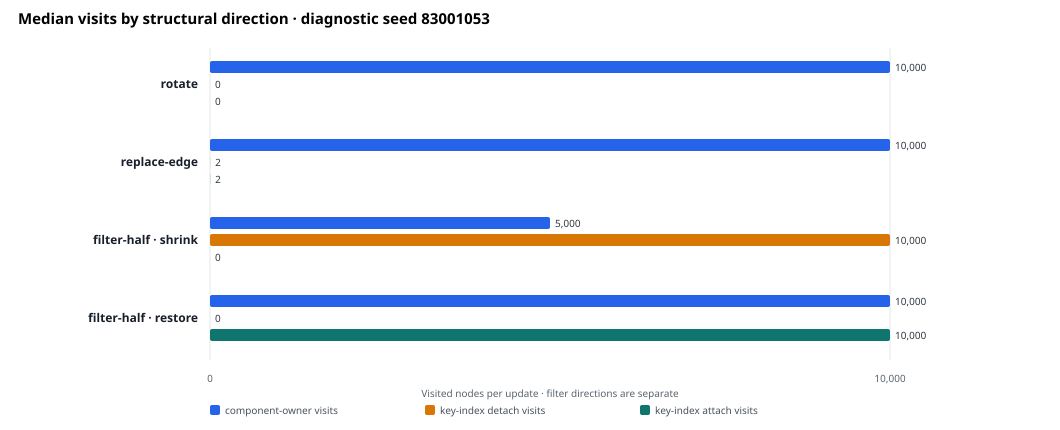

In [73]:
const browserPhaseRecord = JSON.parse(
  await Deno.readTextFile(
    "results/browser-component-state-structural-profile-v8-83001053.json",
  ),
);
const diagnosticTimingRecord = JSON.parse(
  await Deno.readTextFile(
    "results/browser-component-state-structural-v4-83001053.json",
  ),
);
const uninstrumentedFollowup = JSON.parse(
  await Deno.readTextFile(
    "results/browser-component-state-structural-v4-83001054.json",
  ),
);
const browserPhaseOperations = ["rotate", "replace-edge", "filter-half"];
if (
  browserPhaseRecord.schemaVersion !==
    "component-state-structural-browser-phase-profile-v8" ||
  browserPhaseRecord.count !== 10_000 ||
  diagnosticTimingRecord.schemaVersion !==
    "component-state-structural-browser-v4" ||
  diagnosticTimingRecord.status !== "PASS" ||
  diagnosticTimingRecord.count !== 10_000 ||
  uninstrumentedFollowup.schemaVersion !==
    "component-state-structural-browser-v4" ||
  uninstrumentedFollowup.status !== "PASS" ||
  uninstrumentedFollowup.count !== 10_000 ||
  browserPhaseRecord.operations.length !== 3 ||
  !browserPhaseRecord.operations.every((operation: any) =>
    operation.measuredUpdates === 24 && operation.samples.length === 24 &&
    operation.workCountMedians &&
    Object.values(operation.workCountMedians).every((count: any) =>
      Number.isSafeInteger(count) && count >= 0
    ) &&
    operation.samples.every((sample: any, index: number) =>
      sample.pair === index && Number.isFinite(sample.totalUpdateMs) &&
      Number.isFinite(sample.rootFlushMs) &&
      Number.isFinite(sample.outsideRootFlushMs) && sample.workCounts &&
      Object.values(sample.workCounts).every((count: any) =>
        Number.isSafeInteger(count) && count >= 0
      )
    )
  ) ||
  !diagnosticTimingRecord.scenarios.every((scenario: any) =>
    scenario.outputParity && scenario.identity && scenario.retainedState
  ) ||
  !uninstrumentedFollowup.scenarios.every((scenario: any) =>
    scenario.outputParity && scenario.identity && scenario.retainedState
  )
) {
  throw new Error("Browser structural profile failed sample or parity checks");
}
const browserPhasePercentile = (values: number[], p: number) => {
  const ordered = [...values].sort((a, b) => a - b);
  return ordered[Math.max(0, Math.ceil(p * ordered.length) - 1)];
};
const browserPhaseMedian = (values: number[]) =>
  browserPhasePercentile(values, 0.5);
const filterDirectionBySample = (record: any) => {
  const stateStart = (record.seed ^ "filter-half".length) >>> 0 || 1;
  let state = stateStart;
  const random = () => {
    state ^= state << 13;
    state ^= state >>> 17;
    state ^= state << 5;
    return (state >>> 0) / 0x1_0000_0000;
  };
  const pairs = Array.from(
    { length: record.warmupPairs + record.measuredPairs },
    (_, pair) => pair,
  );
  for (let index = pairs.length - 1; index > 0; index--) {
    const other = Math.floor(random() * (index + 1));
    [pairs[index], pairs[other]] = [pairs[other], pairs[index]];
  }
  const directionBySample = new Map<number, "shrink" | "restore">();
  pairs.forEach((pair, updateIndex) => {
    if (pair >= record.warmupPairs) {
      directionBySample.set(
        pair - record.warmupPairs,
        updateIndex % 2 === 0 ? "shrink" : "restore",
      );
    }
  });
  return directionBySample;
};
const diagnosticFilterScenario = browserPhaseRecord.operations.find((
  scenario: any,
) => scenario.operation === "filter-half");
const diagnosticFilterDirections = filterDirectionBySample(
  diagnosticTimingRecord,
);
for (const sample of diagnosticFilterScenario.samples) {
  const direction = diagnosticFilterDirections.get(sample.pair);
  const workDirection = sample.workCounts["owner.retired"] > 0
    ? "shrink"
    : sample.workCounts["owner.created"] > 0
    ? "restore"
    : null;
  if (direction !== workDirection) {
    throw new Error(
      `Filter direction reconstruction mismatch for diagnostic sample ${sample.pair}`,
    );
  }
}
const uninstrumentedFilterScenario = uninstrumentedFollowup.scenarios.find((
  scenario: any,
) => scenario.operation === "filter-half");
const uninstrumentedFilterDirections = filterDirectionBySample(
  uninstrumentedFollowup,
);
const browserPhaseRows = browserPhaseOperations.flatMap((name) => {
  const operation = browserPhaseRecord.operations.find((item: any) =>
    item.operation === name
  );
  const scenario = diagnosticTimingRecord.scenarios.find((item: any) =>
    item.operation === name
  );
  const uninstrumentedScenario = uninstrumentedFollowup.scenarios.find((
    item: any,
  ) => item.operation === name);
  const diagnosticPairs = new Map<number, any>(
    scenario.samples.map((sample: any) => [sample.pair, sample]),
  );
  const groups = name === "filter-half"
    ? [
      {
        label: "filter-half · shrink",
        direction: "shrink",
        samples: operation.samples.filter((sample: any) =>
          (sample.workCounts["owner.retired"] ?? 0) > 0
        ),
      },
      {
        label: "filter-half · restore",
        direction: "restore",
        samples: operation.samples.filter((sample: any) =>
          (sample.workCounts["owner.created"] ?? 0) > 0
        ),
      },
    ]
    : [{ label: name, direction: null, samples: operation.samples }];
  return groups.map(({ label, direction, samples }) => {
    const callValues = (phase: string) =>
      samples.flatMap((sample: any) => sample.phaseCalls[phase] ?? []);
    const fallbackSamples = samples.filter((sample: any) =>
      sample.phaseCalls["dispatch.path.full-reconcile"]?.length
    );
    const summarizePhase = (phase: string) => {
      const values = callValues(phase);
      return {
        calls: values.length,
        medianMs: values.length ? browserPhaseMedian(values) : 0,
      };
    };
    const countNames = new Set(
      samples.flatMap((sample: any) => Object.keys(sample.workCounts)),
    );
    const workCounts = Object.fromEntries(
      [...countNames].sort().map((key) => [
        key,
        browserPhaseMedian(
          samples.map((sample: any) => sample.workCounts[key] ?? 0),
        ),
      ]),
    );
    const pairedSamples = samples.map((sample: any) =>
      diagnosticPairs.get(sample.pair)
    );
    const uninstrumentedSamples = name === "filter-half"
      ? uninstrumentedFilterScenario.samples.filter((sample: any) =>
        uninstrumentedFilterDirections.get(sample.pair) === direction
      )
      : uninstrumentedScenario.samples;
    return {
      operation: label,
      updates: samples.length,
      totalUpdateMedianMs: browserPhaseMedian(
        samples.map((sample: any) => sample.totalUpdateMs),
      ),
      diagnosticReactMedianMs: browserPhaseMedian(
        pairedSamples.map((sample: any) => sample.milliseconds.react),
      ),
      diagnosticRuntimeMedianMs: browserPhaseMedian(
        pairedSamples.map((sample: any) => sample.milliseconds.runtime),
      ),
      uninstrumentedUpdates: uninstrumentedSamples.length,
      uninstrumentedReactMedianMs: browserPhaseMedian(
        uninstrumentedSamples.map((sample: any) => sample.milliseconds.react),
      ),
      uninstrumentedRuntimeMedianMs: browserPhaseMedian(
        uninstrumentedSamples.map((sample: any) => sample.milliseconds.runtime),
      ),
      uninstrumentedReactP95Ms: browserPhasePercentile(
        uninstrumentedSamples.map((sample: any) => sample.milliseconds.react),
        0.95,
      ),
      uninstrumentedRuntimeP95Ms: browserPhasePercentile(
        uninstrumentedSamples.map((sample: any) => sample.milliseconds.runtime),
        0.95,
      ),
      uninstrumentedMedianPairedDifferenceMs: browserPhaseMedian(
        uninstrumentedSamples.map((sample: any) =>
          sample.milliseconds.react - sample.milliseconds.runtime
        ),
      ),
      uninstrumentedMedianPairedRatio: browserPhaseMedian(
        uninstrumentedSamples.map((sample: any) =>
          sample.milliseconds.react / sample.milliseconds.runtime
        ),
      ),
      workCounts,
      keyIndexCombinedVisits:
        (workCounts["vdom.key-index.incremental-old-visits"] ?? 0) +
        (workCounts["vdom.key-index.incremental-new-visits"] ?? 0),
      hostMutationCalls: Object.entries(workCounts)
        .filter(([key]) => key.startsWith("host."))
        .reduce((sum, [, count]) => sum + (count as number), 0),
      rootFlushMedianMs: browserPhaseMedian(
        samples.map((sample: any) => sample.rootFlushMs),
      ),
      outsideFlushMedianMs: browserPhaseMedian(
        samples.map((sample: any) => sample.outsideRootFlushMs),
      ),
      ownerExpandMedianMs: summarizePhase("owner.expand-and-cache").medianMs,
      hostReconcileMedianMs: summarizePhase("vdom.reconcile-host").medianMs,
      fallbackCount: fallbackSamples.length,
      multiOwnerFlushCount: samples.filter((sample: any) =>
        sample.phaseCalls["dispatch.diagnostic.dirty-owner-count.2"]?.length
      ).length,
      singleOwnerFlushCount: samples.filter((sample: any) =>
        sample.phaseCalls["dispatch.diagnostic.dirty-owner-count.1"]?.length
      ).length,
      partialNestedSubtreeBailCount: samples.filter((sample: any) =>
        sample.phaseCalls["dispatch.partial-bail.owner-has-nested-subtree"]
          ?.length
      ).length,
      fallbackMedianMs: browserPhaseMedian(
        fallbackSamples.map((sample: any) =>
          sample.totalUpdateMs
        ),
      ),
      fallbackExpandMs: summarizePhase("owner.full-expand").medianMs,
      fallbackCommitMs: summarizePhase("vdom.full-commit").medianMs,
    };
  });
});

const browserPhaseColors = {
  total: "#243b53",
  flush: "#486581",
  outside: "#829ab1",
  owner: "#d97706",
  host: "#0f766e",
  fallbackExpand: "#b91c1c",
  fallbackCommit: "#7f1d1d",
};
const browserPhaseLegend = [
  ["total", "total update"],
  ["flush", "root.flush"],
  ["outside", "outside flush"],
  ["owner", "owner expand/cache"],
  ["host", "VDOM host reconcile"],
  ["fallbackExpand", "full fallback expand (diagnostic only)"],
  ["fallbackCommit", "full fallback commit (diagnostic only)"],
] as const;
const browserPhaseWidth = 1020;
const browserPhaseHeight = 690;
const browserPhaseLeft = 220;
const browserPhaseRight = 38;
const browserPhaseTop = 88;
const browserPhaseMax = 55;
const browserPhasePlotWidth = browserPhaseWidth - browserPhaseLeft -
  browserPhaseRight;
const browserPhaseScale = browserPhasePlotWidth / browserPhaseMax;
const browserPhaseSvg: string[] = [
  `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${browserPhaseHeight}" viewBox="0 0 ${browserPhaseWidth} ${browserPhaseHeight}" role="img" aria-labelledby="browser-phase-title browser-phase-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">`,
  `<title id="browser-phase-title">Browser structural update phase profile</title>`,
  `<desc id="browser-phase-desc">Grouped horizontal bars show total update, runtime flush, paired time outside the flush, owner expansion and VDOM host reconciliation medians for rotate, edge replacement and half filtering. The corrected diagnostic observed no full-reconcile fallback. Bars overlap in scope and are not additive.</desc>`,
  `<rect width="100%" height="100%" fill="white"/>`,
  `<text x="18" y="26" font-size="16" font-weight="700">10,000-row structural updates · one Chrome 154 page · 24 measured pairs</text>`,
  `<text x="18" y="47" font-size="10" fill="#555">Filter shrink and restore are separated because they have different work. Diagnostic scopes overlap and bars are not additive.</text>`,
];
for (let index = 0; index < browserPhaseLegend.length; index++) {
  const [key, label] = browserPhaseLegend[index];
  const column = index % 4;
  const row = Math.floor(index / 4);
  const x = 22 + column * 245;
  const y = 69 + row * 15;
  browserPhaseSvg.push(
    `<rect x="${x}" y="${y - 8}" width="9" height="9" rx="2" fill="${
      browserPhaseColors[key]
    }"/><text x="${
      x + 14
    }" y="${y}" fill="#48515b" font-size="9">${label}</text>`,
  );
}
for (let tick = 0; tick <= browserPhaseMax; tick += 10) {
  const x = browserPhaseLeft + tick * browserPhaseScale;
  browserPhaseSvg.push(
    `<line x1="${x}" x2="${x}" y1="${
      browserPhaseTop - 5
    }" y2="645" stroke="#e5e7eb"/><text x="${x}" y="665" text-anchor="middle" fill="#59636e" font-size="10">${tick}</text>`,
  );
}
const browserPhaseSeries = [
  ["totalUpdateMedianMs", "total", "total"],
  ["rootFlushMedianMs", "flush", "root.flush"],
  ["outsideFlushMedianMs", "outside", "outside flush"],
  ["ownerExpandMedianMs", "owner", "owner.expand/cache"],
  ["hostReconcileMedianMs", "host", "VDOM host reconcile"],
  ["fallbackExpandMs", "fallbackExpand", "full fallback expand (n=0)"],
  ["fallbackCommitMs", "fallbackCommit", "full fallback commit (n=0)"],
] as const;
let browserPhaseY = browserPhaseTop;
for (const row of browserPhaseRows) {
  browserPhaseSvg.push(
    `<text x="${browserPhaseLeft - 12}" y="${
      browserPhaseY + 12
    }" text-anchor="end" fill="#17202a" font-size="12" font-weight="700">${row.operation}</text>`,
  );
  browserPhaseY += 4;
  for (const [field, colorKey, label] of browserPhaseSeries) {
    const value = row[field];
    const width = Math.max(0, value * browserPhaseScale);
    browserPhaseSvg.push(
      `<text x="${browserPhaseLeft - 10}" y="${
        browserPhaseY + 9
      }" text-anchor="end" fill="#48515b" font-size="9">${label}</text><rect x="${browserPhaseLeft}" y="${browserPhaseY}" width="${width}" height="11" rx="2" fill="${
        browserPhaseColors[colorKey]
      }"/><text x="${browserPhaseLeft + width + 4}" y="${
        browserPhaseY + 9
      }" fill="#303840" font-size="9">${value.toFixed(1)}</text>`,
    );
    browserPhaseY += 17;
  }
  browserPhaseY += 16;
}
browserPhaseSvg.push(
  `<text x="${
    browserPhaseLeft + browserPhasePlotWidth / 2
  }" y="684" text-anchor="middle" fill="#59636e" font-size="10">Median milliseconds · p95 and raw paired samples are in the archived JSON</text></svg>`,
);

console.table(
  browserPhaseRows.map((row) => ({
    operation: row.operation,
    n: row.updates,
    diagnosticRuntimeMs: row.diagnosticRuntimeMedianMs,
    sameSeedDiagnosticReactMs: row.diagnosticReactMedianMs,
    uninstrumentedN: row.uninstrumentedUpdates,
    uninstrumentedFollowupRuntimeMs: row.uninstrumentedRuntimeMedianMs,
    uninstrumentedFollowupReactMs: row.uninstrumentedReactMedianMs,
    uninstrumentedPairedDiffMs: row.uninstrumentedMedianPairedDifferenceMs,
    uninstrumentedPairedRatio: row.uninstrumentedMedianPairedRatio,
    rootFlushMs: row.rootFlushMedianMs,
    ownerExpandMs: row.ownerExpandMedianMs,
    hostReconcileMs: row.hostReconcileMedianMs,
    keyIndexVisits: row.keyIndexCombinedVisits,
    hostMethodCalls: row.hostMutationCalls,
  })),
);
Deno.jupyter.svg`${browserPhaseSvg.join("")}`;

const workCountWidth = 1060;
const workCountHeight = 430;
const workCountLeft = 210;
const workCountRight = 170;
const workCountPlotWidth = workCountWidth - workCountLeft - workCountRight;
const workCountMax = 10_000;
const workCountScale = workCountPlotWidth / workCountMax;
const workCountSvg: string[] = [
  `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${workCountHeight}" viewBox="0 0 ${workCountWidth} ${workCountHeight}" role="img" aria-labelledby="work-count-title work-count-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">`,
  `<title id="work-count-title">Structural update work counts</title>`,
  `<desc id="work-count-desc">For each structural operation, bars compare median component-owner visits with combined old and new key-index subtree visits. These counts explain visited work, not elapsed time; host mutation details are in the table.</desc>`,
  `<rect width="100%" height="100%" fill="white"/>`,
  `<text x="18" y="24" font-size="15" font-weight="700">Median visits by structural direction · diagnostic seed 83001053</text>`,
];
const workCountSeries = [
  {
    field: "owner.component-visits",
    label: "component-owner visits",
    color: "#2563eb",
  },
  {
    field: "vdom.key-index.incremental-old-visits",
    label: "key-index detach visits",
    color: "#d97706",
  },
  {
    field: "vdom.key-index.incremental-new-visits",
    label: "key-index attach visits",
    color: "#0f766e",
  },
] as const;
for (let tick = 0; tick <= workCountMax; tick += 10_000) {
  const x = workCountLeft + tick * workCountScale;
  workCountSvg.push(
    `<line x1="${x}" x2="${x}" y1="48" y2="360" stroke="#e5e7eb"/><text x="${x}" y="382" text-anchor="middle" fill="#59636e" font-size="10">${tick.toLocaleString()}</text>`,
  );
}
browserPhaseRows.forEach((row, rowIndex) => {
  const groupY = 61 + rowIndex * 78;
  workCountSvg.push(
    `<text x="${workCountLeft - 12}" y="${
      groupY + 27
    }" text-anchor="end" fill="#17202a" font-size="12" font-weight="700">${row.operation}</text>`,
  );
  workCountSeries.forEach((series, seriesIndex) => {
    const value = row.workCounts[series.field] ?? 0;
    const y = groupY + seriesIndex * 17;
    const width = value * workCountScale;
    workCountSvg.push(
      `<rect x="${workCountLeft}" y="${y}" width="${width}" height="12" rx="2" fill="${series.color}"/><text x="${
        workCountLeft + width + 5
      }" y="${
        y + 10
      }" fill="#303840" font-size="10">${value.toLocaleString()}</text>`,
    );
  });
});
workCountSeries.forEach((series, index) => {
  workCountSvg.push(
    `<rect x="${
      workCountLeft + index * 215
    }" y="405" width="10" height="10" rx="2" fill="${series.color}"/><text x="${
      workCountLeft + 15 + index * 215
    }" y="414" fill="#48515b" font-size="10">${series.label}</text>`,
  );
});
workCountSvg.push(
  `<text x="${
    workCountLeft + workCountPlotWidth / 2
  }" y="397" text-anchor="middle" fill="#59636e" font-size="10">Visited nodes per update · filter directions are separate</text></svg>`,
);
console.table(
  browserPhaseRows.map(({
    operation,
    workCounts,
    keyIndexCombinedVisits,
    hostMutationCalls,
    diagnosticReactMedianMs,
    diagnosticRuntimeMedianMs,
    uninstrumentedReactMedianMs,
    uninstrumentedRuntimeMedianMs,
  }) => ({
    operation,
    diagnosticReactMedianMs,
    diagnosticRuntimeMedianMs,
    uninstrumentedReactMedianMs,
    uninstrumentedRuntimeMedianMs,
    ownerVisits: workCounts["owner.component-visits"] ?? 0,
    ownerRenders: workCounts["owner.component-renders"] ?? 0,
    cachedReuse: workCounts["owner.cached-reused"] ?? 0,
    createdOwners: workCounts["owner.created"] ?? 0,
    retiredOwners: workCounts["owner.retired"] ?? 0,
    oldKeyIndexVisits: workCounts["vdom.key-index.incremental-old-visits"] ?? 0,
    newKeyIndexVisits: workCounts["vdom.key-index.incremental-new-visits"] ?? 0,
    keyIndexCombinedVisits,
    hostMutationCalls,
  })),
);
Deno.jupyter.svg`${workCountSvg.join("")}`;



### Experiment KI — key-index maintenance mechanism study

This preregistered browser study compares the prior keyed-subtree reindex algorithm with delta key-index maintenance inside the same VDOM reconciler. React + Compiler is a contextual reference; the causal contrast is subtree rescan versus delta maintenance. Five fresh visible Chrome pages on one MacIntel device were scheduled before collection. Each page measures 24 paired updates after eight warmups for rotation, edge replacement, and a bidirectional half-filter with 12 explicitly labeled shrink and 12 restore updates. The page is the replication unit.
All five page records passed output parity, retained host identity, reinsertion identity, sample-count, and teardown-empty checks. Median-of-page-medians for rebuild / delta update time was 7.9 / 5.95 ms on rotation and 7.85 / 6.05 ms on edge replacement; delta was faster on all five pages for both. For shrink the values were 8.85 / 7.8 ms, with delta faster on four of five pages. For restore they were 12.55 / 11.25 ms, with delta faster on all five. These are same-device, five-page results for a keyed leaf-host mechanism benchmark, not a full component-state runtime claim.
Mount and teardown are reported separately per page. A derived mount + 24 measured updates + teardown total favored delta on four of five filter pages, but one page had a 134.5 ms delta mount and a −97.5 ms lifecycle-adjusted saving. That unexcluded variation makes the lifecycle result unstable; each mount and teardown arm has only one timing observation per page. The study excludes component-local state, layout, paint, and display presentation, and it does not generalize beyond this Chrome/device profile.
The [frozen preregistration](./results/key-index-maintenance-v1-preregistration.json), [SHA-256 manifest](./results/browser-key-index-maintenance-v1-manifest.json), and five raw page records define the accepted collection. Rebuild the manifest and notebook cell with `deno task key-index-maintenance:v1:manifest` and `deno task key-index-maintenance:v1:notebook`, then execute the full notebook with `UV_CACHE_DIR=/private/tmp/uv-react-research-cache UV_OFFLINE=1 deno task notebook`.



┌───────┬────────────────┬───────┬────────────────┬────────────────────────────┬──────────────────────────────┬────────────────────────────┬───────────────────────────────────────┬────────────────────────────────┬──────────────────┬───────────────────────────┬──────────────────────────────────┐
│ (idx) │ group          │ pages │ updatesPerPage │ reactMedianOfPageMediansMs │ rebuildMedianOfPageMediansMs │ deltaMedianOfPageMediansMs │ pairedDifferenceMedianOfPageMediansMs │ pairedRatioMedianOfPageMedians │ pagesDeltaFaster │ lifecycleOverheadMedianMs │ lifecycleAdjustedSavingsMedianMs │
├───────┼────────────────┼───────┼────────────────┼────────────────────────────┼──────────────────────────────┼────────────────────────────┼───────────────────────────────────────┼────────────────────────────────┼──────────────────┼───────────────────────────┼──────────────────────────────────┤
│     0 │ "rotate"       │     5 │             24 │ 25.099999994039536         │ 7.9000000059604645           │ 

┌───────┬──────────┬────────────────┬────┬────────────────────┬────────────────────┬────────────────────┬───────────────────────────┬────────────────────────┬────────────────────┬────────────────────┬─────────────────────┬────────────────────────────┐
│ (idx) │ seed     │ operation      │ n  │ reactMedianMs      │ rebuildMedianMs    │ deltaMedianMs      │ pairedRebuildMinusDeltaMs │ pairedRebuildOverDelta │ rebuildP95Ms       │ deltaP95Ms         │ lifecycleOverheadMs │ lifecycleAdjustedSavingsMs │
├───────┼──────────┼────────────────┼────┼────────────────────┼────────────────────┼────────────────────┼───────────────────────────┼────────────────────────┼────────────────────┼────────────────────┼─────────────────────┼────────────────────────────┤
│     0 │ 83002001 │ "rotate"       │ 24 │ 26.049999997019768 │ 7.799999982118607  │ 5.799999997019768  │ 1.8999999910593033        │ 1.3276836145074584     │ 12.599999994039536 │ 7.9000000059604645 │ 10.299999982118607  │ 33.200000047683716   

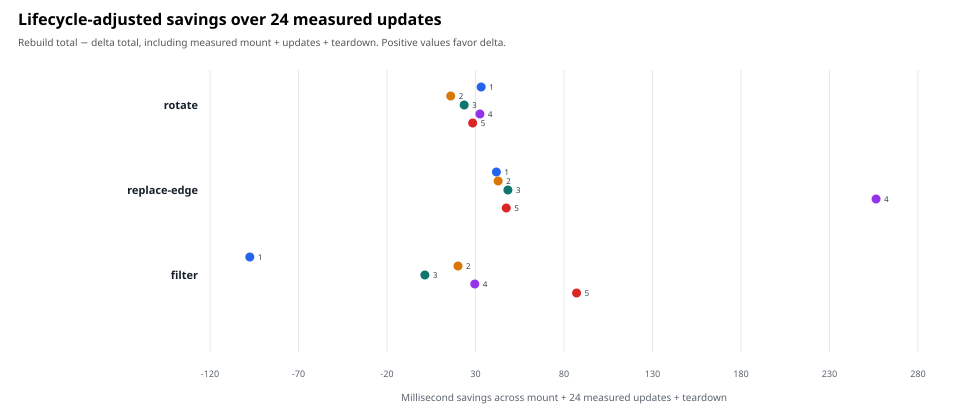

In [74]:
const keyIndexManifest = JSON.parse(
  await Deno.readTextFile(
    "results/browser-key-index-maintenance-v1-manifest.json",
  ),
);
if (
  keyIndexManifest.schemaVersion !== "key-index-maintenance-v1-manifest" ||
  keyIndexManifest.status !== "PASS" || keyIndexManifest.acceptedPages !== 5
) {
  throw new Error("Key-index maintenance raw manifest is invalid");
}
for (
  const input of keyIndexManifest.inputs as Array<{
    path: string;
    sha256: string;
  }>
) {
  const bytes = await Deno.readFile(input.path);
  const digest = await crypto.subtle.digest("SHA-256", bytes);
  const actual = [...new Uint8Array(digest)].map((byte) =>
    byte.toString(16).padStart(2, "0")
  ).join("");
  if (actual !== input.sha256) {
    throw new Error(`SHA-256 mismatch for key-index input ${input.path}`);
  }
}
const keyIndexPreregistration = JSON.parse(
  await Deno.readTextFile(
    "results/key-index-maintenance-v1-preregistration.json",
  ),
);
const keyIndexSeeds = keyIndexPreregistration.design.seeds as number[];
const keyIndexRecords = await Promise.all(
  keyIndexSeeds.map(async (seed) =>
    JSON.parse(
      await Deno.readTextFile(
        `results/browser-key-index-maintenance-v1-${seed}.json`,
      ),
    )
  ),
);
const keyIndexArms = ["react", "rebuild", "delta"] as const;
const keyIndexOperations = ["rotate", "replace-edge", "filter"] as const;
if (
  keyIndexPreregistration.schemaVersion !==
    "key-index-maintenance-preregistration-v1" ||
  keyIndexPreregistration.status !== "FROZEN_BEFORE_COLLECTION" ||
  keyIndexPreregistration.design.pageReplications !== keyIndexSeeds.length ||
  keyIndexRecords.length !== 5 ||
  keyIndexRecords.some((record: any, index: number) =>
    record.schemaVersion !== "key-index-maintenance-browser-v1" ||
    record.status !== "PASS" || record.seed !== keyIndexSeeds[index] ||
    record.count !== 10_000 || record.warmupPairs !== 8 ||
    record.measuredPairs !== 24 ||
    record.browser.visibilityState !== "visible" ||
    record.scenarios.length !== keyIndexOperations.length ||
    !record.scenarios.every((scenario: any, scenarioIndex: number) =>
      scenario.operation === keyIndexOperations[scenarioIndex] &&
      scenario.outputParity && scenario.stableIdentity &&
      scenario.teardownEmpty && scenario.samples.length === 24 &&
      scenario.samples.every((sample: any, sampleIndex: number) =>
        sample.pair === sampleIndex && sample.outputParity &&
        keyIndexArms.every((arm) => sample.identity[arm] === true)
      ) && (scenario.operation !== "filter" ||
        scenario.samples.filter((sample: any) => sample.direction === "shrink")
                .length === 12 &&
          scenario.samples.filter((sample: any) =>
              sample.direction === "restore"
            )
              .length === 12)
    )
  )
) {
  throw new Error(
    "Key-index maintenance preregistration or page contracts failed",
  );
}
const keyIndexMedian = (values: number[]) => {
  const sorted = [...values].sort((a, b) => a - b);
  const center = Math.floor(sorted.length / 2);
  return sorted.length % 2
    ? sorted[center]
    : (sorted[center - 1] + sorted[center]) / 2;
};
const keyIndexPercentile = (values: number[], p: number) => {
  const sorted = [...values].sort((a, b) => a - b);
  return sorted[Math.max(0, Math.ceil(p * sorted.length) - 1)];
};
type KeyIndexGroup = "rotate" | "replace-edge" | "shrink" | "restore";
const keyIndexGroups: KeyIndexGroup[] = [
  "rotate",
  "replace-edge",
  "shrink",
  "restore",
];
const keyIndexPageSummaries = keyIndexRecords.flatMap((record: any) =>
  keyIndexGroups.map((group) => {
    const scenario = record.scenarios.find((item: any) =>
      item.operation ===
        (group === "shrink" || group === "restore" ? "filter" : group)
    );
    const samples = group === "shrink" || group === "restore"
      ? scenario.samples.filter((sample: any) => sample.direction === group)
      : scenario.samples;
    const armMedianMs = Object.fromEntries(keyIndexArms.map((arm) => [
      arm,
      keyIndexMedian(samples.map((sample: any) => sample.milliseconds[arm])),
    ]));
    const pairedDifferences = samples.map((sample: any) =>
      sample.milliseconds.rebuild - sample.milliseconds.delta
    );
    const pairedRatios = samples.map((sample: any) =>
      sample.milliseconds.rebuild / sample.milliseconds.delta
    );
    const lifecycleOverheadMs =
      (scenario.mountMs.delta + scenario.teardownMs.delta) -
      (scenario.mountMs.rebuild + scenario.teardownMs.rebuild);
    const lifecycleAdjustedSavingsMs = scenario.mountMs.rebuild +
      scenario.teardownMs.rebuild +
      scenario.samples.reduce(
        (sum: number, sample: any) => sum + sample.milliseconds.rebuild,
        0,
      ) -
      (scenario.mountMs.delta + scenario.teardownMs.delta +
        scenario.samples.reduce(
          (sum: number, sample: any) => sum + sample.milliseconds.delta,
          0,
        ));
    return {
      seed: record.seed,
      page: String(record.seed).slice(-1),
      group,
      n: samples.length,
      armMedianMs,
      pairedDifferenceMedianMs: keyIndexMedian(pairedDifferences),
      pairedRatioMedian: keyIndexMedian(pairedRatios),
      rebuildP95Ms: keyIndexPercentile(
        samples.map((sample: any) => sample.milliseconds.rebuild),
        0.95,
      ),
      deltaP95Ms: keyIndexPercentile(
        samples.map((sample: any) => sample.milliseconds.delta),
        0.95,
      ),
      mountPlusTeardown: {
        rebuildMs: scenario.mountMs.rebuild + scenario.teardownMs.rebuild,
        deltaMs: scenario.mountMs.delta + scenario.teardownMs.delta,
      },
      lifecycleOverheadMs,
      lifecycleAdjustedSavingsMs,
    };
  })
);
const keyIndexGroupSummary = keyIndexGroups.map((group) => {
  const pages = keyIndexPageSummaries.filter((page) => page.group === group);
  const med = (pick: (page: any) => number) => keyIndexMedian(pages.map(pick));
  const improvedPages = pages.filter((page) =>
    page.pairedDifferenceMedianMs > 0
  ).length;
  return {
    group,
    pages: pages.length,
    updatesPerPage: pages[0].n,
    reactMedianOfPageMediansMs: med((page) => page.armMedianMs.react),
    rebuildMedianOfPageMediansMs: med((page) => page.armMedianMs.rebuild),
    deltaMedianOfPageMediansMs: med((page) => page.armMedianMs.delta),
    pairedDifferenceMedianOfPageMediansMs: med((page) =>
      page.pairedDifferenceMedianMs
    ),
    pairedRatioMedianOfPageMedians: med((page) => page.pairedRatioMedian),
    pagesDeltaFaster: improvedPages,
    lifecycleOverheadMedianMs: med((page) => page.lifecycleOverheadMs),
    lifecycleAdjustedSavingsMedianMs: med((page) =>
      page.lifecycleAdjustedSavingsMs
    ),
  };
});
console.table(keyIndexGroupSummary);
console.table(keyIndexPageSummaries.map((page) => ({
  seed: page.seed,
  operation: page.group,
  n: page.n,
  reactMedianMs: page.armMedianMs.react,
  rebuildMedianMs: page.armMedianMs.rebuild,
  deltaMedianMs: page.armMedianMs.delta,
  pairedRebuildMinusDeltaMs: page.pairedDifferenceMedianMs,
  pairedRebuildOverDelta: page.pairedRatioMedian,
  rebuildP95Ms: page.rebuildP95Ms,
  deltaP95Ms: page.deltaP95Ms,
  lifecycleOverheadMs: page.lifecycleOverheadMs,
  lifecycleAdjustedSavingsMs: page.lifecycleAdjustedSavingsMs,
})));

const keyIndexColors = ["#2563eb", "#d97706", "#0f766e", "#9333ea", "#dc2626"];
const keyIndexDifferenceWidth = 960;
const keyIndexDifferenceHeight = 500;
const keyIndexDiffMin = -1;
const keyIndexDiffMax = 4;
const keyIndexDiffLeft = 190;
const keyIndexDiffRight = 40;
const keyIndexDiffPlotWidth = keyIndexDifferenceWidth - keyIndexDiffLeft -
  keyIndexDiffRight;
const keyIndexDiffX = (value: number) =>
  keyIndexDiffLeft +
  (value - keyIndexDiffMin) / (keyIndexDiffMax - keyIndexDiffMin) *
    keyIndexDiffPlotWidth;
const keyIndexDiffSvg: string[] = [
  `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${keyIndexDifferenceHeight}" viewBox="0 0 ${keyIndexDifferenceWidth} ${keyIndexDifferenceHeight}" role="img" aria-labelledby="key-index-diff-title key-index-diff-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">`,
  `<title id="key-index-diff-title">Key-index strategy paired update differences</title>`,
  `<desc id="key-index-diff-desc">Each point is one fresh page's median paired update difference, keyed-subtree rescan minus delta maintenance. Positive values mean delta was faster. Five page replications are shown for rotation, edge replacement, filter shrink, and filter restore.</desc>`,
  `<rect width="100%" height="100%" fill="white"/>`,
  `<text x="18" y="25" font-size="16" font-weight="700">Paired update time · keyed-subtree rescan − delta maintenance</text>`,
  `<text x="18" y="46" fill="#555" font-size="10">Positive values favor delta; page load is the replication unit. React is contextual. N=5 pages on one device.</text>`,
];
for (let tick = keyIndexDiffMin; tick <= keyIndexDiffMax; tick++) {
  const x = keyIndexDiffX(tick);
  keyIndexDiffSvg.push(
    `<line x1="${x}" x2="${x}" y1="72" y2="440" stroke="${
      tick === 0 ? "#111827" : "#e5e7eb"
    }" stroke-width="${
      tick === 0 ? 2 : 1
    }"/><text x="${x}" y="463" text-anchor="middle" fill="#59636e" font-size="10">${tick}</text>`,
  );
}
keyIndexGroups.forEach((group, groupIndex) => {
  const centerY = 110 + groupIndex * 82;
  keyIndexDiffSvg.push(
    `<text x="${keyIndexDiffLeft - 12}" y="${
      centerY + 4
    }" text-anchor="end" fill="#17202a" font-size="11" font-weight="700">${group}</text>`,
  );
  const pages = keyIndexPageSummaries.filter((page) => page.group === group);
  pages.forEach((page, pageIndex) => {
    const x = keyIndexDiffX(page.pairedDifferenceMedianMs);
    const y = centerY + (pageIndex - 2) * 10;
    keyIndexDiffSvg.push(
      `<circle cx="${x}" cy="${y}" r="4.5" fill="${
        keyIndexColors[pageIndex]
      }"/><text x="${x + 8}" y="${
        y + 3
      }" fill="#374151" font-size="8">${page.page}</text>`,
    );
  });
});
keyIndexDiffSvg.push(
  `<text x="${
    keyIndexDiffLeft + keyIndexDiffPlotWidth / 2
  }" y="487" text-anchor="middle" fill="#59636e" font-size="10">Median paired difference per page · milliseconds</text></svg>`,
);
Deno.jupyter.svg`${keyIndexDiffSvg.join("")}`;

const keyIndexLifecycleWidth = 960;
const keyIndexLifecycleHeight = 410;
const keyIndexLifeMin = -120;
const keyIndexLifeMax = 280;
const keyIndexLifeLeft = 210;
const keyIndexLifeRight = 42;
const keyIndexLifePlotWidth = keyIndexLifecycleWidth - keyIndexLifeLeft -
  keyIndexLifeRight;
const keyIndexLifeX = (value: number) =>
  keyIndexLifeLeft +
  (value - keyIndexLifeMin) / (keyIndexLifeMax - keyIndexLifeMin) *
    keyIndexLifePlotWidth;
const keyIndexLifeSvg: string[] = [
  `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${keyIndexLifecycleHeight}" viewBox="0 0 ${keyIndexLifecycleWidth} ${keyIndexLifecycleHeight}" role="img" aria-labelledby="key-index-life-title key-index-life-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">`,
  `<title id="key-index-life-title">Mount and teardown adjusted comparison</title>`,
  `<desc id="key-index-life-desc">Each point is a page-level difference between the rebuild and delta arms after adding measured mount, 24 measured updates, and teardown for the operation. Positive values mean the complete measured episode took less time with delta maintenance.</desc>`,
  `<rect width="100%" height="100%" fill="white"/>`,
  `<text x="18" y="25" font-size="16" font-weight="700">Lifecycle-adjusted savings over 24 measured updates</text>`,
  `<text x="18" y="46" fill="#555" font-size="10">Rebuild total − delta total, including measured mount + updates + teardown. Positive values favor delta.</text>`,
];
for (let tick = keyIndexLifeMin; tick <= keyIndexLifeMax; tick += 50) {
  const x = keyIndexLifeX(tick);
  keyIndexLifeSvg.push(
    `<line x1="${x}" x2="${x}" y1="70" y2="352" stroke="${
      tick === 0 ? "#111827" : "#e5e7eb"
    }" stroke-width="${
      tick === 0 ? 2 : 1
    }"/><text x="${x}" y="377" text-anchor="middle" fill="#59636e" font-size="9">${tick}</text>`,
  );
}
(["rotate", "replace-edge", "filter"] as const).forEach(
  (operation, rowIndex) => {
    const centerY = 105 + rowIndex * 85;
    keyIndexLifeSvg.push(
      `<text x="${keyIndexLifeLeft - 12}" y="${
        centerY + 4
      }" text-anchor="end" fill="#17202a" font-size="11" font-weight="700">${operation}</text>`,
    );
    keyIndexRecords.forEach((record: any, pageIndex: number) => {
      const scenario = record.scenarios.find((item: any) =>
        item.operation === operation
      );
      const rebuildTotal = scenario.mountMs.rebuild +
        scenario.teardownMs.rebuild + scenario.samples.reduce(
          (sum: number, sample: any) => sum + sample.milliseconds.rebuild,
          0,
        );
      const deltaTotal = scenario.mountMs.delta + scenario.teardownMs.delta +
        scenario.samples.reduce(
          (sum: number, sample: any) => sum + sample.milliseconds.delta,
          0,
        );
      const x = keyIndexLifeX(rebuildTotal - deltaTotal);
      const y = centerY + (pageIndex - 2) * 9;
      keyIndexLifeSvg.push(
        `<circle cx="${x}" cy="${y}" r="4.5" fill="${
          keyIndexColors[pageIndex]
        }"/><text x="${x + 8}" y="${y + 3}" fill="#374151" font-size="8">${
          String(record.seed).slice(-1)
        }</text>`,
      );
    });
  },
);
keyIndexLifeSvg.push(
  `<text x="${
    keyIndexLifeLeft + keyIndexLifePlotWidth / 2
  }" y="401" text-anchor="middle" fill="#59636e" font-size="10">Millisecond savings across mount + 24 measured updates + teardown</text></svg>`,
);
Deno.jupyter.svg`${keyIndexLifeSvg.join("")}`;



### Experiment AI — keyed index optimization in a stateful structural workload

The preceding key-index mechanism study showed that delta maintenance reduced index visits. This preregistered follow-up asks whether that win survives when the same compiled component-state runtime updates a 10,000-row list whose rows each own local state. The causal comparison is between two runtime arms that differ only in key-index maintenance: subtree rebuild versus delta maintenance. React + Compiler is included as a contextual same-page reference, not as the causal control.

Five fresh visible production-build pages each ran eight warmups followed by 24 measured pairs for rotation, edge replacement, and half-list filtering. AMD-1 fixed a pilot-discovered protocol bug before scheduled collection: warmups now precede the separately shuffled measured phase, whose six arm orders occur four times each. Filter direction is recorded per pair, with 12 shrink and 12 restore samples. All five pages passed ordered-output parity, stable keyed host identity, removal/reinsertion identity, local-state retention, and empty teardown checks. The page is the replication unit; paired updates are repeated measures.

The cell below validates the amended preregistration, immutable collection-time manifest, five raw-record hashes, exact pair IDs, arm-order balance, and direction counts before calculating page-level medians and SVG figures. It reports historical source drift separately: six source inputs changed after collection, with an exact old `jsx_binding_runtime.ts` copy recoverable from another study snapshot; exact copies of the other five changed files were not found in the workspace. The saved records still support reproducible descriptive summaries, but the measured implementation cannot be reconstructed completely. Positive paired differences (rebuild minus delta) favor delta. Lifecycle totals combine one mount and teardown observation with 24 updates and are descriptive, not a stable break-even estimate. The page records and manifest live under `results/component-state-structural-index-v1/`; the out-of-schedule archive smoke is isolated under `results/component-state-structural-index-v1-pilot/`.


Structural index V1 historical-input audit:


┌───────┬─────────────────────────────────────────────────────────────────────────────────────────────────────────┬────────────────────────────┬─────────────────┐
│ (idx) │ path                                                                                                    │ status                     │ recoveredCopies │
├───────┼─────────────────────────────────────────────────────────────────────────────────────────────────────────┼────────────────────────────┼─────────────────┤
│     0 │ "results/component-state-structural-index-v1-preregistration.json"                                      │ "matches collection"       │               0 │
│     1 │ "results/component-state-structural-index-v1-source-lock.json"                                          │ "matches collection"       │               0 │
│     2 │ "component-state-index-benchmark.html"                                                                  │ "matches collection"       │               0 │
│     3 │ "src/browser

┌───────┬────────────────┬───────┬────────────────┬────────────────────────────┬──────────────────────────────┬────────────────────────────┬───────────────────────────────────────┬────────────────────────────────┬──────────────────┐
│ (idx) │ group          │ pages │ updatesPerPage │ reactMedianOfPageMediansMs │ rebuildMedianOfPageMediansMs │ deltaMedianOfPageMediansMs │ pairedDifferenceMedianOfPageMediansMs │ pairedRatioMedianOfPageMedians │ pagesDeltaFaster │
├───────┼────────────────┼───────┼────────────────┼────────────────────────────┼──────────────────────────────┼────────────────────────────┼───────────────────────────────────────┼────────────────────────────────┼──────────────────┤
│     0 │ "rotate"       │     5 │             24 │ 5.200000017881393          │ 13.700000002980232           │ 12                         │ 1.9000000059604645                    │ 1.1659420296803644             │                5 │
│     1 │ "replace-edge" │     5 │             24 │ 4.90000000596046

┌───────┬──────────┬────────────────┬────┬────────────────────┬────────────────────┬────────────────────┬───────────────────────────┬────────────────────────┬────────────────────┐
│ (idx) │ seed     │ operation      │ n  │ reactMedianMs      │ rebuildMedianMs    │ deltaMedianMs      │ pairedRebuildMinusDeltaMs │ pairedRebuildOverDelta │ deltaP95Ms         │
├───────┼──────────┼────────────────┼────┼────────────────────┼────────────────────┼────────────────────┼───────────────────────────┼────────────────────────┼────────────────────┤
│     0 │ 83003001 │ "rotate"       │ 24 │ 5.25               │ 13.700000002980232 │ 11.599999979138374 │ 2.250000014901161         │ 1.2081417152656586     │ 14                 │
│     1 │ 83003001 │ "replace-edge" │ 24 │ 5.300000011920929  │ 14.549999997019768 │ 13                 │ 1.7499999850988388        │ 1.1367576133042334     │ 14.5               │
│     2 │ 83003001 │ "shrink"       │ 12 │ 7.4000000059604645 │ 24.150000005960464 │ 20.600000008940

┌───────┬──────────┬────────────────────┬───────────────────┬─────────────────────┐
│ (idx) │ seed     │ rebuildLifecycleMs │ deltaLifecycleMs  │ rebuildMinusDeltaMs │
├───────┼──────────┼────────────────────┼───────────────────┼─────────────────────┤
│     0 │ 83003001 │ 911.9000000655651  │ 803.6000000238419 │ 108.30000004172325  │
│     1 │ 83003002 │ 813.0999999940395  │ 918.4999998807907 │ -105.39999988675117 │
│     2 │ 83003003 │ 868.1999999284744  │ 817.499999910593  │ 50.70000001788139   │
│     3 │ 83003004 │ 910.4999999701977  │ 798.4000000357628 │ 112.09999993443489  │
│     4 │ 83003005 │ 879.7000000476837  │ 872.8999999761581 │ 6.800000071525574   │
└───────┴──────────┴────────────────────┴───────────────────┴─────────────────────┘


┌───────┬───────┬──────────────────────────┬───────────────────────────┐
│ (idx) │ pages │ medianLifecycleSavingsMs │ pagesDeltaLifecycleFaster │
├───────┼───────┼──────────────────────────┼───────────────────────────┤
│     0 │     5 │ 50.70000001788139        │                         4 │
└───────┴───────┴──────────────────────────┴───────────────────────────┘


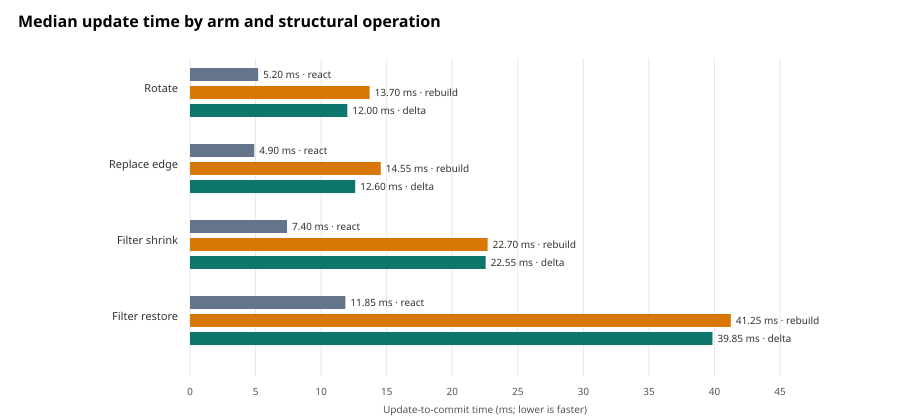

In [75]:
const structuralIndexV1Manifest = JSON.parse(
  await Deno.readTextFile(
    "results/component-state-structural-index-v1-manifest.json",
  ),
);
const structuralIndexV1Prereg = JSON.parse(
  await Deno.readTextFile(
    "results/component-state-structural-index-v1-preregistration.json",
  ),
);
const structuralIndexV1SourceAudit = JSON.parse(
  await Deno.readTextFile(
    "results/component-state-structural-index-v1-source-drift-audit.json",
  ),
);
if (
  structuralIndexV1Manifest.schemaVersion !==
    "component-state-structural-index-v1-manifest" ||
  structuralIndexV1Manifest.status !== "PASS" ||
  structuralIndexV1Manifest.acceptedPages !== 5 ||
  structuralIndexV1Manifest.totalMeasuredPairs !== 360 ||
  structuralIndexV1Prereg.status !== "FROZEN_BEFORE_COLLECTION" ||
  structuralIndexV1Prereg.amendments?.[0]?.id !== "AMD-1" ||
  structuralIndexV1SourceAudit.schemaVersion !==
    "component-state-structural-index-v1-source-drift-audit" ||
  structuralIndexV1SourceAudit.verifiedAcceptedRawPages !== 5
) {
  throw new Error("Structural index V1 preregistration/manifest failed");
}
const structuralIndexV1Hash = async (data: Uint8Array) => {
  const hash = await crypto.subtle.digest("SHA-256", data);
  return [...new Uint8Array(hash)].map((byte) =>
    byte.toString(16).padStart(2, "0")
  ).join("");
};
const structuralIndexV1ManifestBytes = await Deno.readFile(
  "results/component-state-structural-index-v1-manifest.json",
);
if (
  structuralIndexV1SourceAudit.originalManifest.bytes !==
    structuralIndexV1ManifestBytes.length ||
  await structuralIndexV1Hash(structuralIndexV1ManifestBytes) !==
    structuralIndexV1SourceAudit.originalManifest.sha256
) {
  throw new Error("Structural index V1 historical manifest changed");
}
const structuralIndexV1SourceDrift: Array<{
  path: string;
  status: string;
  recoveredCopies: number;
}> = [];
for (
  const recorded of structuralIndexV1SourceAudit.inputs as Array<{
    path: string;
    historicalSha256: string;
    historicalBytes: number;
    recoveredCopies: string[];
  }>
) {
  const input = structuralIndexV1Manifest.inputs.find((item: any) =>
    item.path === recorded.path
  );
  if (
    !input || input.sha256 !== recorded.historicalSha256 ||
    input.bytes !== recorded.historicalBytes
  ) {
    throw new Error(`Source audit disagrees with manifest: ${recorded.path}`);
  }
  const data = await Deno.readFile(recorded.path);
  const currentHash = await structuralIndexV1Hash(data);
  const matchesCollection = currentHash === recorded.historicalSha256 &&
    data.length === recorded.historicalBytes;
  const acceptedRawPage = recorded.path.startsWith(
    "results/component-state-structural-index-v1/browser-component-state-structural-index-v1-",
  );
  if (acceptedRawPage && !matchesCollection) {
    throw new Error(`Accepted raw page hash mismatch: ${recorded.path}`);
  }
  for (const recoveredPath of recorded.recoveredCopies) {
    const recovered = await Deno.readFile(recoveredPath);
    if (
      recovered.length !== recorded.historicalBytes ||
      await structuralIndexV1Hash(recovered) !== recorded.historicalSha256
    ) {
      throw new Error(`Recovered source hash mismatch: ${recoveredPath}`);
    }
  }
  structuralIndexV1SourceDrift.push({
    path: recorded.path,
    status: matchesCollection ? "matches collection" : "changed after collection",
    recoveredCopies: recorded.recoveredCopies.length,
  });
}
if (structuralIndexV1SourceDrift.length !== structuralIndexV1Manifest.inputs.length) {
  throw new Error("Structural index V1 source audit is incomplete");
}
console.log("Structural index V1 historical-input audit:");
console.table(structuralIndexV1SourceDrift);

const structuralIndexV1Arms = ["react", "rebuild", "delta"] as const;
const structuralIndexV1Operations = [
  "rotate",
  "replace-edge",
  "filter-half",
] as const;
const structuralIndexV1Median = (values: number[]) => {
  const sorted = [...values].sort((a, b) => a - b);
  const center = Math.floor(sorted.length / 2);
  return sorted.length % 2
    ? sorted[center]
    : (sorted[center - 1] + sorted[center]) / 2;
};
const structuralIndexV1Percentile = (values: number[], p: number) => {
  const sorted = [...values].sort((a, b) => a - b);
  return sorted[Math.max(0, Math.ceil(p * sorted.length) - 1)];
};
const structuralIndexV1Records = await Promise.all(
  (structuralIndexV1Prereg.design.seeds as number[]).map(async (seed) =>
    JSON.parse(
      await Deno.readTextFile(
        `results/component-state-structural-index-v1/browser-component-state-structural-index-v1-${seed}.json`,
      ),
    )
  ),
);
const structuralIndexV1GroupNames = [
  "rotate",
  "replace-edge",
  "shrink",
  "restore",
] as const;
const structuralIndexV1PageSummaries = structuralIndexV1Records.flatMap(
  (record: any) =>
    structuralIndexV1GroupNames.map((group) => {
      const operation = group === "shrink" || group === "restore"
        ? "filter-half"
        : group;
      const scenario = record.scenarios.find((item: any) =>
        item.operation === operation
      );
      const samples = group === "shrink" || group === "restore"
        ? scenario.samples.filter((sample: any) => sample.direction === group)
        : scenario.samples;
      const armMedianMs = Object.fromEntries(
        structuralIndexV1Arms.map((arm) => [
          arm,
          structuralIndexV1Median(
            samples.map((sample: any) => sample.milliseconds[arm]),
          ),
        ]),
      );
      const pairedDifferences = samples.map((sample: any) =>
        sample.milliseconds.rebuild - sample.milliseconds.delta
      );
      const pairedRatios = samples.map((sample: any) =>
        sample.milliseconds.rebuild / sample.milliseconds.delta
      );
      return {
        seed: record.seed,
        page: String(record.seed).slice(-1),
        group,
        n: samples.length,
        armMedianMs,
        armP95Ms: Object.fromEntries(
          structuralIndexV1Arms.map((arm) => [
            arm,
            structuralIndexV1Percentile(
              samples.map((sample: any) => sample.milliseconds[arm]),
              0.95,
            ),
          ]),
        ),
        pairedDifferenceMedianMs: structuralIndexV1Median(pairedDifferences),
        pairedRatioMedian: structuralIndexV1Median(pairedRatios),
      };
    }),
);
const structuralIndexV1GroupSummary = structuralIndexV1GroupNames.map(
  (group) => {
    const pages = structuralIndexV1PageSummaries.filter((page) =>
      page.group === group
    );
    const median = (pick: (page: any) => number) =>
      structuralIndexV1Median(pages.map(pick));
    return {
      group,
      pages: pages.length,
      updatesPerPage: pages[0].n,
      reactMedianOfPageMediansMs: median((page) => page.armMedianMs.react),
      rebuildMedianOfPageMediansMs: median((page) => page.armMedianMs.rebuild),
      deltaMedianOfPageMediansMs: median((page) => page.armMedianMs.delta),
      pairedDifferenceMedianOfPageMediansMs: median((page) =>
        page.pairedDifferenceMedianMs
      ),
      pairedRatioMedianOfPageMedians: median((page) => page.pairedRatioMedian),
      pagesDeltaFaster:
        pages.filter((page) => page.pairedDifferenceMedianMs > 0).length,
    };
  },
);
console.table(structuralIndexV1GroupSummary);
console.table(structuralIndexV1PageSummaries.map((page: any) => ({
  seed: page.seed,
  operation: page.group,
  n: page.n,
  reactMedianMs: page.armMedianMs.react,
  rebuildMedianMs: page.armMedianMs.rebuild,
  deltaMedianMs: page.armMedianMs.delta,
  pairedRebuildMinusDeltaMs: page.pairedDifferenceMedianMs,
  pairedRebuildOverDelta: page.pairedRatioMedian,
  deltaP95Ms: page.armP95Ms.delta,
})));

const structuralIndexV1Lifecycle = structuralIndexV1Records.map(
  (record: any) => {
    const scenario = record.scenarios.find((item: any) =>
      item.operation === "filter-half"
    );
    const total = (arm: "rebuild" | "delta") =>
      scenario.mountMs[arm] + scenario.teardownMs[arm] +
      scenario.samples.reduce(
        (sum: number, sample: any) => sum + sample.milliseconds[arm],
        0,
      );
    return {
      seed: record.seed,
      rebuildLifecycleMs: total("rebuild"),
      deltaLifecycleMs: total("delta"),
      rebuildMinusDeltaMs: total("rebuild") - total("delta"),
    };
  },
);
console.table(structuralIndexV1Lifecycle);
console.table([{
  pages: structuralIndexV1Lifecycle.length,
  medianLifecycleSavingsMs: structuralIndexV1Median(
    structuralIndexV1Lifecycle.map((item) => item.rebuildMinusDeltaMs),
  ),
  pagesDeltaLifecycleFaster: structuralIndexV1Lifecycle.filter((item) =>
    item.rebuildMinusDeltaMs > 0
  ).length,
}]);

const structuralIndexV1Width = 920;
const structuralIndexV1Height = 470;
const structuralIndexV1Left = 190;
const structuralIndexV1Right = 34;
const structuralIndexV1Top = 66;
const structuralIndexV1Bottom = 64;
const structuralIndexV1PlotW = structuralIndexV1Width -
  structuralIndexV1Left - structuralIndexV1Right;
const structuralIndexV1PlotH = structuralIndexV1Height -
  structuralIndexV1Top - structuralIndexV1Bottom;
const structuralIndexV1AllDiffs = structuralIndexV1PageSummaries.map((page) =>
  page.pairedDifferenceMedianMs
);
const structuralIndexV1DiffMin = Math.min(-1, ...structuralIndexV1AllDiffs);
const structuralIndexV1DiffMax = Math.max(1, ...structuralIndexV1AllDiffs);
const structuralIndexV1Y = (value: number) =>
  structuralIndexV1Top +
  (structuralIndexV1DiffMax - value) /
    (structuralIndexV1DiffMax - structuralIndexV1DiffMin) *
    structuralIndexV1PlotH;
const structuralIndexV1Groups = [
  { id: "rotate", label: "Rotate" },
  { id: "replace-edge", label: "Replace edge" },
  { id: "shrink", label: "Filter shrink" },
  { id: "restore", label: "Filter restore" },
];
const structuralIndexV1Colors = [
  "#2563eb",
  "#d97706",
  "#0f766e",
  "#9333ea",
  "#dc2626",
];
const structuralIndexV1DiffSvg = [
  `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${structuralIndexV1Height}" viewBox="0 0 ${structuralIndexV1Width} ${structuralIndexV1Height}" role="img" aria-labelledby="struct-index-diff-title struct-index-diff-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">`,
  `<title id="struct-index-diff-title">Stateful structural update paired differences</title>`,
  `<desc id="struct-index-diff-desc">Each point is one page-level median paired update difference, subtree rebuild minus delta index maintenance. Positive values favor delta. Five page replications are shown for rotation, edge replacement, filter shrink, and filter restore. React is contextual and omitted from this causal chart.</desc>`,
  `<rect width="100%" height="100%" fill="white"/>`,
  `<text x="18" y="27" font-size="16" font-weight="700">Stateful keyed updates · rebuild − delta</text>`,
  `<text x="18" y="47" fill="#555" font-size="10">Positive values favor delta. Each mark is a page median; N=5 visible pages on one device.</text>`,
];
for (
  let tick = Math.ceil(structuralIndexV1DiffMin);
  tick <= Math.floor(structuralIndexV1DiffMax);
  tick++
) {
  const y = structuralIndexV1Y(tick);
  structuralIndexV1DiffSvg.push(
    `<line x1="${structuralIndexV1Left}" x2="${
      structuralIndexV1Width - structuralIndexV1Right
    }" y1="${y}" y2="${y}" stroke="${
      tick === 0 ? "#111827" : "#e5e7eb"
    }" stroke-width="${tick === 0 ? 1.6 : 1}"/>`,
    `<text x="${structuralIndexV1Left - 12}" y="${
      y + 4
    }" text-anchor="end" fill="#555" font-size="10">${tick}</text>`,
  );
}
const structuralIndexV1Step = structuralIndexV1PlotW /
  structuralIndexV1Groups.length;
for (const [groupIndex, group] of structuralIndexV1Groups.entries()) {
  const center = structuralIndexV1Left + structuralIndexV1Step *
      (groupIndex + 0.5);
  structuralIndexV1DiffSvg.push(
    `<text x="${center}" y="${
      structuralIndexV1Height - 28
    }" text-anchor="middle" fill="#333" font-size="11">${group.label}</text>`,
  );
  const pages = structuralIndexV1PageSummaries.filter((page) =>
    page.group === group.id
  );
  for (const [pageIndex, page] of pages.entries()) {
    const x = center + (pageIndex - (pages.length - 1) / 2) * 18;
    const y = structuralIndexV1Y(page.pairedDifferenceMedianMs);
    structuralIndexV1DiffSvg.push(
      `<circle cx="${x}" cy="${y}" r="5.5" fill="${
        structuralIndexV1Colors[pageIndex]
      }" stroke="white" stroke-width="1.2"><title>Seed ${page.seed}: ${
        page.pairedDifferenceMedianMs.toFixed(2)
      } ms</title></circle>`,
    );
  }
}
structuralIndexV1DiffSvg.push(
  `<text x="20" y="${
    structuralIndexV1Top + structuralIndexV1PlotH / 2
  }" transform="rotate(-90 20 ${
    structuralIndexV1Top + structuralIndexV1PlotH / 2
  })" text-anchor="middle" fill="#444" font-size="11">Paired update difference (ms)</text>`,
  `</svg>`,
);
Deno.jupyter.svg`${structuralIndexV1DiffSvg.join("")}`;

const structuralIndexV1BarW = 920;
const structuralIndexV1BarH = 420;
const structuralIndexV1BarLeft = 190;
const structuralIndexV1BarRight = 140;
const structuralIndexV1BarTop = 68;
const structuralIndexV1BarRow = 76;
const structuralIndexV1Max = Math.ceil(
  Math.max(
    ...structuralIndexV1GroupSummary.flatMap((item) => [
      item.reactMedianOfPageMediansMs,
      item.rebuildMedianOfPageMediansMs,
      item.deltaMedianOfPageMediansMs,
    ]),
  ) / 5,
) * 5;
const structuralIndexV1BarPlotW = structuralIndexV1BarW -
  structuralIndexV1BarLeft - structuralIndexV1BarRight;
const structuralIndexV1BarSvg = [
  `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${structuralIndexV1BarH}" viewBox="0 0 ${structuralIndexV1BarW} ${structuralIndexV1BarH}" role="img" aria-labelledby="struct-index-arm-title struct-index-arm-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">`,
  `<title id="struct-index-arm-title">React, rebuild, and delta structural update medians</title>`,
  `<desc id="struct-index-arm-desc">Median of five page medians for React context, subtree index rebuild, and delta index maintenance. Lower is faster. Filter directions are shown separately.</desc>`,
  `<rect width="100%" height="100%" fill="white"/>`,
  `<text x="18" y="27" font-size="16" font-weight="700">Median update time by arm and structural operation</text>`,
];
const structuralIndexV1BarColors = {
  react: "#64748b",
  rebuild: "#d97706",
  delta: "#0f766e",
};
for (let tick = 0; tick <= structuralIndexV1Max; tick += 5) {
  const x = structuralIndexV1BarLeft + tick / structuralIndexV1Max *
      structuralIndexV1BarPlotW;
  structuralIndexV1BarSvg.push(
    `<line x1="${x}" x2="${x}" y1="${structuralIndexV1BarTop - 10}" y2="${
      structuralIndexV1BarH - 44
    }" stroke="#e5e7eb"/>`,
    `<text x="${x}" y="${
      structuralIndexV1BarH - 25
    }" text-anchor="middle" fill="#555" font-size="10">${tick}</text>`,
  );
}
for (const [index, group] of structuralIndexV1GroupSummary.entries()) {
  const y = structuralIndexV1BarTop + index * structuralIndexV1BarRow;
  structuralIndexV1BarSvg.push(
    `<text x="${structuralIndexV1BarLeft - 12}" y="${
      y + 24
    }" text-anchor="end" fill="#333" font-size="11">${
      structuralIndexV1Groups[index].label
    }</text>`,
  );
  for (const [armIndex, arm] of structuralIndexV1Arms.entries()) {
    const value = arm === "react"
      ? group.reactMedianOfPageMediansMs
      : arm === "rebuild"
      ? group.rebuildMedianOfPageMediansMs
      : group.deltaMedianOfPageMediansMs;
    const barY = y + armIndex * 18;
    const width = value / structuralIndexV1Max * structuralIndexV1BarPlotW;
    structuralIndexV1BarSvg.push(
      `<rect x="${structuralIndexV1BarLeft}" y="${barY}" width="${width}" height="13" fill="${
        structuralIndexV1BarColors[arm]
      }"/>`,
      `<text x="${structuralIndexV1BarLeft + width + 5}" y="${
        barY + 10
      }" fill="#333" font-size="10">${value.toFixed(2)} ms · ${arm}</text>`,
    );
  }
}
structuralIndexV1BarSvg.push(
  `<text x="${structuralIndexV1BarLeft + structuralIndexV1BarPlotW / 2}" y="${
    structuralIndexV1BarH - 7
  }" text-anchor="middle" fill="#555" font-size="10">Update-to-commit time (ms; lower is faster)</text>`,
  `</svg>`,
);
Deno.jupyter.svg`${structuralIndexV1BarSvg.join("")}`;



### Structural profile V8 — where does keyed update work go?

This is an exploratory five-page diagnostic collected after the stateful keyed-index comparison. The pages use five seeds but the same Chrome 154 profile and physical device, so they describe within-profile repeatability rather than independent replication. The study is not preregistered, and instrumented development-server timings are not a production or React-comparable latency estimate. Each page uses the same 10,000-row fixture, with 8 warmups and 24 measured pairs per operation. The original post-collection manifest preserves collection-time source hashes; a separate source-drift audit records which bytes remain available now.

The analysis verifies all five raw profile hashes and the immutable historical manifest. In the latest audit, 8 of 15 original inputs still match: five runtime/fixture inputs changed after collection, and the notebook analysis cell plus its updater have since been revised. An exact historical copy of jsx_binding_runtime.ts survives in other study snapshots, while exact copies of the other four changed runtime/fixture files were not found in this workspace. The saved records still reproduce the descriptive counter and timing summaries, but those four missing implementation files prevent exact reconstruction of the measured runtime. Filter direction is identified from created/retired owner counters rather than assuming sample parity. Each page contributes its own median; the summary takes the median and range across page-level medians without pooling samples. The SVG shows three measured runtime phases; total time also includes owner book-keeping, effects, scheduler/dispatch work, host calls, and time outside the root flush. Overlapping phase scopes are diagnostic signals, not causal shares.


Historical source-file audit (raw profile hashes are verified separately):


┌───────┬─────────────────────────────────────────────────────────────────────────────┬────────────────────────────┬─────────────────┐
│ (idx) │ path                                                                        │ status                     │ recoveredCopies │
├───────┼─────────────────────────────────────────────────────────────────────────────┼────────────────────────────┼─────────────────┤
│     0 │ "component-state-structural-phase-diagnostic.html"                          │ "matches collection"       │               0 │
│     1 │ "compiler/fixtures/component_state_structural.tsx"                          │ "changed after collection" │               0 │
│     2 │ "deno.json"                                                                 │ "changed after collection" │               0 │
│     3 │ "notebook_cells/component_state_structural_profile_v8.ts"                   │ "changed after collection" │               0 │
│     4 │ "package.json"                               

Page-level medians (filter direction identified from created/retired owner counters):


┌───────┬──────────┬──────────────────┬────┬────────────────────┬────────────────────┬────────────────────┬──────────────────────┬────────────────────┬─────────────────────┬────────────────────┬───────────────────┬────────────────────┬─────────────────────┬─────────────────────┬──────────────────┬────────────────┬─────────────┬──────────────────────┐
│ (idx) │ seed     │ operation        │ n  │ totalMedianMs      │ totalP95Ms         │ rootFlushMedianMs  │ outsideFlushMedianMs │ expandMedianMs     │ normalizeMedianMs   │ reconcileMedianMs  │ ownerVisitsMedian │ reusedOwnersMedian │ createdOwnersMedian │ retiredOwnersMedian │ insertionsMedian │ removalsMedian │ movesMedian │ keyIndexVisitsMedian │
├───────┼──────────┼──────────────────┼────┼────────────────────┼────────────────────┼────────────────────┼──────────────────────┼────────────────────┼─────────────────────┼────────────────────┼───────────────────┼────────────────────┼─────────────────────┼─────────────────────┼───────────────

Median and range across five page-level medians (no pooling):


┌───────┬──────────────────┬───────┬────────────────────┬─────────────────────────────────────────┬──────────────────────┬────────────────────┬────────────────────┬────────────────────┬─────────────┬──────────────┬───────────────┬────────────────┐
│ (idx) │ operation        │ pages │ totalMedianMs      │ totalRangeMs                            │ outsideFlushMedianMs │ expandMedianMs     │ normalizeMedianMs  │ reconcileMedianMs  │ ownerVisits │ reusedOwners │ hostMutations │ keyIndexVisits │
├───────┼──────────────────┼───────┼────────────────────┼─────────────────────────────────────────┼──────────────────────┼────────────────────┼────────────────────┼────────────────────┼─────────────┼──────────────┼───────────────┼────────────────┤
│     0 │ "rotate"         │     5 │ 11                 │ "10.300000011920929–11.150000005960464" │ 1.8500000089406967   │ 5.450000002980232  │ 0.4000000059604645 │ 1.5                │       10000 │        10000 │             1 │              0 │
│     1 

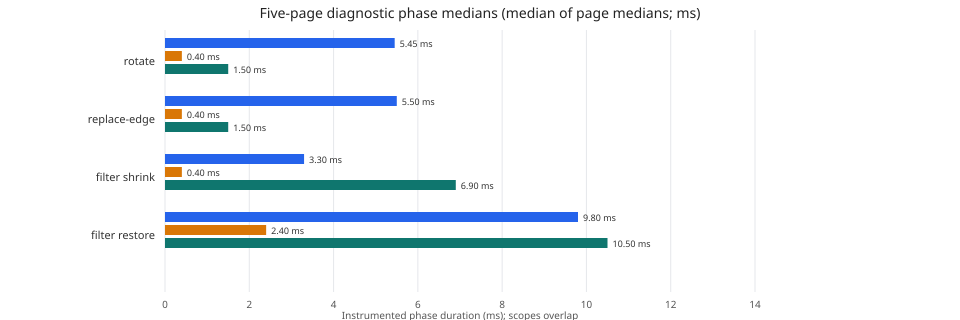

In [76]:
const structuralProfileV8Manifest = JSON.parse(
  await Deno.readTextFile(
    "results/component-state-structural-profile-v8-83004001-83004005-manifest.json",
  ),
);
const structuralProfileV8SourceAudit = JSON.parse(
  await Deno.readTextFile(
    "results/component-state-structural-profile-v8-source-drift-audit.json",
  ),
);
const structuralProfileV8Seeds = [
  83004001,
  83004002,
  83004003,
  83004004,
  83004005,
];
if (
  structuralProfileV8Manifest.schemaVersion !==
    "component-state-structural-profile-v8-multipage-manifest" ||
  structuralProfileV8Manifest.status !==
    "POST_COLLECTION_PINNED_DIAGNOSTIC" ||
  JSON.stringify(structuralProfileV8Manifest.seeds) !==
    JSON.stringify(structuralProfileV8Seeds) ||
  structuralProfileV8Manifest.pageCount !== 5 ||
  structuralProfileV8Manifest.profiles.length !== 5 ||
  structuralProfileV8Manifest.sourceInputs.length !== 15 ||
  structuralProfileV8SourceAudit.schemaVersion !==
    "component-state-structural-profile-v8-source-drift-audit"
) {
  throw new Error("Structural profile V8 multi-page manifest contract failed");
}
const structuralProfileV8Hash = async (bytes: Uint8Array) => {
  const digest = await crypto.subtle.digest("SHA-256", bytes);
  return [...new Uint8Array(digest)].map((byte) =>
    byte.toString(16).padStart(2, "0")
  ).join("");
};
const structuralProfileV8ManifestBytes = await Deno.readFile(
  "results/component-state-structural-profile-v8-83004001-83004005-manifest.json",
);
if (
  structuralProfileV8SourceAudit.originalManifest.bytes !==
    structuralProfileV8ManifestBytes.length ||
  await structuralProfileV8Hash(structuralProfileV8ManifestBytes) !==
    structuralProfileV8SourceAudit.originalManifest.sha256
) {
  throw new Error("Structural profile V8 historical manifest changed");
}
const structuralProfileV8SourceDrift: Array<{
  path: string;
  status: string;
  recoveredCopies: number;
}> = [];
for (const recorded of structuralProfileV8SourceAudit.sourceInputs as Array<{
  path: string;
  historicalBytes: number;
  historicalSha256: string;
  recoveredCopies: string[];
}>) {
  const input = structuralProfileV8Manifest.sourceInputs.find((item: any) =>
    item.path === recorded.path
  );
  if (
    !input || input.bytes !== recorded.historicalBytes ||
    input.sha256 !== recorded.historicalSha256
  ) {
    throw new Error(`Source drift audit disagrees with original manifest: ${recorded.path}`);
  }
  const bytes = await Deno.readFile(recorded.path);
  const matchesCollection = bytes.length === recorded.historicalBytes &&
    await structuralProfileV8Hash(bytes) === recorded.historicalSha256;
  for (const recoveredPath of recorded.recoveredCopies) {
    const recovered = await Deno.readFile(recoveredPath);
    if (
      recovered.length !== recorded.historicalBytes ||
      await structuralProfileV8Hash(recovered) !== recorded.historicalSha256
    ) {
      throw new Error(`Recovered source does not match collection hash: ${recoveredPath}`);
    }
  }
  structuralProfileV8SourceDrift.push({
    path: recorded.path,
    status: matchesCollection ? "matches collection" : "changed after collection",
    recoveredCopies: recorded.recoveredCopies.length,
  });
}
if (structuralProfileV8SourceDrift.length !== 15) {
  throw new Error("Structural profile V8 source drift audit is incomplete");
}
console.log("Historical source-file audit (raw profile hashes are verified separately):");
console.table(structuralProfileV8SourceDrift);
for (const profile of structuralProfileV8Manifest.profiles as Array<{
  path: string;
  bytes: number;
  sha256: string;
}>) {
  const bytes = await Deno.readFile(profile.path);
  if (
    bytes.length !== profile.bytes ||
    await structuralProfileV8Hash(bytes) !== profile.sha256
  ) {
    throw new Error(`Structural profile V8 data hash mismatch: ${profile.path}`);
  }
}

const structuralProfileV8Median = (values: number[]) => {
  const sorted = [...values].sort((a, b) => a - b);
  const center = Math.floor(sorted.length / 2);
  return sorted.length % 2
    ? sorted[center]
    : (sorted[center - 1] + sorted[center]) / 2;
};
const structuralProfileV8P95 = (values: number[]) => {
  const sorted = [...values].sort((a, b) => a - b);
  return sorted[Math.max(0, Math.ceil(0.95 * sorted.length) - 1)];
};
const structuralProfileV8Metric = (sample: any, name: string): number => {
  if (name === "totalUpdateMs") return sample.totalUpdateMs;
  if (name === "rootFlushMs") return sample.rootFlushMs;
  if (name === "outsideRootFlushMs") return sample.outsideRootFlushMs;
  if (name.startsWith("phase:")) {
    return sample.phaseCalls[name.slice(6)]?.[0] ?? 0;
  }
  if (name.startsWith("work:")) {
    return sample.workCounts[name.slice(5)] ?? 0;
  }
  throw new Error(`Unknown profile metric ${name}`);
};
const structuralProfileV8Names = [
  "totalUpdateMs",
  "rootFlushMs",
  "outsideRootFlushMs",
  "phase:owner.expand-and-cache",
  "phase:vdom.normalize",
  "phase:vdom.reconcile-host",
  "work:owner.component-visits",
  "work:owner.cached-reused",
  "work:owner.created",
  "work:owner.retired",
  "work:host.insertions",
  "work:host.removals",
  "work:host.moves",
  "work:vdom.key-index.incremental-old-visits",
  "work:vdom.key-index.incremental-new-visits",
];
const structuralProfileV8Rows: any[] = [];
for (const profileRef of structuralProfileV8Manifest.profiles as Array<{
  path: string;
  seed: number;
}>) {
  const profile = JSON.parse(await Deno.readTextFile(profileRef.path));
  if (
    profile.schemaVersion !==
      "component-state-structural-browser-phase-profile-v8" ||
    profile.seed !== profileRef.seed || profile.count !== 10_000 ||
    profile.operations.length !== 3
  ) {
    throw new Error(`Unexpected structural profile: ${profileRef.path}`);
  }
  for (const operation of profile.operations) {
    if (operation.measuredUpdates !== 24 || operation.samples.length !== 24) {
      throw new Error(`${profile.seed}/${operation.operation}: expected 24 samples`);
    }
    let groups: Array<{ label: string; samples: any[] }>;
    if (operation.operation === "filter-half") {
      const shrink: any[] = [];
      const restore: any[] = [];
      for (const sample of operation.samples) {
        const created = sample.workCounts["owner.created"] ?? 0;
        const retired = sample.workCounts["owner.retired"] ?? 0;
        if (retired === 5_000 && created === 0) shrink.push(sample);
        else if (created === 5_000 && retired === 0) restore.push(sample);
        else throw new Error(`${profile.seed}/filter pair ${sample.pair}: direction is ambiguous`);
      }
      if (shrink.length + restore.length !== 24 || !shrink.length || !restore.length) {
        throw new Error(`${profile.seed}: filter directions do not account for all 24 samples`);
      }
      groups = [
        { label: "filter shrink", samples: shrink },
        { label: "filter restore", samples: restore },
      ];
    } else {
      groups = [{ label: operation.operation, samples: operation.samples }];
    }
    for (const group of groups) {
      const values = Object.fromEntries(
        structuralProfileV8Names.map((name) => [
          name,
          group.samples.map((sample) => structuralProfileV8Metric(sample, name)),
        ]),
      ) as Record<string, number[]>;
      const workMedian = (name: string) =>
        structuralProfileV8Median(values[`work:${name}`]);
      structuralProfileV8Rows.push({
        seed: profile.seed,
        operation: group.label,
        n: group.samples.length,
        totalMedianMs: structuralProfileV8Median(values.totalUpdateMs),
        totalP95Ms: structuralProfileV8P95(values.totalUpdateMs),
        rootFlushMedianMs: structuralProfileV8Median(values.rootFlushMs),
        outsideFlushMedianMs: structuralProfileV8Median(values.outsideRootFlushMs),
        expandMedianMs: structuralProfileV8Median(values["phase:owner.expand-and-cache"]),
        normalizeMedianMs: structuralProfileV8Median(values["phase:vdom.normalize"]),
        reconcileMedianMs: structuralProfileV8Median(values["phase:vdom.reconcile-host"]),
        ownerVisitsMedian: workMedian("owner.component-visits"),
        reusedOwnersMedian: workMedian("owner.cached-reused"),
        createdOwnersMedian: workMedian("owner.created"),
        retiredOwnersMedian: workMedian("owner.retired"),
        insertionsMedian: workMedian("host.insertions"),
        removalsMedian: workMedian("host.removals"),
        movesMedian: workMedian("host.moves"),
        keyIndexVisitsMedian:
          workMedian("vdom.key-index.incremental-old-visits") +
          workMedian("vdom.key-index.incremental-new-visits"),
      });
    }
  }
}
console.log("Page-level medians (filter direction identified from created/retired owner counters):");
console.table(structuralProfileV8Rows);

const structuralProfileV8Labels = [
  "rotate",
  "replace-edge",
  "filter shrink",
  "filter restore",
];
const structuralProfileV8Summary = structuralProfileV8Labels.map((operation) => {
  const pages = structuralProfileV8Rows.filter((row) => row.operation === operation);
  const summarize = (key: string) => {
    const values = pages.map((page) => page[key]);
    return {
      median: structuralProfileV8Median(values),
      min: Math.min(...values),
      max: Math.max(...values),
    };
  };
  return {
    operation,
    pages: pages.length,
    totalMs: summarize("totalMedianMs"),
    outsideFlushMs: summarize("outsideFlushMedianMs"),
    expandCacheMs: summarize("expandMedianMs"),
    normalizeMs: summarize("normalizeMedianMs"),
    reconcileMs: summarize("reconcileMedianMs"),
    ownerVisits: summarize("ownerVisitsMedian"),
    reused: summarize("reusedOwnersMedian"),
    hostInserts: summarize("insertionsMedian"),
    hostRemoves: summarize("removalsMedian"),
    hostMoves: summarize("movesMedian"),
    keyIndexVisits: summarize("keyIndexVisitsMedian"),
  };
});
console.log("Median and range across five page-level medians (no pooling):");
console.table(structuralProfileV8Summary.map((row) => ({
  operation: row.operation,
  pages: row.pages,
  totalMedianMs: row.totalMs.median,
  totalRangeMs: `${row.totalMs.min}–${row.totalMs.max}`,
  outsideFlushMedianMs: row.outsideFlushMs.median,
  expandMedianMs: row.expandCacheMs.median,
  normalizeMedianMs: row.normalizeMs.median,
  reconcileMedianMs: row.reconcileMs.median,
  ownerVisits: row.ownerVisits.median,
  reusedOwners: row.reused.median,
  hostMutations:
    row.hostInserts.median + row.hostRemoves.median + row.hostMoves.median,
  keyIndexVisits: row.keyIndexVisits.median,
})));

const structuralProfileV8ChartW = 960;
const structuralProfileV8ChartH = 320;
const structuralProfileV8Left = 165;
const structuralProfileV8Top = 38;
const structuralProfileV8Row = 58;
const structuralProfileV8PlotW = 590;
const structuralProfileV8Max = 14;
const structuralProfileV8Svg = [
  `<svg xmlns="http://www.w3.org/2000/svg" width="${structuralProfileV8ChartW}" height="${structuralProfileV8ChartH}" viewBox="0 0 ${structuralProfileV8ChartW} ${structuralProfileV8ChartH}">`,
  `<rect width="100%" height="100%" fill="white"/>`,
  `<text x="${structuralProfileV8ChartW / 2}" y="18" text-anchor="middle" font-size="14" font-family="sans-serif" fill="#222">Five-page diagnostic phase medians (median of page medians; ms)</text>`,
];
for (let tick = 0; tick <= structuralProfileV8Max; tick += 2) {
  const x = structuralProfileV8Left +
    tick / structuralProfileV8Max * structuralProfileV8PlotW;
  structuralProfileV8Svg.push(
    `<line x1="${x}" x2="${x}" y1="${structuralProfileV8Top - 8}" y2="${structuralProfileV8ChartH - 28}" stroke="#e5e7eb"/>`,
    `<text x="${x}" y="${structuralProfileV8ChartH - 12}" text-anchor="middle" font-size="10" font-family="sans-serif" fill="#555">${tick}</text>`,
  );
}
const structuralProfileV8Series = [
  { name: "owner expand/cache", key: "expandCacheMs", color: "#2563eb" },
  { name: "VDOM normalize", key: "normalizeMs", color: "#d97706" },
  { name: "host reconcile", key: "reconcileMs", color: "#0f766e" },
] as const;
for (const [rowIndex, summary] of structuralProfileV8Summary.entries()) {
  const y = structuralProfileV8Top + rowIndex * structuralProfileV8Row;
  structuralProfileV8Svg.push(
    `<text x="${structuralProfileV8Left - 10}" y="${y + 27}" text-anchor="end" font-size="11" font-family="sans-serif" fill="#333">${summary.operation}</text>`,
  );
  for (const [seriesIndex, series] of structuralProfileV8Series.entries()) {
    const value = summary[series.key].median;
    const barY = y + seriesIndex * 13;
    const width = Math.min(value, structuralProfileV8Max) /
      structuralProfileV8Max * structuralProfileV8PlotW;
    structuralProfileV8Svg.push(
      `<rect x="${structuralProfileV8Left}" y="${barY}" width="${width}" height="10" fill="${series.color}"/>`,
      `<text x="${structuralProfileV8Left + width + 5}" y="${barY + 9}" font-size="9" font-family="sans-serif" fill="#333">${value.toFixed(2)} ms</text>`,
    );
  }
}
structuralProfileV8Svg.push(
  `<text x="${structuralProfileV8Left + structuralProfileV8PlotW / 2}" y="${structuralProfileV8ChartH - 1}" text-anchor="middle" font-size="10" font-family="sans-serif" fill="#555">Instrumented phase duration (ms); scopes overlap</text>`,
  `</svg>`,
);
Deno.jupyter.svg`${structuralProfileV8Svg.join("")}`;



## Compiler-marked keyed-owner reuse: five-page browser study

This pre-registered study tests one narrow high-frequency structural update: rotating a homogeneous 10,000-row keyed list while retaining the same component-state root and VDOM. The generic and treatment arms differ only in compiler-marked keyed-owner reuse. React 19.3 with React Compiler is a contextual reference, not the causal comparison. Edge replacement and filter shrink/restore exercise fallback behavior.

Five fresh visible production-page loads are the replication units. Each page contributes 24 paired measured updates per operation after eight warmups; the six arm orders are balanced four times. Filter shrink and restore are reported separately. The analysis keeps pages separate, verifies the frozen source lock and raw-record hashes, checks output/identity/state parity, and applies the gates from the frozen amendment. Timing measures update-to-host-commit and excludes layout, paint, and presentation. The separately collected diagnostic pass is used only to verify the mechanism; its timings do not enter the latency analysis.


V1 frozen source snapshot verified; current workspace drift:


┌───────┬──────────────────────────────────────────────────────────────────┬────────────────────────────┐
│ (idx) │ path                                                             │ current                    │
├───────┼──────────────────────────────────────────────────────────────────┼────────────────────────────┤
│     0 │ "component-state-owner-reuse-benchmark.html"                     │ "matches collection"       │
│     1 │ "src/browser/component_state_owner_reuse_benchmark.tsx"          │ "matches collection"       │
│     2 │ "src/browser/generated_component_state_structural.ts"            │ "changed after collection" │
│     3 │ "src/browser/generated_component_state_structural_transform.tsx" │ "changed after collection" │
│     4 │ "src/component_state_runtime.ts"                                 │ "changed after collection" │
│     5 │ "src/owner_state_world.ts"                                       │ "matches collection"       │
│     6 │ "src/jsx_binding_runtime.ts"        

Owner-reuse V1 page-level medians; positive paired difference favors reuse:


┌───────┬──────────┬────────────────┬────┬────────────────────┬────────────────────┬────────────────────┬─────────────────────┬────────────────────┐
│ (idx) │ seed     │ group          │ n  │ reactMs            │ genericMs          │ reuseMs            │ genericMinusReuseMs │ reuseOverGeneric   │
├───────┼──────────┼────────────────┼────┼────────────────────┼────────────────────┼────────────────────┼─────────────────────┼────────────────────┤
│     0 │ 83005001 │ "rotate"       │ 24 │ 4.9000000059604645 │ 10.750000014901161 │ 5.850000008940697  │ 4.550000011920929   │ 0.5642688685687358 │
│     1 │ 83005001 │ "replace-edge" │ 24 │ 4.300000011920929  │ 11                 │ 12.900000005960464 │ -1.9999999850988388 │ 1.1739656621920496 │
│     2 │ 83005001 │ "shrink"       │ 12 │ 6.6500000059604645 │ 19.94999998807907  │ 17.849999994039536 │ 1.8999999910593033  │ 0.9014712203090823 │
│     3 │ 83005001 │ "restore"      │ 12 │ 10.900000005960464 │ 36.6499999910593   │ 38.95000000298023  │ 

Across-page summary of page-level medians (no sample pooling):


┌───────┬────────────────┬───────┬────────────────────┬────────────────────┬────────────────────┬──────────────────────────┬──────────────────────────────────────────┬────────────────────┬─────────────────────────────────────────┬───────────┐
│ (idx) │ group          │ pages │ reactMedianMs      │ genericMedianMs    │ reuseMedianMs      │ pairedDifferenceMedianMs │ pairedDifferenceRangeMs                  │ pairedRatioMedian  │ pairedRatioRange                        │ reuseWins │
├───────┼────────────────┼───────┼────────────────────┼────────────────────┼────────────────────┼──────────────────────────┼──────────────────────────────────────────┼────────────────────┼─────────────────────────────────────────┼───────────┤
│     0 │ "rotate"       │     5 │ 5.100000008940697  │ 10.750000014901161 │ 6.149999991059303  │ 4.649999991059303        │ "4.049999982118607–5.25"                 │ 0.5642688685687358 │ "0.5190134046498747–0.5906552087661194" │         5 │
│     1 │ "replace-edge" │  

Diagnostic work counters (separate from latency records):


┌───────┬────────────────┬───────────┬─────────┬───────────────┬─────────────┬───────────┬───────────────┐
│ (idx) │ operation      │ direction │ samples │ genericVisits │ reuseVisits │ cacheHits │ fallbackCount │
├───────┼────────────────┼───────────┼─────────┼───────────────┼─────────────┼───────────┼───────────────┤
│     0 │ "rotate"       │ "—"       │      24 │         10000 │           0 │     10000 │             0 │
│     1 │ "replace-edge" │ "—"       │      24 │         10000 │       10000 │         0 │             1 │
│     2 │ "filter-half"  │ "shrink"  │      12 │          5000 │        5000 │         0 │             1 │
│     3 │ "filter-half"  │ "restore" │      12 │         10000 │       10000 │         0 │             1 │
└───────┴────────────────┴───────────┴─────────┴───────────────┴─────────────┴───────────┴───────────────┘


Decision gates from the frozen amendment:


┌───────┬───────────────────────────────────┬────────┬─────────────────────────────────────────────────────────────────────────┐
│ (idx) │ gate                              │ result │ evidence                                                                │
├───────┼───────────────────────────────────┼────────┼─────────────────────────────────────────────────────────────────────────┤
│     0 │ "rotation primary latency"        │ "PASS" │ "5/5 pages at ratio ≤ 0.80"                                             │
│     1 │ "edge/filter fallback guardrails" │ "FAIL" │ "median page ratio ≤ 1.10 for edge, shrink, restore"                    │
│     2 │ "rotation mechanism"              │ "PASS" │ "100.0% fewer generic component visits; all 10,000 cache hits required" │
└───────┴───────────────────────────────────┴────────┴─────────────────────────────────────────────────────────────────────────┘


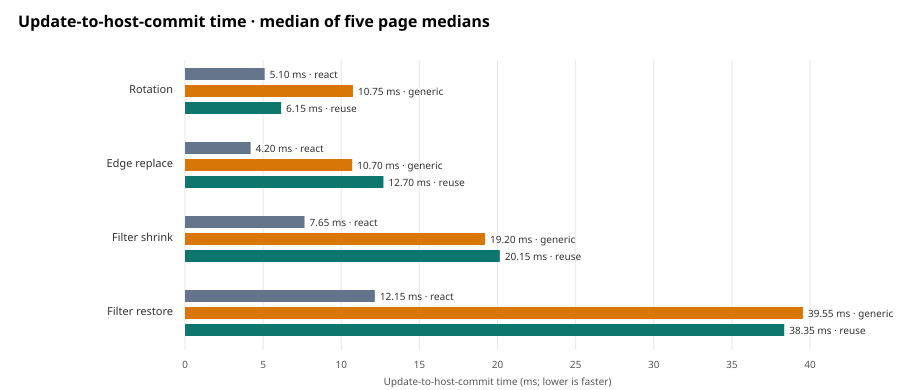

In [77]:
{
const ownerReuseV1ManifestPath =
  "results/component-state-owner-reuse-v1-manifest.json";
const ownerReuseV1Manifest = JSON.parse(
  await Deno.readTextFile(ownerReuseV1ManifestPath),
);
const ownerReuseV1Prereg = JSON.parse(
  await Deno.readTextFile(
    "results/component-state-owner-reuse-v1-preregistration.json",
  ),
);
const ownerReuseV1Amendment = JSON.parse(
  await Deno.readTextFile(
    "results/component-state-owner-reuse-v1-amendment-01.json",
  ),
);
const ownerReuseV1SourceLock = JSON.parse(
  await Deno.readTextFile(
    "results/component-state-owner-reuse-v1-source-lock.json",
  ),
);
const ownerReuseV1Arms = ["react", "generic", "reuse"] as const;
const ownerReuseV1Hash = async (bytes: Uint8Array) => {
  const digest = await crypto.subtle.digest("SHA-256", bytes);
  return [...new Uint8Array(digest)].map((byte) =>
    byte.toString(16).padStart(2, "0")
  ).join("");
};
if (
  ownerReuseV1Manifest.schemaVersion !==
    "component-state-owner-reuse-v1-manifest" ||
  ownerReuseV1Manifest.status !== "PASS" ||
  ownerReuseV1Manifest.pageCount !== 5 ||
  ownerReuseV1Manifest.totalMeasuredPairs !== 360 ||
  ownerReuseV1SourceLock.schemaVersion !==
    "component-state-owner-reuse-v1-source-lock" ||
  ownerReuseV1Prereg.status !== "FROZEN_BEFORE_IMPLEMENTATION_AND_COLLECTION" ||
  ownerReuseV1Amendment.status !== "FROZEN_BEFORE_LATENCY_COLLECTION"
) throw new Error("Owner reuse V1 manifest/protocol contract failed");

const ownerReuseV1ManifestBytes = await Deno.readFile(ownerReuseV1ManifestPath);
const ownerReuseV1LockBytes = await Deno.readFile(
  "results/component-state-owner-reuse-v1-source-lock.json",
);
if (
  ownerReuseV1Manifest.sourceLock.bytes !== ownerReuseV1LockBytes.length ||
  await ownerReuseV1Hash(ownerReuseV1LockBytes) !==
    ownerReuseV1Manifest.sourceLock.sha256 ||
  ownerReuseV1Manifest.inputHashes.some((input: any) => {
    if (input.path === "results/component-state-owner-reuse-v1-source-lock.json") {
      return input.sha256 !== ownerReuseV1Manifest.sourceLock.sha256;
    }
    if (input.path === "results/component-state-owner-reuse-v1-preregistration.json") {
      return input.sha256 !== ownerReuseV1Manifest.preregistration.sha256;
    }
    if (input.path === "results/component-state-owner-reuse-v1-amendment-01.json") {
      return input.sha256 !== ownerReuseV1Manifest.amendment.sha256;
    }
    return true;
  })
) throw new Error("Owner reuse V1 protocol/source-lock hash mismatch");

const ownerReuseV1SnapshotManifestPath =
  "results/component-state-owner-reuse-v1-source-snapshot-manifest.json";
const ownerReuseV1SnapshotManifest = JSON.parse(
  await Deno.readTextFile(ownerReuseV1SnapshotManifestPath),
);
if (
  ownerReuseV1SnapshotManifest.schemaVersion !==
    "component-state-owner-reuse-v1-source-snapshot-manifest" ||
  ownerReuseV1SnapshotManifest.status !== "PASS" ||
  ownerReuseV1SnapshotManifest.entries.length !==
    ownerReuseV1SourceLock.entries.length ||
  ownerReuseV1SnapshotManifest.sourceLock.bytes !== ownerReuseV1LockBytes.length ||
  ownerReuseV1SnapshotManifest.sourceLock.sha256 !==
    await ownerReuseV1Hash(ownerReuseV1LockBytes)
) throw new Error("Owner reuse V1 source snapshot manifest mismatch");

const ownerReuseV1SourceDrift = [];
for (const input of ownerReuseV1SourceLock.entries as Array<{
  path: string;
  bytes: number;
  sha256: string;
}>) {
  const snapshot = ownerReuseV1SnapshotManifest.entries.find((entry: any) =>
    entry.sourcePath === input.path
  );
  if (!snapshot) throw new Error(`Owner reuse V1 snapshot missing: ${input.path}`);
  const bytes = await Deno.readFile(snapshot.snapshotPath);
  if (bytes.length !== input.bytes || await ownerReuseV1Hash(bytes) !== input.sha256) {
    throw new Error(`Owner reuse V1 snapshot hash mismatch: ${input.path}`);
  }
  let currentMatches = false;
  try {
    const currentBytes = await Deno.readFile(input.path);
    currentMatches = currentBytes.length === input.bytes &&
      await ownerReuseV1Hash(currentBytes) === input.sha256;
  } catch {
    currentMatches = false;
  }
  ownerReuseV1SourceDrift.push({
    path: input.path,
    current: currentMatches ? "matches collection" : "changed after collection",
  });
}
console.log("V1 frozen source snapshot verified; current workspace drift:");
console.table(ownerReuseV1SourceDrift);

const ownerReuseV1Median = (values: number[]) => {
  const sorted = [...values].sort((a, b) => a - b);
  const center = Math.floor(sorted.length / 2);
  return sorted.length % 2
    ? sorted[center]
    : (sorted[center - 1] + sorted[center]) / 2;
};
const ownerReuseV1P95 = (values: number[]) => {
  const sorted = [...values].sort((a, b) => a - b);
  return sorted[Math.max(0, Math.ceil(0.95 * sorted.length) - 1)];
};
const ownerReuseV1Records = [];
for (const page of ownerReuseV1Manifest.pages as Array<{
  path: string;
  seed: number;
  bytes: number;
  sha256: string;
}>) {
  const bytes = await Deno.readFile(page.path);
  if (bytes.length !== page.bytes || await ownerReuseV1Hash(bytes) !== page.sha256) {
    throw new Error(`Owner reuse V1 raw page hash mismatch: ${page.path}`);
  }
  ownerReuseV1Records.push(JSON.parse(new TextDecoder().decode(bytes)));
}
const ownerReuseV1DiagnosticPage = ownerReuseV1Manifest.diagnostic;
const ownerReuseV1DiagnosticBytes = await Deno.readFile(
  ownerReuseV1DiagnosticPage.path,
);
if (
  ownerReuseV1DiagnosticBytes.length !== ownerReuseV1DiagnosticPage.bytes ||
  await ownerReuseV1Hash(ownerReuseV1DiagnosticBytes) !==
    ownerReuseV1DiagnosticPage.sha256
) throw new Error("Owner reuse V1 diagnostic record hash mismatch");
const ownerReuseV1Diagnostic = JSON.parse(
  new TextDecoder().decode(ownerReuseV1DiagnosticBytes),
);

const ownerReuseV1Directions = [
  { id: "rotate", label: "rotation" },
  { id: "replace-edge", label: "edge replacement" },
  { id: "shrink", label: "filter shrink" },
  { id: "restore", label: "filter restore" },
] as const;
const ownerReuseV1PageRows: any[] = [];
for (const record of ownerReuseV1Records) {
  for (const group of ownerReuseV1Directions) {
    const operation = group.id === "shrink" || group.id === "restore"
      ? "filter-half"
      : group.id;
    const scenario = record.scenarios.find((item: any) =>
      item.operation === operation
    );
    const samples = group.id === "shrink" || group.id === "restore"
      ? scenario.samples.filter((sample: any) => sample.direction === group.id)
      : scenario.samples;
    const pageMedianMs = Object.fromEntries(
      ownerReuseV1Arms.map((arm) => [
        arm,
        ownerReuseV1Median(samples.map((sample: any) => sample.milliseconds[arm])),
      ]),
    );
    ownerReuseV1PageRows.push({
      seed: record.seed,
      group: group.id,
      n: samples.length,
      pageMedianMs,
      pageP95Ms: Object.fromEntries(
        ownerReuseV1Arms.map((arm) => [
          arm,
          ownerReuseV1P95(samples.map((sample: any) => sample.milliseconds[arm])),
        ]),
      ),
      pairedDifferenceMedianMs: ownerReuseV1Median(samples.map((sample: any) =>
        sample.milliseconds.generic - sample.milliseconds.reuse
      )),
      pairedRatioMedian: ownerReuseV1Median(samples.map((sample: any) =>
        sample.milliseconds.reuse /
        Math.max(sample.milliseconds.generic, 0.001)
      )),
    });
  }
}
console.log("Owner-reuse V1 page-level medians; positive paired difference favors reuse:");
console.table(ownerReuseV1PageRows.map((page) => ({
  seed: page.seed,
  group: page.group,
  n: page.n,
  reactMs: page.pageMedianMs.react,
  genericMs: page.pageMedianMs.generic,
  reuseMs: page.pageMedianMs.reuse,
  genericMinusReuseMs: page.pairedDifferenceMedianMs,
  reuseOverGeneric: page.pairedRatioMedian,
})));

const ownerReuseV1Summary = ownerReuseV1Directions.map((group) => {
  const pages = ownerReuseV1PageRows.filter((page) => page.group === group.id);
  const summarize = (select: (page: any) => number) => {
    const values = pages.map(select);
    return {
      median: ownerReuseV1Median(values),
      min: Math.min(...values),
      max: Math.max(...values),
      values,
    };
  };
  return {
    group: group.id,
    pages: pages.length,
    reactMs: summarize((page) => page.pageMedianMs.react),
    genericMs: summarize((page) => page.pageMedianMs.generic),
    reuseMs: summarize((page) => page.pageMedianMs.reuse),
    differenceMs: summarize((page) => page.pairedDifferenceMedianMs),
    ratio: summarize((page) => page.pairedRatioMedian),
    reuseWins: pages.filter((page) => page.pairedRatioMedian < 1).length,
  };
});
console.log("Across-page summary of page-level medians (no sample pooling):");
console.table(ownerReuseV1Summary.map((row) => ({
  group: row.group,
  pages: row.pages,
  reactMedianMs: row.reactMs.median,
  genericMedianMs: row.genericMs.median,
  reuseMedianMs: row.reuseMs.median,
  pairedDifferenceMedianMs: row.differenceMs.median,
  pairedDifferenceRangeMs: `${row.differenceMs.min}–${row.differenceMs.max}`,
  pairedRatioMedian: row.ratio.median,
  pairedRatioRange: `${row.ratio.min}–${row.ratio.max}`,
  reuseWins: row.reuseWins,
}))); 

const ownerReuseV1Rotation = ownerReuseV1Summary.find((row) =>
  row.group === "rotate"
)!;
const ownerReuseV1PrimaryPass = ownerReuseV1Rotation.ratio.values.filter((ratio) =>
  ratio <= 0.8
).length >= 4;
const ownerReuseV1Guardrail = ownerReuseV1Summary.filter((row) =>
  row.group !== "rotate"
).every((row) => row.ratio.median <= 1.1);
const ownerReuseV1RotateDiagnostic = ownerReuseV1Diagnostic.scenarios.find(
  (item: any) => item.operation === "rotate",
);
const ownerReuseV1DiagnosticSamples = ownerReuseV1RotateDiagnostic.samples;
const ownerReuseV1GenericVisits = ownerReuseV1DiagnosticSamples.map((sample: any) =>
  sample.diagnosticCounters.generic["owner.component-visits"] ?? 0
);
const ownerReuseV1ReuseVisits = ownerReuseV1DiagnosticSamples.map((sample: any) =>
  sample.diagnosticCounters.reuse["owner.component-visits"] ?? 0
);
const ownerReuseV1CacheHits = ownerReuseV1DiagnosticSamples.map((sample: any) =>
  sample.diagnosticCounters.reuse["owner.keyed-region.cache-hits"] ?? 0
);
const ownerReuseV1VisitReduction = 1 - ownerReuseV1Median(ownerReuseV1ReuseVisits) /
  Math.max(ownerReuseV1Median(ownerReuseV1GenericVisits), 1);
const ownerReuseV1MechanismPass = ownerReuseV1VisitReduction >= 0.75 &&
  ownerReuseV1CacheHits.every((count) => count === 10_000) &&
  ownerReuseV1DiagnosticSamples.every((sample: any) =>
    (sample.diagnosticCounters.reuse["owner.keyed-region.fallback"] ?? 0) === 0
  );
const ownerReuseV1MechanismRows: any[] = [];
for (const operation of ["rotate", "replace-edge", "filter-half"] as const) {
  const scenario = ownerReuseV1Diagnostic.scenarios.find((item: any) =>
    item.operation === operation
  );
  for (const direction of operation === "filter-half"
    ? ["shrink", "restore"] as const
    : [null] as const) {
    const samples = scenario.samples.filter((sample: any) =>
      direction === null || sample.direction === direction
    );
    const genericVisits = samples.map((sample: any) =>
      sample.diagnosticCounters.generic["owner.component-visits"] ?? 0
    );
    const reuseVisits = samples.map((sample: any) =>
      sample.diagnosticCounters.reuse["owner.component-visits"] ?? 0
    );
    const cacheHits = samples.map((sample: any) =>
      sample.diagnosticCounters.reuse["owner.keyed-region.cache-hits"] ?? 0
    );
    const fallbacks = samples.map((sample: any) =>
      sample.diagnosticCounters.reuse["owner.keyed-region.fallback"] ?? 0
    );
    ownerReuseV1MechanismRows.push({
      operation,
      direction: direction ?? "—",
      samples: samples.length,
      genericVisits: ownerReuseV1Median(genericVisits),
      reuseVisits: ownerReuseV1Median(reuseVisits),
      cacheHits: ownerReuseV1Median(cacheHits),
      fallbackCount: ownerReuseV1Median(fallbacks),
    });
    if (operation === "rotate") {
      if (
        genericVisits.some((count) => count !== 10_000) ||
        reuseVisits.some((count) => count !== 0) ||
        cacheHits.some((count) => count !== 10_000) ||
        fallbacks.some((count) => count !== 0)
      ) throw new Error("Rotation mechanism counters violate the frozen claim");
    } else if (
      fallbacks.some((count) => count !== 1) ||
      genericVisits.some((count, index) => count !== reuseVisits[index])
    ) throw new Error(`${operation}/${direction}: fallback did not match generic visits`);
  }
}
console.log("Diagnostic work counters (separate from latency records):");
console.table(ownerReuseV1MechanismRows);
console.log("Decision gates from the frozen amendment:");
console.table([
  {
    gate: "rotation primary latency",
    result: ownerReuseV1PrimaryPass ? "PASS" : "FAIL",
    evidence: `${ownerReuseV1Rotation.ratio.values.filter((ratio) => ratio <= 0.8).length}/5 pages at ratio ≤ 0.80`,
  },
  {
    gate: "edge/filter fallback guardrails",
    result: ownerReuseV1Guardrail ? "PASS" : "FAIL",
    evidence: `median page ratio ≤ 1.10 for edge, shrink, restore`,
  },
  {
    gate: "rotation mechanism",
    result: ownerReuseV1MechanismPass ? "PASS" : "FAIL",
    evidence: `${(ownerReuseV1VisitReduction * 100).toFixed(1)}% fewer generic component visits; all 10,000 cache hits required`,
  },
]);

const ownerReuseV1RatioW = 920;
const ownerReuseV1RatioH = 360;
const ownerReuseV1Left = 175;
const ownerReuseV1Right = 40;
const ownerReuseV1Top = 50;
const ownerReuseV1PlotW = ownerReuseV1RatioW - ownerReuseV1Left - ownerReuseV1Right;
const ownerReuseV1PlotH = 245;
const ownerReuseV1Min = 0.4;
const ownerReuseV1Max = 1.8;
const ownerReuseV1Y = (value: number) => ownerReuseV1Top +
  (ownerReuseV1Max - value) / (ownerReuseV1Max - ownerReuseV1Min) *
    ownerReuseV1PlotH;
const ownerReuseV1RatioSvg = [
  `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${ownerReuseV1RatioH}" viewBox="0 0 ${ownerReuseV1RatioW} ${ownerReuseV1RatioH}" role="img" aria-labelledby="owner-reuse-ratio-title owner-reuse-ratio-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">`,
  `<title id="owner-reuse-ratio-title">Keyed owner reuse paired update ratios</title>`,
  `<desc id="owner-reuse-ratio-desc">Five page-level medians for reuse divided by generic runtime time. Values below one favor reuse. The 0.8 line is the preregistered rotation target; the 1.1 line is the fallback guardrail.</desc>`,
  `<rect width="100%" height="100%" fill="white"/>`,
  `<text x="18" y="26" font-size="16" font-weight="700">Keyed-owner treatment / generic runtime · page median ratios</text>`,
  `<text x="18" y="44" fill="#555" font-size="10">Each dot is one fresh page; values below 1 favor reuse. React is contextual.</text>`,
];
for (const tick of [0.4, 0.6, 0.8, 1, 1.1, 1.2, 1.4, 1.6, 1.8]) {
  const y = ownerReuseV1Y(tick);
  const stroke = tick === 1 ? "#334155" : tick === 0.8 ? "#0f766e" :
    tick === 1.1 ? "#d97706" : "#e5e7eb";
  ownerReuseV1RatioSvg.push(
    `<line x1="${ownerReuseV1Left}" x2="${ownerReuseV1Left + ownerReuseV1PlotW}" y1="${y}" y2="${y}" stroke="${stroke}" stroke-width="${tick === 1 || tick === 0.8 || tick === 1.1 ? 1.6 : 1}"/>`,
    `<text x="${ownerReuseV1Left - 12}" y="${y + 4}" text-anchor="end" fill="#555" font-size="10">${tick}</text>`,
  );
}
const ownerReuseV1GroupIds = ["rotate", "replace-edge", "shrink", "restore"];
const ownerReuseV1GroupLabels = ["Rotation", "Edge replace", "Filter shrink", "Filter restore"];
const ownerReuseV1Step = ownerReuseV1PlotW / ownerReuseV1GroupIds.length;
for (const [groupIndex, group] of ownerReuseV1GroupIds.entries()) {
  const center = ownerReuseV1Left + ownerReuseV1Step * (groupIndex + 0.5);
  ownerReuseV1RatioSvg.push(
    `<text x="${center}" y="${ownerReuseV1RatioH - 28}" text-anchor="middle" fill="#333" font-size="11">${ownerReuseV1GroupLabels[groupIndex]}</text>`,
  );
  const pages = ownerReuseV1PageRows.filter((page) => page.group === group);
  for (const [pageIndex, page] of pages.entries()) {
    const x = center + (pageIndex - (pages.length - 1) / 2) * 18;
    const y = ownerReuseV1Y(page.pairedRatioMedian);
    ownerReuseV1RatioSvg.push(
      `<circle cx="${x}" cy="${y}" r="5.5" fill="#0f766e" stroke="white" stroke-width="1.2"><title>Seed ${page.seed}: ${page.pairedRatioMedian.toFixed(3)}</title></circle>`,
    );
  }
}
ownerReuseV1RatioSvg.push(
  `<text x="20" y="${ownerReuseV1Top + ownerReuseV1PlotH / 2}" transform="rotate(-90 20 ${ownerReuseV1Top + ownerReuseV1PlotH / 2})" text-anchor="middle" fill="#444" font-size="11">Paired update ratio (treatment / generic)</text>`,
  `</svg>`,
);
Deno.jupyter.svg`${ownerReuseV1RatioSvg.join("")}`;

const ownerReuseV1BarW = 920;
const ownerReuseV1BarH = 390;
const ownerReuseV1BarLeft = 185;
const ownerReuseV1BarRight = 110;
const ownerReuseV1BarTop = 68;
const ownerReuseV1BarRow = 74;
const ownerReuseV1BarMax = Math.ceil(
  Math.max(...ownerReuseV1Summary.flatMap((group) => [
    group.reactMs.median,
    group.genericMs.median,
    group.reuseMs.median,
  ])) / 5,
) * 5;
const ownerReuseV1BarPlotW = ownerReuseV1BarW - ownerReuseV1BarLeft - ownerReuseV1BarRight;
const ownerReuseV1BarSvg = [
  `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${ownerReuseV1BarH}" viewBox="0 0 ${ownerReuseV1BarW} ${ownerReuseV1BarH}" role="img" aria-labelledby="owner-reuse-bars-title owner-reuse-bars-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">`,
  `<title id="owner-reuse-bars-title">React context and owner-reuse update medians</title>`,
  `<desc id="owner-reuse-bars-desc">Median of five page medians for React, generic component-state runtime, and compiler-marked keyed-owner reuse, shown separately for four structural operations.</desc>`,
  `<rect width="100%" height="100%" fill="white"/>`,
  `<text x="18" y="27" font-size="16" font-weight="700">Update-to-host-commit time · median of five page medians</text>`,
];
for (let tick = 0; tick <= ownerReuseV1BarMax; tick += 5) {
  const x = ownerReuseV1BarLeft + tick / ownerReuseV1BarMax * ownerReuseV1BarPlotW;
  ownerReuseV1BarSvg.push(
    `<line x1="${x}" x2="${x}" y1="${ownerReuseV1BarTop - 8}" y2="${ownerReuseV1BarH - 40}" stroke="#e5e7eb"/>`,
    `<text x="${x}" y="${ownerReuseV1BarH - 22}" text-anchor="middle" fill="#555" font-size="10">${tick}</text>`,
  );
}
const ownerReuseV1Colors = { react: "#64748b", generic: "#d97706", reuse: "#0f766e" };
for (const [index, group] of ownerReuseV1Summary.entries()) {
  const y = ownerReuseV1BarTop + index * ownerReuseV1BarRow;
  ownerReuseV1BarSvg.push(
    `<text x="${ownerReuseV1BarLeft - 12}" y="${y + 25}" text-anchor="end" fill="#333" font-size="11">${ownerReuseV1GroupLabels[index]}</text>`,
  );
  for (const [armIndex, arm] of ownerReuseV1Arms.entries()) {
    const value = arm === "react" ? group.reactMs.median :
      arm === "generic" ? group.genericMs.median : group.reuseMs.median;
    const barY = y + armIndex * 17;
    const width = value / ownerReuseV1BarMax * ownerReuseV1BarPlotW;
    ownerReuseV1BarSvg.push(
      `<rect x="${ownerReuseV1BarLeft}" y="${barY}" width="${width}" height="12" fill="${ownerReuseV1Colors[arm]}"/>`,
      `<text x="${ownerReuseV1BarLeft + width + 5}" y="${barY + 10}" fill="#333" font-size="10">${value.toFixed(2)} ms · ${arm}</text>`,
    );
  }
}
ownerReuseV1BarSvg.push(
  `<text x="${ownerReuseV1BarLeft + ownerReuseV1BarPlotW / 2}" y="${ownerReuseV1BarH - 5}" text-anchor="middle" fill="#555" font-size="10">Update-to-host-commit time (ms; lower is faster)</text>`,
  `</svg>`,
);
Deno.jupyter.svg`${ownerReuseV1BarSvg.join("")}`;

}



## Experiment AS — Preregistered keyed-region version-token follow-up

V2 follows the V1 result in §8.12. It tests whether an opaque compiler/runtime-owned region version can remove V1's per-row eligibility scan while retaining the general keyed VDOM and owner-state model. React 19.3 + React Compiler is contextual; generic owner expansion is the runtime control. The token is preserved only for key-preserving rotation and changed for membership edits.

The frozen protocol uses 10,000 keyed stateful rows, five fresh visible production pages (seeds 83005101–83005105), eight warmups, 24 paired samples per operation, all 24 four-arm orders once per operation/page, and a 12/12 filter shrink/restore split. Timing stops at host commit. A separate diagnostic page validates mechanism and is excluded from latency estimates. Amendments 01–05 record archive, observability, treatment activation, stale cached child output, and permutation-validator repairs; the hypotheses, workload, thresholds, and exclusions remain unchanged.

The two rotation gates pass on 5/5 pages: median paired V2/generic is 0.450× and V2/React is 0.687×. The token mechanism records 240,000 cached outputs reused and zero eligibility visits across 24 diagnostic rotation samples. Membership changes mismatch early and fall back without a per-row eligibility scan. However, edge replacement is 1.143× generic at the median of page-level paired ratios, above the 1.10 fallback ceiling; filter shrink is 1.081× and restore 1.021×. Therefore the overall preregistered pass fails. The result supports a stable-key rotation specialization in the shared VDOM runtime, not replacing the general structural path or claiming a broad runtime win.

The first corrected diagnostic caught stale cached output after a keyed child changed its own state. The runtime now refreshes the token directory on direct child-owner commits, and the deterministic state/effect suite passes. The immutable V2 source snapshot and raw hashes are checked below. Browser measurements are one Chrome 154 MacIntel profile, update-to-host-commit only; no layout, paint, or frame-presentation claim follows.


V2 sources: 30 archived files match the frozen collection lock; 3 live files have since changed. Analysis uses the verified archive and collection records.


V2 five-page summary: median of page medians and page-level paired ratios; no sample pooling.


┌───────┬──────────────────┬──────────┬────────────────────┬────────────────────┬────────────────────┬────────────────────┬────────────────────┬─────────────────────┬────────────────┬──────────────────┐
│ (idx) │ operation        │ nPerPage │ ReactMs            │ genericMs          │ V1CheckedMs        │ V2TokenMs          │ tokenOverReact     │ tokenOverGeneric    │ ReactGatePages │ genericGatePages │
├───────┼──────────────────┼──────────┼────────────────────┼────────────────────┼────────────────────┼────────────────────┼────────────────────┼─────────────────────┼────────────────┼──────────────────┤
│     0 │ "rotate"         │       24 │ 7.5                │ 11.5               │ 6.5                │ 5.049999997019768  │ 0.6874999979866336 │ 0.45026237047451445 │ "5/5"          │ "5/5"            │
│     1 │ "replace-edge"   │       24 │ 6.5999999940395355 │ 11.849999994039536 │ 13.400000005960464 │ 13.400000005960464 │ 2.1129032262328638 │ 1.1428207318330101  │ "0/5"          │ "0/5

Preregistered gates and diagnostic checks:


{
  "gates": {
    "productPrimaryPass": true,
    "runtimePrimaryPass": true,
    "fallbackPass": false,
    "overallPreregisteredPass": false
  },
  "diagnostics": [
    {
      "operation": "rotate",
      "samples": 24,
      "pass": true
    },
    {
      "operation": "replace-edge",
      "samples": 24,
      "pass": true
    },
    {
      "operation": "filter-half",
      "samples": 24,
      "pass": true
    }
  ]
}


V2 collection inputs verified; source-lock/current-source status:


┌───────┬────────────────────────────────────────────────────────────────────┬────────────────────────────┐
│ (idx) │ path                                                               │ current                    │
├───────┼────────────────────────────────────────────────────────────────────┼────────────────────────────┤
│     0 │ "component-state-owner-reuse-v2-benchmark.html"                    │ "matches collection"       │
│     1 │ "src/browser/component_state_owner_reuse_v2_benchmark.tsx"         │ "matches collection"       │
│     2 │ "src/browser/generated_component_state_structural.ts"              │ "matches collection"       │
│     3 │ "src/browser/generated_component_state_structural_transform.tsx"   │ "matches collection"       │
│     4 │ "src/component_state_runtime.ts"                                   │ "matches collection"       │
│     5 │ "src/component_state_runtime_test.ts"                              │ "matches collection"       │
│     6 │ "src/owner_state_w

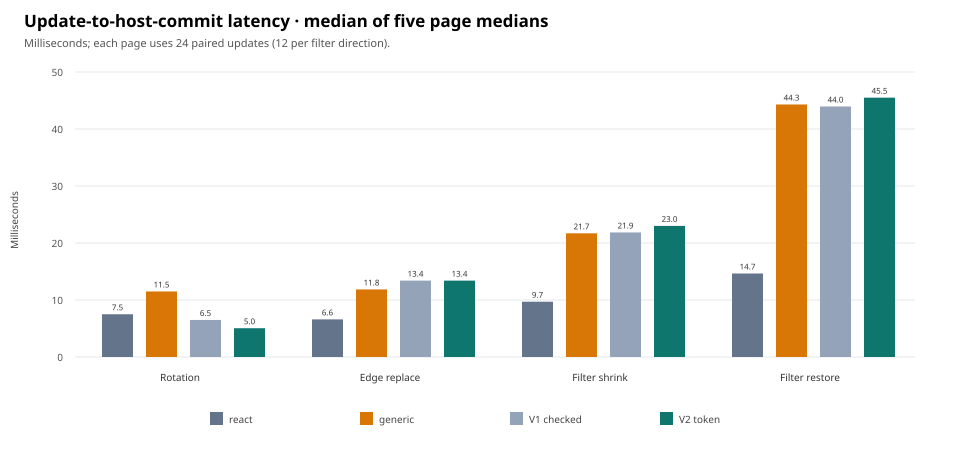

In [78]:
{
const v2Analysis = JSON.parse(await Deno.readTextFile(
  "results/component-state-owner-reuse-v2-analysis.json",
));
const v2SourceLock = JSON.parse(await Deno.readTextFile(
  "results/component-state-owner-reuse-v2-source-lock.json",
));
const v2SnapshotManifest = JSON.parse(await Deno.readTextFile(
  "results/component-state-owner-reuse-v2-source-snapshot-manifest.json",
));
const v2Hash = async (bytes: Uint8Array) => {
  const digest = await crypto.subtle.digest("SHA-256", bytes.slice().buffer as ArrayBuffer);
  return [...new Uint8Array(digest)].map((byte) =>
    byte.toString(16).padStart(2, "0")
  ).join("");
};
const v2Median = (values: number[]) => {
  const sorted = [...values].sort((a, b) => a - b);
  const center = Math.floor(sorted.length / 2);
  return sorted.length % 2
    ? sorted[center]
    : (sorted[center - 1] + sorted[center]) / 2;
};
const v2Arms = ["react", "generic", "reuse", "token"] as const;
if (
  v2Analysis.schemaVersion !== "component-state-owner-reuse-v2-analysis-v1" ||
  v2SourceLock.schemaVersion !== "component-state-owner-reuse-v2-source-lock" ||
  v2SourceLock.status !== "FROZEN_BEFORE_LATENCY_COLLECTION" ||
  v2SourceLock.entries.length !== 30 ||
  v2SnapshotManifest.schemaVersion !==
    "component-state-owner-reuse-v2-source-snapshot-manifest" ||
  v2SnapshotManifest.status !== "PASS" ||
  v2SnapshotManifest.entries.length !== 30
) throw new Error("V2 analysis/source snapshot metadata contract failed");

const v2LockBytes = await Deno.readFile(v2Analysis.sourceLock.path);
if (
  v2LockBytes.length !== v2Analysis.sourceLock.bytes ||
  await v2Hash(v2LockBytes) !== v2Analysis.sourceLock.sha256 ||
  v2SnapshotManifest.sourceLock.bytes !== v2LockBytes.length ||
  v2SnapshotManifest.sourceLock.sha256 !== v2Analysis.sourceLock.sha256
) throw new Error("V2 source-lock hash mismatch");
const v2SourceDrift = [];
for (const entry of v2SourceLock.entries as Array<{
  path: string;
  bytes: number;
  sha256: string;
}>) {
  const snapshot = v2SnapshotManifest.entries.find((item: any) =>
    item.sourcePath === entry.path
  );
  if (!snapshot) throw new Error(`V2 source snapshot missing ${entry.path}`);
  const saved = await Deno.readFile(snapshot.snapshotPath);
  if (saved.length !== entry.bytes || await v2Hash(saved) !== entry.sha256) {
    throw new Error(`V2 source snapshot hash mismatch ${entry.path}`);
  }
  let currentMatches = false;
  try {
    const current = await Deno.readFile(entry.path);
    currentMatches = current.length === entry.bytes &&
      await v2Hash(current) === entry.sha256;
  } catch {
    currentMatches = false;
  }
  v2SourceDrift.push({
    path: entry.path,
    current: currentMatches ? "matches collection" : "changed after collection",
  });
}
console.log(
  `V2 sources: ${v2SnapshotManifest.entries.length} archived files match the frozen collection lock; ${v2SourceDrift.filter((entry) => entry.current !== "matches collection").length} live files have since changed. Analysis uses the verified archive and collection records.`,
);
const v2AnalysisBytes = await Deno.readFile(
  "scripts/analyze_component_state_owner_reuse_v2.ts",
);
if (
  v2AnalysisBytes.length !== v2Analysis.analyzer.bytes ||
  await v2Hash(v2AnalysisBytes) !== v2Analysis.analyzer.sha256
) throw new Error("V2 analysis script hash mismatch");

const v2RawRecords = new Map<string, any>();
for (const input of v2Analysis.rawInputs) {
  const bytes = await Deno.readFile(input.path);
  if (bytes.length !== input.bytes || await v2Hash(bytes) !== input.sha256) {
    throw new Error(`V2 raw input hash mismatch: ${input.path}`);
  }
  v2RawRecords.set(input.path, JSON.parse(new TextDecoder().decode(bytes)));
}
const v2Seeds = [83005101, 83005102, 83005103, 83005104, 83005105];
const v2LatencyPages: any[] = [];
for (const seed of v2Seeds) {
  const record = [...v2RawRecords.values()].find((item: any) =>
    item.mode === "latency" && item.seed === seed
  );
  if (!record || record.status !== "PASS" || record.browser.visibilityState !== "visible") {
    throw new Error(`V2 latency record missing or invalid for seed ${seed}`);
  }
  for (const scenario of record.scenarios) {
    if (scenario.samples.length !== 24) {
      throw new Error(`V2 ${seed}/${scenario.operation}: sample count mismatch`);
    }
    if (scenario.samples.some((sample: any) =>
      sample.outputParity !== true ||
      v2Arms.some((arm) => sample.identity?.[arm] !== true ||
        sample.retainedState?.[arm] !== true)
    )) throw new Error(`V2 ${seed}/${scenario.operation}: correctness mismatch`);
    if (scenario.operation !== "filter-half") {
      const permutations = new Set(scenario.samples.map((sample: any) =>
        sample.order.join(",")
      ));
      if (permutations.size !== 24) {
        throw new Error(`V2 ${seed}/${scenario.operation}: arm-order balance failed`);
      }
    } else if (
      scenario.samples.filter((sample: any) => sample.direction === "shrink").length !== 12 ||
      scenario.samples.filter((sample: any) => sample.direction === "restore").length !== 12
    ) throw new Error(`V2 ${seed}/filter-half: direction balance failed`);
  }
  const rows = [];
  for (const group of [
    { id: "rotate", operation: "rotate", direction: null },
    { id: "replace-edge", operation: "replace-edge", direction: null },
    { id: "filter-shrink", operation: "filter-half", direction: "shrink" },
    { id: "filter-restore", operation: "filter-half", direction: "restore" },
  ]) {
    const scenario = record.scenarios.find((item: any) =>
      item.operation === group.operation
    );
    const samples = scenario.samples.filter((sample: any) =>
      group.direction === null || sample.direction === group.direction
    );
    rows.push({
      id: group.id,
      seed,
      n: samples.length,
      medians: Object.fromEntries(v2Arms.map((arm) => [
        arm,
        v2Median(samples.map((sample: any) => sample.milliseconds[arm])),
      ])),
      tokenOverReact: v2Median(samples.map((sample: any) =>
        sample.milliseconds.token / Math.max(sample.milliseconds.react, 0.001)
      )),
      tokenOverGeneric: v2Median(samples.map((sample: any) =>
        sample.milliseconds.token / Math.max(sample.milliseconds.generic, 0.001)
      )),
    });
  }
  v2LatencyPages.push({ seed, rows });
}
const v2Diagnostic = [...v2RawRecords.values()].find((item: any) =>
  item.mode === "diagnostic"
);
if (!v2Diagnostic || v2Diagnostic.status !== "PASS") {
  throw new Error("V2 diagnostic record missing or failed");
}
const v2DiagnosticChecks = v2Diagnostic.scenarios.map((scenario: any) => ({
  operation: scenario.operation,
  samples: scenario.samples.length,
  pass: scenario.samples.every((sample: any) => {
    const counters = sample.diagnosticCounters?.token ?? {};
    const count = (key: string) =>
      counters[`owner.keyed-region.${key}`] ?? 0;
    return scenario.operation === "rotate"
      ? count("token-hits") === 10_000 &&
        count("token-output-reuses") === 10_000 &&
        count("token-mismatches") === 0 && count("eligibility-visits") === 0 &&
        count("fallback") === 0
      : count("token-mismatches") === 1 && count("fallback") === 1 &&
        count("token-eligibility-visits") === 0 &&
        count("eligibility-visits") === 0;
  }),
}));
if (v2DiagnosticChecks.some((item: any) => !item.pass)) {
  throw new Error("V2 diagnostic mechanism contract failed");
}

const v2GroupIds = ["rotate", "replace-edge", "filter-shrink", "filter-restore"];
const v2GroupLabels = ["Rotation", "Edge replace", "Filter shrink", "Filter restore"];
const v2Summary = v2GroupIds.map((id) => {
  const values = v2LatencyPages.map((page) =>
    page.rows.find((row: any) => row.id === id)!
  );
  return {
    id,
    values,
    tokenOverReact: values.map((row: any) => row.tokenOverReact),
    tokenOverGeneric: values.map((row: any) => row.tokenOverGeneric),
    medianReact: v2Median(values.map((row: any) => row.medians.react)),
    medianGeneric: v2Median(values.map((row: any) => row.medians.generic)),
    medianReuse: v2Median(values.map((row: any) => row.medians.reuse)),
    medianToken: v2Median(values.map((row: any) => row.medians.token)),
    tokenReactPassPages: values.filter((row: any) => row.tokenOverReact <= 0.90).length,
    tokenGenericPassPages: values.filter((row: any) => row.tokenOverGeneric <= 0.50).length,
    medianTokenOverReact: v2Median(values.map((row: any) => row.tokenOverReact)),
    medianTokenOverGeneric: v2Median(values.map((row: any) => row.tokenOverGeneric)),
  };
});
const v2Rotation = v2Summary[0];
const v2FallbackPass = v2Summary.slice(1).every((row) =>
  row.medianTokenOverGeneric <= 1.10
);
const v2Gates = {
  productPrimaryPass: v2Rotation.tokenReactPassPages >= 4,
  runtimePrimaryPass: v2Rotation.tokenGenericPassPages >= 4,
  fallbackPass: v2FallbackPass,
  overallPreregisteredPass: v2Rotation.tokenReactPassPages >= 4 &&
    v2Rotation.tokenGenericPassPages >= 4 && v2FallbackPass,
};
if (
  v2Gates.productPrimaryPass !== v2Analysis.gates.productPrimaryPass ||
  v2Gates.runtimePrimaryPass !== v2Analysis.gates.runtimePrimaryPass ||
  v2Gates.fallbackPass !== v2Analysis.gates.fallbackPass ||
  v2Gates.overallPreregisteredPass !==
    v2Analysis.gates.overallPreregisteredPass
) throw new Error("V2 notebook gate summary disagrees with frozen analyzer");

console.log("V2 five-page summary: median of page medians and page-level paired ratios; no sample pooling.");
console.table(v2Summary.map((row) => ({
  operation: row.id,
  nPerPage: row.values[0].n,
  ReactMs: row.medianReact,
  genericMs: row.medianGeneric,
  V1CheckedMs: row.medianReuse,
  V2TokenMs: row.medianToken,
  tokenOverReact: row.medianTokenOverReact,
  tokenOverGeneric: row.medianTokenOverGeneric,
  ReactGatePages: `${row.tokenReactPassPages}/5`,
  genericGatePages: `${row.tokenGenericPassPages}/5`,
})));
console.log("Preregistered gates and diagnostic checks:");
console.log(JSON.stringify({ gates: v2Gates, diagnostics: v2DiagnosticChecks }, null, 2));
console.log("V2 collection inputs verified; source-lock/current-source status:");
console.table(v2SourceDrift);

const v2RatioSvg: string[] = [
  '<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="460" viewBox="0 0 960 460" role="img" aria-labelledby="v2-ratio-title v2-ratio-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">',
  '<title id="v2-ratio-title">V2 token path paired latency ratios across five pages</title>',
  '<desc id="v2-ratio-desc">Each point is a page-level median of paired update ratios for token reuse divided by generic expansion. Rotation meets both gates. Edge replacement exceeds the 1.10 fallback guardrail; filter shrink and restore remain within it.</desc>',
  '<rect width="100%" height="100%" fill="white"/>',
  '<text x="24" y="27" font-size="17" font-weight="700">Token path / generic runtime · paired page medians</text>',
  '<text x="24" y="47" font-size="11" fill="#555">Each dot is one fresh visible page; lower is faster. Rotation gate: 0.50×. Membership fallback ceiling: 1.10×.</text>',
];
const v2Plot = { left: 90, top: 70, width: 825, height: 300, min: 0.30, max: 1.32 };
const v2Y = (value: number) => v2Plot.top +
  (v2Plot.max - value) / (v2Plot.max - v2Plot.min) * v2Plot.height;
for (const tick of [0.3, 0.5, 0.7, 0.9, 1.0, 1.1, 1.2, 1.3]) {
  const y = v2Y(tick);
  const color = tick === 1.1 ? "#d97706" : tick === 1 ? "#334155" :
    tick === 0.5 ? "#0f766e" : "#e5e7eb";
  v2RatioSvg.push(
    `<line x1="${v2Plot.left}" x2="${v2Plot.left + v2Plot.width}" y1="${y}" y2="${y}" stroke="${color}" stroke-width="${tick === 1.1 || tick === 1 || tick === 0.5 ? 1.6 : 1}"${tick === 1.1 ? ' stroke-dasharray="5 4"' : ""}/><text x="${v2Plot.left - 12}" y="${y + 4}" text-anchor="end" fill="#555" font-size="10">${tick.toFixed(1)}</text>`,
  );
}
const v2Step = v2Plot.width / v2Summary.length;
for (const [groupIndex, group] of v2Summary.entries()) {
  const center = v2Plot.left + v2Step * (groupIndex + 0.5);
  v2RatioSvg.push(
    `<text x="${center}" y="${v2Plot.top + v2Plot.height + 24}" text-anchor="middle" fill="#333" font-size="11">${v2GroupLabels[groupIndex]}</text>`,
  );
  for (const [pageIndex, value] of group.tokenOverGeneric.entries()) {
    const x = center + (pageIndex - 2) * 17;
    const y = v2Y(value);
    v2RatioSvg.push(
      `<circle cx="${x}" cy="${y}" r="5.5" fill="#0f766e" stroke="white" stroke-width="1.2"><title>Seed ${v2Seeds[pageIndex]}: ${value.toFixed(3)}×</title></circle>`,
    );
  }
}
v2RatioSvg.push(
  `<text x="20" y="220" transform="rotate(-90 20 220)" text-anchor="middle" fill="#444" font-size="11">Token / generic paired update ratio</text>`,
  '<circle cx="345" cy="432" r="5" fill="#0f766e"/><text x="357" y="436" font-size="10" fill="#444">Page-level paired median</text><line x1="535" x2="560" y1="432" y2="432" stroke="#d97706" stroke-width="1.6" stroke-dasharray="5 4"/><text x="568" y="436" font-size="10" fill="#444">1.10× fallback ceiling</text>',
  '</svg>',
);
Deno.jupyter.svg`${v2RatioSvg.join("")}`;

const v2LatencySvg: string[] = [
  '<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="460" viewBox="0 0 960 460" role="img" aria-labelledby="v2-latency-title v2-latency-desc" style="max-width:100%;height:auto;display:block;font-family:system-ui,sans-serif">',
  '<title id="v2-latency-title">V2 structural update latency medians across five pages</title>',
  '<desc id="v2-latency-desc">Grouped bars show the median of five page-level update-to-host-commit medians for React, generic expansion, V1 checked reuse, and V2 token reuse for rotation, edge replacement, filter shrink, and filter restore.</desc>',
  '<rect width="100%" height="100%" fill="white"/>',
  '<text x="24" y="27" font-size="17" font-weight="700">Update-to-host-commit latency · median of five page medians</text>',
  '<text x="24" y="47" font-size="11" fill="#555">Milliseconds; each page uses 24 paired updates (12 per filter direction).</text>',
];
const v2LatencyPlot = { left: 75, top: 72, width: 840, height: 285, max: 50 };
const v2LatencyColors = { react: "#64748b", generic: "#d97706", reuse: "#94a3b8", token: "#0f766e" };
for (let tick = 0; tick <= v2LatencyPlot.max; tick += 10) {
  const y = v2LatencyPlot.top + v2LatencyPlot.height -
    tick / v2LatencyPlot.max * v2LatencyPlot.height;
  v2LatencySvg.push(
    `<line x1="${v2LatencyPlot.left}" x2="${v2LatencyPlot.left + v2LatencyPlot.width}" y1="${y}" y2="${y}" stroke="#e5e7eb"/><text x="${v2LatencyPlot.left - 12}" y="${y + 4}" text-anchor="end" font-size="10" fill="#555">${tick}</text>`,
  );
}
const v2LatencyGroupW = v2LatencyPlot.width / v2Summary.length;
for (const [groupIndex, group] of v2Summary.entries()) {
  const groupX = v2LatencyPlot.left + groupIndex * v2LatencyGroupW;
  v2LatencySvg.push(
    `<text x="${groupX + v2LatencyGroupW / 2}" y="${v2LatencyPlot.top + v2LatencyPlot.height + 24}" text-anchor="middle" font-size="10" fill="#333">${v2GroupLabels[groupIndex]}</text>`,
  );
  for (const [armIndex, arm] of v2Arms.entries()) {
    const value = group[`median${arm[0].toUpperCase()}${arm.slice(1)}` as "medianReact" | "medianGeneric" | "medianReuse" | "medianToken"];
    const barW = 31;
    const x = groupX + 27 + armIndex * 44;
    const h = value / v2LatencyPlot.max * v2LatencyPlot.height;
    const y = v2LatencyPlot.top + v2LatencyPlot.height - h;
    v2LatencySvg.push(
      `<rect x="${x}" y="${y}" width="${barW}" height="${h}" fill="${v2LatencyColors[arm]}"><title>${v2GroupLabels[groupIndex]} ${arm}: ${value.toFixed(2)} ms</title></rect><text x="${x + barW / 2}" y="${Math.max(v2LatencyPlot.top + 10, y - 4)}" text-anchor="middle" font-size="8" fill="#333">${value.toFixed(1)}</text>`,
    );
  }
}
for (const [index, arm] of v2Arms.entries()) {
  const x = 210 + index * 150;
  v2LatencySvg.push(
    `<rect x="${x}" y="412" width="13" height="13" fill="${v2LatencyColors[arm]}"/><text x="${x + 19}" y="423" font-size="10" fill="#444">${arm === "reuse" ? "V1 checked" : arm === "token" ? "V2 token" : arm}</text>`,
  );
}
v2LatencySvg.push(
  `<text x="18" y="220" transform="rotate(-90 18 220)" text-anchor="middle" font-size="10" fill="#444">Milliseconds</text>`,
  '</svg>',
);
Deno.jupyter.svg`${v2LatencySvg.join("")}`;

}



### Experiment AS diagnostic — State-owner fallback phase profile

This post-collection, exploratory Deno mechanism profile investigates the V2 edge-replacement guardrail miss. It compares generic owner expansion, V1 checked reuse, and V2 token fallback on 10,000 keyed stateful rows using the MemoryVDOMHost. Five fresh Deno processes each run eight warmups and 12 balanced paired edge replacements per arm; each process is a replication unit. The profile callbacks add overhead. These timings are not browser latency and are excluded from all React/runtime claims.

The code-level hypothesis is that token mismatch exits before the eligibility scan but then performs generic expansion and rebuilds the versioned keyed-output directory. This cell verifies hashes for all five raw process records and reads locked runtime inputs from the verified V2 source snapshot when live files have changed. It checks output parity, keyed host identity, child-state retention, and renders SVG phase medians. It can support or weaken a mechanism hypothesis; it cannot establish a causal browser bottleneck.


Exploratory MemoryVDOM fallback diagnostic (not browser latency):


┌───────┬───────────┬──────────────────────────┬──────────┬─────────────────┐
│ (idx) │ arm       │ phase                    │ medianMs │ rangeMs         │
├───────┼───────────┼──────────────────────────┼──────────┼─────────────────┤
│     0 │ "generic" │ "owner.render-and-key"   │ "0.818"  │ "0.807–0.838"   │
│     1 │ "generic" │ "owner.expand-and-cache" │ "6.377"  │ "6.311–7.012"   │
│     2 │ "generic" │ "vdom.normalize"         │ "0.502"  │ "0.471–0.640"   │
│     3 │ "generic" │ "vdom.reconcile-host"    │ "2.172"  │ "2.131–2.548"   │
│     4 │ "generic" │ "root.flush"             │ "11.895" │ "11.036–11.949" │
│     5 │ "checked" │ "owner.render-and-key"   │ "0.817"  │ "0.807–0.839"   │
│     6 │ "checked" │ "owner.expand-and-cache" │ "8.628"  │ "8.325–9.262"   │
│     7 │ "checked" │ "vdom.normalize"         │ "0.743"  │ "0.702–0.796"   │
│     8 │ "checked" │ "vdom.reconcile-host"    │ "2.600"  │ "2.501–2.689"   │
│     9 │ "checked" │ "root.flush"             │ "14.318" │ "14.

{
  "replications": 5,
  "integrity": {
    "allRecordsPass": true,
    "allOutputParity": true,
    "allHostIdentity": true,
    "allChildStateRetained": true
  },
  "phaseMediansAcrossReplicationsMs": {
    "generic": {
      "owner.render-and-key": {
        "median": 0.8175415000000044,
        "range": [
          0.8067500000000223,
          0.8376250000000027
        ]
      },
      "owner.expand-and-cache": {
        "median": 6.376917000000049,
        "range": [
          6.311478999999963,
          7.011728999999946
        ]
      },
      "vdom.normalize": {
        "median": 0.5024790000001076,
        "range": [
          0.47093799999998964,
          0.6396874999999795
        ]
      },
      "vdom.reconcile-host": {
        "median": 2.171854499999995,
        "range": [
          2.1308755000000588,
          2.547978999999998
        ]
      },
      "root.flush": {
        "median": 11.894541499999946,
        "range": [
          11.036208500000043,
          

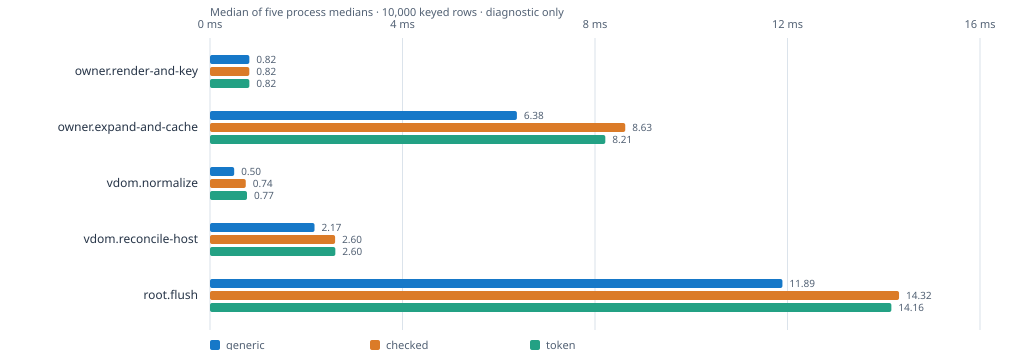

In [79]:
{
const fallbackManifest = JSON.parse(
  await Deno.readTextFile(
    "results/component-state-owner-reuse-v2/fallback-phase-diagnostic-manifest.json",
  ),
);
const fallbackV2SnapshotManifest = JSON.parse(
  await Deno.readTextFile(
    "results/component-state-owner-reuse-v2-source-snapshot-manifest.json",
  ),
);
const fallbackSources = [];
for (
  const input of fallbackManifest.inputs as Array<{
    path: string;
    sha256: string;
    bytes: number;
    kind: string;
  }>
) {
  const archived = fallbackV2SnapshotManifest.entries.find((entry: any) =>
    entry.sourcePath === input.path
  );
  const resolvedPath = archived?.snapshotPath ?? input.path;
  const bytes = await Deno.readFile(resolvedPath);
  const digest = await crypto.subtle.digest(
    "SHA-256",
    bytes.slice().buffer as ArrayBuffer,
  );
  const sha256 = [...new Uint8Array(digest)].map((byte) =>
    byte.toString(16).padStart(2, "0")
  ).join("");
  if (bytes.length !== input.bytes || sha256 !== input.sha256) {
    throw new Error(`Fallback profile hash mismatch: ${resolvedPath}`);
  }
  fallbackSources.push({
    path: input.path,
    verifiedFrom: resolvedPath,
    kind: input.kind,
    bytes: input.bytes,
  });
}

const fallbackArms = ["generic", "checked", "token"] as const;
const fallbackPhases = [
  "owner.render-and-key",
  "owner.expand-and-cache",
  "vdom.normalize",
  "vdom.reconcile-host",
  "root.flush",
] as const;
const fallbackPaths = Array.from(
  { length: 5 },
  (_, index) =>
    `results/component-state-owner-reuse-v2/fallback-phase-diagnostic-${
      index + 1
    }.json`,
);
const fallbackRecords = await Promise.all(
  fallbackPaths.map(async (path, index) => {
    const record = JSON.parse(await Deno.readTextFile(path));
    if (
      record.schemaVersion !==
        "component-state-owner-reuse-v2-fallback-phase-diagnostic-v1" ||
      record.replication !== index + 1 || record.count !== 10_000 ||
      record.measuredPairedUpdates !== 12 ||
      record.integrity?.allOutputParity !== true ||
      record.integrity?.allHostIdentity !== true ||
      record.integrity?.allChildStateRetained !== true
    ) throw new Error(`Fallback diagnostic contract failed: ${path}`);
    return record;
  }),
);
const fallbackMedian = (values: number[]) => {
  const sorted = [...values].sort((left, right) => left - right);
  const middle = Math.floor(sorted.length / 2);
  return sorted.length % 2
    ? sorted[middle]
    : (sorted[middle - 1] + sorted[middle]) / 2;
};
const fallbackRange = (values: number[]) => [
  Math.min(...values),
  Math.max(...values),
];
const fallbackSummary = Object.fromEntries(fallbackArms.map((arm) => [
  arm,
  Object.fromEntries(fallbackPhases.map((phase) => {
    const values = fallbackRecords.map((record) =>
      record.phaseSummaryMs[arm][phase]
    );
    return [phase, {
      median: fallbackMedian(values),
      range: fallbackRange(values),
    }];
  })),
]));
const fallbackDeltas = Object.fromEntries(fallbackPhases.map((phase) => {
  const values = fallbackRecords.map((record) =>
    record.phaseSummaryMs.token[phase] - record.phaseSummaryMs.generic[phase]
  );
  return [phase, {
    median: fallbackMedian(values),
    range: fallbackRange(values),
  }];
}));
const fallbackCounters = Object.fromEntries(fallbackArms.map((arm) => [
  arm,
  Object.fromEntries(
    [
      "owner.component-visits",
      "owner.cached-reused",
      "owner.created",
      "owner.keyed-region.fallback",
      "owner.keyed-region.token-mismatches",
    ].map((counter) => [
      counter,
      fallbackRecords.reduce(
        (sum, record) => sum + (record.diagnosticCounters[arm][counter] ?? 0),
        0,
      ),
    ]),
  ),
]));
const fallbackRollup = {
  replications: fallbackRecords.length,
  integrity: fallbackManifest.integrity,
  phaseMediansAcrossReplicationsMs: fallbackSummary,
  tokenMinusGenericPairedReplicationMedianMs: fallbackDeltas,
  summedMechanismCounters: fallbackCounters,
};
console.log(
  "Exploratory MemoryVDOM fallback diagnostic (not browser latency):",
);
console.table(fallbackArms.flatMap((arm) =>
  fallbackPhases.map((phase) => ({
    arm,
    phase,
    medianMs: fallbackSummary[arm][phase].median.toFixed(3),
    rangeMs: fallbackSummary[arm][phase].range.map((value) => value.toFixed(3))
      .join("–"),
  }))
));
console.log(JSON.stringify(fallbackRollup, null, 2));

const fallbackColors = {
  generic: "#1678c8",
  checked: "#db7b28",
  token: "#23a184",
};
const fallbackWidth = 1020;
const fallbackHeight = 350;
const fallbackChartLeft = 210;
const fallbackChartRight = 980;
const fallbackScale = (fallbackChartRight - fallbackChartLeft) / 16;
const fallbackBars: string[] = [];
for (let row = 0; row < fallbackPhases.length; row++) {
  const phase = fallbackPhases[row];
  const y = 55 + row * 56;
  fallbackBars.push(
    `<text x="${fallbackChartLeft - 12}" y="${
      y + 20
    }" text-anchor="end" class="phase">${phase}</text>`,
  );
  for (let column = 0; column < fallbackArms.length; column++) {
    const arm = fallbackArms[column];
    const value = fallbackSummary[arm][phase].median;
    const barY = y + column * 12;
    const width = Math.max(1, value * fallbackScale);
    fallbackBars.push(
      `<rect x="${fallbackChartLeft}" y="${barY}" width="${
        width.toFixed(2)
      }" height="9" fill="${fallbackColors[arm]}" rx="2"/><text x="${
        (fallbackChartLeft + width + 7).toFixed(2)
      }" y="${barY + 8}" class="value">${value.toFixed(2)}</text>`,
    );
  }
}
const fallbackTicks = [0, 4, 8, 12, 16].map((value) => {
  const x = fallbackChartLeft + value * fallbackScale;
  return `<line x1="${x}" y1="38" x2="${x}" y2="330" class="grid"/><text x="${x}" y="28" text-anchor="middle" class="tick">${value} ms</text>`;
});
const fallbackLegend = fallbackArms.map((arm, index) => {
  const x = fallbackChartLeft + index * 160;
  return `<rect x="${x}" y="${
    fallbackHeight - 10
  }" width="10" height="10" fill="${fallbackColors[arm]}" rx="2"/><text x="${
    x + 16
  }" y="${fallbackHeight - 1}" class="legend">${arm}</text>`;
}).join("");
const fallbackSvg =
  `<svg xmlns="http://www.w3.org/2000/svg" width="${fallbackWidth}" height="${fallbackHeight}" viewBox="0 0 ${fallbackWidth} ${fallbackHeight}" role="img" aria-labelledby="fallbackTitle fallbackDescription"><title id="fallbackTitle">Memory-host phase profile for edge replacement</title><desc id="fallbackDescription">Median diagnostic phase durations across five fresh Deno processes for generic, checked reuse, and token fallback. This chart does not show browser latency.</desc><style>text{font-family:system-ui,sans-serif;fill:#273548}.phase{font-size:12px}.value{font-size:10px;fill:#526174}.tick,.legend{font-size:11px;fill:#526174}.grid{stroke:#dbe3eb;stroke-width:1}</style><text x="${fallbackChartLeft}" y="16" class="tick">Median of five process medians · 10,000 keyed rows · diagnostic only</text>${
    fallbackTicks.join("")
  }${fallbackBars.join("")}${fallbackLegend}</svg>`;
Deno.jupyter.svg`${fallbackSvg}`;

}



### Exploratory V3 diagnostic — staged token-cache delta maintenance

This preregistered mechanism diagnostic tests whether a one-row keyed membership change can update the token cache by deltas, while preserving the fast path on the immediately following same-key rotation. It compares generic expansion, token fallback with full cache construction, and staged token-delta maintenance on 10,000 stateful rows in a `MemoryVDOMHost`. Five fresh Deno processes are the replication units; each contains 8 warmup pairs and 12 measured edge-then-rotation pairs per arm.

The cell verifies the pre-collection source lock (using a verified V2 source snapshot for the shared VDOM dependency that has since changed), the post-collection hashes for all raw records, parity, host identity, retained child state, and per-sample cache counters. SVG shows phase medians across process-level medians. These results are mechanism evidence only: they include runtime profile callbacks, omit React and browser DOM/layout/paint, and cannot change the V2 browser study's preregistered FAIL.


V3 shared dependency verified from archive: src/vdom_snapshot_runtime.ts


V3 shared dependency verified from archive: deno.json


V3 staged token-delta diagnostic — MemoryVDOMHost only


┌───────┬───────────────┬───────────────────────┬──────────┬─────────────────┐
│ (idx) │ arm           │ phase                 │ medianMs │ rangeMs         │
├───────┼───────────────┼───────────────────────┼──────────┼─────────────────┤
│     0 │ "generic"     │ "edge expand/cache"   │ "6.169"  │ "6.137–6.343"   │
│     1 │ "generic"     │ "edge root.flush"     │ "10.941" │ "10.435–11.391" │
│     2 │ "generic"     │ "rotation root.flush" │ "10.435" │ "10.095–10.809" │
│     3 │ "token"       │ "edge expand/cache"   │ "8.091"  │ "7.760–8.412"   │
│     4 │ "token"       │ "edge root.flush"     │ "13.730" │ "13.510–14.254" │
│     5 │ "token"       │ "rotation root.flush" │ "3.355"  │ "3.237–3.435"   │
│     6 │ "token-delta" │ "edge expand/cache"   │ "7.486"  │ "7.333–7.840"   │
│     7 │ "token-delta" │ "edge root.flush"     │ "13.440" │ "13.056–13.792" │
│     8 │ "token-delta" │ "rotation root.flush" │ "3.389"  │ "3.306–3.623"   │
└───────┴───────────────┴───────────────────────┴───

Preregistered mechanism hypotheses:


┌───────┬────────────┬──────┬────────────────────────┐
│ (idx) │ hypothesis │ pass │ median                 │
├───────┼────────────┼──────┼────────────────────────┤
│     0 │ "H1"       │ true │ 0.2632012321909318     │
│     1 │ "H2"       │ true │ 1.0212783738039661     │
│     2 │ "H3"       │ true │ "per-source assertion" │
└───────┴────────────┴──────┴────────────────────────┘


Paired process summaries: {
  "H1": [
    0.1427272309142104,
    0.2632012321909318,
    0.48883932131239666,
    0.25000021032954334,
    0.3583298535364918
  ],
  "H2": [
    1.0695275712247811,
    1.0212783738039661,
    0.9815914947459115,
    1.0281343066620658,
    1.0100160075493494
  ],
  "integrity": {
    "allFiveProcessesPresent": true,
    "allMeasuredSamplesPassParityIdentityAndChildState": true,
    "allTokenDeltaEdgeAndNextRotationCountersPass": true
  }
}


Source-path observation: commitKeyedRegion normalizes the candidate tree, then updateMounted delegates child work to reconcileChildren. This is consistent with the measured normalization and host-reconciliation phases; source inspection alone does not establish their causal share.


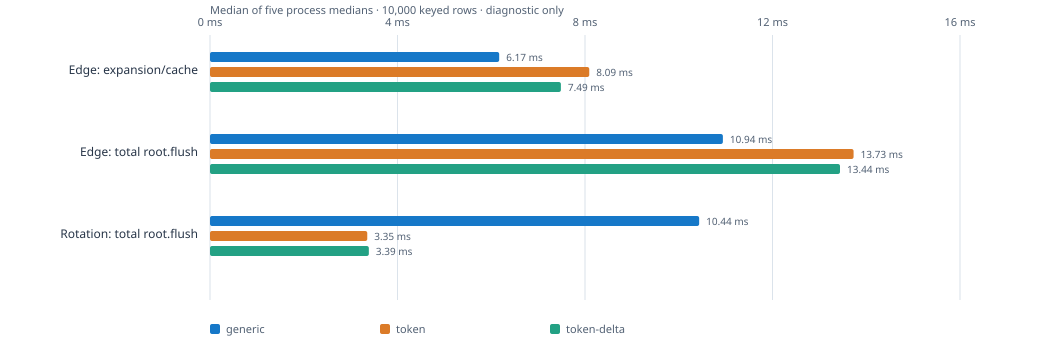

V3 token-delta phase medians across five fresh processes (ms)


┌───────┬──────────────────────────────────┬────────────┬────────────────┐
│ (idx) │ phase                            │ edgeMedian │ rotationMedian │
├───────┼──────────────────────────────────┼────────────┼────────────────┤
│     0 │ "Component render and owner key" │ "0.619"    │ "0.629"        │
│     1 │ "Owner expansion and cache"      │ "7.486"    │ "0.290"        │
│     2 │ "VDOM normalization"             │ "0.725"    │ "0.523"        │
│     3 │ "Host reconciliation"            │ "2.622"    │ "1.884"        │
└───────┴──────────────────────────────────┴────────────┴────────────────┘


V3 work per measured edge/rotation sample


┌───────┬──────────────────────────────┬─────────────────┬───────────────┐
│ (idx) │ counter                      │ perSampleMedian │ processRange  │
├───────┼──────────────────────────────┼─────────────────┼───────────────┤
│     0 │ "edgeOwnerVisitsPerSample"   │           10000 │ "10000–10000" │
│     1 │ "edgeCachedOwnersPerSample"  │            9999 │ "9999–9999"   │
│     2 │ "edgeOwnersCreatedPerSample" │               1 │ "1–1"         │
│     3 │ "edgeOwnersRetiredPerSample" │               1 │ "1–1"         │
│     4 │ "rotationTokenHitsPerSample" │           10000 │ "10000–10000" │
└───────┴──────────────────────────────┴─────────────────┴───────────────┘


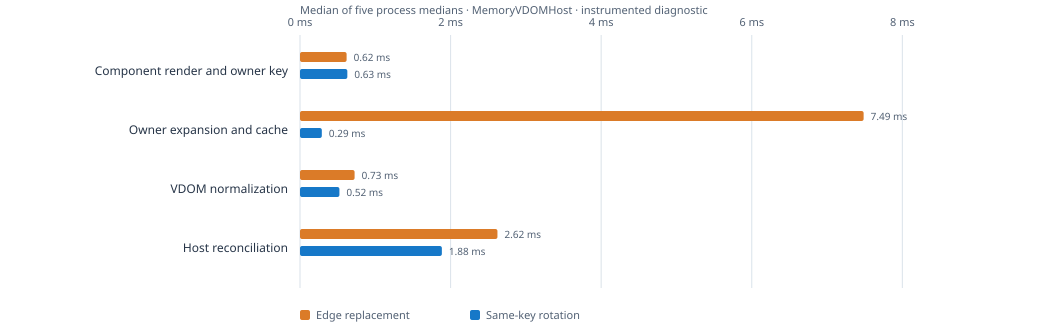

In [80]:
{
const v3Directory = "results/component-state-owner-reuse-v3";
const v3Manifest = JSON.parse(
  await Deno.readTextFile(`${v3Directory}/delta-profile-manifest.json`),
);
const v3Lock = JSON.parse(
  await Deno.readTextFile(`${v3Directory}/delta-profile-source-lock.json`),
);
const v3V2Snapshot = JSON.parse(
  await Deno.readTextFile(
    "results/component-state-owner-reuse-v2-source-snapshot-manifest.json",
  ),
);
const v3Hash = async (path: string) => {
  const bytes = await Deno.readFile(path);
  const digest = await crypto.subtle.digest(
    "SHA-256",
    bytes.slice().buffer as ArrayBuffer,
  );
  return {
    bytes: bytes.length,
    sha256: [...new Uint8Array(digest)].map((byte) =>
      byte.toString(16).padStart(2, "0")
    ).join(""),
  };
};
if (
  v3Manifest.schemaVersion !==
    "component-state-owner-reuse-v3-delta-profile-manifest-v1" ||
  v3Manifest.status !== "PASS" || v3Manifest.replications?.length !== 5
) throw new Error("V3 delta manifest metadata failed");
for (
  const input of v3Lock.entries as Array<{
    path: string;
    bytes: number;
    sha256: string;
  }>
) {
  let actualPath = input.path;
  let actual = await v3Hash(actualPath);
  if (actual.bytes !== input.bytes || actual.sha256 !== input.sha256) {
    const archived = v3V2Snapshot.entries.find((entry: any) =>
      entry.sourcePath === input.path
    );
    if (!archived) throw new Error(`V3 locked input changed: ${input.path}`);
    actualPath = archived.snapshotPath;
    actual = await v3Hash(actualPath);
    if (actual.bytes !== input.bytes || actual.sha256 !== input.sha256) {
      throw new Error(`V3 archived dependency mismatch: ${input.path}`);
    }
    console.log(`V3 shared dependency verified from archive: ${input.path}`);
  }
}
const currentLockHash = await v3Hash(
  `${v3Directory}/delta-profile-source-lock.json`,
);
if (
  currentLockHash.bytes !== v3Manifest.sourceLock.bytes ||
  currentLockHash.sha256 !== v3Manifest.sourceLock.sha256
) throw new Error("V3 source-lock hash differs from post-collection manifest");
const v3Records: any[] = [];
for (
  const entry of v3Manifest.replications as Array<{
    replication: number;
    path: string;
    bytes: number;
    sha256: string;
  }>
) {
  const actual = await v3Hash(entry.path);
  if (actual.bytes !== entry.bytes || actual.sha256 !== entry.sha256) {
    throw new Error(`V3 profile record hash mismatch: ${entry.path}`);
  }
  const record = JSON.parse(await Deno.readTextFile(entry.path));
  if (
    record.replication !== entry.replication || record.count !== 10_000 ||
    record.measuredPairs !== 12 || record.samples.length !== 12 ||
    !Object.values(record.integrity).every((passed) => passed === true)
  ) throw new Error(`V3 profile contract mismatch: ${entry.path}`);
  for (const sample of record.samples) {
    const edge = sample.stages["token-delta"].edge.counters;
    const rotate = sample.stages["token-delta"].rotate.counters;
    if (
      edge["owner.keyed-region.token-mismatches"] !== 1 ||
      edge["owner.keyed-region.fallback"] !== 1 ||
      edge["owner.keyed-region.delta-owner-deletes"] !== 1 ||
      edge["owner.keyed-region.delta-output-upserts"] !== 1 ||
      edge["owner.keyed-region.delta-owner-upserts"] !== 1 ||
      rotate["owner.keyed-region.token-hits"] !== 10_000 ||
      rotate["owner.keyed-region.token-output-reuses"] !== 10_000 ||
      (rotate["owner.keyed-region.token-mismatches"] ?? 0) !== 0 ||
      (rotate["owner.keyed-region.fallback"] ?? 0) !== 0
    ) {
      throw new Error(
        `V3 per-sample mechanism counter mismatch: ${entry.path}`,
      );
    }
  }
  v3Records.push(record);
}
const v3Median = (values: number[]) => {
  const sorted = [...values].sort((a, b) => a - b);
  const middle = Math.floor(sorted.length / 2);
  return sorted.length % 2
    ? sorted[middle]
    : (sorted[middle - 1] + sorted[middle]) / 2;
};
const v3Range = (
  values: number[],
) => [Math.min(...values), Math.max(...values)];
const v3Arms = ["generic", "token", "token-delta"] as const;
const v3Summary = Object.fromEntries(v3Arms.map((arm) => [
  arm,
  {
    edgeExpandAndCacheMs: v3Records.map((record) =>
      record.stageSummary[arm].edge.phases["owner.expand-and-cache"]
    ),
    edgeRootFlushMs: v3Records.map((record) =>
      record.stageSummary[arm].edge.totalMedianMs
    ),
    rotateRootFlushMs: v3Records.map((record) =>
      record.stageSummary[arm].rotate.totalMedianMs
    ),
  },
]));
const v3ImprovementShares = v3Records.map((record) => {
  const generic = record.stageSummary.generic.edge.phases[
    "owner.expand-and-cache"
  ];
  const token = record.stageSummary.token.edge.phases["owner.expand-and-cache"];
  const delta = record.stageSummary["token-delta"].edge.phases[
    "owner.expand-and-cache"
  ];
  return (token - delta) / (token - generic);
});
const v3RotateRatios = v3Records.map((record) =>
  record.stageSummary["token-delta"].rotate.totalMedianMs /
  record.stageSummary.token.rotate.totalMedianMs
);
const v3H1Median = v3Median(v3ImprovementShares);
const v3H2Median = v3Median(v3RotateRatios);
const v3H3 = v3Manifest.integrity
  .allMeasuredSamplesPassParityIdentityAndChildState &&
  v3Manifest.integrity.allTokenDeltaEdgeAndNextRotationCountersPass;
const v3RuntimeSource = await Deno.readTextFile(
  "src/component_state_runtime_owner_reuse_v3.ts",
);
if (!v3RuntimeSource.includes("delta.base.outputsByKey.delete(key)")) {
  throw new Error(
    "Locked V3 runtime no longer contains the keyed output delete",
  );
}
const v3VDOMSource = await Deno.readTextFile("src/vdom_snapshot_runtime.ts");
const v3KeyedCommitStart = v3VDOMSource.indexOf(
  "commitKeyedRegion(key: string, tree: RuntimeNode): boolean",
);
const v3KeyedCommitEnd = v3VDOMSource.indexOf(
  "commitKeyedRegions(",
  v3KeyedCommitStart,
);
const v3KeyedCommitSource = v3VDOMSource.slice(
  v3KeyedCommitStart,
  v3KeyedCommitEnd,
);
const v3MountedUpdateStart = v3VDOMSource.indexOf(
  "const updateMounted = <H, P>(",
);
const v3MountedUpdateEnd = v3VDOMSource.indexOf(
  "const reconcileChildren = <H, P>(",
  v3MountedUpdateStart,
);
const v3MountedUpdateSource = v3VDOMSource.slice(
  v3MountedUpdateStart,
  v3MountedUpdateEnd,
);
if (
  v3KeyedCommitStart < 0 || v3KeyedCommitEnd < 0 ||
  !v3KeyedCommitSource.includes("normalizeMany(tree)") ||
  !v3KeyedCommitSource.includes("updateMounted(this.host") ||
  v3MountedUpdateStart < 0 || v3MountedUpdateEnd < 0 ||
  !v3MountedUpdateSource.includes("reconcileChildren(")
) {
  throw new Error(
    "V3 source-path assertion failed: keyed commit no longer normalizes and reconciles its candidate subtree",
  );
}
const v3HypothesisResults = {
  H1: {
    pass: v3H1Median >= 0.25,
    threshold: 0.25,
    pairedImprovementShareByProcess: v3ImprovementShares,
    median: v3H1Median,
  },
  H2: {
    pass: v3H2Median <= 1.1,
    maximumMedianRatio: 1.1,
    pairedRotateRootFlushRatioByProcess: v3RotateRatios,
    median: v3H2Median,
  },
  H3: {
    pass: v3H3,
    interpretation:
      "Each edge sample records one owner removal plus one output and owner upsert; the locked runtime deletes the matching output key, and the next rotation records 10,000 token hits/output reuses.",
  },
};
const v3PhaseTable = v3Arms.flatMap((arm) =>
  ([
    ["edge expand/cache", "edgeExpandAndCacheMs"],
    ["edge root.flush", "edgeRootFlushMs"],
    ["rotation root.flush", "rotateRootFlushMs"],
  ] as const).map(([phase, field]) => {
    const values = v3Summary[arm][field];
    return {
      arm,
      phase,
      medianMs: v3Median(values).toFixed(3),
      rangeMs: v3Range(values).map((value) => value.toFixed(3)).join("–"),
    };
  })
);
console.log("V3 staged token-delta diagnostic — MemoryVDOMHost only");
console.table(v3PhaseTable);
console.log("Preregistered mechanism hypotheses:");
console.table(
  Object.entries(v3HypothesisResults).map(([hypothesis, result]) => ({
    hypothesis,
    pass: result.pass,
    median: "median" in result ? result.median : "per-source assertion",
  })),
);
console.log(
  "Paired process summaries:",
  JSON.stringify(
    {
      H1: v3ImprovementShares,
      H2: v3RotateRatios,
      integrity: v3Manifest.integrity,
    },
    null,
    2,
  ),
);
console.log(
  "Source-path observation: commitKeyedRegion normalizes the candidate tree, then updateMounted delegates child work to reconcileChildren. This is consistent with the measured normalization and host-reconciliation phases; source inspection alone does not establish their causal share.",
);

const v3Width = 1040;
const v3Height = 350;
const v3Left = 210;
const v3Right = 960;
const v3Scale = (v3Right - v3Left) / 16;
const v3Colors = {
  generic: "#1678c8",
  token: "#db7b28",
  "token-delta": "#23a184",
};
const v3Phases = [
  ["Edge: expansion/cache", "edgeExpandAndCacheMs"],
  ["Edge: total root.flush", "edgeRootFlushMs"],
  ["Rotation: total root.flush", "rotateRootFlushMs"],
] as const;
const v3Bars: string[] = [];
for (let row = 0; row < v3Phases.length; row++) {
  const [label, field] = v3Phases[row];
  const y = 52 + row * 82;
  v3Bars.push(
    `<text x="${v3Left - 12}" y="${
      y + 22
    }" text-anchor="end" class="phase">${label}</text>`,
  );
  for (let column = 0; column < v3Arms.length; column++) {
    const arm = v3Arms[column];
    const value = v3Median(v3Summary[arm][field]);
    const width = Math.max(1, value * v3Scale);
    const barY = y + column * 15;
    v3Bars.push(
      `<rect x="${v3Left}" y="${barY}" width="${
        width.toFixed(2)
      }" height="10" fill="${v3Colors[arm]}" rx="2"/><text x="${
        (v3Left + width + 7).toFixed(2)
      }" y="${barY + 9}" class="value">${value.toFixed(2)} ms</text>`,
    );
  }
}
const v3Ticks = [0, 4, 8, 12, 16].map((value) => {
  const x = v3Left + value * v3Scale;
  return `<line x1="${x}" y1="35" x2="${x}" y2="300" class="grid"/><text x="${x}" y="26" text-anchor="middle" class="tick">${value} ms</text>`;
});
const v3Legend = v3Arms.map((arm, index) => {
  const x = v3Left + index * 170;
  return `<rect x="${x}" y="324" width="10" height="10" fill="${
    v3Colors[arm]
  }" rx="2"/><text x="${x + 16}" y="333" class="legend">${arm}</text>`;
}).join("");
const v3Svg =
  `<svg xmlns="http://www.w3.org/2000/svg" width="${v3Width}" height="${v3Height}" viewBox="0 0 ${v3Width} ${v3Height}" role="img" aria-labelledby="v3Title v3Desc"><title id="v3Title">V3 staged delta-cache mechanism profile</title><desc id="v3Desc">Median phase timings across five fresh Deno processes on a MemoryVDOMHost; diagnostic only, not browser or React latency.</desc><style>text{font-family:system-ui,sans-serif;fill:#273548}.phase{font-size:12px}.value{font-size:10px;fill:#526174}.tick,.legend{font-size:11px;fill:#526174}.grid{stroke:#dbe3eb;stroke-width:1}</style><text x="${v3Left}" y="14" class="tick">Median of five process medians · 10,000 keyed rows · diagnostic only</text>${
    v3Ticks.join("")
  }${v3Bars.join("")}${v3Legend}</svg>`;
// @ts-ignore Deno Jupyter adds the `jupyter.svg` template tag at notebook runtime.
await Deno.jupyter.display(Deno.jupyter.svg`${v3Svg}`);

const v3PhaseFields = [
  ["Component render and owner key", "owner.render-and-key"],
  ["Owner expansion and cache", "owner.expand-and-cache"],
  ["VDOM normalization", "vdom.normalize"],
  ["Host reconciliation", "vdom.reconcile-host"],
] as const;
const v3EdgePhaseMedians = Object.fromEntries(v3PhaseFields.map(([label, key]) => [
  label,
  v3Median(v3Records.map((record) =>
    record.stageSummary["token-delta"].edge.phases[key]
  )),
]));
const v3RotatePhaseMedians = Object.fromEntries(v3PhaseFields.map(([label, key]) => [
  label,
  v3Median(v3Records.map((record) =>
    record.stageSummary["token-delta"].rotate.phases[key]
  )),
]));
const v3WorkCounters = {
  edgeOwnerVisitsPerSample: v3Records.map((record) =>
    record.counterSummary["token-delta"].edge[
      "owner.component-visits"
    ] / record.measuredPairs
  ),
  edgeCachedOwnersPerSample: v3Records.map((record) =>
    record.counterSummary["token-delta"].edge[
      "owner.cached-reused"
    ] / record.measuredPairs
  ),
  edgeOwnersCreatedPerSample: v3Records.map((record) =>
    record.counterSummary["token-delta"].edge["owner.created"] /
      record.measuredPairs
  ),
  edgeOwnersRetiredPerSample: v3Records.map((record) =>
    record.counterSummary["token-delta"].edge["owner.retired"] /
      record.measuredPairs
  ),
  rotationTokenHitsPerSample: v3Records.map((record) =>
    record.counterSummary["token-delta"].rotate[
      "owner.keyed-region.token-hits"
    ] / record.measuredPairs
  ),
};
if (
  v3WorkCounters.edgeOwnerVisitsPerSample.some((value) => value !== 10_000) ||
  v3WorkCounters.edgeCachedOwnersPerSample.some((value) => value !== 9_999) ||
  v3WorkCounters.edgeOwnersCreatedPerSample.some((value) => value !== 1) ||
  v3WorkCounters.edgeOwnersRetiredPerSample.some((value) => value !== 1) ||
  v3WorkCounters.rotationTokenHitsPerSample.some((value) => value !== 10_000)
) throw new Error("V3 structural work-counter summary changed");
console.log("V3 token-delta phase medians across five fresh processes (ms)");
console.table(v3PhaseFields.map(([phase]) => ({
  phase,
  edgeMedian: v3EdgePhaseMedians[phase].toFixed(3),
  rotationMedian: v3RotatePhaseMedians[phase].toFixed(3),
})));
console.log("V3 work per measured edge/rotation sample");
console.table(Object.entries(v3WorkCounters).map(([counter, values]) => ({
  counter,
  perSampleMedian: v3Median(values),
  processRange: `${Math.min(...values)}–${Math.max(...values)}`,
})));

const v3PhaseWidth = 1040;
const v3PhaseHeight = 330;
const v3PhaseLeft = 300;
const v3PhaseRight = 940;
const v3PhaseScale = (v3PhaseRight - v3PhaseLeft) / 8.5;
const v3PhaseColors = { edge: "#db7b28", rotation: "#1678c8" };
const v3PhaseBars: string[] = [];
for (let row = 0; row < v3PhaseFields.length; row++) {
  const [label] = v3PhaseFields[row];
  const y = 52 + row * 59;
  v3PhaseBars.push(
    `<text x="${v3PhaseLeft - 12}" y="${y + 23}" text-anchor="end" class="phase">${label}</text>`,
  );
  for (const [stage, summary, offset] of [
    ["edge", v3EdgePhaseMedians, 0],
    ["rotation", v3RotatePhaseMedians, 17],
  ] as const) {
    const value = summary[label];
    const width = Math.max(1, value * v3PhaseScale);
    const barY = y + offset;
    v3PhaseBars.push(
      `<rect x="${v3PhaseLeft}" y="${barY}" width="${width.toFixed(2)}" height="10" fill="${v3PhaseColors[stage]}" rx="2"/><text x="${(v3PhaseLeft + width + 7).toFixed(2)}" y="${barY + 9}" class="value">${value.toFixed(2)} ms</text>`,
    );
  }
}
const v3PhaseTicks = [0, 2, 4, 6, 8].map((value) => {
  const x = v3PhaseLeft + value * v3PhaseScale;
  return `<line x1="${x}" y1="35" x2="${x}" y2="288" class="grid"/><text x="${x}" y="26" text-anchor="middle" class="tick">${value} ms</text>`;
});
const v3PhaseLegend = `<rect x="${v3PhaseLeft}" y="310" width="10" height="10" fill="${v3PhaseColors.edge}" rx="2"/><text x="${v3PhaseLeft + 16}" y="319" class="legend">Edge replacement</text><rect x="${v3PhaseLeft + 170}" y="310" width="10" height="10" fill="${v3PhaseColors.rotation}" rx="2"/><text x="${v3PhaseLeft + 186}" y="319" class="legend">Same-key rotation</text>`;
const v3PhaseSvg =
  `<svg xmlns="http://www.w3.org/2000/svg" width="${v3PhaseWidth}" height="${v3PhaseHeight}" viewBox="0 0 ${v3PhaseWidth} ${v3PhaseHeight}" role="img" aria-labelledby="v3PhaseTitle v3PhaseDesc"><title id="v3PhaseTitle">V3 token-delta phase profile</title><desc id="v3PhaseDesc">Diagnostic phase medians across five fresh Deno processes, comparing a one-key edge replacement with same-key rotation on a MemoryVDOMHost. Instrumented phases are not additive and include no React timing.</desc><style>text{font-family:system-ui,sans-serif;fill:#273548}.phase{font-size:12px}.value{font-size:10px;fill:#526174}.tick,.legend{font-size:11px;fill:#526174}.grid{stroke:#dbe3eb;stroke-width:1}</style><text x="${v3PhaseLeft}" y="14" class="tick">Median of five process medians · MemoryVDOMHost · instrumented diagnostic</text>${v3PhaseTicks.join("")}${v3PhaseBars.join("")}${v3PhaseLegend}</svg>`;
// @ts-ignore Deno Jupyter adds the `jupyter.svg` template tag at notebook runtime.
await Deno.jupyter.display(Deno.jupyter.svg`${v3PhaseSvg}`);

}



### V3 production browser follow-up — token-delta fallback versus React Compiler

This five-page, visible production-browser follow-up tests whether the Deno MemoryVDOMHost delta-cache result survives real DOM commits against a React 19.3 baseline whose React Compiler lowering is explicitly verified in the build. Each fresh page measures 10,000 keyed stateful rows, with eight warmup pairs and 24 measured pairs. A pair replaces the final non-sentinel key and then rotates the same membership; the selected `row-0` remains present through every operation.

The row-0 sentinel correction is recorded in a pre-collection amendment: the first smoke exposed that repeated full-list rotations move the sentinel to the tail, so replacing the literal final key would remove it on the next pair. No production data were collected under that invalid fixture. The cell verifies all 19 source inputs and four built assets, including React Compiler memo-cache evidence, and checks hashes and integrity for each page record. SVG charts show the median of page-level medians; the five pages, not 120 nested samples, are the replication units.

The preregistered overall result is **FAIL**: edge fallback meets its 1.10× generic limit on 4/5 pages, and same-key rotation beats generic by the 0.50× limit on 5/5, but token-delta does not beat React Compiler by the 0.90× product threshold on any page. All pages pass output parity, host identity, and retained child-state checks. Timing ends at host commit and does not measure layout, paint, or frame presentation.


V3 production browser study · n=5 fresh visible pages


┌───────┬─────────────────────┬────────────────────┬────────────────────┬─────────┬────────────────────┬───────────────────┬────────────────────┐
│ (idx) │ operation           │ reactCompilerMs    │ genericMs          │ tokenMs │ tokenDeltaMs       │ deltaOverGeneric  │ deltaOverReact     │
├───────┼─────────────────────┼────────────────────┼────────────────────┼─────────┼────────────────────┼───────────────────┼────────────────────┤
│     0 │ "Edge replacement"  │ 3.5                │ 11                 │ 12.5    │ 12.049999997019768 │ 1.077183021387171 │ 3.3292041965802914 │
│     1 │ "Same-key rotation" │ 3.5999999940395355 │ 10.799999997019768 │ 4.75    │ 4.700000002980232  │ 0.44187456748201  │ 1.3428571394511633 │
└───────┴─────────────────────┴────────────────────┴────────────────────┴─────────┴────────────────────┴───────────────────┴────────────────────┘


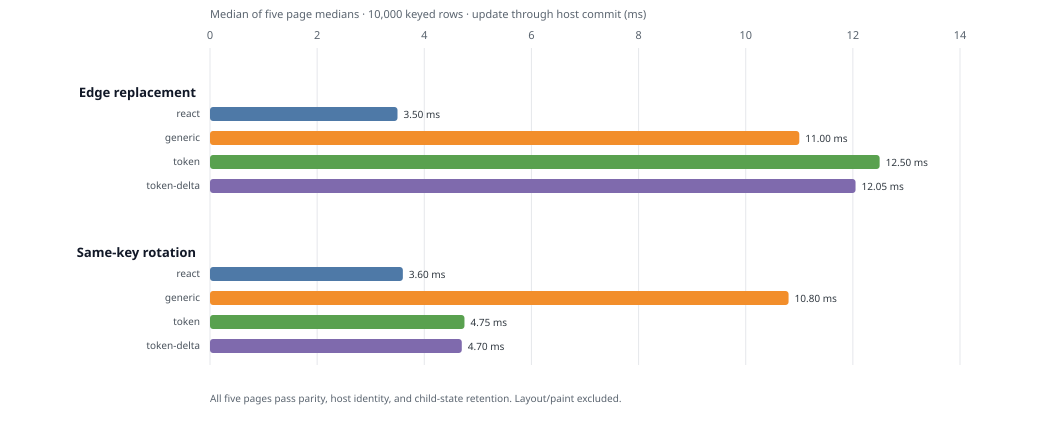

Preregistered gates: edge 4/5 (need 4), rotation vs generic 5/5 (need 4), rotation vs React Compiler 0/5 (need 4). Overall: FAIL.


The page is the replication unit; 24 paired samples are nested within each page. Timing ends at host commit and excludes layout, paint, and presentation.


In [81]:
{
const ownerV3BrowserDirectory = "results/component-state-owner-reuse-v3";
const ownerV3BrowserManifest = JSON.parse(
  await Deno.readTextFile(
    `${ownerV3BrowserDirectory}/browser-manifest.json`,
  ),
);
const ownerV3BrowserLock = JSON.parse(
  await Deno.readTextFile(
    `${ownerV3BrowserDirectory}/browser-source-lock.json`,
  ),
);
const ownerV3BrowserV2Snapshot = JSON.parse(
  await Deno.readTextFile(
    "results/component-state-owner-reuse-v2-source-snapshot-manifest.json",
  ),
);
const ownerV3BrowserHash = async (path: string) => {
  const bytes = await Deno.readFile(path);
  const digest = await crypto.subtle.digest(
    "SHA-256",
    bytes.slice().buffer as ArrayBuffer,
  );
  return {
    bytes: bytes.length,
    sha256: [...new Uint8Array(digest)].map((byte) =>
      byte.toString(16).padStart(2, "0")
    ).join(""),
  };
};
const ownerV3BrowserAssert = (condition: unknown, message: string) => {
  if (!condition) throw new Error(message);
};
ownerV3BrowserAssert(
  ownerV3BrowserManifest.schemaVersion ===
      "component-state-owner-reuse-v3-browser-manifest-v1" &&
    ownerV3BrowserManifest.status === "PASS" &&
    ownerV3BrowserManifest.decision === "FAIL" &&
    ownerV3BrowserManifest.replications.length === 5,
  "V3 browser manifest contract failed",
);
for (
  const entry of [
    ...ownerV3BrowserLock.sourceEntries,
    ...ownerV3BrowserLock.buildAssets,
  ]
) {
  let actualPath = entry.path;
  let actual = await ownerV3BrowserHash(actualPath);
  if (actual.bytes !== entry.bytes || actual.sha256 !== entry.sha256) {
    const archived = ownerV3BrowserV2Snapshot.entries.find((item: any) =>
      item.sourcePath === entry.path
    );
    if (!archived) throw new Error(`V3 frozen browser input changed: ${entry.path}`);
    actualPath = archived.snapshotPath;
    actual = await ownerV3BrowserHash(actualPath);
  }
  ownerV3BrowserAssert(
    actual.bytes === entry.bytes && actual.sha256 === entry.sha256,
    `V3 frozen browser input changed: ${actualPath}`,
  );
}
const lockHash = await ownerV3BrowserHash(
  `${ownerV3BrowserDirectory}/browser-source-lock.json`,
);
ownerV3BrowserAssert(
  lockHash.bytes === ownerV3BrowserManifest.sourceLock.bytes &&
    lockHash.sha256 === ownerV3BrowserManifest.sourceLock.sha256,
  "V3 browser source-lock hash differs from manifest",
);
const analyzerHash = await ownerV3BrowserHash(
  "scripts/create_component_state_owner_reuse_v3_browser_manifest.ts",
);
ownerV3BrowserAssert(
  analyzerHash.bytes === ownerV3BrowserManifest.analysisScript.bytes &&
    analyzerHash.sha256 === ownerV3BrowserManifest.analysisScript.sha256,
  "V3 browser manifest analyzer hash differs",
);
const ownerV3BrowserArms = [
  "react",
  "generic",
  "token",
  "token-delta",
] as const;
const ownerV3BrowserRecords: any[] = [];
for (const entry of ownerV3BrowserManifest.replications) {
  const rawHash = await ownerV3BrowserHash(entry.path);
  ownerV3BrowserAssert(
    rawHash.bytes === entry.bytes && rawHash.sha256 === entry.sha256,
    `V3 raw browser record hash differs: ${entry.path}`,
  );
  const record = JSON.parse(await Deno.readTextFile(entry.path));
  ownerV3BrowserAssert(
    record.status === "PASS" &&
      record.seed === 83_005_300 + entry.replication &&
      record.count === 10_000 && record.warmupPairs === 8 &&
      record.measuredPairs === 24 && record.samples.length === 24 &&
      record.browser.visibilityState === "visible" &&
      record.browser.buildMode === "production",
    `V3 browser record contract failed: ${entry.path}`,
  );
  ownerV3BrowserAssert(
    Object.values(record.integrity).every((value) => value === true),
    `V3 browser integrity gate failed: ${entry.path}`,
  );
  ownerV3BrowserRecords.push(record);
}
const ownerV3BrowserMedian = (values: number[]) => {
  const sorted = [...values].sort((left, right) => left - right);
  const middle = Math.floor(sorted.length / 2);
  return sorted.length % 2
    ? sorted[middle]
    : (sorted[middle - 1] + sorted[middle]) / 2;
};
const ownerV3BrowserStages = ["edge", "rotate"] as const;
const ownerV3BrowserSummary = Object.fromEntries(
  ownerV3BrowserStages.map((stage) => [
    stage,
    {
      times: Object.fromEntries(ownerV3BrowserArms.map((arm) => [
        arm,
        ownerV3BrowserMedian(
          ownerV3BrowserRecords.map((record) =>
            record.stages[stage].medianMs[arm]
          ),
        ),
      ])),
      ratios: Object.fromEntries(
        [
          "tokenOverGeneric",
          "deltaOverGeneric",
          "deltaOverReact",
          "deltaOverToken",
        ]
          .map((key) => [
            key,
            ownerV3BrowserMedian(
              ownerV3BrowserRecords.map((record) =>
                record.stages[stage].pairedRatioMedian[key]
              ),
            ),
          ]),
      ),
    },
  ]),
);
const ownerV3BrowserEdgePasses =
  ownerV3BrowserRecords.filter((record) =>
    record.stages.edge.pairedRatioMedian.deltaOverGeneric <= 1.10
  ).length;
const ownerV3BrowserRotationRuntimePasses = ownerV3BrowserRecords.filter(
  (record) => record.stages.rotate.pairedRatioMedian.deltaOverGeneric <= 0.50,
).length;
const ownerV3BrowserRotationReactPasses = ownerV3BrowserRecords.filter(
  (record) => record.stages.rotate.pairedRatioMedian.deltaOverReact <= 0.90,
).length;
ownerV3BrowserAssert(
  ownerV3BrowserEdgePasses === 4 &&
    ownerV3BrowserRotationRuntimePasses === 5 &&
    ownerV3BrowserRotationReactPasses === 0,
  "V3 browser preregistered decision counts changed",
);
for (const stage of ownerV3BrowserStages) {
  for (const arm of ownerV3BrowserArms) {
    const manifestValue = ownerV3BrowserManifest.summary[stage].pageLevelTimes[
      arm
    ].medianOfPageMedians;
    ownerV3BrowserAssert(
      Math.abs(ownerV3BrowserSummary[stage].times[arm] - manifestValue) <
        1e-9,
      `V3 browser summary mismatch: ${stage}/${arm}`,
    );
  }
}
console.log("V3 production browser study · n=5 fresh visible pages");
console.table(ownerV3BrowserStages.map((stage) => ({
  operation: stage === "edge" ? "Edge replacement" : "Same-key rotation",
  reactCompilerMs: ownerV3BrowserSummary[stage].times.react,
  genericMs: ownerV3BrowserSummary[stage].times.generic,
  tokenMs: ownerV3BrowserSummary[stage].times.token,
  tokenDeltaMs: ownerV3BrowserSummary[stage].times["token-delta"],
  deltaOverGeneric: ownerV3BrowserSummary[stage].ratios.deltaOverGeneric,
  deltaOverReact: ownerV3BrowserSummary[stage].ratios.deltaOverReact,
})));
console.log(
  `Preregistered gates: edge ${ownerV3BrowserEdgePasses}/5 (need 4), rotation vs generic ${ownerV3BrowserRotationRuntimePasses}/5 (need 4), rotation vs React Compiler ${ownerV3BrowserRotationReactPasses}/5 (need 4). Overall: FAIL.`,
);
console.log(
  "The page is the replication unit; 24 paired samples are nested within each page. Timing ends at host commit and excludes layout, paint, and presentation.",
);

const ownerV3ChartWidth = 1040;
const ownerV3ChartHeight = 430;
const ownerV3ChartLeft = 210;
const ownerV3ChartRight = 960;
const ownerV3ChartScale = (ownerV3ChartRight - ownerV3ChartLeft) / 14;
const ownerV3ChartColors = {
  react: "#4e79a7",
  generic: "#f28e2b",
  token: "#59a14f",
  "token-delta": "#7f6aad",
};
const ownerV3ChartBars: string[] = [];
const ownerV3ChartTicks = [0, 2, 4, 6, 8, 10, 12, 14].map((value) => {
  const x = ownerV3ChartLeft + value * ownerV3ChartScale;
  return `<line x1="${x}" y1="48" x2="${x}" y2="365" stroke="#e5e7eb"/><text x="${x}" y="39" text-anchor="middle" fill="#59636e" font-size="11">${value}</text>`;
});
for (
  let stageIndex = 0;
  stageIndex < ownerV3BrowserStages.length;
  stageIndex++
) {
  const stage = ownerV3BrowserStages[stageIndex];
  const groupY = 85 + stageIndex * 160;
  ownerV3ChartBars.push(
    `<text x="${ownerV3ChartLeft - 14}" y="${
      groupY + 12
    }" text-anchor="end" fill="#111827" font-size="13" font-weight="650">${
      stage === "edge" ? "Edge replacement" : "Same-key rotation"
    }</text>`,
  );
  for (let armIndex = 0; armIndex < ownerV3BrowserArms.length; armIndex++) {
    const arm = ownerV3BrowserArms[armIndex];
    const value = ownerV3BrowserSummary[stage].times[arm];
    const y = groupY + 22 + armIndex * 24;
    const width = value * ownerV3ChartScale;
    ownerV3ChartBars.push(
      `<text x="${ownerV3ChartLeft - 10}" y="${
        y + 10
      }" text-anchor="end" fill="#48515b" font-size="10">${arm}</text><rect x="${ownerV3ChartLeft}" y="${y}" width="${
        width.toFixed(2)
      }" height="14" rx="3" fill="${ownerV3ChartColors[arm]}"/><text x="${
        (ownerV3ChartLeft + width + 6).toFixed(2)
      }" y="${y + 11}" fill="#303840" font-size="10">${
        value.toFixed(2)
      } ms</text>`,
    );
  }
}
const ownerV3BrowserSvg =
  `<svg xmlns="http://www.w3.org/2000/svg" width="${ownerV3ChartWidth}" height="${ownerV3ChartHeight}" viewBox="0 0 ${ownerV3ChartWidth} ${ownerV3ChartHeight}" role="img" aria-labelledby="ownerV3Title ownerV3Desc" style="max-width:100%;height:auto;font-family:system-ui,sans-serif"><title id="ownerV3Title">V3 keyed-owner production browser comparison</title><desc id="ownerV3Desc">Median of five page-level medians for 10,000 keyed rows. React Compiler is faster on both operations. Token-delta is faster than generic on same-key rotation.</desc><rect width="100%" height="100%" fill="white"/><text x="${ownerV3ChartLeft}" y="18" fill="#59636e" font-size="11">Median of five page medians · 10,000 keyed rows · update through host commit (ms)</text>${
    ownerV3ChartTicks.join("")
  }${
    ownerV3ChartBars.join("")
  }<text x="${ownerV3ChartLeft}" y="402" fill="#59636e" font-size="10">All five pages pass parity, host identity, and child-state retention. Layout/paint excluded.</text></svg>`;
// @ts-ignore Deno Jupyter adds the `jupyter.svg` template tag at notebook runtime.
await Deno.jupyter.display(Deno.jupyter.svg`${ownerV3BrowserSvg}`);

}



### Lifecycle-inclusive browser study: Snake frame updates V1

The V6 per-frame experiment showed a repeated-update advantage but estimated mount amortization post hoc and did not measure teardown. This follow-up preregistered the lifecycle before collection: five randomized page blocks for each of 512 and 1,024 fixed segments, with React 19.3 + verified React Compiler, scalar-source retained VDOM, and OXC-plan columnar retained VDOM. Each fresh visible production page mounted the scene, ran 90 warmup RAF callbacks, measured 300 update callbacks, verified final coordinates and stable host identity, then unmounted/disposed and checked for retained subscriptions, bindings, or host nodes. The primary metric is mount + summed update JavaScript CPU + teardown; it excludes navigation, parse/compile, paint, GPU, and display wait.

All 30 scheduled records passed correctness; the source lock recorded 93 frozen source/build hashes and was verified before the original collection. A pre-collection amendment set final CSS position tolerance to 0.01 px after an excluded smoke run exposed Chrome's three-decimal serialization of inline fractional values. Smoke records are stored separately and do not enter the analysis. The raw manifest pins all 30 production records by SHA-256. A later cadence study changed the live Vite config and replaced the shared production build, and V1 did not archive a separate source snapshot. The notebook reports that drift and validates the immutable raw records, manifest, and schedule rather than claiming the old build is still present.

The preregistered product gate **passes** on this device: columnar VDOM's paired total-cycle ratio to React was 0.508× at 512 segments and 0.513× at 1,024, with all five pairs at each size below the 0.90 threshold. Its median per-update CPU was also lower in all five pairs at both sizes. Median cycle costs (React / scalar VDOM / columnar VDOM) were 219.1 / 123.3 / 102.5 ms at 512 and 333.4 / 206.2 / 171.9 ms at 1,024, for 300 updates plus mount/teardown. Columnar mounting remained slower than React (4.3 vs 2.6 ms at 512; 6.4 vs 3.7 ms at 1,024), but this cost did not erase the repeated-update savings in the preregistered 300-frame episode.

As an exploratory cadence check, each raw page also recorded full run wall time. Dividing that by 391 scheduled callback slots gives an approximate average of 16.78–16.86 ms per slot at 512 segments and 17.24–17.25 ms at 1,024 across the three arms. This average does not retain individual RAF intervals and is not a display-presentation measurement. It suggests that lower update CPU did not materially accelerate this animation loop; this study cannot establish a visible smoothness difference.

The performance.memory.usedJSHeapSize readings are an exploratory diagnostic, not an allocation or retention result. All 30 pages reported values, but 22/30 reported an exactly zero after-mount delta; 15/30 reported a lower heap after teardown than before mount, with signed teardown changes spanning about −17.5 to +17.5 MiB. Garbage collection and unrelated page heap dominate this signal. The SVG and page-level summary below expose the observations without treating them as bytes allocated. A future memory study needs a controlled heap-snapshot or allocation-instrumentation protocol with repeated lifecycle cycles and explicit GC handling.

This supports a narrow mechanism claim: retained prop bindings, especially the columnar compiled writer, reduce measured JavaScript cycle cost for a stable, fixed-topology per-frame workload against this React + Compiler baseline. It does not show smoother presentation, a general React speedup, dynamic-topology performance, a second-device replication, or lower maintenance cost. The next evidence gate is independent-device replication and a separate dynamic-structure/lifecycle workload; do not generalize this result beyond these tested arms, sizes, and device profile.


Lifecycle V1 source lock records 93 pre-collection hashes; 4 live paths have changed or are unavailable after the later cadence build. The V1 production source bundle was not archived as a separate snapshot, so this cell verifies the frozen manifest and raw-page hashes rather than claiming a current-tree source match.


Lifecycle v1 — medians across five paired production pages; milliseconds


┌───────┬──────────┬────────────┬──────────────┬───────────────┬────────────────────┐
│ (idx) │ segments │ reactCycle │ runtimeCycle │ columnarCycle │ columnarReactRatio │
├───────┼──────────┼────────────┼──────────────┼───────────────┼────────────────────┤
│     0 │      512 │ "219.1"    │ "123.3"      │ "102.5"       │ "0.508"            │
│     1 │     1024 │ "333.4"    │ "206.2"      │ "171.9"       │ "0.513"            │
└───────┴──────────┴────────────┴──────────────┴───────────────┴────────────────────┘


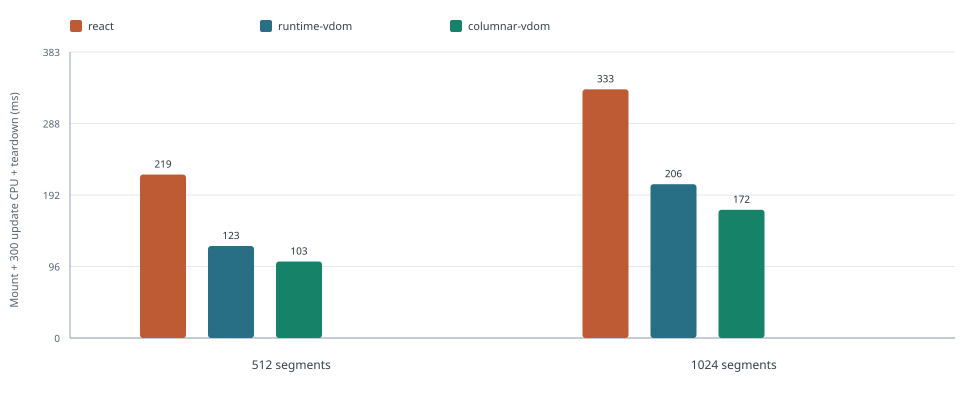

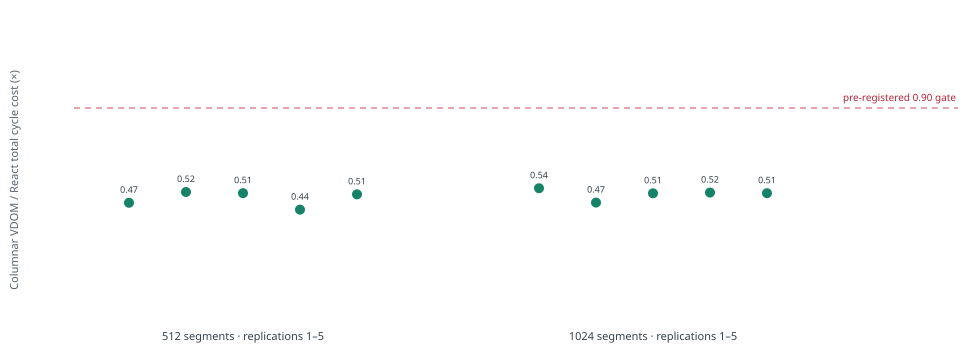

Exploratory RAF cadence — median full-run wall time per scheduled callback slot; not individual interval percentiles or physical presentation


┌───────┬──────────┬─────────────────┬───────────────────────┐
│ (idx) │ segments │ arm             │ estimatedMsPerRafSlot │
├───────┼──────────┼─────────────────┼───────────────────────┤
│     0 │      512 │ "react"         │ "16.86"               │
│     1 │      512 │ "runtime-vdom"  │ "16.78"               │
│     2 │      512 │ "columnar-vdom" │ "16.79"               │
│     3 │     1024 │ "react"         │ "17.25"               │
│     4 │     1024 │ "runtime-vdom"  │ "17.24"               │
│     5 │     1024 │ "columnar-vdom" │ "17.24"               │
└───────┴──────────┴─────────────────┴───────────────────────┘


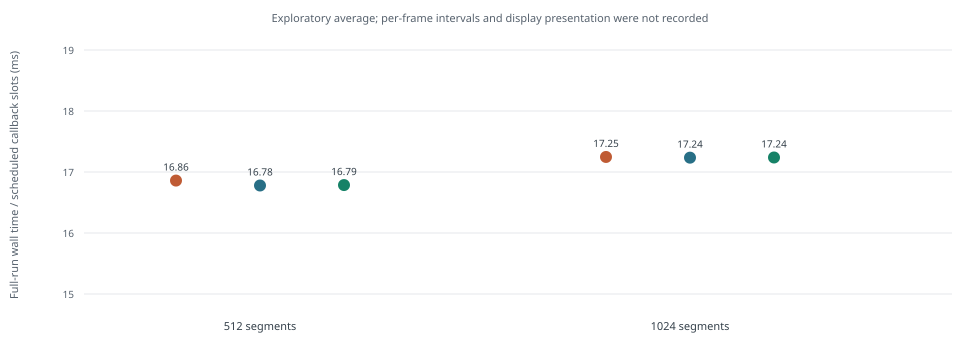

Exploratory browser heap readings — signed change from before mount (MiB); not allocation counts


┌───────┬──────┬─────────────────┬───────┬─────────────────┬───────────────────────────┬─────────────────────────────────────────────┬────────────────────────┐
│ (idx) │ size │ arm             │ pages │ zeroMountDeltas │ mountDeltaRangeMiB        │ teardownDeltaRangeMiB                       │ negativeTeardownDeltas │
├───────┼──────┼─────────────────┼───────┼─────────────────┼───────────────────────────┼─────────────────────────────────────────────┼────────────────────────┤
│     0 │  512 │ "react"         │     5 │               4 │ [ 0, 6.233382225036621 ]  │ [ 0.10741519927978516, 17.497512817382812 ] │                      0 │
│     1 │  512 │ "runtime-vdom"  │     5 │               5 │ [ 0, 0 ]                  │ [ -2.427042007446289, 1.9447927474975586 ]  │                      3 │
│     2 │  512 │ "columnar-vdom" │     5 │               3 │ [ 0, 8.49783992767334 ]   │ [ -17.468435287475586, 1.064875602722168 ]  │                      4 │
│     3 │ 1024 │ "react"         │     5

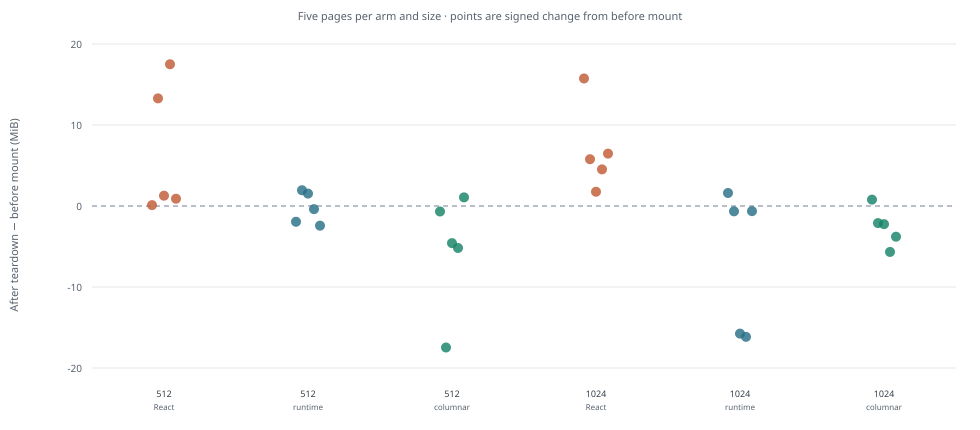

Heap diagnostic: 22/30 pages reported exactly zero after-mount delta; 15/30 reported lower heap after teardown than before mount. This API is affected by garbage collection and unrelated page heap, so these values do not identify allocated bytes or retained objects.


In [82]:
{
  const lifecycleV1Base = "results/snake-frame-lifecycle-v1";
  const lifecycleV1Prereq = JSON.parse(
    await Deno.readTextFile(`${lifecycleV1Base}/preregistration.json`),
  );
  const lifecycleV1Manifest = JSON.parse(
    await Deno.readTextFile(`${lifecycleV1Base}/manifest.json`),
  );
  const lifecycleV1Lock = JSON.parse(
    await Deno.readTextFile(`${lifecycleV1Base}/source-lock.json`),
  );
  if (
    lifecycleV1Manifest.status !== "PASS" ||
    lifecycleV1Manifest.recordCount !== lifecycleV1Prereq.schedule.length ||
    lifecycleV1Lock.status !== "FROZEN_BEFORE_COLLECTION"
  ) {
    throw new Error(
      "Lifecycle v1 manifest, schedule, or source lock is incomplete",
    );
  }
  const lifecycleV1Hash = async (bytes: Uint8Array) => {
    const digest = await crypto.subtle.digest("SHA-256", bytes);
    return [...new Uint8Array(digest)].map((byte) =>
      byte.toString(16).padStart(2, "0")
    ).join("");
  };
  const lifecycleV1CurrentDrift: string[] = [];
  for (const file of lifecycleV1Lock.files) {
    try {
      const bytes = await Deno.readFile(file.path);
      if (
        bytes.byteLength !== file.bytes ||
        await lifecycleV1Hash(bytes) !== file.sha256
      ) lifecycleV1CurrentDrift.push(file.path);
    } catch {
      lifecycleV1CurrentDrift.push(file.path);
    }
  }
  console.log(
    `Lifecycle V1 source lock records ${lifecycleV1Lock.files.length} pre-collection hashes; ${lifecycleV1CurrentDrift.length} live paths have changed or are unavailable after the later cadence build. The V1 production source bundle was not archived as a separate snapshot, so this cell verifies the frozen manifest and raw-page hashes rather than claiming a current-tree source match.`,
  );
  const lifecycleV1Expected = new Set(
    lifecycleV1Prereq.schedule.map((page: any) =>
      `${page.replication}/${page.segmentCount}/${page.arm}`
    ),
  );
  const lifecycleV1Records = [];
  for (const file of lifecycleV1Manifest.records) {
    const bytes = await Deno.readFile(file.path);
    if (
      bytes.byteLength !== file.bytes ||
      await lifecycleV1Hash(bytes) !== file.sha256
    ) throw new Error(`Lifecycle raw record hash mismatch: ${file.path}`);
    const record = JSON.parse(new TextDecoder().decode(bytes));
    if (
      record.status !== "PASS" || !record.allContractsPass ||
      record.collection !== "scheduled" || record.measuredFrames !== 300
    ) throw new Error(`Lifecycle correctness failure: ${record.trialId}`);
    lifecycleV1Records.push(record);
  }
  if (lifecycleV1Records.length !== 30) {
    throw new Error(
      `Expected 30 scheduled records, got ${lifecycleV1Records.length}`,
    );
  }
  const lifecycleV1Observed = new Set(
    lifecycleV1Records.map((record: any) =>
      `${record.replication}/${record.segmentCount}/${record.arm}`
    ),
  );
  if (
    lifecycleV1Observed.size !== lifecycleV1Expected.size ||
    [...lifecycleV1Expected].some((key) => !lifecycleV1Observed.has(key))
  ) {
    throw new Error(
      "Lifecycle page matrix differs from its preregistered schedule",
    );
  }
  const lifecycleV1Median = (values: number[]) => {
    const sorted = [...values].sort((a, b) => a - b);
    const middle = Math.floor(sorted.length / 2);
    return sorted.length % 2
      ? sorted[middle]
      : (sorted[middle - 1] + sorted[middle]) / 2;
  };
  const lifecycleV1Arms = ["react", "runtime-vdom", "columnar-vdom"];
  const lifecycleV1Sizes = [512, 1024];
  const lifecycleV1Summary = lifecycleV1Sizes.map((size) => {
    const armRows = Object.fromEntries(lifecycleV1Arms.map((arm) => {
      const pages = lifecycleV1Records.filter((record) =>
        record.segmentCount === size && record.arm === arm
      );
      return [arm, {
        cycleMs: lifecycleV1Median(
          pages.map((page) => page.primaryCycleCostMs),
        ),
        mountMs: lifecycleV1Median(pages.map((page) => page.mountMs)),
        updateMedianMs: lifecycleV1Median(
          pages.map((page) => page.updateCpuMs.median),
        ),
        updateP95Ms: lifecycleV1Median(
          pages.map((page) => page.updateCpuMs.p95),
        ),
        teardownMs: lifecycleV1Median(pages.map((page) => page.teardownMs)),
        estimatedMsPerRafSlot: lifecycleV1Median(
          pages.map((page) =>
            page.fullRafElapsedMs /
            (page.warmupFrames + page.measuredFrames + 1)
          ),
        ),
      }];
    }));
    const pairs = [1, 2, 3, 4, 5].map((replication) => {
      const find = (arm: string) =>
        lifecycleV1Records.find((record) =>
          record.segmentCount === size && record.replication === replication &&
          record.arm === arm
        );
      const react = find("react")!;
      const columnar = find("columnar-vdom")!;
      return {
        replication,
        cycleRatio: columnar.primaryCycleCostMs / react.primaryCycleCostMs,
        updateRatio: columnar.updateCpuMs.median / react.updateCpuMs.median,
      };
    });
    return { size, arms: armRows, pairs };
  });
  console.log(
    "Lifecycle v1 — medians across five paired production pages; milliseconds",
  );
  console.table(lifecycleV1Summary.map((row) => ({
    segments: row.size,
    reactCycle: row.arms.react.cycleMs.toFixed(1),
    runtimeCycle: row.arms["runtime-vdom"].cycleMs.toFixed(1),
    columnarCycle: row.arms["columnar-vdom"].cycleMs.toFixed(1),
    columnarReactRatio: lifecycleV1Median(
      row.pairs.map((pair) => pair.cycleRatio),
    ).toFixed(3),
  })));
  const lifecycleV1Width = 980;
  const lifecycleV1Height = 400;
  const lifecycleV1Left = 70;
  const lifecycleV1Right = 25;
  const lifecycleV1Top = 52;
  const lifecycleV1Bottom = 62;
  const lifecycleV1ChartHeight = lifecycleV1Height - lifecycleV1Top -
    lifecycleV1Bottom;
  const lifecycleV1Colors: Record<string, string> = {
    react: "#bf5b34",
    "runtime-vdom": "#286f86",
    "columnar-vdom": "#168267",
  };
  const lifecycleV1Max = Math.max(
    ...lifecycleV1Summary.flatMap((row) =>
      lifecycleV1Arms.map((arm) => row.arms[arm].cycleMs)
    ),
  ) * 1.15;
  const lifecycleV1Y = (value: number) =>
    lifecycleV1Top + lifecycleV1ChartHeight * (1 - value / lifecycleV1Max);
  const lifecycleV1Bars: string[] = [];
  const lifecycleV1GroupWidth =
    (lifecycleV1Width - lifecycleV1Left - lifecycleV1Right) / 2;
  const lifecycleV1BarWidth = 46;
  for (const [sizeIndex, row] of lifecycleV1Summary.entries()) {
    for (const [armIndex, arm] of lifecycleV1Arms.entries()) {
      const x = lifecycleV1Left + sizeIndex * lifecycleV1GroupWidth + 70 +
        armIndex * 68;
      const y = lifecycleV1Y(row.arms[arm].cycleMs);
      lifecycleV1Bars.push(
        `<rect x="${x}" y="${y}" width="${lifecycleV1BarWidth}" height="${
          lifecycleV1Top + lifecycleV1ChartHeight - y
        }" rx="3" fill="${lifecycleV1Colors[arm]}"/><text x="${
          x + lifecycleV1BarWidth / 2
        }" y="${y - 7}" text-anchor="middle" font-size="10" fill="#27313a">${
          row.arms[arm].cycleMs.toFixed(0)
        }</text>`,
      );
    }
  }
  const lifecycleV1Grid = Array.from({ length: 5 }, (_, index) => {
    const value = lifecycleV1Max * index / 4;
    const y = lifecycleV1Y(value);
    return `<line x1="${lifecycleV1Left}" x2="${
      lifecycleV1Width - lifecycleV1Right
    }" y1="${y}" y2="${y}" stroke="#e5e7eb"/><text x="${
      lifecycleV1Left - 10
    }" y="${y + 4}" text-anchor="end" font-size="10" fill="#56616d">${
      value.toFixed(0)
    }</text>`;
  }).join("");
  const lifecycleV1Legend = lifecycleV1Arms.map((arm, index) => {
    const x = lifecycleV1Left + index * 190;
    return `<rect x="${x}" y="20" width="12" height="12" rx="2" fill="${
      lifecycleV1Colors[arm]
    }"/><text x="${x + 18}" y="30" font-size="11" fill="#34404a">${arm}</text>`;
  }).join("");
  const lifecycleV1Labels = lifecycleV1Summary.map((row, index) =>
    `<text x="${
      lifecycleV1Left + index * lifecycleV1GroupWidth +
      lifecycleV1GroupWidth / 2
    }" y="${
      lifecycleV1Height - 31
    }" text-anchor="middle" font-size="12" fill="#34404a">${row.size} segments</text>`
  ).join("");
  await Deno.jupyter.display(
    Deno.jupyter
      .svg`<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${lifecycleV1Height}" viewBox="0 0 ${lifecycleV1Width} ${lifecycleV1Height}" role="img" aria-label="Median lifecycle cost by arm and segment count" style="max-width:100%;height:auto;font-family:system-ui,sans-serif"><title>Median lifecycle cost by arm and segment count</title><rect width="100%" height="100%" fill="white"/>${lifecycleV1Legend}${lifecycleV1Grid}<line x1="${lifecycleV1Left}" x2="${lifecycleV1Left}" y1="${lifecycleV1Top}" y2="${
      lifecycleV1Top + lifecycleV1ChartHeight
    }" stroke="#94a3b8"/><line x1="${lifecycleV1Left}" x2="${
      lifecycleV1Width - lifecycleV1Right
    }" y1="${lifecycleV1Top + lifecycleV1ChartHeight}" y2="${
      lifecycleV1Top + lifecycleV1ChartHeight
    }" stroke="#94a3b8"/>${
      lifecycleV1Bars.join("")
    }${lifecycleV1Labels}<text x="18" y="${
      lifecycleV1Height / 2
    }" transform="rotate(-90 18 ${
      lifecycleV1Height / 2
    })" text-anchor="middle" font-size="11" fill="#56616d">Mount + 300 update CPU + teardown (ms)</text></svg>`,
  );
  const lifecycleV1RatioWidth = 980;
  const lifecycleV1RatioHeight = 360;
  const lifecycleV1RatioLeft = 74;
  const lifecycleV1RatioTop = 42;
  const lifecycleV1RatioBottom = 54;
  const lifecycleV1RatioPlotHeight = lifecycleV1RatioHeight -
    lifecycleV1RatioTop - lifecycleV1RatioBottom;
  const lifecycleV1RatioY = (value: number) =>
    lifecycleV1RatioTop + lifecycleV1RatioPlotHeight * (1 - value / 1.2);
  const lifecycleV1RatioGroups = lifecycleV1Summary.map((row, sizeIndex) => {
    const points = row.pairs.map((pair, index) => {
      const x = lifecycleV1RatioLeft + sizeIndex * 410 + 55 + index * 57;
      const y = lifecycleV1RatioY(pair.cycleRatio);
      return `<circle cx="${x}" cy="${y}" r="5" fill="${
        lifecycleV1Colors["columnar-vdom"]
      }"/><text x="${x}" y="${
        y - 10
      }" text-anchor="middle" font-size="9" fill="#34404a">${
        pair.cycleRatio.toFixed(2)
      }</text>`;
    }).join("");
    const groupX = lifecycleV1RatioLeft + sizeIndex * 410 + 55;
    return `${points}<text x="${groupX + 114}" y="${
      lifecycleV1RatioHeight - 20
    }" text-anchor="middle" font-size="11" fill="#34404a">${row.size} segments · replications 1–5</text>`;
  }).join("");
  const lifecycleV1RatioGateY = lifecycleV1RatioY(0.9);
  const lifecycleV1RatioSvg =
    `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${lifecycleV1RatioHeight}" viewBox="0 0 ${lifecycleV1RatioWidth} ${lifecycleV1RatioHeight}" role="img" aria-label="Paired columnar VDOM to React lifecycle cost ratios" style="max-width:100%;height:auto;font-family:system-ui,sans-serif"><title>Paired columnar VDOM to React lifecycle cost ratios</title><rect width="100%" height="100%" fill="white"/><line x1="${lifecycleV1RatioLeft}" x2="${
      lifecycleV1RatioWidth - 22
    }" y1="${lifecycleV1RatioGateY}" y2="${lifecycleV1RatioGateY}" stroke="#d1495b" stroke-dasharray="6 5"/><text x="${
      lifecycleV1RatioWidth - 24
    }" y="${
      lifecycleV1RatioGateY - 7
    }" text-anchor="end" font-size="10" fill="#b42335">pre-registered 0.90 gate</text>${lifecycleV1RatioGroups}<text x="18" y="${
      lifecycleV1RatioHeight / 2
    }" transform="rotate(-90 18 ${
      lifecycleV1RatioHeight / 2
    })" text-anchor="middle" font-size="11" fill="#56616d">Columnar VDOM / React total cycle cost (×)</text></svg>`;
  await Deno.jupyter.display(Deno.jupyter.svg`${lifecycleV1RatioSvg}`);
  console.log(
    "Exploratory RAF cadence — median full-run wall time per scheduled callback slot; not individual interval percentiles or physical presentation",
  );
  console.table(
    lifecycleV1Summary.flatMap((row) =>
      lifecycleV1Arms.map((arm) => ({
        segments: row.size,
        arm,
        estimatedMsPerRafSlot: row.arms[arm].estimatedMsPerRafSlot.toFixed(2),
      }))
    ),
  );
  const cadenceWidth = 980;
  const cadenceHeight = 350;
  const cadenceLeft = 84;
  const cadenceTop = 50;
  const cadenceBottom = 56;
  const cadencePlotHeight = cadenceHeight - cadenceTop - cadenceBottom;
  const cadenceMin = 15;
  const cadenceMax = 19;
  const cadenceY = (value: number) =>
    cadenceTop +
    cadencePlotHeight * (1 - (value - cadenceMin) / (cadenceMax - cadenceMin));
  const cadenceGrid = Array.from({ length: 5 }, (_, index) => {
    const value = cadenceMin + index;
    const y = cadenceY(value);
    return `<line x1="${cadenceLeft}" x2="${
      cadenceWidth - 28
    }" y1="${y}" y2="${y}" stroke="#e5e7eb"/><text x="${cadenceLeft - 10}" y="${
      y + 4
    }" text-anchor="end" font-size="10" fill="#56616d">${value}</text>`;
  }).join("");
  const cadenceDots = lifecycleV1Summary.flatMap((row, sizeIndex) =>
    lifecycleV1Arms.map((arm, armIndex) => {
      const x = cadenceLeft + sizeIndex * 430 + 92 + armIndex * 84;
      const value = row.arms[arm].estimatedMsPerRafSlot;
      const y = cadenceY(value);
      return `<circle cx="${x}" cy="${y}" r="6" fill="${
        lifecycleV1Colors[arm]
      }"/><text x="${x}" y="${
        y - 10
      }" text-anchor="middle" font-size="10" fill="#34404a">${
        value.toFixed(2)
      }</text>`;
    })
  ).join("");
  const cadenceLabels = lifecycleV1Summary.map((row, index) =>
    `<text x="${cadenceLeft + index * 430 + 176}" y="${
      cadenceHeight - 20
    }" text-anchor="middle" font-size="11" fill="#34404a">${row.size} segments</text>`
  ).join("");
  const cadenceSvg =
    `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${cadenceHeight}" viewBox="0 0 ${cadenceWidth} ${cadenceHeight}" role="img" aria-label="Exploratory average animation callback slot duration by runtime and segment count" style="max-width:100%;height:auto;font-family:system-ui,sans-serif"><title>Exploratory RAF callback cadence</title><rect width="100%" height="100%" fill="white"/>${cadenceGrid}${cadenceDots}${cadenceLabels}<text x="18" y="${
      cadenceHeight / 2
    }" transform="rotate(-90 18 ${
      cadenceHeight / 2
    })" text-anchor="middle" font-size="11" fill="#56616d">Full-run wall time / scheduled callback slots (ms)</text><text x="${
      cadenceWidth / 2
    }" y="22" text-anchor="middle" font-size="11" fill="#56616d">Exploratory average; per-frame intervals and display presentation were not recorded</text></svg>`;
  await Deno.jupyter.display(Deno.jupyter.svg`${cadenceSvg}`);

  const lifecycleV1HeapRows = lifecycleV1Records.map((record: any) => ({
    size: record.segmentCount,
    arm: record.arm,
    replication: record.replication,
    mountDeltaMiB: (record.heapUsedAfterMountBytes -
      record.heapUsedBeforeMountBytes) / (1024 * 1024),
    teardownDeltaMiB: (record.heapUsedAfterTeardownBytes -
      record.heapUsedBeforeMountBytes) / (1024 * 1024),
  }));
  const lifecycleV1HeapSummary = lifecycleV1Sizes.flatMap((size) =>
    lifecycleV1Arms.map((arm) => {
      const rows = lifecycleV1HeapRows.filter((row: any) =>
        row.size === size && row.arm === arm
      );
      const mountDeltas = rows.map((row: any) => row.mountDeltaMiB);
      const teardownDeltas = rows.map((row: any) => row.teardownDeltaMiB);
      return {
        size,
        arm,
        pages: rows.length,
        zeroMountDeltas: mountDeltas.filter((value: number) => value === 0)
          .length,
        mountDeltaRangeMiB: [
          Math.min(...mountDeltas),
          Math.max(...mountDeltas),
        ],
        teardownDeltaRangeMiB: [
          Math.min(...teardownDeltas),
          Math.max(...teardownDeltas),
        ],
        negativeTeardownDeltas: teardownDeltas.filter((value: number) =>
          value < 0
        ).length,
      };
    })
  );
  console.log(
    "Exploratory browser heap readings — signed change from before mount (MiB); not allocation counts",
  );
  console.table(lifecycleV1HeapSummary);
  const lifecycleV1HeapWidth = 980;
  const lifecycleV1HeapHeight = 430;
  const lifecycleV1HeapLeft = 92;
  const lifecycleV1HeapRight = 24;
  const lifecycleV1HeapTop = 44;
  const lifecycleV1HeapBottom = 62;
  const lifecycleV1HeapPlotHeight = lifecycleV1HeapHeight -
    lifecycleV1HeapTop - lifecycleV1HeapBottom;
  const lifecycleV1HeapMin = -20;
  const lifecycleV1HeapMax = 20;
  const lifecycleV1HeapY = (value: number) =>
    lifecycleV1HeapTop + lifecycleV1HeapPlotHeight *
      (1 - (value - lifecycleV1HeapMin) /
          (lifecycleV1HeapMax - lifecycleV1HeapMin));
  const lifecycleV1HeapTicks = [-20, -10, 0, 10, 20].map((value) => {
    const y = lifecycleV1HeapY(value);
    return `<line x1="${lifecycleV1HeapLeft}" x2="${
      lifecycleV1HeapWidth - lifecycleV1HeapRight
    }" y1="${y}" y2="${y}" stroke="${value === 0 ? "#718096" : "#e5e7eb"}" ${
      value === 0 ? 'stroke-dasharray="5 4"' : ""
    }/><text x="${lifecycleV1HeapLeft - 10}" y="${
      y + 4
    }" text-anchor="end" font-size="10" fill="#56616d">${value}</text>`;
  }).join("");
  const lifecycleV1HeapGroupWidth =
    (lifecycleV1HeapWidth - lifecycleV1HeapLeft - lifecycleV1HeapRight) / 6;
  const lifecycleV1HeapDots = lifecycleV1HeapRows.map((row: any) => {
    const sizeIndex = lifecycleV1Sizes.indexOf(row.size);
    const armIndex = lifecycleV1Arms.indexOf(row.arm);
    const category = sizeIndex * lifecycleV1Arms.length + armIndex;
    const jitter = (row.replication - 3) * 6;
    const x = lifecycleV1HeapLeft + category * lifecycleV1HeapGroupWidth +
      lifecycleV1HeapGroupWidth / 2 + jitter;
    const y = lifecycleV1HeapY(row.teardownDeltaMiB);
    return `<circle cx="${x}" cy="${y}" r="5" fill="${
      lifecycleV1Colors[row.arm]
    }" opacity="0.82"><title>${row.size} segments · ${row.arm} · page ${row.replication}: ${
      row.teardownDeltaMiB.toFixed(2)
    } MiB</title></circle>`;
  }).join("");
  const lifecycleV1HeapLabels = lifecycleV1Sizes.flatMap((size, sizeIndex) =>
    lifecycleV1Arms.map((arm, armIndex) => {
      const category = sizeIndex * lifecycleV1Arms.length + armIndex;
      const x = lifecycleV1HeapLeft + category * lifecycleV1HeapGroupWidth +
        lifecycleV1HeapGroupWidth / 2;
      const y = lifecycleV1HeapHeight - 33;
      return `<text x="${x}" y="${y}" text-anchor="middle" font-size="9" fill="#34404a">${size}</text><text x="${x}" y="${
        y + 13
      }" text-anchor="middle" font-size="8" fill="#56616d">${
        arm === "runtime-vdom"
          ? "runtime"
          : arm === "columnar-vdom"
          ? "columnar"
          : "React"
      }</text>`;
    })
  ).join("");
  const lifecycleV1HeapSvg =
    `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${lifecycleV1HeapHeight}" viewBox="0 0 ${lifecycleV1HeapWidth} ${lifecycleV1HeapHeight}" role="img" aria-label="Per-page browser heap change after teardown relative to before mount" style="max-width:100%;height:auto;font-family:system-ui,sans-serif"><title>Exploratory used JavaScript heap after teardown</title><rect width="100%" height="100%" fill="white"/><text x="${
      lifecycleV1HeapWidth / 2
    }" y="20" text-anchor="middle" font-size="11" fill="#56616d">Five pages per arm and size · points are signed change from before mount</text>${lifecycleV1HeapTicks}${lifecycleV1HeapDots}${lifecycleV1HeapLabels}<text x="18" y="${
      lifecycleV1HeapHeight / 2
    }" transform="rotate(-90 18 ${
      lifecycleV1HeapHeight / 2
    })" text-anchor="middle" font-size="11" fill="#56616d">After teardown − before mount (MiB)</text></svg>`;
  await Deno.jupyter.display(Deno.jupyter.svg`${lifecycleV1HeapSvg}`);
  const lifecycleV1ZeroMountCount =
    lifecycleV1HeapRows.filter((row: any) => row.mountDeltaMiB === 0).length;
  const lifecycleV1NegativeTeardownCount = lifecycleV1HeapRows.filter(
    (row: any) => row.teardownDeltaMiB < 0,
  ).length;
  console.log(
    `Heap diagnostic: ${lifecycleV1ZeroMountCount}/${lifecycleV1HeapRows.length} pages reported exactly zero after-mount delta; ${lifecycleV1NegativeTeardownCount}/${lifecycleV1HeapRows.length} reported lower heap after teardown than before mount. This API is affected by garbage collection and unrelated page heap, so these values do not identify allocated bytes or retained objects.`,
  );
}



### Per-frame callback cadence follow-up: Snake V1

This preregistered study extends the lifecycle-inclusive Snake benchmark to 1,024, 4,096, and 8,192 fixed segments. Each of 45 fresh production pages first calibrates 120 idle RAF intervals, mounts its scene, warms up for 60 callbacks, and records 240 per-frame update CPU samples and RAF intervals. A callback is flagged late when its interval exceeds 1.5× that page's calibrated median interval; estimated missed slots are reported separately. Five randomized blocks pair React 19.3 + verified React Compiler with scalar retained VDOM and OXC-plan columnar retained VDOM.

The figures report page-level medians. Callback samples are nested within pages, not independent replications. The late-callback threshold is a cadence proxy; it does not observe compositor presentation timestamps or prove perceived smoothness. Layout and paint occur naturally in this DOM workload, but are not separately attributed. An 8,192-segment smoke run showed why both measures matter: update CPU can be several milliseconds lower while RAF callbacks still arrive multiple refresh periods apart.

The cell independently verifies the 45-page schedule, frozen workload sources and production bundle hashes, the raw manifest hashes, output and cleanup contracts, and the preregistered decision. The Vite config was extended after this collection to add the separate phase-attribution harness, so that one tooling source hash is reported as post-collection drift; its original production assets and records remain hash-verified. Interpret a floor-limited result or a failed hypothesis as recorded; do not promote the update CPU advantage into a smoothness claim.


Cadence V1 Vite source hash differs because the later phase-attribution harness was added after collection; locked production assets and raw records are still hash-verified.


Cadence V1 locked Snake game bundle was replaced by a content-hashed post-collection rebuild; its old and current hashes are recorded in results/post-collection-source-drift.json. The cadence harness and raw records remain hash-verified.


Snake frame cadence V1 — preregistered page medians


┌───────┬──────────┬─────────────────┬─────────────┬─────────────┬──────────┬──────────┬─────────────┐
│ (idx) │ segments │ arm             │ updateCpuMs │ RAFMedianMs │ RAFp95Ms │ lateRate │ missedSlots │
├───────┼──────────┼─────────────────┼─────────────┼─────────────┼──────────┼──────────┼─────────────┤
│     0 │     1024 │ "react"         │ "1.10"      │ "16.70"     │ "17.10"  │ "0.0%"   │           0 │
│     1 │     1024 │ "runtime-vdom"  │ "0.60"      │ "16.70"     │ "16.80"  │ "0.0%"   │           0 │
│     2 │     1024 │ "columnar-vdom" │ "0.50"      │ "16.70"     │ "17.60"  │ "0.0%"   │           0 │
│     3 │     4096 │ "react"         │ "3.90"      │ "16.70"     │ "33.70"  │ "27.5%"  │          76 │
│     4 │     4096 │ "runtime-vdom"  │ "2.20"      │ "16.70"     │ "34.50"  │ "24.2%"  │          70 │
│     5 │     4096 │ "columnar-vdom" │ "1.80"      │ "16.70"     │ "33.40"  │ "22.5%"  │          59 │
│     6 │     8192 │ "react"         │ "8.00"      │ "50.00"     │ "66.60

Preregistered decision {
  status: "HYPOTHESIS_PASS",
  correctnessPass: true,
  updateCpuPass: true,
  cadenceAdvantagePass: true,
  cadenceWinsAt8192: 4,
  zeroHeadroom: false
}


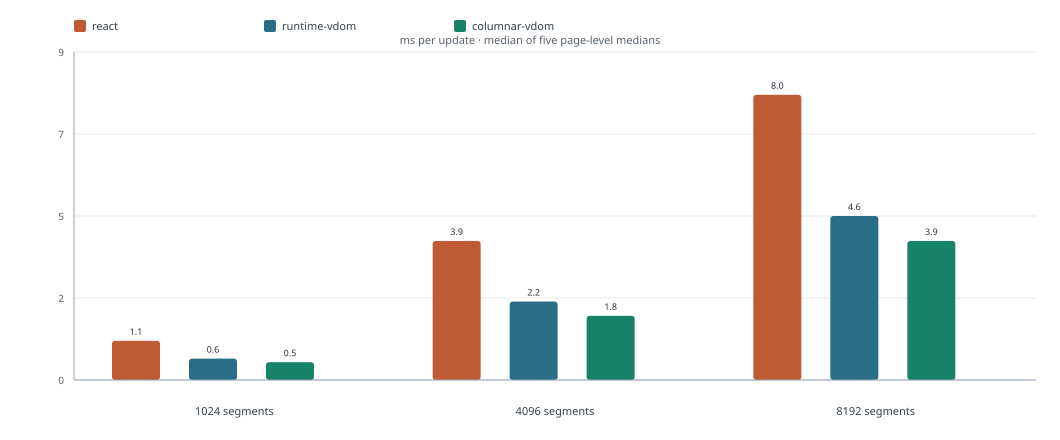

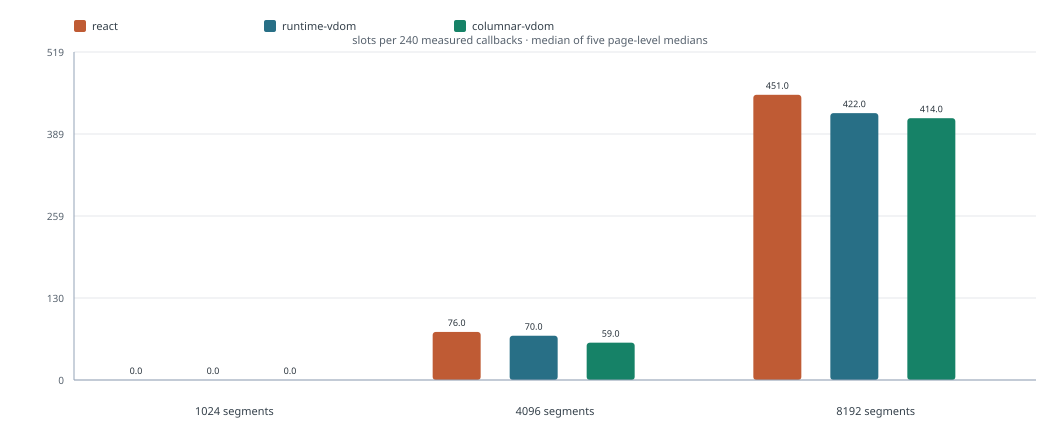

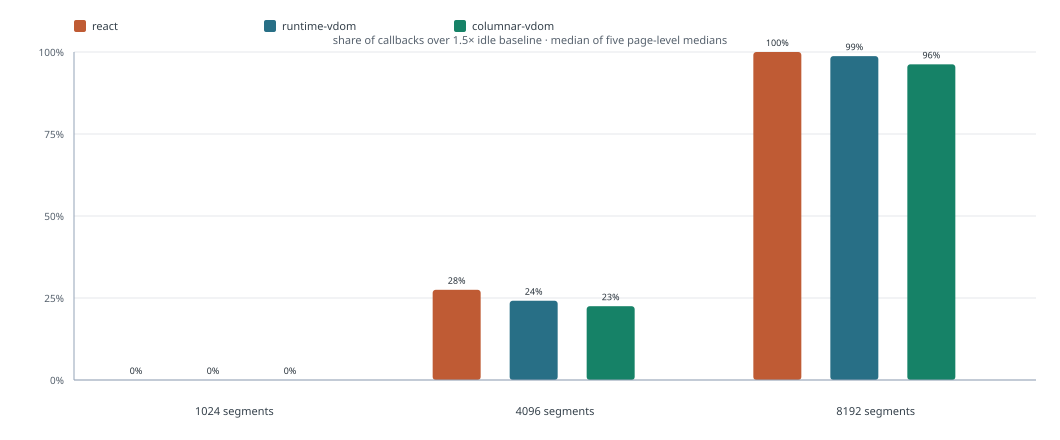

In [83]:
{
  const cadenceV1Base = "results/snake-frame-cadence-v1";
  const cadenceV1Prereq = JSON.parse(
    await Deno.readTextFile(`${cadenceV1Base}/preregistration.json`),
  );
  const cadenceV1Lock = JSON.parse(
    await Deno.readTextFile(`${cadenceV1Base}/source-lock.json`),
  );
  const cadenceV1Manifest = JSON.parse(
    await Deno.readTextFile(`${cadenceV1Base}/manifest.json`),
  );
  const cadenceV1Summary = JSON.parse(
    await Deno.readTextFile(`${cadenceV1Base}/summary.json`),
  );
  const cadenceV1Hash = async (bytes: Uint8Array) => {
    const digest = await crypto.subtle.digest("SHA-256", bytes);
    return [...new Uint8Array(digest)].map((byte) =>
      byte.toString(16).padStart(2, "0")
    ).join("");
  };
  if (
    cadenceV1Prereq.schedule.length !== 45 ||
    cadenceV1Lock.status !== "FROZEN_BEFORE_COLLECTION" ||
    cadenceV1Manifest.status !== "PASS" ||
    cadenceV1Manifest.recordCount !== 45 ||
    cadenceV1Summary.recordCount !== 45
  ) throw new Error("Cadence V1 study metadata or collection is incomplete");
  const cadenceV1DriftLedger = JSON.parse(
    await Deno.readTextFile("results/post-collection-source-drift.json"),
  );
  if (cadenceV1DriftLedger.schemaVersion !== "post-collection-source-drift-v1") {
    throw new Error("Cadence V1 post-collection drift ledger is invalid");
  }
  const cadenceV1DriftByPath = new Map(
    cadenceV1DriftLedger.entries
      .filter((entry: any) => entry.appliesTo.includes("snake-frame-cadence-v1"))
      .map((entry: any) => [entry.path, entry]),
  );
  let cadenceV1PostCollectionViteDrift = false;
  let cadenceV1PostCollectionGameAssetDrift = false;
  for (const entry of [...cadenceV1Lock.sourceFiles, ...cadenceV1Lock.productionAssets]) {
    let currentPath = entry.path;
    let bytes: Uint8Array;
    try {
      bytes = await Deno.readFile(currentPath);
    } catch (error) {
      const drift: any = cadenceV1DriftByPath.get(entry.path);
      if (typeof drift?.currentPath !== "string") throw error;
      currentPath = drift.currentPath;
      bytes = await Deno.readFile(currentPath);
    }
    const matches = bytes.length === entry.bytes &&
      await cadenceV1Hash(bytes) === entry.sha256;
    if (!matches && entry.path === "vite.config.ts") {
      const currentConfig = new TextDecoder().decode(bytes);
      if (!currentConfig.includes("/__benchmark/save-snake-phase-v1")) {
        throw new Error("Cadence Vite source drift is not the recorded later phase-study instrumentation");
      }
      cadenceV1PostCollectionViteDrift = true;
      continue;
    }
    if (!matches && cadenceV1DriftByPath.has(entry.path)) {
      const drift: any = cadenceV1DriftByPath.get(entry.path);
      const currentSha256 = await cadenceV1Hash(bytes);
      if (
        drift.frozenBytes !== entry.bytes || drift.frozenSha256 !== entry.sha256 ||
        drift.currentBytes !== bytes.length || drift.currentSha256 !== currentSha256 ||
        (drift.currentPath !== undefined && drift.currentPath !== currentPath)
      ) throw new Error(`Cadence drift-ledger mismatch: ${entry.path}`);
      cadenceV1PostCollectionGameAssetDrift = true;
      continue;
    }
    if (!matches) {
      throw new Error(`Cadence source lock mismatch: ${entry.path}`);
    }
  }
  if (cadenceV1PostCollectionViteDrift) {
    console.warn("Cadence V1 Vite source hash differs because the later phase-attribution harness was added after collection; locked production assets and raw records are still hash-verified.");
  }
  if (cadenceV1PostCollectionGameAssetDrift) {
    console.warn("Cadence V1 locked Snake game bundle was replaced by a content-hashed post-collection rebuild; its old and current hashes are recorded in results/post-collection-source-drift.json. The cadence harness and raw records remain hash-verified.");
  }
  const cadenceV1Observed = new Set<string>();
  const cadenceV1Records: any[] = [];
  for (const entry of cadenceV1Manifest.records) {
    const bytes = await Deno.readFile(entry.path);
    if (bytes.length !== entry.bytes || await cadenceV1Hash(bytes) !== entry.sha256) {
      throw new Error(`Cadence raw record hash mismatch: ${entry.path}`);
    }
    const record = JSON.parse(new TextDecoder().decode(bytes));
    if (
      record.status !== "PASS" || !record.allContractsPass ||
      record.collection !== "scheduled" ||
      record.measuredRafMs.samples.length !== 240 ||
      record.updateCpuMs.samples.length !== 240
    ) throw new Error(`Cadence page contract failed: ${record.trialId}`);
    cadenceV1Observed.add(
      `${record.replication}/${record.segmentCount}/${record.arm}`,
    );
    cadenceV1Records.push(record);
  }
  const cadenceV1Expected = new Set(
    cadenceV1Prereq.schedule.map((page: any) =>
      `${page.replication}/${page.segmentCount}/${page.arm}`
    ),
  );
  if (
    cadenceV1Observed.size !== cadenceV1Expected.size ||
    [...cadenceV1Expected].some((key) => !cadenceV1Observed.has(key))
  ) throw new Error("Cadence collection differs from frozen schedule");
  console.log("Snake frame cadence V1 — preregistered page medians");
  console.table(cadenceV1Summary.comparisons.flatMap((row: any) =>
    ["react", "runtime-vdom", "columnar-vdom"].map((arm) => ({
      segments: row.segmentCount,
      arm,
      updateCpuMs: row.arms[arm].updateCpuMedianMs.toFixed(2),
      RAFMedianMs: row.arms[arm].rafIntervalMedianMs.toFixed(2),
      RAFp95Ms: row.arms[arm].rafIntervalP95Ms.toFixed(2),
      lateRate: (row.arms[arm].lateCallbackRate * 100).toFixed(1) + "%",
      missedSlots: row.arms[arm].estimatedMissedSlots,
    }))
  ));
  console.log("Preregistered decision", {
    status: cadenceV1Summary.status,
    correctnessPass: cadenceV1Summary.correctnessPass,
    updateCpuPass: cadenceV1Summary.updateCpuPass,
    cadenceAdvantagePass: cadenceV1Summary.cadenceAdvantagePass,
    cadenceWinsAt8192: cadenceV1Summary.cadenceWinsAt8192,
    zeroHeadroom: cadenceV1Summary.zeroHeadroom,
  });

  const cadenceV1Arms = ["react", "runtime-vdom", "columnar-vdom"];
  const cadenceV1Colors: Record<string, string> = {
    react: "#bf5b34",
    "runtime-vdom": "#286f86",
    "columnar-vdom": "#168267",
  };
  const cadenceV1Sizes = [1024, 4096, 8192];
  const cadenceV1Width = 1060;
  const cadenceV1Height = 440;
  const cadenceV1Left = 74;
  const cadenceV1Right = 24;
  const cadenceV1Top = 52;
  const cadenceV1Bottom = 60;
  const cadenceV1PlotHeight = cadenceV1Height - cadenceV1Top - cadenceV1Bottom;
  const cadenceV1Legend = cadenceV1Arms.map((arm, index) => {
    const x = cadenceV1Left + index * 190;
    return `<rect x="${x}" y="20" width="12" height="12" rx="2" fill="${cadenceV1Colors[arm]}"/><text x="${x + 18}" y="30" font-size="11" fill="#34404a">${arm}</text>`;
  }).join("");
  const cadenceV1Charts = [
    {
      title: "Median update CPU by scene size",
      key: "updateCpuMedianMs",
      max: Math.max(...cadenceV1Summary.comparisons.flatMap((row: any) =>
        cadenceV1Arms.map((arm) => row.arms[arm].updateCpuMedianMs)
      )) * 1.15,
      unit: "ms per update",
    },
    {
      title: "Estimated missed callback slots by scene size",
      key: "estimatedMissedSlots",
      max: Math.max(...cadenceV1Summary.comparisons.flatMap((row: any) =>
        cadenceV1Arms.map((arm) => row.arms[arm].estimatedMissedSlots)
      )) * 1.15 || 1,
      unit: "slots per 240 measured callbacks",
    },
    {
      title: "Late callback rate by scene size",
      key: "lateCallbackRate",
      max: 1,
      unit: "share of callbacks over 1.5× idle baseline",
    },
  ];
  for (const chart of cadenceV1Charts) {
    const grid = Array.from({ length: 5 }, (_, index) => {
      const value = chart.max * index / 4;
      const y = cadenceV1Top + cadenceV1PlotHeight * (1 - value / chart.max);
      return `<line x1="${cadenceV1Left}" x2="${cadenceV1Width - cadenceV1Right}" y1="${y}" y2="${y}" stroke="#e5e7eb"/><text x="${cadenceV1Left - 10}" y="${y + 4}" text-anchor="end" font-size="10" fill="#56616d">${chart.key === "lateCallbackRate" ? (value * 100).toFixed(0) + "%" : value.toFixed(0)}</text>`;
    }).join("");
    const groupWidth = (cadenceV1Width - cadenceV1Left - cadenceV1Right) / cadenceV1Sizes.length;
    const bars = cadenceV1Summary.comparisons.flatMap((row: any, sizeIndex: number) =>
      cadenceV1Arms.map((arm, armIndex) => {
        const value = row.arms[arm][chart.key];
        const height = value / chart.max * cadenceV1PlotHeight;
        const x = cadenceV1Left + sizeIndex * groupWidth + 38 + armIndex * 77;
        const y = cadenceV1Top + cadenceV1PlotHeight - height;
        const label = chart.key === "lateCallbackRate"
          ? (value * 100).toFixed(0) + "%"
          : value.toFixed(1);
        return `<rect x="${x}" y="${y}" width="48" height="${height}" rx="3" fill="${cadenceV1Colors[arm]}"/><text x="${x + 24}" y="${y - 6}" text-anchor="middle" font-size="9" fill="#27313a">${label}</text>`;
      })
    ).join("");
    const labels = cadenceV1Sizes.map((size, index) =>
      `<text x="${cadenceV1Left + index * groupWidth + groupWidth / 2}" y="${cadenceV1Height - 25}" text-anchor="middle" font-size="11" fill="#34404a">${size} segments</text>`
    ).join("");
    const svg = `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${cadenceV1Height}" viewBox="0 0 ${cadenceV1Width} ${cadenceV1Height}" role="img" aria-label="${chart.title}" style="max-width:100%;height:auto;font-family:system-ui,sans-serif"><title>${chart.title}</title><rect width="100%" height="100%" fill="white"/>${cadenceV1Legend}<text x="${cadenceV1Width / 2}" y="44" text-anchor="middle" font-size="11" fill="#56616d">${chart.unit} · median of five page-level medians</text>${grid}${bars}${labels}<line x1="${cadenceV1Left}" x2="${cadenceV1Left}" y1="${cadenceV1Top}" y2="${cadenceV1Height - cadenceV1Bottom}" stroke="#94a3b8"/><line x1="${cadenceV1Left}" x2="${cadenceV1Width - cadenceV1Right}" y1="${cadenceV1Height - cadenceV1Bottom}" y2="${cadenceV1Height - cadenceV1Bottom}" stroke="#94a3b8"/></svg>`;
    await Deno.jupyter.display(Deno.jupyter.svg`${svg}`);
  }
}



### Long Animation Frames phase attribution: Snake V1

This preregistered 30-page follow-up pairs React 19.3 + verified React Compiler, scalar retained VDOM, and OXC-plan columnar retained VDOM at 1,024 and 8,192 fixed segments. Each fresh visible production page calibrates 120 idle RAF intervals, warms up for 60 callbacks, and measures 240 updates. The Long Animation Frames API is feature-detected before collection; an unsupported page fails rather than silently switching instrumentation.

The API reports only frames longer than 50 ms. The analysis preserves total LoAF duration, script attribution, blocking duration, renderStart, styleAndLayoutStart, and the remaining interval from styleAndLayoutStart to the entry end. Script duration and this remainder are separate coarse observables, not exclusive pieces of frame time. A missing LoAF entry does not mean the browser did no style, layout, or paint work; none of these values measure compositor completion or display presentation.

The cell verifies the frozen schedule and source/build lock, every raw hash, API support, output parity, stable host identity, and teardown. It presents page-level summaries with SVGs and no causal or smoothness claim. Smoke records are isolated from the scheduled collection.


Recorded post-collection source drift; frozen source hashes and production assets remain unchanged: [
  "deno.json → deno.json: After cadence collection, developer-study task metadata was updated to write an explicit empty-data summary artifact and to run the notebook status cell. These are research workflow commands; cadence workload, benchmark implementation, collection, and archived records are unchanged.",
  "dist/assets/snakeGame-BlrhBNxw.js → dist/assets/snakeGame-CKQ62_rD.js: After per-frame collection, the interactive Snake restart path was fixed and the production build emitted a new content-hashed game asset, replacing the old filename. The benchmark harness modules and archived page records are unchanged; the locked old bundle digest remains recorded."
]


Snake frame phase attribution V1 — page medians


┌───────┬──────────┬─────────────────┬───────────┬───────────┬─────────────┬────────────────────┬──────────────────┬─────────────┬──────────┐
│ (idx) │ segments │ arm             │ loafPages │ loafCount │ totalLoafMs │ attributedScriptMs │ postStyleStartMs │ updateCpuMs │ RAFp95Ms │
├───────┼──────────┼─────────────────┼───────────┼───────────┼─────────────┼────────────────────┼──────────────────┼─────────────┼──────────┤
│     0 │     1024 │ "react"         │         0 │         0 │ "0.0"       │ "—"                │ "—"              │ "1.10"      │ "17.3"   │
│     1 │     1024 │ "runtime-vdom"  │         0 │         0 │ "0.0"       │ "—"                │ "—"              │ "0.70"      │ "17.3"   │
│     2 │     1024 │ "columnar-vdom" │         0 │         0 │ "0.0"       │ "—"                │ "—"              │ "0.50"      │ "17.0"   │
│     3 │     8192 │ "react"         │         5 │         8 │ "412.7"     │ "87.7"             │ "138.7"          │ "8.50"      │ "66.7"   │
│     

Long Animation Frames entries are thresholded (>50 ms) main-thread diagnostics. Script duration and styleAndLayoutStart-to-entry-end are separately reported observables, not mutually exclusive parts of total frame time; absent entries do not imply zero rendering cost. No presentation or causality claim is made.


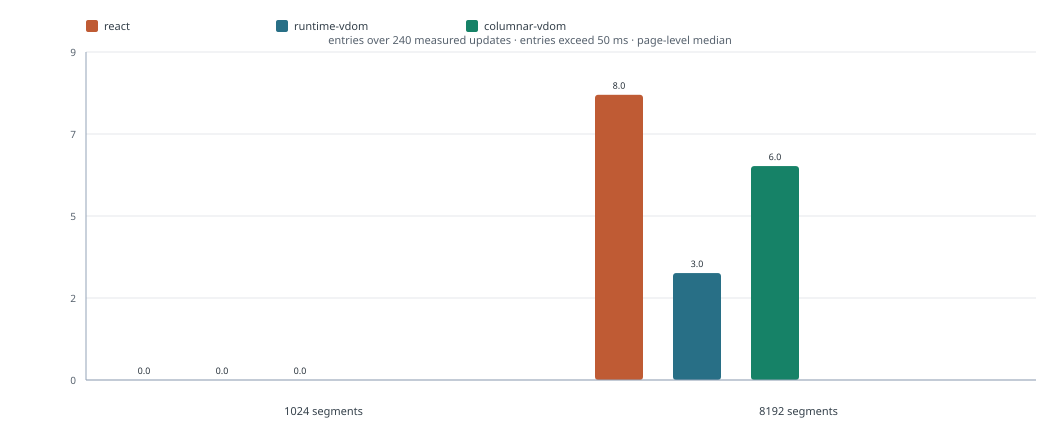

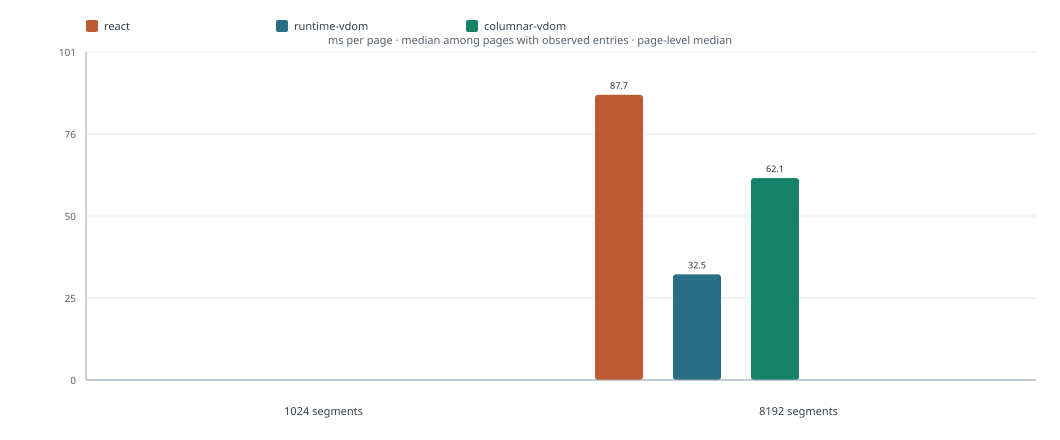

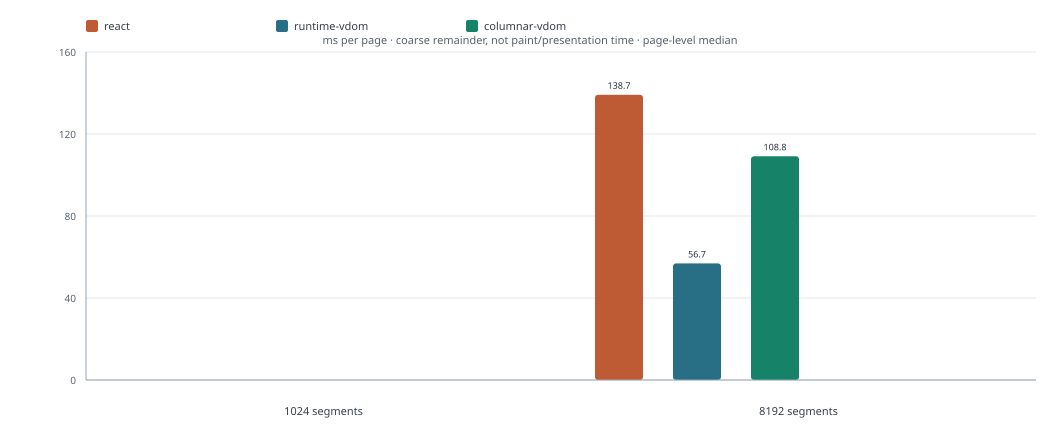

In [84]:
{
  const phaseBase = "results/snake-frame-phase-v1";
  const phasePrereq = JSON.parse(
    await Deno.readTextFile(`${phaseBase}/preregistration.json`),
  );
  const phaseLock = JSON.parse(
    await Deno.readTextFile(`${phaseBase}/source-lock.json`),
  );
  const phaseManifest = JSON.parse(
    await Deno.readTextFile(`${phaseBase}/manifest.json`),
  );
  const phaseSummary = JSON.parse(
    await Deno.readTextFile(`${phaseBase}/summary.json`),
  );
  const phaseHash = async (bytes: Uint8Array) => {
    const owned = bytes.buffer.slice(
      bytes.byteOffset,
      bytes.byteOffset + bytes.byteLength,
    ) as ArrayBuffer;
    const digest = await crypto.subtle.digest("SHA-256", owned);
    return [...new Uint8Array(digest)].map((byte) =>
      byte.toString(16).padStart(2, "0")
    ).join("");
  };
  if (
    phasePrereq.schedule.length !== 30 ||
    phaseLock.status !== "FROZEN_BEFORE_COLLECTION" ||
    phaseManifest.status !== "PASS" ||
    phaseManifest.recordCount !== 30 ||
    phaseSummary.recordCount !== 30 ||
    !phaseSummary.allContractsPass ||
    !phaseSummary.apiSupportedOnAllPages
  ) throw new Error("Phase V1 preregistration or collection metadata is incomplete");
  const phaseDriftLedger = JSON.parse(
    await Deno.readTextFile("results/post-collection-source-drift.json"),
  );
  if (phaseDriftLedger.schemaVersion !== "post-collection-source-drift-v1") {
    throw new Error("Phase V1 post-collection drift ledger is invalid");
  }
  const phaseDriftByPath = new Map(
    phaseDriftLedger.entries
      .filter((entry: any) => entry.appliesTo.includes("snake-frame-phase-v1"))
      .map((entry: any) => [entry.path, entry]),
  );
  const phaseObservedDrift: string[] = [];
  for (const entry of [...phaseLock.sourceFiles, ...phaseLock.productionAssets]) {
    let currentPath = entry.path;
    let bytes: Uint8Array;
    try {
      bytes = await Deno.readFile(currentPath);
    } catch (error) {
      const drift: any = phaseDriftByPath.get(entry.path);
      if (typeof drift?.currentPath !== "string") throw error;
      currentPath = drift.currentPath;
      bytes = await Deno.readFile(currentPath);
    }
    const currentSha256 = await phaseHash(bytes);
    if (bytes.length !== entry.bytes || currentSha256 !== entry.sha256) {
      const drift: any = phaseDriftByPath.get(entry.path);
      if (
        !drift || drift.frozenBytes !== entry.bytes ||
        drift.frozenSha256 !== entry.sha256 || drift.currentBytes !== bytes.length ||
        drift.currentSha256 !== currentSha256 ||
        (drift.currentPath !== undefined && drift.currentPath !== currentPath)
      ) throw new Error(`Phase V1 source-lock mismatch: ${entry.path}`);
      phaseObservedDrift.push(`${entry.path} → ${currentPath}: ${drift.reason}`);
    }
  }
  if (phaseObservedDrift.length) {
    console.warn("Recorded post-collection source drift; frozen source hashes and production assets remain unchanged:", phaseObservedDrift);
  }
  const phaseObserved = new Set<string>();
  for (const entry of phaseManifest.records) {
    const bytes = await Deno.readFile(entry.path);
    if (bytes.length !== entry.bytes || await phaseHash(bytes) !== entry.sha256) {
      throw new Error(`Phase V1 raw hash mismatch: ${entry.path}`);
    }
    const record = JSON.parse(new TextDecoder().decode(bytes));
    if (
      record.status !== "PASS" || !record.allContractsPass ||
      record.longAnimationFrameSupport?.supported !== true ||
      record.measuredFrames !== 240 ||
      record.longAnimationFrames.count !==
        record.longAnimationFrames.entries.length
    ) throw new Error(`Phase V1 page contract failed: ${record.trialId}`);
    phaseObserved.add(record.trialId);
  }
  const phaseExpected = new Set<string>(phasePrereq.schedule.map((page: any) =>
    `phase-v1-s${page.segmentCount}-r${page.replication}-${page.arm}`
  ));
  if (
    phaseObserved.size !== phaseExpected.size ||
    [...phaseExpected].some((key) => !phaseObserved.has(key))
  ) throw new Error("Phase V1 raw collection differs from the frozen schedule");
  console.log("Snake frame phase attribution V1 — page medians");
  console.table(phaseSummary.comparisons.flatMap((row: any) =>
    ["react", "runtime-vdom", "columnar-vdom"].map((arm) => ({
      segments: row.segmentCount,
      arm,
      loafPages: row.arms[arm].pagesWithLoaf,
      loafCount: row.arms[arm].pageMedian.loafCount,
      totalLoafMs: row.arms[arm].pageMedian.totalLoafDurationMs.toFixed(1),
      attributedScriptMs: row.arms[arm].pageMedian.totalScriptAttributedDurationMs?.toFixed(1) ?? "—",
      postStyleStartMs: row.arms[arm].pageMedian.totalPostStyleAndLayoutStartMs?.toFixed(1) ?? "—",
      updateCpuMs: row.arms[arm].pageMedian.updateCpuMedianMs.toFixed(2),
      RAFp95Ms: row.arms[arm].pageMedian.rafP95Ms.toFixed(1),
    }))
  ));
  console.log(phaseSummary.interpretation);

  const phaseArms = ["react", "runtime-vdom", "columnar-vdom"];
  const phaseColors: Record<string, string> = {
    react: "#bf5b34",
    "runtime-vdom": "#286f86",
    "columnar-vdom": "#168267",
  };
  const phaseSizes = [1024, 8192];
  const phaseWidth = 1060;
  const phaseHeight = 440;
  const phaseLeft = 86;
  const phaseRight = 24;
  const phaseTop = 52;
  const phaseBottom = 60;
  const phasePlotHeight = phaseHeight - phaseTop - phaseBottom;
  const phaseLegend = phaseArms.map((arm, index) => {
    const x = phaseLeft + index * 190;
    return `<rect x="${x}" y="20" width="12" height="12" rx="2" fill="${phaseColors[arm]}"/><text x="${x + 18}" y="30" font-size="11" fill="#34404a">${arm}</text>`;
  }).join("");
  const phaseCharts = [
    {
      title: "Observed Long Animation Frames per page",
      key: "loafCount",
      value: (stats: any) => stats.pageMedian.loafCount,
      unit: "entries over 240 measured updates · entries exceed 50 ms",
    },
    {
      title: "Attributed script duration on pages with LoAF entries",
      key: "totalScriptAttributedDurationMs",
      value: (stats: any) => stats.pageMedian.totalScriptAttributedDurationMs,
      unit: "ms per page · median among pages with observed entries",
    },
    {
      title: "Time from style/layout start to LoAF entry end",
      key: "totalPostStyleAndLayoutStartMs",
      value: (stats: any) => stats.pageMedian.totalPostStyleAndLayoutStartMs,
      unit: "ms per page · coarse remainder, not paint/presentation time",
    },
  ];
  for (const chart of phaseCharts) {
    const values = phaseSummary.comparisons.flatMap((row: any) =>
      phaseArms.map((arm) => chart.value(row.arms[arm])).filter((value: any) => value !== null)
    );
    const max = Math.max(1, ...values) * 1.15;
    const grid = Array.from({ length: 5 }, (_, index) => {
      const value = max * index / 4;
      const y = phaseTop + phasePlotHeight * (1 - value / max);
      return `<line x1="${phaseLeft}" x2="${phaseWidth - phaseRight}" y1="${y}" y2="${y}" stroke="#e5e7eb"/><text x="${phaseLeft - 10}" y="${y + 4}" text-anchor="end" font-size="10" fill="#56616d">${value.toFixed(0)}</text>`;
    }).join("");
    const groupWidth = (phaseWidth - phaseLeft - phaseRight) / phaseSizes.length;
    const bars = phaseSummary.comparisons.flatMap((row: any, sizeIndex: number) =>
      phaseArms.map((arm, armIndex) => {
        const value = chart.value(row.arms[arm]);
        if (value === null) return "";
        const height = value / max * phasePlotHeight;
        const x = phaseLeft + sizeIndex * groupWidth + 34 + armIndex * 78;
        const y = phaseTop + phasePlotHeight - height;
        return `<rect x="${x}" y="${y}" width="48" height="${height}" rx="3" fill="${phaseColors[arm]}"/><text x="${x + 24}" y="${y - 6}" text-anchor="middle" font-size="9" fill="#27313a">${value.toFixed(1)}</text>`;
      })
    ).join("");
    const labels = phaseSizes.map((size, index) =>
      `<text x="${phaseLeft + index * groupWidth + groupWidth / 2}" y="${phaseHeight - 25}" text-anchor="middle" font-size="11" fill="#34404a">${size} segments</text>`
    ).join("");
    const svg = `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${phaseHeight}" viewBox="0 0 ${phaseWidth} ${phaseHeight}" role="img" aria-label="${chart.title}" style="max-width:100%;height:auto;font-family:system-ui,sans-serif"><title>${chart.title}</title><rect width="100%" height="100%" fill="white"/>${phaseLegend}<text x="${phaseWidth / 2}" y="44" text-anchor="middle" font-size="11" fill="#56616d">${chart.unit} · page-level median</text>${grid}${bars}${labels}<line x1="${phaseLeft}" x2="${phaseLeft}" y1="${phaseTop}" y2="${phaseHeight - phaseBottom}" stroke="#94a3b8"/><line x1="${phaseLeft}" x2="${phaseWidth - phaseRight}" y1="${phaseHeight - phaseBottom}" y2="${phaseHeight - phaseBottom}" stroke="#94a3b8"/></svg>`;
    await Deno.jupyter.display(Deno.jupyter.svg`${svg}`);
  }
}



### Experiment AT — keyed region buckets for localized ordered edits

This preregistered Deno mechanism study asks whether an ordered keyed region can bound the work for moving one row as the region grows. It compares `KeyedRegionBuckets` with a flat `Array` using `findIndex` plus `splice`, for 64 keyed moves at the head, middle, or tail of lists containing 1,000, 10,000, or 50,000 rows. Bucket capacities are 32, 64, 128, and 256. Each cell has two warmup samples and seven measured samples; arm order is shuffled from a fixed seed.

The harness asserts exact final key/value order against the array reference and checks bucket links, occupancy, and the key index after each run. The notebook verifies hashes for the preregistration, source, benchmark code, and raw result file before deriving medians, p95s, and work counters. All figures are SVG.

This is data-structure mechanism evidence only. The flat array does not maintain a separate key-to-index table, and the benchmark excludes JSX normalization, component scheduling, graph propagation, VDOM/DOM updates, browser layout, and frame timing. A fast result here establishes a promising local edit primitive, not a faster UI runtime. The next gate is to wire the data structure into the actual keyed-region update path and measure the complete update against optimized React.


{
  "question": "Do bounded ordered buckets reduce keyed move work as a keyed collection grows, compared with a flat array that searches for the moved key and anchor?",
  "claimBoundary": "Data-structure mechanism evidence only. This does not establish React or DOM performance, end-to-end UI performance, or the value of using this structure inside the runtime.",
  "environment": {
    "deno": {
      "deno": "2.6.3",
      "v8": "14.2.231.17-rusty",
      "typescript": "5.9.2"
    },
    "platform": "darwin-aarch64",
    "collectedAt": "2026-10-11T10:49:18.880Z"
  },
  "protocol": {
    "operation": "move an existing keyed row before a stable anchor",
    "sizes": [
      1000,
      10000,
      50000
    ],
    "localities": [
      "head",
      "middle",
      "tail"
    ],
    "bucketCapacities": [
      32,
      64,
      128,
      256
    ],
    "operationsPerSample": 64,
    "warmupSamples": 2,
    "measuredSamples": 7,
    "seed": 247119
  },
  "summary": [
    {
      "size

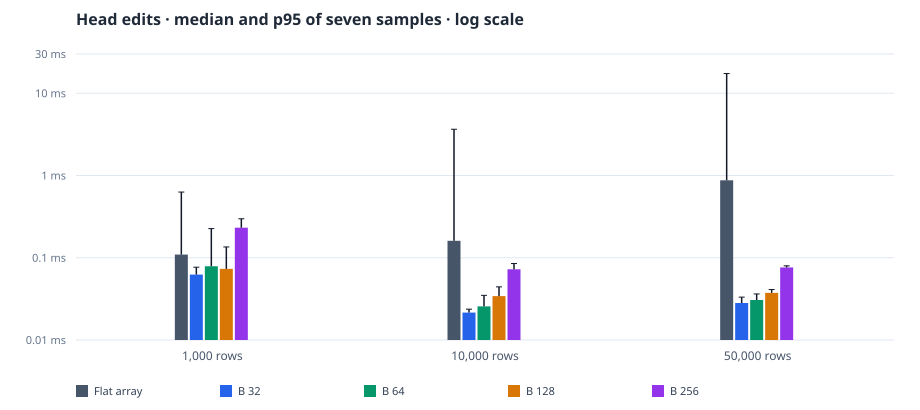

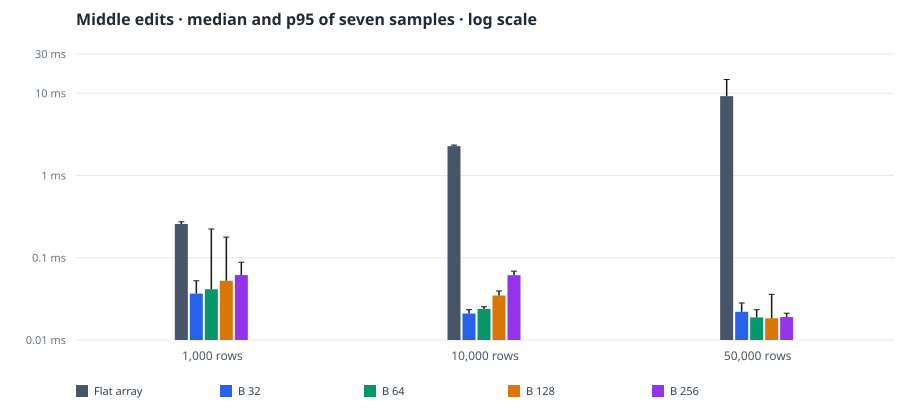

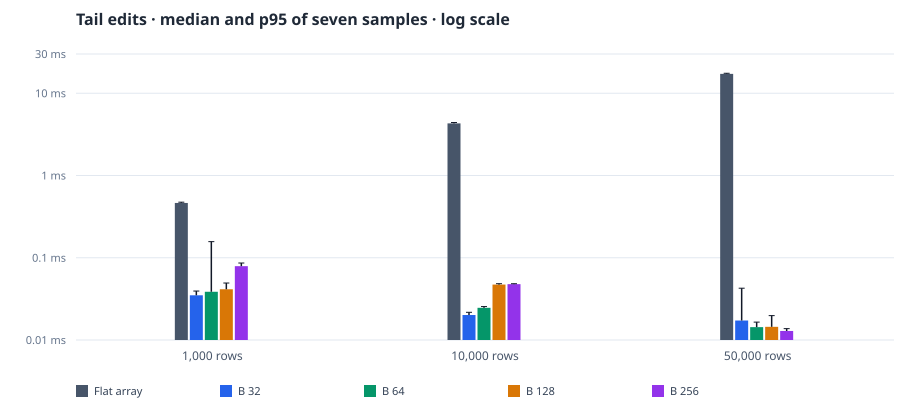

In [85]:
{
const bucketV1Manifest = JSON.parse(await Deno.readTextFile(
  "results/keyed-region-buckets-v1-manifest.json",
));
if (
  bucketV1Manifest.schemaVersion !== "keyed-region-buckets-v1-manifest" ||
  bucketV1Manifest.status !== "PASS" ||
  bucketV1Manifest.sampleCount !== 315 ||
  !bucketV1Manifest.allRunsPassedOrderAndIntegrityChecks
) throw new Error("Keyed-region buckets manifest contract failed");
for (const entry of bucketV1Manifest.entries) {
  const bytes = await Deno.readFile(entry.path);
  const digest = await crypto.subtle.digest(
    "SHA-256",
    bytes.slice().buffer as ArrayBuffer,
  );
  const sha256 = [...new Uint8Array(digest)].map((byte) =>
    byte.toString(16).padStart(2, "0")
  ).join("");
  if (bytes.length !== entry.bytes || sha256 !== entry.sha256) {
    throw new Error(`Keyed-region buckets input changed: ${entry.path}`);
  }
}
const bucketV1Data = JSON.parse(await Deno.readTextFile(
  "results/keyed-region-buckets-v1.json",
));
const bucketV1Prereq = JSON.parse(await Deno.readTextFile(
  "results/keyed-region-buckets-v1-preregistration.json",
));
if (
  bucketV1Data.samples.length !== bucketV1Manifest.sampleCount ||
  bucketV1Data.samples.some((sample: any) =>
    !Number.isFinite(sample.elapsedMs) || sample.elapsedMs < 0
  )
) throw new Error("Keyed-region buckets raw sample validation failed");
const bucketV1Arms = [
  { id: "flat-array", label: "Flat array", capacity: null, color: "#475569" },
  { id: "bucketed", label: "B 32", capacity: 32, color: "#2563eb" },
  { id: "bucketed", label: "B 64", capacity: 64, color: "#059669" },
  { id: "bucketed", label: "B 128", capacity: 128, color: "#d97706" },
  { id: "bucketed", label: "B 256", capacity: 256, color: "#9333ea" },
];
const bucketV1Quantile = (values: number[], p: number) => {
  const sorted = [...values].sort((a, b) => a - b);
  return sorted[Math.max(0, Math.ceil(p * sorted.length) - 1)];
};
const bucketV1Summary = (size: number, locality: string, arm: typeof bucketV1Arms[number]) => {
  const rows = bucketV1Data.samples.filter((sample: any) =>
    sample.size === size && sample.locality === locality &&
    sample.arm === arm.id && sample.bucketCapacity === arm.capacity
  );
  if (rows.length !== bucketV1Data.measuredSamples) {
    throw new Error(`Missing samples for ${size}/${locality}/${arm.label}`);
  }
  const p50s = rows.map((sample: any) => sample.elapsedMs);
  return {
    p50: bucketV1Quantile(p50s, 0.5),
    p95: bucketV1Quantile(p50s, 0.95),
    samples: rows,
  };
};
const bucketV1Table = [];
for (const size of bucketV1Data.sizes) {
  for (const locality of bucketV1Data.localities) {
    for (const arm of bucketV1Arms) {
      const summary = bucketV1Summary(size, locality, arm);
      const work = arm.id === "flat-array"
        ? {
          comparisonsPerMove: bucketV1Quantile(
            summary.samples.map((row: any) => row.comparisons / bucketV1Data.operationsPerSample), 0.5,
          ),
          rowShiftsPerMove: bucketV1Quantile(
            summary.samples.map((row: any) => row.rowShifts / bucketV1Data.operationsPerSample), 0.5,
          ),
        }
        : {
          bucketReadsPerMove: bucketV1Quantile(
            summary.samples.map((row: any) => row.bucketSlotReads / bucketV1Data.operationsPerSample), 0.5,
          ),
          bucketWritesPerMove: bucketV1Quantile(
            summary.samples.map((row: any) => row.bucketSlotWrites / bucketV1Data.operationsPerSample), 0.5,
          ),
          splits: bucketV1Quantile(summary.samples.map((row: any) => row.splits), 0.5),
          merges: bucketV1Quantile(summary.samples.map((row: any) => row.merges), 0.5),
        };
      bucketV1Table.push({
        size,
        locality,
        arm: arm.label,
        medianMs: Number(summary.p50.toFixed(4)),
        p95Ms: Number(summary.p95.toFixed(4)),
        ...work,
      });
    }
  }
}
console.log(JSON.stringify({
  question: bucketV1Prereq.question,
  claimBoundary: bucketV1Prereq.claimBoundary,
  environment: {
    deno: bucketV1Data.deno,
    platform: bucketV1Data.platform,
    collectedAt: bucketV1Data.collectedAt,
  },
  protocol: bucketV1Prereq.workload,
  summary: bucketV1Table,
}, null, 2));

const bucketV1Palette = Object.fromEntries(bucketV1Arms.map((arm) => [arm.label, arm.color]));
const bucketV1Plot = (locality: string) => {
  const width = 920;
  const height = 410;
  const left = 76;
  const right = 26;
  const top = 54;
  const bottom = 70;
  const chartHeight = height - top - bottom;
  const chartWidth = width - left - right;
  const floor = 0.01;
  const ceiling = 30;
  const logMin = Math.log10(floor);
  const logMax = Math.log10(ceiling);
  const y = (value: number) => top + chartHeight -
    (Math.log10(Math.max(floor, value)) - logMin) / (logMax - logMin) * chartHeight;
  const sizes = bucketV1Data.sizes as number[];
  const groupWidth = chartWidth / sizes.length;
  const barWidth = Math.min(15, groupWidth / (bucketV1Arms.length * 1.7));
  const parts = [
    `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${height}" viewBox="0 0 ${width} ${height}" role="img" aria-label="Keyed row move time for ${locality} locality, across list sizes and bucket capacities, on a logarithmic milliseconds axis" style="max-width:100%;height:auto;font-family:system-ui,sans-serif"><title>Keyed row move duration · ${locality} locality</title>`,
    `<rect width="100%" height="100%" fill="white"/>`,
    `<text x="${left}" y="25" font-size="16" font-weight="700" fill="#1f2937">${locality[0].toUpperCase()}${locality.slice(1)} edits · median and p95 of seven samples · log scale</text>`,
  ];
  for (const tick of [0.01, 0.1, 1, 10, 30]) {
    const yy = y(tick);
    parts.push(`<line x1="${left}" x2="${width - right}" y1="${yy}" y2="${yy}" stroke="#e2e8f0"/>`);
    parts.push(`<text x="${left - 10}" y="${yy + 4}" text-anchor="end" font-size="11" fill="#64748b">${tick} ms</text>`);
  }
  sizes.forEach((size, sizeIndex) => {
    const groupStart = left + groupWidth * sizeIndex;
    bucketV1Arms.forEach((arm, armIndex) => {
      const summary = bucketV1Summary(size, locality, arm);
      const x = groupStart + (groupWidth - bucketV1Arms.length * barWidth) / 2 + armIndex * barWidth;
      const p50Y = y(summary.p50);
      const p95Y = y(summary.p95);
      parts.push(`<rect x="${x}" y="${p50Y}" width="${barWidth - 2}" height="${top + chartHeight - p50Y}" fill="${arm.color}"><title>${size} rows · ${locality} · ${arm.label}: p50 ${summary.p50.toFixed(4)} ms, p95 ${summary.p95.toFixed(4)} ms</title></rect>`);
      const center = x + (barWidth - 2) / 2;
      parts.push(`<line x1="${center}" x2="${center}" y1="${p95Y}" y2="${p50Y}" stroke="#111827" stroke-width="1.5"/><line x1="${center - 3}" x2="${center + 3}" y1="${p95Y}" y2="${p95Y}" stroke="#111827"/>`);
    });
    parts.push(`<text x="${groupStart + groupWidth / 2}" y="${top + chartHeight + 20}" text-anchor="middle" font-size="12" fill="#475569">${size.toLocaleString()} rows</text>`);
  });
  const legendStart = left;
  bucketV1Arms.forEach((arm, index) => {
    const x = legendStart + index * 144;
    parts.push(`<rect x="${x}" y="${height - 25}" width="12" height="12" fill="${arm.color}"/><text x="${x + 18}" y="${height - 15}" font-size="11" fill="#334155">${arm.label}</text>`);
  });
  parts.push("</svg>");
  return Deno.jupyter.svg`${parts.join("")}`;
};
for (const locality of bucketV1Data.localities) {
  await Deno.jupyter.display(bucketV1Plot(locality));
}

}



### Experiment AU — bucketed regions versus an indexed flat array

This preregistered follow-up strengthens Experiment AT's flat-array control by maintaining a `Map<key, index>`. After each ordered `splice`, it updates the position map for the affected suffix. It repeats the same seeded 64 move-before operations at head, middle, and tail positions in lists of 1,000, 10,000, and 50,000 rows, with 32/64/128/256-entry buckets, two warmups, and seven measured samples per condition.

The timed measure includes array movement and position-index writes. The bucketed arm includes local bucket movement and offset writes. These counters are not identical machine operations, so keep them distinct. The harness verifies exact final order against the indexed-array reference and checks bucket integrity after each sample; the post-collection manifest hashes source, benchmark, preregistration, and records.

This is still a collection data-structure study. A bucket win here is a reason to integrate one candidate into the actual compiled keyed-region runtime and test its complete owner/VDOM/DOM cost against React Compiler, not proof that integration will win. The seven-sample p95 equals the maximum observed value.


{
  "question": "Do bounded buckets reduce edit time and maintained position-index work versus a flat ordered array with a key-to-index Map?",
  "claimBoundary": "Data-structure evidence only. No component owner, compiler graph, JSX, VDOM, DOM, React, layout, paint, or frame behavior is measured.",
  "environment": {
    "deno": {
      "deno": "2.6.3",
      "v8": "14.2.231.17-rusty",
      "typescript": "5.9.2"
    },
    "platform": "darwin-aarch64",
    "collectedAt": "2026-10-11T10:58:13.871Z"
  },
  "protocol": {
    "operation": "move an existing keyed row before a stable anchor",
    "sizes": [
      1000,
      10000,
      50000
    ],
    "localities": [
      "head",
      "middle",
      "tail"
    ],
    "bucketCapacities": [
      32,
      64,
      128,
      256
    ],
    "operationsPerSample": 64,
    "warmupSamples": 2,
    "measuredSamples": 7,
    "seed": 42182
  },
  "p95Note": "Nearest-rank p95 over seven samples is the maximum, not a stable tail estimate.",
  

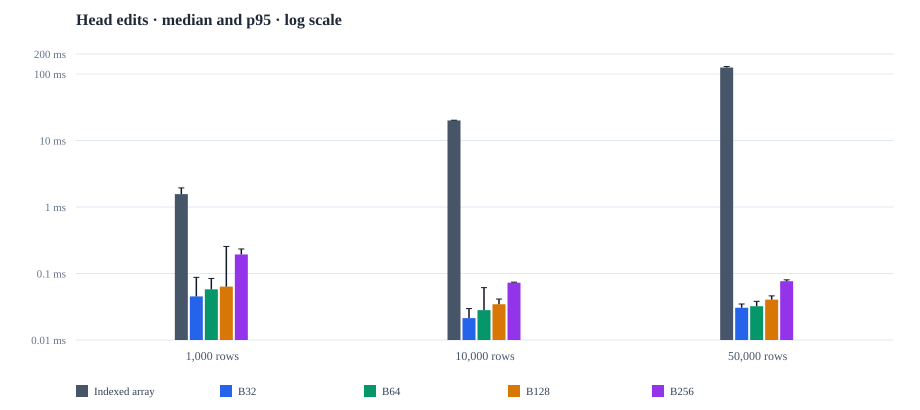

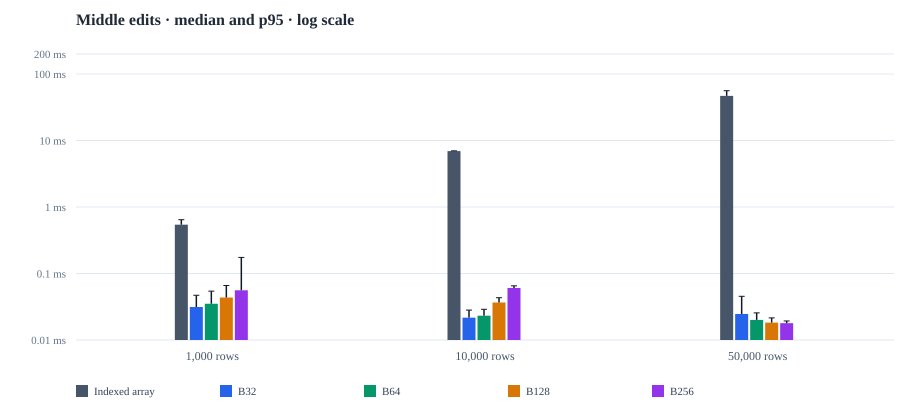

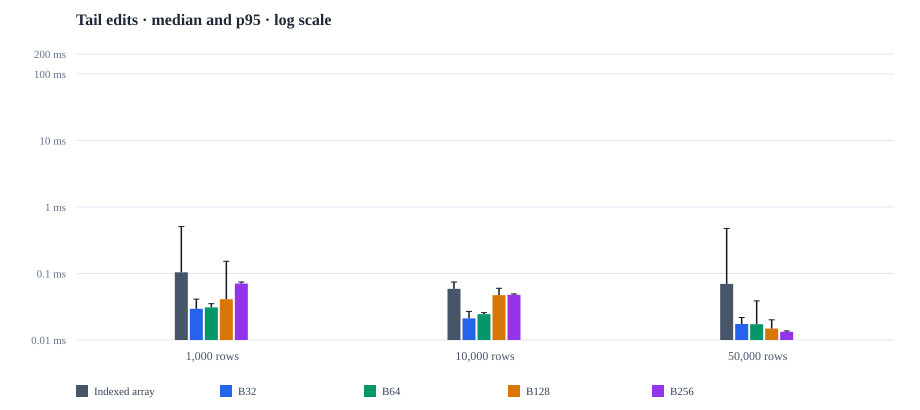

In [86]:
{
const bucketV2Manifest = JSON.parse(await Deno.readTextFile(
  "results/keyed-region-buckets-v2-manifest.json",
));
if (
  bucketV2Manifest.schemaVersion !== "keyed-region-buckets-v2-manifest" ||
  bucketV2Manifest.status !== "PASS" || bucketV2Manifest.sampleCount !== 315 ||
  !bucketV2Manifest.allRunsPassedOrderAndIntegrityChecks
) throw new Error("Keyed-region buckets V2 manifest contract failed");
for (const entry of bucketV2Manifest.entries) {
  const bytes = await Deno.readFile(entry.path);
  const digest = await crypto.subtle.digest("SHA-256", bytes.slice().buffer as ArrayBuffer);
  const sha256 = [...new Uint8Array(digest)].map((byte) =>
    byte.toString(16).padStart(2, "0")
  ).join("");
  if (bytes.length !== entry.bytes || sha256 !== entry.sha256) {
    throw new Error(`Keyed-region buckets V2 input changed: ${entry.path}`);
  }
}
const bucketV2Data = JSON.parse(await Deno.readTextFile(
  "results/keyed-region-buckets-v2.json",
));
const bucketV2Prereq = JSON.parse(await Deno.readTextFile(
  "results/keyed-region-buckets-v2-preregistration.json",
));
if (
  bucketV2Data.samples.length !== 315 ||
  bucketV2Data.samples.some((sample: any) =>
    !Number.isFinite(sample.elapsedMs) || sample.elapsedMs < 0
  )
) throw new Error("Keyed-region buckets V2 samples are invalid");
const bucketV2Arms = [
  { id: "indexed-array", label: "Indexed array", capacity: null, color: "#475569" },
  { id: "bucketed", label: "B32", capacity: 32, color: "#2563eb" },
  { id: "bucketed", label: "B64", capacity: 64, color: "#059669" },
  { id: "bucketed", label: "B128", capacity: 128, color: "#d97706" },
  { id: "bucketed", label: "B256", capacity: 256, color: "#9333ea" },
];
const bucketV2Quantile = (values: number[], p: number) => {
  const sorted = [...values].sort((a, b) => a - b);
  return sorted[Math.max(0, Math.ceil(p * sorted.length) - 1)];
};
const bucketV2Summary = (size: number, locality: string, arm: typeof bucketV2Arms[number]) => {
  const samples = bucketV2Data.samples.filter((sample: any) =>
    sample.size === size && sample.locality === locality && sample.arm === arm.id &&
    sample.bucketCapacity === arm.capacity
  );
  if (samples.length !== bucketV2Data.measuredSamples) {
    throw new Error(`Missing V2 samples for ${size}/${locality}/${arm.label}`);
  }
  return {
    samples,
    p50: bucketV2Quantile(samples.map((sample: any) => sample.elapsedMs), 0.5),
    p95: bucketV2Quantile(samples.map((sample: any) => sample.elapsedMs), 0.95),
  };
};
const bucketV2Table = [];
for (const size of bucketV2Data.sizes) {
  for (const locality of bucketV2Data.localities) {
    for (const arm of bucketV2Arms) {
      const summary = bucketV2Summary(size, locality, arm);
      const work = arm.id === "indexed-array"
        ? {
          indexWritesPerMove: bucketV2Quantile(
            summary.samples.map((sample: any) => sample.indexWrites / bucketV2Data.operationsPerSample), 0.5,
          ),
          rowShiftsPerMove: bucketV2Quantile(
            summary.samples.map((sample: any) => sample.rowShifts / bucketV2Data.operationsPerSample), 0.5,
          ),
        }
        : {
          bucketReadsPerMove: bucketV2Quantile(
            summary.samples.map((sample: any) => sample.bucketSlotReads / bucketV2Data.operationsPerSample), 0.5,
          ),
          bucketWritesPerMove: bucketV2Quantile(
            summary.samples.map((sample: any) => sample.bucketSlotWrites / bucketV2Data.operationsPerSample), 0.5,
          ),
          splits: bucketV2Quantile(summary.samples.map((sample: any) => sample.splits), 0.5),
          merges: bucketV2Quantile(summary.samples.map((sample: any) => sample.merges), 0.5),
        };
      bucketV2Table.push({
        size,
        locality,
        arm: arm.label,
        medianMs: Number(summary.p50.toFixed(4)),
        p95Ms: Number(summary.p95.toFixed(4)),
        ...work,
      });
    }
  }
}
console.log(JSON.stringify({
  question: bucketV2Prereq.question,
  claimBoundary: bucketV2Prereq.claimBoundary,
  environment: { deno: bucketV2Data.deno, platform: bucketV2Data.platform, collectedAt: bucketV2Data.collectedAt },
  protocol: bucketV2Prereq.workload,
  p95Note: "Nearest-rank p95 over seven samples is the maximum, not a stable tail estimate.",
  summary: bucketV2Table,
}, null, 2));

const bucketV2Plot = (locality: string) => {
  const width = 920, height = 410, left = 76, right = 26, top = 54, bottom = 70;
  const chartHeight = height - top - bottom, chartWidth = width - left - right;
  const floor = 0.01, ceiling = 200;
  const logMin = Math.log10(floor), logMax = Math.log10(ceiling);
  const y = (value: number) => top + chartHeight -
    (Math.log10(Math.max(floor, value)) - logMin) / (logMax - logMin) * chartHeight;
  const sizes = bucketV2Data.sizes as number[];
  const groupWidth = chartWidth / sizes.length;
  const barWidth = Math.min(15, groupWidth / (bucketV2Arms.length * 1.7));
  const parts = [
    `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${height}" viewBox="0 0 ${width} ${height}" role="img" aria-label="Indexed-array and bucketed ordered move time for ${locality} locality; logarithmic milliseconds scale"><title>Indexed array versus keyed buckets · ${locality} edits</title><rect width="100%" height="100%" fill="white"/>`,
    `<text x="${left}" y="25" font-size="16" font-weight="700" fill="#1f2937">${locality[0].toUpperCase()}${locality.slice(1)} edits · median and p95 · log scale</text>`,
  ];
  for (const tick of [0.01, 0.1, 1, 10, 100, 200]) {
    const yy = y(tick);
    parts.push(`<line x1="${left}" x2="${width - right}" y1="${yy}" y2="${yy}" stroke="#e2e8f0"/><text x="${left - 10}" y="${yy + 4}" text-anchor="end" font-size="11" fill="#64748b">${tick} ms</text>`);
  }
  sizes.forEach((size, sizeIndex) => {
    const groupStart = left + groupWidth * sizeIndex;
    bucketV2Arms.forEach((arm, armIndex) => {
      const summary = bucketV2Summary(size, locality, arm);
      const x = groupStart + (groupWidth - bucketV2Arms.length * barWidth) / 2 + armIndex * barWidth;
      const p50Y = y(summary.p50), p95Y = y(summary.p95), center = x + (barWidth - 2) / 2;
      parts.push(`<rect x="${x}" y="${p50Y}" width="${barWidth - 2}" height="${top + chartHeight - p50Y}" fill="${arm.color}"><title>${size} rows · ${locality} · ${arm.label}: p50 ${summary.p50.toFixed(4)} ms; p95 ${summary.p95.toFixed(4)} ms</title></rect><line x1="${center}" x2="${center}" y1="${p95Y}" y2="${p50Y}" stroke="#111827" stroke-width="1.5"/><line x1="${center - 3}" x2="${center + 3}" y1="${p95Y}" y2="${p95Y}" stroke="#111827"/>`);
    });
    parts.push(`<text x="${groupStart + groupWidth / 2}" y="${top + chartHeight + 20}" text-anchor="middle" font-size="12" fill="#475569">${size.toLocaleString()} rows</text>`);
  });
  bucketV2Arms.forEach((arm, index) => {
    const x = left + index * 144;
    parts.push(`<rect x="${x}" y="${height - 25}" width="12" height="12" fill="${arm.color}"/><text x="${x + 18}" y="${height - 15}" font-size="11" fill="#334155">${arm.label}</text>`);
  });
  parts.push("</svg>");
  return Deno.jupyter.svg`${parts.join("")}`;
};
for (const locality of bucketV2Data.localities) await Deno.jupyter.display(bucketV2Plot(locality));

}



### Experiment AV — parallel-array buckets and the keyed VDOM hybrid

This exploratory three-process Node mechanism study extends the indexed-flat-array comparison with a bucket candidate that stores keys and values in parallel JavaScript arrays. Each process ran 315 samples per arm over move-to-tail and full-scan traces at 1k, 10k, and 50k rows. The chart shows median-of-process-medians at 50k on a logarithmic millisecond scale. The scan reads ordered keys and values only; no props, graph dispatch, host mutation, heap, garbage collection, or hardware cache misses are measured.
The existing object-backed buckets are the current sparse-edit candidate: they outperform the indexed array and parallel-array candidate on 50k head/middle moves. Full sequential scan is similar across layouts. Keep SoA for dense numeric trait/prop data, use object buckets for sparse ordered edits, and preserve the semantic VDOM plus generic reconciliation fallback. The browser implementation smoke checks identity and output parity but is excluded from timing claims.
The integrated path remains incomplete for product use: V3 still enumerates input children for owner validation/planning, and the specialized VDOM delta route is guarded when compiled/direct bindings need subscription-index maintenance. The next gate is compiler-emitted sparse keyed operations consumed by owner and binding indexes without full sibling scans, tested alongside frame-rate prop updates. This experiment does not establish an end-to-end React win.
Raw process records and the derived summary are under `results/keyed-region-columnar-layout-v1/`. Rebuild the summary with `node scripts/benchmark_keyed_region_columnar_v1.mjs` and `node scripts/summarize_keyed_region_columnar_v1.mjs`, then regenerate and execute this notebook cell.


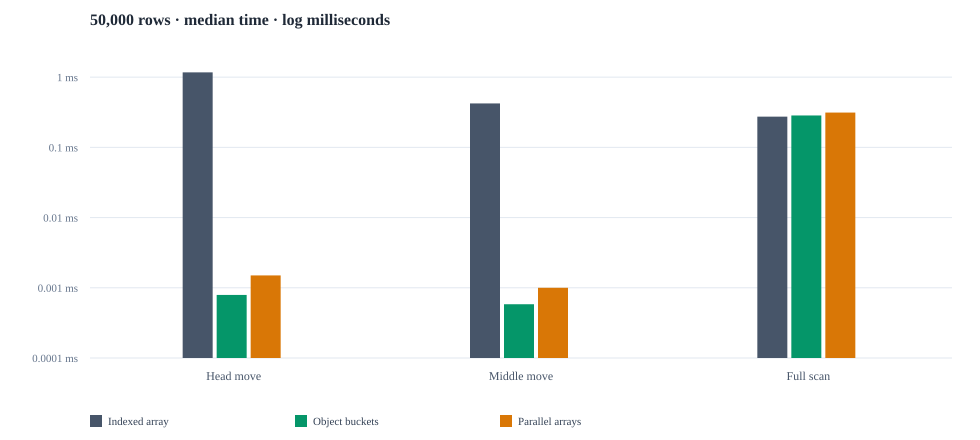

In [ ]:
const columnarReplications = await Promise.all([1, 2, 3].map(async (replication) =>
  JSON.parse(await Deno.readTextFile(
    `results/keyed-region-columnar-layout-v1/replication-${replication}.json`,
  ))
));
const columnarSummary = JSON.parse(await Deno.readTextFile(
  "results/keyed-region-columnar-layout-v1/summary.json",
));
const columnarArms = [
  { id: "array-map", label: "Indexed array", color: "#475569" },
  { id: "object-buckets", label: "Object buckets", color: "#059669" },
  { id: "columnar-buckets", label: "Parallel arrays", color: "#d97706" },
];
if (
  columnarReplications.length !== 3 ||
  columnarReplications.some((run: any) =>
    run.schemaVersion !== "keyed-region-columnar-layout-v1" ||
    run.status !== "PASS" || run.measuredOperationsPerArm !== 315
  ) || columnarSummary.status !== "EXPLORATORY_PASS"
) throw new Error("Columnar keyed-region replication contract failed");
const columnarPlot = () => {
  const width = 980, height = 440, left = 90, right = 28, top = 56, bottom = 82;
  const scenarios = ["head-to-tail", "middle-to-tail", "full-sequential-scan"];
  const labels = ["Head move", "Middle move", "Full scan"];
  const floor = 0.0001, ceiling = 2;
  const y = (value: number) => top + (height - top - bottom) *
    (Math.log10(ceiling) - Math.log10(Math.max(floor, value))) /
    (Math.log10(ceiling) - Math.log10(floor));
  const parts = [
    `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${height}" viewBox="0 0 ${width} ${height}" role="img" aria-label="50,000-row keyed-region layout times on logarithmic scale"><title>50,000-row keyed region layout · median time</title><rect width="100%" height="100%" fill="white"/>`,
    `<text x="${left}" y="25" font-size="16" font-weight="700" fill="#1f2937">50,000 rows · median time · log milliseconds</text>`,
  ];
  for (const tick of [0.0001, 0.001, 0.01, 0.1, 1]) {
    const yy = y(tick);
    parts.push(`<line x1="${left}" x2="${width - right}" y1="${yy}" y2="${yy}" stroke="#e2e8f0"/><text x="${left - 12}" y="${yy + 4}" text-anchor="end" font-size="11" fill="#64748b">${tick} ms</text>`);
  }
  const groupWidth = (width - left - right) / scenarios.length;
  const barWidth = 34;
  scenarios.forEach((scenario, scenarioIndex) => {
    const cell = columnarSummary.cells.find((entry: any) =>
      entry.size === 50000 && entry.scenario === scenario
    );
    if (!cell) throw new Error(`Missing 50k scenario: ${scenario}`);
    const start = left + groupWidth * scenarioIndex;
    columnarArms.forEach((arm, armIndex) => {
      const value = cell.arms[arm.id].medianOfProcessMediansMs;
      const x = start + groupWidth / 2 - 1.5 * barWidth + armIndex * barWidth;
      const yy = y(value);
      parts.push(`<rect x="${x}" y="${yy}" width="${barWidth - 4}" height="${top + (height - top - bottom) - yy}" fill="${arm.color}"><title>${labels[scenarioIndex]} · ${arm.label}: ${value.toFixed(4)} ms</title></rect>`);
    });
    parts.push(`<text x="${start + groupWidth / 2}" y="${height - bottom + 22}" text-anchor="middle" font-size="12" fill="#475569">${labels[scenarioIndex]}</text>`);
  });
  columnarArms.forEach((arm, index) => {
    const x = left + index * 205;
    parts.push(`<rect x="${x}" y="${height - 25}" width="12" height="12" fill="${arm.color}"/><text x="${x + 18}" y="${height - 15}" font-size="11" fill="#334155">${arm.label}</text>`);
  });
  parts.push("</svg>");
  return Deno.jupyter.svg`${parts.join("")}`;
};
console.log(JSON.stringify({
  replications: columnarSummary.replications,
  aggregation: columnarSummary.aggregation,
  size: 50000,
  mediansMs: columnarSummary.cells.filter((entry: any) => entry.size === 50000)
    .map((entry: any) => ({
      scenario: entry.scenario,
      ...Object.fromEntries(columnarArms.map((arm) => [
        arm.id,
        entry.arms[arm.id].medianOfProcessMediansMs,
      ])),
    })),
  limitations: columnarSummary.limitations,
}, null, 2));
await Deno.jupyter.display(columnarPlot());



### Mixed real-time JSX workload — preregistered production comparison

This is the combined workload requested after the fixed-topology per-frame studies: every measured RAF updates three declarative props for every entity, and every 30th frame removes eight keys, inserts eight fresh keys, and rotates retained keys. React 19.3 + React Compiler is compared with the retained VDOM runtime's scalar source bindings, using the same benchmark-owned data and DOM output contract. The 128, 512, and 1,024 entity cases each have five page-load pairs. Each page warms 60 frames and measures 240; the collection is 30 visible production page loads and 7,200 frame observations. The page is the replication unit, with RAFs nested inside it.

The [preregistration](./results/mixed-realtime-v1-preregistration.json) froze the schedule, correctness requirements, and decision rule before the production run. The [manifest](./results/mixed-realtime-v1-manifest.json) contains SHA-256 hashes for all 30 records and source-lock audit details. Every output, retained-node identity, commit-coverage, visibility, sample-count, and production-build check passed. A post-run documentation-integrity issue was found: mixed-realtime-study.md, which appears in the preregistered source lock, was replaced by this results report, and the original protocol file was not recovered. Its hash therefore does not match. The preregistration JSON retains the schedule and decision rule; benchmark code and the other ten frozen inputs still match. The protocol-file lock is incomplete, and this deviation is reported explicitly. The result does **not** meet the performance criterion: the runtime must show a paired geometric-mean median ratio ≤0.80 at two sizes, and median p95 ratio ≤1.10 at every size. The 128 case is essentially tied; 512 and 1,024 favor React and miss the p95 guard. This is counterevidence to the claim that the current scalar binding path is already a faster mixed real-time renderer.

The study is deliberately scoped to an update-kernel comparison: the runtime arm consumes retained scalar source bindings rather than the planned general OXC compiler output, and neither arm measures layout, paint, GPU work, or physical presentation. RAF callback intervals are scheduling diagnostics, not smoothness evidence. These results identify the combined workload as a next optimization gate: avoid repeated per-entity/per-prop dispatch as entity count rises, then rerun this frozen comparison after a changed implementation with a new preregistration. Full methods, table, and interpretation are in [the study report](./mixed-realtime-study.md).



In [ ]:
const prereg = JSON.parse(await Deno.readTextFile("results/mixed-realtime-v1-preregistration.json"));
const manifest = JSON.parse(await Deno.readTextFile("results/mixed-realtime-v1-manifest.json"));
const summary = JSON.parse(await Deno.readTextFile("results/mixed-realtime-v1-summary.json"));
if (prereg.status !== "PREREGISTERED" || !manifest.status.startsWith("PASS") || manifest.files.length !== 30 || summary.pages !== 30) throw new Error("Mixed realtime v1 manifest is incomplete");
const hash = async (bytes: Uint8Array) => [...new Uint8Array(await crypto.subtle.digest("SHA-256", bytes))].map((b)=>b.toString(16).padStart(2,"0")).join("");
for (const locked of manifest.sourceLock.filter((item:any)=>item.matches)) {
  const bytes=await Deno.readFile(locked.path);
  if(bytes.length!==locked.bytes || await hash(bytes)!==locked.sha256) throw new Error(`Frozen source changed: ${locked.path}`);
}
if (manifest.sourceLockDrift?.length) console.warn("Protocol-file drift after collection:", manifest.sourceLockDrift.map((x:any)=>x.path).join(", "), "The preregistration JSON and locked benchmark sources remain available; do not call the complete source lock intact.");
const pages:any[]=[];
for(const entry of manifest.files){
  const bytes=await Deno.readFile(`results/mixed-realtime-v1/${entry.file}`);
  if(await hash(bytes)!==entry.sha256) throw new Error(`Raw record hash mismatch: ${entry.file}`);
  const page=JSON.parse(new TextDecoder().decode(bytes));
  const expected=prereg.schedule.find((x:any)=>x.trialId===page.trialId);
  if(!expected || page.sequence!==expected.sequence || page.arm!==expected.arm || page.entityCount!==expected.entityCount || page.replication!==expected.replication || page.status!=="PASS" || !page.outputParity || !page.stableNodeCount || !page.structureIdentityPass || !page.completeCommitCoverage || page.samples.length!==240 || page.structuralSamples!==8 || page.buildMode!=="production") throw new Error(`Raw record contract failed: ${entry.file}`);
  pages.push(page);
}
if(pages.length!==30 || pages.reduce((n,p)=>n+p.samples.length,0)!==7200) throw new Error("Unexpected sample count");
console.log(`Verified ${pages.length} visible production page loads, ${pages.length*240} frame samples, ${manifest.sourceLockValidated ?? manifest.sourceLock.filter((x:any)=>x.matches).length}/${manifest.sourceLock.length} frozen source files, and every raw SHA-256.`);
console.log("entity count | React median/p95 | runtime median/p95 | paired median ratio GM | median p95 ratio | structural p95 React/runtime");
for(const m of summary.metrics){
  const p=summary.paired.find((x:any)=>x.entityCount===m.entityCount);
  console.log(`${m.entityCount} | ${m.arms.react.medianPageMedianMs.toFixed(2)}/${m.arms.react.medianPageP95Ms.toFixed(2)} ms | ${m.arms.runtime.medianPageMedianMs.toFixed(2)}/${m.arms.runtime.medianPageP95Ms.toFixed(2)} ms | ${p.geometricMeanMedianRatio.toFixed(3)} | ${p.medianP95Ratio.toFixed(3)} | ${m.arms.react.medianStructuralP95Ms.toFixed(2)}/${m.arms.runtime.medianStructuralP95Ms.toFixed(2)} ms`);
}
console.log(`Preregistered decision: ${summary.decision.preregisteredSuccess ? "PASS" : "FAIL"}. Correctness contracts ${summary.decision.allContracts ? "pass" : "fail"}; median threshold at ${summary.decision.sizesMeetingGeomeanThreshold}/${summary.decision.requiredSizes} sizes; p95 guard ${summary.decision.p95GuardPassed ? "passes" : "fails"}.`);
const metricKeys=["medianPageMedianMs","medianPageP95Ms","medianStructuralP95Ms"];
const metricNames=["All-frame update→commit median","All-frame update→commit p95","Structural-frame update→commit p95"];
const colors={react:"#d97706",runtime:"#2563eb"};
for(let k=0;k<metricKeys.length;k++){
  const width=900,height=310,left=190,right=70,top=48,bottom=40;
  const rows=summary.metrics.flatMap((m:any)=>[{label:`${m.entityCount} · React`,value:m.arms.react[metricKeys[k]],color:colors.react},{label:`${m.entityCount} · Runtime`,value:m.arms.runtime[metricKeys[k]],color:colors.runtime}]);
  const max=Math.max(...rows.map((x:any)=>x.value))*1.12;
  const rowH=(height-top-bottom)/rows.length;
  const body=[`<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${height}" viewBox="0 0 ${width} ${height}" role="img" aria-label="${metricNames[k]}" style="max-width:100%;height:auto;font-family:system-ui,sans-serif">`,`<title>${metricNames[k]}</title>`,`<text x="${width/2}" y="25" text-anchor="middle" font-size="17" font-weight="650" fill="#111827">${metricNames[k]} · lower is better</text>`];
  for(let tick=0;tick<=4;tick++){const value=max*tick/4,x=left+(width-left-right)*tick/4;body.push(`<line x1="${x}" y1="${top}" x2="${x}" y2="${height-bottom}" stroke="#e5e7eb"/><text x="${x}" y="${height-14}" text-anchor="middle" font-size="11" fill="#6b7280">${value.toFixed(1)} ms</text>`)}
  rows.forEach((r:any,i:number)=>{const y=top+i*rowH+4,w=(width-left-right)*r.value/max;body.push(`<text x="${left-10}" y="${y+rowH*.57}" text-anchor="end" font-size="12" fill="#374151">${r.label}</text><rect x="${left}" y="${y}" width="${w}" height="${rowH*.68}" rx="3" fill="${r.color}"/><text x="${left+w+7}" y="${y+rowH*.55}" font-size="11" fill="#111827">${r.value.toFixed(2)}</text>`)});
  body.push(`<text x="${width/2}" y="${height-1}" text-anchor="middle" font-size="10" fill="#6b7280">Median of five page-level summaries; page load is the replication unit.</text></svg>`);
  await Deno.jupyter.display(Deno.jupyter.svg`${body.join("")}`);
}



The async frontier study is now complete. The original motivation, task graph, and decision rules remain in the next code/diagram cell; the frozen corrected v2 protocol and source hashes are in [async-dag-frontier-v2-protocol.md](./async-dag-frontier-v2-protocol.md). Results are summarized in the following section and raw records are preserved under `results/async-dag-frontier-v2/`.


In [ ]:
const protocol = await Deno.readTextFile("async-dag-frontier-protocol.md");
for (const phrase of ["React, sequential loader control", "React, explicit preload", "Compiled DAG", "one animation-frame interval", "Explicit speculation is a separate follow-up"]) {
  if (!protocol.includes(phrase)) throw new Error(`Async DAG frontier protocol missing: ${phrase}`);
}
console.log("Protocol draft: three arms (serial control, equal-preload React, compiled DAG); page-level replication; starts/dependencies/commit measured; speculation deferred to a separate gate.");
const svg = `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="440" viewBox="0 0 1060 440" role="img" aria-labelledby="dag-frontier-title dag-frontier-desc" style="max-width:100%;height:auto;font-family:system-ui,sans-serif"><title id="dag-frontier-title">Candidate async DAG: ready branches launch without waiting for siblings</title><desc id="dag-frontier-desc">Profile, feed and recommendations launch from known inputs. Profile summary depends on profile. Feed annotations depend on profile and feed. All required results join at a reveal group.</desc><defs><marker id="dag-arrow" markerWidth="9" markerHeight="9" refX="8" refY="4.5" orient="auto"><path d="M0,0 L9,4.5 L0,9 z" fill="#64748b"/></marker></defs><text x="530" y="30" text-anchor="middle" font-size="20" font-weight="700" fill="#111827">Known frontier launches now; hard dependencies wait for their inputs</text><rect x="24" y="155" width="154" height="86" rx="12" fill="#f1f5f9" stroke="#64748b" stroke-width="2"/><text x="101" y="190" text-anchor="middle" font-size="15" font-weight="650" fill="#0f172a">Candidate</text><text x="101" y="213" text-anchor="middle" font-size="13" fill="#475569">snapshot</text><g stroke="#64748b" stroke-width="2" fill="none" marker-end="url(#dag-arrow)"><path d="M178 175 C205 175 202 86 232 86"/><path d="M178 198 L232 198"/><path d="M178 221 C205 221 202 310 232 310"/><path d="M380 86 L476 86"/><path d="M380 198 C423 198 428 236 476 236"/><path d="M380 86 C423 86 428 236 476 236"/><path d="M380 310 C620 310 630 236 700 236"/><path d="M624 86 C650 86 662 184 700 184"/><path d="M624 236 L700 236"/><path d="M624 236 C650 236 662 286 700 286"/><path d="M380 198 C520 198 590 184 700 184"/></g><g><rect x="232" y="54" width="148" height="64" rx="10" fill="#dbeafe" stroke="#2563eb"/><text x="306" y="82" text-anchor="middle" font-size="14" font-weight="650" fill="#1e3a8a">Profile request</text><text x="306" y="102" text-anchor="middle" font-size="12" fill="#1e40af">starts immediately</text><rect x="232" y="166" width="148" height="64" rx="10" fill="#dcfce7" stroke="#16a34a"/><text x="306" y="194" text-anchor="middle" font-size="14" font-weight="650" fill="#14532d">Feed request</text><text x="306" y="214" text-anchor="middle" font-size="12" fill="#166534">starts immediately</text><rect x="232" y="278" width="148" height="64" rx="10" fill="#fef3c7" stroke="#d97706"/><text x="306" y="306" text-anchor="middle" font-size="14" font-weight="650" fill="#78350f">Recommendations</text><text x="306" y="326" text-anchor="middle" font-size="12" fill="#92400e">starts immediately</text><rect x="476" y="54" width="148" height="64" rx="10" fill="#ede9fe" stroke="#7c3aed"/><text x="550" y="82" text-anchor="middle" font-size="14" font-weight="650" fill="#4c1d95">Profile summary</text><text x="550" y="102" text-anchor="middle" font-size="12" fill="#5b21b6">waits for profile</text><rect x="476" y="204" width="148" height="64" rx="10" fill="#ede9fe" stroke="#7c3aed"/><text x="550" y="232" text-anchor="middle" font-size="14" font-weight="650" fill="#4c1d95">Feed annotations</text><text x="550" y="252" text-anchor="middle" font-size="12" fill="#5b21b6">waits for profile + feed</text><rect x="700" y="164" width="164" height="126" rx="12" fill="#fce7f3" stroke="#db2777" stroke-width="2"/><text x="782" y="211" text-anchor="middle" font-size="15" font-weight="700" fill="#831843">Reveal group</text><text x="782" y="235" text-anchor="middle" font-size="12" fill="#9d174d">one consistent version</text><text x="782" y="256" text-anchor="middle" font-size="12" fill="#9d174d">previous UI stays mounted</text><text x="530" y="390" text-anchor="middle" font-size="13" fill="#475569">Async overlap is not parallel JavaScript; worker execution is a separate CPU policy.</text></g></svg>`;
Deno.jupyter.svg`${svg}`;



### Async dependency frontier — v2 browser results

The preregistered v2 run completed **30/30 paired page blocks** in visible production Chrome 155. The compiled DAG and explicit-preload React both launched the three known-key requests together and respected all hard dependencies. The DAG preserved the previous keyed DOM while pending and committed one complete target model in every block.

| Arm | Median | p95 |
| --- | ---: | ---: |
| Sequential React loader control | 364.4 ms | 385.3 ms |
| React with explicit preload | 143.6 ms | 152.1 ms |
| Compiled DAG | 144.7 ms | 151.2 ms |

The paired median DAG/sequential ratio is **0.397** (a 60.3% reduction), clearing the preregistered 20% threshold. The paired median DAG/preloaded-React ratio is **1.000**; DAG p95 is **99.4%** of React p95, inside the 110% guard. This supports automatic dependency discovery and waterfall avoidance; it does not show a meaningful speed advantage over React already given equal preload knowledge.

Mechanism checks passed in 30/30 blocks: all independent DAG requests started within 16.7 ms (median start gap 0.7 ms); every dependent task started within 16.7 ms after its final prerequisite (maximum observed lag 0.4 ms); there were no hard-edge violations. These requests overlap on the network; JavaScript callbacks remain serial on the main thread.

The earlier v1 attempt is preserved but excluded: its initial React boundary readiness race caused 20/30 pending-view checks to sample the visible fallback. V2 awaits the initial layout commit and collects fresh records. Limits: one machine/browser profile, synthetic delayed I/O, and completion-to-layout-commit timing; no paint/scroll smoothness, CPU-heavy work, cancellation, speculative fetch, worker execution, server streaming, or hydration was tested. See [the frozen v2 protocol](./async-dag-frontier-v2-protocol.md), [raw data and preregistration](./results/async-dag-frontier-v2/), and [appendix section 8.20](./empirical-appendix.md#820-preregistered-async-dag-frontier-study-v2).



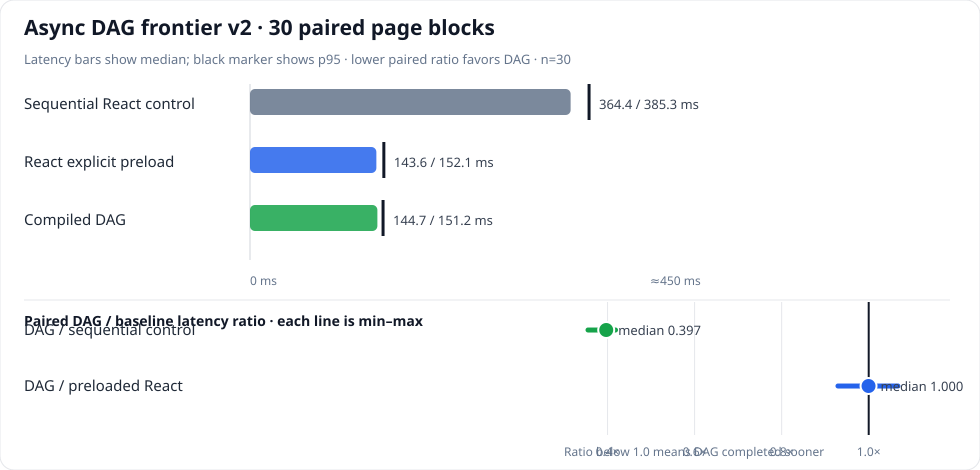

In [ ]:
const frontier = JSON.parse(await Deno.readTextFile("results/async-dag-frontier-v2/summary.json"));
const armRows = [
  { id: "serial", label: "Sequential React control", color: "#64748b" },
  { id: "reactPreload", label: "React explicit preload", color: "#2563eb" },
  { id: "dag", label: "Compiled DAG", color: "#16a34a" },
];
const chartWidth = 980;
const chartHeight = 470;
const latencyScale = 0.88;
const latencyRows = armRows.map((arm, index) => {
  const y = 104 + index * 58;
  const stats = frontier.latency[arm.id];
  const medianWidth = stats.medianMs * latencyScale;
  const p95X = 250 + stats.p95Ms * latencyScale;
  return `<text x="24" y="${y + 5}" font-size="15" fill="#1f2937">${arm.label}</text><rect x="250" y="${y - 15}" width="${medianWidth}" height="26" rx="5" fill="${arm.color}" opacity="0.85"/><line x1="${p95X}" y1="${y - 20}" x2="${p95X}" y2="${y + 16}" stroke="#111827" stroke-width="3"/><text x="${p95X + 10}" y="${y + 5}" font-size="13" fill="#374151">${stats.medianMs.toFixed(1)} / ${stats.p95Ms.toFixed(1)} ms</text>`;
});
const pairRows = [
  { key: "dagVsSequentialControl", label: "DAG / sequential control", color: "#16a34a" },
  { key: "dagVsReactPreload", label: "DAG / preloaded React", color: "#2563eb" },
];
const ratioMin = 0.30;
const ratioMax = 1.15;
const ratioX = (value: number) => 564 + ((value - ratioMin) / (ratioMax - ratioMin)) * 370;
const ratioRows = pairRows.map((pair, index) => {
  const y = 330 + index * 56;
  const ratios = frontier.pairedComparisons[pair.key].allRatios.toSorted((a: number, b: number) => a - b);
  const lo = ratios[0], hi = ratios[ratios.length - 1];
  const mid = frontier.pairedComparisons[pair.key].pairedMedianRatio;
  return `<text x="24" y="${y + 5}" font-size="15" fill="#1f2937">${pair.label}</text><line x1="${ratioX(lo)}" y1="${y}" x2="${ratioX(hi)}" y2="${y}" stroke="${pair.color}" stroke-width="5" stroke-linecap="round"/><circle cx="${ratioX(mid)}" cy="${y}" r="8" fill="${pair.color}" stroke="white" stroke-width="2"/><text x="${ratioX(mid) + 12}" y="${y + 5}" font-size="13" fill="#374151">median ${mid.toFixed(3)}</text>`;
});
const ratioTicks = [0.4, 0.6, 0.8, 1.0].map((value) => `<line x1="${ratioX(value)}" y1="302" x2="${ratioX(value)}" y2="435" stroke="${value === 1 ? "#111827" : "#e5e7eb"}" stroke-width="${value === 1 ? 2 : 1}"/><text x="${ratioX(value)}" y="456" text-anchor="middle" font-size="12" fill="#64748b">${value.toFixed(1)}×</text>`).join("");
const svg = `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="470" viewBox="0 0 980 470" role="img" aria-labelledby="frontier-title frontier-desc" style="max-width:100%;height:auto;font-family:system-ui,sans-serif"><title id="frontier-title">Async DAG frontier v2: latency and paired ratios</title><desc id="frontier-desc">Across 30 browser page blocks, median and p95 completion-to-layout-commit times are shown beside the distribution range and paired median ratio for the DAG against the serial control and preloaded React.</desc><rect x="0" y="0" width="980" height="470" rx="14" fill="#fff" stroke="#e5e7eb"/><text x="24" y="35" font-size="21" font-weight="700" fill="#111827">Async DAG frontier v2 · 30 paired page blocks</text><text x="24" y="64" font-size="13" fill="#64748b">Latency bars show median; black marker shows p95 · lower paired ratio favors DAG · n=30</text><line x1="250" y1="84" x2="250" y2="260" stroke="#d1d5db"/><text x="250" y="285" font-size="12" fill="#64748b">0 ms</text><text x="650" y="285" font-size="12" fill="#64748b">≈450 ms</text>${latencyRows.join("")}<line x1="24" y1="300" x2="950" y2="300" stroke="#e5e7eb"/><text x="24" y="326" font-size="14" font-weight="650" fill="#111827">Paired DAG / baseline latency ratio · each point range is min–max</text>${ratioTicks}${ratioRows.join("")}<text x="564" y="456" font-size="12" fill="#64748b">Ratio below 1.0 means DAG completed sooner</text></svg>`;
Deno.jupyter.svg`${svg}`;



### Async store action-log runtime prototype

The runtime now has a host-independent action-log store based on the local userland implementation and the React fork's `use-store-queue` branch. Every root render can pin one projected store snapshot so all read sites see the same value; a version check rejects stale work before any host root is patched. Selector history advances only after host commit. Promise values remain ordinary store values.

`AsyncVDOMTransitionRuntime` accepts explicit store transition IDs and declared store read sets, provides each root's pinned snapshots to candidate tree construction, and validates the complete read set before host commit. This is per-root consistency: roots may show different committed versions during a transition. A stale candidate is currently rejected; automatic rebuild/retry is still open.

This is an implementation milestone, not a result. No test suite, type check, or browser run has been performed for the new snapshot path. The next gate is to port the userland and React-fork cases for urgent rebasing, action order, stale snapshot rejection/retry, roots joining pending work, promise-valued state, selector previous-value chains, supersession, and late completion. See [the implementation protocol](./async-store-transition-protocol.md) and [source](./src/async_store_runtime.ts).


### Async transition stress target

The target interaction is optimistic input plus timer-backed transitions overlapping on one root and across forked roots. One startup placeholder is allowed; after first reveal, pending work keeps the mounted UI and uses local pending status. The fixture includes timer rollback, out-of-order results, fork-only transitions, and a 520 ms auto-trigger loop.

The current browser page exercises overlapping action-log store updates and per-root snapshots through retained VDOM commits. It is a target fixture, not measured evidence, and it does not yet exercise concurrent async task candidates or a Suspense implementation. The current coordinator supersedes candidates that overlap on one root; this is a product gap to solve. See [the stress protocol](./async-transition-stress-v1-protocol.md), [fixture page](./async-transition-stress-v1.html), and [source](./src/browser/async_transition_stress_v1.tsx).


## Current compiler-first runtime: frozen dense qualification (14 October 2026)

The current owner-kernel candidate **fails** both preregistered speed gates in the frozen 30-page production comparison with React 19.3 + React Compiler. Native/React paired median ratios are **1.0637 / 1.3224 / 1.4963** at 128 / 1,024 / 10,000 rows; paired p95 ratios are **1.0223 / 1.2437 / 1.0890**. All raw-data, source/build/served-asset, output, order, identity, lifecycle, and disposal checks pass. The timer covers setter dispatch plus synchronous commit, excluding dirty selection, RAF wait, inspection, paint, and presentation. The original React denominator remains fixed.

A separate 24-page archived-source diagnostic identifies disjoint gross phases and counts. An 18-page, six-order native control at 1,024 validates page protocol and marks, but fails its preregistered stability screen despite a descriptively stable **0.4975 ms** median of six marked dispatch page medians. It provides no semantically removable lower bound or new-cost upper bound. The conditional 10,000 control and favorable retries stop; dense physical selection remains **HOLD**. The live adjacent-token patch was not in these builds and is unqualified. Necessary live validation, accepted per-root history, source visibility, and partial host-failure behavior remain obligations.

[Original analysis](results/current-owner-kernel-headless-v1/analysis.json) · [independent verification](results/current-owner-kernel-headless-v1/verification.json) · [aggregate review](.cache/dense-causal-ledger-v1/aggregate-review/report.md) · [18-page report](.cache/dense-causal-control-v1/gates/recording-1024/report.md) · [final disposition](.cache/dense-causal-control-v1/final-disposition-review.md). Recording B addresses structural locality as a separate product gate; semantic contract work does not requalify dense speed.


## Counterbalanced dense dispatch control: descriptive page evidence

The frozen [targeted analysis](.cache/dense-causal-control-v1/gates/recording-1024/analysis-1024.json) contains six independent fresh-page blocks at 1,024 native rows. Every block has one original, one diagnostic-off, and one diagnostic-on page; all six orders were predeclared and used once. Each page has 60 warmup and 240 measured frames. All 18 receipts pass source/build/served-asset, output, identity, lifecycle, cleanup, and mark checks. The [24-page aggregate](.cache/dense-causal-ledger-v1/aggregate-review/report.md) and [original 30-page qualification](results/current-owner-kernel-headless-v1/analysis.json) remain separate evidence.

The SVG below plots **differences of page medians** within each block: `off − original` and `on − off`. A point is one fresh-page block, not a frame or confidence interval. The negative and positive controls include build shape, JIT, probe, and environment variation; they are not guaranteed phase-overhead corrections. The median of six `on` dispatch page medians is 0.4975 ms, but the preregistered median and p95 control width/magnitude screens fail. The analyzer returns `STOP_10000_UNRESOLVED` with `decisionGrade: false`. No 10,000 control, favorable retry, removable-share estimate, or physical implementation claim follows. See the [collector report](.cache/dense-causal-control-v1/gates/recording-1024/report.md) and [independent disposition](.cache/dense-causal-control-v1/final-disposition-review.md).


In [ ]:
{
  const control = JSON.parse(await Deno.readTextFile(".cache/dense-causal-control-v1/gates/recording-1024/analysis-1024.json"));
  if (control.schemaVersion !== "dense-causal-control-analysis-v1" || control.rows !== 1024 || control.arm !== "native" || control.status !== "DIAGNOSTIC" || control.decisionGrade !== false || control.blocks?.length !== 6 || control.nextSizeGate !== "STOP_10000_UNRESOLVED") throw new Error("Targeted control analysis contract changed");
  const points = control.blocks.flatMap((block: any) => [
    { block: block.block, kind: "off − original", value: block.differences.off_minus_original.median, color: "#2563eb", dy: -9 },
    { block: block.block, kind: "on − off", value: block.differences.on_minus_off.median, color: "#d97706", dy: 9 },
  ]);
  if (points.length !== 12 || points.some((point: any) => !Number.isFinite(point.value))) throw new Error("Missing six block-level page-median controls");
  const width = 860, height = 430, left = 172, right = 45, top = 118, bottom = 94;
  const plotWidth = width - left - right, plotHeight = height - top - bottom;
  const low = Math.floor((Math.min(0, ...points.map((point: any) => point.value)) - 0.025) / 0.05) * 0.05;
  const high = Math.ceil((Math.max(0, ...points.map((point: any) => point.value)) + 0.025) / 0.05) * 0.05;
  const x = (value: number) => left + (value - low) / (high - low) * plotWidth;
  const y = (block: number) => top + (block - 0.5) * plotHeight / 6;
  const ticks = Array.from({ length: Math.round((high - low) / 0.05) + 1 }, (_, index) => +(low + index * 0.05).toFixed(2));
  const tickMarks = ticks.map((tick: number) => `<line x1="${x(tick)}" y1="${top}" x2="${x(tick)}" y2="${height - bottom}" stroke="${tick === 0 ? "#334155" : "#e2e8f0"}" stroke-width="${tick === 0 ? 2 : 1}"/><text x="${x(tick)}" y="${height - bottom + 24}" text-anchor="middle" font-size="12" fill="#475569">${tick.toFixed(2)}</text>`).join("");
  const rows = Array.from({ length: 6 }, (_, index) => `<text x="${left - 16}" y="${y(index + 1) + 5}" text-anchor="end" font-size="13" fill="#334155">Block ${index + 1}</text><line x1="${left}" y1="${y(index + 1)}" x2="${width - right}" y2="${y(index + 1)}" stroke="#f1f5f9"/>`).join("");
  const marks = points.map((point: any) => `<circle cx="${x(point.value)}" cy="${y(point.block) + point.dy}" r="6" fill="${point.color}" stroke="white" stroke-width="1.5"><title>Block ${point.block}: ${point.kind} ${point.value.toFixed(4)} ms</title></circle>`).join("");
  const svg = `<svg xmlns="http://www.w3.org/2000/svg" width="100%" height="${height}" viewBox="0 0 ${width} ${height}" role="img" aria-labelledby="dense-control-title dense-control-desc" style="max-width:100%;height:auto;font-family:system-ui,sans-serif"><title id="dense-control-title">Six-block native control: differences of page medians</title><desc id="dense-control-desc">For each of six counterbalanced 1024-row blocks, blue shows diagnostic-off minus original page median and amber shows diagnostic-on minus off page median. A vertical zero line marks no difference. These descriptive points are not confidence intervals or causal overhead corrections.</desc><rect width="${width}" height="${height}" rx="12" fill="white" stroke="#cbd5e1"/><text x="28" y="38" font-size="20" font-weight="700" fill="#0f172a">Native 1,024 · six fresh-page blocks</text><text x="28" y="65" font-size="13" fill="#475569">Difference of page medians · descriptive controls, not overhead bounds</text><circle cx="40" cy="91" r="6" fill="#2563eb"/><text x="54" y="96" font-size="13" fill="#334155">off − original</text><circle cx="228" cy="91" r="6" fill="#d97706"/><text x="242" y="96" font-size="13" fill="#334155">on − off</text>${rows}${tickMarks}${marks}<text x="${left + plotWidth / 2}" y="${height - 35}" text-anchor="middle" font-size="13" fill="#334155">Page-median difference (ms)</text><text x="${left + plotWidth / 2}" y="${height - 12}" text-anchor="middle" font-size="11" fill="#64748b">One point per block per control; 18 pages total · stability screen FAIL · no 10,000 continuation</text></svg>`;
  if (Deno.args.includes("--svg-stdout")) console.log(svg);
  else Deno.jupyter.svg`${svg}`;
}


## Publication continuation — 16 October 2026

The current source repairs accepted snapshot aliasing, numeric storage ordering/fallback, exact collection acceptance, cleanup error preservation, host-callback action forwarding and conservative compiler revision/HMR invalidation. Consolidated gates pass 749 runtime tests with a documented gate-only frozen lock, 40 Rust tests and a fresh Rust/OXC + React Compiler production build. The original workspace lock remains unchanged and fails its frozen check; all initial failures and repairs remain in the [verification record](implementation/2026-10-16-publication/verification/gate-results.md).

No browser timing comparison has run for this source because the required Portless skill is missing. These correctness/build gates do not qualify speed, presentation, cold/memory or maintenance. Dependency-scoped coherent updates are documented but unimplemented; whole-tree candidates retain whole-root version validation. Historic wins and the later qualified dense FAIL above remain separate, unchanged evidence. This appended Markdown cell was not executed; prior cells, outputs and metadata are preserved.


## Scoped publication continuation — 18 October 2026

The latest verified source is local commit `ffd0af9`, after mixed scoped transactions and private-alpha packaging in `1689595`. Explicit complete closed-cell inputs plus collection move/remove edits publish as one declared cut; one compiler-proven host leaf can reveal from an accepted initial fallback beside an unrelated Store-pending sibling. The latter requires a direct canonical `AsyncResource`, strict owner/code/resource/host validation and the existing publication receipt. Opaque callbacks, mutable thenables and broader structural/resource shapes retain generic preparation. Whole-tree/cache replacements still require whole-root bases. Descriptive Three value/resource contracts add no scratch pooling or metadata-based purity proof.

Consolidated evidence passes 820 runtime tests, seven actual Three conformance cases, 43 exact-source Rust tests, seven actual compiled execution fixtures and a fresh installed consumer of five private-alpha packages on Darwin ARM64 with Cargo blocked. Failures, source locks and the package console-capture limitation remain in the [verification record](implementation/2026-10-18-host-reveal/verification/gate-results.md). The namespace is unpublished and unreserved. Current native authoring, effect activation, bridge and HMR limits are in the [reference](docs/native-authoring-reference.md).

The mixed slice's sole N=1,024 descriptive pair was slower than React Compiler: Native/React medians 0.85/0.50 ms, maxima 2.30/0.70 ms. The later manual resource-settlement pair observed 1.9/256.6 ms to the first matching MutationObserver callback; both retained A's actual node and revealed B with identical output, then disposed cleanly. Its mount observations were 3.3/3.7 ms and disposal 0.5/0.1 ms. These are separate source-locked interactions, with no favorable retries. The settlement interval includes scheduling and observer delivery and ends before paint; one observation per arm establishes no CPU attribution, median/p95, network/preload, urgent-input or async UX qualification. See the [mixed](implementation/2026-10-18-first-pass/benchmark/proof-v1/pair-one-shot.json) and [reveal](implementation/2026-10-18-host-reveal/benchmark/proof-v1/pair-one-shot.json) raw receipts. Offline exact-asset replay used no server or TLS trust change.

Historic stable-binding wins, the qualified dense FAIL and exhausted causal attribution remain unchanged. Multiple simultaneously ready boundaries, broader async/host integration, cold/retained-memory costs, independent-device replication, portable compiler binaries and human maintainability evidence remain open. Subsequent working-tree changes are unverified until their own consolidated boundary. The dated continuations and prior notebook results retain their original source/evidence scope.

This appended Markdown cell was not executed. All preceding cells, outputs and metadata are preserved.


## Direct intent and ordinary prop continuation — 18 October 2026

After the earlier scoped-publication checkpoint, `85b34ee` drains multiple supported ready boundaries through independent receipts, and `154cdc7` integrates ordinary closed numeric prop updates beside unrelated pending resources. The subsequent source-locked direct-intent slice preserves latest requested trees and observed Store leases across suspension, handles newer World/Store/resource wakes, and releases cancelled/removed tree payloads held by closed candidates. Whole-tree bases and conservative scoped admission remain. Resource-version getter callbacks now run before accepted publication. The compiled Root fixture covers the public update contract used by the migration bridge; it is not a new React DOM bridge test.

The latest consolidated boundary passes 852 runtime tests with exit 0, native tooling, eleven actual compiled execution fixtures, seven Three host cases, two bounded forced-GC retention checks and a fresh five-package installed consumer. Rust43/debug compiler are reused against exact unchanged hashes. The GC checks cover two payload/closed-handle cases, not retained heap or lifecycle-cost qualification. The original nullable-capture typecheck failure, wrong test expectation and unnecessary numeric-layout proof assertion are preserved in the [direct-intent receipt](implementation/2026-10-18-direct-intent/verification/gate-results.md). The authored Native/React transforms were not simplified to satisfy the corrected generic-state proof.

The sole [synthetic-click pair](implementation/2026-10-18-urgent-retained/benchmark/proof-v1/pair-one-shot.json) observed 1.6/0.8 ms Native/React; the sole [latest-request settlement pair](implementation/2026-10-18-direct-intent/benchmark/proof-v2/pair-one-shot.json) observed 0.6/0.2 ms at about 0.1 ms timer resolution. Native was slower in both observations. The latter preserves host identity, local state and visibility through obsolete settlement, publishes latest props without another update, and disposes cleanly. It times final resource plus control settlement to the first matching MutationObserver; Native uses a versioned Store control, React a Promise prop and transitioned root render. Mount observations were 3.2/3.2 ms, disposal 0.4/0.1 ms, shared JavaScript 453,797 bytes. All 714 measured source/artifact entries matched before and after.

These are different single observations, including scheduling and observer delivery before paint. They cannot qualify CPU, physical input, median/p95, smoothness, network or general async UX, or be pooled with earlier fallback-reveal observations into one framework comparison. No timing was retried; offline replay used no server or TLS/trust change. Historic stable-binding wins, the qualified dense FAIL and exhausted causal attribution retain their source scope. General async/structural admission, portable compiler binaries, cold/retained-memory and independent-device gates remain open. Human participants remain zero and no maintenance advantage is claimed.

This appended Markdown cell was not executed. All 191 preceding cells, outputs and metadata are preserved.


## Closed numeric Store host cuts — 18 October 2026

Finite compiler data now supports one direct numeric `use(props.store)` into keyed primitive DOM/Three props, with complete selected-Store consumer coverage, existing Store lineage and mounted writer identity, explicit `prepareStores`/`enqueueStores`, and ordinary flush beside a waiting resource. Opaque readers, reducer replay and unsupported shapes stay generic. No physical layout or separate version world is added.

The boundary passes **870 runtime tests**, **44 Rust tests**, twelve actual compiled fixtures, seven Three cases, bounded retention checks and a fresh five-package consumer. Three original missing-Suspense fixture failures and the debug compiler rebuild/provenance caveat remain preserved. The corrected fixture is the only v1→v2 correctness input change.

The sole offline headless ordinary Store dispatch-to-matching-MutationObserver pair observed **1.7/0.5 ms Native/React**, with approximately 0.1 ms timer resolution, stable outputs/identities/visible pending fallback, later untimed health reveal, empty teardown and all 721 hashes matched. Native was slower. Mount was 5.0/4.0 ms, disposal 0.7/0.2 ms; combined JavaScript 466,761 bytes. Scheduling/delivery are included, paint excluded. No CPU, physical-input, tail, broad async UX or maintenance advantage follows; no timing retry or server/network/TLS/trust action occurred.

See [full results and remaining scope](implementation/2026-10-18-store-host/results.md), [correctness receipt](implementation/2026-10-18-store-host/verification/gate-results.md), [compiler provenance](implementation/2026-10-18-store-host/verification/compiler-binary-provenance-v1.json), and [raw one-shot receipt](implementation/2026-10-18-store-host/benchmark/proof-v1/pair-one-shot.json). Historical wins and dense FAIL remain unchanged. Multi-input/selector and joint Store/World/collection admission, general ownership, portable binaries, cold/memory and independent-device gates remain open. Human participants remain zero; the full-plan first-pass goal stays active. This Markdown append executes no notebook cell.


## Joint Store, World and collection cuts — 18 October 2026

The compiler-proven Store leaf subset now accepts two to eight ordered direct numeric inputs, and one declared transaction can combine Store outputs, closed World cells and keyed collection edits. A selected position consumer captures camera when required without selecting unrelated camera-only consumers. Existing versions, owner/code/writer identity, accepted reader membership and exact acknowledgement remain authoritative. Pure moves preserve readers and unselected numeric history. Generic removal/replacement owns reader retirement; a stale reader in the direct route was found and fixed. Full-tree/cache guards remain.

The [boundary](implementation/2026-10-18-joint-inputs/results.md) passes 888 runtime tests, 45 Rust tests, fourteen compiled fixtures, seven Three cases, two bounded retention checks and fresh private packages. All 731 final correctness inputs match. Failed runs and the detected v2 test-name freeze race are preserved. Rust proof is reused against exact unchanged source and executable hashes, with stable per-fixture binary hashes.

The single [offline headless pair](implementation/2026-10-18-joint-inputs/benchmark/proof-v1/pair-one-shot.json) observed **6.7/0.6 ms Native/React** to the first matching MutationObserver; Native was slower. Output digest, retained joint/local/row identities, row state, pending fallback, later health reveal and empty teardown pass. All 726 measured hashes match before/after. Timer quantum is about 0.1 ms, mount 10.4/4.4 ms, disposal 1.1/0.4 ms; combined JavaScript 502,770 bytes. Native includes handle capture and edit-log/queue work; React uses flushSync. Both perform one untimed row-state click before measurement.

Scheduling and observer delivery are included, paint excluded. No CPU, physical-input, median/p95, cold/memory, second-device, presentation or general async UX qualification follows. No timing retry or server/network/TLS/trust action occurred. Historical stable-binding wins and qualified dense FAIL retain their source scope. General selector/resource/structural admission, portability and qualification remain open. Human participants remain zero. The full-plan first-pass goal remains active. This Markdown append executes no notebook cell; all 193 prior cells, outputs and metadata are preserved.


## Compiled resource subtrees — 18 October 2026

The compiler now emits finite keyed DOM/Three resource subtrees, preserving the original single-leaf schema. Scoped replacement validates the mounted footprint and merges against current state; full-tree replacements retain whole-root guards. Accepted static fallbacks may contain stateful component owners and activation effects. Reveal retires those owners, revokes their setters and pending local work, and runs cleanup after acceptance. Canonical resource capture invokes no authored resource getters. Store-reading, bound/ref/event/style, nested-boundary/collection and mutable-object cases remain generic. Partial host failure keeps accepted history old and quarantines the domain; returned new host handles are cleaned up without masking the original error.

Consolidated correctness passes **904 runtime tests, zero failures, exit 0**, **46 Rust tests**, native tooling, **fifteen actual compiled fixtures**, **seven Three cases**, two bounded retention checks and a fresh five-package installed consumer with **426 artifacts**. All **736 correctness inputs** match. Actual compiled DOM/Three execution verifies independent reveal, fallback owner retirement and exact-once owned Three resource disposal. V1's typecheck error and leaked fixture compiler process, and v2's incorrect construction-order assumption, remain archived. The final production source did not change during these test-harness repairs.

The sole offline headless settlement-to-matching-MutationObserver pair observed **4.7 / 238.5 ms Native/React**, with approximately **0.1 ms** timer quantum. Both outputs match; A and the independent row retain host identity/state, B retires its fallback exactly once, A later reveals, and teardown is empty. All **731 source/compiler/artifact hashes** match before and after. Mount was **8.6 / 5.9 ms**, disposal **0.3 / 0.2 ms**; combined JavaScript **486,236 bytes**. This includes scheduling and observer delivery before paint, uses native activation effects versus React layout effects, and gives no CPU, physical-input, tail, independent-device or general async UX qualification. The first proof build was rejected before any browser run for a stale runner assertion name; the corrected source lock has identical transforms/assets. No timing retry or project server/network/TLS/trust operation occurred.

The full-plan first-pass goal remains active. General selectors and resource/structural ownership, portable compiler artifacts, cold/retained-memory and independent-device qualification remain open. Human participants remain zero; no maintenance advantage or new physical layout is claimed. Historical stable-binding wins and dense FAIL retain their original source and scope.

[Source-locked results](implementation/2026-10-18-resource-subtree/results.md)


## Compiler artifact provenance — 18 October 2026

Packaged compiler discovery now uses one target/protocol/hash manifest rather than an OS/CPU filename guess. Rust `--compiler-info` reports Cargo's actual target triple, Node-compatible OS/architecture, crate version and protocol. Both package builders share target selection, explicit Cargo output paths, Rust/Cargo source capture, bounded identity queries, executable hashing/chmod and manifest emission. Vite validates path confinement, size/hash, compatible target and executable info before service startup. Missing/malformed installed manifests fail; checkout Cargo and caller-owned explicit binary overrides retain their contracts. No runtime identity/version/publication authority changes.

Consolidated correctness passes **904 runtime tests**, **47 Rust tests**, native tooling, **fifteen actual compiled fixtures**, **24 artifact/lifecycle checks**, **seven Three cases** and two bounded retention checks. Fresh installed consumers pass for all five private-alpha packages (**437 archived files**) and the legacy private package (**207 files**), with Cargo blocked. The final **740-input** lock matches. V1's lifecycle fixture failed because its minimal Vite context did not resolve the public import; the reviewed test-only fix passes and preserves early errors. The original failed source/log remains archived. All fifteen fixture compiler hashes agree; the binary reports `aarch64-apple-darwin`, protocol 1.

The sole native-first fresh-process Vite build pair observed **213.18 / 313.64 ms Native/React**, spawn to exit. JavaScript outputs were **135,717 / 72,007 bytes**, with matching reviewed transforms and **748 before/after integrity rows**. Timing includes Node/plugin/compiler validation/startup and bundling. Required untimed proof builds and hash reads may prime OS/filesystem caches; this is neither cold-cache/compiler nor runtime-latency qualification. One fixed-order observation supplies no median/p95, independent-device, equivalent-feature bundle-size or general performance claim. No timed retry, server or browser ran.

Actual native build/consumer verification remains **Darwin ARM64 only**. Linux ABI choices and other target labels have synthetic/source tests, not native runner evidence; default Linux selection requires positive glibc proof and declines unknown/musl environments. Other-platform binaries, cold/retained-memory budgets, broader async UX and independent-device product qualification remain open. Human participants remain zero, with no maintenance advantage claim. Historic wins and dense FAIL retain their source and scope; the full-plan first-pass goal stays active.

[Source-locked results](implementation/2026-10-18-compiler-artifacts/results.md)


## Resource host values — 18 October 2026

The compiler now emits schema-3 literal DOM style records and Three position/rotation/scale tuples over one canonical resource input, retaining schemas 1/2 and generic fallback. Evaluation owns stable per-candidate values. Eligible unbound styles retain accepted materialized data separately from authored read descriptions; bound styles keep the existing binding metadata and last-value authority. Ordinary getter/Proxy order and private parent clones preserve their contracts. Mutable generic old tuples remain conservative. Scoped changed-subtree capture keeps existing owner/resource/code/writer validation and the shared publication lifecycle; full replacements retain whole-root guards.

Consolidated correctness passes **917 runtime tests, zero failures, exit 0**, **49 Rust tests**, native tooling, **24 compiler artifact checks**, **sixteen actual compiled execution fixtures**, **seven Three cases**, two bounded retention checks and a fresh five-package installed consumer (**448 archived files**). All **786 correctness inputs** match. The actual compiled fixture verifies DOM styles and Three tuples beside unrelated pending work, fallback owner retirement and balanced owned resource disposal. Earlier TypeScript errors, binding regressions and a preflight-directory startup error remain preserved; no checks ran in the preflight-directory failure.

The sole workload pair observed **2.6 / 241.7 ms Native/React** from controlled B settlement to the matching MutationObserver callback, at approximately **0.1 ms** timer quantum. Both outputs match, A and the independent row retain identity/state, B retires its fallback once, A later reveals and teardown is empty. All **738 source/compiler/artifact hashes** match before and after. Mount was **5.8 / 3.5 ms**, disposal **0.6 / 0.1 ms**; combined JavaScript was **491,393 bytes**. The first sandboxed browser startup failed before either arm; its receipt is immutable. The corrected launch used the identical approved build outside the command sandbox, headless/GPU-disabled/offline, with no rebuild or repeated timing. No project server, network/TLS connection, route or trust change occurred.

This is one fixed-order prepaint scheduling/observer observation, using native activation effects versus React layout effects. It gives no CPU, physical-input, tail, presentation, cold-memory, independent-device or general async UX qualification. Three tuples have correctness evidence here, not a renderer timing comparison. Tracked historical cache evidence and existing symlink metadata remain unchanged. Historic stable-binding wins, integrated dense FAIL and exhausted Recording A retain their scope; no physical redesign or maintenance advantage is claimed. Human participants remain zero. The full-plan first-pass goal stays active, including broader selectors/resource/structural admission, Linux/other-platform execution, cold/retained-memory and independent-device finish-line requirements. Apple container tooling/data are on Depot, but service startup still awaits native macOS authorization.

[Results and preserved failures](implementation/2026-10-18-resource-values/results.md).


## Structured Store host values — 18 October 2026

Store schema 3 now supports compiler-proven DOM style records and stable Three position/rotation/scale tuples over one to eight direct numeric Store inputs. Schemas 1/2 remain supported. Store and resource metadata share one aggregate normalizer/evaluator; the compiler freezes eligible fresh tuple literals before their first host write. Selected leaf/cache deltas retain existing publication, complete reader coverage, exact acknowledgements, newer actions, fork histories and whole-tree guards. Unsupported consumers and mutable generic old tuples remain conservative.

Consolidated correctness passes **929 runtime tests, zero failures, exit 0**, **54 Rust tests**, **24 artifact checks**, **seventeen actual compiled fixtures**, **seven Three cases**, two bounded retention checks and fresh five-package consumption (**458 archived files**). All **792 correctness inputs** match. Actual compiled DOM/Three execution verifies structured outputs, joint Store transactions beside pending work, fork histories and balanced resources. The preflight environment error, Rust assertion type error and stale primitive-only test expectation remain preserved; product source was unchanged by the two Rust test repairs.

The sole offline headless transaction-to-MutationObserver pair observed **4.2 / 0.8 ms Native/React**, with about **0.1 ms** timer quantum. Native was slower. Matching structured outputs, retained host/row identity and local state, pending health fallback, later reveal and empty teardown pass; all **742 source/compiler/artifact hashes** match before and after. Mount was **8.4 / 5.7 ms**, disposal **0.8 / 0.4 ms**, combined JavaScript **520,110 bytes**. This includes native handle capture/queue work versus React flushSync and observer delivery before paint; one fixed-order observation does not qualify CPU, physical input, tails, presentation, cold/memory, independent-device or general speed. No timing retry or project server ran.

The full-plan first-pass goal remains active. General selectors/resource/structural admission, Linux/other-platform execution, cold/retained-memory and independent-device product gates remain open. Apple container 1.5.0 and storage are on Depot, but startup still awaits the existing native administrator dialog to enable volume ownership. Human participants remain zero, with no maintenance advantage claim. Historic stable-binding wins, integrated dense FAIL and exhausted Recording A retain their original scope; no new physical layout is selected.

See [source-locked results and preserved failures](implementation/2026-10-18-store-values/results.md).


## Fixed Store host subtrees — 18 October 2026

Compiler-proven fixed Store subtrees now update nested DOM/Three props and text through the existing scoped publication path. Schema 4 supports one to eight direct numeric inputs, stable tuple/style values and bounded keyed intrinsic trees, retaining schemas 1/2/3. Store and resource programs share one tree normalizer/evaluator. Exact mounted topology, handles and prop/text writers govern admission; next VNodes share their child pointers. Whole-tree guards, complete reader coverage, exact acknowledgements, newer actions, accepted snapshots and fork histories remain. Raw JSX text, ambiguous mounted keys, topology changes, opaque consumers and mutable generic tuples retain conservative fallback.

Consolidated correctness passes **938 runtime tests, zero failures, exit 0**, **57 Rust tests**, **24 artifact checks**, **eighteen actual compiled fixtures**, **seven Three cases**, two bounded retention checks and fresh five-package consumption (**468 archived files**). All **798 correctness inputs** match. New cases verify stale joint inputs, an intervening unrelated accepted cut, host-time newer actions, ordinary flush beside pending health, owner/code revocation, accessor decline, partial text failure and grouped DOM/Three/fork execution with balanced resources. V1's TypeScript and Rust test assertion failures remain preserved; the repairs change a descriptor-record type annotation and test expectations, with exact pre-repair source hashes retained.

The sole offline headless transaction-to-MutationObserver pair observed **5.0 / 0.6 ms Native/React**, with about **0.1 ms** timer quantum. Native was slower. Both arms retain container/host/text/row identity and row state, produce identical structured/text output, keep health pending during timing, reveal it later and tear down empty. All **746 source/compiler/artifact hashes** match before and after. Mount was **9.7 / 5.4 ms**, disposal **1.0 / 0.4 ms**, combined JavaScript **527,988 bytes**. One fixed-order observation includes native capture/queue work versus React flushSync and observer delivery before paint; it does not qualify CPU, physical input, tails, presentation, cold/memory, independent-device or general speed. No timing repeat or project server ran.

The full-plan first-pass goal remains active. General selectors/resource/structural admission, Linux/other-platform execution, cold/retained-memory and independent-device product gates remain open. Apple container tooling/storage are on Depot, but startup still awaits the existing native administrator dialog to enable volume ownership. Human participants remain zero, with no maintenance advantage claim. Historic stable-binding wins, integrated dense FAIL and exhausted Recording A retain their source and scope; no new physical layout is selected.

See [source-locked results and preserved failures](implementation/2026-10-18-store-subtrees/results.md).


## Structured Store projections — 18 October 2026

Compiler-proven static Store fields now feed fixed DOM/Three trees through the existing scoped publication path. Schema 5 supports one to eight lexical reads and up to 32 finite numeric paths, preserving schemas 1–4. Selected records require explicit `storeRecord` construction: a shallow immutable owned copy. Frozen object shape alone cannot exclude Proxy behavior; ordinary objects and Proxy wrappers remain generic. Whole-state observations, Store versions, complete reader coverage, owner/code/writer lifetime, exact acknowledgements, newer actions and per-root history remain the authority. No field-version registry or weaker whole-tree guard was introduced.

Consolidated correctness passes **949 runtime tests, zero failures, exit 0**, **59 Rust tests**, **24 artifact checks**, **nineteen actual compiled fixtures**, **seven Three cases**, two bounded retention checks and fresh five-package consumption (**468 archived files**). All **803 correctness inputs** match. The installed consumer verifies schema-5 execution and shared ownership provenance. The first Rust lifetime failures remain preserved with their exact source; the correction and the Proxy soundness case are covered by the final gate.

The sole offline headless transaction-to-MutationObserver pair observed **5.1 / 0.8 ms Native/React**, at about **0.1 ms** timer quantum. Native was slower. Matching output, retained host/text/row identity and local state, pending health, later reveal and empty teardown pass; all **749 source/compiler/artifact hashes** match before/after. Mount was **8.8 / 4.6 ms**, disposal **1.2 / 0.5 ms**, combined JavaScript **530,452 bytes**. The interval includes owned Native record construction versus React freezing, native capture/queue versus flushSync and observer delivery before paint. One fixed-order observation does not qualify CPU, input, tails, presentation, cold/retained-memory, independent-device or general speed. The proof build succeeded once; its outer shell capture failed afterward on zsh's reserved `status` variable, and that failure remains preserved. No build or timing was repeated for a favorable result.

The full-plan first-pass goal remains active. General selectors/resource/structural admission, platform execution, lifecycle-cost and independent-device qualification remain open. Apple container startup still awaits the existing native authorization to enable Depot ownership. Human participants remain zero, with no maintenance advantage claim. Historic stable-binding wins, integrated dense FAIL and exhausted Recording A keep their original source and scope; no new physical layout is selected.

[Source and results](implementation/2026-10-18-store-projections/results.md).


## Joint live and async inputs — 18 October 2026

Joint compiler-proven resource and Store inputs now reveal fixed DOM/Three trees through the existing publication transaction. Canonical capture and the sole `storeRecord` provenance govern numeric payload paths. All required resources must be ready; exact suspended reader history transfers at acceptance, and newly discovered Stores retain newer host-time actions. Legacy string-valued resource programs retain priority. Whole-tree guards, generic fallback, per-root histories and partial-failure quarantine remain.

Automatic Store cuts now acknowledge the captured root notification generation only after complete subscribed-Store coverage publishes. Partial cuts preserve unrelated/opaque notifications and newer actions, while finite style/tuple comparisons prevent fresh object allocation from causing endless retries. No parallel dirty/version registry was added. Consolidated correctness passes **968 runtime tests, zero failures, exit 0**, **61 Rust tests**, **24 artifact checks**, **twenty actual compiled fixtures**, **seven Three cases**, two bounded retention checks and fresh five-package consumption (**478 archived files**). All **809 correctness inputs** match. Bounded queued-callback tests cover same-value styles, partial closed/opaque progress and host-time newer actions.

The sole matched browser attempt on the pre-repair source timed out at **90 seconds before either arm completed**. It supplies no timing, paired output, timer-quantum or lifecycle conclusion. The preserved untimed diagnostic sampled Store publication after the later value was visible. That finding and source review prompted the scheduling repair. The repaired build passes one separate **untimed Native correctness replay**: reverse resource settlement, no premature joint reveal, exact fallback cleanup, retained row state/identity, later Store update, pending health, later health reveal and empty teardown. All **753 source/compiler/artifact hashes** match before and after that replay. The current combined JavaScript is **504,883 bytes**; this is the shared comparison artifact, not an equivalent-feature per-arm size result. No matched timing was repeated and current source has no performance comparison.

V1's environment invocation failure and three test-contract failures, the rejected optional-metadata proof, and the timed-out comparison remain preserved. Historical stable-binding wins, integrated dense FAIL and exhausted Recording A retain their original source and scope. The full-plan goal stays active: broader resource/structural admission, platform execution, lifecycle-cost, async UX and independent-device qualification remain open. Human participants remain zero, with no maintenance advantage claim. Apple container tooling/data are on Depot, but service startup still awaits the existing native authorization to enable volume ownership.

[Source and results](implementation/2026-10-18-joint-async-inputs/results.md).


## Pure local component forwarding — 18 October 2026

Compiler-proven pure local component chains now forward props into existing closed resource/Store host programs while retaining each wrapper owner and cache. Runtime validates exact target function/site, code revision, complete inputs and writer lifetime through the existing publication transaction. Whole-tree guards, generic fallback, per-root history, exact acknowledgements and newer host-time actions remain; no parallel identity/version registry or physical layout was added.

Consolidated Darwin verification passes **978 runtime tests, zero failures, exit 0**, **63 Rust tests**, **24 artifact checks**, **21 actual compiled fixtures**, **seven Three cases**, two bounded retention checks and fresh five-package consumption (**488 archived files**). All **33 steps** pass and **816 correctness inputs** match their pre-execution archive. The new compiled fixture verifies three distinct wrapper/leaf owners and exact lineage, retained IDs through automatic/grouped Store updates and generic health retry, fork history, revoked setters and balanced resource cleanup.

The sole offline headless pair observed **3.4 / 277.7 ms Native/React** from final resource settlement to the matching MutationObserver, at about **0.1 ms** timer quantum. Both arms preserve row state and host/text identity, prevent premature joint reveal, retire fallback once, update the live Store beside pending health, reveal health later and tear down empty. All **758 source/compiler/transform/asset hashes** match before and after. Mount was **5.4 / 4.0 ms**, disposal **0.6 / 0.2 ms**, combined JavaScript **510,883 bytes**. This single fixed-order interval includes payload construction, scheduling and observer delivery before paint. It does not qualify CPU, physical input, tails, presentation, cold/retained-memory, independent-device or general async performance; combined size is not an equivalent-feature per-arm comparison.

The full-plan first-pass goal remains active. General structural/resource admission, Linux and other-platform execution, lifecycle costs, async UX and independent-device qualification remain open. Human participants remain zero, with no maintenance advantage claim. Historic stable-binding wins, integrated dense FAIL and exhausted Recording A retain their original source and scope; physical selection stays HOLD. Apple container tooling/data are on Depot, but service startup still awaits the existing macOS administrator authorization.

[Source, exact proof and results](implementation/2026-10-18-component-forwarding/results.md). No historical cell or root metadata is changed.


## Authored scene lifecycle — 18 October 2026

The repository now includes a shared authored lifecycle application: 256 stateful keyed rows, shared numeric/array Stores, declarative style/text props, local input, generic array edits and two independently settled resources. The same Native application is compiled by Rust/OXC for a complete MemoryVDOMHost fixture and for the browser. Normal runtime scheduling and existing identity/version/publication authority remain; no runtime optimization or new physical layout was introduced.

Consolidated correctness passes **34/34 steps**, including **978 runtime tests**, **63 Rust tests**, **24 artifact checks**, **22 actual compiled fixtures**, **seven Three cases**, two bounded retention checks and fresh five-package consumption. All **828 correctness inputs** match the refreshed pre-execution archive. The full-scene fixture checks every row after 60 updates, generic remove/insert/move, exact local state/host identity, independent detail reveal beside waiting health,257/257 row setups/cleanups, fallback retirement and empty disposal; its callback collector quiesces after 64 schedules.

The sole fixed Native-first browser timing pair passes output/order/state/lifetime checks but is **slower for Native**. Dispatch-through-synchronous-commit median/p95 are **2.6/3.9 ms Native** and **0.5/0.8 ms React** across 60 updates, at about 0.1 ms timer quantum. Mount is 11.3/6.5 ms, array edit 3.4/1.0 ms and disposal 1.5/0.7 ms. The measured mount+updates+edit+disposal subtotal is **183.3/43.3 ms**. That subtotal excludes local click, resource waiting/reveal work, RAF waits and inspection; it is not total episode CPU. Mount occurs after modules load, not cold browser/filesystem setup. Within-page quantiles from one fixed-order pair are not replicated population tails or frozen product-gate qualification.

A separate untimed fresh-page pair preserves five forced-GC heap/DOM observations. After controller release, used heap remains **1,459,444/933,636 bytes Native/React above baseline**; DOM node deltas return to 0/0 and event-listener deltas are 0/+1. These whole-page readings include engine, module and application costs. They neither isolate allocations nor establish leak absence, ownership of the listener delta, a retained-memory budget or independent-device behavior. Both arms report zero application Store listeners; Native also reports zero readers, owners and pending changes.

The full-plan first-pass goal remains active. Current evidence does not qualify a general realtime speed advantage, cold/memory budgets, physical input/presentation, broad async UX or independent-device behavior. General structural/resource admission and Linux/other-platform execution remain open. Human participants remain 0 and no maintenance advantage is claimed. Historic stable-binding wins, integrated dense FAIL and exhausted Recording A retain their original source/scope; physical selection stays HOLD. Apple container service startup still awaits the existing native macOS authorization.

[Source, exact proof, timing and heap receipts](implementation/2026-10-18-authored-lifecycle/results.md). The initial hot-row proof was rejected before any browser run; the actual accepted ReactRow has compiler memo13 output. No timing was repeated.

The additional final integrity audit remains **INCOMPLETE**. Its original report has 10 passing checks and two failed groups. The receipt group stops on Python opacity text `1.0` versus actual canonical browser CSS `1`; the document group assumes a wide table while the main report uses equivalent measure rows. A supplemental checker then stops before either group because it expects 11 original checks while the preserved report has 12. All failures remain preserved; no product gate, build, timing or heap run was repeated for these checker errors. The uncompleted audit is not relabeled PASS, and remaining assertions in those groups are not claimed as independently executed. The original product checks and source-locked browser assertions retain their stated scope.


## Linux native delivery boundary — 18 October 2026

Native GNU Linux ARM64 build and fresh installed-package consumption now pass in the existing Colima VM. A bounded Docker transfer route stages current source without changing shared VM mounts or waiting for Apple Container authorization. The consolidated v2 gate passes **34/34 steps**, **978 runtime tests**, **63 Rust tests**, **24 artifact checks**, **22 actual compiled fixtures**, **seven Three cases**, both retention checks and all five private-alpha packages. All 22 fixtures preserve the recorded debug compiler hash, with actual target `aarch64-unknown-linux-gnu`. The 829 gate inputs match before/after; all 838 staged host/archive inputs match. Package and fixture evidence contains 488 and 132 files respectively.

The first gate remains **FAIL**: an older fixture used default checkout Cargo startup and replaced the recorded compiler mid-run, despite its behavior command exiting 0. Five fixtures now select the already captured explicit debug binary. No assertion or integrity check was weakened. Both exact source archives and failed/successful receipts remain preserved. No runtime or Rust implementation changed in this continuation.

The sole approved installed Vite build pair observes **232.70/437.27 ms Native/React**, spawn to exit, with 146,935/72,007 main JavaScript bytes. All 772 before/after input rows match and timed transforms equal the reviewed output; actual React Counter uses `_c(3)`. Required untimed proof builds may prime caches. This fixed-order fresh-process observation is not cold-cache, runtime latency, equivalent-feature size, population-tail or independent-device qualification. No server/browser or timing retry ran.

Linux is a VM on the same physical Mac, not x64/Windows, hosted CI or a second device. Each package still contains only its build target's native executable. Apple Container 1.5.0 and its storage remain on Depot; service startup independently awaits the existing macOS administrator authorization. Historical stable-binding wins, integrated dense FAIL, physical HOLD and the prior incomplete authored-lifecycle extra audit retain their status. Full cold/memory, async UX, presentation and independent-device finish-line requirements remain open; human participants remain 0 and no maintenance advantage is claimed. The full-plan first-pass goal stays active.

[Source, failures, native artifacts and one-shot build evidence](implementation/2026-10-18-linux-delivery/results.md). No historical cell, output or root metadata is changed. This Markdown append executes no cell.



## Declared resource transaction boundary — 19 October 2026

Explicit native transactions now select canonical resources alongside cells, Stores and keyed collections. One root preparation and VDOM composite stage selected boundaries together; exact per-root queue capabilities order overlapping intent. Selected A/B retain accepted fallback until both can publish, while supported independent health and urgent Store work progress. Existing source versions, live owner/code/writer checks, exact acknowledgements, newer actions, fork histories and partial-host failure rules remain authoritative. Whole-tree replacements remain conservatively guarded; opaque authoring stays generic.

Consolidated Darwin verification passes **35/35 steps**, **994 runtime tests**, **63 Rust tests**, **24 artifact checks**, **23 actual compiled fixtures**, **seven Three cases**, both retention checks and fresh five-package consumption. All **844 gate inputs** match before/after; the final pre-execution archive contains those inputs plus eight context files. The actual compiled DOM/Three/fork fixture covers mixed resource/Store/cell/keyed publication, independent progress, event paths and balanced cleanup. Failed v1–v3 gates remain preserved, including the first archive's documented late workflow supplement.

The sole fixed Native-first browser pair passes output, fallback, independent progress, retained identity and empty teardown checks. Final settlement to matching MutationObserver is **2.4/287.5 ms Native/React**, at about **0.1 ms** timer quantum. Mount is **4.3/5.8 ms**, disposal **0.4/0.1 ms**, shared JavaScript **535,146 bytes**. All **762 audit entries** (756 sources, compiler, two transforms, three assets) match before/after. Both arms preload all three promises; React uses a shared Promise.all for A/B. This single scheduling/observer interval ends before paint and does not isolate CPU or attribute the delay to a mechanism. It qualifies no population tails, cold/memory budgets, physical input, presentation or independent device; shared bytes are not equivalent-feature per-arm size.

The first untimed build proof correctly rejected an urgent button outside the finite closed host grammar. Both arms now use output for that noninteractive display; controllers and every behavior assertion remain unchanged. The repaired build proves actual Native A/B/Urgent Store schema 5, C resource schema 2 and actual React A/B memo output. Generic button authoring remains supported; no universal closed-tag claim follows. No timing retry ran.

The full-plan goal remains active. Broader structural/resource and transition UX, platform coverage, cold/memory/lifecycle budgets, presentation and independent-device requirements remain open. Human participants remain zero and no maintenance advantage is claimed. Historical stable-binding wins, qualified dense FAIL and exhausted Recording A retain their source and scope; physical selection stays HOLD. Apple Container's saved caps are 256 MiB/container and 512 MiB/builder with one CPU; service startup on Depot remains blocked by launchd path permissions, so effective VM limits are unverified.

See [source, failures and results](implementation/2026-10-19-resource-transactions/results.md).


## Native-owned React island boundary — 19 October 2026

`createNativeReactRootAdapter` now embeds an independent React DOM root in each native island owner. Accepted refs deliver shallow captured props after native group publication; preparation, discarded/stale candidates and host failures do not deliver them. Prop updates and keyed moves retain the root/state/container; removal and disposal retire it once. The existing owner/ref/publication authority remains, with no new version registry or closed-purity claim. React commits independently. Both bridge directions are exposed through the private-alpha public package graph; native-only applications keep React/React DOM optional.

Consolidated Darwin coverage passes **1003 runtime tests**, **63 Rust tests**, **24 artifact checks**, **23 actual compiled execution fixtures**, a separate React-island AST/source proof, **seven Three cases**, both retention checks and fresh five-package consumption. The raw v2 run remains FAIL (33/36 steps passed); its temporary pnpm shim broke package commands. A bounded three-command supplement passes on identical **859 source inputs**. The v1 install failure, supplement launcher failure and rejected first browser build proof remain preserved. This is consolidated coverage with an environment supplement, not a 36/36 single run.

The sole Native-first browser pair passes real React DOM state/events/props, keyed identity, pending accepted views, discarded/stale candidates and exact retirement/empty teardown. Settlement to matching MutationObserver is **2.1/0.5 ms Native/React**, slower for the native bridge, at about **0.1 ms** timer quantum. Setup return is **5.9/3.3 ms** and first matching mount output is **36.1/3.3 ms**; the latter polls with RAF and includes scheduling. Shared JavaScript is **533,707 bytes**. All **768 before/after integrity rows** match. Native uses two native roots plus three React island roots; React uses two direct roots. These are one prepaint scheduling/observer pair, not CPU, cold, tail, equivalent-feature size or visual-atomicity qualification. Disposal passes assertions but is not timed.

The pair record and completion output are PASS. Its enclosing zsh wrapper exits1 afterward when assigning read-only `status`; that error is preserved, and a separate Node exit was not captured. No timing retry ran. Owned headless browser processes are closed. Historic wins, dense FAIL, exhausted Recording A and physical HOLD retain their scope. Full async/structural, selected-library, platform, cold/memory, presentation and independent-device requirements remain open; human participants remain zero. The full-plan goal stays active. Apple caps remain 256 MiB/container and 512 MiB/builder with one CPU; Depot launch permissions still block service startup, so effective VM caps are unverified.

See [source, preserved failures and results](implementation/2026-10-19-react-island/results.md).


## Selected Radix Dialog boundary — 19 October 2026

The optional `@r3act/react-bridge/radix-dialog` entry now supplies a controlled modal backed by exact Radix Dialog 1.3.1, with the same React view available to ordinary React roots. Compiled native Store/state props enter an opaque persistent island through existing owner/ref/publication authority. React owns portals, contexts, focus and its separate commit. The finite API requires accessible title/description, controls open state through a callback and accepts React children and a caller-owned portal container. Default core/bridge imports remain Radix-free; native core imports without React. A boundary-local type correction permits React function-component children without widening native RuntimeNode or changing generic native component types.

The final consolidated Darwin gate passes **37/37 steps**, **1003 runtime tests**, **63 Rust tests**, **24 artifact checks**, **23 actual compiled execution fixtures**, **two separate AST/source proofs**, **seven Three cases**, both retention checks and all ten fresh five-package consumer checks. All **874 runner inputs** match before/after; the automatic pre-command raw archive preserves those inputs plus eight context files (**882 files**). The first gate's source remains preserved separately. The first untimed proof is rejected for missing memo output in the createElement-based wrapper. Equivalent React JSX plus the type correction pass the fresh consolidated boundary; no assertion is weakened. Actual ReactRadixDialog/ReactApp/DialogBody memo output is `_c(26)`/`_c(22)`/`_c(17)` with CompileSuccess events.

The sole fixed Native-first browser pair passes real keyboard boundary wrapping, Escape and Close controlled callbacks, aria naming, retained form value/selection/state through prop updates and keyed moves, stale/discard rejection, pending accepted views, removal/reinsert and disposal while open. Caller portal sentinel/parent, unrelated node/focus, body styles/scroll-lock/aria and focus guards restore. Both arms report five callbacks and four body mounts; the serialized output precedes final cleanup, and post-disposal assertions balance all four lifetimes. Native owner/pending counts return to zero. Both direct outer command and pair record pass; owned headless processes close with no request/page/console errors.

Controlled external open to the first matching portal MutationObserver is **10.1/13.7 ms Native/React**, at about **0.1 ms** timer quantum. Setup return is **11.5/10.9 ms**; first matching mount output is **38.4/11.1 ms** using RAF polling. Shared JavaScript is **579,238 bytes**. All **2588 before/after rows** match: 1289 current inputs, 1289 archived copies, compiler and nine transforms/events/assets. The lock pins 28 runtime packages including Radix 1.3.1 and React/React DOM 19.3.0. Native adds a native root/private container around the React dialog. Normal Store scheduling is retained in both arms. This one prepaint scheduling/observer pair does not establish CPU, full focus/presentation readiness, population tails, cold/memory, equivalent-feature size, independent-device or general library/performance qualification. Disposal passes assertions but is not timed.

The full-plan goal remains active. General structural/resource admission, broader async UX, platform/host coverage, cold/setup/retained-memory/lifecycle budgets, presentation and independent-device requirements remain open. This is one finite selected-library bridge, not all Radix components, accessibility certification, SSR/hydration or full React compatibility. Earlier Linux evidence predates these changes. Human participants remain zero and no maintenance advantage is claimed. Historic stable-binding wins, integrated dense FAIL, exhausted Recording A and physical HOLD retain their scope. No VM is used; saved one-CPU 256 MiB/container and 512 MiB/builder defaults remain unchanged, with Apple startup/effective limits still blocked/unverified by Depot launch permissions.

See [source, preserved failures and results](implementation/2026-10-19-radix-dialog/results.md).


## Installed multi-host application boundary — 19 October 2026

The installed multi-host example now executes native DOM/Three roots sharing one World, Stores and declared reveal/position groups, plus an independent health boundary and controlled Radix portal. It uses fresh installed tarballs and the copied public Vite configuration, without checkout aliases. Actual output exposed a named Three Store leaf missing its program; the compiler now reuses the strict schema-4 subtree proof on literal-name legacy decline while preserving earlier successful schemas. The finite modal bridge explicitly emits aria-modal=true.

Current Darwin correctness passes 37/37 steps, 1003 runtime tests, 64 Rust tests, 23 actual compiled executions plus two separate source proofs, seven Three cases, both retention checks and ten fresh consumer checks. All 893 inputs match; 901 raw source/context files are preserved before commands. Final installed type/build/browser proofs pass. Eight browser stages verify independent progress, joint reveal 3:5, native grouped position 3:3 beside pending health, keyboard/form/keyed retention and disposal. React body lifetimes balance 3/3, Three owned resources 2/2, borrowed resources survive host cleanup then retire once, and DOM owners/pending work return to zero. Installed wrapper bytes remain uncompiled by React Compiler; ordinary React comparator Dialog has _c(2).

The sole Native-first fresh-process installed build pair observes 307.044041/536.435875 ms Native/React, with 1,297,092/808,605 unminified JavaScript bytes. Timed transforms/assets equal the proof; exact input checks pass. Common harness startup and potentially warm caches are included. These are not runtime, cold-cache, median/p95, equivalent-feature-size, physical presentation or independent-device results. Native use-client build warnings remain preserved; browser errors are zero.

Startup/PATH/store failures, the exact-source consumer supplement, type/proof/program gaps, Chromium launch failure, modal annotation and verifier-field failures remain preserved. Fresh-install region comments and seven generated .bin shims explain the rejected cross-install byte screen; strict within-proof hashes remain. Final harness-only corrections follow the full product gate and are separately source-bound. Earlier Linux receipts predate this source. Full async/structural, installed HMR/platform, cold/memory/lifecycle, presentation and independent-device obligations remain open; human participants remain zero, with no maintenance advantage. Historic wins, qualified dense FAIL, exhausted Recording A and physical HOLD retain scope. No VM or memory increase occurs; saved 256/512 MiB Apple defaults remain runtime-unverified while Depot launch permissions block startup.

See [source, receipts, failures and limits](implementation/2026-10-19-installed-scene/results.md).


## Accepted error recovery — 19 October 2026

Native Suspense now retains accepted error output through the existing boundary history/journal, preventing older successful content from resurfacing during pending retry. Discard, nested rollback and manual pending-candidate publication retain their contracts. Cancellation retires render intent without undoing dispatched Store actions or cancelling providers; the authored fixture uses explicit resource props and an independent urgent Store.

Darwin-v3 passes 38/38 steps, 1007 runtime tests, 64 Rust tests and 24 actual compiled executions, plus two source proofs, seven Three cases, retention checks and fresh packages. All 905 runner inputs match; 913 raw source/context files are archived before commands. Actual DOM/Three plus a second DOM consumer share one World and balance cleanup. Divergent fork frontiers and installed-browser example cancellation are not separately qualified. Both failed gates remain preserved, including the primary's rejected fallback-policy interpretation.

The rejected first build proof lacked actual React App memo output. A comparator-only controller handoff through layout effect after v3 yields Ready _c(4), App _c(12). Final proof binds this comparator separately while Native/runtime/compiler/example remain v3-identical. Untimed browser behavior and the sole Native-first pair pass equal output, urgent progress, retained error, cancelled late results and early disposal, with 492 matching before/after integrity rows and no browser errors.

The sole final-settlement-to-MutationObserver observation is 0.9/0.9 ms Native/React, at about 0.1 ms timer quantum. It is generic prepaint scheduling/observer evidence, not CPU, replicated median/p95, cold/setup/retained-memory, physical presentation, equivalent-feature size or independent-device qualification. Shared JavaScript is 534,638 bytes. No speed or maintenance advantage follows.

Full-plan first-pass remains active. Broader async/structural authoring, installed HMR/platform, lifecycle/cold/memory, presentation and independent-device requirements remain; human participants remain zero. Historical stable-binding wins, qualified integrated dense FAIL, exhausted Recording A and physical HOLD retain their source/scope. No VM or memory increase occurs; saved one-CPU Apple defaults remain 256 MiB/container and 512 MiB/builder, with startup/effective caps unverified behind Depot launch permissions.

[Source, receipts, failures and limits](implementation/2026-10-19-async-recovery/results.md).


## Forked transition integration — 19 October 2026

Same-operation task groups now reuse an exactly matching pending execution when fork inputs converge. Optional unfinished tasks retire with their last live owning root. Grouped Store notifications drain after all candidate effect/cleanup steps release root publication barriers, allowing another queue's task observer to prepare safely. The runtime retains its existing identity/version/publication authority, per-root accepted history, exact acknowledgements, generic fallback and whole-tree guards.

The public-import example uses primary DOM, forked DOM and Three roots sharing one World. Actual Rust/OXC execution covers divergent accepted query frontiers, explicit fork catch-up without duplicate B work, independent urgent progress, changed C input, late A/B rejection and balanced cancellation/disposal. Final Darwin-v4 passes 41/41 steps, 1017 runtime tests, 64 Rust tests, 25 actual compiled executions and eleven fresh package checks including the actual app/scene/controller/Vite configuration. All 949 runner inputs match; 957 raw source/context files are archived. Failed v1/v2 gates, one bounded correctness context replay and the rejected first build proof remain preserved. The controller's plain TypeScript filename correction does not change its bytes or compiler/component behavior.

Final build proof establishes four generic Native component definitions and actual React Projection/Result/App memo output _c(14)/_c(14)/_c(23). Untimed browser behavior and the sole Native-first comparison pass seven identical visible stages, retained DOM nodes/component activation/Three resource identities, no fallback reappearance, urgent progress, stale discard and early/immediate/final teardown. Native effects balance 2/2; React effects balance 4/4. Owned resources retire once, borrowed resources survive host cleanup then retire once at caller disposal, and root/Store/host interests return to zero. All 507 source/compiler/artifact rows match before and after each browser phase; errors are zero.

The sole final-C-settlement-to-complete-MutationObserver observation is **0.90/1.10 ms Native/React**, at approximately **0.10 ms** timer quantum. It includes scheduling and observer delivery before paint. One fixed-order pair supplies no speed, CPU, population-tail, cold/setup/retained-memory, physical-presentation, equivalent-feature-size or independent-device qualification. Shared minified JavaScript is 1,315,970 bytes for both arms. Three is an object tree without a WebGL renderer. Browser source aliases and installed-package typechecks are distinct evidence; installed-browser rendering for this example is not established.

The full-plan first-pass goal remains active. The separate installed-HMR browser/Portless gate, current platform coverage, lifecycle/cold/memory, presentation and independent-device requirements remain open. Human participants remain zero and no maintenance advantage is claimed. Historical stable-binding wins, qualified dense FAIL, exhausted Recording A and physical HOLD retain scope. No VM or memory increase occurs; Apple defaults remain one CPU, 256 MiB/container and 512 MiB/build. Its API service is not running or registered with launchd; effective workload limits remain runtime-unverified behind Depot startup permissions.

[Source, receipts, failures and limits](implementation/2026-10-19-forked-transitions/results.md).


## Independent installed Canvas host — 19 October 2026

A consumer-owned retained Canvas command host now implements the public VDOMHost interface without private imports or another reconciler. Actual compiled TSX drives DOM, Three and Canvas roots through one World/Store and the existing publication authority. The host copies tuples and brush-binding wrappers, retains payload identity, preserves keyed state/refs, revokes retired events and reference-counts shared owned brushes. Borrowed brushes remain caller-owned. Arbitrary host writes remain non-rollbackable; the compiled failure case preserves original setter/disposer identities, old managed history, quarantine and remaining cleanup. No core identity/version/publication registry or traversal layout changes.

Consolidated Darwin-v2 passes 42/42 steps, 1017 runtime tests, 64 Rust tests, 26 actual compiled executions, two source proofs, seven Three cases, both retention checks and twelve fresh-package checks. All 972 runner inputs match; 980 raw source/context files are archived before commands. The startup error and Darwin-v1's fresh-consumer type failure remain preserved. Source review also corrected a tuple-accessor lifetime check and a browser deadline/PASS race. Final installed proof copies the actual example/config into a fresh five-tarball consumer, typechecks and builds without checkout aliases, then executes its production assets offline in a headless browser.

Eight installed-browser stages pass local click/keyed retention, shared lease removal, owned replacement, stale event rejection, three-root B publication and empty teardown. A Store subscriber observes DOM B, Three stage-B and Canvas command stage-B together, with distinct root versions 2/2/7. Canvas drawing happens afterward; this is no cross-renderer paint-atomicity claim. Four row activations balance four cleanups; all host handles/resources/bindings/listeners and all root owners return to zero. Shared, replaced owned, replacement and borrowed brushes each dispose once, with borrowed disposal zero at host teardown. Three is an object scene, without a WebGL renderer.

The separate matched counter/Canvas control proves equal initial/clicked DOM and sampled pixels before timing. Actual React Counter emits _c(10) and CompileSuccess; Native has generic semantic coverage with one owner/source, two sinks and no closed operations. The sole Native-first fresh-process installed build pair observes **262.331292/262.891041 ms Native/React**; transforms/assets/metadata match the untimed proof. Unminified JavaScript is 648,303/569,817 bytes; the full native three-host example is separately 2,618,034 bytes. Different drawing backends and feature graphs prevent equivalent-feature-size claims. These are process spawn-to-exit build observations with potentially warm caches, not runtime speed, CPU, cold/memory, tails, physical presentation or independent-device qualification. All seventeen source rows match before/after each proof phase; the lock separately binds fourteen consumer copies, five tarballs, 1488 selected installed files and the packaged compiler, all rehashed by the harness.

The full-plan first-pass goal remains active. Installed browser HMR/Portless, current platform coverage, authored realtime/lifecycle/cold/memory budgets, presentation and independent-device requirements remain open. Human participants remain zero; this AI-authored independent host demonstrates extension feasibility, not maintenance superiority. Historic stable-binding wins, qualified dense FAIL, exhausted Recording A and physical HOLD retain scope. No project server or VM ran. Apple defaults remain one CPU, 256 MiB/container and 512 MiB/build, with service startup and effective caps still unverified behind Depot permissions.

[Source, receipts, failures and limits](implementation/2026-10-19-custom-host/results.md).


## Native const-arrow components — 19 October 2026

Module-level capitalized synchronous const arrows now use the existing compiler owner/hook/revision model, including block and expression bodies and named exports. Lowering wraps the original initializer at its declaration point, preserving lexical this/arguments, const initialization order and inferred function names. A temporary named-property object adds one module-initialization allocation per component. Mutable, async, nested and multi-declarator hook arrows remain diagnostics; unsupported arrows referenced directly as JSX tags are diagnosed even without hooks. Existing function-only closed numeric/Store/resource/forwarding proofs conservatively decline arrows, preserving generic rendering. There is no new runtime identity/version/publication registry or traversal layout.

Consolidated Darwin-v1 passes 43/43 steps, 1017 runtime tests, 68 Rust tests, 27 actual compiled executions, two source proofs, seven Three cases, both retention checks and thirteen fresh-package checks. All 991 runner inputs match; 1000 raw source/context files are archived before commands. The actual compiled six-arrow example verifies function names and lexical semantics, keyed state/ref identity, conditional effects, resource error/retry, urgent progress, coherent DOM/Three publication and automatic pending-work cancellation on exact module revision retirement. Row lifetimes balance 3/3, conditional effects 2/2 and resource-result activations 2/2.

The first untimed comparison proof remains FAIL: actual React Compiler output has Counter _c(4) and one CompileSuccess event with fnName null, while the verifier incorrectly expected a named event. Only the pair verifier and README change after the consolidated gate. The corrected proof requires memo use inside the Counter arrow body and the exact single anonymous event from that file. Product/compiler/example/comparison authoring remain gate-identical. Fresh proof-v2 and its installed browser pass thirteen stages, including retained pending output, accepted rejection, stale discard, retry, keyed state and cleanup. Three creates/disposes four resources; all live hosts/owners/listeners/readers and Store interests return to zero. The browser is headless/GPU-off with offline hashed HTTPS assets; no project server or VM starts. This is managed accepted-state coherence, not cross-renderer visual atomicity or installed browser HMR.

The sole Native-first fresh-process installed Vite build pair observes **135.824208/257.419542 ms Native/React**, with exact transform/asset/metadata equality to the untimed proof. Unminified JavaScript is 635,597/568,780 bytes. Native remains generic with one owner/source/sink and zero closed operations; React Counter has actual _c(4). All sixteen source/report rows match before/after each phase; the lock separately binds 48 package sources, twelve copied inputs, five tarballs, 1488 selected installed files and compiler bytes. This one process spawn-to-exit observation may use warm caches and establishes no runtime, cold/memory, tail, equivalent-feature-size, presentation or independent-device result. The initializer allocation's lifecycle cost is not measured here.

The full-plan first-pass goal remains active. Installed browser HMR/Portless, current platforms, authored realtime and lifecycle/cold/memory budgets, physical presentation and independent-device requirements remain open. Human participants remain zero and no maintenance advantage is claimed. Historical stable-binding wins, qualified dense FAIL, exhausted Recording A and physical HOLD retain source scope. No VM or memory increase occurs; Apple defaults remain one CPU, 256 MiB/container and 512 MiB/build, runtime-unverified while Depot permissions block service startup.

[Source, receipts, preserved failure and limits](implementation/2026-10-19-arrow-components/results.md).


## Callback-free grouped publication — 19 October 2026

An isolated actual-compiled baseline reproduces the audited late Proxy callback: accepted versions change from [1,1] to [2,1], B retains old managed history despite physical ready output, the original Error survives and a newer action remains 7. Cleanup completes. Group publication now finishes public validation/preparation, validates all private live receipts and accepts members without caller callbacks. Standalone publication retains a final private check. Existing source, owner, writer, code and acknowledgement authorities remain, with whole-tree guards and generic fallback. Safe runtime copying preserves node ownership through nested expansion. Closed-only operations decline unowned inputs; explicit generic groups and proxied components/resources remain supported. Opaque external freshness and arbitrary physical rollback are not promised.

Darwin-v4 passes 44/44 steps, 1021 runtime tests, 68 Rust tests, 28 actual compiled executions and thirteen fresh-package checks. All 1006 runner inputs match; 1015 raw source/context files are archived. Failed baseline-v1 and gate v1–v3 remain preserved. Existing nested-fallback assertions are unchanged; two later runtime child copies needed ownership correction. The corrected compiled case verifies decline before acceptance, explicit generic group publication, normal factory reveal and cleanup.

Fresh source-locked untimed browser and the sole Native-first pair pass seven equal DOM/Three/fork stages and complete teardown. Actual React Projection/Result/App emit _c(14)/_c(14)/_c(23); all four Native plans remain generic. The pair observes 0.9/1.1 ms settlement-to-MutationObserver at about 0.1 ms timer quantum, including scheduling and excluding paint. All 514 integrity rows match before/after, with no browser errors. Shared minified JavaScript is 1,321,060 bytes. This establishes no speed, CPU, tails, cold/memory, equivalent-feature size, presentation or independent-device qualification. Added ownership, shallow copy/freeze and private-validation costs remain unqualified. Browser source aliases and installed-package checks are separate evidence.

The full-plan goal remains active with installed HMR/Portless, current platforms and authored realtime/lifecycle/cold/memory/presentation/independent-device requirements open. Human participants remain zero and no maintenance advantage is claimed. Historic wins, dense FAIL, exhausted Recording A and physical HOLD retain scope. No server or VM ran; saved Apple defaults remain one CPU, 256 MiB/container and 512 MiB/build, runtime-unverified behind Depot startup permissions.

[Source, failures, receipts and limits](implementation/2026-10-19-publication-callbacks/results.md).


## Installed mixed HMR and independent generic progress — 19 October 2026

Tracked native edits now pass OXC parsing and Rust semantic preflight before the exact prior revision/instance is retired. Rejected or superseded edits send no retirement/reload. Valid edits conservatively reload; uncertain native state is not preserved. Root revision checks now inspect accepted cache results and children to identify a pending module hidden inside another module's output, without another module registry. Imported dependency syntax, runtime execution and later third-party transforms remain outside preflight's guarantee.

Independent generic Store/local/direct updates can progress while a resource-only transaction waits, by retaining unchanged accepted pending Suspense subtrees. Existing resource identities, owner/cache/code lifetimes and private final validation remain authoritative. Changed held descriptors or dirty held owners, mixed cell/Store/collection holds and held Store-reader ambiguity decline. Whole-tree candidates retain whole-root and VDOM bases; this is not general mergeable structural locality. Six new runtime cases cover Store/local progress, island removal/reinsertion, resource replacement, partial failure, newer reentrant actions, settlement during a host write and nested module retirement. Generic traversal and retention costs remain unqualified.

Final Darwin-v6 passes 44/44 steps, 1027 frozen runtime tests, 68 Rust tests, 28 compiled executions and thirteen fresh-package checks. All 1030 runner inputs match; 1039 raw source/context files are archived. Failed gates and browser/typing/provenance proofs remain preserved. Review found production React JSX using the native factory despite React Compiler output; corrected configuration selects React explicitly and the verifier now executes exact hashed production counter assets. Public nativeReactPlugins option inference now follows the actual factory, with valid/invalid type fixtures and unchanged exclusion behavior.

Fresh proof-v5 installs five current private tarballs outside the checkout, typechecks/builds the mixed DOM/Three/React/Radix consumer, and binds twenty source rows, 1621 selected installed rows and compiler bytes. Its sole headless/GPU-off Portless HTTPS browser run passes nine stages. React Refresh retains local count 2 and native identity without navigation. Independent island opening/removal/reinsertion progresses while the same resource group waits. A native syntax overlay preserves accepted roots and pending work; repair and a valid revision reload/remount, cancel old pending groups and release owners/effects/resources. Final owners, pending changes, scene, portal, Three resources/handles and events are empty. Borrowed resources remain undisposed at host teardown and the caller disposes each once. These are managed lifecycle observations, not cross-renderer visual atomicity.

The sole Native-first fresh-process installed Vite build pair observes **134.659041/286.913875 ms Native/React**, with exact transform/asset/metadata equality to the untimed proof and twenty matching integrity rows before/after. The actual production counter pages match initial/clicked output. Native stays generic with one tracked state site, two opaque sinks and zero numeric operations/edges; React Readout/Counter emit _c(2)/_c(8) using react/jsx-runtime. Unminified JavaScript is 654529/568801 bytes, with different feature graphs; the separate mixed app is 3301438 bytes. This one potentially warm-cache process observation establishes no runtime, HMR-latency, CPU, tails, cold/memory, equivalent-feature-size, presentation or independent-device advantage.

The temporary route/server close and the shared HTTPS proxy survives. No Apple/Colima VM starts for this slice; saved Apple defaults are one CPU, 256 MiB/container and 512 MiB/build. Both future Linux workload launchers now explicitly request one CPU, 256 MiB and one Cargo job instead of overriding defaults with six GiB; syntax checks pass, but compilation and effective limits remain unverified. A Docker container cap does not shrink its daemon VM. Any increase requires an observed resource need. Depot service-startup permissions remain unresolved.

The full-plan first-pass goal remains active. Current other-platform execution, authored realtime/lifecycle/cold/memory qualification, physical presentation and independent-device requirements remain open. Human participants remain zero and no maintenance advantage is claimed. Historic stable-binding wins, qualified dense FAIL, exhausted Recording A and physical HOLD retain their original scope. No release or universal speed claim follows.

[Source, receipts, preserved failures and limits](implementation/2026-10-19-hmr-completion/results.md).


## Held Store readers and dependency-scoped progress — 19 October 2026

Canonical Store-A-before-resource readers now retain their accepted cut while independent generic Store B/local/direct work progresses, even if A's domain projection has advanced. Captured version/root epoch belongs to the existing accepted reader-history entry; suspended cut-only dependencies accept no selector values. Real selector Maps keep identity. Exact membership, owner/code/resource/hold lifetime and epoch checks remain, with whole-root/VDOM guards for full candidates. Opaque held Stores decline. Scoped initial reveal checks ancestor Store cuts and pending local controls; a changed controlling resource choice falls back to generic reevaluation. Separate replacement-tree requests retain the accepted-old-group reveal policy. Newer host-time A/B work survives, and partial host failures preserve old managed history/quarantine without claiming physical rollback.

Final Darwin-v3 passes **45/45 steps**, **1031 runtime tests**, **68 Rust tests**, **29 actual compiled fixtures** and **13 fresh-package checks**, with 1054 unchanged runner inputs and 1063 archived raw source/context files. Actual Rust/OXC schema-5 DOM/Three execution reads Store A first, tests independent progress and latest-A reveal, an explicitly unflushed fork, stale Store/local controls, unchanged-control admission and cleanup. Failed v1/v2 gates and the compiled supplement's incomplete supervisor receipt remain preserved; v3 supplies a complete numeric exit 0. Existing tests are unchanged.

Fresh installed proof-v2 typechecks/builds five tarballs and executes exact production assets offline in a headless/GPU-off browser. The failed first browser proof preserves a boolean-data-attribute mismatch. Only the Native consumer attribute expression and verifier checkpoint capture change after v3; proof-v2 separately binds them. Both arms pass independent dialog/local progress during the hold, changed A, partial resource settlement, final DOM 11/A=7/Three [7,2,11] and empty teardown. Each React body balances one mount/cleanup. Native retains one shared publication authority across DOM/Three, while the React island commits separately. React App/JointReveal/DialogSlot emit _c(14)/_c(12)/_c(16) with CompileSuccess and the correct React JSX runtime; ReactPanel remains uncompiled in both arms. Eighteen source rows, five tarballs, 1621 selected installed files, package-report source hashes, compiler, transforms and assets are checked in every phase.

The sole Native-first click-to-dialog-MutationObserver pair observes **12 ms Native / 7.799999997019768 ms React**: Native is slower in this observation. Resources/group stay pending and fallback remains accepted in both arms; disposal balances React lifetimes and leaves Native owners/handles empty. This scheduling/observer interval ends before paint; physical input, full focus readiness and timer quantum are unmeasured. It establishes no speed, CPU, tails, cold/setup/retained-memory, physical presentation or independent-device qualification. Unminified JavaScript is 3299512/1149334 bytes; different implementation/host graphs prevent an equivalent-feature-size claim. Added history/stamp allocation, canonical inspection and traversal costs remain unqualified.

The full-plan first-pass goal stays active. Current other-platform execution, authored realtime/lifecycle/cold/memory/presentation and independent-device requirements remain open. Human participants remain zero with no maintenance advantage claim. Historic stable-binding wins, qualified dense FAIL, exhausted Recording A and physical HOLD keep their original scope. No project server or VM runs; saved Apple defaults stay one CPU, 256 MiB/container and 512 MiB/build, effective limits unverified behind Depot service-startup permissions.

[Source, receipts, preserved failures and limits](implementation/2026-10-19-held-reader-progress/results.md).


## Closed const-arrow proof coverage — 19 October 2026

Supported module const arrows now share existing finite Store/resource/forwarding proofs; numeric arrows require an output-only state-declaration body. Extra callbacks, setters and hidden reads remain generic. Original arrow initializers and runtime authorities remain; the separate host-leaf hint stays false. Closed JSX grammars elide only empty comments and ASCII indentation with line breaks, preserving meaningful spaces/entities/non-ASCII text. Compiler/metadata/initializer/retained-plan costs remain unqualified.

Darwin-v2 passes 46/46 steps, 1031 runtime tests, 71 Rust tests, 30 actual compiled fixtures and thirteen fresh-package checks; 1077 runner inputs match with 1086 raw source/context files archived. V1's absolute-path versus emitted source_file retirement harness failure remains preserved; the exact emitted key fixes it without a product repair. Actual compiled execution covers schema-5 DOM/Three arrows, concise forwarding, generic lexical/text behavior, held independent updates, control invalidation, fork output, exact revision retirement and cleanup.

Fresh five-tarball proof-v1 passes untimed production execution and cleanup. React NumericCounter/JointReveal/DialogSlot/App emit _c(2)/_c(12)/_c(16)/_c(15) with correct JSX; ReactPanel remains uncompiled in both arms. Twenty source rows, 1621 selected installed files, compiler, package report, transforms and assets are bound. The sole Native-first generic local-state click-to-MutationObserver pair observes 3.5/1.800000000745058 ms Native/React, with Native slower in this observation. Timer quantum is unmeasured; this is no speed, numeric-update, CPU/tail/cold/memory/presentation or independent-device qualification. Unminified JS is 3308583/1150070 bytes with different feature graphs.

The full-plan first pass remains active. Current other-platform and authored realtime/lifecycle/cold/memory/presentation/independent-device gates remain open; human participants are zero with no maintenance claim. Historic wins, dense FAIL, Recording A unresolved and physical HOLD retain scope. No VM or server starts; saved Apple defaults remain one CPU, 256 MiB/container and 512 MiB/build, effective limits unverified behind Depot startup permissions.

[Source, preserved failure, receipts and limits](implementation/2026-10-19-closed-arrow-authoring/results.md).


## Numeric owner effect boundary — 19 October 2026

The archived old compiler/current-runtime diagnostic reproduces stale opaque sibling output and a suppressed getter exception on local invalidation. Functions/arrows now share a finite whole-owner proof; individual pure bindings remain available without granting owner skipping. Existing cache/prepared records capture actual primitive state reads, current World checks and immutable owned primitive props; keyed copies preserve existing JSX ownership. Unknown inputs/effects keep generic rendering, with VDOM token preflight, exact acknowledgements, root history and lifetime authorities retained. Added analysis/admission/copy/retention and lost-specialization costs remain unqualified.

Darwin-v5 passes 47/47 steps, 1031 runtime tests, 79 Rust tests, 31 actual compiled fixtures and thirteen package checks. All 1102 inputs match at the gate, with 1111 raw/context files archived. V1–v4 failures remain preserved; older supervisor wall-clock times are unavailable, while numeric tool exits and original runner step times survive. Migrated fixtures retain exact manual execution, keyed/ref/index/generation, private-candidate, reentry and cleanup assertions.

Fresh five-tarball proof-v4 passes independent DOM/Three updates, opaque refresh, cleared fallback name, [4,0,0] reveal and empty cleanup. Seventeen plus two source rows, 1612 selected installed files, compiler, package report, transforms and assets are bound. Harness/diagnostic follow-ons are separately captured; product/compiler/fixed fixture remain v5-identical. React's impure opaque control explicitly opts out after a preserved cached-getter failure; measured HotCounter/App remain compiled (_c(4)/_c(8)). The sole Native-first click-to-observer pair is 3.5/1.5 ms, Native slower in this observation; timer quantum is unmeasured and no speed/CPU/tail/cold/memory/presentation/independent-device qualification follows. Unminified JS is 2609439/1051820 bytes with unequal graphs.

The full-plan first pass remains active. Current platform/product/independent-device and lifecycle/performance gates remain open; human participants stay zero with no maintenance claim. Historic wins, dense FAIL, Recording A unresolved and physical HOLD retain scope. No VM/server or memory increase occurs; saved Apple limits stay one CPU, 256 MiB/container and 512 MiB/build, effective limits unverified behind Depot startup permissions.

[Source, preserved failures, receipts and limits](implementation/2026-10-19-numeric-owner-effects/results.md).



# Collection owner effect and lifetime boundary — 19 October 2026

Whole-owner and mapper proofs now gate automatic collection skipping. Opaque helpers/getters/captures and unsafe inputs retain generic evaluation; runtime-owned scalar inputs and unchanged canonical collection APIs are admitted before callbacks. Automatic insert/replace stays generic. Captured Entry stamps and private owner replacement preserve remove/reinsert lifetimes even after history expiry. Immutable descriptors retain stamps only; mounted ancestor child arrays retire after acceptance. Canonical keyed-bucket revision replaces VNode identity as the scoped region generation marker, preserving independent nested moves and rejecting same-region/getter reentry. Exact acknowledgements, newer actions, fork history, live ownership, journal snapshots and whole-tree guards remain. New allocation/admission/revision/fallback costs are unqualified.

Darwin-v7 passes 50/50 steps, 1037 runtime tests, 80 Rust tests, 33 actual compiled fixtures, three retention checks and thirteen package checks, with 1129 unchanged inputs and 1138 archived raw/context files. Six failed gates and the supervisor launch error remain preserved. The unchanged compiled GC check collects removed row/payload with a mounted root, live controls and balanced cleanup; this is not a retained-heap budget.

Fresh five-tarball proof-v1 passes fourteen untimed DOM/Three stages, keyed state/identity, opaque refresh, independent [4,0,0] reveal and empty cleanup. Seventeen plus two source rows, 1612 selected installed files, compiler, package report, transforms and assets are bound. Actual React Row/SafeCollection/SceneReveal/App emit _c(7)/_c(5)/_c(3)/_c(5); only the impure opaque control opts out. The sole Native-first two-row move click-to-observer pair is 2/1.7000000029802322 ms, Native slower in this observation. Timer quantum is unmeasured; no speed/CPU/tail/cold/memory/presentation/independent-device qualification follows. Unequal graph JS sizes are 2627866/1052881 bytes.

The full-plan first pass remains active. Other-platform and authored realtime/lifecycle/performance/independent-device gates remain open; human participants stay zero with no maintenance claim. Historic wins, dense FAIL, exhausted Recording A and physical HOLD retain scope. No VM/server or memory increase occurs; saved Apple limits remain one CPU, 256 MiB/container and 512 MiB/build, effective limits unverified behind Depot startup permissions.

[Source, preserved failures, receipts and limits](implementation/2026-10-19-collection-owner-effects/results.md).


## Declarative host copy boundary — 19 October 2026

Ordinary invalidated JSX now updates supported reused mutable Three values through an optional public host copy-capture contract. Independent write inputs and primitive comparisons live in existing mounted/binding accepted history; retaining/custom writers keep reference semantics. Private history stays out of public snapshots. Callback-bearing capture validates its method and writer afterward, and bound capture checks live membership. Scoped replacement recognizes only the private copy wrapper while retaining exact actual mounted/version/publication checks. Whole-tree guards, exact acknowledgements, newer actions, fork history and resource authority remain. New capture/reflection/allocation/storage costs are unqualified.

Darwin-v4 passes 52/52 steps, 1043 runtime tests, 80 Rust tests, 34 actual compiled fixtures, nine Three cases, three retention checks and thirteen package checks. Its 1319 inputs match before/after; 1328 raw/context inputs are archived. The immutable committed-runtime diagnostic reproduces stale [1,2,3] position after input mutation. Three failed gates and two installed proofs remain preserved. Product/compiler/fixed fixture are unchanged after v4; separately locked consumer follow-ons correct tuple typing and React's retained Three reveal group.

Fresh five-tarball proof-v3 passes ten untimed DOM/Three stages, public custom-host capture, mutable position/rotation, DOM style removal, retained identity, keyed lifetimes, independent reveal and cleanup. Eighteen plus two source rows, 1617 selected installed files, compiler, package report, transforms and assets are bound. React Row/PendingScene/PendingDom/Hot/App have actual CompileSuccess events. The sole Native-first click-to-DOM-observer pair is 5.300000004470348/2.100000001490116 ms, Native slower in this observation. Timer quantum is unmeasured; no speed/CPU/tail/cold/memory/presentation/independent-device qualification follows. Unequal graph JS sizes are 2649710/1070577 bytes; React's Three graph uses explicit layout effects.

The full-plan first pass remains active, including other-platform and authored realtime/lifecycle/performance/independent-device requirements. Human participants stay zero with no maintenance claim. Historic wins, dense FAIL, exhausted Recording A and physical HOLD retain scope. No VM/server or memory increase occurs. Saved Apple defaults remain one CPU, 256 MiB/container and 512 MiB/build; no VM process was found, while effective limits remain unverified behind Depot startup permissions.

[Source, failures, receipts and limits](implementation/2026-10-19-host-value-diff/results.md).



## Portable verification source delivery — 19 October 2026

The platform runner and both Linux transfer stages now share one current-source selector and checked copier. Divergent lists are retired; required examples, current fixtures, Linux/benchmark controls and the frozen Deno lock transfer together. Historical baseline binaries/evidence remain preserved outside routine product delivery. Fixed numeric-owner verification reads its Darwin baseline only in explicit diagnostic mode; routine gates retain current compiled regressions. No runtime identity/version/publication authority or physical layout changes.

A fresh 1199-file tree outside the checkout passes Darwin-v2's 52/52 steps: 1043 runtime tests, 80 Rust tests, 34 compiled fixtures, nine Three cases, three retention checks and thirteen package checks. All 1189 product inputs match before/after, with ten context files archived. All 520 fresh package files match staged/archive/imported bytes; the prior reconstructible cache is preserved. Failed/interrupted gate-v1 and installed proof-v1 remain recorded. Five current tarballs install in proof-v2, which passes ten untimed DOM/Three behavior/lifetime/cleanup stages and actual Native/React Compiler transforms. Eighteen plus three source rows, 1199 staged files, 1617 installed files, compiler, report and assets are bound.

The sole Native-first fresh-process build pair observes 294.328917/392.539166 ms Native/React. Transforms/assets/metadata match untimed proof builds exactly. This potentially warm-cache build observation gives no runtime, cold/memory, CPU/tail, presentation, other-platform or independent-device qualification. Selection/copy/revalidation I/O has no measured savings claim. Human participants stay zero; no maintenance advantage is claimed. Historic wins, dense FAIL, exhausted Recording A and physical HOLD retain scope.

Apple tooling/data/logs remain on Depot with saved one-CPU 256 MiB/container and 512 MiB/build defaults. A bounded native administrator authorization attempt did not complete; Depot stays mode 775, the service remains stopped/unregistered and no VM/server starts or memory increases. Effective VM limits and current Linux execution stay unverified. The full-plan first pass remains active, including authored realtime/async UX, lifecycle/cold/memory/performance and independent-device requirements.

[Source, preserved failures, receipts and limits](implementation/2026-10-19-portable-source-delivery/results.md).



## Reentrant transition replacement — 19 October 2026

Explicit keyed replacement now claims the existing key before settling displaced work. A callback's newer nested enqueue wins; cancelled outer work does not capture or start providers. The task adapter reads the lower queue's existing exact committing record, preserving applying groups through callbacks. That record retires before final notification. Queue disposal rejects new work immediately and defers destructive cleanup during application. Local capture/setup reentry releases staged interests/executions; real caller and cleanup errors remain distinct from internal cancellation. No new identity/version/publication registry or physical layout is added.

An immutable old-module characterization reproduces both successors committing in both resolution orders. Darwin-v3 passes 53/53 steps: 1056 runtime tests, 80 Rust tests, 35 compiled fixtures, nine Three cases, three retention checks and thirteen package checks. All 1213 runner inputs match, with 1223 raw/context files archived. Two failed gates remain preserved (typed status narrowing, then missing declared test inputs). Runtime/compiler/fixed fixtures remain v3-identical; the separately locked installed consumer hoists task arrays after a preserved authoring rejection.

Fresh five-tarball proof-v2 passes four Native/React episodes and 28 stages: A/B cancelled, B never starts, C wins, urgent work progresses, primary DOM/Three/fork outputs agree, and cleanup balances. Sixteen plus five source rows, 1223 staged files, 1617 installed files, compiler/report/transforms/assets are bound. Actual React Result/Hot/App emit _c(6)/_c(2)/_c(2). The sole Native-first fresh-process build pair is 348.550791/377.210042 ms, with exact proof transform/asset/metadata equality. Potentially warm caches and unequal graphs give no runtime, CPU/tail, cold/memory, presentation, other-platform or independent-device qualification; new setup/lifetime costs are unqualified.

The full-plan first pass remains active. A separate concrete Vite/Rust runtime-import-origin finding is next: substring recognition may rewrite a similarly named module's overridden hook; it is source-grounded, unexecuted and unfixed. Broader authored realtime/async UX, lifecycle/performance/cold/memory and independent-device requirements remain. Historic wins, dense FAIL, exhausted Recording A, physical HOLD and zero human participants/no maintenance claim retain scope. Apple remains stopped, tooling/data/logs on Depot; saved one-CPU 256 MiB/container and 512 MiB/build defaults stay unchanged, with effective VM limits unverified. No server/VM or authorization prompt ran.

[Source, failures, receipts and limits](implementation/2026-10-19-reentrant-replacement/results.md).



## Verified runtime import authority — 19 October 2026

Vite and Rust now share an exact per-request runtime-import authority. Real source/package export identity replaces filename/substring admission; an explicit verified list overrides public defaults, contributes to revision and is confirmed in every successful response. Vite rejects older executables that ignore it. Hook, collection and host proofs, JSX factory selection, React exclusions and HMR preflight follow that authority. Ordinary lookalike-wrapper calls remain authored JavaScript. Loader-qualified origins decline; mixed React composition diagnoses aliases unavailable to its static boundary. Legacy diagnostic runners explicitly declare their React translation input. No runtime identity/version/publication registry or physical layout changes.

The archived compiler reproduces successful Store output with zero custom-use calls. Baseline-v1's missing Node transform flag and Darwin-v1's six integration failures/source mismatches remain preserved. Corrected Darwin-v2 passes 55/55 steps: 1056 runtime tests, 83 Rust tests, 36 compiled fixtures, nine Three cases, three retention checks and thirteen package checks. All 1242 runner inputs match, with 1252 raw/context files archived; fresh package evidence contains 530 files. Product/compiler/fixed fixtures and installed controls remain source-bound through proof and measurement.

Fresh five-tarball proof-v1 passes four Native/React episodes and 28 stages, including both custom values, native state/host identity, accepted DOM/Three/fork output, A/B cancellation, C/urgent commitment and balanced cleanup. Eighteen plus seven source rows, 1252 staged files, 1622 installed files, compiler/report/transforms/assets are bound. React Result/Hot/App emit _c(6)/_c(3)/_c(2); the impure OriginProbe explicitly opts out. Custom calls differ: eight Native versus two React per wrapper/episode, so render frequency and exact effect-count equivalence are not established. The sole Native-first build pair observes 239.526625/336.111541 ms, with exact proof transform/asset/metadata equality. Unequal JS graphs (2704775/989222 bytes), potentially warm caches and fixed order give no runtime, CPU/tail, cold/memory, presentation, other-platform or independent-device qualification. Resolver/setup/fallback costs remain unqualified.

The full-plan first pass remains active, including authored realtime/async UX, lifecycle/cold/memory/performance and independent-device requirements. Human participants stay zero with no maintenance claim. Historic wins, qualified dense FAIL, exhausted Recording A and physical HOLD retain scope. Apple tooling/data/logs stay on Depot; saved defaults remain one CPU, 256 MiB/container and 512 MiB/build. Its service is stopped/unregistered and no matching VM process was observed; effective VM caps remain unverified. No VM/server, authorization prompt or memory increase occurs.

[Source, failures, receipts and limits](implementation/2026-10-19-runtime-import-origin/results.md).

## Installed authored lifecycle — 19 October 2026

The complete 256-row, sixty-update authored episode now runs from five fresh installed packages with separate Native and React production graphs. Native and the shared contract retain their frozen bytes; React changes only two obsolete type-suppression comments and its JSX pragma. Runtime/compiler/publication authority and physical layouts are unchanged. Actual Native lowering and ReactRow `_c(13)` are verified.

Darwin-v2 passes 55/55 steps: 1056 runtime tests, 83 Rust tests, 36 compiled fixtures, nine Three cases, three retention checks and thirteen package checks. All 1261 gate inputs match before/after; 1271 raw/context files are archived. A later consumer TypeScript option and review note are separately bound by fresh installed proof-v3. The failed directory launch, proof-v1 typecheck and proof-v2 sandbox browser launch remain preserved. Proof-v3, timing and heap each pass 9006 before/after hash checks and both complete 67-stage arm episodes with balanced cleanup, empty hosts and no application Store interests.

The sole Native-first timing pair is slower for Native: update median/p95 3.1/4.6 ms versus React 0.5/0.7 ms; mount+60 updates+edit+disposal subtotal 222.1/44.3 ms at about 0.1 ms timer quantum. A separate untimed forced-GC pair observes released-controller used-heap deltas of 1940900/933536 bytes, DOM node deltas 0/0 and listener deltas 0/+1. Separate JavaScript graphs are 696195/578824 bytes. These are descriptive observations, not population-tail, cold setup, allocation attribution, leak-absence, memory-budget, presentation or independent-device qualification. Historical wins and losses retain their own source scope.

The full-plan first pass remains active; release performance, cold/memory, other-platform and independent-device requirements remain open. Human participants remain zero with no maintenance claim; exhausted Recording A and physical HOLD remain. Apple user and service configurations now both save one CPU, 256 MiB/container and 512 MiB/build, with original service-file permissions restored. No service/VM/server or memory increase occurs; effective VM limits and the Depot startup permission prerequisite remain unverified/unresolved.

[Source, failures, raw receipts and limits](implementation/2026-10-19-installed-lifecycle/results.md).



## Installed forked async interaction — 20 October 2026

The complete forked DOM/Three application now executes from five freshly installed packages with separate Native and React graphs. Native app/scene/controller bytes and the React comparator's statements remain unchanged; only its React JSX pragma is added. A real button listener delivers twenty urgent actions while B/C providers remain pending. The source inventory now includes valid dated units from 19 October onward, replacing its hard-coded single-day selection. Runtime/compiler/publication authority and physical layouts remain unchanged.

Darwin-v1 passes 55/55 steps: 1056 runtime tests, 83 Rust tests, 36 compiled fixtures, nine Three cases, three retention checks and thirteen package checks. All 1281 gate inputs match, with 1291 raw/context files archived. Fresh proof-v1 passes seventeen build assertions and binds 24 source rows, four frozen sources, five tarballs, 3163 selected installed files and the actual compiler/report/transforms/assets. Native owner IDs and module revisions agree; React Projection/Result/App emit actual _c(14)/_c(14)/_c(23).

Untimed proof completes main/cancel/immediate-disposal episodes with 27/4/3 stages per arm. Identity, text, retained A, fork convergence, one Native B execution, stale A/B rejection, catalog reuse and per-arm resource/effect cleanup pass. The sole Native-first timing pair is slower for Native: twenty urgent click-to-observer intervals have within-page median/p95 0.9/1.5 ms versus React 0.2/0.4 ms; final C settlement-to-observer is 1.1/0.5 ms. Both phases pass 9050 before/after hash checks, zero fallback additions and clean browser/context closure. About 0.1 ms timer quantum, small samples, fixed order, observer/harness work, unequal graphs and controlled deferred providers prevent CPU, network/frontier, population-tail, physical-input/presentation, cold/memory or independent-device qualification.

Full-plan work remains active. These observations do not replace frozen release budgets or authorize a physical redesign. Current other-platform and independent-device execution, release speed and cold/memory qualification remain open. Human participants remain zero with no maintenance claim; historic wins, qualified dense FAIL, exhausted Recording A and physical HOLD retain scope. Apple user/service defaults stay one CPU, 256 MiB/container and 512 MiB/build; no VM/server starts or memory increases, with effective VM caps still unverified behind Depot startup permissions.

[Source, receipts and limits](implementation/2026-10-20-installed-async-ux/results.md).



## Explicit generic render preparation — 20 October 2026

Generic staged rendering now requires an explicit repeatable declaration on root/call/work/task options. It permits discard, suspension and retry without granting compiler purity or rollback of escaped effects. Unmarked direct renders run once per attempt, retain pending intent/resource wakes, and staged partial/sparse/collection routes decline before unknown bodies. Closed scoped admission and existing identity/version/publication authority remain; whole-tree guards and resource/failure semantics stay intact.

An immutable baseline characterizes two old opaque execution/replay behaviors. Darwin-v1's seven failed phases remain preserved. Corrected Darwin-v2 passes 59/59 phases: 1066 runtime tests, 83 Rust tests, forty compiled fixtures, nine Three cases, three retention checks and thirteen package checks. All 1301 runner inputs match, with 1311 source/context files archived. New tests distinguish accepted setters from private discarded setters; original candidate isolation and stale assertions remain. Four previously omitted compiled fixtures join the gate with corrected current compiler setup.

Fresh installed proof passes seventeen assertions and complete async/fork/urgent/cancel/disposal episodes; application/scene/React bodies stay unchanged and Native controller changes only two capability declarations. Five tarballs, 3163 selected installed files and 1312 staged source/context rows are bound. Both browser phases match 9092 hashes before/after, preserve identities, balance cleanup and close cleanly. The sole Native-first timing pair has higher Native median/p95: 0.9/1.5 ms versus React 0.2/0.5 ms; C settlement is 1.7/0.7 ms. About 0.1 ms timer quantum and descriptive observer delivery give no speed, CPU, paint, cold/memory, population-tail or independent-device qualification.

The full-plan first pass remains active, including release performance/cold/memory, current other-platform and independent-device requirements. Human participants remain zero with no maintenance claim; historic wins, dense FAIL, exhausted Recording A and physical HOLD retain scope. Saved Apple limits remain one CPU, 256 MiB/container and 512 MiB/build on Depot; no VM/server starts or memory increases, and effective limits remain unverified behind startup permissions.

[Source, failures, receipts and limits](implementation/2026-10-20-render-preparation/results.md).


## Three resource handle lifetimes — 20 October 2026

One host-local lifetime Map replaces the owned-resource Set. Shared geometry/material handles and primitive aliases retain host-owned resources until their final release; borrowed-only assets stay caller-owned. Cleanup attempts attachment restoration and resource release independently, preserves original/cleanup errors, prevents disposal reentry/readmission and rejects duplicate live Object3D handles. Factory/metadata reentry validates retirement after the last creation getter, with one in-flight count preserving known borrowed assets until cleanup. Cross-host and direct args/property borrows remain caller-managed; no global identity/version registry, compiler purity grant or traversal redesign is added.

An immutable old-source run reproduces early shared disposal and skipped cleanup, with 331 unchanged inputs. Two failed consolidated gates remain preserved. Darwin-v3 passes 60/60 phases: 1066 runtime tests, 83 Rust tests, 41 compiled fixtures, twenty actual Three tests, three retention checks and thirteen package checks. All 1324 runner inputs match, with 1334 source/context files archived. The compiled fixture verifies grouped DOM/Three updates, shared-host roots, keyed retirement, retained identity, failed-group old acceptance/quarantine and cleanup.

Fresh five-tarball proof passes eighteen assertions and six public installed lifetime checks. The unchanged async application passes complete fork/urgent/cancel/disposal episodes; 3163 selected installed files and 1334 staged rows are bound. Both browser phases match 9140 hashes before/after and close cleanly. The sole Native-first timing pair has higher Native median/p95: 1.0/1.8 ms versus React 0.3/0.5 ms, with C settlement 1.2/0.6 ms. About 0.1 ms observed quantum and descriptive observer delivery establish no speed, CPU, paint, population-tail, alias/disposal-cost, cold/memory or independent-device qualification.

The full-plan first pass remains active, including release performance/cold/memory, current other-platform and independent-device requirements. Human participants remain zero with no maintenance claim; historic wins, dense FAIL, exhausted Recording A and physical HOLD retain scope. No VM/server or memory increase occurs. Saved Apple limits remain one CPU, 256 MiB/container and 512 MiB/build on Depot, with startup permissions and effective limits unverified.

[Source, failures, receipts and limits](implementation/2026-10-20-three-resource-lifetime/results.md).


## Shared host publication domains — 20 October 2026

One WeakMap keyed by exact host identity closes cross-root and cross-queue application reentry. Groups claim domains all or none; contention defers unknown bodies and writes, while distinct hosts outside a failed group remain independent. Existing private receipts carry claims, exact acknowledgements and accepted histories remain, and no parallel identity/version registry or tree copying is introduced. Lazy waiters distinguish explicit flush from automatic scheduling. Safe unwind preserves synchronous same-root cleanup under its claim; foreign teardown waits. Partial writers/removals quarantine the domain. A private lifecycle/base recheck after public validation rejects disposal before application.

The immutable 325-source baseline reproduces nested publication before another root's writer throws. Two failed consolidated gates remain preserved. Pre-final-recheck Darwin-v3 passes 61/61; corrected Darwin-v4 passes 61/61 with 1077 runtime tests, 83 Rust tests, 42 compiled fixtures, twenty actual Three cases, three retention checks and thirteen package checks. All 1351 runner inputs match; 1361 source/context rows are archived per gate. Existing semantic assertions remain intact.

Corrected five-tarball installed proof passes nineteen assertions, four publication-domain controls and six resource controls. Complete async/fork/urgent/cancel/disposal episodes pass with 3168 selected installed files, 1361 staged rows, 9209 matching before/after hash checks and clean browser closure. The sole timing pair ran before the final recheck: Native median/p95 0.6/1.2 ms versus React 0.2/0.5 ms, with about 0.1 ms quantum. Those descriptive timings remain bound to archived pre-correction source; corrected source has no timing run or inherited timings, and no second pair is run.

The full-plan first pass remains active, including release performance/cold/memory, current other-platform and independent-device requirements. Historic wins, qualified dense FAIL, exhausted Recording A and physical HOLD retain scope; human participants remain zero with no maintenance claim. Apple tooling/data/logs remain on Depot with saved one-CPU 256 MiB/container and 512 MiB/build defaults. No VM/server, administrator prompt or memory increase occurs; startup permissions and effective VM caps remain unverified.

[Source, failures, receipts and limits](implementation/2026-10-20-host-publication-domain/results.md).


## Group host admission — 20 October 2026

Grouped publication now completes public preflight under all host claims, then checks every private prepared cut before the first writer. Existing receipts retain exact Store/cell/resource/collection/code/ownership guards, whole-tree bases and accepted histories. Admitted host calls pin callable targets; original application-phase copy/writer checks remain. Branded scalar data, owned binding provenance and actual canonical resource-read capture avoid caller getters in the final sweep. Bound resource proxies and repeatable generic manual bindings remain supported; opaque inputs without canonical freshness decline before writes. Arbitrary hidden wrapper reads and adapter effects gain no purity, rollback or visual-atomicity guarantee. No parallel version registry or physical redesign is added.

The corrected 328-source baseline reproduces an avoidable first-member placement after peer revocation. Baseline setup failure, three failed consolidated gates and both diagnostic command outcomes remain preserved. Final Darwin-v4 passes 62/62 phases: 1087 runtime tests, 83 Rust tests, 43 actual compiled fixtures, twenty Three cases, three retention checks and thirteen package checks. All 1377 runner inputs match; each gate archives 1387 source/context rows. The isolated diagnostic identifies an unnecessary source-array object-identity requirement; exact source identities and all live guards remain.

Fresh five-package proof passes twenty assertions, four public admission controls, four domain controls and six resource controls. All 9265 before/after hash checks match in complete untimed async/fork/urgent/cancel/disposal proof and the sole timing pair, with clean browser closure. The unchanged authored application observes Native urgent median/p95 0.9/1.5 ms versus React Compiler 0.3/0.5 ms; Native is slower in this fixed-order observation. About 0.1 ms quantum, small dependent samples and unequal graphs establish no CPU, paint, tail, cold/memory, admission-cost or release qualification.

The full-plan first pass remains active; release performance/cold/memory, current other-platform and independent-device requirements remain open. Historic wins, qualified dense FAIL, exhausted Recording A and physical HOLD retain scope. Human participants remain zero with no maintenance advantage claimed. Apple tooling/data/logs remain on Depot with saved one CPU, 256 MiB/container and 512 MiB/build defaults; no VM/server, administrator prompt or memory increase occurs, and startup/effective caps remain unverified.

[Source, preserved failures, receipts and limits](implementation/2026-10-20-group-host-admission/results.md).


## Closed collection rows — 20 October 2026

Explicit scoped collection transactions now admit compiler-proven insert/replace rows beside pending resources, using the existing owner preparation, keyed VDOM delta, cache and publication authority. A direct map forwards its item to a preceding stable Row returning one unkeyed intrinsic leaf from numeric paths/literals. Existing storeRecord ownership provides passive data capture; ordinary/frozen/Proxy/accessor and opaque rows stay generic. Same-key owner/host identity, reincarnation, exact acknowledgements, newer actions, fork history and partial-failure quarantine remain. Whole-tree and compiled-graph guards stay; ordinary flush/preparePending still render insert/replace generically. No parallel registry, eager tree copy or physical redesign is added.

Darwin-v4 passes 63/63 phases: 1093 runtime tests, 84 Rust tests, 44 compiled fixtures, twenty Three cases, three retention checks and package validation. All 1413 runner inputs match, with 1423 source/context rows archived per gate. Three failed gates and a pre-run environment typo remain preserved. Corrections address the scoped staged-owner guard, actual compiler aliases and invalid fixture counter/insert assumptions; canonical lineage/cell acknowledgement and empty-ack omission preserve scoped acceptance without overridable World callbacks.

Five fresh installed packages pass the complete prior async application and a new 64-row DOM/Three episode with 24 replace/insert/remove operations and 25 checkpoints per arm. Output, pending UI, owner/host identity and exposed teardown pass. Async proof matches 9370 hashes before/after; new proof and timing each match 9382, with clean browser closure. Actual row revision is native-v1-fe99c8feb0287179; React Row/Waiting/App emit 2/2/14 memo slots.

The sole fixed Native-first comparison observes Native median/p95 1.45/1.80 ms versus React Compiler 0.70/1.20 ms; Native is slower. First intervals are 6.0/1.5 ms and sums 37.2/17.2 ms. Roughly 0.1 ms quantum, dependent samples, differing APIs and unequal JS graphs (2734978/874035 bytes) establish no population-tail, CPU, paint, cold/memory, independent-device or release qualification. No favourable retry occurs.

The full-plan first pass remains active. Historic wins, qualified dense FAIL, exhausted Recording A and physical HOLD retain scope; human participants stay zero with no maintenance claim. Release performance/cold/memory, current other-platform and independent-device gates remain open. Apple tooling/data/logs stay on Depot with saved one CPU, 256 MiB/container and 512 MiB/build defaults; no VM/server, administrator prompt or memory increase occurs, with startup/effective caps unverified.

[Source, preserved failures, receipts and limits](implementation/2026-10-20-closed-collection-rows/results.md).

## Fresh-process lifecycle costs — 20 October 2026

The complete installed 256-row/sixty-update application now has separate local Chromium process startup and forced-GC lifecycle observations. Runtime/compiler source is unchanged. Darwin-v1 passes 63/63 phases, 1093 runtime and 84 Rust tests; installed untimed proof passes 67 stages per arm. The sole Native-first launch-through-ready pair is 1437.831/865.384 ms, including unequal browser launch spans and driver work. Released-controller used-heap deltas from blank pages are 2871620/1856376 bytes, including modules and browser harness; neither result qualifies release, cold-cache, memory, CPU or presentation budgets.

The separate allocation attempt remains INCOMPLETE: one React sample references a node absent from its raw profile tree. Both profiles and the failure survive; no rerun or paired allocation claim occurs. Full-plan, current other-platform and independent-device requirements remain open. Historic wins, qualified dense FAIL, exhausted Recording A and physical HOLD retain scope; no maintenance advantage is claimed. No VM/server, administrator prompt or memory increase occurs; saved Apple limits remain one CPU, 256 MiB/container and 512 MiB/build on Depot, runtime-unverified.

[Source, receipts, preserved allocation failure and limits](implementation/2026-10-20-process-lifecycle/results.md).

## OS compatibility smoke and compiler environment

The user explicitly scoped OS compatibility to a quick smoke, rather than an architecture matrix. The Linux ARM64 run at one CPU/2048-MiB VM RAM and an actual 1536-MiB container cap executed the native compiler and five installed packages successfully. Its 1093 runtime tests, 84 Rust tests, 44 compiled fixtures' assertions, Three/retention checks and thirteen package-consumer checks passed. The overall consolidated receipt remains **FAIL: 62/63**, because fixture 37 changed the debug compiler hash; that failure is preserved, not relabeled as a green gate. All 1448 runner inputs match; 1458 raw/context files and 244 fixture artifacts are archived.

The development Vite plugin unconditionally replaced the caller's Cargo cache directory. It now honors explicit `CARGO_HOME`, with the existing checkout-local fallback when unset. A bounded actual-spawn contract test passes 26 checks; the isolated old-source negative control fails on the explicit-cache assertion. The unchanged compiler-identity guard remains. No full OS rerun or portability benchmark follows the user's revised scope. The plugin fix has contract verification, not a new consolidated Linux pass.

All owned test containers and volumes were removed after evidence export, and the VM stopped successfully. Podman retains its 2-GiB configuration and Depot-backed image cache; no Depot permission change or administrator helper occurred. OS smoke evidence is sufficient for the requested first-pass compatibility scope. Product performance/cold/memory and independent-device evidence remain unproven; historic wins, qualified dense FAIL, exhausted Recording A and physical HOLD retain their scope.

[Source, exact receipts and preserved failures](implementation/2026-10-20-podman/results.md).



## Realtime composition and main-thread batching — 21 October 2026

The human prioritizes RAF/canvas applications, accepts independent DOM cadence outside declared transactions, and means computation-DAG batching/fusion/specialization on the main thread rather than async wait overlap or workers. Ordinary updates now reuse compiler-proven closed collection rows. Heterogeneous certified numeric programs execute original-order runs with all staged outputs checked before writes. Narrow direct retained-child forwarding lets numeric motion compose with structural meshes/resources/events, guarded by frozen runtime-owned data and fail-closed owner program schema 3. Existing identity/version/publication authority, exact acknowledgement, accepted histories, whole-root guards and generic fallback remain.

Darwin-v6 passes 64/64 phases: 1095 runtime tests, 85 Rust tests, 45 actual compiled fixtures, Three/retention and fresh package consumers. All 1463 input hashes match. The namespace fixture was missing from earlier 44-fixture runners and is now executed as fixture 45. Earlier gate, browser, environment and fixture failures remain preserved.

The sole installed 256-object RAF/canvas comparison observes Native publication median/p95 1.20/2.30 ms versus React Compiler 0.90/1.00 ms, with an imperative floor of 0.00/0.10 ms. All arms pass values, identity and teardown. Timing predates retained-child changes and is not inherited by them. It establishes no CPU/presentation, cold/memory, population-tail, independent-device or release advantage. No favorable timing repeat occurs.

Actual WebGL checks pass animation without owner rerenders, controls, keyed edits and owned-resource disposal, but HMR delivery remains unresolved. Both a reversible content edit and the final documented polling-watcher adaptation time out, with a connected WebSocket and no invalidation/reload messages. Exact app restoration and owned-service cleanup pass. No further browser diagnostics occur. A separate preserved failure shows ordinary component replacement can reuse a host with a constant explicit host key; that generic identity gap remains open. The corrected changing-host-key fixture does not fix it.

The full-plan first pass remains active. Next source work is the generic component-output identity gap using the existing owner incarnation, with all candidate/snapshot clone paths and text-root semantics accounted for; no new registry or key renaming is assumed. HMR, release performance/cold/memory and independent-device requirements remain open. Historical narrow wins, qualified dense loss, exhausted Recording A and physical HOLD retain scope. No maintenance advantage is claimed. No VM or owned project server remains running.

[Results, preserved failures and exact receipts](implementation/2026-10-21-realtime-direction/results.md); [primary source review](implementation/2026-10-21-realtime-direction/source-review.md).


## Component output identity — 21 October 2026

Managed intrinsic and primitive outputs now carry the existing World owner incarnation through retained VDOM compatibility. Changing a component key/type remounts a constant-explicit-key host; same-owner updates and keyed text moves retain it. Initial content may explicitly adopt a matching bare Suspense fallback, then accepts the real content owner; component-authored fallbacks remount. Candidate permission is absent from accepted snapshots and retained output caches. No alternate identity/version registry or eager whole-tree copy is added.

Corrected Darwin-v3 passes 64/64 phases, 1102 runtime tests, 85 Rust tests and all 45 compiled fixtures, with 1483 input hashes matched. The restored original namespace failure, three new boundary cases, four VDOM identity cases and ten previously failing reveal tests pass. Both failed gates remain preserved.

The sole current-source installed 256-object canvas comparison is slower: Native update/publication median/p95 1.60/2.40 ms versus React Compiler 0.60/0.80 ms, with imperative floor 0.10/0.20 ms. All arms preserve outputs, identity and teardown; untimed and timing phases each match 11449 hashes and close cleanly. Twelve-file authoring is unchanged. This is stable-frame evidence, not replacement-latency or causal old/new Native evidence. Setup intervals have different construction exclusions and do not qualify matched cold mount. No favorable repeat occurs.

The semantic identity slice is complete; the full-plan goal remains active. General DAG-wide fusion, a realtime performance win, HMR delivery, cold/memory and independent-device requirements remain open. Historic narrow wins, qualified dense loss and physical HOLD retain their scope. No maintenance advantage is claimed; no VM or owned server is running. [Results, failures and exact receipts](implementation/2026-10-21-component-output-identity/results.md); [primary source review](implementation/2026-10-21-component-output-identity/source-review.md).



## Shared numeric expression DAG — 21 October 2026

The compiler now preserves shared numeric subexpressions across affected props within each existing source-slot case. Deterministic structural interning and topologically ordered local constants retain floating-point grouping and consuming-sink guards. Runtime storage, dependency edges, sink order, validation, publication, accepted histories and exact acknowledgement are unchanged. This implements part of the human’s main-thread batching/shared-computation steer; broader DAG fusion remains open.

Corrected Darwin-v2 passes 65/65 phases, 1102 runtime tests, 90 Rust tests and 46 compiled fixtures, with 1501 input hashes matched. The first gate’s fixture-observer failure remains preserved. The installed untimed proof verifies actual Native DAG kernels, React Compiler transforms, three-prop values, retained identities and cleanup; its initial sandboxed browser-launch failure remains preserved separately.

The sole installed 256-object, three-prop canvas comparison remains slower than React Compiler: Native publication median/p95 1.60/3.00 ms versus 0.90/1.30 ms, with imperative floor 0.10/0.20 ms. Both proof and timing match 11449 hashes and close cleanly. This workload differs from the prior one-prop interaction, so it proves no causal old/new saving. There is no favorable repeat, presentation/R3F, matched cold/memory or independent-device claim. Historic narrow wins, qualified dense loss and physical HOLD retain scope. Realtime performance, broader batching/fusion, HMR delivery and remaining full-plan requirements stay open. [Exact results and failures](implementation/2026-10-21-numeric-expression-dag/results.md); [primary review](implementation/2026-10-21-numeric-expression-dag/source-review.md).



## Ranged owner kernels — 21 October 2026

New compiler schemas 4/5 execute heterogeneous owner ranges over existing whole-cut buffers, retiring per-run arrays, subarray views and output remapping. Schemas 2/3 keep their legacy adapter. Original order, live validation, exact acknowledgement, accepted histories, resource lifetime and generic fallback remain; no identity/version registry or traversal layout changes.

Corrected Darwin-v2 passes 67/67 phases: 1108 runtime tests, 90 Rust tests, all 47 compiled fixtures and fresh package consumers; all 1525 runner input hashes match. The initial command-shape failure remains preserved. Fresh installed proof verifies emitted ranged ABI, shared arithmetic, values, retained identities and cleanup. The sole 256-object, three-prop canvas comparison remains slower than React Compiler: Native publication median/p95 1.50/3.00 ms versus 0.80/1.10 ms, with imperative floor 0.10/0.10 ms. Both phases match 11449 hashes and close cleanly. No favorable repeat or causal old/new saving is claimed. Broader main-thread fusion, realtime performance, HMR delivery, cold/memory and independent-device requirements remain open under the full-plan goal. Historic wins, qualified dense FAIL, exhausted Recording A and physical HOLD retain scope. [Results and failures](implementation/2026-10-21-ranged-owner-kernels/results.md); [primary review](implementation/2026-10-21-ranged-owner-kernels/source-review.md).



## Retained-child Store clock — 21 October 2026

Store schema 6 now supports closed numeric wrapper props around one direct retained child, reusing existing Store projections, owner identity, VDOM deltas and publication/history. Ordinary closed Store flushes can run without a resource subscription. The Three workbench uses one separate canonical frame Store and one RAF dispatch; child contents receive no purity claim. Repeated host keys resolve through existing owner identity without a persistent registry or recursive cache copy.

Darwin-v4 passes 68/68 phases, 1114 runtime tests, 93 Rust tests and all 48 compiled fixtures, with 1544 input hashes matched. Three failed gates and the initial environment failure remain preserved. The installed consumer type failure is preserved separately; the corrected consumer is independently locked. Fresh installed proof verifies values, retained children, no owner rerenders and cleanup. The sole shared-clock canvas comparison is much slower than React Compiler: Native publication median/p95 10.70/12.90 ms versus 0.60/0.90 ms, imperative 0.10/0.30 ms. Both browser phases match 11449 hashes and close cleanly. This differs from the preceding local-cell/polynomial workload and supplies no causal old/new saving, R3F/GPU/presentation or cold/memory qualification.

The full-plan goal remains active. Shared-clock performance, broader computation fusion, HMR delivery, lifecycle/independent-device gates and a separate native component-key scope gap remain open. Host parents do not currently create separate native component owner scopes; distinct component keys in the new fixture do not fix that gap. Historic narrow wins, qualified dense FAIL, exhausted Recording A and physical HOLD retain scope. [Results and failures](implementation/2026-10-21-retained-store-clock/results.md); [primary review](implementation/2026-10-21-retained-store-clock/source-review.md).



## Structural owner scope and shared-clock validation — 21 October 2026

Native component identity now includes structural host/container scope in the existing World tuple. Keyed host moves retain state; replacement retires descendants. Flattened VDOM sibling matching uses the same componentOwner identity, cached collection regions keep their subscriptions, and accepted snapshot serialization keeps the captured child representation. Closed Store coverage now makes one fresh reader pass per validation; no persistent owner/version registry or cached admission is added.

Darwin-v3 passes all 69 phases: 1129 runtime tests, 93 Rust tests, all 49 compiled fixtures and package/Three/retention checks, with 1560 input hashes matched. Both failed gates remain preserved. Fresh installed proof verifies schema 6, 256 retained groups, equal component keys under distinct keyed hosts, matching outputs and cleanup. The sole canvas timing still loses to React Compiler: Native publication median/p95 3.10/3.80 ms versus 0.20/0.20 ms, imperative 0.10/0.20 ms. Each browser phase matches 11449 hashes before and after. Prior timings are not a causal old/new control; there is no favorable repeat, R3F/GPU/presentation, matched cold/memory or independent-device qualification.

The semantic slice is complete; the full-plan goal remains active. Realtime speed, broader computation fusion, HMR delivery and lifecycle/independent-device requirements remain open. The next source-backed implementation candidate is compiled numeric Store kernels replacing recursive expression evaluation for proven shapes. Historical narrow wins, qualified dense FAIL, exhausted Recording A and physical HOLD retain scope. [Results and failures](implementation/2026-10-21-structural-owner-scope/results.md); [primary review](implementation/2026-10-21-structural-owner-scope/source-review.md).



## Compiled numeric Store kernels — 21 October 2026

Rust now emits revision-associated numeric Store range kernels using the shared expression DAG. Root executes contiguous same-program rows over cut buffers and stages existing Store prop deltas; retained children, reader history, exact acknowledgement and generic fallback remain. Arithmetic/bitwise numeric leaf expressions qualify; logical/conditional, aggregate, subtree, resource and opaque forms keep their existing routes. No parallel identity/version registry or storage layout is added.

Darwin-v2 passes all 70 phases: 1133 runtime tests, 98 Rust tests, all 50 compiled fixtures and package/Three/retention checks, with 1581 input hashes matched. The first failed gate remains preserved. Fresh installed proof verifies emitted kernels, equal outputs, retained identity and cleanup. Both browser phases match 11460 hashes before and after, with all contexts closed and no errors.

The sole canvas comparison still loses: Native publication median/p95 4.90/6.00 ms versus React Compiler 0.55/0.90 ms, imperative 0.10/0.20 ms. The proof observes 256 kernel runs for 256 alternating-program rows: this workload does not amortize dispatch across multiple owners. There is no component rerender on the closed route, so absent memoization is not the demonstrated gap. The result does not isolate Store dispatch or attribute costs to validation, staging or host writes. No causal old/new saving, R3F/GPU/presentation, matched cold/memory or independent-device qualification follows.

The semantic slice is complete; the full-plan goal remains active. Mixed local-state + Store expressions still fall back to generic rendering because each existing proof excludes the other input kind. This is the next source-backed capability candidate, not an implemented or measured improvement. Realtime speed, broader computation fusion, HMR delivery and lifecycle/independent-device requirements remain open; historical wins, qualified dense FAIL and physical HOLD retain scope. [Results and failures](implementation/2026-10-21-store-numeric-kernels/results.md); [primary review](implementation/2026-10-21-store-numeric-kernels/source-review.md).



## Mixed local-state and Store inputs — 22 October 2026

Compiler schema 7 combines canonical Store projections and local cells in one existing numeric range kernel; retained children and native activation controls survive fast updates. Existing World/Store/publication authority owns captures, holds, accepted histories, exact acknowledgement and reentry. No parallel version registry is added.

Corrected consolidated gate: 71/71 phases, 1137 runtime tests, 99 Rust tests, 51 compiled fixtures and 1614 matching runner hashes. The earlier 68/71 regression and installed source-guard failure remain archived. Fresh installed proof verifies emitted Native kernels, React Compiler transforms, equivalent declarative ownership, nonempty matching WebGL output, retained identities and exactly-once 512-resource teardown per arm. Both browser phases match 12340 source hashes before/after.

One fixed-order Native/React/imperative run, 12 warmup + 60 measured frames, uses real WebGL2 on ANGLE Metal Apple M4. Native publication median/p95 4.10/5.30 ms versus declarative React Compiler + R3F 0.60/0.80 ms; update-through-draw 6.45/8.00 versus 2.80/3.20 ms. Median averages the central pair, p95 nearest rank. Imperative publication floor 0.10/0.20 ms. Native loses this observation. Prior layout-effect adapter timings have narrower ownership obligations and do not establish a declarative R3F result.

No causal old/new saving, phase attribution, presentation, idiomatic useFrame, matched cold/memory or independent-device claim follows. The full-plan goal remains active; historic narrow wins, qualified dense DOM loss, exhausted Recording A and physical HOLD retain scope. [Results, failures and raw receipts](implementation/2026-10-22-mixed-numeric-inputs/results.md).


## Astra-directed closed Store contraction — 22 October 2026

Astra high supplied a source-locked deep dive and [precise Sol orchestration](implementation/2026-10-22-astra-realtime-gap/orchestration.md). Three Sol-medium agents implemented one integrated slice: owned immutable projection paths and transaction-local result reuse; linear canonical audits and direct-reader history without empty selector Maps; cache-local output-shape proof and deduplicated ancestor patches; owned scalar VDOM construction and two adjacent callback-free duplicate checks retired. Existing World/Store/publication authority, exact acknowledgement, reentry, held/fork histories, live checks, resource lifetime and generic fallback remain. Public callback boundaries still require fresh audits; the source-derived 515 audits were not reduced to one. Kernel order, compiler schema, host writer and the 12 authored consumer files are unchanged.

Darwin-v3 passes all 72 phases: 1147 runtime tests, 99 Rust tests and all 52 compiled fixtures, with 1655 runner hashes matched. Both earlier failed gates remain preserved. Fresh installed proof verifies Native schema 7/kernel 1, React Compiler + declarative R3F transforms, matching nonempty WebGL output and retained identities. All three arms dispose 512 resources exactly once; Native leaves zero owners, pending actions and registered setters. Both browser phases match 12340 hashes before/after and close all contexts without errors.

The sole fixed-order Native/React/imperative comparison still loses: publication median/p95 **3.90/4.70 ms** versus **0.90/1.00 ms**; update-through-draw **6.50/7.40 ms** versus **3.75/4.60 ms**. Imperative observes 0.00/0.10 and 3.20/4.00 ms respectively. Twelve warmup and 60 measured frames use real WebGL2 on ANGLE Metal Apple M4. This is one descriptive episode, with no causal old/new saving, phase attribution, presentation, useFrame, matched cold/memory or independent-device qualification. No favorable repeat or rescue cache follows.

Primary retains the reviewed source contractions because they retire named duplicate work using existing authorities and pass semantic conformance; this is not acceptance of a speed or memory budget. New immutable shape receipts, normalization and transaction scratch have unmeasured costs. This optimization slice is closed with performance parity **FAIL**. The full-plan goal remains active: broader computation fusion, HMR delivery, lifecycle/cold/memory evidence, idiomatic useFrame comparison and independent-device qualification remain open. Human maintenance participants remain zero. Historic narrow wins, qualified dense DOM loss, exhausted Recording A and physical HOLD retain scope. [Results and failures](implementation/2026-10-22-closed-store-contraction/results.md); [primary review](implementation/2026-10-22-closed-store-contraction/source-review.md); [Astra report](implementation/2026-10-22-astra-realtime-gap/report.md).



## Idiomatic R3F frame comparison — 22 October 2026

The installed comparison now includes an actual R3F v10 useFrame arm beside Native declarative state, React Compiler plus declarative R3F state, and imperative reference. Native/React/imperative/shared-scene/package bytes and all production runtime/compiler sources remain unchanged from 04b7757. R3F owns the frame arm's JSX graph/resources; public root advance executes 256 motion callbacks, one marker and a render-phase takeover. Proof observes zero draws during scheduler advance and exactly 72 common draws. This is a different ref-mutation contract, not native Store accepted-state publication or evidence that React schedules every frame-hook invocation.

Darwin-v1 passes 72/72 phases, 1147 runtime tests, 99 Rust tests and 52 compiled fixtures, with 1693 matching input hashes. The initial installed guard failure and v2 observer-induced Compiler declines are preserved. Moving only global counter bookkeeping into module helpers gives v3 actual CompileSuccess for all five frame components; no fallback approval is used. Fresh installed typecheck/build covers the post-gate consumer corrections. Untimed proof verifies every frame's actual scheduler calls, equal values/pixels/retained identities and 512 exactly-once resource disposals per arm. Both browser phases match all 12367 hashes and close cleanly. The offset-effect counter is not an all-render counter.

The sole four-arm fixed-order observation still loses for Native. Update-step median/p95 is **4.10/4.90 ms Native**, **0.80/1.00 ms declarative React/R3F**, **3.10/3.40 ms R3F useFrame**, and **0.10/0.20 ms imperative**. Update-through-draw is **6.60/7.50**, **3.55/4.40**, **5.70/6.20**, and **3.30/5.40 ms** respectively. The frame arm's update step includes scheduler advance and direct writes, not Store publication. Twelve warmup/sixty measured frames on one Apple M4/WebGL2 session give descriptive evidence only: no causal before/after saving, phase attribution, population-tail, automatic-frameloop/presentation, cold/memory or independent-device claim. No favorable repeat occurs.

The required frame-hook comparator is implemented and verified; realtime performance parity remains FAIL. Full-plan scope, physical HOLD, exhausted Recording A and zero-participant maintenance limits remain. Current workbench HMR has no source-backed fix and no further server run. Astra separately supplied a [data-owned execution review](implementation/2026-10-22-owned-execution-review/report.md) and [Sol orchestration](implementation/2026-10-22-owned-execution-review/orchestration.md): a possible next semantic capability using existing data evaluators and passive canonical capture, not an implemented optimization or speed approval. Broader computation fusion, HMR, matched cold/memory and independent-device requirements remain open. [Exact results and failures](implementation/2026-10-22-r3f-frame-baseline/results.md); [primary review](implementation/2026-10-22-r3f-frame-baseline/source-review.md).



## Data-owned Store execution — 22 October 2026

Compiler-selected closed Store owners now emit normalized data execution instead of callback kernels. One passive operation captures canonical World inputs and distinct Store/path projections while retaining independent reader history. Legacy callbacks and conservative fallback remain. Specialized final publication uses canonical internal bookkeeping, exact old-cut acknowledgement and newer-action preservation; resource retirement shares existing destruction with a finite zero-lane eligibility check. No identity/version registry or physical redesign is added. Recursive evaluation loses generated CSE/inlining and its cold/memory costs remain unmeasured.

Darwin-v3 passes 73/73 phases, 1165 runtime tests, 101 Rust tests and all 53 compiled fixtures, with 1742 matching runner hashes. Both failed gates and the first verifier-induced browser failure remain preserved. Fresh installed v2 proof verifies actual data metadata and React Compiler transforms, matching values/pixels/retained identities, exactly257 rows/one batch per frame, and 512 exactly-once resource disposals per arm. All12378 browser source checks match before/after and cleanup is empty.

The sole four-arm comparison still loses to declarative React/R3F: Native update-step median/p95 **3.45/3.90ms** versus **0.70/0.90ms**; through-draw **5.85/7.20ms** versus **4.40/5.20ms**. R3F useFrame observes3.00/3.20 and6.40/13.00ms; imperative0.10/0.20 and3.90/4.70ms. This is one fixed-order12/60 episode, not causal old/new saving, phase attribution, presentation, matched cold/memory or independent-device evidence. No favorable repeat occurs.

The semantic capability is retained; performance parity remains **FAIL**. [Results and failures](implementation/2026-10-22-owned-store-execution/results.md), [primary review](implementation/2026-10-22-owned-store-execution/source-review.md), and [Astra’s exact next Sol orchestration](implementation/2026-10-22-astra-speed-orchestration/orchestration.md) define the boundary. The next separately bounded candidate retires repeated owner reconstruction, scalar-only tree assembly and immediate deferred-adapter construction while keeping one publication state machine. Full-plan, HMR/lifecycle/cold/memory/independent-device obligations stay open. Historical narrow wins, dense FAIL, exhausted RecordingA/physical HOLD and zero-participant/no-maintenance-advantage limits remain.



## Ordinary scalar execution — 22 October 2026

Root reuses ordered passive Store rows, World validates one copied scalar cut, VDOM skips generic completion for owned scalar deltas, and immediate flushes drive one publication core without a deferred facade. Conservative local/lane, mixed and legacy routes preserve their earlier checks. No new evaluator, registry, host writer or physical layout is added; cold/memory costs remain unmeasured.

Corrected Darwin-v3 passes73/73 phases,1176 runtime tests,101 Rust tests and all53 compiled fixtures, with1784 exact runner input hashes. The launcher failure and v2 syntax/three compiled scope failures remain preserved. Fresh installed four-arm proof verifies matching values/pixels/identities,257 data rows/one batch/one immediate run per frame, zero deferred adapters and owner renders, and512 exactly-once resource disposals per arm. Both browser phases match all12378 source checks and close cleanly.

The sole fixed-order12/60 comparison still loses: Native update median/p95 **3.40/3.80ms** versus declarative React Compiler/R3F **0.90/1.00ms**; through-draw **5.90/6.60ms** versus **4.00/4.70ms**. R3F useFrame observes3.10/3.30 and5.80/6.10ms; imperative0.10/0.20 and3.85/5.40ms. This descriptive episode gives no causal old/new saving, phase attribution, presentation, matched cold/memory or independent-device qualification. No favorable repeat occurs.

Correctness is PASS; realtime parity remains **FAIL**. [Results and failures](implementation/2026-10-22-ordinary-scalar-execution/results.md), [primary review](implementation/2026-10-22-ordinary-scalar-execution/source-review.md) and [Astra's exact follow-up orchestration](implementation/2026-10-22-astra-gap-followup/orchestration.md) define the boundary. The next candidate encloses passive capture, existing evaluation and one owned scalar output producer; canonical phase batching needs a completely passive interval. Compiler DAG prelowering/CSE is a separate capability. Full-plan HMR, broader structural/reveal, lifecycle/cold/memory and independent-device obligations remain open. Historical narrow wins, dense FAIL, exhausted RecordingA/physical HOLD and zero-participant/no-maintenance-advantage limits remain.



## Enclosed scalar pipeline — 22 October 2026

The eligible owned scalar route now encloses passive World/Store capture, one reused numeric input scratch, existing finite evaluation and one immutable scalar output producer. Fresh canonical phase audits retain public override fallback and final live checks. Root and VDOM share the same output authority; exact acknowledgement, newer actions, independent histories, accepted snapshots, retained children/resources and partial-host quarantine remain. No new evaluator, registry, host writer or physical layout is added. Arithmetic remains recursively interpreted; cold/memory costs are unmeasured.

Corrected Darwin-v2 passes all73 phases,1191 runtime tests,101 Rust tests and53 actual compiled fixtures. All1825 runner input hashes match before/after, with1835 files archived including context. The first typecheck failure is preserved. Fresh installed four-arm proof verifies actual owned-data/React Compiler routes, matching values/pixels/retained identities,257 rows/one enclosed batch/one immediate run per epoch and512 exactly-once disposals per arm. Both browser phases match all12378 source checks and close cleanly.

The sole fixed-order12/60 comparison still loses: Native update median/p95 **3.00/3.70ms** versus declarative React Compiler/R3F **0.70/0.90ms**; through-draw **5.60/6.30ms** versus **3.25/3.90ms**. R3F useFrame observes3.05/3.50 and5.85/6.70ms; imperative0.10/0.20 and3.60/6.20ms. This descriptive episode establishes no causal old/new saving, phase allocation, presentation, matched cold/memory or independent-device advantage. No favorable repeat occurs.

Correctness is PASS; realtime parity remains **FAIL**. [Results and preserved failure](implementation/2026-10-22-owned-scalar-pipeline/results.md), [primary review](implementation/2026-10-22-owned-scalar-pipeline/source-review.md) and [Astra's requested deep dive](implementation/2026-10-22-astra-scalar-gap-deep-dive/report.md) bind the boundary. Astra recommends a separately selected verified emitted-arithmetic capability with [three exact Sol assignments](implementation/2026-10-22-astra-scalar-gap-deep-dive/orchestration.md), finite behavioral proof and mandatory minified/rebundled delivery checks. It is unimplemented and has no speed forecast; a DAG interpreter alone is not the recommended parity strategy. Full-plan HMR, broader structural/reveal, lifecycle/cold/memory and independent-device obligations remain open. Historical narrow wins, qualified dense loss, exhausted RecordingA/physical HOLD and zero-participant/no-maintenance-advantage limits remain.

